# Building a Coding Agent That Refuses to Over-Engineer
### Proportional code: the smallest change that keeps every promise

A single, end-to-end coding agent, built in this notebook from an empty folder, that answers a ticket with the **smallest change that still keeps every promise the code makes**: the right output, safe handling of untrusted input, no lost data, accessible markup, and anything you explicitly asked for. It talks to real models over an API, it edits real files inside a sandbox, and it is measured against copies of itself with each feature switched off. Every claim below comes with the number that supports it, and the numbers that went the wrong way are reported next to the ones that went the right way.

**The idea in one line.** Over-engineering is a *decision* problem, not a style problem: before any code is written there is almost always a cheaper answer that already exists (nothing at all, a helper three files over, the standard library, the database, one line), and an agent that is made to look for it first, while being forbidden from cutting the things that keep code safe, should write much less code without writing worse code. This notebook builds that agent and then tries hard to prove the "should" wrong.

**Why this is not a prompt trick.** The obvious competitor is a one-line instruction such as *"follow YAGNI and prefer one-liners"*. It costs nothing, so it sits in every experiment as a control arm, next to a second control that only asks for short prose. If either one matches the full system, this notebook will say so. The interesting question is not "can a model be told to write less", it is "can it be made to write less **without** dropping the input check, the root-cause fix, or the feature you asked for", and that is a question about machinery and measurement, not wording.

**What this notebook teaches.** Read top to bottom and you will have built and measured:

- **instruments first**: a line counter that cannot be fooled by comments, ten AST detectors for the usual shapes of over-engineering, a code-golf detector, a guard detector, and a replacement table where every row carries its own test;
- **tasks that can say no**: 34 tickets with hidden tests and adversarial inputs, a realistic house-style project, three production specs, and a self-test that refuses to spend a single API call until every instrument has been proven;
- **an agent host from scratch**: a streaming API client with a wall-clock deadline, a response cache that makes every re-run free, a sandbox fence, six tools, an event bus with lifecycle hooks, skills, slash commands, subagents and context compaction;
- **the system itself**, as a plugin on that host: one ruleset rendered at three strengths, hooks that keep it in front of the model for the whole session, gates that enforce what the rules only ask for, and six skills (`/lean`, review, audit, debt, gain, help);
- **the evaluation discipline**: pre-registered hypotheses, control arms, ablations, held-out tasks, bootstrap intervals, blinded and validated judges, and a final section listing the bugs that made the numbers look better than they were.

**What is deliberately NOT claimed.** We do not claim the agent writes "optimal" code, that fewer lines is always better, or that any of this transfers to languages and model families we did not test. The claim under test is narrower: less added code on held-out tickets, at no loss of safety or completeness. Every effect is printed with its size and interval, the claims table in S87 says which parts of the claim held, and the places where the system costs more than it saves are reported beside the places where it does not.

> **About the committed outputs.** Every API reply this notebook received is stored in `artifacts/cache/llm.sqlite`. The committed outputs come from a final run in `replay` mode, which reads only from that cache and refuses to call the API at all, so re-running the notebook top to bottom reproduces every number and figure without spending anything. Set `LEAN_MODE=collect` to run it live against your own key.

### Results at a glance

Every number below is filled in from the experiment records when the notebook is built, and each row points to the section that produced it. The verdicts were decided by rules written down before the main run (S61).

| question | what the experiments found | where |
|---|---|---|
| Does the full system write less code on held-out tickets? | median ratio 0.88 against the unguided agent (95% interval 0.68 to 1.00): NOT SUPPORTED | S64 |
| Is it as safe? | +0% on the ten safety tasks: SUPPORTED | S64 |
| Does it still finish what was asked? | +0% on explicit and open tasks: SUPPORTED | S64 |
| Do hooks and gates beat the same words pasted in? | +0% on reuse, root-cause and platform tasks: NOT SUPPORTED | S64 |
| Does a bare slogan drop guards? | +0% in safety against the unguided agent: NOT SUPPORTED | S64 |
| Which pieces of the system earned their place? | kept: ladder, check nudge, critic, never cut (exempt from removal); removed: read first, prove it, how to answer, project map, read gate, sibling scan, dependency gate | S66 |
| On a project whose conventions invite layers? | 5.2 lines per ticket against 2.7: MORE, BUT PASSING | S72 |
| Can the judges be trusted? | VALID, kappa 0.92 | S78 |
| What does it cost? | +20,740 tokens per episode against the unguided agent | S93 |

## New to agentic coding? A working vocabulary

This notebook is about software agents, but it assumes nothing beyond Python. If the words below are familiar, skip to the system diagram. If not, this table is enough to follow everything that comes after it.

An **agent** is a loop: a model reads the situation, picks an action (read a file, edit a file, run a check), sees what happened, and goes again until it decides it is done. A **host** is the program that runs that loop and owns the tools. Everything clever in this notebook happens in the gap between "the model picked an action" and "the host carried it out".

| term | plain meaning | in this notebook |
|---|---|---|
| **ticket** | a short request for a change, in plain words | the prompt the agent receives, like "add caching to `lookup`" |
| **workspace** | a private copy of a project the agent may change | a fresh folder per run, deleted or kept for inspection |
| **tool** | an action the host performs on the model's behalf | six of them: `ls`, `read`, `grep`, `edit`, `run`, `done` |
| **system prompt** | standing instructions sent before the conversation | where the ruleset lives, in one message, rebuilt every turn |
| **hook** | a function the host calls at a fixed moment | `session_start`, `user_prompt`, `pre_llm_call`, `subagent_start`, `pre_tool`, `post_tool` |
| **plugin** | a bundle of hooks and skills added to a host | the system this notebook is about |
| **skill** | a named, loadable set of instructions | `lean`, `lean-review`, `lean-audit`, `lean-debt`, `lean-gain`, `lean-help` |
| **subagent** | a second agent started by the first one | the auditor that reads a whole project and lists what could go |
| **compaction** | shrinking a long conversation to fit the context window | the moment instructions are most easily lost |
| **rung** | one step of the decision ladder | "already in this codebase?" is rung 2 |
| **shortcut marker** | a comment that names a deliberate limit and when to lift it | `# shortcut: global lock; upgrade when two accounts contend` |
| **guard** | the line that stops bad input doing damage | a path containment check, a parameterised query |
| **arm** | one configuration in an experiment | baseline, slogan, rules-only, full system, ... |
| **ablation** | the full system with exactly one feature removed | how every feature has to earn its place |
| **hidden test** | a test the agent never sees | where the adversarial inputs live |
| **self-test** | proving a measuring instrument works before using it | the reason no API call happens before Part III |
| **held-out** | tasks frozen before any result was seen | the only tasks the headline claims are made on |
| **judge** | a model asked to score code on a published rubric | used only where no deterministic check exists, and validated first |

### The ten shapes of over-engineering you will meet

They all look like diligence when they are written, and they all cost the same thing later: code someone has to read, test and keep alive.

1. **The interface with one implementation.** An abstract base class, a protocol, a "pluggable" layer, and exactly one thing ever plugged in.
2. **The factory with one product.** A registry and a `create()` method that can only ever return one class.
3. **Configuration for a constant.** A settings object, an environment variable and a validation layer for a value that never changes.
4. **Speculative parameters.** Flags and options for callers that do not exist.
5. **Hand-rolled standard library.** Forty lines that `collections.Counter`, `functools.cache` or `argparse` already do, usually with an edge case missed.
6. **The wrapper that only delegates.** A class whose every method forwards to a dict or a list.
7. **Defensive ceremony.** Retries around local calls, `try/except` around code that cannot fail, validation of values the program made itself.
8. **Premature concurrency.** `async`, threads or queues for work that is neither slow nor parallel.
9. **The needless dependency.** A package installed for something a built-in does, plus the upgrade treadmill that comes with it.
10. **Prose padding.** Essays in comments and replies defending simple code. A reply that spends three paragraphs justifying five lines has not removed the complexity, it has moved it out of the code and into the prose.

A recurring theme of this notebook: removing these is easy. Removing them **without** also removing the input check, the error handling that prevents data loss, or the thing the user asked for, is the whole difficulty.

**The ten, on one page.** Each branch is one specimen pair in S1 and one detector in S3.

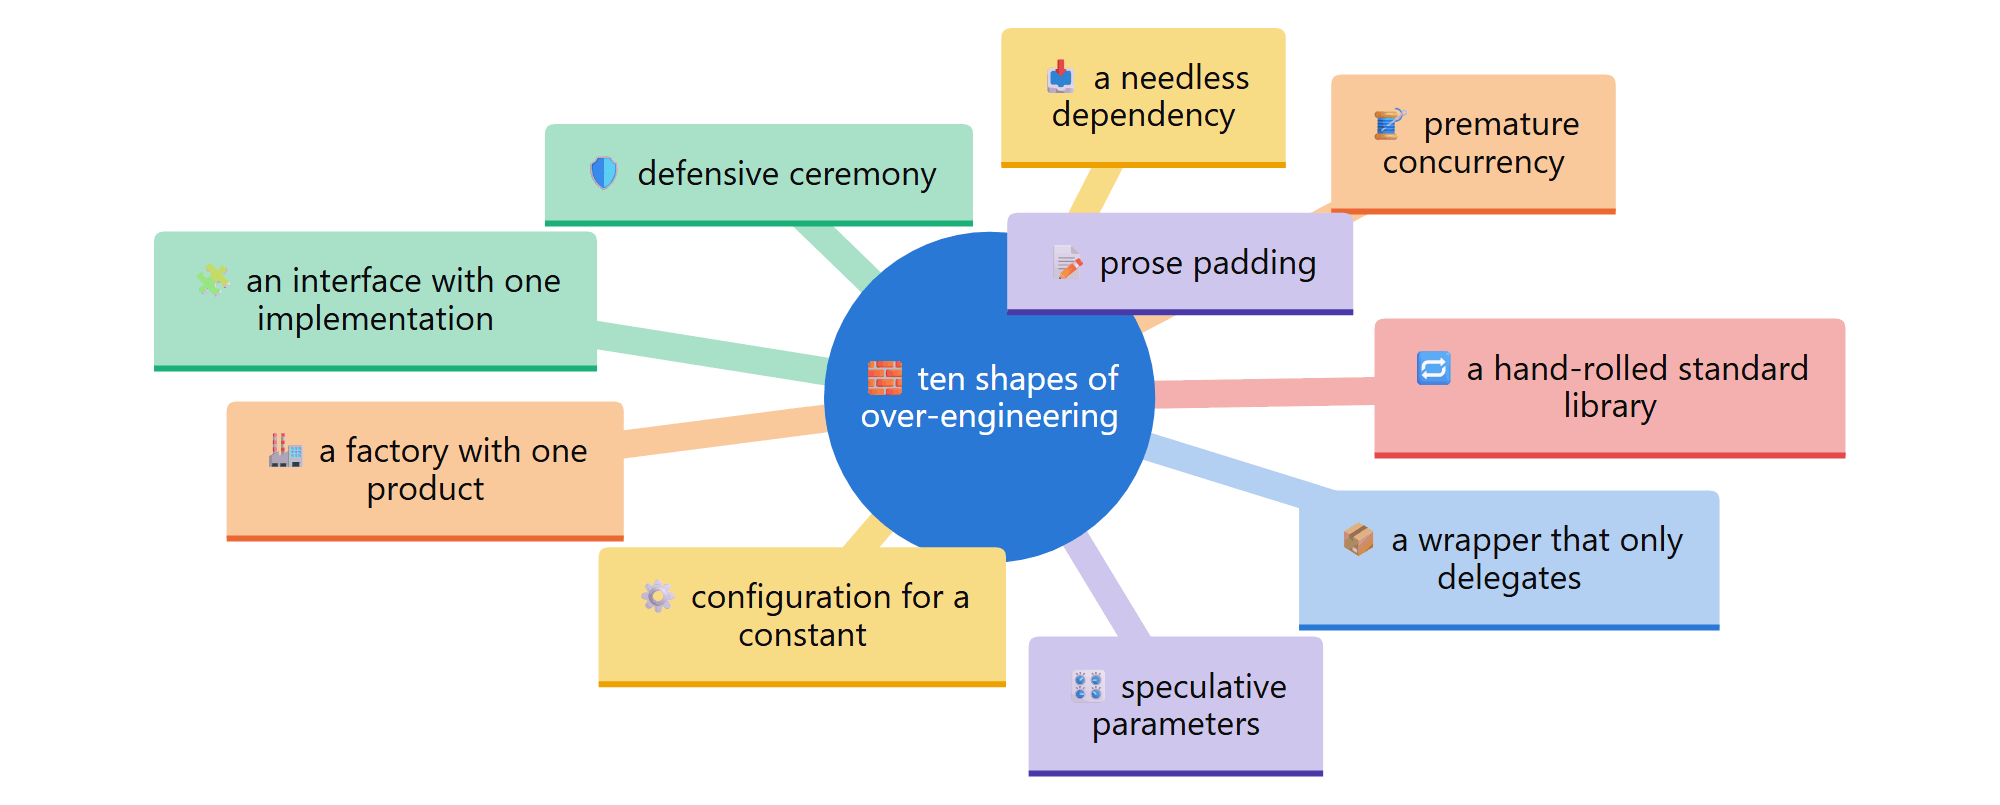

## The whole system on one page

Everything in this notebook is one of three things: a **host** that knows how to run an agent but has no opinion about code size, a **plugin** that rides on the host's hooks and carries every idea about proportional code, and a **lab** that measures both. The plugin can be switched off, which turns the full system back into the baseline it is measured against.

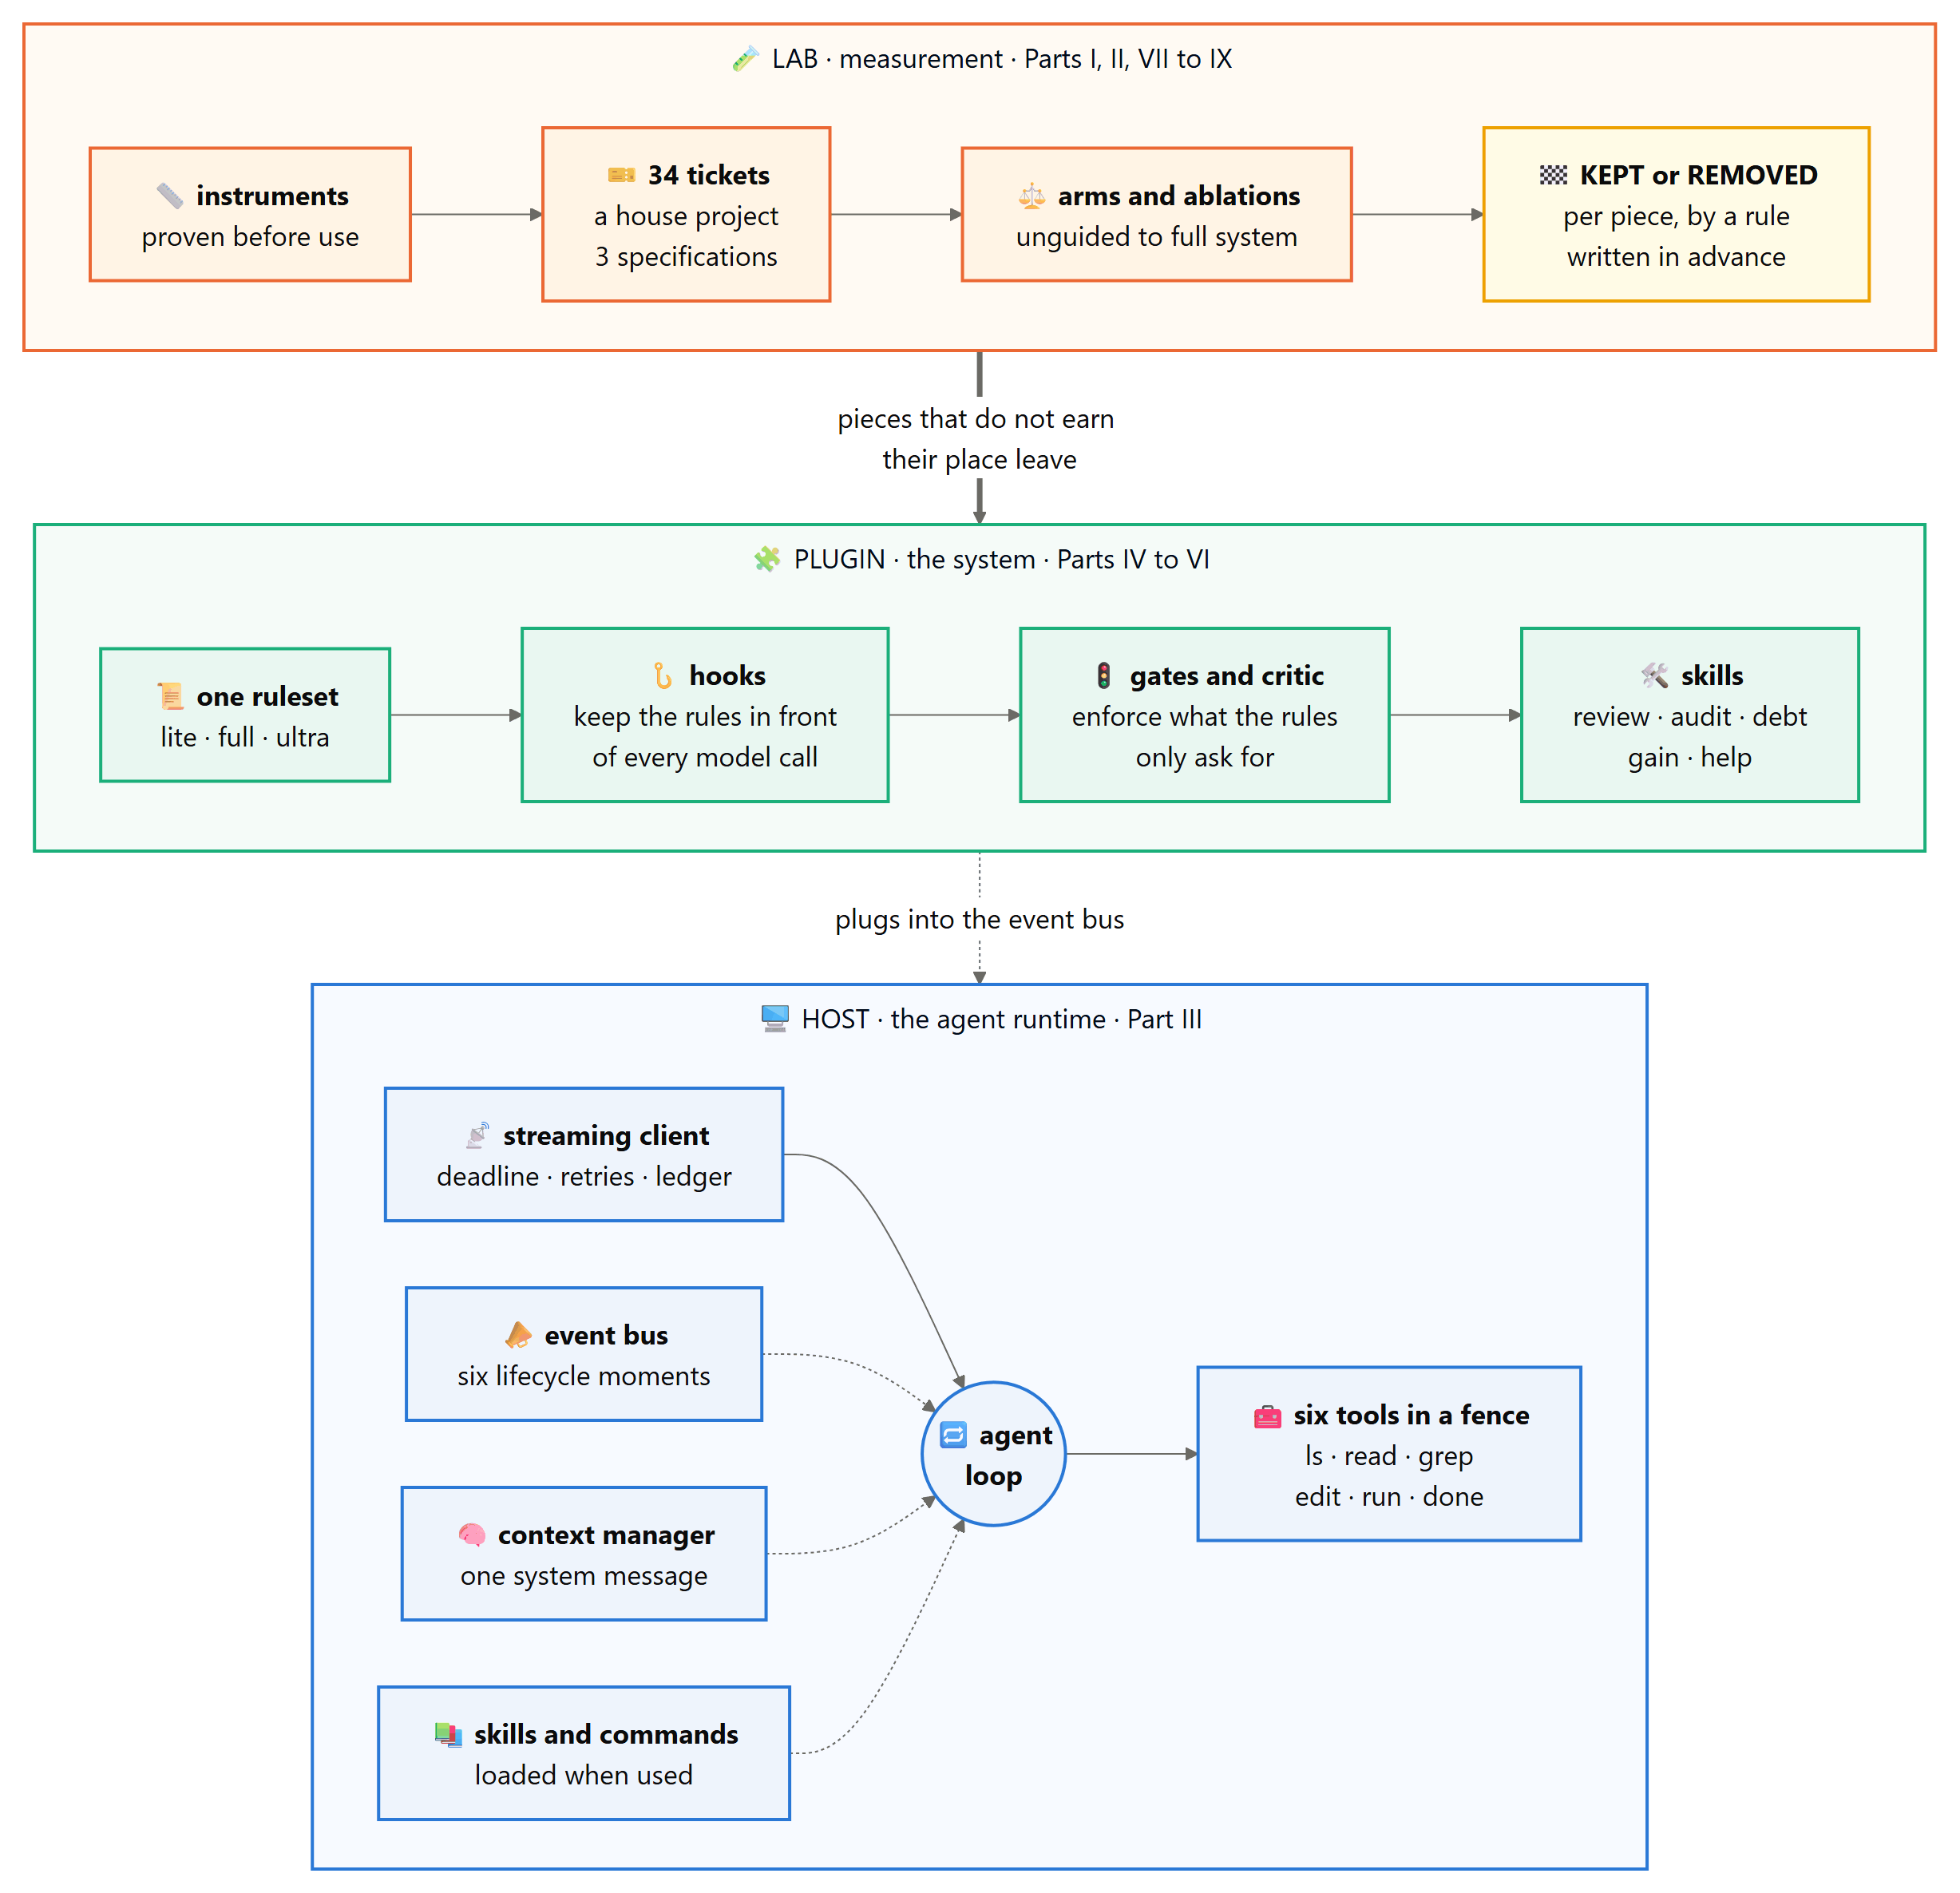

Read the dotted arrows as "plugs into". The arrow from the lab back into the plugin is the unusual one: a feature that does not measurably help is taken out of the shipped system, so the system has to pass its own rule about not building what is not needed.

**One ticket, start to finish.** The same three layers, seen from a single request. The plugin shapes what the model reads, the gates sit between the model and its tools, and nothing counts as finished until a check exists and the critic has had its say. The score at the bottom comes from the lab, which runs hidden tests rather than taking the agent's word for anything.

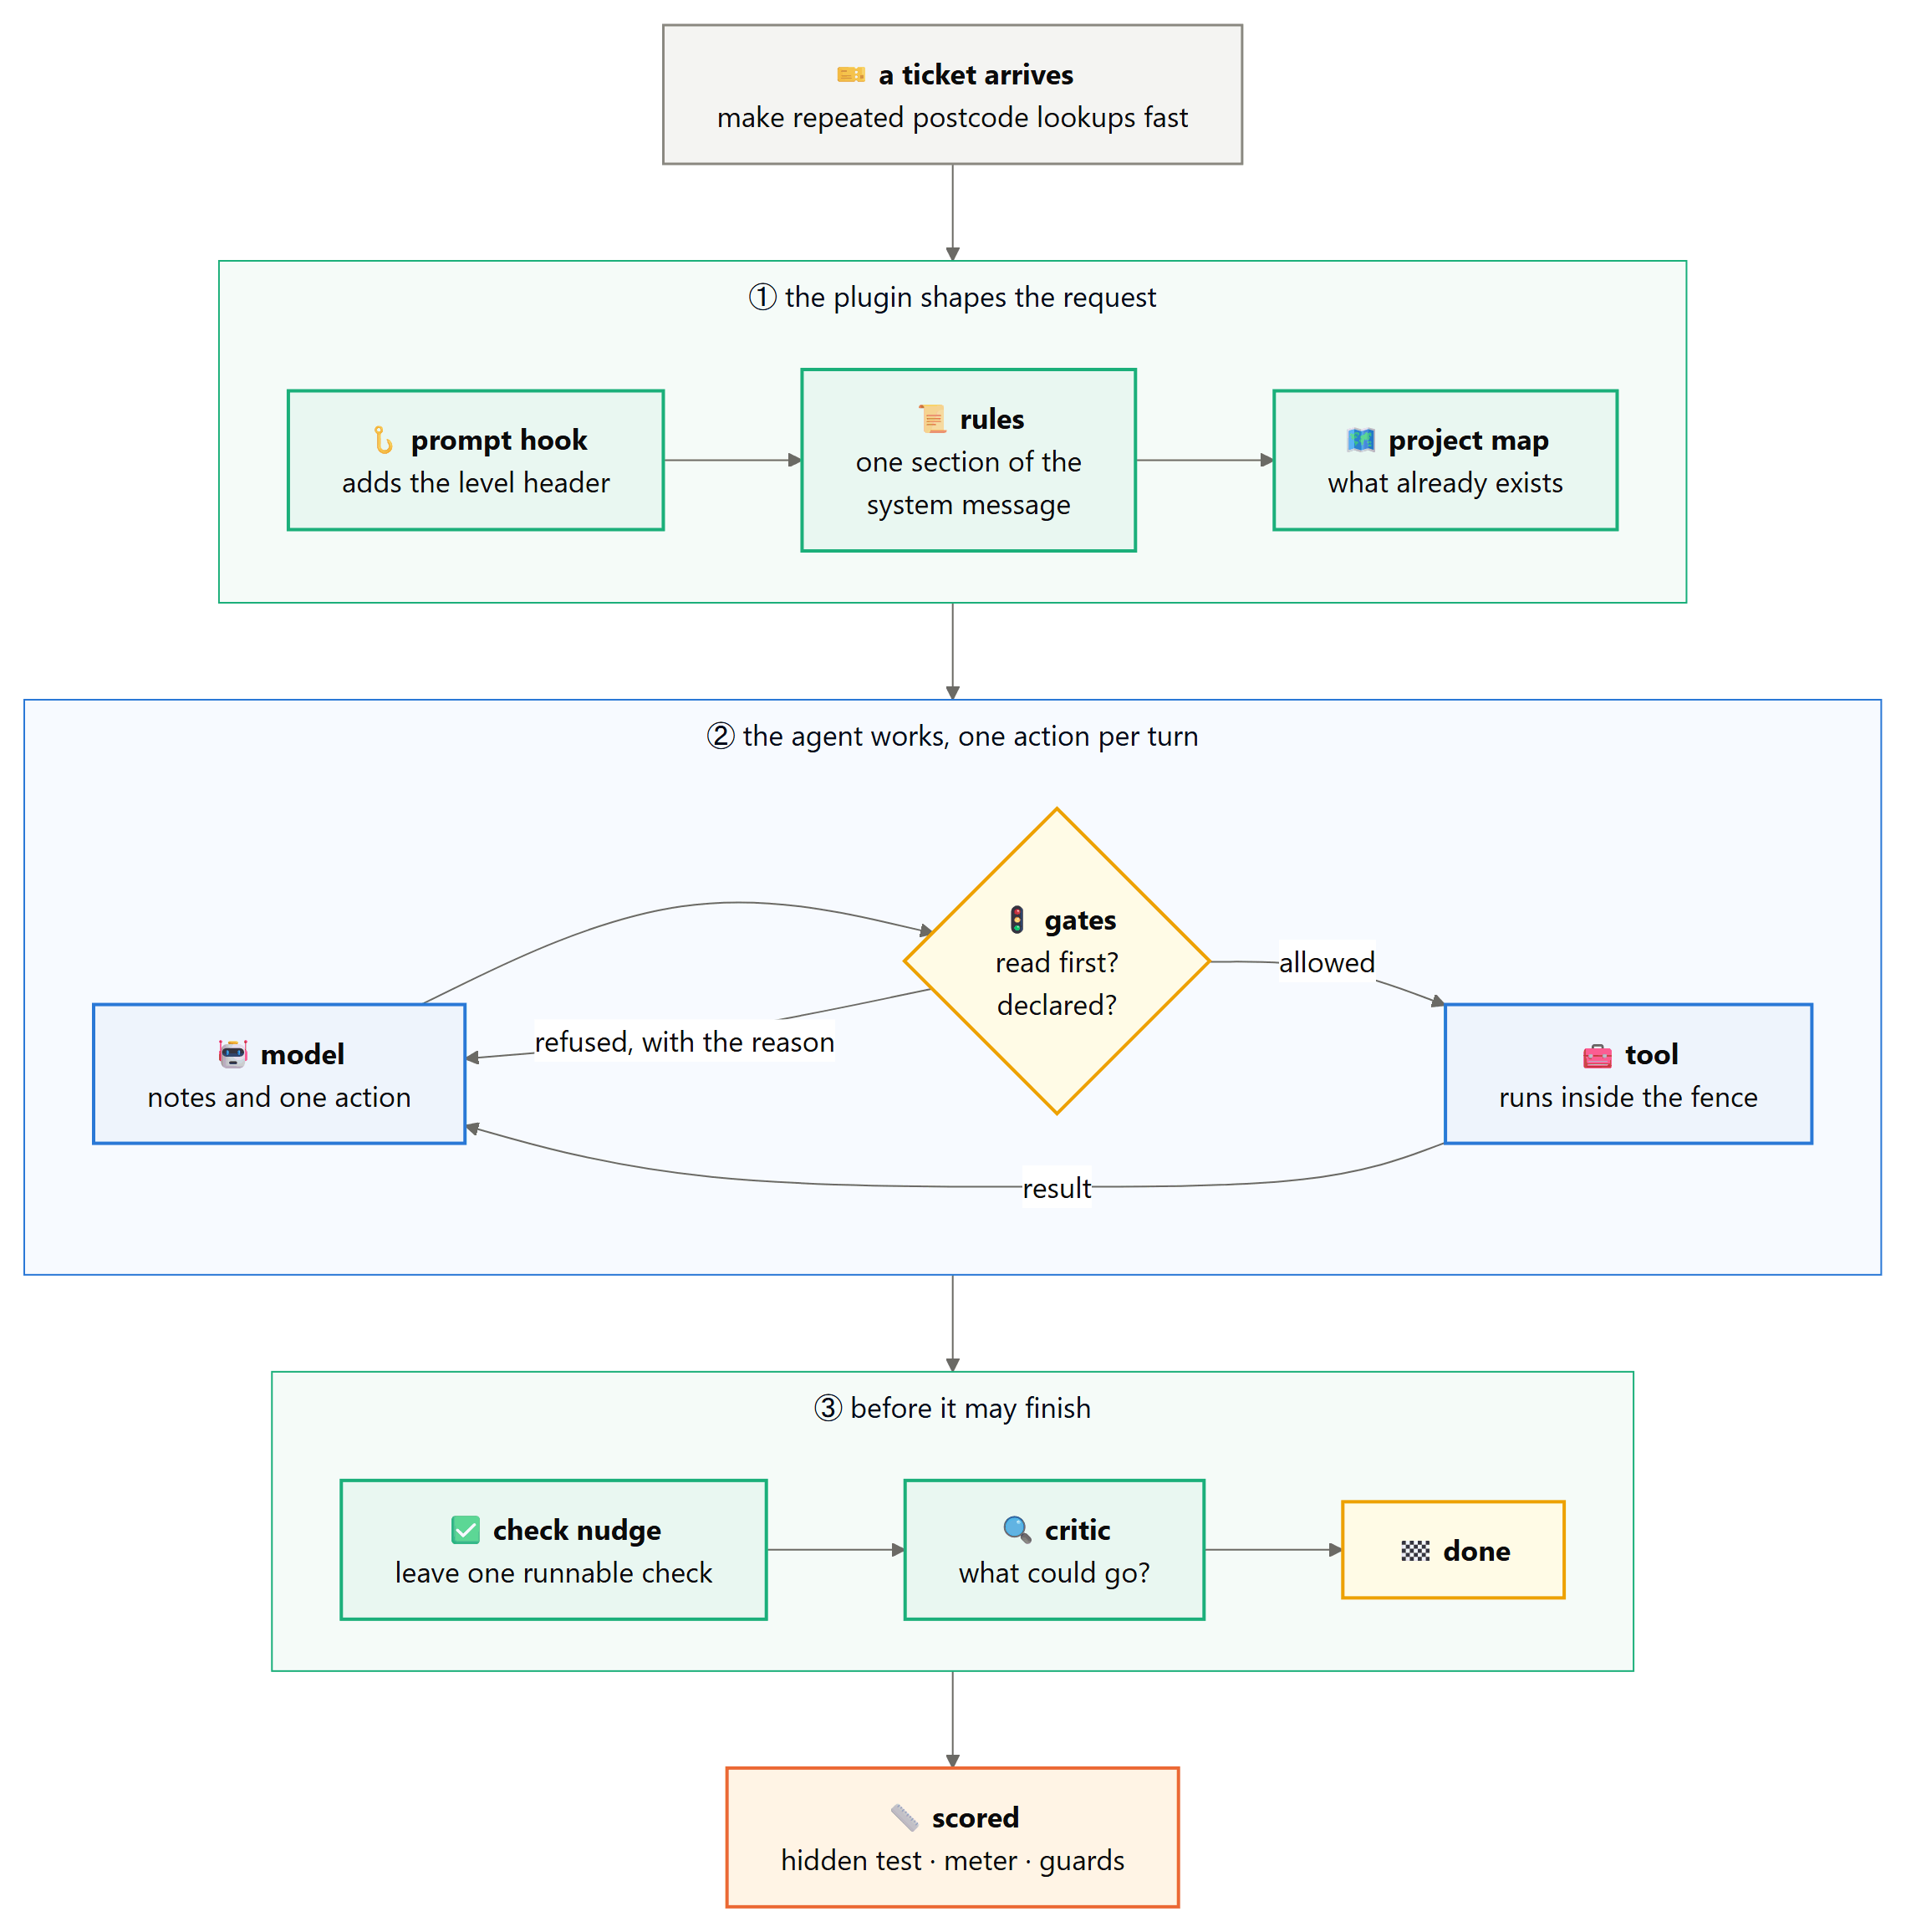

### How to read a section

Every numbered section (S0, S1, ...) has the same parts:

1. **Theory**, and where it helps **In plain terms**: what question this step answers, the method, and the reference if the method has a name. Where a step matters for people running this in a team, a short **For teams** note follows.
2. **Code**: one function or class per cell. Every definition cell ends with a line like `[def] name(args)  12 lines, complexity 3`, so you always know how much code each idea cost.
3. **A run**: the code applied to something concrete, printing its inputs, its intermediate values and its result, ending with a one-line verdict.
4. **A reading**: what the numbers mean, negative results included.

### How to read a feature card

From Part IV onwards, each feature of the system gets the same treatment, so features can be compared fairly:

| step | what you see |
|---|---|
| why | the failure the feature exists to prevent |
| build | the code, one unit per cell |
| test | red and green cases, including the adversarial ones |
| live | the same ticket on the same code, feature off and feature on, both diffs printed |
| evidence | the ablation result from Part VII, with its interval |
| verdict | **KEPT** or **REJECTED** by a rule written down before the data existed |

### Four ways through this notebook

- **Students**: read the *In plain terms* paragraphs and run the *Try it yourself* exercises at the end of each Part. Skip the statistics in Parts VII and VIII on a first pass.
- **Developers**: Parts III to VI are the system. S94b shows how to point it at your own folder.
- **PhD readers**: Part I (instrument validity), S61 (pre-registration), Parts VII and VIII (design, statistics, threats to validity).
- **Teams and software houses**: the *For teams* notes, the cost sections S92 and S93, and the adoption guide S96.

**The same four routes, drawn.** Pick the row that fits and skim the rest. Every Part opens with a small map of its own, so it is easy to rejoin the main road.

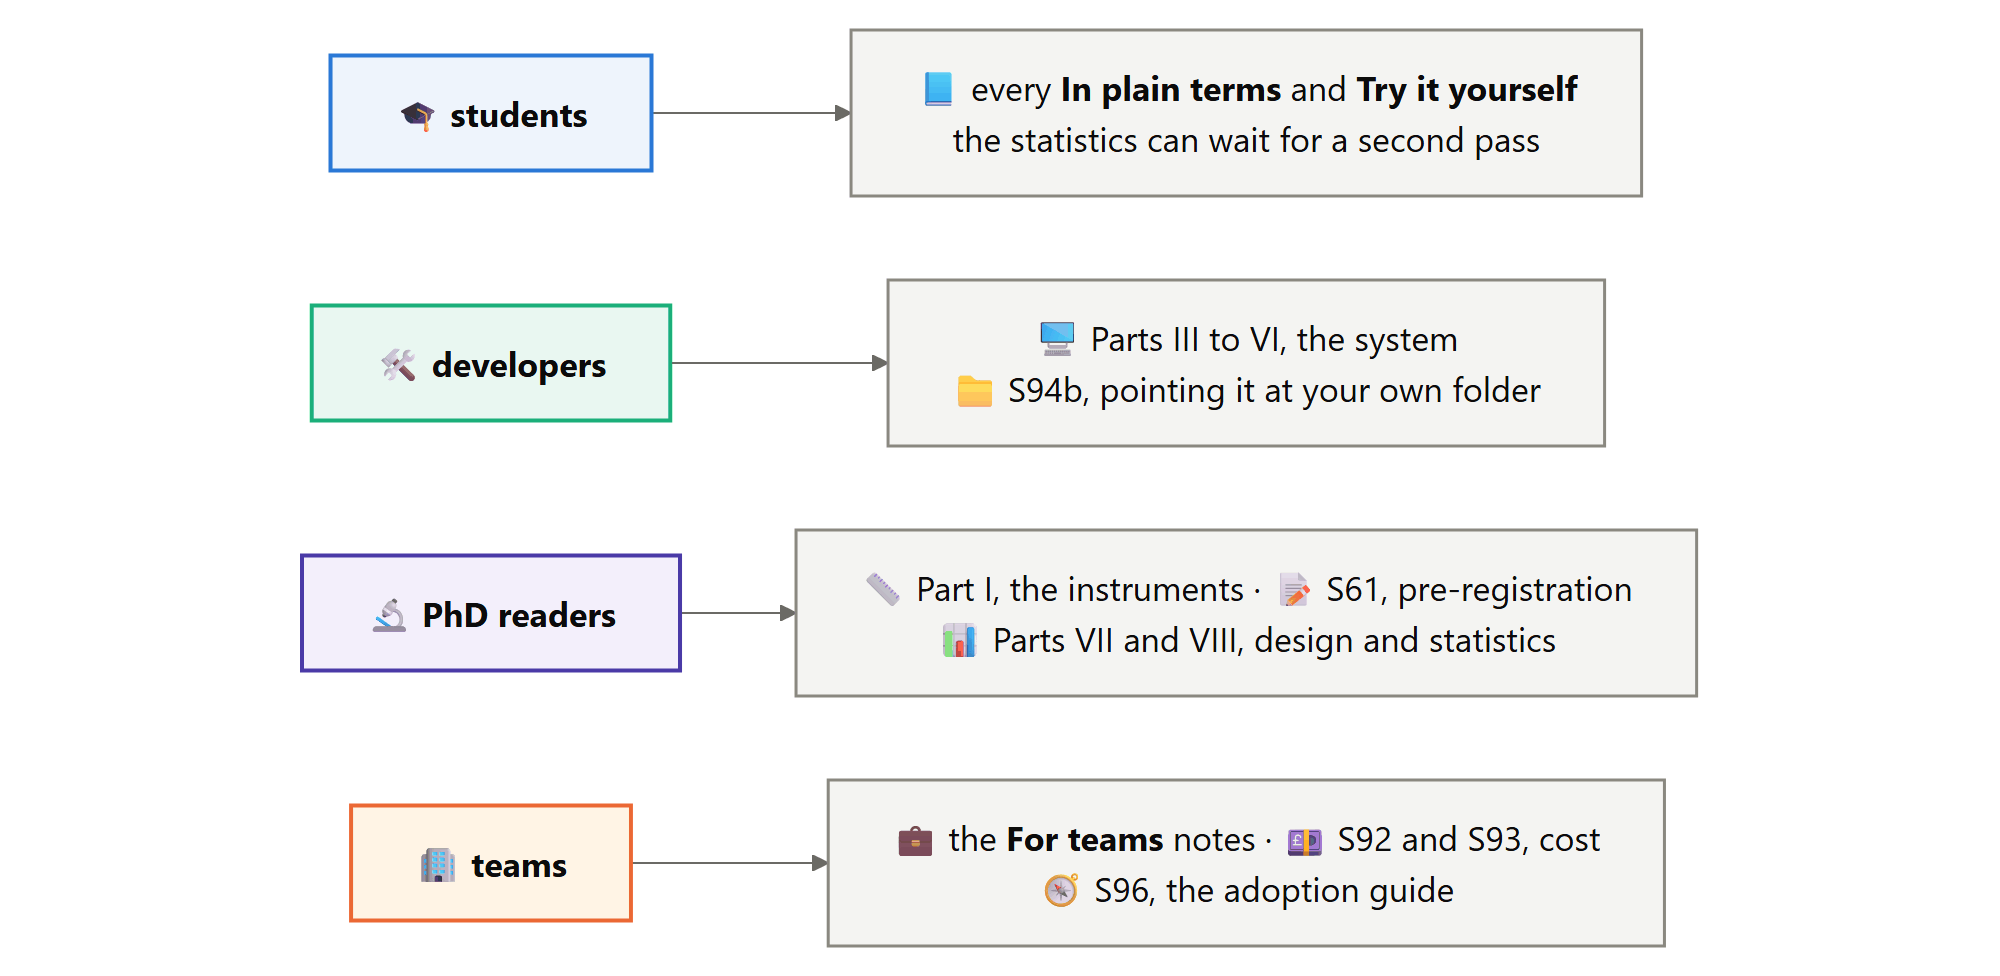

# Part I - Measure before you build

Instruments first: if we cannot measure over-engineering reliably, nothing later in this notebook means anything.

**Where this sits.** Every later claim ("the full system adds less code", "it keeps the guard") is a number produced by an instrument built in this Part. An instrument that can be fooled by a comment, a docstring or a clever one-liner would make every one of those claims worthless, so each instrument here is tested against cases built to fool it before it is trusted with anything else. No model is called in Part I.

**By the end of this Part you can** set up the notebook, describe the ten shapes of over-engineering with a working example of each, count added code in a way comments cannot inflate, detect the ten shapes from the syntax tree, tell a short program from a golfed one, spot the lines that act as guards, and use a table of standard-library replacements that tests its own rows.

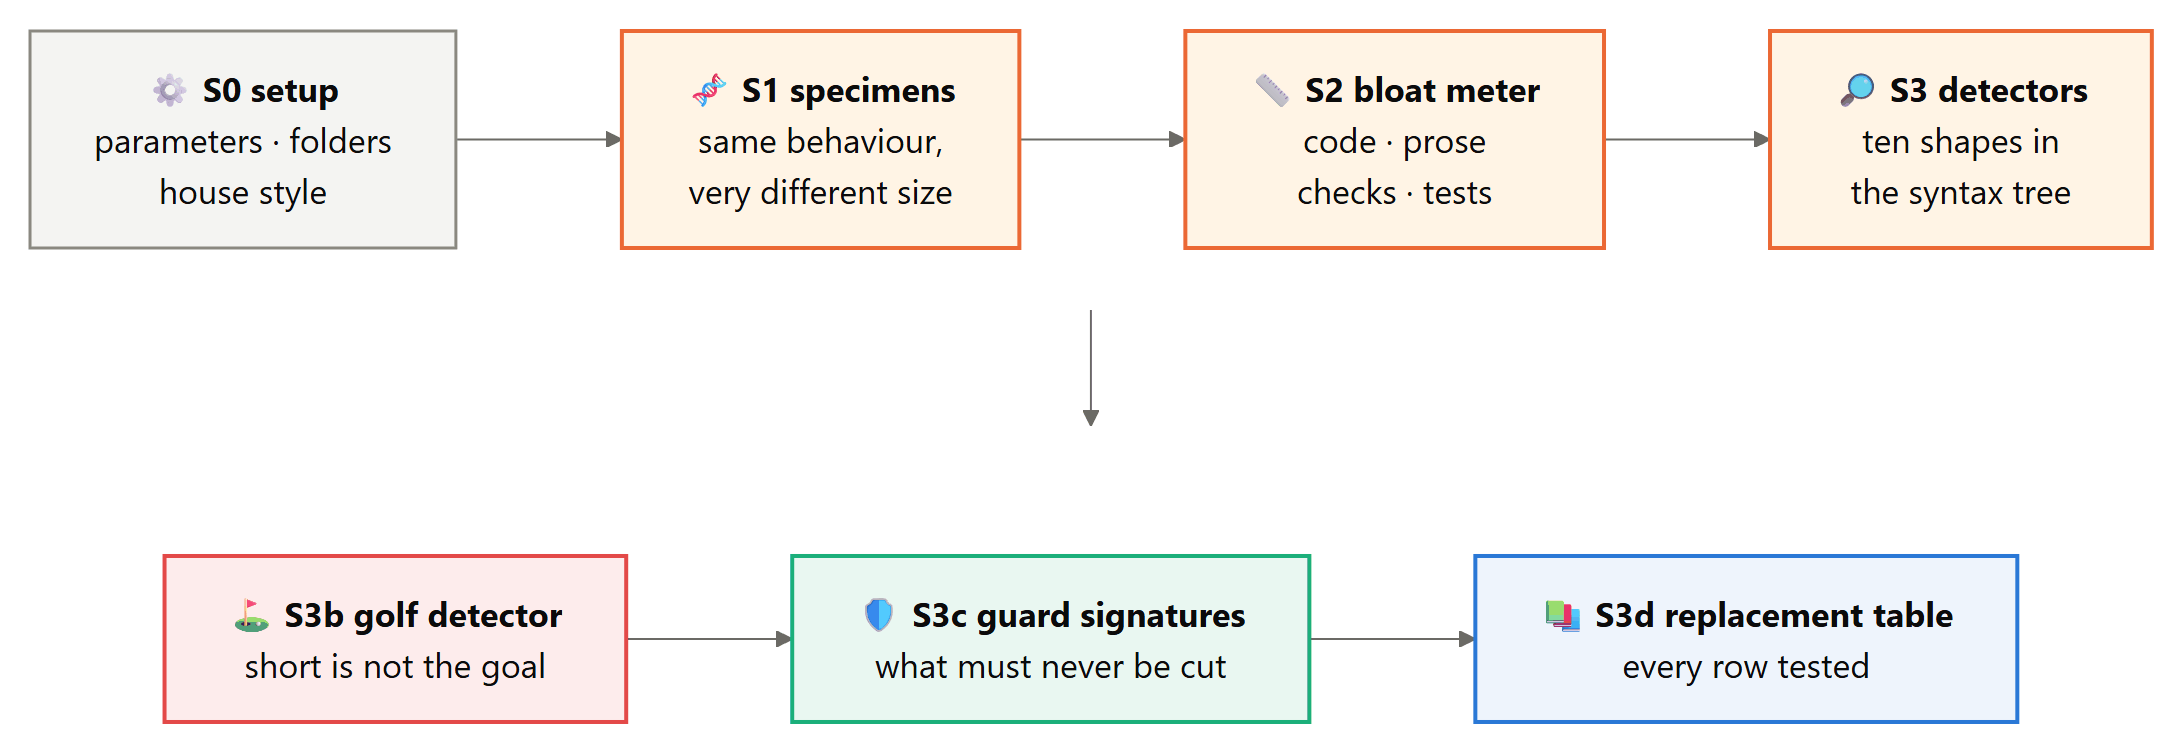

## S0 - Setup, parameters and the house style

**Theory.** A notebook that runs for hours against a paid API needs three properties before it does anything interesting: every tunable value in one place with the reason it has that value, every file it writes inside the project, and every random choice seeded. The three parameter cells below are the only place a number like `REPLICAS` or `MAX_TURNS` is set; later sections read them, and where an experiment changes our mind about a value, the comment next to it says which section did that.

**In plain terms.** One place holds every setting. Change a setting there, re-run, and everything downstream follows.

The notebook runs in one of three modes. **smoke** swaps the model for a scripted stand-in and finishes in minutes with zero API calls; it is how the notebook was built. **collect** calls the real models and stores every reply. **replay** reads only stored replies and refuses to call the API, which is how the committed outputs were produced.

In [1]:
# ---- parameters: every tunable value lives here, with the reason it has this value
import os                         # the mode and the headless switch arrive as environment variables

SYSTEM_NAME = "lean-agent"   # rename the whole system here (and in _build/build.py)
CMD = "lean"                   # command prefix: /lean, /lean-review, $lean, @lean

# smoke = scripted model, zero calls; collect = live calls, all cached; replay = cache only
LEAN_MODE = os.environ.get("LEAN_MODE", "")

SEED = 42                # the one seed every random choice in the notebook starts from
REPLICAS = 2             # runs per (task, arm); S63 measures whether 2 resolves the effects we care about
MAX_TURNS = 20           # per episode, the same for every arm; raised from 14 after the first live baseline,
                         # where 8 of 34 episodes were still verifying their work when the limit cut them off
EPISODE_DEADLINE_S = 600 # wall clock per episode, checked between turns
WORKERS = 10             # concurrent episodes; per-model limits are enforced by the client (S10)

print(f"[params] system  : {SYSTEM_NAME}  (commands /{CMD}, /{CMD}-review, ...)")
print(f"[params] budget  : {MAX_TURNS} turns, {EPISODE_DEADLINE_S}s per episode, {REPLICAS} replicas")

[params] system  : lean-agent  (commands /lean, /lean-review, ...)
[params] budget  : 20 turns, 600s per episode, 2 replicas


**The models.** Six models from one endpoint, each with one job. The coder writes every line of code the experiments measure, and the two judges come from a different generation, so a judge is never grading the habits of its own model. If the probe in S12 finds a primary model missing, the public id listed in `FALLBACKS` takes its place; the coder and the fast model have one.

In [2]:
ENDPOINT = "https://api-inference.modelscope.ai/v1"   # every model below is served from this one endpoint
MODELS = {
    "coder":  "Qwen-Ambassador/Qwen3.8-27B",          # writes the code in every main experiment
    "fast":   "Qwen-Ambassador/Qwen3.8-Flash-Next",   # router and read-only subagents
    "judge":  "Qwen-Ambassador/Qwen3.7-Max",          # a different generation from the coder it judges
    "judge2": "Qwen-Ambassador/Qwen3.7-Plus",         # second judge, used to measure agreement
    "big":    "Qwen-Ambassador/Qwen3.8-Max",          # transfer sweep only; reasons by default
    "omni":   "Qwen-Ambassador/Qwen3.8-Omni-Flash",   # transfer sweep only
}
FALLBACKS = {    # used only if the probe in S12 finds the primary id unavailable
    "Qwen-Ambassador/Qwen3.8-27B": "Qwen/Qwen3.8-27B",
    "Qwen-Ambassador/Qwen3.8-Flash-Next": "Qwen/Qwen3.8-Flash-Next",
}

print(f"[params] coder   : {MODELS['coder']}")
print(f"[params] roles   : {', '.join(MODELS)}; a fallback for {len(FALLBACKS)} of them")

[params] coder   : Qwen-Ambassador/Qwen3.8-27B
[params] roles   : coder, fast, judge, judge2, big, omni; a fallback for 2 of them


**Limits on each call.** How long a call may take, how the models sample, a ceiling on calls per day, and an optional price for cost reports. The deadline covers the whole call rather than each streamed chunk, so a model that thinks for minutes is stopped at a known point instead of trickling on.

In [3]:
CALL_DEADLINE_S = {                          # seconds for the whole call, not per chunk
    "default": 120,                          # every model not listed below
    "Qwen-Ambassador/Qwen3.8-Max": 300,      # the big model of the transfer sweep gets the long deadline too
    # the coder gets longer, since single questions made it think for minutes
    "Qwen-Ambassador/Qwen3.8-27B": 300,
}
TEMPERATURE, TOP_P = 0.6, 0.95   # greedy decoding makes reasoning models loop, so agents sample
DAILY_CALL_CAP = 20_000          # a guard against a runaway loop, not a budget; the next run resumes from the cache
COST_PER_1K_TOKENS = None        # set a price to print costs; None prints tokens and calls only

print(f"[params] calls   : {CALL_DEADLINE_S['default']}s each, {max(CALL_DEADLINE_S.values())}s for the slow models; "
      f"temperature {TEMPERATURE}, top_p {TOP_P}; at most {DAILY_CALL_CAP:,} calls a day")

[params] calls   : 120s each, 300s for the slow models; temperature 0.6, top_p 0.95; at most 20,000 calls a day


**The standard library, once.** Everything the notebook needs from Python itself is imported here, so later cells can use it without a block of imports at the top of each one. Nothing outside the standard library is needed until the house style below brings in matplotlib and numpy.

In [4]:
import sys          # the interpreter: its version, its folders, and the names of the standard-library modules
import json         # experiment records are json files
import time         # wall-clock deadlines and timings
import re           # patterns: path scrubbing, detectors, guard signatures
import math         # isnan and isfinite, for values that may be missing
import random       # seeded below, so every draw repeats from run to run
import hashlib      # fingerprints of requests and of the experiment's inputs
import tempfile     # temporary folders, pointed inside the project below
import textwrap     # dedent, for programs written inside strings
import shutil       # copying and removing workspaces
import ast          # every detector reads the syntax tree
import inspect      # signatures and source text, for show_def
import linecache    # where Jupyter keeps the text of every cell it has run
from pathlib import Path   # every path in the notebook is a Path

print(f"[setup] python     : {sys.version.split()[0]}")

[setup] python     : 3.12.14


**Where the notebook is, and which mode it runs in.** Every path is built from `ROOT`, the folder the notebook was started in, and setup stops at once if that folder has no `tasks/` in it. With no mode given, the notebook replays when a cache of live answers exists and runs the scripted smoke model when it does not.

In [5]:
ROOT = Path.cwd().resolve()                                   # the folder Jupyter was started in
if not (ROOT / "tasks").is_dir():                             # the task suite marks the right folder
    raise RuntimeError("[setup] run this notebook from the lean_agent folder (tasks/ not found)")

CACHE_DB = ROOT / "artifacts" / "cache" / "llm.sqlite"     # every live answer the models gave
if not LEAN_MODE:                                             # no mode in the environment: decide from what exists
    LEAN_MODE = "replay" if CACHE_DB.exists() else "smoke"    # stored answers can be replayed; none means smoke

print(f"[setup] mode       : {LEAN_MODE}")
print(f"[setup] project    : {ROOT.name}/")

[setup] mode       : replay
[setup] project    : lean_agent/


**Folders.** A smoke run writes under `.runtime/smoke/`, so a quick scripted run can never overwrite a workspace, a cached answer or a record produced by a live one. Matplotlib's cache and Python's temporary files are pointed inside the project as well, so the notebook leaves nothing behind anywhere else.

In [6]:
# ---- folders: everything this notebook writes stays inside the project ------------
# a smoke run shares nothing with a live one: not a workspace, not a cache, not a result
# workspaces and scratch files: .runtime/, or .runtime/smoke/ for a smoke run
RUNTIME = ROOT / ".runtime" if LEAN_MODE != "smoke" else ROOT / ".runtime" / "smoke"
# records, figures and the cache of live answers: artifacts/, or a folder inside the smoke runtime
ART = ROOT / "artifacts" if LEAN_MODE != "smoke" else RUNTIME / "artifacts"
FIG = ART / "figures"                       # where finish() saves every figure
SKILLS_DIR = ROOT / "skills"                # where Part VI writes the skill files
for d in (RUNTIME / "tmp", RUNTIME / "matplotlib", FIG, ART / "cache", CACHE_DB.parent, SKILLS_DIR):
    d.mkdir(parents=True, exist_ok=True)    # created once; running the cell again changes nothing

# matplotlib and tempfile read these once, so they are set before either is used
os.environ.setdefault("MPLCONFIGDIR", str(RUNTIME / "matplotlib"))
tempfile.tempdir = str(RUNTIME / "tmp")

print(f"[setup] folders    : {RUNTIME.relative_to(ROOT).as_posix()}/ for scratch, "
      f"{ART.relative_to(ROOT).as_posix()}/ for results")

[setup] folders    : .runtime/ for scratch, artifacts/ for results


**What must never be printed.** Two kinds of text: API keys, which S9 adds to `SECRETS` once it has read them, and the absolute paths of this machine, which tell a reader nothing useful about the system. `_PLACES` lists the folders whose paths are replaced by a short label such as `<project>`.

In [7]:
SECRETS = []   # filled in S9; scrub() removes them from anything printed or stored
_PLACES = [
    (ROOT, "<project>"),                   # the project itself
    (ROOT.parent, "<parent>"),             # the folder that holds it
    (Path(sys.prefix), "<venv>"),          # the virtual environment the kernel runs in
    (Path(sys.base_prefix), "<python>"),   # the Python installation behind that environment
    (Path.home(), "<home>"),               # the user's home folder
]
print(f"[setup] hidden from every printed path: {', '.join(label for _, label in _PLACES)}")

[setup] hidden from every printed path: <project>, <parent>, <venv>, <python>, <home>


**`_place_pattern()`** builds one regular expression that finds any of those folders, however the path happens to be written. Python prints a Windows path with backslashes, `as_posix()` writes forward slashes, `repr()` doubles every backslash, and Windows ignores letter case. So each folder contributes three spellings, matched in any case, and the longest spellings are tried first: a path inside the project becomes `<project>`, not `<parent>` followed by the rest.

In [8]:
def _place_pattern():
    """One regex for every spelling of every place: either slash, the doubled backslashes
    repr() prints, any letter case (Windows ignores case). Longest first, so a path inside
    the project becomes <project>, not <parent>."""
    label = {}                                     # lowercased spelling, then the label that replaces it
    for path, name in _PLACES:
        # as Windows writes it, with forward slashes, and with the doubled backslashes of repr()
        for s in (str(path), path.as_posix(), str(path).replace("\\", "\\\\")):
            label.setdefault(s.lower(), name)      # the first place to claim a spelling keeps it
    keys = sorted(label, key=len, reverse=True)    # longest first, so the project wins over its parent
    return re.compile("|".join(map(re.escape, keys)), re.IGNORECASE), label

_PLACE_RE, _PLACE_LABEL = _place_pattern()         # built once; scrub() uses both
print(f"[setup] {len(_PLACE_LABEL)} spellings of {len(_PLACES)} places, matched in any letter case")

[setup] 15 spellings of 5 places, matched in any letter case


**`rel(path)`** is how a path reaches the screen: relative to the project, with forward slashes. A path outside the project prints as its bare file name, so nothing about the machine's layout leaks into the output.

In [9]:
def rel(path):
    """A path as the reader should see it: relative to the project, never absolute."""
    try:
        return Path(path).resolve().relative_to(ROOT).as_posix()   # inside the project, such as tasks/eg-ipv4
    except ValueError:                                              # outside it: the file name alone
        return Path(path).name

print(f"[setup] artifacts  : {rel(ART)}/   figures: {rel(FIG)}/   cache: {rel(CACHE_DB)}")

[setup] artifacts  : artifacts/   figures: artifacts/figures/   cache: artifacts/cache/llm.sqlite


**`scrub(text)`** cleans text before it is printed or stored: every known secret becomes `<key>`, and every spelling of the five places becomes its label. Later Parts pass tool output and error messages through it before showing them.

In [10]:
def scrub(text):
    """Remove secrets and absolute paths (the project, the Python installation, the home
    folder) from text before it is printed or stored."""
    text = str(text)                         # paths, exceptions and numbers arrive here too
    for s in SECRETS:
        text = text.replace(s, "<key>")      # a key never reaches the screen, wherever it appears
    # each match is looked up by its lowercase spelling, so a path in capitals gets the same label
    return _PLACE_RE.sub(lambda m: _PLACE_LABEL[m.group(0).lower()], text)

print(f"[setup] a sample absolute path, scrubbed: {scrub(ROOT / 'tasks')}")

[setup] a sample absolute path, scrubbed: <project>\tasks


**`_warn_scrubbed(...)`** takes the place of the function Python uses to print a warning. A warning names the file it came from, which inside Jupyter is an absolute path; the replacement passes that name through `scrub()` and leaves the printing itself to Python's own printer, kept in `_showwarning`.

In [11]:
import warnings                          # the module whose printer is replaced below
_showwarning = warnings.showwarning      # Python's own printer, which still does the writing

def _warn_scrubbed(message, category, filename, lineno, file=None, line=None):
    """A warning names the file it came from; print that name without this machine's paths."""
    _showwarning(message, category, scrub(filename), lineno, file, line)   # only the file name is changed

warnings.showwarning = _warn_scrubbed    # every warning from here on goes through scrub()
print(f"[setup] warnings print scrubbed file names: {warnings.showwarning is _warn_scrubbed}")

[setup] warnings print scrubbed file names: True


**`set_determinism(seed)`** seeds every source of randomness the notebook uses: Python's `random`, numpy's global generator, and `PYTHONHASHSEED`. The hash seed cannot change the kernel that is already running, but the sandbox runs agent code in child processes, and there it fixes the order in which sets of strings are iterated. The cell prints the first draw after seeding, so two runs can be compared at a glance, then seeds again so that the printed draw shifts nothing after it.

In [12]:
# ---- determinism ---------------------------------------------------------------------
def set_determinism(seed):
    """Seed every random source we use. PYTHONHASHSEED only affects child processes,
    which is exactly where it matters here: the sandbox runs agent code in children."""
    random.seed(seed)                            # the standard library's global generator
    os.environ["PYTHONHASHSEED"] = str(seed)     # inherited by every child process started from now on
    try:
        import numpy as np
        np.random.seed(seed)                     # numpy's global generator, when numpy is installed
    except ImportError:
        pass                                     # no numpy, nothing more to seed

set_determinism(SEED)
print(f"[setup] determinism seeded @ {SEED}; first draw {random.random():.4f} (same on every run)")
random.seed(SEED)                                # seed again, so the draw just printed shifts nothing later

[setup] determinism seeded @ 42; first draw 0.6394 (same on every run)


**The house style.** One palette and one set of matplotlib defaults for every figure in the notebook: an off-white surface, quiet grey axes with no box around the plot, and a faint grid drawn behind the data. Part I draws the bloated version of a program in red and the lean version in blue.

In [13]:
# ---- the house style for every figure ---------------------------------------------
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"   # blue, orange, green, amber
C5, C6, C7, C8 = "#e87ba4", "#008300", "#4a3aa7", "#e34948"   # pink, deep green, violet, red
# text, secondary text, muted text, grid lines and the background surface
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#8a8880", "#e6e5e1", "#fcfcfb"
matplotlib.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,   # one surface, saved as shown
    "font.size": 9, "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    # grey tick labels, and only the left and bottom spines
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,   # grid behind the data
    "legend.frameon": False, "figure.dpi": 120,
})
print(f"[style] eight series colours and five neutrals; figures are saved to {rel(FIG)}/")

[style] eight series colours and five neutrals; figures are saved to artifacts/figures/


**`finish(fig, name, title, sub=None)`** is the last call of every figure cell. The title states the finding rather than naming the chart, and the grey subtitle carries the number or the caveat. Both are placed at fixed distances in inches from the top edge, not as fractions of the figure, so a long title never runs into the axes whatever the figure's height. It then saves the figure under `figures/`, shows it, closes it, and prints its number, which the **Reading FIG N** notes refer to.

In [14]:
FIG_N = [0]   # figures shown so far; a list, so finish() can count without a global statement

def finish(fig, name, title, sub=None):
    """Title that states the finding, grey subtitle with the number or the caveat,
    absolute spacing so a long title never collides with the axes; then save and show."""
    FIG_N[0] += 1                                    # this figure's number in the notebook
    h = fig.get_size_inches()[1]                     # the height in inches turns fixed distances into fractions
    fig.suptitle(title, x=0.02, y=1 - 0.16 / h, ha="left", va="top", fontsize=11, color=INK, weight="bold")
    if sub:
        fig.text(0.02, 1 - 0.42 / h, sub, ha="left", va="top", fontsize=8.5, color=INK2)   # just under the title
    fig.tight_layout(rect=[0, 0, 1, 1 - (0.60 if sub else 0.34) / h])   # the axes end below the text
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)                                   # released, so a long run does not pile up figures
    print(f"[fig {FIG_N[0]}] {name}.png")

print("[style] palette and finish() ready")

[style] palette and finish() ready


**`panel(ax, text)`** puts a small grey caption at the top left of one panel. The figure's title states the finding; a panel caption says what that one panel shows, which matters when a figure has two or three of them.

In [15]:
def panel(ax, text):
    """Small grey caption at the top left of one panel."""
    ax.set_title(text, fontsize=9, color=INK2, loc="left")   # left-aligned, under the figure's own title

print("[style] panel(ax, text): a small grey caption at the top left of one panel")

[style] panel(ax, text): a small grey caption at the top left of one panel


In [16]:
caption_fig = matplotlib.figure.Figure(figsize=(3, 1))       # outside pyplot, so it is never shown
caption_ax = caption_fig.add_subplot()
panel(caption_ax, "every pair returns the same values")
print(f"[style] panel() captioned the axes: {caption_ax.get_title(loc='left')!r}")

[style] panel() captioned the axes: 'every pair returns the same values'


**`widgets()`** returns the ipywidgets module where someone can click, and `None` where nobody can: in a headless run started by `_build/run.py`, or when the package is not installed. Every interactive cell prints its static view first and asks for widgets only after that, so a reader of the saved notebook loses nothing.

In [17]:
HEADLESS = os.environ.get("LEAN_HEADLESS") == "1"   # set by _build/run.py, where nobody can click a widget

def widgets():
    """ipywidgets where someone can use them; None in a headless run or where the package is
    missing. Every widget cell prints its static view first, so nothing is lost either way."""
    # nobody can click here, and building widgets under nbclient has stalled a run before
    if HEADLESS:
        return None
    try:
        import ipywidgets
    except ImportError:                              # no package: the static view is all there is
        return None
    return ipywidgets

print(f"[style] widgets: {'available' if widgets() else 'static views only'} (headless run: {HEADLESS})")

[style] widgets: static views only (headless run: True)


**`_cell(v, fmt)`** formats one value for `table()`. A missing value prints as `-` rather than `None` or an empty gap, and a format that does not suit the value (a percentage asked of a word) falls back to plain text instead of stopping the whole table.

In [18]:
# ---- printing helpers ------------------------------------------------------------
def _cell(v, fmt):
    if v is None or v == "":                 # missing: a dash keeps the column readable
        return "-"
    if fmt:                                  # a format such as "d", ".2f" or ".0%"
        try:
            return format(v, fmt)
        except (TypeError, ValueError):      # the format does not suit this value
            return str(v)
    return str(v)

print(f"[print] _cell formats one table value: {_cell(0.25, '.0%')}, {_cell(None, 'd')}, {_cell('word', '.2f')}")

[print] _cell formats one table value: 25%, -, word


In [19]:
for v, fmt in ((None, "d"), (0.4167, ".0%"), (12.3456, ".1f"), ("lean", ".0%"), (7, "")):
    print(f"  _cell({v!r}, {fmt!r}) gives {_cell(v, fmt)!r}")

  _cell(None, 'd') gives '-'
  _cell(0.4167, '.0%') gives '42%'
  _cell(12.3456, '.1f') gives '12.3'
  _cell('lean', '.0%') gives 'lean'
  _cell(7, '') gives '7'


**`table(rows, cols, indent=2)`** prints a list of dicts as an aligned table, which is how the notebook shows every result before it draws one. `cols` lists `(key, header, format)` for each column. A column holding only numbers, or gaps, is right-aligned so the digits line up; any other column is left-aligned. Widths are measured on the formatted text, so the table fits exactly what is printed.

In [20]:
def table(rows, cols, indent=2):
    """Print a list of dicts as an aligned table. cols = [(key, header, format), ...];
    text columns align left, numbers right."""
    cells = []                                                    # every value formatted once, row by row
    for r in rows:
        cells.append([_cell(r.get(k), f) for k, _, f in cols])   # a missing key formats as a dash
    numeric = []                                                  # one flag per column: align it right?
    for k, _, _ in cols:
        # numbers and gaps only; a single word anywhere in the column makes it a text column
        numeric.append(all(isinstance(r.get(k), (int, float)) or r.get(k) in (None, "") for r in rows))
    widths = []                                                   # the header or the widest value, whichever is longer
    for i, (_, h, _) in enumerate(cols):
        widths.append(max([len(h)] + [len(c[i]) for c in cells]))
    pad = " " * indent                                            # the table's left margin

    def line(vals):
        # numbers to the right, text to the left, two spaces between columns, nothing trailing
        padded = [v.rjust(w) if num else v.ljust(w) for v, w, num in zip(vals, widths, numeric)]
        return (pad + "  ".join(padded)).rstrip()

    print(line([h for _, h, _ in cols]))                          # the header row
    print(pad + "-" * (sum(widths) + 2 * (len(cols) - 1)))        # a rule exactly as wide as the table
    for c in cells:
        print(line(c))

print("[print] table(rows, cols): a list of dicts as aligned columns, text left and numbers right")

[print] table(rows, cols): a list of dicts as aligned columns, text left and numbers right


In [21]:
example = [{"name": "short", "count": 7, "share": 0.25},
           {"name": "a longer name", "count": None, "share": 1.0}]
table(example, [("name", "name", ""), ("count", "count", "d"), ("share", "share", ".0%")])

  name           count  share
  ---------------------------
  short              7    25%
  a longer name      -   100%


**`bar(frac, width=30, ch="#")`** draws a fraction as a row of characters, for printouts where a figure would be too much. Values are clipped to the range 0 to 1, and a missing value draws nothing, so a bar never breaks a printout.

In [22]:
def bar(frac, width=30, ch="#"):
    """An ASCII bar for a fraction between 0 and 1."""
    if frac is None or math.isnan(frac):     # no value: an empty bar, not an error
        frac = 0.0
    else:
        frac = max(0.0, min(1.0, frac))      # clipped, so a ratio above 1 cannot run past its column
    return ch * round(frac * width)          # rounded to whole characters

print(f"[print] bar(0.4) draws {bar(0.4)!r}; bar(1.7) is clipped to {len(bar(1.7))} characters")

[print] bar(0.4) draws '############'; bar(1.7) is clipped to 30 characters


In [23]:
for frac in (0.0, 0.25, 0.5, 1.4, None):
    print(f"  {frac!s:>5}  |{bar(frac, 20):<20}|")

    0.0  |                    |
   0.25  |#####               |
    0.5  |##########          |
    1.4  |####################|
   None  |                    |


**`complexity(src)`** is McCabe's cyclomatic complexity, counted from the syntax tree: one for the straight path through the code, plus one for every point where that path can split. Those points are each `if`, loop, `except`, conditional expression, comprehension, `assert` and `match` case, and each extra operand of `and` or `or`. `show_def` records it next to every definition's size, and S95 in Part X uses both to weigh the system.

In [24]:
def complexity(src):
    """McCabe-style complexity: 1 plus one per decision point (if, loop, except,
    boolean operator, comprehension, conditional expression, assert)."""
    tree = ast.parse(textwrap.dedent(src))                     # dedent, so a method's source parses on its own
    score = 1                                                  # code with no decisions has one path
    for node in ast.walk(tree):
        if isinstance(node, (ast.If, ast.For, ast.AsyncFor, ast.While, ast.ExceptHandler,
                             ast.IfExp, ast.comprehension, ast.Assert, ast.match_case)):
            score += 1                                         # each of these can send execution two ways
        elif isinstance(node, ast.BoolOp):
            score += len(node.values) - 1                      # a and b and c holds two decisions
    return score

print(f"[measure] complexity: a plain assignment {complexity('x = 1')}, one conditional expression {complexity('y = 1 if x else 2')}")

[measure] complexity: a plain assignment 1, one conditional expression 2


In [25]:
for snippet in ("x = 1", "if a and b:\n    x = 1", "ys = [y for y in xs if y]"):
    print(f"  complexity {complexity(snippet)}: {snippet!r}")

  complexity 1: 'x = 1'
  complexity 3: 'if a and b:\n    x = 1'
  complexity 2: 'ys = [y for y in xs if y]'


**`DEFS`** is the register of every definition in the notebook, keyed by name, each with its layer (host, plugin or lab), its size and its complexity. `show_def` fills it, and S95 reads it to weigh the system against the lab that tests it.

In [26]:
DEFS = {}   # every definition in the notebook, by layer: this is how big the system is
print(f"[defs] register ready, {len(DEFS)} definitions so far")

[defs] register ready, 0 definitions so far


**`source_of(obj)`** returns the source text of a function or a class. `inspect.getsource` does this for functions, but on Python 3.12 it cannot find a class defined in a notebook cell, because a cell is not a file. Jupyter does keep the text of every cell it has run in `linecache`, so the fallback searches those texts, newest first, and cuts the class out using the positions the syntax tree records.

In [27]:
def source_of(obj):
    """inspect.getsource, plus what it cannot do on Python 3.12: find a class defined in a
    notebook cell. Jupyter keeps every cell in linecache, so take the newest cell that
    defines a class of that name."""
    try:
        return inspect.getsource(obj)                          # functions, and classes defined in files
    except (OSError, TypeError):
        for name in reversed(list(linecache.cache)):           # newest cell first: a redefined class wins
            text = "".join(linecache.cache[name][2])           # the cell's lines, joined back into one text
            if f"class {obj.__name__}" not in text:            # a cheap text test before any parsing
                continue
            try:
                tree = ast.parse(text)
            except SyntaxError:                                # not Python, or a cell that never parsed
                continue
            for node in ast.walk(tree):
                if isinstance(node, ast.ClassDef) and node.name == obj.__name__:
                    return ast.get_source_segment(text, node, padded=True)   # the class, indented as written
        raise                                                  # found nowhere: the original error stands

print(f"[measure] source_of finds the text of a function, even one defined in a notebook cell: {source_of(bar).splitlines()[0]!r}")

[measure] source_of finds the text of a function, even one defined in a notebook cell: 'def bar(frac, width=30, ch="#"):'


In [28]:
print(f"[source_of] {source_of(bar).splitlines()[0]}")        # a function defined a few cells above

[source_of] def bar(frac, width=30, ch="#"):


**`show_def(*objs, layer="lab")`** prints one line for each definition: its name, its signature and its size, counting lines that are neither blank nor comments. It also files the definition in `DEFS` under its layer, which is why every definition cell in the notebook ends with it. Signatures go through `scrub()`, because a default value can be a path on this machine.

In [29]:
def show_def(*objs, layer="lab"):
    """One line per definition: its name, signature, and what it cost in lines."""
    for obj in objs:                                  # several definitions can share one call
        src = textwrap.dedent(source_of(obj))         # dedented, so a method's source reads like a function's
        # lines that cost something: not blank and not a comment line (docstrings do count)
        n = sum(1 for ln in src.splitlines() if ln.strip() and not ln.strip().startswith("#"))
        try:
            sig = str(inspect.signature(obj))         # such as (rows, cols, indent=2)
        except (TypeError, ValueError):               # some objects have no signature to show
            sig = ""
        sig = scrub(sig)                              # a default such as ROOT would print an absolute path
        sig = sig if len(sig) <= 70 else sig[:67] + "...)"   # a long signature is cut, keeping its bracket
        kind = "class" if inspect.isclass(obj) else "def"
        name = obj.__qualname__                       # Host.loop and LeanPlugin.install stay apart
        DEFS[name] = {"layer": layer, "lines": n, "complexity": complexity(src), "obj": obj}
        print(f"[{kind}] {name}{sig}  {n} lines, complexity {DEFS[name]['complexity']}")

show_def(table, bar, complexity, source_of, show_def)

[def] table(rows, cols, indent=2)  20 lines, complexity 12
[def] bar(frac, width=30, ch='#')  7 lines, complexity 3
[def] complexity(src)  12 lines, complexity 4
[def] source_of(obj)  19 lines, complexity 8
[def] show_def(*objs, layer='lab')  15 lines, complexity 7


The setup helpers above were written before `show_def` existed, so they are filed in `DEFS` here, in the lab layer like the rest of Part I.

In [30]:
show_def(_place_pattern, rel, scrub, _warn_scrubbed, set_determinism, finish, panel, widgets, _cell)

[def] _place_pattern()  10 lines, complexity 3
[def] rel(path)  6 lines, complexity 2
[def] scrub(text)  7 lines, complexity 2
[def] _warn_scrubbed(message, category, filename, lineno, file=None, line=None)  3 lines, complexity 1
[def] set_determinism(seed)  10 lines, complexity 2
[def] finish(fig, name, title, sub=None)  13 lines, complexity 3
[def] panel(ax, text)  3 lines, complexity 1
[def] widgets()  10 lines, complexity 3
[def] _cell(v, fmt)  9 lines, complexity 5


**Building a class one method at a time.** The larger classes in this notebook (the host, the ledger, the plugin) are easier to follow one method per cell, each with its own explanation and its own small demonstration. Python allows that directly: a function defined at module level becomes a method as soon as it is set as an attribute of the class. `method_of` does exactly that and nothing more. It also gives the function its proper name (`Host.loop` rather than `loop`) and leaves the notebook's own names alone, so attaching a method called `status` cannot quietly replace a function called `status` defined somewhere else.

In [31]:
def method_of(cls):
    """Attach the decorated function to `cls` as a method, so a class can be built one
    method per cell. The notebook's own global names are left exactly as they were."""
    def attach(fn):
        fn.__qualname__ = f"{cls.__name__}.{fn.__name__}"   # reads as Host.loop in show_def and in tracebacks
        setattr(cls, fn.__name__, fn)                         # from here on every instance has the method
        return fn.__globals__.get(fn.__name__, fn)            # an existing global of the same name survives
    return attach

show_def(method_of)

[def] method_of(cls)  8 lines, complexity 1


A small demonstration, starting with a class that has nothing in it.

In [32]:
class _Demo:                                                  # a throwaway class, only for this demonstration
    pass

print(f"[method_of] before: does _Demo have hello? {hasattr(_Demo, 'hello')}")

[method_of] before: does _Demo have hello? False


Now a method written outside the class, and attached to it with `method_of`.

In [33]:
@method_of(_Demo)
def hello(self):                                              # written outside the class body...
    return "attached"

print(f"[method_of] _Demo().hello() -> {_Demo().hello()!r}; registered as {_Demo.hello.__qualname__}")

[method_of] _Demo().hello() -> 'attached'; registered as _Demo.hello


**`_round(o, nd=4)`** prepares a result for json: floats rounded to four places, NaN and infinity stored as `null`, tuples turned into lists, numpy scalars into plain Python values. Rounding once, here, means float noise, such as the seventeen digits Python prints for `0.1 + 0.2`, never reaches the prose that quotes these records.

In [34]:
# ---- experiment records: every number the prose quotes comes from one of these files
def _round(o, nd=4):
    if isinstance(o, float):                                  # numpy's float64 is a float too, so it lands here
        return round(o, nd) if math.isfinite(o) else None     # json has no NaN or infinity: store null
    if isinstance(o, dict):
        return {str(k): _round(v, nd) for k, v in o.items()}  # json keys are always strings
    if isinstance(o, (list, tuple)):
        return [_round(v, nd) for v in o]                     # a tuple comes back as a list either way
    if isinstance(o, np.bool_):                               # numpy booleans are not json booleans
        return bool(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return _round(float(o), nd)                           # then rounded like any other float
    return o

show_def(_round)

[def] _round(o, nd=4)  14 lines, complexity 10


In [35]:
print(_round({"ratio": 2 / 3, "missing": float("nan"), "flags": (np.bool_(True), np.int64(3)), 7: 0.1 + 0.2}))

{'ratio': 0.6667, 'missing': None, 'flags': [True, 3], '7': 0.3}


**`save_exp(name, obj)`** writes one experiment record, `exp_<name>.json`, into the artifacts folder. These files are the only source of the numbers in the prose: the build fills every quoted figure from them, so a sentence cannot quote a number the code did not produce. It returns nothing on purpose, so a cell that ends with it prints no stray dict.

In [36]:
def save_exp(name, obj):
    """Write artifacts/exp_<name>.json with floats rounded, so float noise never reaches
    the prose. Returns nothing, so a cell that ends with it prints no stray dict."""
    path = ART / f"exp_{name}.json"                          # artifacts/ in a live run, the smoke folder otherwise
    # default=str: a value json cannot hold, such as a Path, is stored as its text
    path.write_text(json.dumps(_round(obj), indent=2, default=str), encoding="utf-8")
    print(f"[exp] {rel(path)}")                              # where it went, as a relative path

show_def(save_exp)

[def] save_exp(name, obj)  6 lines, complexity 1


**`load_exp(name, default=None)`** reads a record back, or returns `default` when it has not been written yet. Later Parts use it to pick up results saved by earlier sections, such as the main experiment's record.

In [37]:
def load_exp(name, default=None):
    path = ART / f"exp_{name}.json"          # the file save_exp writes for this name
    if not path.exists():                    # not written yet: the caller decides what that means
        return default
    return json.loads(path.read_text(encoding="utf-8"))   # exactly what was saved, floats already rounded

show_def(load_exp)

[def] load_exp(name, default=None)  5 lines, complexity 2


In [38]:
print(f"[exp] a record that does not exist yet reads as its default: {load_exp('not_written_yet', default={})}")
print("[setup] OK, Part I needs nothing else; no model is called before Part III")

[exp] a record that does not exist yet reads as its default: {}
[setup] OK, Part I needs nothing else; no model is called before Part III


## S1 - Ten specimens: same behaviour, very different size

**Theory.** Before building anything that detects over-engineering, we need ground truth: pairs of programs that do exactly the same thing, one of them written the way agents often write code and one written the way it needs to be. "Exactly the same thing" is checked, not asserted: each pair is run on the same inputs and its outcomes (return value, or exception type) are compared. A pair that disagrees on any input is not a specimen, it is a bug, and the run below would print it.

**In plain terms.** Ten small programs, each written twice. Same answers, very different amounts of code. These pairs are the yardstick for every detector in Part I.

The bloated versions are not strawmen. Each one is the kind of code that looks responsible when it is written: an interface "in case we add SMS later", a configuration object "so the rate can change", a retry "for robustness".

**`specimen(name, shape, entry, calls, bloated, lean)`** files one pair in `SPECIMENS`: a name, the number of the shape it shows, the function both versions define, the inputs to call it with, and the two programs. The programs sit indented inside the cells, where they read better; `specimen` dedents them and gives each exactly one final newline, because otherwise every line count below would depend on how the text happened to be typed.

In [39]:
SPECIMENS = []   # every pair, in shape order; the meter and the detectors are tested against these

def specimen(name, shape, entry, calls, bloated, lean):
    # one dict per pair; the order of the calls below is the order of the shapes
    SPECIMENS.append({"name": name, "shape": shape, "entry": entry, "calls": calls,
                      # written indented in the cell, stored flush left with one final newline
                      "bloated": textwrap.dedent(bloated).strip() + "\n",
                      "lean": textwrap.dedent(lean).strip() + "\n"})

show_def(specimen)

[def] specimen(name, shape, entry, calls, bloated, lean)  4 lines, complexity 1


**Shape 1, an interface with one implementation.** The bloated notifier defines an abstract `Notifier` so that another channel can be added later, one `EmailNotifier` that implements it, and a `notify` that accepts any channel and defaults to email. There is one channel, so all of that structure comes down to a single formatted string, which is what the lean version returns.

In [40]:
# ---- specimens 1 to 5 -------------------------------------------------------------
# name, shape, the function both versions define, then its inputs: two addresses, two messages
specimen("notifier", 1, "notify", [("ann@x.org", "hi"), ("bo@y.com", "your order shipped")],
    bloated='''
    from abc import ABC, abstractmethod


    class Notifier(ABC):
        """Base class for every notification channel."""

        @abstractmethod
        def send(self, to: str, message: str) -> str:
            """Send a message to a recipient."""


    class EmailNotifier(Notifier):
        """Email implementation of the Notifier interface."""

        def __init__(self, sender: str = "noreply@example.com"):
            self.sender = sender

        def send(self, to: str, message: str) -> str:
            return f"{self.sender} -> {to}: {message}"


    def notify(to: str, message: str, notifier: Notifier | None = None) -> str:
        """Notify a user through the configured channel."""
        notifier = notifier or EmailNotifier()
        return notifier.send(to, message)
    ''',
    lean='''
    def notify(to, message):
        return f"noreply@example.com -> {to}: {message}"
    ''')
print(f"[specimens] {len(SPECIMENS)} defined so far")

[specimens] 1 defined so far


**Shape 2, a factory with one product.** A base `Parser`, a `CsvParser` and a `ParserFactory` whose registry can be extended at run time, all to split text on commas. The registry has one entry and `parse_rows` always asks for it by name, so the lean version is the one comprehension that does the splitting.

In [41]:
# two texts, the second with an empty line that both versions must skip
specimen("row parser", 2, "parse_rows", [("a,b\nc,d\n",), ("x\n\ny,z",)],
    bloated='''
    class Parser:
        def parse(self, text):
            raise NotImplementedError


    class CsvParser(Parser):
        def __init__(self, delimiter=","):
            self.delimiter = delimiter

        def parse(self, text):
            return [line.split(self.delimiter) for line in text.splitlines() if line]


    class ParserFactory:
        _registry = {"csv": CsvParser}

        @classmethod
        def register(cls, name, parser_cls):
            cls._registry[name] = parser_cls

        @classmethod
        def create(cls, kind="csv", **options):
            if kind not in cls._registry:
                raise ValueError(f"unknown parser: {kind}")
            return cls._registry[kind](**options)


    def parse_rows(text):
        return ParserFactory.create("csv").parse(text)
    ''',
    lean='''
    def parse_rows(text):
        return [line.split(",") for line in text.splitlines() if line]
    ''')
print(f"[specimens] {len(SPECIMENS)} defined so far")

[specimens] 2 defined so far

**Shape 3, configuration for a constant.** VAT is 20%, and the bloated version wraps that number in a frozen dataclass that can be read from an environment variable, validated, and passed in. Nothing ever passes a different configuration, so the lean version names the constant and uses it.

In [42]:
# three net prices, zero included
specimen("vat", 3, "gross", [(10.0,), (19.99,), (0.0,)],
    bloated='''
    import os
    from dataclasses import dataclass


    @dataclass(frozen=True)
    class PricingConfig:
        vat_rate: float = 0.20
        currency: str = "GBP"
        decimals: int = 2

        @classmethod
        def from_env(cls):
            return cls(vat_rate=float(os.environ.get("VAT_RATE", "0.20")))

        def validate(self):
            if not 0 <= self.vat_rate < 1:
                raise ValueError("vat_rate out of range")
            return self


    def gross(net, config=None):
        config = (config or PricingConfig.from_env()).validate()
        return round(net * (1 + config.vat_rate), config.decimals)
    ''',
    lean='''
    VAT = 0.20


    def gross(net):
        return round(net * (1 + VAT), 2)
    ''')
print(f"[specimens] {len(SPECIMENS)} defined so far")

[specimens] 3 defined so far


**Shape 4, speculative parameters.** Seven optional parameters, each documented, each for a need nobody has yet: other greeting words, shouting, prefixes and suffixes, and a locale "reserved for future internationalisation". Every caller passes a name and nothing else.

In [43]:
# two names: the only argument any caller passes
specimen("greeting", 4, "greet", [("Ada",), ("Grace",)],
    bloated='''
    def greet(name, greeting="Hello", punctuation="!", uppercase=False,
              prefix="", suffix="", separator=", ", locale=None):
        """Build a greeting.

        Args:
            name: the person to greet
            greeting: the greeting word, configurable for future locales
            punctuation: trailing punctuation
            uppercase: shout the greeting
            prefix: text before the greeting
            suffix: text after the greeting
            separator: between the greeting and the name
            locale: reserved for future internationalisation
        """
        text = f"{prefix}{greeting}{separator}{name}{punctuation}{suffix}"
        return text.upper() if uppercase else text
    ''',
    lean='''
    def greet(name):
        return f"Hello, {name}!"
    ''')
print(f"[specimens] {len(SPECIMENS)} defined so far")

[specimens] 4 defined so far


**Shape 5, the standard library written by hand.** A dictionary of counts and a hand-written insertion sort, which `collections.Counter` already provides as `most_common`. The two versions agree on ties as well: words with the same count stay in the order they first appeared.

In [44]:
# a sentence with ties, punctuation and mixed case, and a single word
specimen("top words", 5, "top_words",
    [("the cat and the hat and the bat",), ("A b, a. B c!",), ("one",)],
    bloated='''
    def top_words(text, n=3):
        counts = {}
        for word in text.lower().split():
            word = word.strip(".,;:!?")
            if not word:
                continue
            if word in counts:
                counts[word] = counts[word] + 1
            else:
                counts[word] = 1
        ranked = []
        for word, count in counts.items():
            pos = len(ranked)
            while pos > 0 and ranked[pos - 1][1] < count:
                pos -= 1
            ranked.insert(pos, (word, count))
        return ranked[:n]
    ''',
    lean='''
    from collections import Counter


    def top_words(text, n=3):
        words = (w.strip(".,;:!?") for w in text.lower().split())
        return Counter(w for w in words if w).most_common(n)
    ''')
print(f"[specimens] {len(SPECIMENS)} defined so far")

[specimens] 5 defined so far


**Shape 6, a wrapper that only delegates.** `SessionStore` puts five methods in front of a dictionary, each forwarding to the dictionary underneath, and two of them (`has` and `keys`) are never called. The lean version uses the dictionary directly; it still has to dispatch the three operations itself, which is why this pair saves less than its size suggests.

In [45]:
# ---- specimens 6 to 10 ------------------------------------------------------------
# two scripts of set, get and del, one of them reading a key that was never set
specimen("session store", 6, "run_session",
    [([("set", "a", 1), ("get", "a", None), ("del", "a", None), ("get", "a", None)],),
     ([("get", "missing", None), ("set", "k", "v"), ("set", "k", "w"), ("get", "k", None)],)],
    bloated='''
    class SessionStore:
        """Thin abstraction over the session storage backend."""

        def __init__(self):
            self._data = {}

        def set(self, key, value):
            self._data[key] = value

        def get(self, key, default=None):
            return self._data.get(key, default)

        def has(self, key):
            return key in self._data

        def delete(self, key):
            self._data.pop(key, None)

        def keys(self):
            return list(self._data.keys())


    def run_session(ops):
        store = SessionStore()
        out = []
        for op, key, value in ops:
            if op == "set":
                store.set(key, value)
            elif op == "get":
                out.append(store.get(key))
            elif op == "del":
                store.delete(key)
        return out
    ''',
    lean='''
    def run_session(ops):
        store, out = {}, []
        for op, key, value in ops:
            if op == "set":
                store[key] = value
            elif op == "get":
                out.append(store.get(key))
            elif op == "del":
                store.pop(key, None)
        return out
    ''')
print(f"[specimens] {len(SPECIMENS)} defined so far")

[specimens] 6 defined so far


**Shape 7, defensive ceremony.** Retries, a logger and a pause between attempts, all around a call to `int()` that fails the same way every time it is given the same text. The lean version keeps the one check that matters, the refusal of a negative port, and lets `int()` raise as it would anyway.

In [46]:
# a plain port, one wrapped in spaces, a negative one, and text that is not a number
specimen("port parser", 7, "parse_port", [("8080",), (" 443 ",), ("-1",), ("x",)],
    bloated='''
    import logging
    import time

    log = logging.getLogger(__name__)


    def parse_port(value, retries=3, delay=0.0):
        last_error = None
        for attempt in range(1, retries + 1):
            try:
                port = int(str(value).strip())
                if port < 0:
                    raise ValueError("negative port")
                return port
            except (TypeError, ValueError) as exc:
                last_error = exc
                log.debug("parse_port attempt %d failed: %s", attempt, exc)
                time.sleep(delay)
        raise ValueError(f"could not parse port after {retries} attempts") from last_error
    ''',
    lean='''
    def parse_port(value):
        port = int(str(value).strip())
        if port < 0:
            raise ValueError("negative port")
        return port
    ''')
print(f"[specimens] {len(SPECIMENS)} defined so far")

[specimens] 7 defined so far


**Shape 8, concurrency before it is needed.** A pool of eight threads to multiply a list of prices by 1.2. None of the work waits on anything, so the threads cannot make it faster; a list comprehension gives the same list in one line.

In [47]:
# three prices, and an empty list
specimen("price batch", 8, "prices_with_tax", [([1.0, 2.5, 10.0],), ([],)],
    bloated='''
    from concurrent.futures import ThreadPoolExecutor


    def prices_with_tax(prices, workers=8):
        def one(price):
            return round(price * 1.2, 2)

        with ThreadPoolExecutor(max_workers=workers) as pool:
            return list(pool.map(one, prices))
    ''',
    lean='''
    def prices_with_tax(prices):
        return [round(p * 1.2, 2) for p in prices]
    ''')
print(f"[specimens] {len(SPECIMENS)} defined so far")

[specimens] 8 defined so far


**Shape 9, a dependency for something the standard library does.** `dateutil` is a good library, but reading an ISO date has been built into Python since 3.7 as `date.fromisoformat`. Both versions are three lines long; the cost of the bloated one is a package to install, pin and keep up to date, and no line count can see it.

In [48]:
# two ISO dates
specimen("day parser", 9, "parse_day", [("2026-03-07",), ("2026-12-31",)],
    bloated='''
    from dateutil import parser as date_parser   # pip install python-dateutil


    def parse_day(text):
        return date_parser.isoparse(text).date()
    ''',
    lean='''
    from datetime import date


    def parse_day(text):
        return date.fromisoformat(text)
    ''')
print(f"[specimens] {len(SPECIMENS)} defined so far")

[specimens] 9 defined so far


**Shape 10, prose padding.** One line of code under a docstring that recounts the designs considered and rejected, plus three comment lines defending the use of `min` and `max`. None of it tells a reader anything the line itself does not, and all of it has to be kept true every time the code changes.

In [49]:
# a value inside the range, one below it and one above it
specimen("clamp", 10, "clamp", [(5, 0, 10), (-1, 0, 10), (15, 0, 10)],
    bloated='''
    def clamp(value, low, high):
        """Clamp a value into a closed interval.

        This function exists because clamping is a common operation and having a
        single, well-documented place for it makes the codebase easier to reason
        about. We considered several alternative designs, including a Clamp class
        with configurable boundary behaviour, a decorator that clamps return
        values, and a policy object, but decided that a plain function offers the
        best balance of simplicity and flexibility for now. Should requirements
        change, for example to support open intervals or wrap-around semantics,
        this function can be extended without affecting callers.

        Args:
            value: the number to clamp
            low: the lower bound, inclusive
            high: the upper bound, inclusive

        Returns:
            The value, limited to the interval [low, high].
        """
        # We deliberately use min and max here rather than explicit branches,
        # because this reads more clearly and performs well for scalar inputs.
        # If profiling ever shows this to be a hot path, consider inlining it.
        return max(low, min(value, high))
    ''',
    lean='''
    def clamp(value, low, high):
        return max(low, min(value, high))
    ''')
print(f"[specimens] {len(SPECIMENS)} defined so far")

[specimens] 10 defined so far


**`SHAPES`** names the ten shapes by number. Every table and figure from here on labels a shape with this name.

In [50]:
# shape number, then the short name every table and figure uses
SHAPES = {1: "interface, one impl", 2: "factory, one product", 3: "config for a constant",
          4: "speculative parameters", 5: "hand-rolled stdlib", 6: "delegating wrapper",
          7: "defensive ceremony", 8: "premature concurrency", 9: "needless dependency",
          10: "prose padding"}
print(f"[specimens] {len(SPECIMENS)} defined, one per shape: {sorted(s['shape'] for s in SPECIMENS)}")

[specimens] 10 defined, one per shape: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


**`load_fn(src, name)`** runs one program in a fresh namespace and hands back the function called `name`. A fresh namespace for each program means the bloated and lean versions never see each other's names. Running code with `exec` is safe here only because these programs are our own: code an agent writes never runs in the notebook's process, and Part II builds the sandbox it runs in instead.

In [51]:
def load_fn(src, name):
    """Execute a specimen in a fresh namespace and return one function from it.
    Specimens are our own code, so exec is safe here; agent code never runs this way
    (Part II gives it a sandbox)."""
    ns = {"__name__": "specimen"}                    # a module of its own, so nothing leaks between programs
    exec(compile(src, f"<{name}>", "exec"), ns)      # tracebacks name the program, such as <notify>
    return ns[name]

show_def(load_fn)

[def] load_fn(src, name)  7 lines, complexity 1


In [52]:
notify_lean = load_fn(SPECIMENS[0]["lean"], "notify")         # the lean notifier, ready to call
print(f"[load_fn] notify('ann@x.org', 'hi') returns {notify_lean('ann@x.org', 'hi')!r}")

[load_fn] notify('ann@x.org', 'hi') returns 'noreply@example.com -> ann@x.org: hi'


**`outcome(fn, args)`** turns one call into something two programs can be compared on: `("ok", value)` when it returns, `("raises", name)` when it fails. Comparing the exception's type rather than its message is deliberate. The bloated port parser says "could not parse port after 3 attempts" where the lean one says "negative port", and both are the same refusal.

In [53]:
def outcome(fn, args):
    """What a call does: ('ok', value) or ('raises', exception type name)."""
    try:
        return ("ok", fn(*args))                 # it returned: keep the value for comparison
    except Exception as e:                       # the type, not the message: wording may differ, behaviour may not
        return ("raises", type(e).__name__)

show_def(outcome)

[def] outcome(fn, args)  6 lines, complexity 2


In [54]:
port_lean = load_fn(SPECIMENS[6]["lean"], "parse_port")      # the lean port parser
for port_text in ("8080", "-1", "x"):
    print(f"  outcome(parse_port, ({port_text!r},)) = {outcome(port_lean, (port_text,))}")

  outcome(parse_port, ('8080',)) = ('ok', 8080)
  outcome(parse_port, ('-1',)) = ('raises', 'ValueError')
  outcome(parse_port, ('x',)) = ('raises', 'ValueError')


**`nonblank(src)`** is the naive line count: every line that is not empty. S1 uses it on purpose, as the number a casual reader would quote, and S2 then shows how much of it is not code at all.

In [55]:
def nonblank(src):
    return sum(1 for ln in src.splitlines() if ln.strip())   # comments and docstrings count here; S2 separates them

show_def(nonblank)

[def] nonblank(src)  2 lines, complexity 2


In [56]:
clamp_bloated = SPECIMENS[9]["bloated"]
print(f"[nonblank] the bloated clamp: {len(clamp_bloated.splitlines())} lines, {nonblank(clamp_bloated)} of them not blank")

[nonblank] the bloated clamp: 24 lines, 21 of them not blank


**`third_party(src)`** counts the imports in a program that name a module outside the standard library. It fills the column a line count cannot: the two versions of the day parser are the same length, and only this count tells them apart. The test is textual (the first word after `import` or `from` at the start of a line), which is enough for programs we wrote ourselves; S3 has a stricter detector that reads the syntax tree.

In [57]:
def third_party(src):
    count = 0
    # the first word after `from` or `import` at the start of a line: the package someone has to install
    for m in re.findall(r"^\s*(?:from|import)\s+(\w+)", src, re.M):
        if m not in sys.stdlib_module_names:         # Python's own list of standard-library modules
            count += 1
    return count

show_def(third_party)

[def] third_party(src)  6 lines, complexity 3


In [58]:
print(f"[third_party] day parser: bloated {third_party(SPECIMENS[8]['bloated'])}, lean {third_party(SPECIMENS[8]['lean'])}")

[third_party] day parser: bloated 1, lean 0


Every pair now runs on its inputs, and its two versions must agree on each one. A pair whose bloated version cannot be loaded, because its third-party package is missing, is marked SKIPPED rather than counted as agreeing.

In [59]:
rows = []                                                      # one row per specimen
for s in SPECIMENS:
    try:
        fb = load_fn(s["bloated"], s["entry"])                 # the bloated program's entry function
        fl = load_fn(s["lean"], s["entry"])                    # and the lean one's
        same = all(outcome(fb, a) == outcome(fl, a) for a in s["calls"])   # same value or same error, every input
        note = ""
    except ImportError as e:            # the dependency specimen needs python-dateutil
        same, note = None, f"skipped: {e.name} not installed"
    if same:
        verdict = "PASSED"
    elif same is None:                                         # could not run, which is not the same as agreeing
        verdict = "SKIPPED"
    else:
        verdict = "FAILED"
    rows.append({"specimen": s["name"], "shape": SHAPES[s["shape"]],
                 "bloated": nonblank(s["bloated"]), "lean": nonblank(s["lean"]),
                 "ratio": nonblank(s["bloated"]) / nonblank(s["lean"]),
                 # third-party imports in the bloated version, then in the lean one
                 "deps": f"{third_party(s['bloated'])} -> {third_party(s['lean'])}",
                 "same": verdict,
                 "calls": len(s["calls"])})
    if note:
        print("  " + note)                                     # which pair was not compared, and why
print(f"[specimens] {sum(r['same'] == 'PASSED' for r in rows)} of {len(rows)} pairs behave the same on every input")

[specimens] 10 of 10 pairs behave the same on every input


The table, the totals, and the record that the reading of FIG 1 quotes.

In [60]:
# one row per pair: naive line counts, their ratio, dependencies, and the behaviour verdict
table(rows, [("specimen", "specimen", ""), ("shape", "shape", ""), ("bloated", "bloated", "d"),
             ("lean", "lean", "d"), ("ratio", "x", ".1f"), ("deps", "3rd-party deps", ""),
             ("calls", "inputs", "d"), ("same", "same behaviour", "")])
total_b = sum(r["bloated"] for r in rows)                      # non-blank lines over the ten bloated versions
total_l = sum(r["lean"] for r in rows)                         # and over the ten lean ones
# SKIPPED is allowed through; a pair that ran and disagreed is not
assert all(r["same"] != "FAILED" for r in rows), "a specimen pair disagrees: it is a bug, not a specimen"
print(f"\n  non-blank lines: bloated {total_b}, lean {total_l}  ->  {total_b / total_l:.1f}x for identical behaviour")
print("  -> the day parser is the same length both ways and still the worst of the ten:")
print("     a line count cannot see a dependency")
save_exp("taxonomy", {"rows": rows, "total_bloated": total_b, "total_lean": total_l,
                      "ratio": total_b / total_l,
                      # the per-specimen ratios the prose quotes, keyed without spaces
                      "by_name": {r["specimen"].replace(" ", "_"): r["ratio"] for r in rows}})

  specimen       shape                   bloated  lean     x  3rd-party deps  inputs  same behaviour
  --------------------------------------------------------------------------------------------------
  notifier       interface, one impl          16     2   8.0  0 -> 0               2  PASSED
  row parser     factory, one product         20     2  10.0  0 -> 0               2  PASSED
  vat            config for a constant        17     3   5.7  0 -> 0               3  PASSED
  greeting       speculative parameters       15     2   7.5  0 -> 0               2  PASSED
  top words      hand-rolled stdlib           17     4   4.2  0 -> 0               3  PASSED
  session store  delegating wrapper           25    10   2.5  0 -> 0               2  PASSED
  port parser    defensive ceremony           16     5   3.2  0 -> 0               4  PASSED
  price batch    premature concurrency         6     2   3.0  0 -> 0               2  PASSED
  day parser     needless dependency           3     3

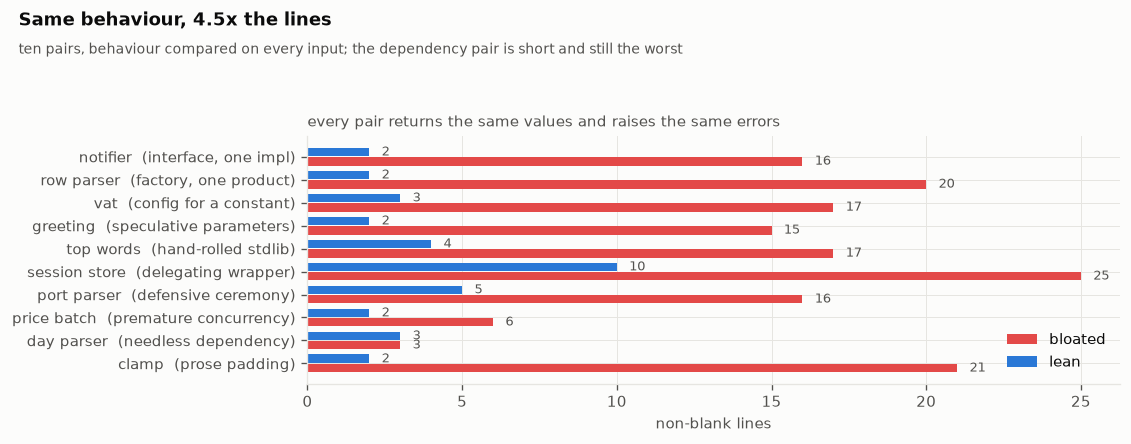

[fig 1] s1_specimens.png


In [61]:
# FIG  how much code each shape costs, for the same behaviour
fig, ax = plt.subplots(figsize=(9.5, 3.8))
names = [r["specimen"] for r in rows]                          # the specimens, in table order
y = np.arange(len(rows))                                       # one row of the chart per specimen
ax.barh(y + 0.2, [r["bloated"] for r in rows], 0.38, color=C8, label="bloated")   # red, just below the row's centre
ax.barh(y - 0.2, [r["lean"] for r in rows], 0.38, color=C1, label="lean")         # blue, just above it
for i, r in enumerate(rows):
    # each bar's count, written just past its end
    ax.text(r["bloated"] + 0.4, i + 0.2, f'{r["bloated"]}', va="center", fontsize=8, color=INK2)
    ax.text(r["lean"] + 0.4, i - 0.2, f'{r["lean"]}', va="center", fontsize=8, color=INK2)
ax.set_yticks(y, [f'{r["specimen"]}  ({r["shape"]})' for r in rows])
ax.invert_yaxis()                                              # the first specimen at the top
ax.set_xlabel("non-blank lines")
ax.legend(loc="lower right")
panel(ax, "every pair returns the same values and raises the same errors")
finish(fig, "s1_specimens", f"Same behaviour, {total_b / total_l:.1f}x the lines",
       "ten pairs, behaviour compared on every input; the dependency pair is short and still the worst")

**Reading FIG 1 (s1_specimens).** Each pair of bars is one program written twice. The red bar is the version an agent tends to produce, the blue bar the version the task needs, and the two were checked to behave identically on every input listed. The largest ratios come from two very different places: prose (the clamp, 10.5x, almost all of it docstring) and structure (the factory, 10.0x, and the one-implementation interface, 8.0x). The delegating wrapper costs less than it looks (2.5x), because the lean version still has to do the same work inline. The day parser is the useful outlier: the same length both ways, and still the worst of the ten, because one of the two versions brings a third-party package with it. That is why the rest of this Part never relies on line counts alone.

## S2 - The bloat meter: counting lines that cannot be gamed

**Theory.** "Lines of code" is a weak metric when it is counted naively and a useful one when it is counted carefully. Three corrections matter. First, a line is only *code* if it is not blank, not a full-line comment and not part of a docstring; we take comments from the tokenizer (so a `#` inside a string stays code) and docstrings from the syntax tree (so only the string that opens a module, class or function counts as prose). Second, a self-check that the agent leaves behind on purpose (an `if __name__ == "__main__":` block of asserts, or a `def selfcheck():`) is moved into its own bucket, because our system *asks* for one runnable check and must not be punished for writing it. Third, when we measure a change we count only the lines the change **added**, using a line-level diff against the seed, so a file the agent merely touched is not charged for its existing contents.

**In plain terms.** We count real code only, we do not punish the one test we asked for, and we count what the agent added, not what was already there.

**How one added line is classified.** The tests run in order and the first match wins, so a comment in a test file is still prose and a docstring is never mistaken for code. Only the last bucket is the number this notebook calls added code.

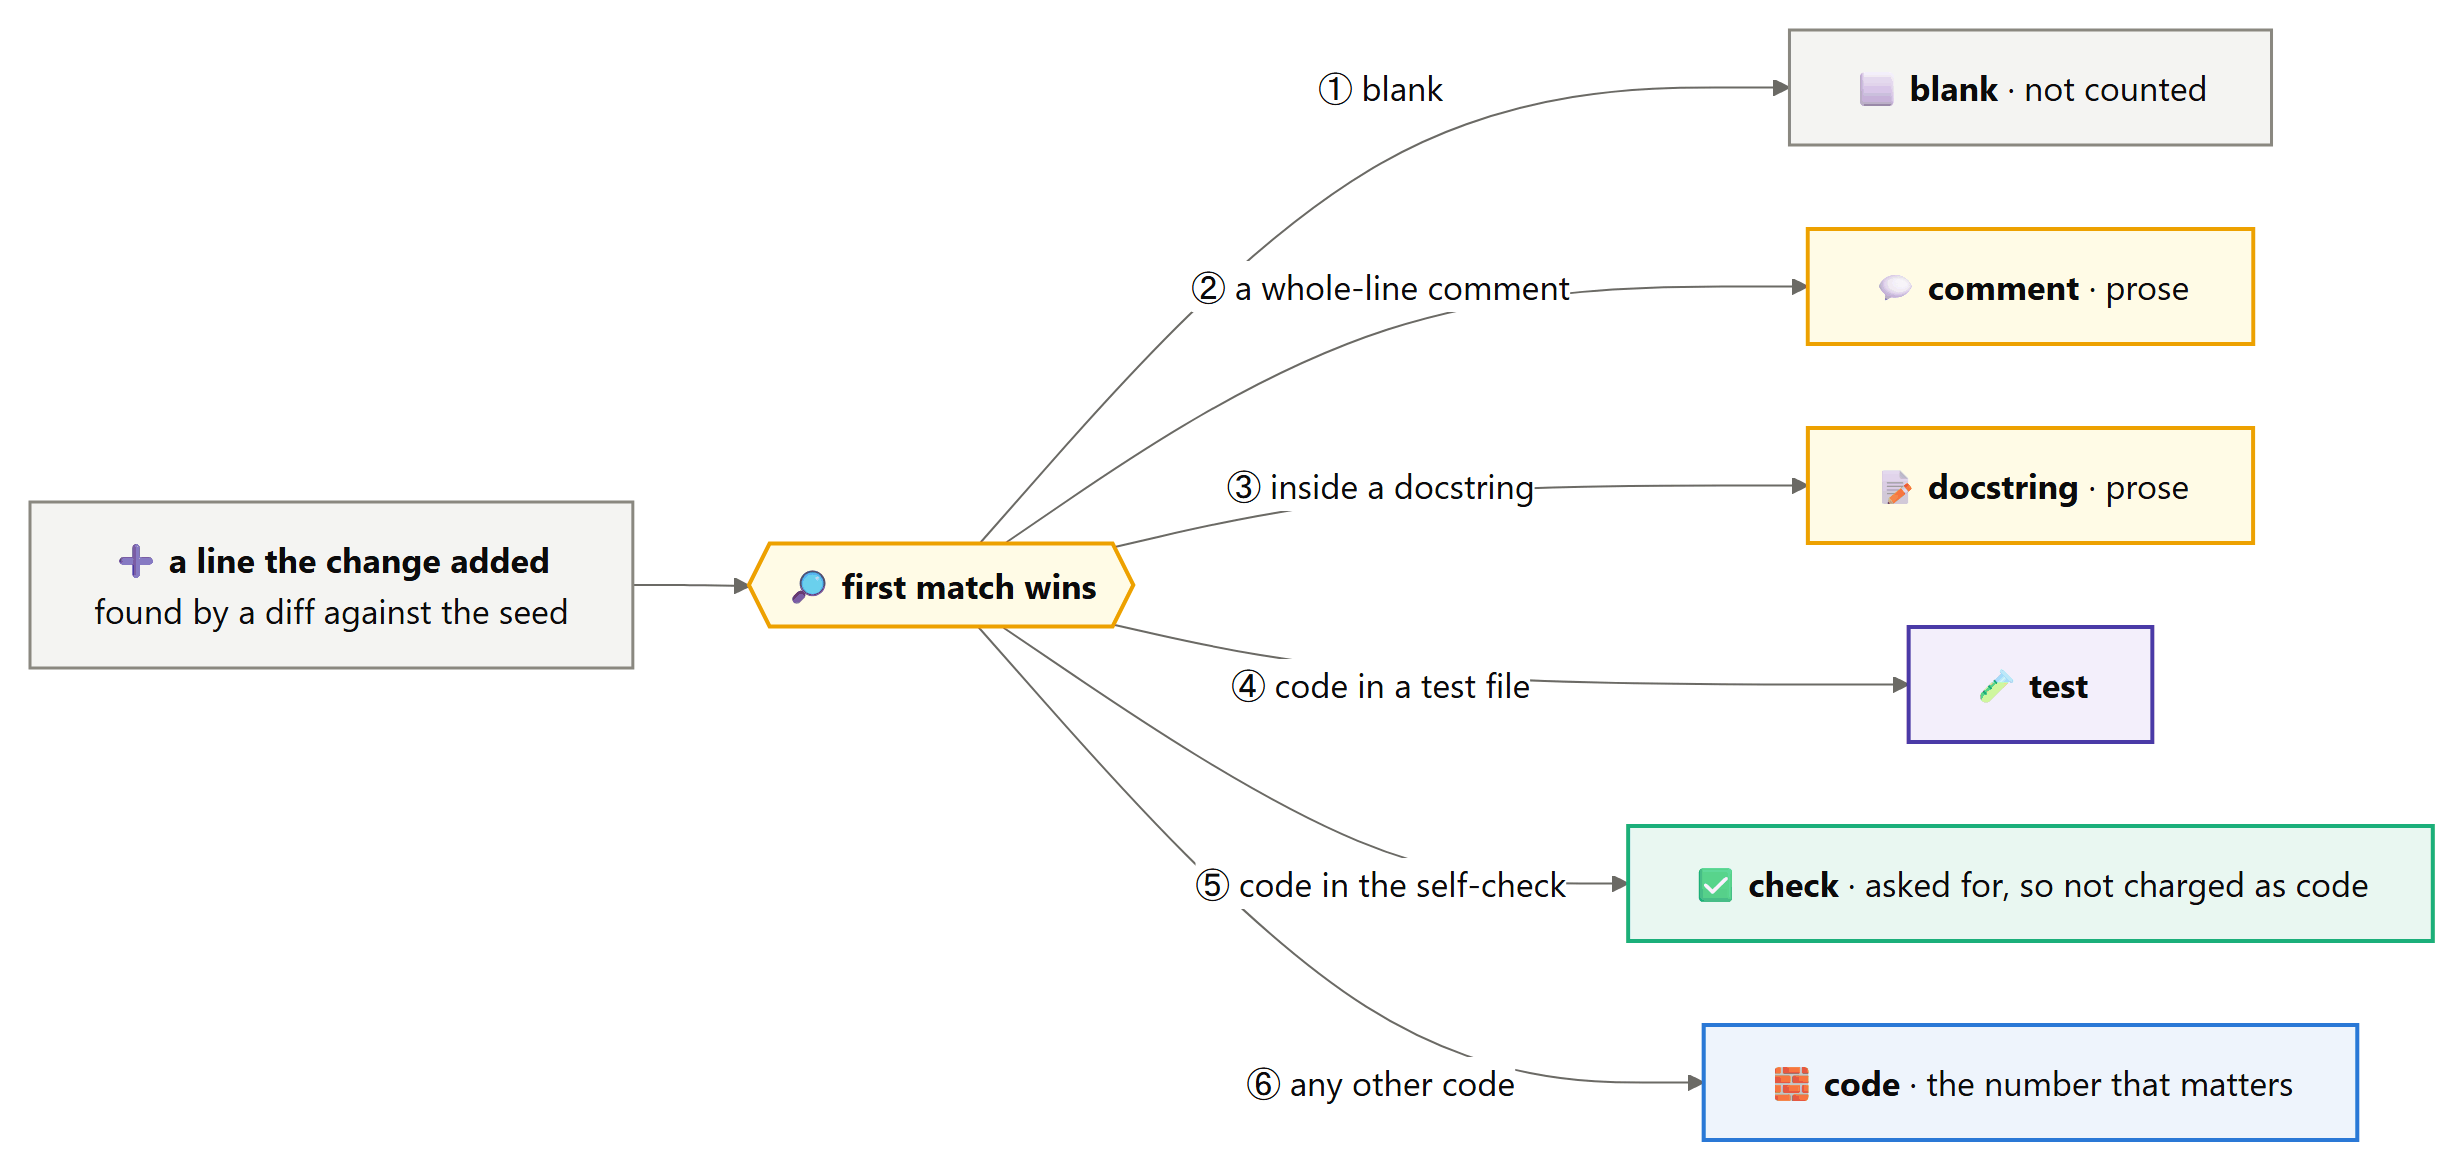

The meter needs three more modules from the standard library. The tokenizer is the important one: it reads source the way Python does, so it knows a real comment from a `#` that sits inside a string, which no text search can.

In [62]:
import io            # the tokenizer reads source through a file-like object
import tokenize      # Python's own tokenizer: a comment is a token, a '#' inside a string is not
import difflib       # the line diff behind added_lines()
from collections import Counter   # tallies of line labels

# what the tokenizer sees in a line that a text search would call a comment
for tok in tokenize.generate_tokens(io.StringIO('x = "# not a comment"  # a comment\n').readline):
    if tok.type in (tokenize.STRING, tokenize.COMMENT):
        print(f"  {tokenize.tok_name[tok.type]:<8} {tok.string}")

  STRING   "# not a comment"
  COMMENT  # a comment


**`classify_lines(src)`** gives every line of a program one label: blank, comment, docstring or code. Comments come from the tokenizer, and a line counts as a comment only when the comment is all it holds. Docstrings come from the syntax tree, so only the string that opens a module, class or function is prose, and a string anywhere else is code. Source that cannot be tokenized falls back to a plain prefix test, and source that does not parse keeps its comment labels but has no docstrings.

In [63]:
def classify_lines(src):
    """Label every line of a Python source: blank, comment, docstring or code."""
    lines = src.splitlines()                         # one entry per line, numbered like the labels
    labels = ["blank" if not ln.strip() else "code" for ln in lines]   # every line starts as code or blank
    try:
        for tok in tokenize.generate_tokens(io.StringIO(src).readline):   # the tokens Python itself would read
            # a comment token on a line that starts with '#': the whole line is a comment
            if tok.type == tokenize.COMMENT and lines[tok.start[0] - 1].lstrip().startswith("#"):
                labels[tok.start[0] - 1] = "comment"     # token lines count from 1, the list from 0
    except (tokenize.TokenError, IndentationError, SyntaxError):   # such as an unclosed bracket
        for i, ln in enumerate(lines):               # broken source: fall back to a prefix test
            if ln.lstrip().startswith("#"):
                labels[i] = "comment"
    try:
        tree = ast.parse(src)
    except SyntaxError:                              # no tree, so no docstrings to find
        return labels
    for node in ast.walk(tree):                      # the module, and every class and function at any depth
        if isinstance(node, (ast.Module, ast.ClassDef, ast.FunctionDef, ast.AsyncFunctionDef)) and node.body:
            first = node.body[0]                     # only the first statement can be a docstring
            # a docstring is a bare string as the first statement of a module, class or function
            is_docstring = (isinstance(first, ast.Expr) and isinstance(first.value, ast.Constant)
                            and isinstance(first.value.value, str))
            if is_docstring:
                for r in range(first.lineno - 1, first.end_lineno):   # every line the string spans
                    if labels[r] != "blank":         # a blank line inside a docstring stays blank
                        labels[r] = "docstring"
    return labels

show_def(classify_lines)

[def] classify_lines(src)  26 lines, complexity 18


The bloated notifier, labelled line by line:

In [64]:
demo = SPECIMENS[0]["bloated"]          # the notifier, with its interface and docstrings
# each line with its label, numbered from 1 as an editor shows them
for n, (label, ln) in enumerate(zip(classify_lines(demo), demo.splitlines()), 1):
    if label != "blank":                # blank lines would only add noise here
        print(f"  {n:>3}  {label:<9}  {ln[:70]}")
print("\n  counts:", dict(sorted(Counter(classify_lines(demo)).items())))   # every label, totalled

    1  code       from abc import ABC, abstractmethod
    4  code       class Notifier(ABC):
    5  docstring      """Base class for every notification channel."""
    7  code           @abstractmethod
    8  code           def send(self, to: str, message: str) -> str:
    9  docstring          """Send a message to a recipient."""
   12  code       class EmailNotifier(Notifier):
   13  docstring      """Email implementation of the Notifier interface."""
   15  code           def __init__(self, sender: str = "noreply@example.com"):
   16  code               self.sender = sender
   18  code           def send(self, to: str, message: str) -> str:
   19  code               return f"{self.sender} -> {to}: {message}"
   22  code       def notify(to: str, message: str, notifier: Notifier | None = None) ->
   23  docstring      """Notify a user through the configured channel."""
   24  code           notifier = notifier or EmailNotifier()
   25  code           return notifier.send(to, message)

**`check_tail_start(src)`** finds where a program's self-check begins: the first line, at the top level, that opens an `if __name__ == "__main__":` block or defines a function called `demo`, `selfcheck`, `check` or `smoke` (with or without a leading underscore). Everything from that line to the end is the check tail. The system asks the agent for exactly one runnable check, so the meter must not charge it as code.

In [65]:
# the first line of a self-check: the main guard, or a function named for what it does
CHECK_START = re.compile(r"^(if __name__\s*==|def _?(demo|selfcheck|check|smoke)\s*\()")

def check_tail_start(src):
    """Index of the first top-level line that begins a self-check, or None."""
    for i, ln in enumerate(src.splitlines()):        # counted from 0, like the labels
        if CHECK_START.match(ln):        # the pattern has no leading space, so indented lines never match
            return i
    return None

show_def(check_tail_start)

[def] check_tail_start(src)  6 lines, complexity 3


In [66]:
tail_demo = SPECIMENS[9]["lean"] + '\n\nif __name__ == "__main__":\n    assert clamp(5, 0, 3) == 3\n'
print(f"[check_tail_start] the tail starts at line index {check_tail_start(tail_demo)} of:\n{tail_demo}")

[check_tail_start] the tail starts at line index 4 of:
def clamp(value, low, high):
    return max(low, min(value, high))


if __name__ == "__main__":
    assert clamp(5, 0, 3) == 3



**`is_test_file(path)`** decides from its path whether a file holds tests: named `test_*.py`, `tests_*.py` or `*_test.py`, called `conftest.py`, or kept under a folder named `tests` or `test`. Code added in a test file is charged as test lines, never as code.

In [67]:
def is_test_file(path):
    p = Path(path)
    if p.name.startswith(("test_", "tests_")) or p.name.endswith("_test.py"):   # named like a test module
        return True
    if p.name == "conftest.py":                                                  # pytest's fixtures file
        return True
    return any(part in ("tests", "test") for part in p.parts[:-1])               # or a folder above it called so

show_def(is_test_file)

[def] is_test_file(path)  7 lines, complexity 5


In [68]:
for example_path in ("app.py", "test_app.py", "app_test.py", "tests/helpers.py", "conftest.py", "testing/app.py"):
    print(f"  {example_path:<18} {'test' if is_test_file(example_path) else 'code'}")

  app.py             code
  test_app.py        test
  app_test.py        test
  tests/helpers.py   test
  conftest.py        test
  testing/app.py     code


**`measure_source(src, path="x.py")`** counts a whole file by label: code, comment, docstring and blank, plus two buckets that are never charged as code. In a test file every code line is a test line; elsewhere, code from the start of the self-check tail onwards is a check line. The path matters only for the test rule, so text with no file behind it can be measured as `x.py`.

In [69]:
def measure_source(src, path="x.py"):
    """Counts for a whole file: code, comment, docstring, blank, plus check lines
    (code inside a self-check tail) and test lines (code in a test file)."""
    labels = classify_lines(src)
    start = check_tail_start(src)
    out = Counter(labels)                              # code, comment, docstring and blank, as labelled
    if is_test_file(path):
        out["test"], out["code"] = out["code"], 0      # in a test file, all the code is test code
    elif start is not None:
        # code lines at or after the start of the self-check tail move to the check bucket
        moved = sum(1 for i, lab in enumerate(labels) if i >= start and lab == "code")
        out["check"], out["code"] = moved, out["code"] - moved
    # every bucket in a fixed order, zero when absent, so callers never test for a missing key
    return {k: out.get(k, 0) for k in ("code", "comment", "docstring", "blank", "check", "test")}

show_def(measure_source)

[def] measure_source(src, path='x.py')  12 lines, complexity 6


In [70]:
print("[measure_source] the bloated notifier  :", measure_source(SPECIMENS[0]["bloated"]))
print("[measure_source] the same, as a test   :", measure_source(SPECIMENS[0]["bloated"], "tests/test_notify.py"))

[measure_source] the bloated notifier  : {'code': 12, 'comment': 0, 'docstring': 4, 'blank': 9, 'check': 0, 'test': 0}
[measure_source] the same, as a test   : {'code': 0, 'comment': 0, 'docstring': 4, 'blank': 9, 'check': 0, 'test': 12}


**`added_lines(before, after)`** lists the lines of `after` that are new: inserted, or replacing a line that was there before. It uses `difflib`'s matcher with the automatic junk heuristic switched off. On a file of 200 lines or more, that heuristic ignores any line that makes up more than one percent of it, blank lines for instance, which would make the answer depend on how long the file is.

In [71]:
def added_lines(before, after):
    """0-based line numbers in `after` that are new compared with `before`."""
    a, b = before.splitlines(), after.splitlines()   # compared line by line, not character by character
    out = []
    # each opcode says how one stretch of a becomes b: equal, insert, delete or replace
    for tag, _, _, j1, j2 in difflib.SequenceMatcher(a=a, b=b, autojunk=False).get_opcodes():
        if tag in ("insert", "replace"):         # new lines, or changed ones: both belong to the change
            out.extend(range(j1, j2))            # j1 to j2 are positions in `after`
    return out

show_def(added_lines)

[def] added_lines(before, after)  8 lines, complexity 3


In [72]:
before_demo = "a = 1\nb = 2\n"
after_demo = "a = 1\nb = 3\nc = 4\n"                         # b changed, c is new
print(f"[added_lines] new lines in the second version: {added_lines(before_demo, after_demo)}")

[added_lines] new lines in the second version: [1, 2]


**`measure_change(seed, final)`** measures a whole change. Its inputs map each relative path to its text: `seed` as the task handed the files over, `final` as the agent left them. Only Python files count. For each file that changed, only the added lines are labelled, so a file the agent merely touched is not charged for what it already held; added code is a test line in a test file and a check line inside the self-check tail. `removed` counts the seed's lines that did not survive. The result always has the same nine keys.

In [73]:
def measure_change(seed, final):
    """What a change added, by kind, across all Python files.
    seed and final map each relative path to its source text."""
    totals = Counter()
    for path, after in final.items():
        if not path.endswith(".py"):                       # only Python is measured
            continue
        before = seed.get(path, "")                        # a new file is measured against nothing
        if after == before:                                # untouched files cost nothing
            continue
        totals["files_touched"] += 1
        totals["files_new"] += path not in seed            # True counts as one
        labels = classify_lines(after)                     # labels of the file as the agent left it
        start = check_tail_start(after)                    # and where its self-check begins, if anywhere
        added = added_lines(before, after)
        for i in added:
            lab = labels[i]
            if lab == "code" and is_test_file(path):
                lab = "test"                               # code in a test file is test code
            elif lab == "code" and start is not None and i >= start:
                lab = "check"                              # code inside the self-check tail
            totals[f"added_{lab}"] += 1
        # the seed's lines minus those the final file kept: what the change took out
        totals["removed"] += len(before.splitlines()) - (len(after.splitlines()) - len(added))
    keys = ("added_code", "added_comment", "added_docstring", "added_check", "added_test",
            "added_blank", "removed", "files_touched", "files_new")
    return {k: totals.get(k, 0) for k in keys}

show_def(measure_change)

[def] measure_change(seed, final)  26 lines, complexity 11


In [74]:
change = measure_change({"app.py": "x = 1\n"},
                        {"app.py": "x = 1\n# why y exists\ny = 2\n", "README.md": "notes\n"})
print(f"[measure_change] {change}")

[measure_change] {'added_code': 1, 'added_comment': 1, 'added_docstring': 0, 'added_check': 0, 'added_test': 0, 'added_blank': 0, 'removed': 0, 'files_touched': 1, 'files_new': 0}


**The meter must not be fooled.** Before it measures anything that matters, the meter faces inputs built to fool it. The first attack is random: blank lines and comments dropped into every specimen at random places, four hundred times, and the code count must never move. The rest are specific traps: a `#` inside a string, a string that is not a docstring, Windows line endings, a self-check tail, and a change to a file that already had content.

In [75]:
# ---- the meter must not be fooled: property tests ------------------------------
rng = random.Random(SEED)   # a generator of its own, so the random tests draw the same positions every run
results = []                # every expect() lands here; each test section starts by emptying it
print(f"[tests] positions drawn from a generator seeded @ {SEED}; {len(results)} results so far")

[tests] positions drawn from a generator seeded @ 42; 0 results so far


**`expect(name, ok)`** is the notebook's one assertion helper. It prints a PASSED or FAILED line and appends the outcome to `results`, so a test section can run every check and show every failure before a single `assert` decides whether the instrument may be used. Every test cell from here to Part X uses it.

In [76]:
def expect(name, ok):
    """Record and print one PASSED/FAILED line; used by every test cell in the notebook."""
    results.append((name, bool(ok)))      # looked up at each call: a later section's fresh list is the one filled
    print(f"  {'PASSED' if ok else 'FAILED'}  {name}")

show_def(expect)

[def] expect(name, ok)  4 lines, complexity 2


**`sprinkle(src, kind, k)`** inserts `k` blank lines or full-line comments at random places in a program. A comment is indented like the line above it, as a person would write it, and every position comes from `rng`, so each run inserts in the same places.

In [77]:
def sprinkle(src, kind, k):
    """Insert k blank lines or full-line comments at random positions."""
    lines = src.splitlines()
    for _ in range(k):                                                     # one insertion at a time
        pos = rng.randrange(len(lines) + 1)                                # anywhere, including after the last line
        indent = re.match(r"\s*", lines[pos - 1] if pos else "").group(0)  # the indentation of the line above
        # a blank line, or a comment numbered at random so no two are alike
        lines.insert(pos, "" if kind == "blank" else f"{indent}# note {rng.randrange(999)}")
    return "\n".join(lines) + "\n"                                          # back to text, with a final newline

show_def(sprinkle)

[def] sprinkle(src, kind, k)  8 lines, complexity 4


Four hundred random insertions: every specimen, both versions, blank lines and then comments, ten times each, one to five lines at a time. A failure would print its own line; the summary says whether there was any.

In [78]:
trials = 0                                                         # insertions tried, for the summary line
for s in SPECIMENS:
    for variant in ("bloated", "lean"):
        base = measure_source(s[variant])["code"]                  # the code count before anything is inserted
        for kind in ("blank", "comment"):
            for _ in range(10):
                trials += 1
                # one to five lines at a time; the code count must not move at all
                if measure_source(sprinkle(s[variant], kind, rng.randrange(1, 6)))["code"] != base:
                    expect(f"{s['name']} {variant}: random {kind}s changed the code count", False)
# passes only if no insertion above recorded a failure
expect(f"{trials} random insertions of blank lines and comments never changed a code count",
       all(ok for _, ok in results))

  PASSED  400 random insertions of blank lines and comments never changed a code count


What one of those insertions looks like, on the lean clamp. The draws come after the tests, so they change nothing above.

In [79]:
sprinkled = sprinkle(SPECIMENS[9]["lean"], "comment", 2)          # two comments in a two-line function
print(sprinkled)
print(f"code lines: {measure_source(SPECIMENS[9]['lean'])['code']} before, {measure_source(sprinkled)['code']} after")

# note 67
def clamp(value, low, high):
    return max(low, min(value, high))
    # note 905

code lines: 2 before, 2 after


The specific traps for the line labels, each built to catch one way a naive counter goes wrong.

In [80]:
# a text search would call this line a comment
expect("a '#' inside a string is code, not a comment",
       classify_lines('x = "# not a comment"\n') == ["code"])
# the second bare string comes after the docstring, so it is code
expect("only the opening string of a function is a docstring",
       classify_lines('def f():\n    """doc"""\n    "not a doc"\n    return 1\n')
       == ["code", "docstring", "code", "code"])
# the same program with Windows line endings
expect("CRLF line endings give the same counts as LF",
       measure_source(SPECIMENS[0]["bloated"].replace("\n", "\r\n")) == measure_source(SPECIMENS[0]["bloated"]))

  PASSED  a '#' inside a string is code, not a comment
  PASSED  only the opening string of a function is a docstring
  PASSED  CRLF line endings give the same counts as LF


And the two buckets that keep the meter fair: the self-check tail, and a change charged only for what it added. One `assert` then decides.

In [81]:
# the lean clamp with a two-line self-check appended
with_check = SPECIMENS[9]["lean"] + '\n\nif __name__ == "__main__":\n    assert clamp(5, 0, 3) == 3\n'
m = measure_source(with_check)                       # the clamp's two code lines, then the two check lines
expect("a self-check tail is counted as check, not as code", m["code"] == 2 and m["check"] == 2)
# one line added to an existing file, and a new test file
m = measure_change({"a.py": "x = 1\n"}, {"a.py": "x = 1\ny = 2\n", "test_a.py": "assert True\n"})
expect("a change is charged only for the lines it added; test files count as tests",
       m["added_code"] == 1 and m["added_test"] == 1 and m["files_touched"] == 2 and m["files_new"] == 1)
# one failure anywhere above stops the notebook here
assert all(ok for _, ok in results), "the bloat meter failed its own tests"
print(f"\n  -> {sum(ok for _, ok in results)}/{len(results)} meter checks PASSED; the meter is trusted from here on")

  PASSED  a self-check tail is counted as check, not as code
  PASSED  a change is charged only for the lines it added; test files count as tests

  -> 6/6 meter checks PASSED; the meter is trusted from here on


The meter's first use: the ten bloated specimens again, this time split into what their lines actually are.

In [82]:
comp = []                                         # one entry per specimen
for s in SPECIMENS:
    b = measure_source(s["bloated"])                  # every bucket, for the bloated version
    l = measure_source(s["lean"])                     # the lean version: only its code is used
    entry = {"specimen": s["name"]}                   # keys in a fixed order: name, bloated buckets, lean code
    for k, v in b.items():
        entry[f"b_{k}"] = v                           # b_code, b_comment, b_docstring and so on
    entry["l_code"] = l["code"]
    comp.append(entry)                                # FIG 2 reads these rows
# the four columns worth showing, renamed for the table
table([{"specimen": c["specimen"], "code": c["b_code"], "comment": c["b_comment"],
        "docstring": c["b_docstring"], "lean code": c["l_code"]} for c in comp],
      [("specimen", "specimen", ""), ("code", "bloated code", "d"), ("comment", "comment", "d"),
       ("docstring", "docstring", "d"), ("lean code", "lean code", "d")])

  specimen       bloated code  comment  docstring  lean code
  ----------------------------------------------------------
  notifier                 12        0          4          2
  row parser               20        0          0          2
  vat                      17        0          0          3
  greeting                  4        0         11          2
  top words                17        0          0          4
  session store            24        0          1         10
  port parser              16        0          0          5
  price batch               6        0          0          2
  day parser                3        0          0          3
  clamp                     2        3         16          2


In [83]:
prose_b = sum(c["b_comment"] + c["b_docstring"] for c in comp)                 # comment and docstring lines, all ten
nonblank_b = sum(c["b_code"] + c["b_comment"] + c["b_docstring"] for c in comp)
code_b = sum(c["b_code"] for c in comp)                                         # code alone, bloated
code_l = sum(c["l_code"] for c in comp)                                         # code alone, lean
print(f"\n  prose share of the bloated specimens: {prose_b}/{nonblank_b} = {prose_b / nonblank_b:.0%}")
print(f"  code-only ratio: {code_b} vs {code_l} lines = {code_b / code_l:.1f}x (raw ratio was {total_b / total_l:.1f}x)")
save_exp("meter", {"prose_share": prose_b / nonblank_b, "code_ratio": code_b / code_l,
                   "checks_passed": sum(ok for _, ok in results), "checks": len(results)})


  prose share of the bloated specimens: 35/156 = 22%
  code-only ratio: 121 vs 35 lines = 3.5x (raw ratio was 4.5x)
[exp] artifacts/exp_meter.json


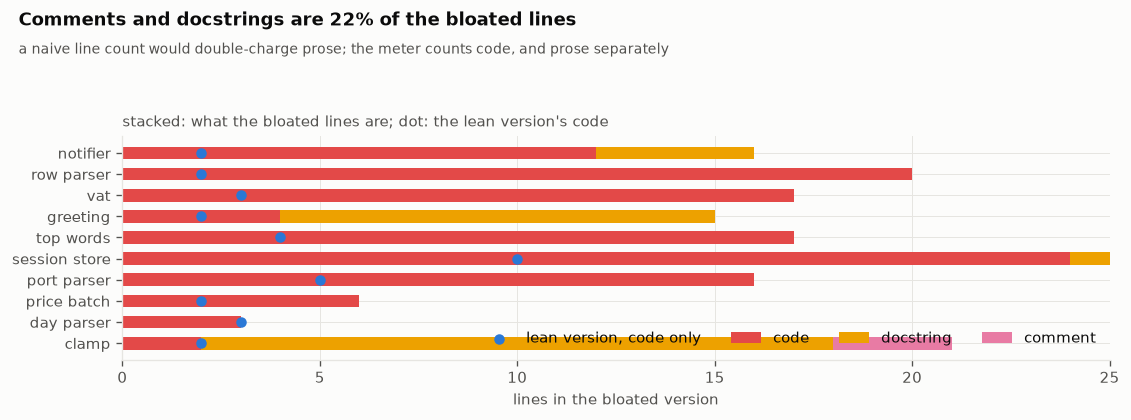

[fig 2] s2_composition.png


In [84]:
# FIG  where the lines of a bloated program go
fig, ax = plt.subplots(figsize=(9.5, 3.6))
y = np.arange(len(comp))
left = np.zeros(len(comp))                           # where the next segment of each bar starts
for key, colour, label in (("b_code", C8, "code"), ("b_docstring", C4, "docstring"), ("b_comment", C5, "comment")):
    vals = np.array([c[key] for c in comp])
    ax.barh(y, vals, 0.6, left=left, color=colour, label=label)
    left += vals                                     # the next kind of line starts where this one ends
ax.scatter([c["l_code"] for c in comp], y, color=C1, zorder=3, s=28, label="lean version, code only")
ax.set_yticks(y, [c["specimen"] for c in comp])
ax.invert_yaxis()                                    # the first specimen at the top
ax.set_xlabel("lines in the bloated version")
ax.legend(loc="lower right", ncol=4)
panel(ax, "stacked: what the bloated lines are; dot: the lean version's code")
finish(fig, "s2_composition", f"Comments and docstrings are {prose_b / nonblank_b:.0%} of the bloated lines",
       "a naive line count would double-charge prose; the meter counts code, and prose separately")

**Reading FIG 2 (s2_composition).** Each bar is one bloated specimen split by what its lines actually are; the blue dot is how much code the lean version needed. The clamp specimen is almost entirely prose, the notifier mixes structure and docstrings, and the factory is mostly structure. Counting these separately matters later: an agent that writes an essay in a docstring and an agent that writes an extra class are both over-building, but in different ways, and only one of them is caught by a judge reading the code.

## S3 - Ten detectors for the ten shapes

**Theory.** Line counts tell us *how much* was added, not *what kind* of thing. Each shape from the front matter leaves a recognisable footprint in the syntax tree: an abstract class with exactly one subclass, a registry with exactly one entry, a function parameter that is never read, a loop that retries a call which cannot fail transiently. Each detector below is a small function over `ast`, kept deliberately simple. The test that matters is the matrix after them: every bloated specimen must trip the detector for its own shape, and the lean versions must trip **none**. A detector that fires on the lean code is worse than no detector, because it teaches the agent to delete the wrong thing.

**In plain terms.** Ten small pattern checks, one per kind of bloat, each proven on the specimens before we use it.

**`IO_CALLS`** lists the names of calls that reach outside the program: files, sockets, HTTP, subprocesses, databases, and `sleep`. Two detectors need it, because a retry only makes sense around something in this set, and so does a thread pool. Matching goes by the called name alone, so `requests.get` and `cache.get` both count as I/O. For these two detectors that is the safe mistake: it silences an alarm rather than raising a false one.

In [85]:
IO_CALLS = {"open", "urlopen", "request", "get", "post", "put", "connect", "send", "recv", "sendall",
            "run", "Popen", "check_output", "call", "read", "write", "execute", "fetch", "sleep"}
print(f"[detectors] {len(IO_CALLS)} call names count as I/O")

[detectors] 19 call names count as I/O


**`_calls(node)`** collects the name of everything called anywhere inside a piece of syntax tree. `f()` gives `f`, and `x.f()` gives `f` too, whatever `x` is; a call with no name to give, such as `handlers[0]()`, adds an empty string.

In [86]:
def _calls(node):
    """Names of everything called inside a node (f() and x.f() both give 'f')."""
    out = set()                                  # each name once, however often it is called
    for n in ast.walk(node):
        if isinstance(n, ast.Call):
            f = n.func                               # what is being called: a name, an attribute, or anything else
            if isinstance(f, ast.Name):          # f()
                out.add(f.id)
            elif isinstance(f, ast.Attribute):   # x.f(): the method's name, whatever x is
                out.add(f.attr)
            else:                                # handlers[0]() or (lambda: 1)(): nothing to name
                out.add("")
    return out

show_def(_calls)

[def] _calls(node)  13 lines, complexity 5


In [87]:
print(f"[_calls] {sorted(_calls(ast.parse('data = json.loads(open(path).read())')))}")

[_calls] ['loads', 'open', 'read']


**`_base_names(cls)`** returns the names of a class's bases, whether written plainly (`ABC`) or through a module (`abc.ABC`). A base written as a subscript or a call, such as `Generic[T]`, has no simple name and contributes an empty string.

In [88]:
def _base_names(cls):
    names = set()
    for b in cls.bases:                          # the classes listed in the brackets of the class statement
        if isinstance(b, ast.Name):              # class C(Base)
            names.add(b.id)
        elif isinstance(b, ast.Attribute):       # class C(abc.ABC)
            names.add(b.attr)
        else:                                    # class C(Generic[T]): no simple name
            names.add("")
    return names

show_def(_base_names)

[def] _base_names(cls)  10 lines, complexity 4


In [89]:
store_class = ast.parse("class Store(abc.ABC, Base, Generic[T]):\n    pass\n").body[0]
print(f"[_base_names] {sorted(_base_names(store_class))}")

[_base_names] ['', 'ABC', 'Base']


**`_is_abstract(cls)`** recognises a class written to be subclassed rather than used. Three signs count: it inherits from `ABC` or `Protocol`, one of its methods carries `@abstractmethod`, or one of its methods raises `NotImplementedError` directly in its body, which is how an abstract method looks when it is written without the `abc` module.

In [90]:
def _is_abstract(cls):
    if _base_names(cls) & {"ABC", "Protocol"}:         # declared abstract by its base
        return True
    for f in cls.body:                                 # the class's own statements, methods among them
        if not isinstance(f, (ast.FunctionDef, ast.AsyncFunctionDef)):   # attributes and nested classes say nothing
            continue
        decos = set()                                  # the names of the method's decorators
        for d in f.decorator_list:
            # @abstractmethod and @abc.abstractmethod give the same name; a decorator call gives ""
            decos.add(d.id if isinstance(d, ast.Name) else getattr(d, "attr", ""))
        if "abstractmethod" in decos:
            return True
        # the other way to write an abstract method: raise NotImplementedError in its body
        if any(isinstance(s, ast.Raise) and "NotImplementedError" in ast.unparse(s) for s in f.body):
            return True
    return False

show_def(_is_abstract)

[def] _is_abstract(cls)  14 lines, complexity 10


In [91]:
for node in ast.walk(ast.parse(SPECIMENS[0]["bloated"])):     # the classes of the bloated notifier
    if isinstance(node, ast.ClassDef):
        print(f"  {node.name:<14} abstract: {_is_abstract(node)}")

  Notifier       abstract: True
  EmailNotifier  abstract: False


**`d_interface(tree)`**, shape 1: an abstract class with exactly one subclass in the same code. With one implementation there is nothing to choose between, so the abstraction is only a second name for the one real class; with two or more it is a real interface and the detector stays quiet. Like every detector below, it returns a list of `(line, note)` pairs, empty when the code is clean.

In [92]:
def d_interface(tree):
    classes = [n for n in ast.walk(tree) if isinstance(n, ast.ClassDef)]   # every class, nested ones included
    hits = []                                                           # (line, note) for each finding
    for c in classes:
        if _is_abstract(c):                                             # only an abstract class can be an interface
            subs = [k for k in classes if c.name in _base_names(k)]     # the classes that name c as a base
            if len(subs) == 1:                                          # exactly one: nothing to abstract over
                hits.append((c.lineno, f"abstract {c.name} has one implementation ({subs[0].name})"))
    return hits

show_def(d_interface)

[def] d_interface(tree)  9 lines, complexity 6


In [93]:
print("  bloated:", d_interface(ast.parse(SPECIMENS[0]["bloated"])))
print("  lean   :", d_interface(ast.parse(SPECIMENS[0]["lean"])))

  bloated: [(4, 'abstract Notifier has one implementation (EmailNotifier)')]
  lean   : []


**`d_factory(tree)`**, shape 2: a class or function with "factory" in its name, or a registry with a single entry, meaning a one-key dict literal assigned to a name that contains "registry". The name test is blunt, and that is fine: code that builds a factory almost always calls it one.

In [94]:
def d_factory(tree):
    hits = []
    for n in ast.walk(tree):                     # classes, functions and assignments are all of interest
        # named after the pattern: ParserFactory, make_factory and the like
        if isinstance(n, (ast.ClassDef, ast.FunctionDef)) and "factory" in n.name.lower():
            hits.append((n.lineno, f"{n.name}: a factory"))
        # a dict literal with one key, assigned to something called a registry
        one_entry = isinstance(n, ast.Assign) and isinstance(n.value, ast.Dict) and len(n.value.keys) == 1
        if one_entry and any("registry" in ast.unparse(t).lower() for t in n.targets):   # _registry counts too
            hits.append((n.lineno, "a registry with one entry"))
    return hits

show_def(d_factory)

[def] d_factory(tree)  9 lines, complexity 9


In [95]:
print("  bloated:", d_factory(ast.parse(SPECIMENS[1]["bloated"])))
print("  lean   :", d_factory(ast.parse(SPECIMENS[1]["lean"])))

  bloated: [(14, 'ParserFactory: a factory'), (15, 'a registry with one entry')]
  lean   : []


**`d_config(tree)`**, shape 3: a class named like configuration (ending in `Config`, `Settings` or `Options`) that is never called by its own name with an argument anywhere in the code. A configuration nobody configures holds only its defaults, and a default is a constant. A call through `cls(...)` inside the class's own methods does not count, so a `from_env()` that nobody needs does not save it.

In [96]:
def d_config(tree):
    hits = []
    names = set()                                                  # classes whose names say they hold settings
    for n in ast.walk(tree):                                       # nested classes included
        if isinstance(n, ast.ClassDef) and re.search(r"(Config|Settings|Options)$", n.name):
            names.add(n.name)
    for name in names:                                             # each settings class, judged on its own
        # called by its own name with at least one argument, anywhere in the code
        built_with_args = any(isinstance(n, ast.Call) and getattr(n.func, "id", "") == name
                              and (n.args or n.keywords) for n in ast.walk(tree))
        if not built_with_args:
            hits.append((0, f"{name} is never built with a non-default value"))   # line 0: about the file as a whole
    return hits

show_def(d_config)

[def] d_config(tree)  12 lines, complexity 10


In [97]:
print("  bloated:", d_config(ast.parse(SPECIMENS[2]["bloated"])))
print("  lean   :", d_config(ast.parse(SPECIMENS[2]["lean"])))

  bloated: [(0, 'PricingConfig is never built with a non-default value')]
  lean   : []


**`d_unused_param(tree)`**, shape 4: a parameter the function body never reads. A function whose body is only `pass` or `raise` is a stub or an abstract method, where the parameters are the interface itself, so it is skipped; so are `self`, `cls` and names that start with an underscore, which by convention may go unused. When the body opens with an expression it is left out of the search, which is how the docstring is set aside.

In [98]:
def d_unused_param(tree):
    hits = []
    for f in ast.walk(tree):                               # every function and method, at any depth
        if not isinstance(f, (ast.FunctionDef, ast.AsyncFunctionDef)):
            continue
        body = f.body                                      # the statements that could read a parameter
        if f.body and isinstance(f.body[0], ast.Expr):     # the docstring, or any other opening expression
            body = f.body[1:]
        if not body or all(isinstance(s, (ast.Pass, ast.Raise)) for s in body):
            continue                      # abstract or stub: parameters are the interface
        used = set()                                       # every name the rest of the body mentions
        for s in body:
            for n in ast.walk(s):                          # names inside nested functions count too
                if isinstance(n, ast.Name):
                    used.add(n.id)
        for a in f.args.args + f.args.kwonlyargs:          # the ordinary and keyword-only parameters
            if a.arg in used or a.arg in ("self", "cls") or a.arg.startswith("_"):   # read, a receiver, or private
                continue
            hits.append((f.lineno, f"{f.name}({a.arg}) is never read"))   # one finding per unread parameter
    return hits

show_def(d_unused_param)

[def] d_unused_param(tree)  20 lines, complexity 15


In [99]:
print("  bloated:", d_unused_param(ast.parse(SPECIMENS[3]["bloated"])))
print("  lean   :", d_unused_param(ast.parse(SPECIMENS[3]["lean"])))

  bloated: [(1, 'greet(locale) is never read')]
  lean   : []


**`d_handrolled(tree)`**, shape 5: a loop that keeps a tally by hand, `counts[word] = counts[word] + 1` or `counts[word] += 1`, which is `collections.Counter` written out. One finding per file is enough, because the advice is the same however many such loops there are.

In [100]:
def d_handrolled(tree):
    hits = []
    for loop in ast.walk(tree):
        if not isinstance(loop, (ast.For, ast.While)):     # a tally is only kept inside a loop
            continue
        for n in ast.walk(loop):
            if not isinstance(n, (ast.Assign, ast.AugAssign)):   # x = ... or x += ...
                continue
            target = n.targets[0] if isinstance(n, ast.Assign) else n.target   # the first target is enough
            text = ast.unparse(n)                                               # the statement as source text
            # an item of something, such as counts[word], that ends up one higher
            if isinstance(target, ast.Subscript) and (re.search(r"\+ ?1$", text) or text.endswith("+= 1")):
                hits.append((n.lineno, "a counting loop: collections.Counter"))   # one finding per loop
                break
    return hits[:1]                                                             # one finding per file

show_def(d_handrolled)

[def] d_handrolled(tree)  14 lines, complexity 9


In [101]:
print("  bloated:", d_handrolled(ast.parse(SPECIMENS[4]["bloated"])))
print("  lean   :", d_handrolled(ast.parse(SPECIMENS[4]["lean"])))

  bloated: [(8, 'a counting loop: collections.Counter')]
  lean   : []


**`d_wrapper(tree)`**, shape 6: a class with at least three methods besides `__init__`, every one of them a single statement that touches a private attribute of its own (`self._something`). A class like that adds names but no behaviour. The threshold of three keeps a small class with one or two forwarding helpers out of it.

In [102]:
def d_wrapper(tree):
    def delegates(f):
        # leave out a docstring, or any constant that opens the body
        opens_with_constant = (f.body and isinstance(f.body[0], ast.Expr)
                               and isinstance(getattr(f.body[0], "value", None), ast.Constant))
        body = f.body[1:] if opens_with_constant else f.body
        return len(body) == 1 and "self._" in ast.unparse(body[0])     # one statement, about its own private attribute

    hits = []
    for c in ast.walk(tree):                     # every class, nested ones included
        if not isinstance(c, ast.ClassDef):
            continue
        # the methods besides __init__, which is allowed to set things up
        methods = [f for f in c.body if isinstance(f, ast.FunctionDef) and f.name != "__init__"]
        if len(methods) >= 3 and all(delegates(f) for f in methods):   # three or more, and every one forwards
            hits.append((c.lineno, f"{c.name} only forwards to its own attribute"))
    return hits

show_def(d_wrapper)

[def] d_wrapper(tree)  14 lines, complexity 12


In [103]:
print("  bloated:", d_wrapper(ast.parse(SPECIMENS[5]["bloated"])))
print("  lean   :", d_wrapper(ast.parse(SPECIMENS[5]["lean"])))

  bloated:

 [(1, 'SessionStore only forwards to its own attribute')]
  lean   : []


**`d_retry_local(tree)`**, shape 7: a retry loop around code that cannot fail transiently. A retry is a loop over attempts, `while` or `for ... in range(...)`, holding a `try` whose body leaves the loop on success. When nothing in that `try` body does I/O (a `sleep` between attempts does not count), the next attempt fails exactly like the last one. A loop over data with a `try` for each row is a different thing, a guard that keeps one bad row from losing the whole file, and it is left alone.

In [104]:
def d_retry_local(tree):
    """A retry is a loop over attempts (range(...) or while) whose try body exits on
    success. A loop over DATA with a try per row is a guard against data loss, not a
    retry, and must not be flagged."""
    hits = []
    for loop in ast.walk(tree):                                          # every node; most are not loops
        # a loop over attempts: `while ...` or `for ... in range(...)`
        over_attempts = isinstance(loop, ast.While) or (
            isinstance(loop, ast.For) and isinstance(loop.iter, ast.Call)
            and getattr(loop.iter.func, "id", "") == "range")
        if not over_attempts:                                            # a loop over data is not a retry
            continue
        for t in ast.walk(loop):
            if not isinstance(t, ast.Try):                               # a retry needs a try to catch the failure
                continue
            body = ast.Module(body=t.body, type_ignores=[])              # the try body alone, as a tree of its own
            exits = any(isinstance(n, (ast.Return, ast.Break)) for n in ast.walk(body))   # success leaves the loop
            # and nothing in the try body reaches outside the program (sleeping does not count)
            if exits and not (_calls(body) & (IO_CALLS - {"sleep"})):
                hits.append((loop.lineno, "retries code that cannot fail transiently"))   # one finding per loop
                break
    return hits

show_def(d_retry_local)

[def] d_retry_local(tree)  20 lines, complexity 11

In [105]:
print("  bloated:", d_retry_local(ast.parse(SPECIMENS[6]["bloated"])))
print("  lean   :", d_retry_local(ast.parse(SPECIMENS[6]["lean"])))

  bloated: [(9, 'retries code that cannot fail transiently')]
  lean   : []


**`d_concurrency(tree)`**, shape 8, finds two things. An `async def` that never awaits runs start to finish like an ordinary function, so `async` only makes life harder for its callers. And a thread pool, a process pool or a bare `Thread` created in code where no function does any I/O has nothing to wait on in parallel.

In [106]:
def d_concurrency(tree):
    hits = []
    for f in ast.walk(tree):
        # async without a single await: it runs start to finish like a plain function
        if isinstance(f, ast.AsyncFunctionDef) and not any(isinstance(n, ast.Await) for n in ast.walk(f)):
            hits.append((f.lineno, f"async {f.name} never awaits"))
    pools = ("ThreadPoolExecutor", "ProcessPoolExecutor", "Thread")     # what starting concurrency looks like
    # a pool or a thread is created somewhere, called by name or through its module
    uses_pool = any(isinstance(n, ast.Call) and getattr(n.func, "id", getattr(n.func, "attr", "")) in pools
                    for n in ast.walk(tree))
    if uses_pool:
        work = [f for f in ast.walk(tree) if isinstance(f, ast.FunctionDef)]   # every function the pool could run
        if not any(_calls(f) & IO_CALLS for f in work):                         # and none of them waits on I/O
            hits.append((0, "a thread pool for work that does no I/O"))   # line 0: about the file as a whole
    return hits

show_def(d_concurrency)

[def] d_concurrency(tree)  13 lines, complexity 11


In [107]:
print("  bloated:", d_concurrency(ast.parse(SPECIMENS[7]["bloated"])))
print("  lean   :", d_concurrency(ast.parse(SPECIMENS[7]["lean"])))

  bloated: [(0, 'a thread pool for work that does no I/O')]
  lean   : []


**`d_dependency(tree, local=frozenset())`**, shape 9: an import of a package that is neither in the standard library nor one of the project's own modules, which the caller names in `local`. Relative imports always point into the project and are skipped. This is the detector that sees what the line counts of S1 could not.

In [108]:
def d_dependency(tree, local=frozenset()):
    """Imports that are neither the standard library nor a module of the project itself."""
    hits = []
    for n in ast.walk(tree):                                                 # imports inside functions count too
        if isinstance(n, ast.Import):                                        # import a, b.c
            mods = [a.name for a in n.names]
        elif isinstance(n, ast.ImportFrom) and n.module and n.level == 0:    # from a.b import c
            mods = [n.module]
        else:
            mods = []                                                        # a relative import, or not an import at all
        for m in mods:
            top = m.split(".")[0]                                            # the package to install is the first part
            if top not in sys.stdlib_module_names and top not in local:      # neither Python's own nor the project's
                hits.append((n.lineno, f"third-party import: {top}"))
    return hits

show_def(d_dependency)

[def] d_dependency(tree, local=frozenset())  15 lines, complexity 10


In [109]:
print("  bloated:", d_dependency(ast.parse(SPECIMENS[8]["bloated"])))
print("  lean   :", d_dependency(ast.parse(SPECIMENS[8]["lean"])))

  bloated: [(1, 'third-party import: dateutil')]
  lean   : []


**`d_prose(src)`**, shape 10: a program with at least eight lines of prose (comments and docstrings) and more than twice as many of them as lines of code. It reads the source text rather than the tree, because comments do not survive parsing. The floor of eight keeps a short, well-commented function from tripping it.

In [110]:
def d_prose(src):
    labels = classify_lines(src)                     # the meter's labels, line by line
    prose = sum(lab in ("comment", "docstring") for lab in labels)   # True counts as one
    code = sum(lab == "code" for lab in labels)
    if prose >= 8 and prose > 2 * code:              # plenty of prose, and over twice the code
        return [(0, f"{prose} lines of prose for {code} of code")]
    return []

show_def(d_prose)

[def] d_prose(src)  7 lines, complexity 5


In [111]:
print("  bloated:", d_prose(SPECIMENS[9]["bloated"]))
print("  lean   :", d_prose(SPECIMENS[9]["lean"]))

  bloated: [(0, '19 lines of prose for 2 of code')]
  lean   : []


**`DETECTORS`** maps each shape number to its detector, in the same order as `SHAPES`. `detect` below walks it in that order, so its findings come out sorted by shape.

In [112]:
DETECTORS = {1: d_interface, 2: d_factory, 3: d_config, 4: d_unused_param, 5: d_handrolled,
             6: d_wrapper, 7: d_retry_local, 8: d_concurrency, 9: d_dependency, 10: d_prose}
for shape_no, detector in DETECTORS.items():
    print(f"  {shape_no:>2}  {SHAPES[shape_no]:<24} {detector.__name__}")

   1  interface, one impl      d_interface
   2  factory, one product     d_factory
   3  config for a constant    d_config
   4  speculative parameters   d_unused_param
   5  hand-rolled stdlib       d_handrolled
   6  delegating wrapper       d_wrapper
   7  defensive ceremony       d_retry_local
   8  premature concurrency    d_concurrency
   9  needless dependency      d_dependency
  10  prose padding            d_prose


**`detect(src, local=frozenset())`** runs all ten detectors over one source and returns every finding as `(shape, line, note)`. Most detectors read the syntax tree; `d_prose` reads the text, and `d_dependency` also needs the names of the project's own modules. Code that does not parse comes back as a syntax error under shape 0 rather than being scored clean, so handing in something broken can never look like lean code.

In [113]:
def detect(src, local=frozenset()):
    """Every shape the syntax tree shows, as (shape, line, note). `local` names the
    project's own modules so importing them is not mistaken for a dependency.
    Unparseable code is reported as such rather than silently scored clean."""
    try:
        tree = ast.parse(src)                    # parsed once, shared by every detector that reads the tree
    except SyntaxError as e:                     # shape 0: not a shape, a warning that nothing could be checked
        return [(0, e.lineno or 0, f"syntax error: {e.msg}")]
    found = []
    for shape, fn in DETECTORS.items():          # in shape order, so the findings come out sorted by shape
        if fn is d_prose:
            hits = fn(src)                       # prose is a property of the text, not the tree
        elif fn is d_dependency:
            hits = fn(tree, local)               # needs to know which modules are the project's own
        else:
            hits = fn(tree)
        for line, note in hits:
            found.append((shape, line, note))    # each finding tagged with the shape it shows
    return found

show_def(detect)

[def] detect(src, local=frozenset())  19 lines, complexity 7


The bloated row parser through all ten detectors at once:

In [114]:
for shape, line, note in detect(SPECIMENS[1]["bloated"]):
    print(f"  shape {shape:>2} ({SHAPES[shape]:<22}) line {line:>3}: {note}")

  shape  1 (interface, one impl   ) line   1: abstract Parser has one implementation (CsvParser)
  shape  2 (factory, one product  ) line  14: ParserFactory: a factory
  shape  2 (factory, one product  ) line  15: a registry with one entry


**The test that matters.** Every specimen, both versions, through all ten detectors. Each bloated specimen must trip the detector for its own shape, and no lean version may trip any detector at all.

In [115]:
matrix_b = np.zeros((len(SPECIMENS), len(DETECTORS)), dtype=int)   # hits per specimen (row) and detector (column)
matrix_l = np.zeros_like(matrix_b)                                 # the same grid for the lean versions
for i, s in enumerate(SPECIMENS):
    for shape, _, _ in detect(s["bloated"]):
        matrix_b[i, shape - 1] += 1                                # shapes count from 1, columns from 0
    for shape, _, _ in detect(s["lean"]):
        matrix_l[i, shape - 1] += 1                                # every count here is a false alarm
# a specimen caught by its own detector, counted once however many times it fired
own_hits = sum(matrix_b[i, s["shape"] - 1] > 0 for i, s in enumerate(SPECIMENS))
false_alarms = int(matrix_l.sum())                                 # any finding on lean code is a false alarm
# findings on bloated code from detectors other than the specimen's own
cross = int(matrix_b.sum() - sum(matrix_b[i, s["shape"] - 1] for i, s in enumerate(SPECIMENS)))
print(f"[detectors] {int(matrix_b.sum())} findings on the bloated versions, {false_alarms} on the lean ones")

[detectors] 13 findings on the bloated versions, 0 on the lean ones


In [116]:
rows = []                                                          # one row per specimen, for the table
for i, s in enumerate(SPECIMENS):
    own_col = s["shape"] - 1                                       # the column of this specimen's own detector
    rows.append({"specimen": s["name"], "own shape": SHAPES[s["shape"]],
                 "fired": "yes" if matrix_b[i, own_col] else "NO",
                 "other shapes": int(matrix_b[i].sum() - matrix_b[i, own_col]),   # second shapes in the same code
                 "on lean": int(matrix_l[i].sum())})
# did the own detector fire, what else fired, and how many alarms the lean version raised
table(rows, [("specimen", "specimen", ""), ("own shape", "own shape", ""), ("fired", "own detector", ""),
             ("other shapes", "other detectors", "d"), ("on lean", "alarms on lean", "d")])
print(f"\n  recall on own shape : {own_hits}/{len(SPECIMENS)}")
print(f"  false alarms on lean: {false_alarms}")
print(f"  extra shapes found in bloated code: {cross} (bloated code is often bloated in more than one way)")
# every specimen caught and no lean version flagged, or the notebook stops here
assert own_hits == len(SPECIMENS) and false_alarms == 0, "a detector is not ready to be trusted"
print("  -> every detector PASSED: it fires on its own shape and never on the lean versions")

  specimen       own shape               own detector  other detectors  alarms on lean
  ------------------------------------------------------------------------------------
  notifier       interface, one impl     yes                         0               0
  row parser     factory, one product    yes                         1               0
  vat            config for a constant   yes                         0               0
  greeting       speculative parameters  yes                         1               0
  top words      hand-rolled stdlib      yes                         0               0
  session store  delegating wrapper      yes                         0               0
  port parser    defensive ceremony      yes                         0               0
  price batch    premature concurrency   yes                         0               0
  day parser     needless dependency     yes                         0               0
  clamp          prose padding           ye

McCabe complexity goes into the same record, as a second view of the specimens next to the line counts.

In [117]:
# McCabe complexity of both versions of every specimen
mc = [{"specimen": s["name"], "bloated": complexity(s["bloated"]), "lean": complexity(s["lean"])} for s in SPECIMENS]
print(f"  McCabe complexity, summed: bloated {sum(r['bloated'] for r in mc)}, lean {sum(r['lean'] for r in mc)}")
save_exp("detectors", {"recall": own_hits / len(SPECIMENS), "false_alarms": false_alarms, "cross": cross,
                       "complexity_bloated": sum(r["bloated"] for r in mc),
                       "complexity_lean": sum(r["lean"] for r in mc)})

  McCabe complexity, summed: bloated 29, lean 19
[exp] artifacts/exp_detectors.json


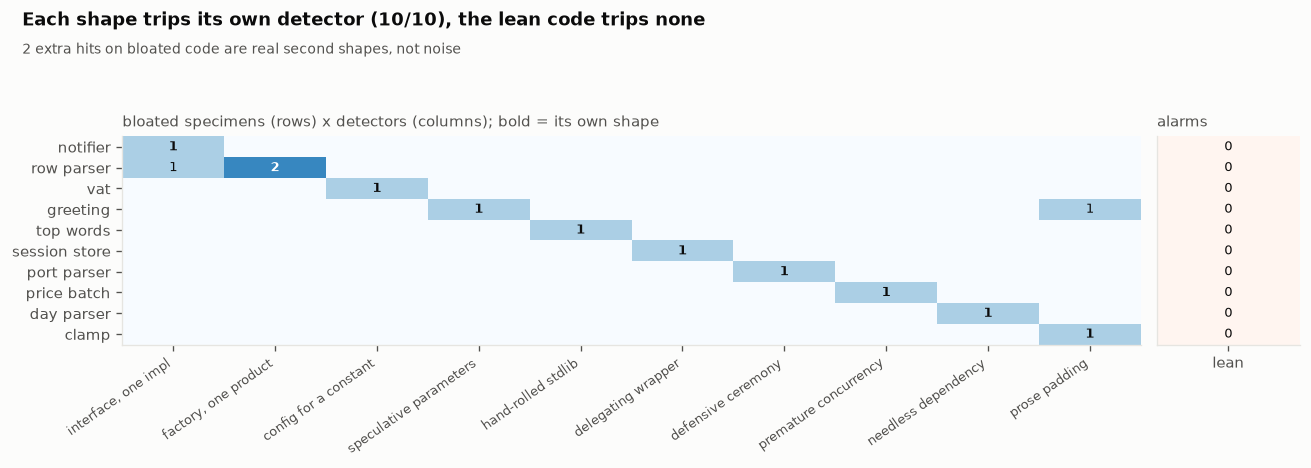

[fig 3] s3_detectors.png


In [118]:
# FIG  the detector matrix
# a wide panel for the matrix, a narrow one for the alarms on lean code
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0), gridspec_kw={"width_ratios": [10, 1.4]})
ax = axes[0]
# colours capped at 3, so one busy cell does not wash out the rest
ax.imshow(np.minimum(matrix_b, 3), cmap="Blues", vmin=0, vmax=3, aspect="auto")
for i in range(matrix_b.shape[0]):
    for j in range(matrix_b.shape[1]):
        if matrix_b[i, j]:                                         # empty cells stay unlabelled
            own = j == SPECIMENS[i]["shape"] - 1                   # the specimen's own shape is written in bold
            ax.text(j, i, matrix_b[i, j], ha="center", va="center", fontsize=8,
                    color="white" if matrix_b[i, j] >= 2 else INK, weight="bold" if own else "normal")
ax.set_xticks(range(10), [SHAPES[k] for k in range(1, 11)], rotation=35, ha="right", fontsize=7.5)   # detectors
ax.set_yticks(range(len(SPECIMENS)), [s["name"] for s in SPECIMENS])                                   # specimens
ax.grid(False)                                       # a grid would cut through the cells
panel(ax, "bloated specimens (rows) x detectors (columns); bold = its own shape")
ax2 = axes[1]
# one column: the number of alarms on each lean version, in red
ax2.imshow(matrix_l.sum(axis=1, keepdims=True), cmap="Reds", vmin=0, vmax=3, aspect="auto")
for i in range(len(SPECIMENS)):
    ax2.text(0, i, int(matrix_l[i].sum()), ha="center", va="center", fontsize=8)   # the count, zero included
ax2.set_xticks([0], ["lean"])
ax2.set_yticks([])                                   # the rows are already named on the left
ax2.grid(False)
panel(ax2, "alarms")
finish(fig, "s3_detectors", f"Each shape trips its own detector ({own_hits}/10), the lean code trips none",
       f"{cross} extra hits on bloated code are real second shapes, not noise")

**Reading FIG 3 (s3_detectors).** Rows are the bloated specimens, columns the ten detectors, and the bold number in each row sits on the specimen's own shape. The diagonal is complete, and the narrow column on the right (alarms on the lean versions) is empty, which is the property that makes these detectors safe to show to an agent. The off-diagonal hits are worth reading too: 2 of them, each a second real shape inside a specimen that was written to show one. Bloat travels in groups.

### S3b - The golf detector: short is not the goal

**Theory.** Any system that rewards fewer lines invites Goodhart's law: once a measure becomes a target, it stops measuring what it used to. The cheapest way to "write less code" is to stop writing readable code, joining statements with semicolons, assigning lambdas, nesting comprehensions and naming everything with one letter. That is not proportional code, it is the same complexity compressed into fewer, worse lines. This detector exists so that Part VII can show the full system shrinks code **without** golfing it, and so that a control arm told to "prefer one-liners" can be caught when it does.

**In plain terms.** If the code got shorter by becoming unreadable, we want to know.

**`golf_score(src)`** counts the signs of code made short rather than simple: statements joined with semicolons, lambdas assigned to names, walrus assignments, lines over 100 characters, one-letter names (apart from the usual `i`, `j`, `k`, `x`, `y`, `n` and `_`), comprehensions nested inside comprehensions, chained conditional expressions, list comprehensions run only for their side effects, and calls to `__import__`. Each sign has a weight, from one for a long line to three for a hidden `__import__`, the first one-letter name is free, and the score is the weighted sum. Readable code scores 0 or 1; code that does not parse gets no score at all.

In [119]:
def golf_score(src):
    """Signs that code was made short, not simple. Higher is worse; readable code scores 0 or 1."""
    try:
        tree = ast.parse(src)
        toks = list(tokenize.generate_tokens(io.StringIO(src).readline))
    except (SyntaxError, tokenize.TokenError, IndentationError):   # no tree, no score
        return {"score": None}
    nodes = list(ast.walk(tree))                     # every node once; each sign below filters this list
    comps = (ast.ListComp, ast.GeneratorExp, ast.SetComp, ast.DictComp)            # every kind of comprehension
    semis = sum(1 for t in toks if t.type == tokenize.OP and t.string == ";")       # a; b on one line
    # f = lambda ...: a function written as an assignment
    lambdas = sum(1 for n in nodes if isinstance(n, ast.Assign) and isinstance(n.value, ast.Lambda))
    walrus = sum(1 for n in nodes if isinstance(n, ast.NamedExpr))                   # (x := ...)
    long_lines = sum(1 for ln in src.splitlines() if len(ln) > 100)                  # too long to read at once
    # every name the code assigns, and every positional parameter
    names = {n.id for n in nodes if isinstance(n, ast.Name) and isinstance(n.ctx, ast.Store)}
    names |= {a.arg for n in nodes if isinstance(n, ast.arguments) for a in n.args}
    one_letter = sum(1 for n in names if len(n) == 1 and n not in "ijkxyn_")        # outside the usual few
    # a comprehension with another comprehension anywhere inside it
    nested = sum(1 for n in nodes if isinstance(n, comps)
                 and any(isinstance(m, comps) for m in ast.walk(n) if m is not n))
    # a if p else b if q else c
    chained = sum(1 for n in nodes if isinstance(n, ast.IfExp) and isinstance(n.orelse, ast.IfExp))
    # [print(x) for x in xs] written as a statement: a loop dressed up as a list
    side_effect_comp = sum(1 for n in nodes if isinstance(n, ast.Expr)
                           and isinstance(n.value, ast.ListComp))
    dunder_import = src.count("__import__(")                                         # an import hidden in an expression
    # every count by name, so a reader can see why a score is high
    parts = {"semicolons": semis, "lambdas": lambdas, "walrus": walrus, "long lines": long_lines,
             "one-letter names": one_letter, "nested comprehensions": nested, "chained ternaries": chained,
             "comprehension for side effects": side_effect_comp, "__import__": dunder_import}
    # the weighted sum; the first one-letter name is free
    parts["score"] = (2 * semis + 2 * lambdas + walrus + long_lines + max(0, one_letter - 1)
                      + nested + 2 * chained + 3 * side_effect_comp + 3 * dunder_import)
    return parts

show_def(golf_score)

[def] golf_score(src)  28 lines, complexity 21


In [120]:
squeezed = "def f(a):\n    [print(b) for b in a]; return 1\n"   # a semicolon, a list run for its prints, one-letter names
print(f"[golf_score] {dict((k, v) for k, v in golf_score(squeezed).items() if v)}")

[golf_score] {'semicolons': 1, 'one-letter names': 2, 'comprehension for side effects': 1, 'score': 6}


**`GOLFED`** holds four of the lean programs squeezed further, the way a model told to minimise lines might write them. Three of them still behave exactly like the lean version. One does not, and the comparison below catches it.

In [121]:
GOLFED = {
    "top words": "top_words=lambda t,n=3:__import__('collections').Counter(w for w in(x.strip('.,;:!?')for x in t.lower().split())if w).most_common(n)\n",
    "session store": "def run_session(o):\n s={};r=[];[s.__setitem__(k,v)if p=='set'else r.append(s.get(k))if p=='get'else s.pop(k,None)for p,k,v in o];return r\n",
    "port parser": "parse_port=lambda v:int(str(v).strip())\n",
    "vat": "gross=lambda n:round(n*1.2,2)\n",
}
print(f"[golf] {len(GOLFED)} golfed programs: {', '.join(GOLFED)}")

[golf] 4 golfed programs: top words, session store, port parser, vat


Each golfed program runs against the lean one on the specimen's inputs, and then all three versions are measured: code lines with the meter, readability with the golf score.

In [122]:
golf_rows = []                                                        # one row per golfed specimen
for s in SPECIMENS:
    if s["name"] not in GOLFED:                                       # only four specimens were golfed
        continue
    g = GOLFED[s["name"]]                                             # the golfed program text
    fl = load_fn(s["lean"], s["entry"])                               # the lean entry function
    fg = load_fn(g, s["entry"])                                       # and the golfed one
    same = all(outcome(fl, a) == outcome(fg, a) for a in s["calls"])  # does the golfed version still behave?
    # code lines of all three versions, the golf score of two, and the behaviour verdict
    golf_rows.append({"specimen": s["name"], "bloated": measure_source(s["bloated"])["code"],
                      "lean": measure_source(s["lean"])["code"], "golfed": measure_source(g)["code"],
                      "lean score": golf_score(s["lean"])["score"], "golfed score": golf_score(g)["score"],
                      "same": "PASSED" if same else "FAILED"})
table(golf_rows, [("specimen", "specimen", ""), ("bloated", "bloated", "d"), ("lean", "lean", "d"),
                  ("golfed", "golfed", "d"), ("lean score", "golf score lean", "d"),
                  ("golfed score", "golf score golfed", "d"), ("same", "same as lean", "")])

  specimen       bloated  lean  golfed  golf score lean  golf score golfed  same as lean
  --------------------------------------------------------------------------------------
  vat                 17     3       1                0                  2  PASSED
  top words           17     4       1                0                  8  PASSED
  session store       24    10       2                0                 16  PASSED
  port parser         16     5       1                0                  2  FAILED


In [123]:
broken = [r["specimen"] for r in golf_rows if r["same"] == "FAILED"]  # golfed programs that changed behaviour
print(f"\n  golfed versions that changed behaviour: {broken or 'none'}")
print("  -> the golfed port parser lost its negative-port check: shortening hid a dropped guard")
lean_total = sum(r["lean"] for r in golf_rows)                      # code lines of the four lean programs
golf_total = sum(r["golfed"] for r in golf_rows)                    # and of their golfed versions
save_exp("golf", {"rows": golf_rows, "broken": broken, "shorter_pct": 1 - golf_total / lean_total})


  golfed versions that changed behaviour: ['port parser']
  -> the golfed port parser lost its negative-port check: shortening hid a dropped guard
[exp] artifacts/exp_golf.json


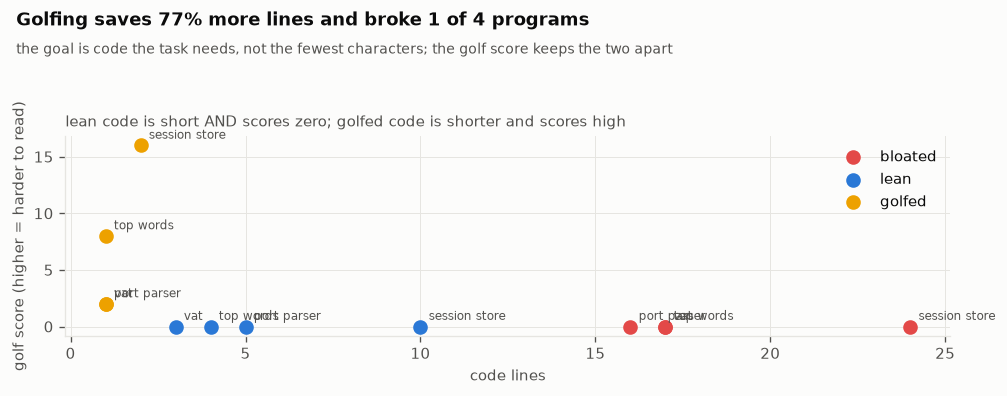

[fig 4] s3b_golf.png


In [124]:
# FIG  short versus simple
fig, ax = plt.subplots(figsize=(8.5, 3.4))
# one series per version: code lines across, golf score up
for key, colour, label in (("bloated", C8, "bloated"), ("lean", C1, "lean"), ("golfed", C4, "golfed")):
    xs = [r[key] for r in golf_rows]                                 # code lines of this version
    ys = []                                                          # and its golf score
    for r in golf_rows:
        if key != "golfed":
            # the bloated or lean program of this specimen, looked up by name
            version_src = next(s[key] for s in SPECIMENS if s["name"] == r["specimen"])
        else:
            version_src = GOLFED[r["specimen"]]
        ys.append(golf_score(version_src)["score"])
    ax.scatter(xs, ys, s=60, color=colour, label=label, zorder=3)     # drawn above the grid
    for x, y_, r in zip(xs, ys, golf_rows):                          # each point labelled with its specimen
        ax.annotate(r["specimen"], (x, y_), textcoords="offset points", xytext=(5, 4), fontsize=7, color=INK2)
ax.set_xlabel("code lines")
ax.set_ylabel("golf score (higher = harder to read)")
ax.legend(loc="upper right")
panel(ax, "lean code is short AND scores zero; golfed code is shorter and scores high")
finish(fig, "s3b_golf", f"Golfing saves {1 - golf_total / lean_total:.0%} more lines and broke {len(broken)} of {len(golf_rows)} programs",
       "the goal is code the task needs, not the fewest characters; the golf score keeps the two apart")

**Reading FIG 4 (s3b_golf).** Lean code (blue) sits low on both axes: short and readable. Golfed code (yellow) is shorter still and sits high on the golf score, and one of the four golfed programs quietly lost the check that rejects a negative port. That is the failure this detector is here to catch: when a model is pushed towards fewer lines without a counterweight, the lines it removes first are often the ones that guard against bad input.

### S3c - Guard signatures: what must never be cut

**Theory.** The system's central promise is asymmetric: cut structure freely, never cut a guard. To hold an agent to that, a guard has to be recognisable in code. Most guards have a signature: a containment check before using a user-supplied path (`commonpath`, `is_relative_to`), a placeholder in an SQL statement with the value passed separately, a constant-time comparison for a signature (`hmac.compare_digest`), escaping before text becomes HTML, a type check on parsed JSON, a `try` around a single row so one bad row cannot lose the whole file, a refusal of newline characters in anything that becomes a header. The detector below counts them. It is used twice later: the critic's trim guard (S50) refuses any deletion that lowers the count, and the controls in S65 compare the counts between arms.

**In plain terms.** We teach the system to recognise the lines that protect the program, so it can be stopped from deleting them.

**`GUARD_PATTERNS`** is the table of textual guard signatures, one regular expression per kind of guard. They are loose on purpose. A detector that misses a guard lets a trim delete it; one that sees a guard where there is none only keeps a line that could have gone, which is the cheaper mistake.

In [125]:
GUARD_PATTERNS = {
    # a user-supplied path checked to stay inside its folder
    "path containment":     r"commonpath|is_relative_to|relative_to\(|realpath\(.*startswith",
    # SQL with a placeholder (?, %s or :name) and the values passed separately
    "placeholder query":    r"execute\(\s*[\"'][^\"']*(\?|%s|:\w+)[^\"']*[\"']\s*,",
    "constant-time compare": r"compare_digest",                       # hmac's comparison for secrets
    "html escaping":        r"html\.escape|escape\(",
    # parsed input checked for the type the code expects
    "type check on input":  r"isinstance\(\s*\w+\s*,\s*\(?\s*(dict|list|str|int|float|bool)",
    "explicit rejection":   r"raise\s+(ValueError|PermissionError|TypeError|KeyError|LookupError)",
    # a carriage return or line feed refused before text goes into a header
    "newline rejection":    r"\\r|\\n\"?\s*in\s|splitlines\(\)\s*!=|\[\\r\\n\]",
    "anchored match":       r"fullmatch\(|\\Z",                        # a pattern that must match the whole input
    # a timestamp compared with an expiry, or with the clock
    "expiry check":         r"(expires?|expiry|exp)\w*\s*[<>]=?|time\.time\(\)\s*[<>]",
    "alt text":             r"\balt\s*=",                              # an image described for readers who cannot see it
}
print(f"[guards] {len(GUARD_PATTERNS)} textual signatures, plus one read from the syntax tree")

[guards] 10 textual signatures, plus one read from the syntax tree


**`guard_signatures(src)`** counts the guards in a program: each textual signature, plus one structural signature read from the syntax tree, a `try` inside a loop, which is how one bad row is kept from losing a whole file. A `try` under two nested loops counts once for each loop. Only the kinds actually found are returned, so an empty dict means no guard was recognised.

In [126]:
def guard_signatures(src):
    """Count recognisable guards. Per-row error handling (a try inside a loop) is read
    from the syntax tree; the rest are textual signatures."""
    found = Counter()                                      # kind of guard, then how many times it appears
    for name, p in GUARD_PATTERNS.items():
        found[name] = len(re.findall(p, src))              # every match anywhere in the source
    try:
        tree = ast.parse(src)
        per_row = 0                                        # try statements inside loops
        for loop in ast.walk(tree):
            if isinstance(loop, (ast.For, ast.While)):
                # every try anywhere under this loop; a loop inside a loop counts it again
                per_row += sum(1 for n in ast.walk(loop) if isinstance(n, ast.Try))
        found["per-row error handling"] = per_row          # zero is dropped below, like any other kind
    except SyntaxError:
        pass                                               # unparseable: the textual signatures still stand
    return {k: v for k, v in found.items() if v}           # only the kinds actually present

show_def(guard_signatures)

[def] guard_signatures(src)  16 lines, complexity 7


**`GUARD_PAIRS`** holds five small functions written twice: once with the guard a careful reviewer would insist on, once without it. Each lazy version is shorter, works on friendly input and fails on hostile input. The detector has to tell every pair apart.

**Path join.** The safe version resolves both paths and refuses a name that climbs out of the upload folder, such as `../../etc/passwd`. The lazy one joins whatever it is given.

In [127]:
GUARD_PAIRS = {}   # pair name, then (safe version, lazy version)
GUARD_PAIRS["path join"] = ("""
import os
def upload_path(base, name):
    base = os.path.abspath(base)
    target = os.path.abspath(os.path.join(base, name))
    if os.path.commonpath([base, target]) != base:
        raise ValueError("outside the upload folder")
    return target
""", """
import os
def upload_path(base, name):
    return os.path.join(base, name)
""")
safe, lazy = GUARD_PAIRS["path join"]                  # the two versions, counted separately
print(f"  safe: {guard_signatures(safe)}\n  lazy: {guard_signatures(lazy)}")

  safe: {'path containment': 1, 'explicit rejection': 1}
  lazy: {}


**SQL lookup.** The safe version passes the name as a parameter, so the database never reads it as SQL. The lazy one pastes it into the statement, where a name such as `x' OR '1'='1` changes what the query does.

In [128]:
GUARD_PAIRS["sql lookup"] = ("""
def find(conn, name):
    return conn.execute("SELECT * FROM users WHERE name = ?", (name,)).fetchone()
""", """
def find(conn, name):
    return conn.execute(f"SELECT * FROM users WHERE name = '{name}'").fetchone()
""")
safe, lazy = GUARD_PAIRS["sql lookup"]                  # the two versions, counted separately
print(f"  safe: {guard_signatures(safe)}\n  lazy: {guard_signatures(lazy)}")

  safe: {'placeholder query': 1}
  lazy: {}


**Token check.** The safe version recomputes the token's signature with the secret and compares the two in constant time, so the time the comparison takes reveals nothing about the right answer. The lazy one returns whatever user id comes before the dot, signed or not.

In [129]:
GUARD_PAIRS["token check"] = ("""
import hmac, hashlib
def verify(token, secret):
    uid, _, sig = token.rpartition(".")
    good = hmac.new(secret.encode(), uid.encode(), hashlib.sha256).hexdigest()
    return uid if hmac.compare_digest(sig, good) else None
""", """
def verify(token, secret):
    return token.split(".")[0]
""")
safe, lazy = GUARD_PAIRS["token check"]                  # the two versions, counted separately
print(f"  safe: {guard_signatures(safe)}\n  lazy: {guard_signatures(lazy)}")

  safe: {'constant-time compare': 1}
  lazy: {}


**CSV total.** The safe version skips a row it cannot read and carries on adding up the rest. The lazy one is a single `sum`, so one blank or malformed amount loses the whole file to an exception.

In [130]:
GUARD_PAIRS["csv total"] = ("""
import csv
def total(path):
    out = 0.0
    with open(path, newline="") as f:
        for row in csv.DictReader(f):
            try:
                out += float(row["amount"])
            except (ValueError, KeyError):
                continue
    return out
""", """
import csv
def total(path):
    with open(path, newline="") as f:
        return sum(float(r["amount"]) for r in csv.DictReader(f))
""")
safe, lazy = GUARD_PAIRS["csv total"]                  # the two versions, counted separately
print(f"  safe: {guard_signatures(safe)}\n  lazy: {guard_signatures(lazy)}")

  safe: {'per-row error handling': 1}
  lazy: {}


**Caption into HTML.** The safe version escapes both values before they become markup and gives the image its alt text. The lazy one inserts them raw, so a caption that contains a `<script>` tag runs as a script.

In [131]:
GUARD_PAIRS["caption html"] = ("""
import html
def figure(src, caption):
    return f'<img src="{html.escape(src)}" alt="{html.escape(caption)}"><p>{html.escape(caption)}</p>'
""", """
def figure(src, caption):
    return f'<img src="{src}"><p>{caption}</p>'
""")
safe, lazy = GUARD_PAIRS["caption html"]                  # the two versions, counted separately
print(f"  safe: {guard_signatures(safe)}\n  lazy: {guard_signatures(lazy)}")

  safe: {'html escaping': 3, 'alt text': 1}
  lazy: {}


The five pairs side by side: code lines and guards for each version, and what the safe version guards with.

In [132]:
rows = []                                            # one row per pair
for name, (safe, lazy) in GUARD_PAIRS.items():
    gs = guard_signatures(safe)                      # guards found in the safe version
    gl = guard_signatures(lazy)                      # and in the lazy one
    # guards and code lines of both versions, and the kinds of guard the safe one uses
    rows.append({"pair": name, "safe": sum(gs.values()), "lazy": sum(gl.values()),
                 "lines safe": measure_source(safe)["code"], "lines lazy": measure_source(lazy)["code"],
                 "guards": ", ".join(sorted(gs)) or "-"})
table(rows, [("pair", "pair", ""), ("lines safe", "lines safe", "d"), ("lines lazy", "lines lazy", "d"),
             ("safe", "guards safe", "d"), ("lazy", "guards lazy", "d"), ("guards", "what the safe version guards with", "")])
missed = [r["pair"] for r in rows if r["safe"] <= r["lazy"]]   # pairs the detector could not tell apart
print(f"\n  pairs where the safe version did NOT show more guards: {missed or 'none'}")
print(f"  the safe versions are {sum(r['lines safe'] for r in rows) - sum(r['lines lazy'] for r in rows)} lines longer in total:")
print("  -> those lines are exactly the ones a size-only objective would delete first")
save_exp("guards", {"rows": rows, "missed": missed})

  pair          lines safe  lines lazy  guards safe  guards lazy  what the safe version guards with
  ----------------------------------------------------------------------------------------------------
  path join              7           3            2            0  explicit rejection, path containment
  sql lookup             2           2            1            0  placeholder query
  token check            5           2            1            0  constant-time compare
  csv total             10           4            1            0  per-row error handling
  caption html           3           2            4            0  alt text, html escaping

  pairs where the safe version did NOT show more guards: none
  the safe versions are 14 lines longer in total:
  -> those lines are exactly the ones a size-only objective would delete first
[exp] artifacts/exp_guards.json


The extra lines in the safe versions are small (one to four per function) and they are what a pure size objective removes first. That is the asymmetry the system has to respect, and the reason guard signatures exist as a separate instrument rather than as a judgement left to the model.

### S3d - A replacement table that tests itself

**Theory.** The cheapest rungs of the ladder (the standard library, the platform) only help if the agent knows what is there, and a table of "instead of X, use Y" is the usual way to teach it. Such tables are easy to write and easy to get wrong: "use the dict union operator to merge configs" is right for flat dicts and silently wrong for nested ones; "use `email.utils.parseaddr` to validate an address" confuses a parser with a validator. A replacement that is wrong is worse than none, because an agent that trusts it will ship the bug with confidence. So every row below carries a test that runs the claim, and two rows are deliberately wrong to show the tests catching them.

**In plain terms.** A cheat sheet of "the standard library already does this", where every line is checked by running it.

The rows test their claims against these modules, all from the standard library. `hmac` and `html` come in under the private names `_hmac` and `_html`, so Part I does not take the plain names.

In [133]:
import collections            # the counting row
import copy                   # deepcopy
import functools              # cache
import itertools              # batched, new in Python 3.12
import decimal                # Decimal, for money
import zoneinfo               # time zones with their daylight-saving rules
import datetime as dt         # dates and times, under a short name
import ipaddress              # strict IPv4 parsing
import hmac as _hmac          # compare_digest
import html as _html          # escape
import sqlite3                # an in-memory database for the UNIQUE row
import email.utils            # parseaddr, for a row planted wrong

print(f"[replacements] python {sys.version_info.major}.{sys.version_info.minor}; "
      f"itertools.batched {'available' if hasattr(itertools, 'batched') else 'missing'}")

[replacements] python 3.12; itertools.batched available


**`replacement(need, instead, use, holds_when, claim_ok=True)`** registers one row of the table, and is used as a decorator: the function under it is the row's test, which runs the claim and returns `(passed, evidence)`. `holds_when` states the condition the advice depends on, because most replacements are right only within limits. `claim_ok=False` marks the two rows planted wrong, so the table can check that the tests caught exactly those. Every test is named `_`: the row is what matters, and the name is never used.

In [134]:
REPLACEMENTS = []   # every row, in the order registered

def replacement(need, instead, use, holds_when, claim_ok=True):
    """Register a row; the decorated function is its test and returns (passed, evidence)."""
    def wrap(test):                    # receives the test function written under the decorator
        # the claim, the condition it depends on, and the test that checks it
        REPLACEMENTS.append({"need": need, "instead": instead, "use": use, "holds_when": holds_when,
                             "claim_ok": claim_ok, "test": test})
        return test
    return wrap

show_def(replacement)

[def] replacement(need, instead, use, holds_when, claim_ok=True)  7 lines, complexity 1


**`collections.Counter`** instead of a dict and a loop, whenever the job is counting. `most_common` does the ranking as well. The test counts six words and checks the winner.

In [135]:
@replacement("count things", "a dict and a loop", "collections.Counter", "always")
def _():
    words = "a b a c b a".split()                        # a three times, b twice, c once
    return Counter(words).most_common(1) == [("a", 3)], "most_common(1) == [('a', 3)]"   # the claim, then the evidence

print(f"  row {len(REPLACEMENTS)}: {REPLACEMENTS[-1]['need']}")

  row 1: count things


**`list(dict.fromkeys(xs))`** instead of a loop with a set of seen items, to drop duplicates and keep the order. A dict keeps its keys in insertion order, so each item comes out where it first appeared; the items must be hashable, because they become keys.

In [136]:
@replacement("dedupe, keep order", "a seen-set loop", "list(dict.fromkeys(xs))", "items are hashable")
def _():
    # duplicates dropped, first appearances kept in order
    return list(dict.fromkeys([3, 1, 3, 2, 1])) == [3, 1, 2], "[3,1,3,2,1] -> [3,1,2]"

print(f"  row {len(REPLACEMENTS)}: {REPLACEMENTS[-1]['need']}")

  row 2: dedupe, keep order


**`s.casefold()`** instead of `s.lower()`, to compare text regardless of case. `lower()` leaves the German ß as it is, so "Straße" and "STRASSE" do not match; `casefold()` turns ß into ss and they do. Lower case is still right for display, which is why the row says matching only.

In [137]:
@replacement("case-insensitive match", "s.lower()", "s.casefold()", "matching, not display")
def _():
    # casefold matches the two spellings, lower does not
    return ("Straße".casefold() == "STRASSE".casefold() and "Straße".lower() != "STRASSE".lower(),
            "casefold matches Strasse; lower does not")

print(f"  row {len(REPLACEMENTS)}: {REPLACEMENTS[-1]['need']}")

  row 3: case-insensitive match


**`functools.cache`** instead of a cache class written by hand, to remember the results of a pure function. The arguments must be hashable, since they become the cache's keys. The test calls the function twice with the same argument and checks that its body ran once.

In [138]:
@replacement("memoise a pure function", "a cache class", "functools.cache", "arguments are hashable")
def _():
    calls = []                       # one entry per time the body really runs
    @functools.cache                 # remembers sq(n) for every n it has seen
    def sq(n):
        calls.append(n)
        return n * n
    sq(4)
    sq(4)                            # the second call is answered from the cache
    return calls == [4], "body ran once for two calls"

print(f"  row {len(REPLACEMENTS)}: {REPLACEMENTS[-1]['need']}")

  row 4: memoise a pure function


**`decimal.Decimal`** instead of `float`, for money. In binary floating point 0.1 + 0.2 is not 0.3, and the difference surfaces in totals and comparisons; a `Decimal` built from strings does exact decimal arithmetic.

In [139]:
@replacement("money arithmetic", "float", "decimal.Decimal", "values are money")
def _():
    # exact with Decimal built from strings, off by a tiny amount with floats
    return (decimal.Decimal("0.1") + decimal.Decimal("0.2") == decimal.Decimal("0.3") and 0.1 + 0.2 != 0.3,
            "Decimal: 0.1 + 0.2 == 0.3; float: it does not")

print(f"  row {len(REPLACEMENTS)}: {REPLACEMENTS[-1]['need']}")

  row 5: money arithmetic


**`zoneinfo.ZoneInfo`** instead of a fixed offset from UTC, for local time in a zone with daylight saving. London's clocks go forward at 01:00 UTC on 29 March 2026, so 00:30 UTC is 00:30 GMT and an hour later it is 02:30 BST. A fixed offset gets one of the two wrong.

In [140]:
@replacement("local time across DST", "a fixed UTC offset", "zoneinfo.ZoneInfo", "the zone has DST rules")
def _():
    z = zoneinfo.ZoneInfo("Europe/London")                                       # GMT in winter, BST in summer
    a = dt.datetime(2026, 3, 29, 0, 30, tzinfo=dt.timezone.utc).astimezone(z)   # half an hour before the change
    b = dt.datetime(2026, 3, 29, 1, 30, tzinfo=dt.timezone.utc).astimezone(z)   # half an hour after it
    # an hour of UTC apart, two hours apart on the London clock
    return (a.hour, b.hour) == (0, 2), f"00:30 UTC -> {a:%H:%M %Z}, 01:30 UTC -> {b:%H:%M %Z}"

print(f"  row {len(REPLACEMENTS)}: {REPLACEMENTS[-1]['need']}")

  row 6: local time across DST


**`date.fromisoformat`** instead of a date library, when the input is ISO 8601. This is the day parser specimen turned into advice: Python has read `YYYY-MM-DD` on its own since version 3.7.

In [141]:
@replacement("parse ISO dates", "a date library", "date.fromisoformat", "input is ISO 8601")
def _():
    return dt.date.fromisoformat("2026-03-07") == dt.date(2026, 3, 7), "2026-03-07 parsed"   # year, month, day

print(f"  row {len(REPLACEMENTS)}: {REPLACEMENTS[-1]['need']}")

  row 7: parse ISO dates


**`copy.deepcopy`** instead of a recursive copy helper. The test changes a value two levels down in the copy and checks that the original did not change with it.

In [142]:
@replacement("deep copy", "a recursive copy helper", "copy.deepcopy", "objects are copyable")
def _():
    a = {"x": [1, {"y": 2}]}         # a dict inside a list inside a dict
    b = copy.deepcopy(a)             # copies every level, not just the outer dict
    b["x"][1]["y"] = 9               # change the copy, two levels down
    return a["x"][1]["y"] == 2, "nested change did not leak back"   # the original still holds 2

print(f"  row {len(REPLACEMENTS)}: {REPLACEMENTS[-1]['need']}")

  row 8: deep copy


**`hmac.compare_digest`** instead of `==`, when comparing secrets. `==` stops at the first difference, so the time it takes hints at how much of a guess was right; `compare_digest` takes a time that does not depend on where the inputs differ.

In [143]:
@replacement("constant-time compare", "==", "hmac.compare_digest", "comparing secrets")
def _():
    # right on an equal pair and on an unequal one
    return _hmac.compare_digest("abc", "abc") and not _hmac.compare_digest("abc", "abd"), "equal and unequal"

print(f"  row {len(REPLACEMENTS)}: {REPLACEMENTS[-1]['need']}")

  row 9: constant-time compare


**`html.escape`** instead of a chain of `replace()` calls, for text that goes into HTML. It escapes `&`, `<`, `>` and both kinds of quote, and it handles the ampersand first, which is the step a hand-written chain most easily gets in the wrong order.

In [144]:
@replacement("escape for HTML", "manual replace() calls", "html.escape", "text goes into HTML")
def _():
    # angle brackets and double quotes all become entities
    return _html.escape('<b x="1">') == "&lt;b x=&quot;1&quot;&gt;", "tags and quotes escaped"

print(f"  row {len(REPLACEMENTS)}: {REPLACEMENTS[-1]['need']}")

  row 10: escape for HTML


**`ipaddress.IPv4Address`** instead of a regular expression, to validate an IPv4 address. It is strict: it refuses an octet above 255, a leading zero (which some parsers read as octal) and a trailing newline, all of which a quick regex tends to let through. The test uses `_ok`, defined after the last row, to turn a refusal into `False`; Python looks the name up only when the test runs.

In [145]:
@replacement("validate an IPv4 address", "a regex", "ipaddress.IPv4Address", "IPv4 only, strictly")
def _():
    def ok(s):
        return _ok(lambda: ipaddress.IPv4Address(s))     # True when the text parses as an address
    # one good address, then three that a loose pattern would accept
    return (ok("10.0.0.1") and not ok("256.1.1.1") and not ok("01.2.3.4") and not ok("1.2.3.4\n"),
            "rejects 256.x, leading zeros and a trailing newline")

print(f"  row {len(REPLACEMENTS)}: {REPLACEMENTS[-1]['need']}")

  row 11: validate an IPv4 address


**`itertools.batched`** instead of the `zip(*[iter(xs)] * n)` idiom, to split a sequence into batches. The idiom silently drops a short last batch, and `batched` keeps it. It needs Python 3.12, which is the condition this row states.

In [146]:
@replacement("split into batches", "zip(*[iter(xs)] * n)", "itertools.batched", "the project targets Python 3.12+")
def _():
    # seven items in threes: two full batches and a last one of a single item
    return list(itertools.batched(range(7), 3)) == [(0, 1, 2), (3, 4, 5), (6,)], "7 items -> 3 batches, remainder kept"

print(f"  row {len(REPLACEMENTS)}: {REPLACEMENTS[-1]['need']}")

  row 12: split into batches


**A `UNIQUE` constraint** instead of a `SELECT` before every `INSERT`, when the data lives in a database. Checking first and then inserting can race with another writer; the constraint cannot, because the database enforces it. The test's column also ignores case, so `a@x.org` is refused as a duplicate of `A@x.org`.

In [147]:
@replacement("unique rows in a table", "SELECT, then INSERT", "a UNIQUE constraint", "the data lives in a database")
def _():
    db = sqlite3.connect(":memory:")                     # a database that lives only for this test
    db.execute("create table m(email text unique collate nocase)")   # unique, ignoring case
    db.execute("insert into m values ('A@x.org')")                     # the first address goes in
    # the same address in lower case must be refused
    return not _ok(lambda: db.execute("insert into m values ('a@x.org')")), "the database refused the duplicate"

print(f"  row {len(REPLACEMENTS)}: {REPLACEMENTS[-1]['need']}")

  row 13: unique rows in a table

**`a | b`** to merge nested configuration: planted wrong. The union operator is shallow. Merging a configuration whose `db` section has a host and a port with one that changes only the port replaces the whole `db` section, and the host is lost.

In [148]:
@replacement("merge nested config", "a deep-merge helper", "a | b", "-", claim_ok=False)
def _():
    a, b = {"db": {"host": "h", "port": 1}}, {"db": {"port": 2}}   # b only means to change the port
    # the claim holds only if the host survives the merge
    return (a | b)["db"].get("host") == "h", f"a | b -> {a | b}  (host lost: | is shallow)"

print(f"  row {len(REPLACEMENTS)}: {REPLACEMENTS[-1]['need']}")

  row 14: merge nested config


**`email.utils.parseaddr`** to validate an email address: planted wrong. `parseaddr` splits an address header into a name and an address. It is a parser, not a validator, and it hands back `@missing-local.com` without complaint.

In [149]:
@replacement("validate an email address", "a regex", "email.utils.parseaddr", "-", claim_ok=False)
def _():
    name, addr = email.utils.parseaddr("@missing-local.com")   # no local part before the @
    # a validator would refuse this and give back no address at all
    return addr == "", f"parseaddr('@missing-local.com') -> {addr!r}: a parser, not a validator"

print(f"  row {len(REPLACEMENTS)}: {REPLACEMENTS[-1]['need']}")

  row 15: validate an email address


**`_ok(fn)`** calls `fn` and says whether it finished without raising. Two of the rows above use it to turn "the parser refused this" into a plain `False`.

In [150]:
def _ok(fn):
    try:
        fn()                             # run it; an exception lands below
        return True
    except Exception:                    # any exception counts as a refusal
        return False

show_def(_ok)

[def] _ok(fn)  6 lines, complexity 2


In [151]:
print(f"[replacements] {len(REPLACEMENTS)} rows, each with its own test")
print(f"  _ok on int('42'): {_ok(lambda: int('42'))}; on int('forty-two'): {_ok(lambda: int('forty-two'))}")

[replacements] 15 rows, each with its own test
  _ok on int('42'): True; on int('forty-two'): False


Every row's test now runs. A row passes when its claim holds; a row whose claim fails is marked WRONG, and the only WRONG rows allowed are the two planted ones.

In [152]:
rows = []                                            # one row per replacement, for the table and the record
for r in REPLACEMENTS:
    passed, evidence = r["test"]()                   # run the claim; evidence says what was observed
    status = "PASSED" if passed else "WRONG"         # a claim that fails its own test is wrong advice
    rows.append({"need": r["need"], "use": r["use"], "holds when": r["holds_when"],
                 "test": status, "evidence": evidence})
table(rows, [("need", "need", ""), ("use", "use", ""), ("holds when", "holds when", ""), ("test", "test", ""),
             ("evidence", "evidence", "")])

  need                       use                      holds when                        test    evidence


  --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
  count things               collections.Counter      always                            PASSED  most_common(1) == [('a', 3)]
  dedupe, keep order         list(dict.fromkeys(xs))  items are hashable                PASSED  [3,1,3,2,1] -> [3,1,2]
  case-insensitive match     s.casefold()             matching, not display             PASSED  casefold matches Strasse; lower does not
  memoise a pure function    functools.cache          arguments are hashable            PASSED  body ran once for two calls
  money arithmetic           decimal.Decimal          values are money                  PASSED  Decimal: 0.1 + 0.2 == 0.3; float: it does not
  local time across DST      zoneinfo.ZoneInfo        the zone has DST rules            PASSED  00:30 UTC -> 00:30 GMT, 01:30 UTC -> 02:30 BST
  parse ISO dates            d

In [153]:
wrong = [r for r in rows if r["test"] == "WRONG"]                               # the rows whose test failed
expected_wrong = [r["need"] for r in REPLACEMENTS if not r["claim_ok"]]          # the two planted rows
print(f"\n  {len(rows) - len(wrong)} rows PASSED, {len(wrong)} rows WRONG: {[r['need'] for r in wrong]}")
# the failures must be exactly the planted rows: no more, and no fewer
assert sorted(r["need"] for r in wrong) == sorted(expected_wrong), "a row we trusted failed its test"
print("  -> the two wrong rows were planted; the tests caught both. An untested table would have")
print("     shipped them as advice. Only PASSED rows are offered to the agent (S48).")
SAFE_REPLACEMENTS = [r for r, row in zip(REPLACEMENTS, rows) if row["test"] == "PASSED"]   # the rows S48 may offer
save_exp("replacements", {"rows": rows, "passed": len(rows) - len(wrong), "wrong": len(wrong)})


  13 rows PASSED, 2 rows WRONG: ['merge nested config', 'validate an email address']
  -> the two wrong rows were planted; the tests caught both. An untested table would have
     shipped them as advice. Only PASSED rows are offered to the agent (S48).


[exp] artifacts/exp_replacements.json


**Part I recap.** Every instrument the rest of the notebook depends on now exists and has passed tests built to fool it. The bloat meter counts added code without being inflated by comments, docstrings or the one self-check we will ask for. Ten detectors each recognise one shape of over-engineering and never fire on the lean versions. The golf detector separates short code from unreadable code, the guard detector recognises the lines that must survive any trim, and the replacement table refuses to keep a row whose test fails.

**Try it yourself.**
1. Add an eleventh specimen pair to S1 (a class with a single static method is a good one), re-run S1 to S3, and see whether any detector notices it. If none does, write the detector.
2. In S3d, change the `"validate an IPv4 address"` test to accept `"01.2.3.4"`. Watch the row fail, then decide whether strict parsing really is what a ticket needs.
3. Golf the `clamp` specimen and feed it to `golf_score`. How short can you make it before the score passes 4?

# Part II - Tasks that can say no

A benchmark only teaches you something if it can fail the thing you hope will pass.

**Where this sits.** Part I built instruments that measure code. This Part gives them something to measure: 34 small programming tasks, each built around one trap, and the machinery to run code we did not write without letting it touch anything else. Every result in Parts VII and VIII is a score produced by the code in this Part, so this is where the notebook shows that a score means what it says: the reference answers that should fail do fail, the ones that should pass do pass, the hidden tests notice small planted bugs, and nothing the agent writes can read the hidden tests, the API key or the rest of the project. No model is called here either.

**By the end of this Part you can** read a task folder and name its trap, run untrusted code inside a fence and explain each of its rules, score a workspace and read every field of the record, check that a suite is fit to spend money on before spending it, measure how strong a hidden test is by planting bugs in correct code, and explain why a gate that looks for the right keywords is worse than it sounds.

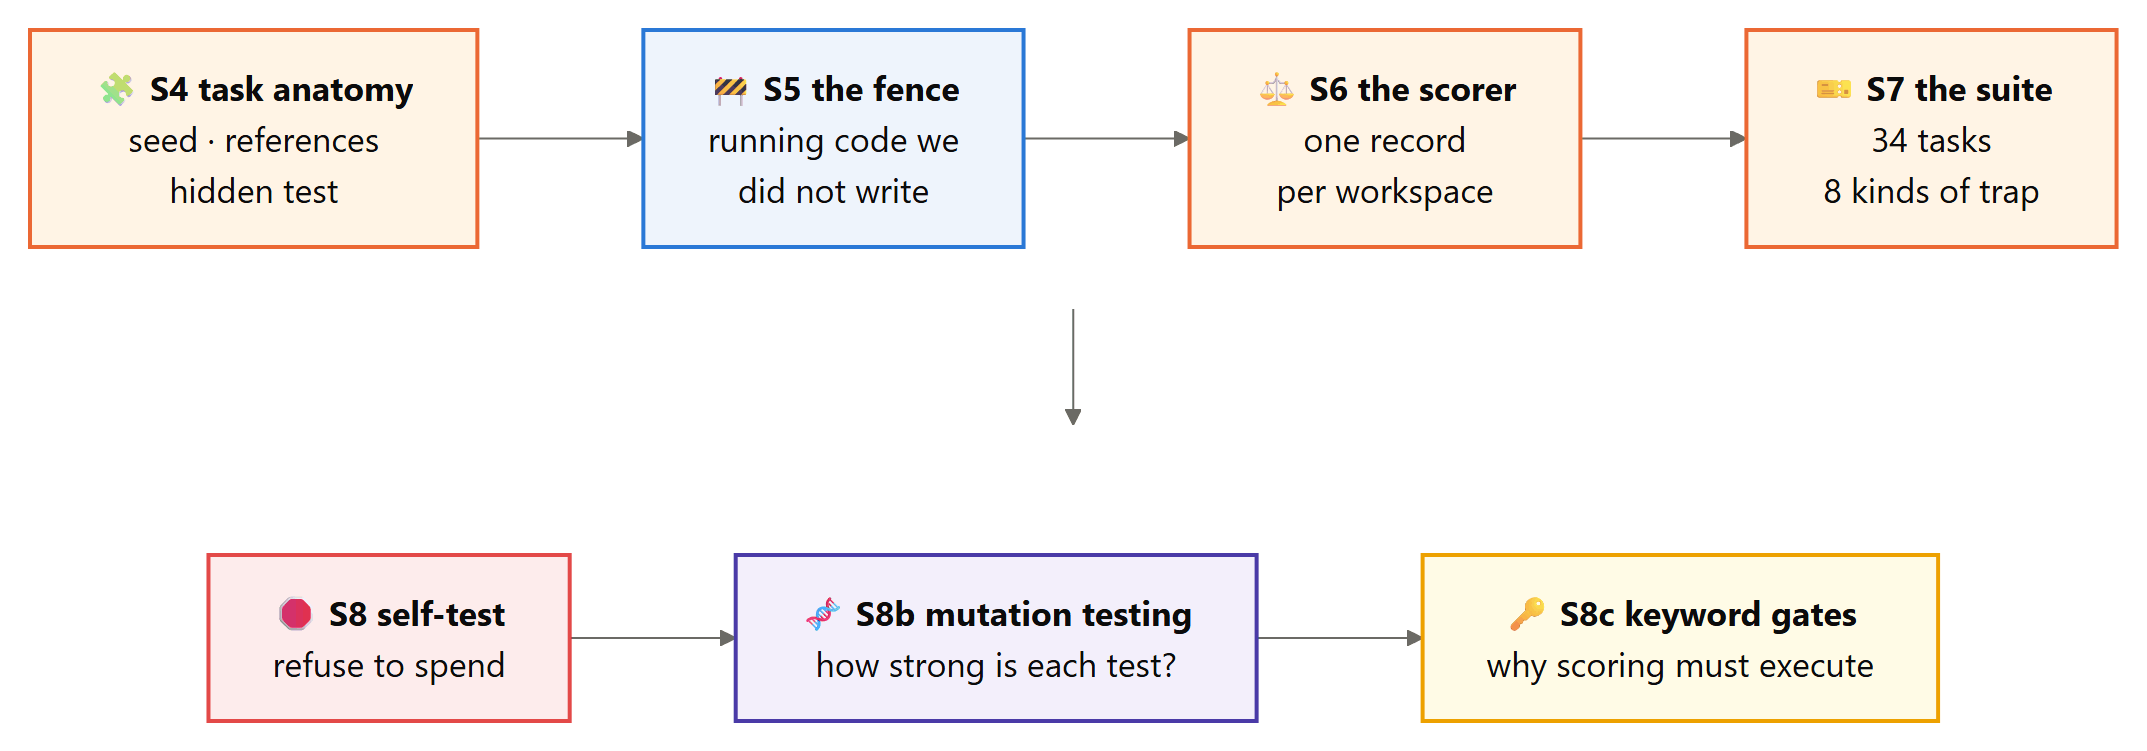

## S4 - Anatomy of a task

**Theory.** A task is a small, frozen experiment. It has a **seed**: a little project the agent starts from, including files that have nothing to do with the ticket, because real code bases look like that. It has a **prompt**, written the way a colleague writes a ticket, which means the requirement that matters most is often not in it. It has a **hidden test** the agent never sees, which ends by printing one line of JSON with up to three verdicts: `correct` (does it do what was asked), `safe` (does it keep the guard nobody mentioned) and `quality` (does it avoid the specific trap the task was built around). And it has three **reference answers**, each laid over the seed: `good` (what the task needs), `lazy` (small and wrong on the trap) and `bloated` (correct, with several times the code). The references are how we know a hidden test works. If the lazy answer passes, or the bloated one fails, the test is measuring something other than what we think it measures.

**In plain terms.** Each task is a tiny project, a ticket, a secret exam and three model answers: one right, one sloppy, one overdone.

```text
tasks/sf-share-link/
  task.json            id, category, split, axis, prompt, notes, a follow-up ticket
  seed/                the project the agent starts from
    sharing/links.py       make_link() works; open_link() is the ticket
    sharing/emails.py      unrelated, as real code bases are
    tests_visible.py       a smoke test the agent can see and run
  refs/good/           overlays on the seed: the answer the task needs
  refs/lazy/           small and wrong on the trap (here: it ignores expiry)
  refs/bloated/        correct, with a codec, a signer and a service class
  hidden_test.py       run after the agent finishes; never visible to it
```

Two fields decide how a task is used later. `split` is `dev` (9 tasks we were allowed to look at while building the system) or `held-out` (25 we were not); the headline claims in Part VII are made on held-out tasks only. `axis` names the verdict the trap sits on, so the self-test in S8 knows exactly what the lazy reference has to fail.

In [154]:
# ---- a task, as loaded from its folder -------------------------------------------
from dataclasses import dataclass, field, asdict

TASKS_DIR = ROOT / "tasks"                         # one folder per task, plus _kit/ with the shared test helpers
KIT_PATH = TASKS_DIR / "_kit" / "_hidden_kit.py"   # copied next to every hidden test when it runs
WS_DIR = RUNTIME / "ws"                            # workspaces are built here, never inside tasks/

print(f"[tasks] {rel(TASKS_DIR)}/ has {sum((d / 'task.json').is_file() for d in TASKS_DIR.iterdir())} task folders; "
      f"workspaces go under {rel(WS_DIR)}/")

[tasks] tasks/ has 34 task folders; workspaces go under .runtime/ws/


**`Task`** is one task as the rest of the notebook sees it: the ticket and its metadata from `task.json`, plus every file of the seed, read into memory as text. It is a frozen dataclass because a task is ground truth, and nothing downstream should be able to change one by accident. The comment beside each field says what reads it. `seed_py` narrows the seed to its Python files, the only ones the meter counts.

In [155]:
@dataclass(frozen=True)
class Task:
    id: str                # the folder name; load_task refuses a task where the two differ
    title: str             # a short name for tables
    category: str          # over-build, reuse, root-cause, safety, control, explicit, open, edge
    split: str             # dev or held-out
    axis: str              # the verdict the trap sits on: correct, safe or quality
    rung: int              # the lowest rung of the ladder that solves it (Part IV)
    entry: str             # the file the ticket is about
    prompt: str            # the ticket, word for word as the agent reads it
    notes: str             # for us; never shown to the agent
    extension: str         # a follow-up ticket, used in Part VII
    python_target: str     # the Python the project runs on: 3.12, except one edge task on 3.9
    requirements: tuple = ()   # packages beyond the standard library; empty for every task here
    protected: tuple = ()  # files the agent must leave alone
    expect: dict = field(default_factory=dict)   # per-reference exceptions to the S8 rule
    folder: Path = None    # where it was loaded from: seed/, refs/ and hidden_test.py live here
    seed: dict = field(default_factory=dict)     # relative path -> text
    refs: tuple = ()       # the reference answers it ships with, by folder name

    @property
    def seed_py(self):
        """The seed's Python files: the ones the meter counts."""
        return {p: t for p, t in self.seed.items() if p.endswith(".py")}

show_def(Task)

[class] Task(id: str, title: str, category: str, split: str, axis: str, rung: i...)  22 lines, complexity 2

**`task_problems(task)`** lists every way a loaded task contradicts its own folder: an id that is not the folder name, a split or axis the experiments do not know, an entry file or protected file missing from the seed, no visible test, no hidden test. It reports all of them rather than stopping at the first, so a broken task is fixed in one pass. An empty list means the task is sound, and `load_task` below refuses any task for which it is not empty.

In [156]:
def task_problems(task):
    """Every way a task contradicts its folder, as messages; an empty list means it is sound."""
    folder = task.folder                                   # where the task was read from
    seed = task.seed                                       # relative path -> text
    checks = [   # (holds?, what to say when it does not), in the order they are reported
        (task.id == folder.name, "id differs from the folder name"),
        (task.split in ("dev", "held-out"), f"unknown split {task.split}"),
        (task.axis in ("correct", "safe", "quality"), f"unknown axis {task.axis}"),
        (task.entry in seed, f"entry {task.entry} is not in the seed"),
        (all(p in seed for p in task.protected), "a protected file is not in the seed"),
        ("tests_visible.py" in seed, "no visible test"),
        ((folder / "hidden_test.py").is_file(), "no hidden test"),
    ]
    return [msg for ok, msg in checks if not ok]          # every failure, not just the first

show_def(task_problems)

[def] task_problems(task)  14 lines, complexity 3


**`load_task(folder)`** reads one task folder into a `Task`: the metadata from `task.json`, every file under `seed/` as text, and the names of the reference answers under `refs/`. Optional keys default to empty, so a `task.json` only states what the task uses. It then runs `task_problems` and raises with the whole list if anything is wrong. That is the point of the function: a malformed task stops the notebook here, at load time, instead of quietly scoring zero for every arm in Part VII.

In [157]:
def load_task(folder):
    """Read one task folder, and refuse one whose metadata contradicts its files."""
    folder = Path(folder)
    meta = json.loads((folder / "task.json").read_text(encoding="utf-8"))   # the ticket and its metadata
    seed_dir = folder / "seed"
    seed = {}                                              # relative path -> text
    for p in sorted(seed_dir.rglob("*")):                  # sorted, so the seed always reads back in the same order
        if p.is_file():                                    # folders matter only through the files in them
            seed[p.relative_to(seed_dir).as_posix()] = p.read_text(encoding="utf-8")
    refs = ()                                              # a task may ship without a refs/ folder
    if (folder / "refs").is_dir():
        refs = tuple(sorted(p.name for p in (folder / "refs").iterdir()))   # good, lazy, bloated: whichever exist
    task = Task(id=meta["id"], title=meta["title"], category=meta["category"],
                split=meta["split"], axis=meta["axis"], rung=meta["rung"],          # how the experiments use it
                entry=meta["entry"], prompt=meta["prompt"], notes=meta["notes"],    # what the ticket says
                extension=meta["extension"], python_target=meta["python_target"],
                requirements=tuple(meta.get("requirements", ())),                   # optional keys default to empty
                protected=tuple(meta.get("protected", ())),
                expect=meta.get("expect", {}),
                folder=folder, seed=seed, refs=refs)                                # what was read from disk
    problems = task_problems(task)
    if problems:                                           # one bad field is enough to refuse the whole task
        raise ValueError(f"[task] {folder.name}: " + "; ".join(problems))
    return task

show_def(load_task)

[def] load_task(folder)  24 lines, complexity 6


One task, loaded and laid out: the ticket the agent will read, the notes it will never see, and the seed file by file.

In [158]:
t = load_task(TASKS_DIR / "sf-share-link")                 # the task S6 scores in full
print(f"[task] {t.id}: {t.title}")
print(f"  category {t.category}, split {t.split}, trap on '{t.axis}', solved at rung {t.rung}, Python {t.python_target}")
print("\n  the ticket, exactly as the agent reads it:")
for line in textwrap.wrap(t.prompt, 92):
    print("    " + line)
print("\n  notes for us, never shown to the agent:")
for line in textwrap.wrap(t.notes, 92):
    print("    " + line)
print("\n  the seed:")
for path, text in t.seed.items():
    m = measure_source(text, path) if path.endswith(".py") else None   # only Python files have line counts
    if m is None:
        size = "data"
    elif is_test_file(path):
        size = f"{m['test']} test lines"                   # a test file's code is counted as test, not code
    else:
        size = f"{m['code']} code lines"
    pointer = "<- the ticket is about this file" if path == t.entry else ""
    print(f"    {path:<22} {size:<15}{pointer}")
hidden = (t.folder / "hidden_test.py").read_text(encoding="utf-8")   # read here only to size it; no agent sees it
print(f"\n  references: {', '.join(t.refs)};  hidden test: {len(hidden.splitlines())} lines, "
      f"{hidden.count('check(')} checks")

[task] sf-share-link: Open a signed share link
  category safety, split held-out, trap on 'safe', solved at rung 3, Python 3.12

  the ticket, exactly as the agent reads it:
    Implement `open_link(token, secret, now)` in sharing/links.py. It checks a share link made
    by `make_link` and returns the document id, or None if the link is not valid. `now` is the
    current Unix time. Share links get pasted into emails and chat, so expect people to edit
    them.



  notes for us, never shown to the agent:
    Signature and expiry (CWE-347). hmac.compare_digest plus one comparison. The lazy-wrong
    version checks the signature and forgets the expiry.

  the seed:
    sharing/__init__.py    0 code lines   
    sharing/emails.py      2 code lines   
    sharing/links.py       9 code lines   <- the ticket is about this file
    tests_visible.py       4 test lines   

  references: bloated, good, lazy;  hidden test: 25 lines, 7 checks


The same task with two fields spoiled shows what a refusal looks like. `dataclasses.replace` makes a changed copy, so the frozen original is untouched.

In [159]:
import dataclasses

# a split nobody uses, and a protected file the seed does not have
spoiled_task = dataclasses.replace(t, split="test", protected=("sharing/tokens.py",))
print(f"[task] {t.id} as loaded: {task_problems(t) or 'no problems'}")
print("[task] the spoiled copy would be refused with:")
print(f"  [task] {t.folder.name}: " + "; ".join(task_problems(spoiled_task)))

[task] sf-share-link as loaded: no problems
[task] the spoiled copy would be refused with:


  [task] sf-share-link: unknown split test; a protected file is not in the seed


**`load_suite(folder)`** loads every task under `tasks/` into one dictionary keyed by task id. Any folder with a `task.json` is a task, which is how `_kit/` is skipped. Every task goes through `load_task`, so a single broken task stops the notebook here, before Part VII has spent anything.

In [160]:
def load_suite(folder=None):
    """Every task, by id. A task that fails to load stops the notebook here, not in Part VII."""
    folder = Path(folder or TASKS_DIR)
    suite = {}                                             # task id -> Task
    for d in sorted(folder.iterdir()):                     # sorted: the suite's order never depends on the disk
        if (d / "task.json").is_file():                    # _kit/ has no task.json, so it is not a task
            suite[d.name] = load_task(d)
    return suite

show_def(load_suite)

[def] load_suite(folder=None)  8 lines, complexity 4


**`suite_hash(folder)`** is one SHA-256 over every file under `tasks/`, the hidden tests and the shared kit included: each file's relative path, a zero byte, its contents and another zero byte, in sorted order. The zero bytes keep the boundary between one file's name and its contents unambiguous, and hashing the path means a renamed file changes the fingerprint too. Part VII records this fingerprint before its first live call and the self-test in S8 recomputes it, so any later edit to a seed, a reference or a hidden test shows. Python's `__pycache__` folders are left out: importing a task's code must not change its fingerprint.

In [161]:
def suite_hash(folder=None):
    """One fingerprint for every byte of every task, the shared test kit included. Part VII
    records it before the first live call, so any later edit to the suite shows."""
    folder = Path(folder or TASKS_DIR)
    h = hashlib.sha256()
    for p in sorted(folder.rglob("*")):                    # sorted: the same files always hash in the same order
        if p.is_file() and "__pycache__" not in p.parts:   # bytecode caches belong to Python, not to the task
            name = p.relative_to(folder).as_posix().encode()   # forward slashes, so Windows and Linux agree
            h.update(name + b"\0" + p.read_bytes() + b"\0")    # zero bytes keep names and contents apart
    return h.hexdigest()

show_def(suite_hash)

[def] suite_hash(folder=None)  10 lines, complexity 5


The whole suite is loaded once and fingerprinted once; every later Part reads `SUITE`.

In [162]:
SUITE = load_suite()                                       # task id -> Task, for the rest of the notebook
SUITE_HASH = suite_hash()                                  # taken now; the S8 self-test checks it again
print(f"[suite] {len(SUITE)} tasks loaded; fingerprint {SUITE_HASH[:16]}")

[suite] 34 tasks loaded; fingerprint 546b6a4cb486c895


In [163]:
rows = []                                                  # one row per task, in id order
for t in SUITE.values():
    seed_code = sum(measure_source(s, p)["code"] for p, s in t.seed_py.items())   # code lines the agent starts from
    rows.append({"task": t.id, "category": t.category, "split": t.split, "axis": t.axis, "rung": t.rung,
                 "files": len(t.seed), "code": seed_code})
table(rows, [("task", "task", ""), ("category", "category", ""), ("split", "split", ""), ("axis", "trap on", ""),
             ("rung", "rung", "d"), ("files", "seed files", "d"), ("code", "seed code lines", "d")])
n_dev = sum(t.split == "dev" for t in SUITE.values())     # the tasks we were allowed to look at while building
print(f"\n  {len(SUITE)} tasks: {n_dev} dev, {len(SUITE) - n_dev} held-out")
print(f"  suite fingerprint: {SUITE_HASH[:16]} (every byte under tasks/, hidden tests and kit included)")
save_exp("suite", {"tasks": len(SUITE), "dev": n_dev, "held_out": len(SUITE) - n_dev, "hash": SUITE_HASH,
                   "by_category": dict(Counter(t.category for t in SUITE.values())),
                   "seed_code_median": float(np.median([r["code"] for r in rows]))})

  task                  category    split     trap on  rung  seed files  seed code lines
  --------------------------------------------------------------------------------------
  ct-already-cached     control     held-out  correct     1           7               22
  ct-off-by-one         control     dev       correct     7           5               12
  eg-batches            edge        held-out  correct     3           6               18
  eg-ipv4               edge        held-out  correct     3           5               11
  eg-leap-feb           edge        dev       correct     3           5               12
  eg-target-runtime     edge        held-out  quality     7           6               13
  ex-signup-rules       explicit    dev       correct     7           4               10
  ex-ttl-cache          explicit    held-out  correct     7           4               19
  ob-expense-totals     over-build  held-out  quality     3           4               14
  ob-ferry-localtime 

**`materialise(task, dest, ref)`** builds a fresh workspace for one run: it deletes whatever is at `dest`, copies the seed there, and, if a reference is named, copies that reference's files over the top. A reference is stored as an overlay holding only the files it changes, so laying it over the seed gives the complete answer. A reference the task does not have leaves the plain seed, which is exactly right for `ct-already-cached`, whose seed already is the good answer. Every episode, every reference and every mutant in this notebook starts from a workspace made this way, so no run can see what an earlier run left behind.

In [164]:
def materialise(task, dest, ref=None):
    """A fresh workspace: the seed, with a reference laid over it if `ref` is given."""
    dest = Path(dest)
    shutil.rmtree(dest, ignore_errors=True)                # nothing from an earlier run survives
    shutil.copytree(task.folder / "seed", dest)            # the project as the agent first sees it
    if ref and (task.folder / "refs" / ref).is_dir():      # only a reference the task actually has
        # the overlay replaces the files it holds and leaves every other file of the seed alone
        shutil.copytree(task.folder / "refs" / ref, dest, dirs_exist_ok=True)
    return dest

show_def(materialise)

[def] materialise(task, dest, ref=None)  8 lines, complexity 3


The lazy answer to `sf-share-link`, built in a scratch folder: one file comes from the overlay, the rest from the seed.

In [165]:
share_task = SUITE["sf-share-link"]
lazy_dir = share_task.folder / "refs" / "lazy"
overlaid = {p.relative_to(lazy_dir).as_posix() for p in lazy_dir.rglob("*") if p.is_file()}   # what the overlay holds
lazy_ws = materialise(share_task, RUNTIME / "demo" / "sf-share-link-lazy", "lazy")
print(f"[ws] {rel(lazy_ws)}/")
for p in sorted(lazy_ws.rglob("*")):
    if p.is_file():
        file_name = p.relative_to(lazy_ws).as_posix()
        print(f"  {file_name:<24} {'from the lazy overlay' if file_name in overlaid else 'from the seed'}")

[ws] .runtime/demo/sf-share-link-lazy/
  sharing/__init__.py      from the seed
  sharing/emails.py        from the seed
  sharing/links.py         from the lazy overlay
  tests_visible.py         from the seed


**`_harness(part)`** decides whether one component of a path belongs to the harness rather than to the project: anything starting with a dot, `__pycache__`, and the harness's own three names (`_tmp`, the sandbox's temporary folder; `_seed`, the untouched seed the scorer puts beside a hidden test; and the test kit, `_hidden_kit.py`). The snapshot, and through it the meter and the scorer, applies this one rule. A leading underscore alone is not enough to exclude a file: a project's own `_private.py` is code the agent may have written, and it is scored like any other.

In [166]:
HARNESS_NAMES = {"_tmp", "_seed", "_hidden_kit.py"}       # the sandbox's temp folder, the seed copy, the test kit

def _harness(part):
    """Folders and files the harness owns: anything starting with a dot, caches, and its own
    three names. A project's _private.py belongs to the code, and is scored with it."""
    return part.startswith(".") or part == "__pycache__" or part in HARNESS_NAMES   # dot names, bytecode, our three

show_def(_harness)

[def] _harness(part)  4 lines, complexity 3


In [167]:
for component in (".git", "__pycache__", "_tmp", "_seed", "_hidden_kit.py", "_private.py", "links.py"):
    print(f"  {component:<16} {'the harness: left out' if _harness(component) else 'the project: kept'}")

  .git             the harness: left out
  __pycache__      the harness: left out
  _tmp             the harness: left out
  _seed            the harness: left out
  _hidden_kit.py   the harness: left out
  _private.py      the project: kept
  links.py         the project: kept


**`snapshot(ws, cap)`** reads a workspace back as `{relative path: text}`. It is how the notebook sees what an agent produced: the meter compares a snapshot with the seed, and the scorer fingerprints a snapshot and builds its scoring folders from it. Three kinds of file are left out: anything the harness owns (by `_harness`, applied to every component of the path, so a file inside `.git/` is caught too), anything over a megabyte, which is data rather than source, and anything that is not UTF-8 text. Leaving them out is what stops a stray cache or a generated binary from changing a score.

In [168]:
def snapshot(ws, cap=1_000_000):
    """Every text file in a workspace as {relative path: text}, harness files left out,
    and anything too big to be source code left out too."""
    ws = Path(ws)
    out = {}                                               # relative path -> text
    for p in sorted(ws.rglob("*")):                        # sorted: a workspace always reads back in the same order
        parts = p.relative_to(ws).parts                    # every component of the path, not only the file name
        if not p.is_file():                                # folders show up through the files in them
            continue
        if any(_harness(x) for x in parts):                # the harness's own files are never the agent's work
            continue
        if p.stat().st_size > cap:                         # over a megabyte: data, not source code
            continue
        try:
            out["/".join(parts)] = p.read_text(encoding="utf-8")   # forward slashes on every platform
        except UnicodeDecodeError:                         # binary data is not source code either
            pass
    return out

show_def(snapshot)

[def] snapshot(ws, cap=1000000)  18 lines, complexity 7


Together: build the good answer to `ob-postcode-cache`, read it back, and ask Part I's meter what the change added.

In [169]:
t = SUITE["ob-postcode-cache"]
ws = materialise(t, WS_DIR / "demo-postcode", "good")      # the seed with the good overlay on top
final = snapshot(ws)                                       # read back as text, harness files left out
change = measure_change(t.seed, final)                     # Part I's meter: what the change added, by kind
print(f"[ws] {rel(ws)}/: the seed with 'good' laid over it, {len(final)} files")
print("  what the change added, by the Part I meter:")
for k, v in change.items():
    if v:                                                  # only the kinds this change touched
        print(f"    {k:<14} {v}")
print("\n  the change as a diff (the meter counts the '+' lines that are code):")
for line in difflib.unified_diff(t.seed[t.entry].splitlines(), final[t.entry].splitlines(),
                                 "seed/" + t.entry, "good/" + t.entry, lineterm="", n=1):
    print("    " + line)

[ws] .runtime/ws/demo-postcode/: the seed with 'good' laid over it, 4 files
  what the change added, by the Part I meter:
    added_code     2
    added_blank    1
    files_touched  1

  the change as a diff (the meter counts the '+' lines that are code):
    --- seed/geo.py
    +++ good/geo.py
    @@ -1 +1,3 @@
    +from functools import cache
    +
     import register
    @@ -8,2 +10,3 @@
     
    +@cache
     def lookup_district(postcode):


## S5 - The fence: running code we did not write

**Theory.** Everything an agent writes is untrusted code, and in this notebook it runs a lot: the agent runs its own checks, the scorer runs hidden tests against its work, and Part X runs it on your own folders. Three things must never happen. The code must not **read** what it should not see (the API key, the hidden tests, other tasks' reference answers), it must not **change** anything outside its workspace, and it must not **reach the network**, except a server it starts itself on the loopback address. Python has a mechanism made for watching these operations. Since 3.8 the interpreter raises an *audit event* before it opens a file, connects a socket, starts a process or imports a module, and a hook installed with `sys.addaudithook` can veto the operation by raising an exception (PEP 578). Our fence is such a hook. It lives in a `sitecustomize.py` that every sandboxed Python imports at start-up, so it is in force before the first line of the agent's code runs. It is also inherited by every Python the code starts, because the only children it allows are this same interpreter, with the same environment. Time and memory are limited from outside: on Windows the sandboxed process and everything it starts go into one *job object*, which caps the memory of the whole tree and can kill the whole tree in one call.

**In plain terms.** Agent code runs in a room where every door checks a list. It can work at its own desk, ask helpers in (who must stay in the same room), and talk to itself on an internal line. Nothing else.

**For teams.** An audit hook is a seatbelt, not a vault: it stops the accidents an agent's code is likely to cause, and Python's own documentation says it cannot stop code that is trying to escape. If agent-written code runs anywhere near production credentials, run it in a container or a throwaway machine as well, and keep the fence for the everyday mistakes.

**Where the line is drawn.** PEP 578 is explicit that audit hooks are not a sandbox against code that is *trying* to escape, because Python code can reach the hook's own state; the last row of the attack table below does exactly that. The fence is built against what a coding agent actually does when it goes wrong: run `shutil.rmtree` on the wrong folder, read a file it was not given, call a web API it remembers from training, start a shell. Against hostile code you would use an operating-system sandbox or a container. For an agent working on tickets inside a copy of a project, a fence of a couple of hundred lines is the proportionate tool, and choosing it is the same decision this whole notebook is about.

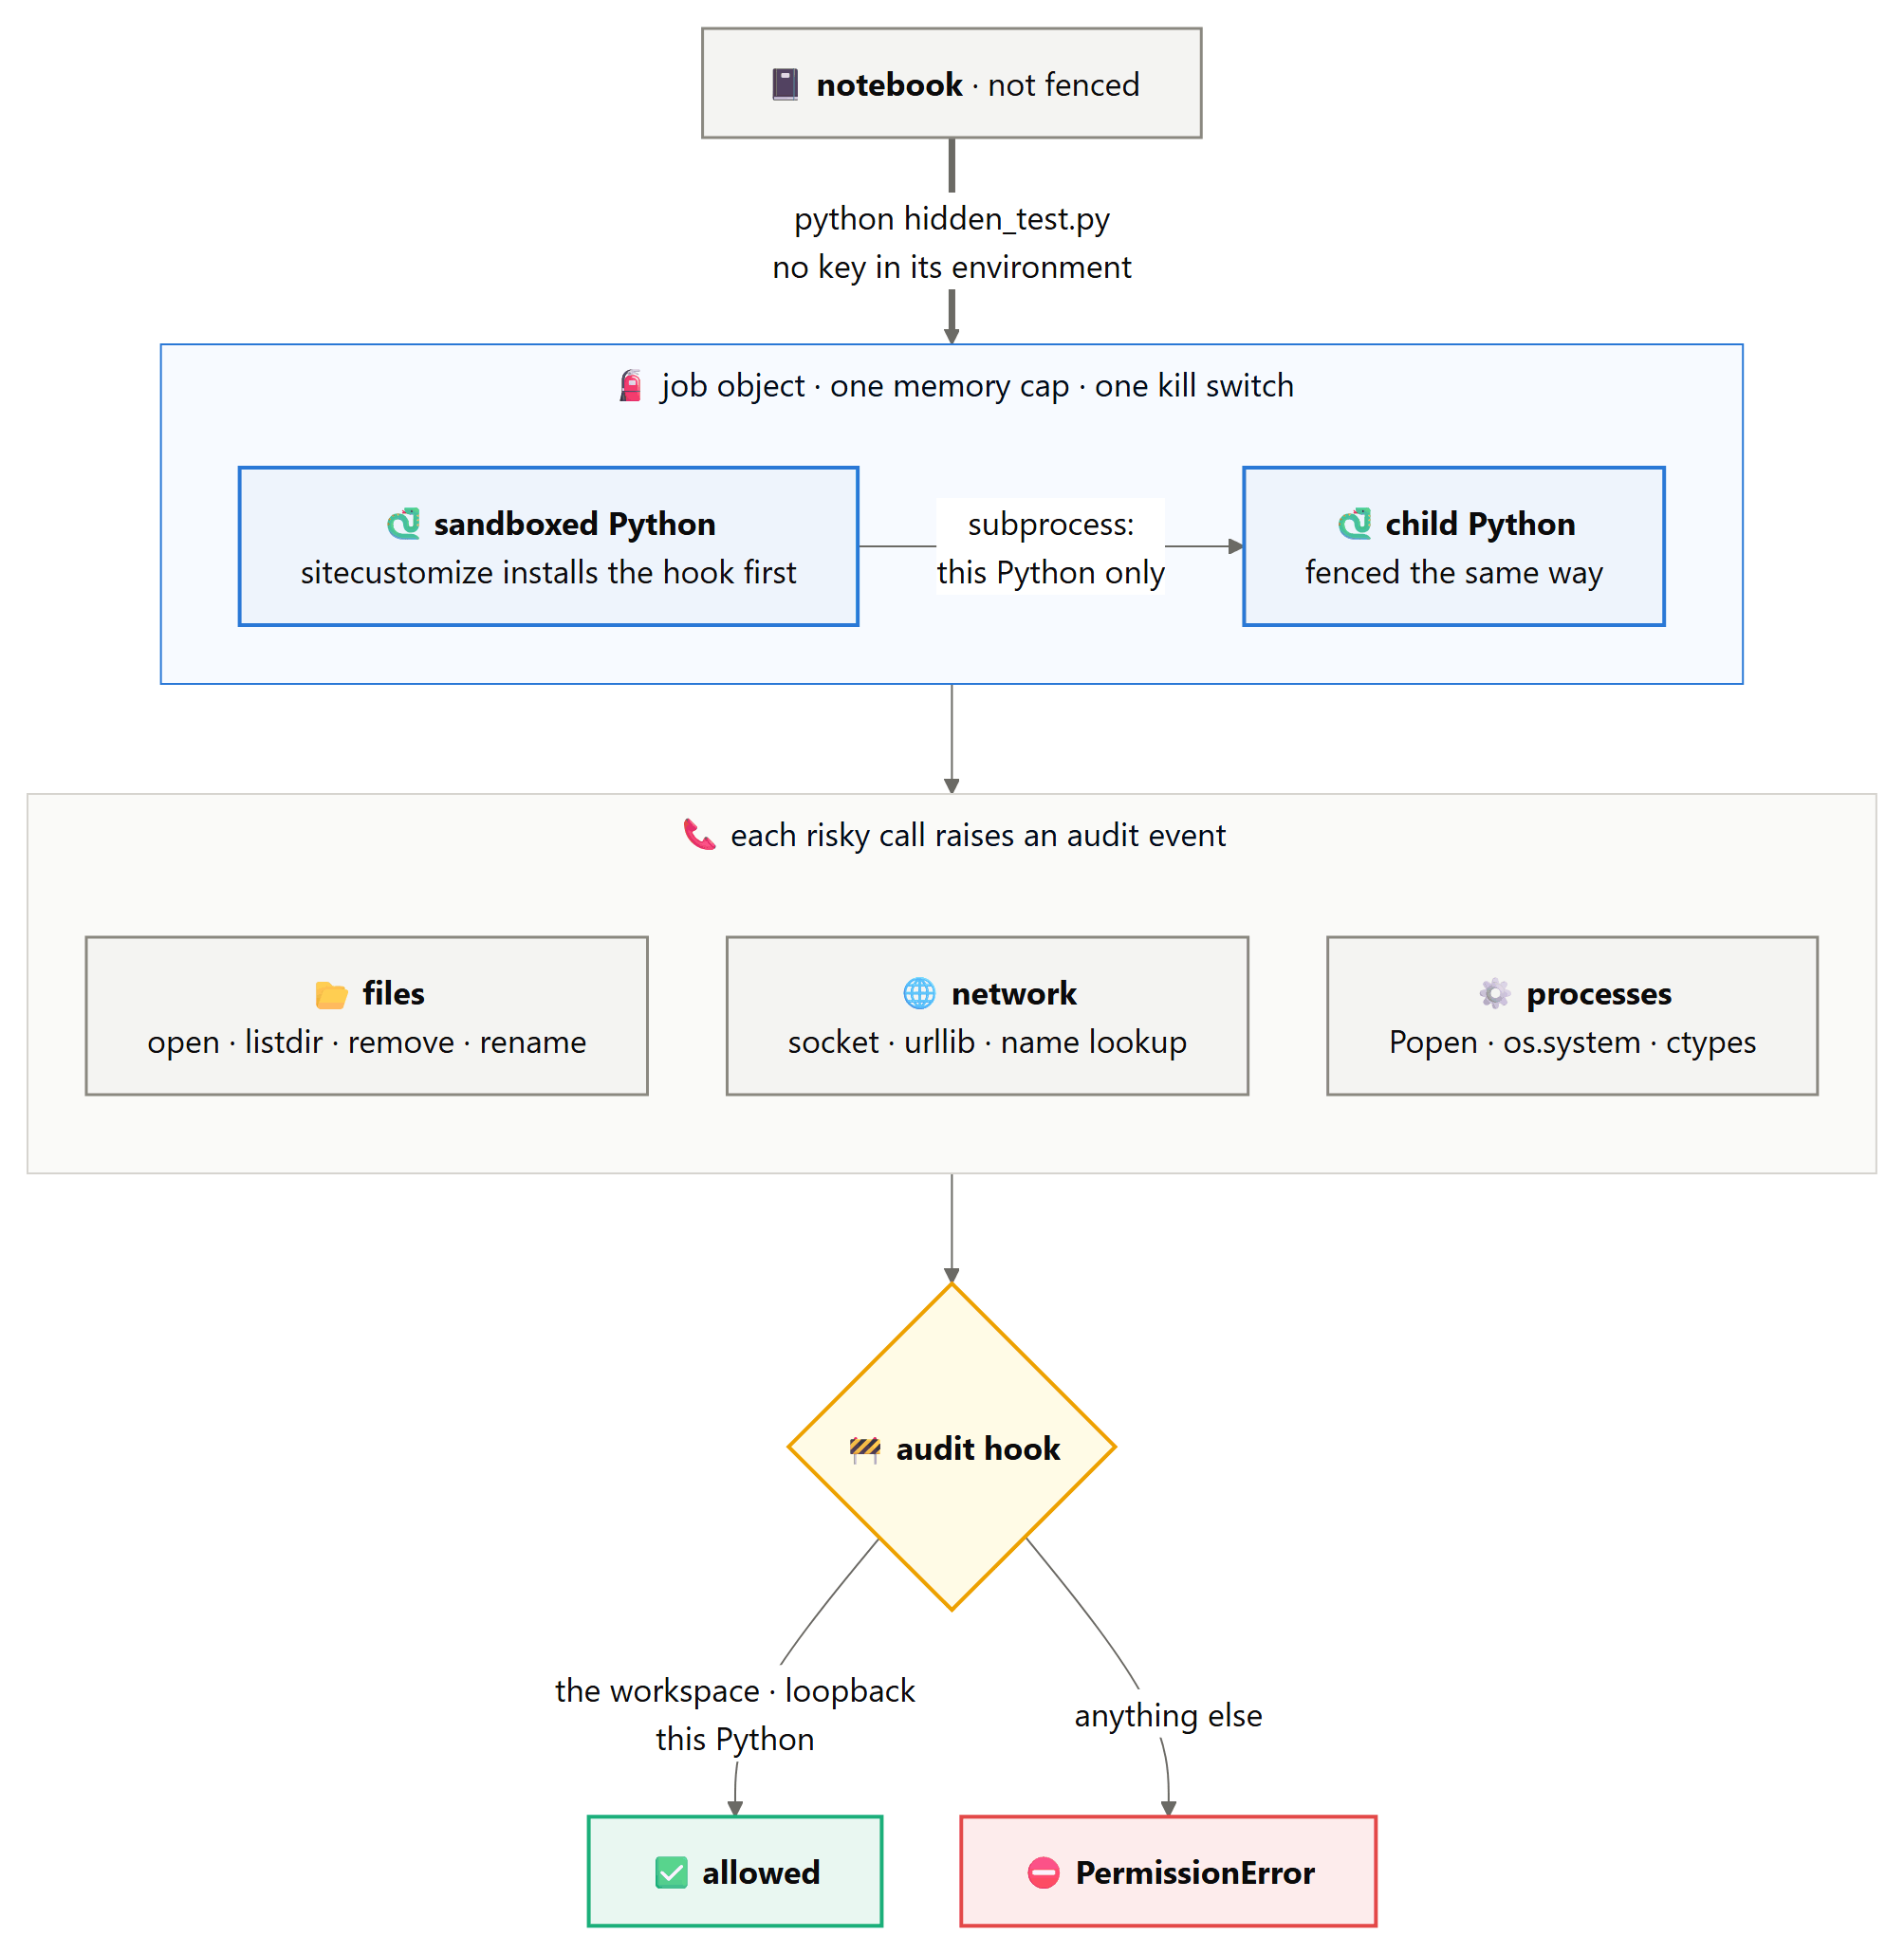

**`FENCE_SOURCE`** is the fence's own code, kept as a string in this notebook rather than defined in it. It runs in other processes, not here: the next cell writes it to disk as `sitecustomize.py`, a module Python imports by itself at start-up from any folder on its path, and fingerprints it. The notebook must never import it, because the hook would then start guarding this kernel. Read it top to bottom: the paths and environment captured first, the small checks (`_read`, `_write`, `_child` and the rest), the `_RULES` table that maps each audit event to its check, and finally `_hook`, the one function Python calls.

In [170]:
# ---- the fence itself: every sandboxed Python imports this before anything else ----
FENCE_SOURCE = r'''
"""The fence. Every Python process in the sandbox imports this module at start-up (its
folder is first on PYTHONPATH), and it installs an audit hook before any other code runs.
Python raises an audit event before each sensitive operation; the hook refuses the ones
outside these rules by raising PermissionError:

  read      the workspace, the Python installation, this folder
  write     the workspace only
  network   loopback only, name lookups included
  children  this same Python, with the fence still in force
  ctypes    never

It stops accidents and casual escapes. It does not stop code written to defeat it.
"""
import ipaddress
import os
import shlex
import sys
import threading

# Bound now, so code that later patches os.path cannot change what the fence sees.
_realpath, _normcase, _fsdecode, _basename = os.path.realpath, os.path.normcase, os.fsdecode, os.path.basename
_write_err = sys.stderr.write


def _real(path):
    return _normcase(_realpath(_fsdecode(path)))


_ENV = {k: os.environ.get(k, "") for k in ("LEAN_FENCE_ROOT", "LEAN_FENCE_READ", "PYTHONPATH")}
_WRITE = (_real(_ENV["LEAN_FENCE_ROOT"]),)
_READ = _WRITE + tuple(_real(p) for p in _ENV["LEAN_FENCE_READ"].split(os.pathsep) if p) \
        + (_real(os.path.dirname(os.path.abspath(__file__))),)
# a venv's multiprocessing starts the base interpreter on purpose, so both count as this Python
_PYTHONS = {_real(sys.executable), _real(getattr(sys, "_base_executable", sys.executable))}
_NULL = _real(os.devnull)
_WRITE_FLAGS = os.O_WRONLY | os.O_RDWR | os.O_APPEND | os.O_CREAT | os.O_TRUNC
_state = threading.local()


def _refuse(what):
    _write_err(f"[fence] refused: {what}\n")
    raise PermissionError(f"[fence] refused: {what}")


def _within(path, roots):
    if path is None:
        path = "."
    if isinstance(path, int):            # an open file descriptor, checked when it was opened
        return True
    p = _real(path)
    return p == _NULL or any(p == r or p.startswith(r.rstrip(os.sep) + os.sep) for r in roots)


def _read(path, *rest):
    if not _within(path, _READ):
        _refuse(f"read outside the sandbox: {path}")


def _write(path, *rest):
    if not _within(path, _WRITE):
        _refuse(f"write outside the workspace: {path}")


def _open(path, mode, flags):
    writing = any(c in mode for c in "wax+") if isinstance(mode, str) else bool(flags & _WRITE_FLAGS)
    (_write if writing else _read)(path)


def _move(src, dst, *rest):
    _write(src)
    _write(dst)


def _copy(src, dst, *rest):
    _read(src)
    _write(dst)


def _sqlite(database, *rest):
    name = _fsdecode(database) if isinstance(database, (str, bytes, os.PathLike)) else ""
    if name in ("", ":memory:") or name.startswith("file::memory:"):
        return
    _write(name[5:].split("?")[0] if name.startswith("file:") else name)


def _loopback(host):
    if host is None:
        return True
    host = _fsdecode(host) if isinstance(host, bytes) else str(host)
    if host.lower() == "localhost":
        return True
    try:
        return ipaddress.ip_address(host.split("%")[0]).is_loopback
    except ValueError:
        return False


def _address(sock, address, *rest):
    if not (isinstance(address, tuple) and _loopback(address[0])):
        _refuse(f"network address {address!r}")


def _lookup(host, *rest):
    if not _loopback(host):
        _refuse(f"name lookup for {host!r}")


def _lookup_address(sockaddr, *rest):
    _lookup(sockaddr[0] if isinstance(sockaddr, tuple) else sockaddr)


def _url(url, *rest):
    from urllib.parse import urlsplit
    _lookup(urlsplit(url).hostname)


def _python_args_ok(argv):
    """False if the interpreter options include -I, -E or -S: isolated mode, an ignored
    environment and no site import each start Python without reading this fence."""
    i = 1
    while i < len(argv):
        arg = argv[i]
        if not arg.startswith("-") or arg == "-":
            return True                  # the script: everything after it belongs to the script
        if not arg.startswith("--"):
            for j, ch in enumerate(arg[1:]):
                if ch in "IES":
                    return False
                if ch in "cm":
                    return True          # -c code or -m module: the rest is not ours to read
                if ch in "XW":
                    i += j == len(arg) - 2       # a bare -X or -W takes the next argument
                    break
        i += 1
    return True


def _argv(args):
    """Arguments as a list. On Windows, Popen hands the audit event one command line,
    already joined, so it is split back here."""
    if not isinstance(args, (str, bytes)):
        return [_fsdecode(a) for a in args]
    try:
        return [a.strip('"') for a in shlex.split(_fsdecode(args), posix=False)]
    except ValueError:
        _refuse("a command line that cannot be read")


def _child(exe, argv, env):
    exe = exe if exe is not None else argv[0] if argv else None
    if exe is None or _real(exe) not in _PYTHONS:
        _refuse(f"start a program other than this Python: {_basename(_fsdecode(exe)) if exe else exe}")
    if not _python_args_ok(argv):
        _refuse(f"start Python without the fence: {' '.join(argv[1:3])}")
    env = os.environ if env is None else env
    for key, value in _ENV.items():
        if env.get(key, "") != value:
            _refuse(f"start Python with {key} changed")


def _popen(executable, args, cwd, env):
    _child(executable, _argv(args), env)
    _state.approved = True               # the CreateProcess that follows belongs to this Popen


def _create_process(app_name, *rest):
    # On the Python build this notebook was made with, this event carries a garbled command
    # line, so the full check happens in _popen. A direct call (multiprocessing makes one)
    # is judged by the program it starts, which the event does report correctly.
    if getattr(_state, "approved", False):
        _state.approved = False
        return
    _child(app_name, [app_name or ""], None)


def _import(module, *rest):
    if module.split(".")[0] in ("ctypes", "_ctypes", "cffi"):
        _refuse(f"import {module}")


_RULES = {
    "open": _open, "os.listdir": _read, "os.scandir": _read, "os.chdir": _read,
    "os.remove": _write, "os.rmdir": _write, "os.mkdir": _write, "shutil.rmtree": _write,
    "os.chmod": _write, "os.chown": _write, "os.utime": _write, "os.truncate": _write,
    "os.rename": _move, "shutil.move": _move,
    "shutil.copyfile": _copy, "shutil.copytree": _copy, "shutil.copymode": _copy, "shutil.copystat": _copy,
    "sqlite3.connect": _sqlite,
    "socket.connect": _address, "socket.bind": _address, "socket.sendto": _address,
    "socket.getaddrinfo": _lookup, "socket.gethostbyname": _lookup, "socket.gethostbyname_ex": _lookup,
    "socket.gethostbyaddr": _lookup, "socket.getnameinfo": _lookup_address, "urllib.Request": _url,
    "subprocess.Popen": _popen, "_winapi.CreateProcess": _create_process,
    "os.exec": lambda path, args, env: _child(path, _argv(args), env),
    "os.spawn": lambda mode, path, args, env: _child(path, _argv(args), env),
    "os.posix_spawn": lambda path, argv, env, *rest: _child(path, _argv(argv), env),
    "import": _import,
}
_ALWAYS_REFUSED = {"os.system", "os.startfile", "os.kill", "os.killpg", "os.link", "os.symlink",
                   "pty.spawn", "webbrowser.open", "ctypes.dlopen", "ctypes.dlsym", "ctypes.cdata"}


def _hook(event, args):
    rule = _RULES.get(event)
    if rule is None and event not in _ALWAYS_REFUSED:
        return
    if getattr(_state, "busy", False):   # the checks below raise events of their own; let them by
        return
    _state.busy = True
    try:
        if rule is None:
            _refuse(event)
        rule(*args)
    finally:
        _state.busy = False


sys.addaudithook(_hook)
'''
print(f"[fence] FENCE_SOURCE: {len(FENCE_SOURCE.splitlines())} lines of Python, kept as text and never imported here")

[fence] FENCE_SOURCE: 217 lines of Python, kept as text and never imported here


Writing the fence to disk. `fence_env` (below) puts this folder first on `PYTHONPATH` for every sandboxed process, which is how the fence is in force before the first line of the agent's code. The fingerprint goes into every score's cache key, so an edit to the fence makes every cached score stale.

In [171]:
FENCE_DIR = RUNTIME / "fence"                              # first on every sandboxed process's PYTHONPATH
FENCE_DIR.mkdir(parents=True, exist_ok=True)
(FENCE_DIR / "sitecustomize.py").write_text(FENCE_SOURCE, encoding="utf-8")   # Python imports it at start-up
FENCE_HASH = hashlib.sha256(FENCE_SOURCE.encode()).hexdigest()[:12]          # part of every score's cache key
print(f"[fence] {rel(FENCE_DIR / 'sitecustomize.py')}: {measure_source(FENCE_SOURCE)['code']} code lines, "
      f"fingerprint {FENCE_HASH}")

[fence] .runtime/fence/sitecustomize.py: 145 code lines, fingerprint 90ab1dd4106c


To list what the fence watches without importing it, the notebook parses the source and reads the `_RULES` and `_ALWAYS_REFUSED` assignments straight from the syntax tree.

In [172]:
# the rules, read back from the source (the notebook must never import the fence itself:
# the hook would then guard this kernel)
_tree = ast.parse(FENCE_SOURCE)
_assigned = {}                                             # each top-level name -> the expression assigned to it
for stmt in _tree.body:
    if isinstance(stmt, ast.Assign) and isinstance(stmt.targets[0], ast.Name):
        _assigned[stmt.targets[0].id] = stmt.value
_rules = _assigned["_RULES"]                               # a dict literal: audit event -> the check that judges it
_always = _assigned["_ALWAYS_REFUSED"]                     # a set literal: events refused whatever their arguments
print(f"[fence] read back from the source: {len(_rules.keys)} events with a check, {len(_always.elts)} always refused")

[fence] read back from the source: 34 events with a check, 11 always refused


The same rules grouped by what they protect, in plain words:

In [173]:
RULE_NAMES = {"_open": "read or write", "_read": "read", "_write": "write", "_move": "move", "_copy": "copy",
              "_sqlite": "database file", "_address": "network address", "_lookup": "name lookup",
              "_lookup_address": "name lookup", "_url": "web address", "_popen": "start a child",
              "_create_process": "start a child", "_import": "import"}
by_rule = {}                                               # plain-words rule -> the audit events it judges
for k, v in zip(_rules.keys, _rules.values):               # k: the event's name; v: the check, a name or a lambda
    rule = RULE_NAMES.get(getattr(v, "id", ""), "start a child")   # the three lambdas all judge a new process
    by_rule.setdefault(rule, []).append(k.value)
print(f"  watches {len(_rules.keys) + len(_always.elts)} audit events:")
for rule, events in by_rule.items():
    print(f"    {rule:<16} {', '.join(events)}")
print(f"    {'always refused':<16} {', '.join(sorted(e.value for e in _always.elts))}")

  watches 45 audit events:
    read or write    open
    read             os.listdir, os.scandir, os.chdir
    write            os.remove, os.rmdir, os.mkdir, shutil.rmtree, os.chmod, os.chown, os.utime, os.truncate
    move             os.rename, shutil.move
    copy             shutil.copyfile, shutil.copytree, shutil.copymode, shutil.copystat
    database file    sqlite3.connect
    network address  socket.connect, socket.bind, socket.sendto
    name lookup      socket.getaddrinfo, socket.gethostbyname, socket.gethostbyname_ex, socket.gethostbyaddr, socket.getnameinfo
    web address      urllib.Request
    start a child    subprocess.Popen, _winapi.CreateProcess, os.exec, os.spawn, os.posix_spawn
    import           import
    always refused   ctypes.cdata, ctypes.dlopen, ctypes.dlsym, os.kill, os.killpg, os.link, os.startfile, os.symlink, os.system, pty.spawn, webbrowser.open


**Job objects, from Python.** Windows has no process groups in the Unix sense. The way to treat a process and everything it starts as one unit is a *job object*: a kernel object that processes are assigned to, whose children are born inside it, and which can cap the memory of all of them together and end all of them in one call. The standard library does not wrap job objects, so the next cells reach the kernel32 calls through `ctypes`. On other systems `ProcessGuard` uses a process group and an address-space limit instead.

In [174]:
# ---- one group for a process and everything it starts: memory cap and kill switch --
import subprocess                                          # starts every sandboxed process
import signal                                              # SIGKILL for a whole process group, outside Windows
import uuid                                                # unique names for output files and scoring folders

print(f"[job] this kernel runs on {'Windows, so the guard uses job objects' if os.name == 'nt' else 'a Unix system, so the guard uses process groups'}")

[job] this kernel runs on Windows, so the guard uses job objects


**`_IoCounters`** is the `IO_COUNTERS` structure from the Windows headers: six 64-bit counters for read, write and other operations and bytes. Nothing in the notebook reads them. The structure is declared only because `_JobLimits` embeds it: `ctypes` lays a structure out byte for byte, so every field before the ones we use has to be there, at the right width, or those would sit at the wrong offsets.

In [175]:
if os.name == "nt":                                        # job objects exist only on Windows
    import ctypes
    from ctypes import wintypes                            # DWORD, HANDLE and the rest, at Windows' own sizes

    class _IoCounters(ctypes.Structure):                   # IO_COUNTERS: reads, writes, others; counts, then bytes
        _fields_ = [(n, ctypes.c_uint64) for n in ("r_ops", "w_ops", "o_ops", "r_bytes", "w_bytes", "o_bytes")]

    show_def(_IoCounters, layer="host")
else:
    print("[job] not Windows: no job-object structures needed")

[class] _IoCounters  2 lines, complexity 2


**`_BasicLimits`** is `JOBOBJECT_BASIC_LIMIT_INFORMATION`, field for field. The fence sets only `LimitFlags`, the bit mask that says which limits are switched on; every other field stays zero, which Windows reads as "no limit of this kind".

In [176]:
if os.name == "nt":
    class _BasicLimits(ctypes.Structure):
        _fields_ = [("PerProcessUserTimeLimit", ctypes.c_int64), ("PerJobUserTimeLimit", ctypes.c_int64),
                    ("LimitFlags", wintypes.DWORD),                 # which limits are on: the only field we set
                    ("MinimumWorkingSetSize", ctypes.c_size_t),
                    ("MaximumWorkingSetSize", ctypes.c_size_t), ("ActiveProcessLimit", wintypes.DWORD),
                    ("Affinity", ctypes.c_size_t), ("PriorityClass", wintypes.DWORD),
                    ("SchedulingClass", wintypes.DWORD)]

    show_def(_BasicLimits, layer="host")
else:
    print("[job] not Windows: no job-object structures needed")

[class] _BasicLimits  7 lines, complexity 1


**`_JobLimits`** is `JOBOBJECT_EXTENDED_LIMIT_INFORMATION`: the basic limits, the I/O counters, then four memory fields. `JobMemoryLimit` is the ceiling for every process in the job together, which is what makes it a limit on the whole tree rather than on one process, and `PeakJobMemoryUsed` is what `ProcessGuard.close` reports as a run's peak memory.

In [177]:
if os.name == "nt":
    class _JobLimits(ctypes.Structure):   # JOBOBJECT_EXTENDED_LIMIT_INFORMATION
        _fields_ = [("basic", _BasicLimits), ("io", _IoCounters), ("ProcessMemoryLimit", ctypes.c_size_t),
                    ("JobMemoryLimit", ctypes.c_size_t),           # the ceiling for the whole job, in bytes
                    ("PeakProcessMemoryUsed", ctypes.c_size_t),
                    ("PeakJobMemoryUsed", ctypes.c_size_t)]        # the high-water mark close() reads back

    show_def(_JobLimits, layer="host")
else:
    print("[job] not Windows: no job-object structures needed")

[class] _JobLimits  5 lines, complexity 1


The six kernel32 calls the guard needs, each with its argument and result types spelled out. Without them `ctypes` passes and returns a plain C `int`, 32 bits, which would cut a 64-bit handle in half. The three constants are the flag values and the information class from the Windows headers.

In [178]:
if os.name == "nt":
    _K32 = ctypes.WinDLL("kernel32", use_last_error=True)          # the DLL that holds every job-object call
    for _name, _args, _res in (   # 64-bit handles need the types spelled out
            ("CreateJobObjectW", [wintypes.LPVOID, wintypes.LPCWSTR], wintypes.HANDLE),
            ("SetInformationJobObject", [wintypes.HANDLE, ctypes.c_int, wintypes.LPVOID, wintypes.DWORD], wintypes.BOOL),
            ("QueryInformationJobObject", [wintypes.HANDLE, ctypes.c_int, wintypes.LPVOID, wintypes.DWORD, wintypes.LPVOID], wintypes.BOOL),
            ("AssignProcessToJobObject", [wintypes.HANDLE, wintypes.HANDLE], wintypes.BOOL),
            ("TerminateJobObject", [wintypes.HANDLE, wintypes.UINT], wintypes.BOOL),
            ("CloseHandle", [wintypes.HANDLE], wintypes.BOOL)):
        getattr(_K32, _name).argtypes = _args              # what the call takes
        getattr(_K32, _name).restype = _res                # and what it gives back
    _JOB_MEMORY = 0x200            # JOB_OBJECT_LIMIT_JOB_MEMORY: one memory ceiling for the whole job
    _KILL_ON_CLOSE = 0x2000        # JOB_OBJECT_LIMIT_KILL_ON_JOB_CLOSE: closing the handle ends every process in it
    _EXTENDED_LIMITS = 9           # JobObjectExtendedLimitInformation: the layout _JobLimits matches
    print("[job] kernel32: six job-object calls typed for 64-bit handles")
else:
    print("[job] not Windows: no kernel32")

[job] kernel32: six job-object calls typed for 64-bit handles


**`ProcessGuard(proc, memory_mb)`** puts one sandboxed process, and everything it will ever start, into a single group with one memory ceiling and one kill switch. On Windows that group is a job object: `__init__` creates it, switches on the whole-job memory limit and kill-on-close, and assigns the process to it, so every child the process starts afterwards is born inside the same job. Elsewhere the group is a process group, and each process in it gets an address-space limit before it starts running; that has to be arranged in the arguments to `subprocess.Popen`, before there is a process to guard, which is why `popen_options` is a static method. The two methods that end the group follow.

In [179]:
class ProcessGuard:
    """Keeps a sandboxed process and everything it starts in one group: one memory ceiling
    for the whole tree, one call that kills the whole tree, and the peak memory it used.
    On Windows the group is a job object; elsewhere a process group with an address-space limit."""

    def __init__(self, proc, memory_mb):
        self.proc = proc                                   # the process at the top of the tree
        self.job = None                                    # stays None outside Windows
        if os.name == "nt":
            self.job = _K32.CreateJobObjectW(None, None)   # a new job, with no name and default security
            limits = _JobLimits()                          # all zero: no limit is on until a flag says so
            limits.basic.LimitFlags = _JOB_MEMORY | _KILL_ON_CLOSE   # a memory ceiling, and death when the handle closes
            limits.JobMemoryLimit = memory_mb << 20        # megabytes to bytes, for all the job's processes together
            # hand the limits to Windows; from here they apply to every process in the job
            _K32.SetInformationJobObject(self.job, _EXTENDED_LIMITS, ctypes.byref(limits), ctypes.sizeof(limits))
            _K32.AssignProcessToJobObject(self.job, int(proc._handle))   # its children will be born inside the job

    @staticmethod
    def popen_options(memory_mb):
        if os.name == "nt":
            return {}                                      # on Windows the job does it all, after the start
        import resource                                    # Unix only, so imported only here
        cap = memory_mb << 20                              # megabytes to bytes
        return {"start_new_session": True,                 # a new session is a new process group, killable as one
                "preexec_fn": lambda: resource.setrlimit(resource.RLIMIT_AS, (cap, cap))}   # runs in the child first

show_def(ProcessGuard, layer="host")

[class] ProcessGuard(proc, memory_mb)  22 lines, complexity 3


**`ProcessGuard.kill()`** ends every process in the group at once. On Windows that is one call, `TerminateJobObject`, which reaches every child and grandchild the sandboxed process started, including ones it has forgotten about. Elsewhere it sends `SIGKILL` to the whole process group; a group that has already gone is not an error.

In [180]:
@method_of(ProcessGuard)
def kill(self):
    """End every process in the group, now."""
    if self.job:
        _K32.TerminateJobObject(self.job, 1)               # every process in the job, with exit code 1
    else:
        try:
            os.killpg(self.proc.pid, signal.SIGKILL)       # the session leader's pid is also the group's id
        except ProcessLookupError:                         # the group has already gone
            pass

show_def(ProcessGuard.kill, layer="host")

[def] ProcessGuard.kill(self)  10 lines, complexity 3


**`ProcessGuard.close()`** is called once a run is over, however it ended. On Windows it first reads the job's accounting for the peak memory the whole tree used, then closes the job's handle; because the job was created with kill-on-close, closing it also ends anything still running, such as a child the program left behind on purpose. It returns the peak in megabytes, or `None` where there is no job to ask, and there it simply kills the group.

In [181]:
@method_of(ProcessGuard)
def close(self):
    """Kill whatever is still running in the group; return its peak memory in MB."""
    if not self.job:
        self.kill()                                        # no job to ask: just make sure nothing is left running
        return None
    limits = _JobLimits()                                  # Windows fills this in
    # ask for the extended limits, which carry the peak memory, before the handle is gone
    ok = _K32.QueryInformationJobObject(self.job, _EXTENDED_LIMITS, ctypes.byref(limits), ctypes.sizeof(limits), None)
    _K32.CloseHandle(self.job)       # kill-on-close ends anything left behind
    return limits.PeakJobMemoryUsed / 2**20 if ok else None   # bytes to megabytes; None if the query failed

show_def(ProcessGuard.close, layer="host")

[def] ProcessGuard.close(self)  10 lines, complexity 3


The guard on its own, without the fence: a Python that would sleep for a minute goes into a group with a 256 MB ceiling, and the whole group is killed half a second later.

In [182]:
sleeper = subprocess.Popen([sys.executable, "-c", "import time; time.sleep(60)"], stdin=subprocess.DEVNULL,
                           **ProcessGuard.popen_options(256))
sleeper_guard = ProcessGuard(sleeper, 256)                 # into the group straight after the start
time.sleep(0.5)                                            # give it time to start, so there is memory to report
sleeper_guard.kill()                                       # the whole group, in one call
sleeper.wait(timeout=10)                                   # returns at once: it is already gone
sleeper_peak = sleeper_guard.close()                       # the peak memory, and the job's handle closed
peak_note = f"{sleeper_peak:.0f} MB" if sleeper_peak else "not measured on this platform"
print(f"[guard] a one-minute sleeper was stopped after half a second: exit code {sleeper.returncode}, peak {peak_note}")

[guard] a one-minute sleeper was stopped after half a second: exit code 1, peak 7 MB


**`fence_env(ws)`** builds the complete environment of a sandboxed process from nothing. Only the four variables Windows needs to start a program at all are copied from this kernel. Everything else is set explicitly: the fence's folder as `PYTHONPATH`, the workspace as the one place it may write, the Python installation as readable, the temporary and home folders pointed inside the workspace, and a fixed hash seed. Building the environment rather than filtering this kernel's own is the safer default, because a variable that is not there cannot leak: the API key never reaches agent code, whatever it was called.

In [183]:
READ_ROOTS = sorted({str(Path(p).resolve()) for p in (sys.prefix, sys.base_prefix)})   # the venv and the Python it was made from
OUTPUT_CAP = 2_000_000          # bytes of stdout plus stderr before a run is stopped

def fence_env(ws):
    """The whole environment of a sandboxed process. Nothing is inherited except what
    Windows needs to start Python at all, so no key can leak through a variable that is
    not there."""
    # the only variables copied from this kernel: Windows cannot start a program without them
    env = {k: os.environ[k] for k in ("SYSTEMROOT", "WINDIR", "COMSPEC", "PATHEXT") if k in os.environ}
    tmp = str(Path(ws) / "_tmp")                           # temporary files stay inside the workspace
    env.update({
        "PATH": str(Path(sys.executable).parent),          # this Python's folder and nothing else
        "PYTHONPATH": str(FENCE_DIR),                      # so sitecustomize.py, the fence, is found first
        "PYTHONNOUSERSITE": "1", "PYTHONDONTWRITEBYTECODE": "1",   # no user packages, no __pycache__ left behind
        "PYTHONUTF8": "1", "PYTHONIOENCODING": "utf-8",    # the same text encoding on every machine
        "PYTHONHASHSEED": str(SEED),                       # so the order of a set of strings repeats from run to run
        "LEAN_FENCE_ROOT": str(ws),                        # the one folder the fence lets it write
        "LEAN_FENCE_READ": os.pathsep.join(READ_ROOTS),    # extra folders it may read: the Python installation
        "TEMP": tmp, "TMP": tmp, "TMPDIR": tmp,            # every name tempfile looks for
        "HOME": str(ws), "USERPROFILE": str(ws),           # a home folder inside the fence, not the real one
    })
    return env

show_def(fence_env, layer="host")

[def] fence_env(ws)  18 lines, complexity 2


In [184]:
probe_env = fence_env(WS_DIR / "probe")                    # what the probe below will be given; nothing is started
copied = [k for k in ("SYSTEMROOT", "WINDIR", "COMSPEC", "PATHEXT") if k in probe_env]
print(f"[env] {len(probe_env)} variables, {len(copied)} copied from this kernel ({', '.join(copied) or 'none'})")
for k in ("PYTHONPATH", "LEAN_FENCE_ROOT", "TEMP", "HOME"):
    print(f"  {k:<16} {rel(probe_env[k])}")
print(f"  anything named like a key or token: {[k for k in probe_env if 'KEY' in k or 'TOKEN' in k] or 'none'}")

[env] 18 variables, 4 copied from this kernel (SYSTEMROOT, WINDIR, COMSPEC, PATHEXT)
  PYTHONPATH       .runtime/fence
  LEAN_FENCE_ROOT  .runtime/ws/probe
  TEMP             .runtime/ws/probe/_tmp
  HOME             .runtime/ws/probe
  anything named like a key or token: none


**`FenceResult`** is what one fenced run returns: the exit code, both output streams as text, the wall-clock time, why the run was stopped if it was (`timeout`, `memory` or `output`), the peak memory of the whole process tree, and the reason given in every refusal the fence wrote. The agent's tools and the scorer read different parts of it, so the record carries all of them rather than a single pass or fail.

In [185]:
@dataclass
class FenceResult:
    returncode: int             # the program's exit code; 1 after a kill on Windows
    stdout: str                 # decoded, at most OUTPUT_CAP bytes, Windows line ends made plain
    stderr: str
    seconds: float              # wall clock, start-up included
    killed: str = None          # None, "timeout", "memory" or "output"
    peak_mb: float = None       # the whole tree's peak; None where it cannot be measured
    refused: list = field(default_factory=list)   # the reason from each '[fence] refused:' line

show_def(FenceResult, layer="host")

[class] FenceResult(returncode: int, stdout: str, stderr: str, seconds: float, killed:...)  8 lines, complexity 1


**`watch_fenced(proc, guard, start, timeout, out_path, err_path)`** is the waiting loop inside `run_fenced`, which is defined a little further down. It waits for the process a tenth of a second at a time, and between waits checks the two limits that have to be enforced from outside: the clock, and the combined size of the two output files. When either is exceeded it kills the whole group through the guard, waits for the process so its exit code is set, and returns the reason; a program that finishes by itself returns `None`. Memory needs no check here, because the job object enforces it.

In [186]:
def watch_fenced(proc, guard, start, timeout, out_path, err_path):
    """Wait for a fenced process, checking the clock and the size of its output every tenth of
    a second; stop the whole group when either runs over. Returns why it was stopped, or None."""
    killed = None
    while True:
        try:
            proc.wait(timeout=0.1)                         # returns as soon as the program exits
            break
        except subprocess.TimeoutExpired:                  # still running: check the two limits
            if time.perf_counter() - start > timeout:
                killed = "timeout"
            elif out_path.stat().st_size + err_path.stat().st_size > OUTPUT_CAP:
                killed = "output"                          # a print loop would otherwise fill the disk
            if killed:
                guard.kill()                               # every process in the group, not only the first
                proc.wait()                                # reap it, so its exit code is set
                break
    return killed

show_def(watch_fenced, layer="host")

[def] watch_fenced(proc, guard, start, timeout, out_path, err_path)  18 lines, complexity 6


**`read_fenced_output(out_path, err_path)`** reads the two output files back as text and deletes them. Each is cut at `OUTPUT_CAP` bytes, decoded as UTF-8 with a replacement mark for anything that is not, and has its Windows line ends turned into plain `\n`, so the agent sees the same output on every platform. Deleting retries for up to three seconds, because a grandchild that is being killed can keep a file open a moment longer.

In [187]:
def read_fenced_output(out_path, err_path):
    """Both output files as text, capped at OUTPUT_CAP, with Windows line ends made plain;
    then both files deleted."""
    texts = []
    for p in (out_path, err_path):
        raw = p.read_bytes()[:OUTPUT_CAP]                  # never more than the cap, even if the run overshot it
        texts.append(raw.decode("utf-8", "replace").replace("\r\n", "\n"))   # a bad byte becomes a mark, not a crash
    for p in (out_path, err_path):
        for _ in range(30):              # a grandchild being killed can hold the file a moment longer
            try:
                p.unlink()
                break
            except PermissionError:
                time.sleep(0.1)                            # thirty tries, three seconds in all
    return texts[0], texts[1]

show_def(read_fenced_output, layer="host")

[def] read_fenced_output(out_path, err_path)  15 lines, complexity 5


In [188]:
io_demo = RUNTIME / "demo" / "fenced_output"
io_demo.mkdir(parents=True, exist_ok=True)
(io_demo / "x.out").write_bytes(b"line one\r\nline two\r\n")       # what a program on Windows writes
(io_demo / "x.err").write_bytes(b"")                                # and an empty stderr
demo_out, demo_err = read_fenced_output(io_demo / "x.out", io_demo / "x.err")
print(f"[output] stdout read back as {demo_out!r}, stderr as {demo_err!r}")
print(f"  files left behind: {sorted(p.name for p in io_demo.iterdir()) or 'none'}")

[output] stdout read back as 'line one\nline two\n', stderr as ''
  files left behind: none


**`run_fenced(ws, args, timeout, memory_mb)`** runs `python *args` inside a workspace, fenced, and returns a `FenceResult`. It starts this same interpreter in the workspace with the environment from `fence_env` and nothing on stdin, puts it in a `ProcessGuard`, and hands it to `watch_fenced`. Output goes to files rather than pipes: a grandchild that inherits a pipe and keeps it open would hang a reader waiting for the end of the stream, and a file's size can be checked while the program is still writing. Whatever happens, the guard is closed in a `finally`, which kills anything still running and reads the peak memory. A `MemoryError` in the output means the job's ceiling was reached, and each line the fence wrote becomes one refusal.

In [189]:
def run_fenced(ws, args, timeout=30, memory_mb=1024):
    """Run `python *args` inside workspace `ws`, fenced. Output goes to files rather than
    pipes: a grandchild that keeps a pipe open cannot hang the reader that way, and a
    runaway print loop is caught by the size of the file."""
    ws = Path(ws)
    (ws / "_tmp").mkdir(parents=True, exist_ok=True)      # TEMP points here, so it must exist
    io_dir = RUNTIME / "sandbox_io"                        # outside the workspace: the program cannot touch its own log
    io_dir.mkdir(parents=True, exist_ok=True)
    out_path, err_path = (io_dir / f"{uuid.uuid4().hex}.{k}" for k in ("out", "err"))   # unique: runs go in parallel
    killed = None                                          # why the run was stopped, if it was
    start = time.perf_counter()                            # the clock starts before the process does
    with open(out_path, "wb") as out, open(err_path, "wb") as err:
        # this same Python, in the workspace, with the fenced environment and nothing to read on stdin
        proc = subprocess.Popen([sys.executable, *args], cwd=ws, env=fence_env(ws), stdin=subprocess.DEVNULL,
                                stdout=out, stderr=err, **ProcessGuard.popen_options(memory_mb))
        guard = ProcessGuard(proc, memory_mb)              # into the group before it can start anything
        try:
            killed = watch_fenced(proc, guard, start, timeout, out_path, err_path)
        finally:
            peak = guard.close()                           # always: ends any leftovers, reads the peak memory
    seconds = time.perf_counter() - start
    stdout, stderr = read_fenced_output(out_path, err_path)
    if killed is None and "MemoryError" in stderr:         # the job's ceiling shows up as a MemoryError
        killed = "memory"
    refused = []                                           # the fence writes one line per refusal
    for ln in stderr.splitlines():
        if ln.startswith("[fence] refused: "):
            refused.append(ln.split("refused: ", 1)[1])   # keep the reason, drop the prefix
    return FenceResult(proc.returncode, stdout, stderr, seconds, killed, peak, refused)

show_def(run_fenced, layer="host")

[def] run_fenced(ws, args, timeout=30, memory_mb=1024)  28 lines, complexity 6


A first fenced run: a probe that reports, from inside, which folder it is in, whether the fence was loaded, and which environment variables it can see.

In [190]:
probe = WS_DIR / "probe"
shutil.rmtree(probe, ignore_errors=True)                   # a fresh workspace for the probe
probe.mkdir(parents=True)
(probe / "probe.py").write_text(textwrap.dedent('''
    import os, sys
    print("working folder   :", os.path.basename(os.getcwd()))
    print("fence loaded     :", "sitecustomize" in sys.modules)
    print("variables        :", ", ".join(sorted(os.environ)))
    hits = [k for k in os.environ if any(w in k.upper() for w in ("KEY", "TOKEN", "SECRET", "MODELSCOPE"))]
    print("secret-like names:", hits or "none")
'''), encoding="utf-8")
r = run_fenced(probe, ["probe.py"])
for line in scrub(r.stdout).splitlines():                  # scrubbed: no machine paths in the notebook
    for part in textwrap.wrap(line, 96, subsequent_indent=" " * 19):
        print("  " + part)
if r.peak_mb:
    peak_text = f"{r.peak_mb:.0f} MB"                      # the job object's figure for the whole tree
else:
    peak_text = "not measured on this platform"            # no job objects outside Windows
print(f"\n  exit {r.returncode} after {r.seconds:.2f}s, peak memory {peak_text}, refusals: {len(r.refused)}")

  working folder   : probe
  fence loaded     : True
  variables        : COMSPEC, HOME, LEAN_FENCE_READ, LEAN_FENCE_ROOT, PATH, PATHEXT,
                     PYTHONDONTWRITEBYTECODE, PYTHONHASHSEED, PYTHONIOENCODING, PYTHONNOUSERSITE,
                     PYTHONPATH, PYTHONUTF8, SYSTEMROOT, TEMP, TMP, TMPDIR, USERPROFILE, WINDIR
  secret-like names: none

  exit 0 after 0.19s, peak memory 9 MB, refusals: 0


**The attack table.** Each row below is a short program run inside the fence, with the outcome it must have: `refused` (and for the right reason: a refusal whose message names a different reason counts as a failure), `allowed`, `killed` (time, memory, or a child left running after its parent exited), or `escapes`. The last outcome is there on purpose. A table where everything is blocked usually means the table was written to be blocked; the one row that gets through marks the real edge of what an in-process hook can promise.

In [191]:
KEY_FILE = ROOT.parent / "modelscope.txt"   # S9 reads the key from here; sandboxed code must not
DECOY = RUNTIME / "fence_decoy.txt"         # a harmless file outside the workspace
SENTINEL = RUNTIME / "fence_sentinel.txt"   # must survive an attempt to delete it
OUTSIDE = RUNTIME / "fence_escape.txt"      # must never be created
HIDDEN = TASKS_DIR / "sf-share-link" / "hidden_test.py"                     # a hidden test, which no agent may read
OTHER_REF = TASKS_DIR / "ob-postcode-cache" / "refs" / "good" / "geo.py"    # another task's answer, also off limits
# CHILD: a program that runs {code} in a child Python and passes on the child's output and exit code
CHILD = ("import subprocess, sys; r = subprocess.run([sys.executable, '-c', {code!r}], capture_output=True, "
         "text=True); sys.stdout.write(r.stdout); sys.stderr.write(r.stderr); sys.exit(r.returncode)")
# BEAT: a heartbeat, rewriting beat.txt ten times a second for thirty seconds unless something kills it
BEAT = "import time, pathlib\\nfor i in range(300): pathlib.Path('beat.txt').write_text(str(i)); time.sleep(0.1)"
print(f"[attacks] targets outside every workspace: {rel(DECOY)}, {rel(SENTINEL)}, {rel(OUTSIDE)}, the key file, "
      f"a hidden test and another task's answer")

[attacks] targets outside every workspace: .runtime/fence_decoy.txt, .runtime/fence_sentinel.txt, .runtime/fence_escape.txt, the key file, a hidden test and another task's answer


The table itself, in four groups. First, the programs that must be refused, each for the reason in its last field: reading what the agent must not see, writing outside the workspace, reaching the network, starting anything but a fenced Python, and loading `ctypes` or tampering with the fence's view of paths.

In [192]:
ATTACKS = [  # (name, program, expected outcome, what a refusal must say)
    ("read the API key file", f"open({str(KEY_FILE)!r}).read()", "refused", "read outside"),
    ("read this task's hidden test", f"open({str(HIDDEN)!r}).read()", "refused", "read outside"),
    ("read another task's reference answer", f"open({str(OTHER_REF)!r}).read()", "refused", "read outside"),
    ("list the project folder", f"import os; os.listdir({str(ROOT)!r})", "refused", "read outside"),
    ("write a file outside the workspace", f"open({str(OUTSIDE)!r}, 'w').write('x')", "refused", "write outside"),
    ("delete a file outside the workspace", f"import os; os.remove({str(SENTINEL)!r})", "refused", "write outside"),
    ("climb out with ../ in a relative path", "open('../../escape.txt', 'w').write('x')", "refused", "write outside"),
    ("open a SQLite file outside the workspace", f"import sqlite3; sqlite3.connect({str(RUNTIME / 'x.db')!r})",
     "refused", "write outside"),
    ("connect to an internet address", "import socket; socket.create_connection(('93.184.216.34', 80), timeout=2)",
     "refused", "93.184.216.34"),
    ("look up a domain name", "import socket; socket.getaddrinfo('example.com', 443)", "refused", "name lookup"),
    ("fetch a web page", "import urllib.request; urllib.request.urlopen('https://example.com', timeout=2)",
     "refused", "example.com"),
    ("serve on every network interface", "import socket; socket.socket().bind(('0.0.0.0', 0))", "refused", "network address"),
    ("run a shell command", "import subprocess; subprocess.run('echo hi', shell=True)", "refused", "other than this Python"),
    ("call os.system", "import os; os.system('echo hi')", "refused", "os.system"),
    ("start Python in isolated mode (-I)", "import subprocess, sys; subprocess.run([sys.executable, '-I', '-c', 'pass'])",
     "refused", "without the fence"),
    ("start Python with a clean environment",
     "import os, subprocess, sys; subprocess.run([sys.executable, '-c', 'pass'], env={'SYSTEMROOT': os.environ.get('SYSTEMROOT', '')})",
     "refused", "changed"),
    ("a child Python is fenced too", CHILD.format(code=f"open({str(KEY_FILE)!r})"), "refused", "read outside"),
    ("load ctypes", "import ctypes", "refused", "import ctypes"),
    ("patch os.path.realpath first", f"import os; os.path.realpath = lambda p: os.getcwd(); open({str(DECOY)!r}).read()",
     "refused", "read outside"),
]
print(f"[attacks] {len(ATTACKS)} programs that must be refused, each for its own reason")

[attacks] 19 programs that must be refused, each for its own reason


Then the ones that must be allowed, because legitimate solutions need them: writing in the workspace, temporary files, SQLite in memory, a server on the loopback address, a child Python and a process pool.

In [193]:
ATTACKS += [
    ("write inside the workspace", "open('notes.txt', 'w').write('fine')", "allowed", ""),
    ("use a temporary file", "import tempfile; tempfile.NamedTemporaryFile().write(b'fine')", "allowed", ""),
    ("SQLite in memory", "import sqlite3; sqlite3.connect(':memory:').execute('select 1')", "allowed", ""),
    ("serve on loopback", "import socket; socket.socket().bind(('127.0.0.1', 0))", "allowed", ""),
    ("start this Python normally", CHILD.format(code="print('child ok')"), "allowed", ""),
    ("use a process pool", "from concurrent.futures import ProcessPoolExecutor\nif __name__ == '__main__':\n"
     "    with ProcessPoolExecutor(2) as pool:\n        print(sum(pool.map(abs, [-1, -2, 3])))", "allowed", ""),
]
print(f"[attacks] {len(ATTACKS)} so far, with the six that must be allowed")

[attacks] 25 so far, with the six that must be allowed


Then three that only limits enforced from outside the process can stop: an endless loop, a memory hog, and a child left running after its parent has exited.

In [194]:
ATTACKS += [
    ("loop forever", "while True: pass", "killed", ""),
    ("eat all the memory", "x = []\nwhile True: x.append(bytearray(50_000_000))", "killed", ""),
    ("leave a child running after exit",
     f"import subprocess, sys, time\nsubprocess.Popen([sys.executable, '-c', \"{BEAT}\"])\ntime.sleep(0.8)", "killed", ""),
]
print(f"[attacks] {len(ATTACKS)} so far, with the three that must be killed")

[attacks] 28 so far, with the three that must be killed


And the one row that gets through on purpose: code that finds the hook through the garbage collector and empties its rule table.

In [195]:
ATTACKS += [
    ("switch the fence off through the garbage collector",
     "import gc\nfor f in gc.get_objects():\n    if getattr(f, '__name__', '') == '_hook' and '_RULES' in getattr(f, '__globals__', {}):\n"
     "        f.__globals__['_RULES'] = {}\n        f.__globals__['_ALWAYS_REFUSED'] = set()\n"
     f"open({str(DECOY)!r}).read()\nprint('got through')", "escapes", ""),
]
print(f"[attacks] {len(ATTACKS)} programs: " + ", ".join(f"{n} {k}" for k, n in Counter(a[2] for a in ATTACKS).items()))

[attacks] 29 programs: 19 refused, 6 allowed, 3 killed, 1 escapes


**`heartbeat_verdict(ws)`** judges the one attack that cannot be judged from its own exit: a program that starts a child, then exits while the child keeps writing a heartbeat file ten times a second. It reads the heartbeat, waits 0.6 seconds and reads it again. No file means the child never started; an unchanged file means the child died when the run ended, which is the job object's kill-on-close doing its work; a changed file means a process outlived the run.

In [196]:
def heartbeat_verdict(ws):
    """After a run has ended, is the child it left behind still alive? Two reads of its heartbeat decide."""
    beat = ws / "beat.txt"                                 # rewritten ten times a second while the child lives
    first = beat.read_text() if beat.exists() else None
    time.sleep(0.6)                                        # six heartbeats' worth of waiting
    second = beat.read_text() if beat.exists() else None
    if first is None:
        return "never started"
    if first == second:
        return "killed"                                    # the heartbeat stopped when the run ended
    return "still running"

show_def(heartbeat_verdict)

[def] heartbeat_verdict(ws)  11 lines, complexity 5


**`run_attack(i, name, code, expected, because)`** runs one row of the table in a workspace of its own and names what actually happened: `killed` if a limit stopped it, `refused` if the fence refused something, `escapes` if the program printed that it got through, `allowed` for a clean exit and `crashed` for anything else. A refusal must also give the expected reason: one whose message lacks the phrase in the last field counts as `refused, wrong reason`, because it means a different rule fired from the one the row tests. Two rows get tighter limits so they finish quickly: three seconds for the endless loop and 256 MB for the memory hog.

In [197]:
def run_attack(i, name, code, expected, because):
    """Run one attack in its own workspace and name what actually happened."""
    ws = RUNTIME / "attacks" / f"a{i:02d}"                 # one folder per row, so the rows can run side by side
    shutil.rmtree(ws, ignore_errors=True)
    ws.mkdir(parents=True)
    (ws / "attack.py").write_text(code + "\n", encoding="utf-8")
    timeout = 3 if name == "loop forever" else 20          # the endless loop only has to show the clock works
    memory_mb = 256 if name == "eat all the memory" else 1024   # a lower ceiling is reached sooner
    r = run_fenced(ws, ["attack.py"], timeout=timeout, memory_mb=memory_mb)
    if name == "leave a child running after exit":
        observed = heartbeat_verdict(ws)                   # its exit says nothing; the heartbeat does
    elif r.killed:
        observed = "killed"
    elif r.refused:                                        # the first refusal is the one the row is about
        observed = "refused" if because in r.refused[0] else "refused, wrong reason"
    elif r.returncode == 0:
        observed = "escapes" if "got through" in r.stdout else "allowed"
    else:
        observed = "crashed"
    return {"attack": name, "expected": expected, "observed": observed, "ok": observed == expected,
            "seconds": r.seconds, "peak": r.peak_mb or 0.0, "killed": r.killed or "",
            "reason": scrub(r.refused[0]) if r.refused else ""}   # scrubbed: refusals name real paths

show_def(run_attack)

[def] run_attack(i, name, code, expected, because)  22 lines, complexity 12


Every row runs at once, each in its own workspace. Before the run, a harmless decoy and a sentinel are put outside every workspace, and the file an escape would create is removed, so the checks after the run mean something.

In [198]:
DECOY.write_text("not a secret", encoding="utf-8")         # something harmless to try to read
SENTINEL.write_text("still here", encoding="utf-8")        # something to try to delete
OUTSIDE.unlink(missing_ok=True)                            # and nothing where an escaped write would land
from concurrent.futures import ThreadPoolExecutor
numbered = [(i, *attack) for i, attack in enumerate(ATTACKS)]   # the row number names each attack's workspace
with ThreadPoolExecutor(WORKERS) as pool:                  # threads are enough: the work happens in child processes
    ATTACK_ROWS = list(pool.map(lambda job: run_attack(*job), numbered))
print(f"[attacks] {len(ATTACK_ROWS)} programs run inside the fence")

[attacks] 29 programs run inside the fence


In [199]:
board = []                                                 # the table as printed: a verdict and a short reason
for r in ATTACK_ROWS:
    short_reason = r["reason"][:46] or r["killed"]         # a kill has no refusal message, so name the kill
    board.append({**r, "verdict": "PASSED" if r["ok"] else "FAILED", "reason": short_reason})
table(board, [("attack", "attack", ""), ("expected", "expected", ""), ("observed", "observed", ""),
              ("verdict", "verdict", ""), ("seconds", "s", ".2f"), ("peak", "peak MB", ".0f"), ("reason", "why", "")])

  attack                                              expected  observed  verdict     s  peak MB  why
  ----------------------------------------------------------------------------------------------------------------------------------------------
  read the API key file                               refused   refused   PASSED   0.33        9  read outside the sandbox: <parent>\modelscope.
  read this task's hidden test                        refused   refused   PASSED   0.29        9  read outside the sandbox: <project>\tasks\sf-s
  read another task's reference answer                refused   refused   PASSED   0.37        9  read outside the sandbox: <project>\tasks\ob-p
  list the project folder                             refused   refused   PASSED   0.22        9  read outside the sandbox: <project>
  write a file outside the workspace                  refused   refused   PASSED   0.21        9  write outside the workspace: <project>\.runtim
  delete a file outside the workspace  

In [200]:
results = []                                               # expect() appends here; FENCE_OK reads these three
# every row as expected, then the two files outside the workspace checked directly
expect(f"{sum(r['ok'] for r in ATTACK_ROWS)}/{len(ATTACK_ROWS)} attacks ended as expected", all(r["ok"] for r in ATTACK_ROWS))
expect("the file outside the workspace was never written", not OUTSIDE.exists())
expect("the sentinel outside the workspace is still there", SENTINEL.exists())
FENCE_OK = all(ok for _, ok in results)                    # the S8 self-test refuses to spend without it
save_exp("fence", {"attacks": len(ATTACK_ROWS), "as_expected": sum(r["ok"] for r in ATTACK_ROWS),
                   "by_outcome": dict(Counter(r["observed"] for r in ATTACK_ROWS)), "ok": FENCE_OK,
                   "code_lines": measure_source(FENCE_SOURCE)["code"], "events": len(_rules.keys) + len(_always.elts)})

  PASSED  29/29 attacks ended as expected
  PASSED  the file outside the workspace was never written
  PASSED  the sentinel outside the workspace is still there
[exp] artifacts/exp_fence.json


What the fence costs: the same trivial program, `pass`, started ten times as a plain Python with the same environment minus the fence, and ten times through `run_fenced`.

In [201]:
# ---- what the fence costs: a plain Python start against a fenced one --------------
bare_env = {k: v for k, v in fence_env(probe).items() if k != "PYTHONPATH"}   # the same environment without the fence
bare = []                                                  # seconds per plain start
fenced = []                                                # seconds per fenced start
for _ in range(10):
    t0 = time.perf_counter()
    subprocess.run([sys.executable, "-c", "pass"], env=bare_env, cwd=probe, stdin=subprocess.DEVNULL)
    bare.append(time.perf_counter() - t0)
    fenced.append(run_fenced(probe, ["-c", "pass"]).seconds)   # fence, job object and output files included
print(f"[fence] Python start-up, median of 10: plain {np.median(bare) * 1000:.0f} ms, "
      f"fenced {np.median(fenced) * 1000:.0f} ms")
print(f"  -> the fence, the job object and the output files add about "
      f"{(np.median(fenced) - np.median(bare)) * 1000:.0f} ms to each run; a scoring run takes two")

[fence] Python start-up, median of 10: plain 102 ms, fenced 134 ms
  -> the fence, the job object and the output files add about 33 ms to each run; a scoring run takes two


In [202]:
OUTCOME_COLOUR = {"refused": C3, "allowed": C1, "killed": C4, "escapes": C8}   # green, blue, amber, red
escaped = [r["attack"] for r in ATTACK_ROWS if r["observed"] == "escapes"]     # the row that gets through on purpose
print(f"[fence] outcomes to draw: {dict(Counter(r['observed'] for r in ATTACK_ROWS))}; through on purpose: {escaped}")

[fence] outcomes to draw: {'refused': 19, 'allowed': 6, 'killed': 3, 'escapes': 1}; through on purpose: ['switch the fence off through the garbage collector']


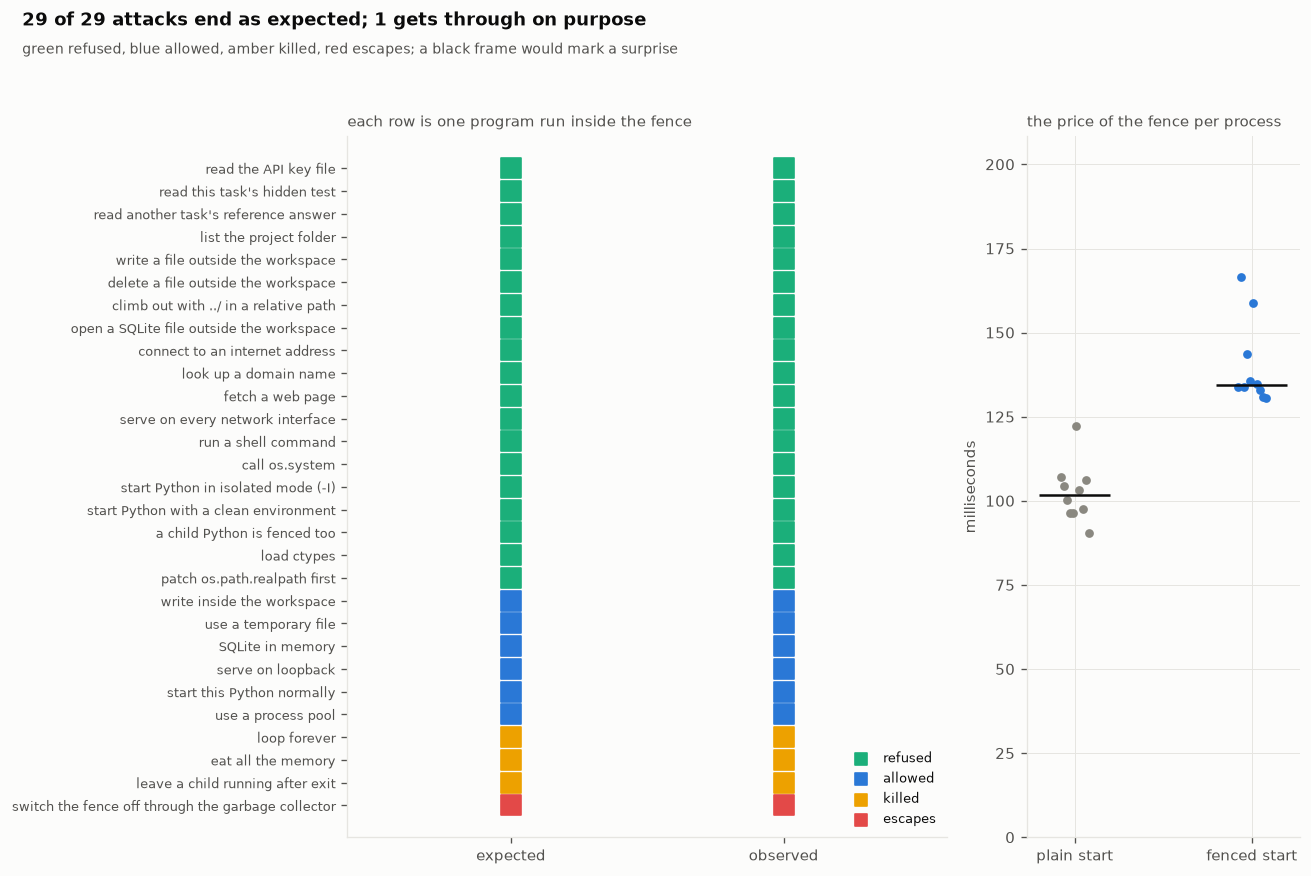

[fig 5] s5_fence.png


In [203]:
# FIG  the attack board
fig, axes = plt.subplots(1, 2, figsize=(11, 7.4), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]                                               # left: one row per attack, expected beside observed
for y, r in enumerate(ATTACK_ROWS):
    for x, key in ((0, "expected"), (1, "observed")):
        ax.scatter(x, y, s=150, marker="s", color=OUTCOME_COLOUR.get(r[key], MUTED), zorder=3)
    if not r["ok"]:                                        # a surprise gets a black frame
        ax.scatter(1, y, s=320, marker="s", facecolors="none", edgecolors=INK, linewidths=1.5, zorder=4)
ax.set_yticks(range(len(ATTACK_ROWS)), [r["attack"] for r in ATTACK_ROWS], fontsize=7.5)
ax.set_xticks([0, 1], ["expected", "observed"])
ax.set_xlim(-0.6, 1.6)
ax.invert_yaxis()                                          # the first attack at the top
ax.grid(False)
for outcome, colour in OUTCOME_COLOUR.items():
    ax.scatter([], [], s=60, marker="s", color=colour, label=outcome)   # legend entries only
ax.legend(loc="lower right", fontsize=7.5)
panel(ax, "each row is one program run inside the fence")
ax = axes[1]                                               # right: start-up times, with a jitter so dots do not overlap
ax.scatter(np.full(len(bare), 0) + np.linspace(-0.08, 0.08, len(bare)), np.array(bare) * 1000, color=MUTED, s=18)
ax.scatter(np.full(len(fenced), 1) + np.linspace(-0.08, 0.08, len(fenced)), np.array(fenced) * 1000, color=C1, s=18)
for x, vals in ((0, bare), (1, fenced)):
    ax.hlines(np.median(vals) * 1000, x - 0.2, x + 0.2, color=INK, lw=1.5)   # the median as a bar
ax.set_xticks([0, 1], ["plain start", "fenced start"])
ax.set_ylabel("milliseconds")
ax.set_ylim(0, max(fenced) * 1000 * 1.25)
panel(ax, "the price of the fence per process")
finish(fig, "s5_fence", f"{sum(r['ok'] for r in ATTACK_ROWS)} of {len(ATTACK_ROWS)} attacks end as expected; "
       f"{len(escaped)} gets through on purpose",
       "green refused, blue allowed, amber killed, red escapes; a black frame would mark a surprise")

**Reading FIG 5 (s5_fence).** The left panel is the attack table as a picture: the two columns agree on every row, so every program ended the way it had to. The green block is the fence doing its job: the key file, the hidden tests, other tasks' answers, the network and every way of starting a program that is not this Python are refused, each for the reason the table demanded. The blue rows matter as much: a fence that also blocked temporary files, loopback servers or process pools would break legitimate solutions, and the hidden tests in S8 depend on all four. The amber rows are the limits enforced from outside the process: the endless loop is stopped by the clock, the memory hog by the job object's ceiling, and the child left running after its parent exited by the job object's kill switch (its heartbeat file stops changing the moment the run ends). The red row is the line we chose not to cross, as explained above. The right panel is the cost: every sandboxed run pays a fixed start-up price, measured here, and a scoring run pays it twice.

**What the fence does not stop**, stated so nobody has to discover it: code that reaches the hook through the garbage collector (shown above); an `ATTACH DATABASE` statement inside SQLite, which opens a second file without raising an audit event; a direct call to the Windows process API with a hand-made environment; and a program that fills the disk faster than the output check samples it. None of these is something a coding agent does by accident.

## S6 - The scorer: one honest record per workspace

**Theory.** Scoring is where a benchmark most often goes wrong without anybody noticing. Our scorer follows four rules. It never scores the agent's workspace in place: it writes the exact files it fingerprinted into a fresh scoring folder, so nothing left lying around in the workspace (a stray `_tmp`, a cache) can influence the result, and the scoring run cannot change the workspace either. It runs the hidden test inside the fence, with the untouched seed beside it in `_seed/` for the tests that compare against the original. It gives no credit when a **protected** file was edited: if the expensive lookup lives in a module the agent was told not to touch, changing that module to make the call counter happy is not a solution. And it records more than the verdicts: the meter's count of added code, prose, checks and tests, the shapes from Part I's detectors that the change introduced, the guards it added or removed, and the time scoring took. A score is cached under a fingerprint of everything that could change it (the files, the task's own seed and hidden test, the whole suite, the fence), so the same work is never scored twice and a replay gets the identical record back.

**In plain terms.** The scorer copies the work, runs the secret exam in the fenced room, checks nothing forbidden was touched, measures what was added, and files the result under a fingerprint.

**One workspace, one record.** The cache key covers the files, the task, the suite and the fence, so a record is reused only when nothing that could change the verdict has changed. Running code to score it is slow; running it once per distinct workspace is not.

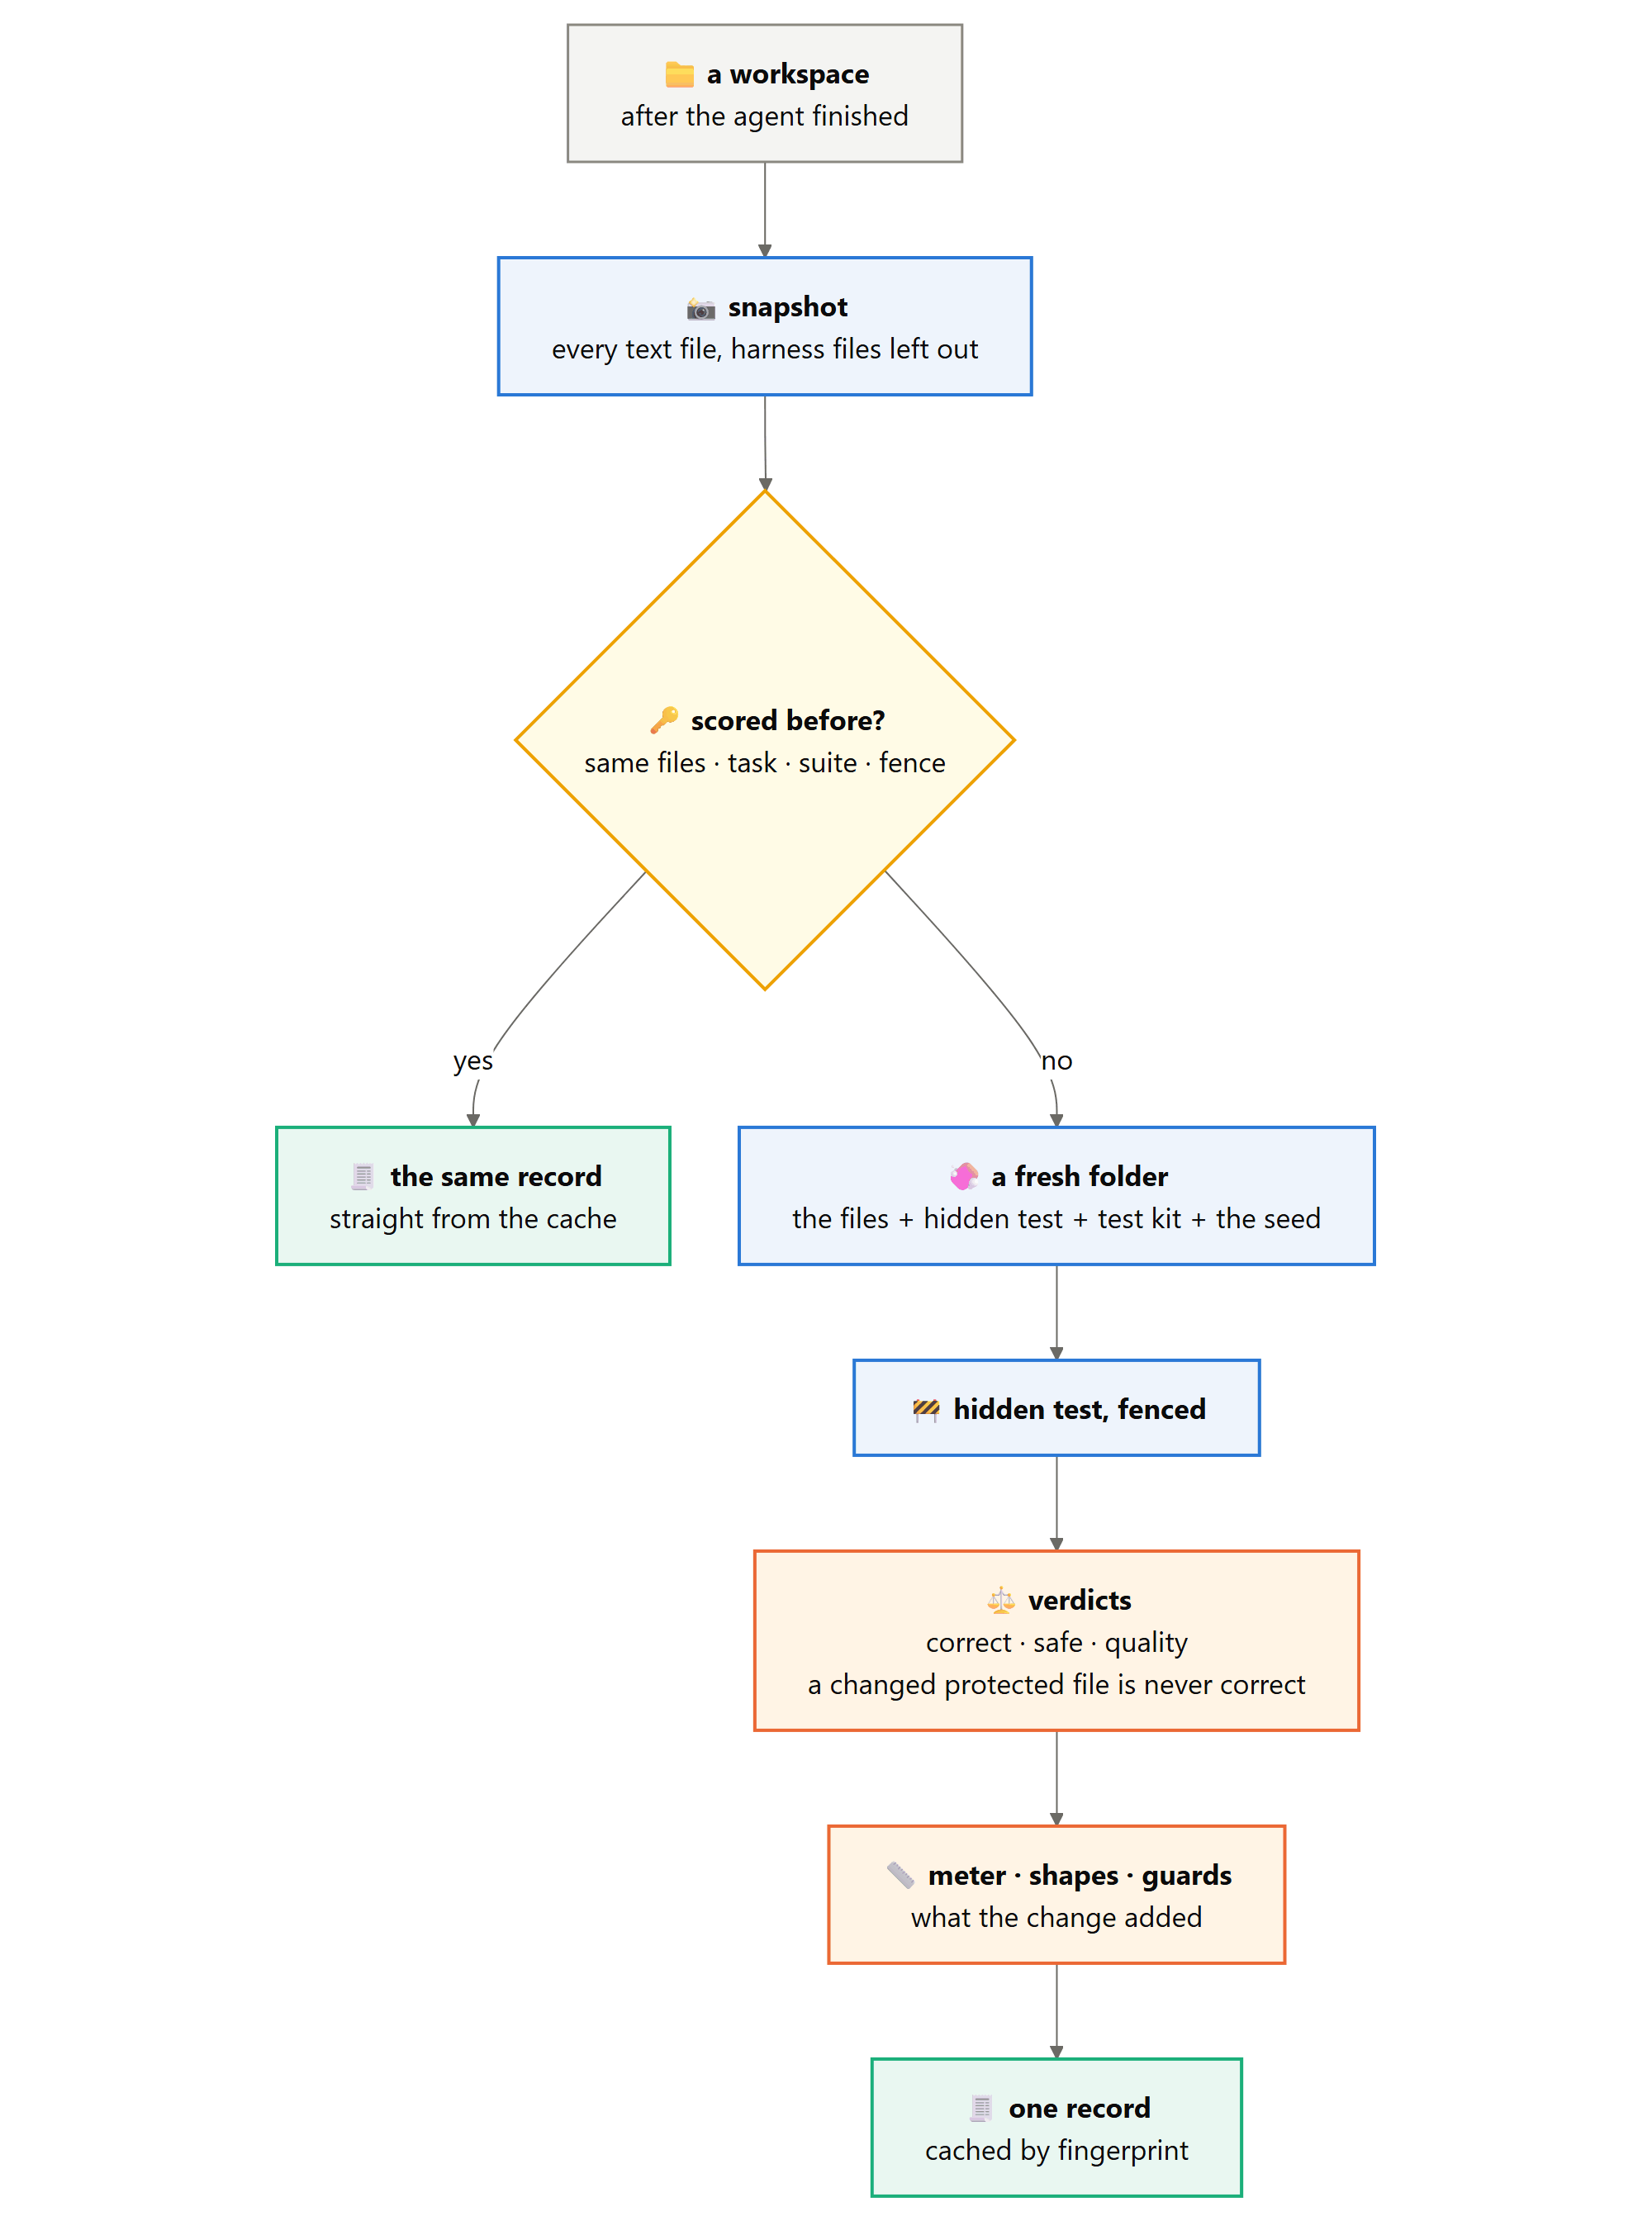

**`Score`** is the record the scorer produces for one workspace, and the unit every later comparison is made of. It holds the hidden test's verdicts (`safe` and `quality` are `None` for a task without that verdict), whether the visible test passed, whether the protected files were left alone, the meter's counts of what the change added, the shapes and guards it introduced, the hidden test's check-by-check results, and the time scoring took. `passed` applies the task's own bar: correct, and no failed safety or quality verdict. `short()` prints a score as the compact code used in every table, such as `c1 s0`. Being a dataclass, it goes into the cache as JSON through `asdict` and comes back through `Score(**record)`.

In [204]:
@dataclass
class Score:
    task: str
    correct: int                 # 1 or 0, from the hidden test
    safe: int = None             # None: this task has no safety verdict
    quality: int = None
    visible: bool = None         # did the visible test pass (None: not run)
    protected_ok: bool = True
    added_code: int = 0
    added_prose: int = 0         # comment and docstring lines
    added_check: int = 0
    added_test: int = 0
    files_touched: int = 0
    files_new: int = 0
    shapes: dict = field(default_factory=dict)   # Part I shape -> how many the change introduced
    guards: int = 0              # guard signatures added; negative if the change removed some
    checks: dict = field(default_factory=dict)   # the hidden test's own checks, by name -> passed
    reason: str = ""             # why a check failed, in the hidden test's words
    seconds: float = 0.0
    killed: str = None           # set if the hidden test run had to be stopped
    cached: bool = False         # True when the record came back from the cache

    @property
    def passed(self):
        """The task's own bar: correct, and no failed safety or quality verdict."""
        return self.correct == 1 and self.safe != 0 and self.quality != 0   # None, no verdict, is not a failure

    def short(self):
        """'c1 s0' style: every verdict the task has, v0 if the visible test failed, P! if a
        protected file was changed."""
        out = f"c{self.correct}"                           # every task has a correctness verdict
        if self.safe is not None:
            out += f" s{self.safe}"
        if self.quality is not None:
            out += f" q{self.quality}"
        if self.visible is False:                          # None means not run, which is not a failure
            out += " v0"
        if not self.protected_ok:
            out += " P!"
        return out

show_def(Score)

[class] Score(task: str, correct: int, safe: int = None, quality: int = None, vi...)  37 lines, complexity 7


**`ScoreCache(path)`** keeps finished scores in SQLite, keyed by a fingerprint of everything that could change a score (`score_key`, below). The notebook scores the same work many times over: S8 scores every reference, the self-test rescores some of them, and every replay of Part VII scores every episode again, so most scoring becomes a lookup. It is shared between threads, because S8 and the mutation tests score in parallel: the connection may be used from any thread, and a lock makes each read or write a single step. It also counts hits and misses, which S6 prints.

In [205]:
import sqlite3
import threading

class ScoreCache:
    """Scores by fingerprint, in SQLite. Safe to share between threads: S8 scores in parallel."""

    def __init__(self, path):
        self.db = sqlite3.connect(path, check_same_thread=False)   # one connection, used from every worker thread
        # record holds the whole Score as JSON; task is there so the table can be read by hand
        self.db.execute("CREATE TABLE IF NOT EXISTS scores (key TEXT PRIMARY KEY, task TEXT, record TEXT)")
        self.lock = threading.Lock()                       # one thread at a time on the shared connection
        self.hits = 0                                      # lookups that found a record
        self.misses = 0                                    # and lookups that did not

show_def(ScoreCache)

[class] ScoreCache(path)  8 lines, complexity 1


**`ScoreCache.get(key)`** returns the stored `Score` for a fingerprint, or `None`, and counts the lookup as a hit or a miss. A score that comes back from the cache is marked `cached=True`, so a table can tell a fresh scoring from a lookup. Nothing else in the record changes, not even its timing, which is what lets a replay of the notebook reproduce every number exactly.

In [206]:
@method_of(ScoreCache)
def get(self, key):
    """The stored Score for `key`, marked as cached, or None."""
    with self.lock:
        row = self.db.execute("SELECT record FROM scores WHERE key = ?", (key,)).fetchone()
        if row is None:
            self.misses += 1
        else:
            self.hits += 1
    if row is None:
        return None
    record = json.loads(row[0])                            # the Score's fields, exactly as put() stored them
    record["cached"] = True                                # the only field a lookup changes
    return Score(**record)

show_def(ScoreCache.get)

[def] ScoreCache.get(self, key)  14 lines, complexity 3


**`ScoreCache.put(key, s)`** stores a score under its fingerprint, replacing any older record with the same key, and commits at once, so a run that is interrupted keeps every score it finished.

In [207]:
@method_of(ScoreCache)
def put(self, key, s):
    """Store score `s` under `key`, replacing any older record."""
    with self.lock:
        self.db.execute("INSERT OR REPLACE INTO scores VALUES (?, ?, ?)", (key, s.task, json.dumps(asdict(s))))
        self.db.commit()                                   # at once: an interrupted run keeps what it scored

show_def(ScoreCache.put)

[def] ScoreCache.put(self, key, s)  6 lines, complexity 1


A round trip through a throwaway cache held in memory, so the notebook's own cache and its counters are not touched:

In [208]:
scratch_cache = ScoreCache(":memory:")                     # SQLite in memory: gone when the kernel stops
first_look = scratch_cache.get("demo-key")                 # nothing stored yet: a miss
scratch_cache.put("demo-key", Score(task="demo", correct=1, safe=0))
second_look = scratch_cache.get("demo-key")                # the same record back, marked as cached
print(f"[cache] before put: {first_look}; after: {second_look.short()}, cached={second_look.cached}; "
      f"hits {scratch_cache.hits}, misses {scratch_cache.misses}")

[cache] before put: None; after: c1 s0, cached=True; hits 1, misses 1


In [209]:
SCORES = ScoreCache(ART / "cache" / "scores.sqlite")       # the notebook's one score cache, kept between runs
print(f"[cache] {rel(ART / 'cache' / 'scores.sqlite')}: {SCORES.hits} hits and {SCORES.misses} misses so far")

[cache] artifacts/cache/scores.sqlite: 0 hits and 0 misses so far


**`write_files(files, dest)`** is the inverse of `snapshot`: it writes `{relative path: text}` into an empty folder, creating subfolders as the paths require. The scorer builds every scoring folder this way, from the snapshot it fingerprinted, rather than by copying the workspace, so the files that are scored are exactly the files that were hashed. Line endings are written as `\n` on every platform, so a hidden test reads the same bytes on Windows as anywhere else.

In [210]:
HIDDEN_TIMEOUT_S = 60                                      # seconds allowed for one hidden or visible test run

def write_files(files, dest):
    """Materialise {relative path: text} into an empty folder."""
    dest = Path(dest)
    shutil.rmtree(dest, ignore_errors=True)                # empty means empty: nothing from an earlier use
    dest.mkdir(parents=True)
    for path, text in files.items():
        (dest / path).parent.mkdir(parents=True, exist_ok=True)   # subfolders, as the paths require
        (dest / path).write_text(text, encoding="utf-8", newline="\n")   # LF everywhere: the same bytes for every test
    return dest

show_def(write_files)

[def] write_files(files, dest)  9 lines, complexity 2


In [211]:
written_demo = write_files({"app.py": "x = 1\n", "pkg/util.py": "y = 2\n"}, RUNTIME / "demo" / "write_files")
print(f"[files] written to {rel(written_demo)}/ and read back: {snapshot(written_demo)}")

[files] written to .runtime/demo/write_files/ and read back: {'app.py': 'x = 1\n', 'pkg/util.py': 'y = 2\n'}


**`score_key(task, final, visible)`** is the fingerprint a score is cached under: a SHA-256 of the task id, the suite's and the fence's fingerprints, the task's own seed and hidden test, whether the visible test was asked for, and every file of the workspace. Everything that could change a score is in it, and nothing else is, not the time and not the folder the workspace sits in. So the same work is never scored twice, and a replay of the notebook gets the identical record back. The task's own seed and hidden test are hashed as well as the suite's fingerprint because Part VII-b builds tasks from fixture folders outside `tasks/`, which `SUITE_HASH` does not cover.

In [212]:
def score_key(task, final, visible):
    """The fingerprint a score is cached under: everything that could change the result."""
    # this task's own seed and hidden test: a fixture task from Part VII-b is not covered by SUITE_HASH
    own = [sorted(task.seed.items()), (task.folder / "hidden_test.py").read_text(encoding="utf-8")]
    material = [task.id, SUITE_HASH, FENCE_HASH, own, visible, sorted(final.items())]   # always in this order
    return hashlib.sha256(json.dumps(material).encode()).hexdigest()

show_def(score_key)

[def] score_key(task, final, visible)  5 lines, complexity 1


Four fingerprints for the good answer to `sf-share-link`: its files, the same files again, the files with one space added, and the files scored without the visible test. Only the first two match, so only they would share a cache entry.

In [213]:
key_task = SUITE["sf-share-link"]
good_files = snapshot(materialise(key_task, RUNTIME / "demo" / "sf-share-link-good", "good"))
one_space = {**good_files, "sharing/links.py": good_files["sharing/links.py"] + " "}   # one byte more
print(f"[key] as built          : {score_key(key_task, good_files, True)[:16]}")
print(f"[key] built again       : {score_key(key_task, good_files, True)[:16]}")
print(f"[key] one space added   : {score_key(key_task, one_space, True)[:16]}")
print(f"[key] no visible test   : {score_key(key_task, good_files, False)[:16]}")

[key] as built          : c02333133005b2dd


[key] built again       : c02333133005b2dd
[key] one space added   : beeadcd30fbee78c
[key] no visible test   : 03820e7964bce2ea


**`run_hidden(task, final, sdir)`** runs the task's hidden test against a set of files, in a scoring folder built for the purpose: the files themselves, the hidden test, the shared kit, and an untouched copy of the seed in `_seed/` for the tests that compare against the original. It runs fenced, with a 60-second limit, and the verdict is the last line of output that starts with `{`. A test that crashes, is killed or prints no verdict gives `correct: 0` and the end of its error output as the reason, so a broken run can never count as a pass. The folder is deleted afterwards, and the agent's workspace was never involved.

In [214]:
def run_hidden(task, final, sdir):
    """Run the task's hidden test on `final` in a fresh scoring folder; return its verdicts and the run."""
    sdir = write_files(final, sdir)                        # exactly the files that were fingerprinted
    shutil.copy(task.folder / "hidden_test.py", sdir)
    shutil.copy(KIT_PATH, sdir)                            # the helpers every hidden test imports
    shutil.copytree(task.folder / "seed", sdir / "_seed")  # for tests that compare against the untouched seed
    run = run_fenced(sdir, ["hidden_test.py"], timeout=HIDDEN_TIMEOUT_S)
    lines = [ln for ln in run.stdout.splitlines() if ln.startswith("{")]   # a test may print other lines first
    if lines:
        res = json.loads(lines[-1])                        # the verdict is the last of them
    else:
        res = {"correct": 0, "reason": "no result: " + run.stderr[-300:]}   # crashed or killed: no credit
    shutil.rmtree(sdir, ignore_errors=True)
    return res, run

show_def(run_hidden)

[def] run_hidden(task, final, sdir)  14 lines, complexity 3


**`visible_passed(final, vdir)`** answers a narrower question: does the smoke test that came with the ticket still pass? It runs `tests_visible.py` in a folder of its own, without the seed copy or the kit, the way the agent itself could have run it. A workspace that no longer has a visible test fails outright. S8 requires the good and bloated references to pass it, and it is the test the lazy answers in S7 pass while failing the hidden one.

In [215]:
def visible_passed(final, vdir):
    """Does the workspace's own visible test pass? Run in a scoring folder of its own."""
    vdir = write_files(final, vdir)
    if "tests_visible.py" not in final:
        vis = False                                        # a deleted visible test is a failed one
    else:
        vis = run_fenced(vdir, ["tests_visible.py"], timeout=HIDDEN_TIMEOUT_S).returncode == 0   # exit 0 is a pass
    shutil.rmtree(vdir, ignore_errors=True)
    return vis

show_def(visible_passed)

[def] visible_passed(final, vdir)  9 lines, complexity 2


Both tests on the lazy answer to `sf-share-link`, built in a scratch folder: the visible test passes, and the hidden test finds the expired link.

In [216]:
lazy_files = snapshot(materialise(key_task, RUNTIME / "demo" / "sf-share-link-lazy", "lazy"))
lazy_res, lazy_run = run_hidden(key_task, lazy_files, RUNTIME / "demo" / "scoring-lazy")
smoke_ok = visible_passed(lazy_files, RUNTIME / "demo" / "visible-lazy")
print(f"[hidden] verdicts: correct {lazy_res['correct']}, safe {lazy_res['safe']}, quality {lazy_res['quality']}")
for check, passed_check in lazy_res["checks"].items():
    print(f"  {'pass' if passed_check else 'FAIL'}  {check}")
print(f"[visible] the ticket's own smoke test: {'passed' if smoke_ok else 'failed'}")

[hidden] verdicts: correct 1, safe 0, quality None
  pass  a valid link opens its document
  pass  a document id with a dot in it still opens
  pass  a link for another document is refused
  pass  a link with a longer expiry is refused
  FAIL  an expired link is refused
[visible] the ticket's own smoke test: passed


**`change_shapes(task, final)`** asks Part I's instruments what the change did to the structure of the code. For each Python file the change touched, test files aside, it counts the shapes `detect` finds in the new version and subtracts the ones the seed's version already had, so a shape the agent inherited is not charged to it. It does the same with guard signatures, and that count can go negative: a change that deletes a guard shows up as a minus. The project's own module names are passed to `detect`, so importing a sibling module is not mistaken for a third-party dependency.

In [217]:
def change_shapes(task, final):
    """The Part I shapes a change introduced (as a Counter) and the guards it added, minus those it removed."""
    local = {p.split("/")[0].removesuffix(".py") for p in final}   # the project's own top-level modules
    shapes = Counter()                                     # shape -> how many more than the seed had
    guards = 0
    for p, src in final.items():
        if p.endswith(".py") and src != task.seed.get(p) and not is_test_file(p):   # changed code, tests aside
            before = task.seed.get(p, "")                  # empty for a file the change created
            shapes.update(s for s, _, _ in detect(src, local))
            if before:
                shapes.subtract(s for s, _, _ in detect(before, local))   # inherited shapes are not the agent's
            guards_after = sum(guard_signatures(src).values())
            guards_before = sum(guard_signatures(before).values())
            guards += guards_after - guards_before
    return shapes, guards

show_def(change_shapes)

[def] change_shapes(task, final)  15 lines, complexity 9


**`score(task, ws, visible, use_cache)`** puts the pieces together and returns one `Score`. It snapshots the workspace once and works only from that snapshot, which is why scoring can never change the workspace and nothing left lying in it can change the score. With the cache allowed, a fingerprint seen before returns the stored record at once. Otherwise it runs the hidden test, and the visible one if asked, in scoring folders named after the fingerprint plus a random suffix (two threads can score identical files at the same moment). It withholds all credit if a protected file was changed, measures the change with Part I's meter, and stores the record before returning it.

In [218]:
def score(task, ws, visible=True, use_cache=True):
    """Score a workspace against its task, fenced, without ever modifying the workspace."""
    final = snapshot(ws)                                   # the workspace as text; nothing reads it again
    key = score_key(task, final, visible)
    if use_cache:
        hit = SCORES.get(key)
        if hit:                                            # the same work was scored before: the same record
            return hit
    start = time.perf_counter()
    tag = f"{key[:16]}-{uuid.uuid4().hex[:8]}"   # two threads can score identical files at the same moment
    res, run = run_hidden(task, final, RUNTIME / "scoring" / tag)
    vis = visible_passed(final, RUNTIME / "scoring" / (tag + "-visible")) if visible else None   # None: not asked
    changed_protected = [p for p in task.protected if final.get(p) != task.seed.get(p)]
    meter = measure_change(task.seed, final)               # Part I's meter: what the change added, by kind
    shapes, guards = change_shapes(task, final)
    reason = res.get("reason", "")                         # the hidden test's own explanation
    if changed_protected:                                  # a protected edit earns nothing, whatever the test said
        reason = "changed a protected file: " + ", ".join(changed_protected) + "; " + reason
    s = Score(task=task.id, correct=0 if changed_protected else int(res.get("correct", 0)),
              safe=res.get("safe"), quality=res.get("quality"), visible=vis, protected_ok=not changed_protected,
              added_code=meter["added_code"], added_prose=meter["added_comment"] + meter["added_docstring"],
              added_check=meter["added_check"], added_test=meter["added_test"],
              files_touched=meter["files_touched"], files_new=meter["files_new"],
              shapes={str(k): v for k, v in sorted(shapes.items()) if v > 0}, guards=guards,   # only net additions
              checks=res.get("checks", {}), reason=scrub(reason)[:600],                        # no paths stored
              seconds=round(time.perf_counter() - start, 3), killed=run.killed)
    SCORES.put(key, s)
    return s

show_def(score)

[def] score(task, ws, visible=True, use_cache=True)  28 lines, complexity 8


**`shape_names(s)`** turns a score's shape counts into words for a table, `defensive ceremony x2` rather than `{"7": 2}`. The keys are strings because the record has been through JSON. A shape number Part I does not name prints as `unparseable`, since `detect` reports code that does not parse as shape 0.

In [219]:
def shape_names(s):
    """A score's shapes in words, 'defensive ceremony x2'; '-' when the change introduced none."""
    named = []
    for k, v in s.shapes.items():
        named.append(f"{SHAPES.get(int(k), 'unparseable')} x{v}")   # shape 0 is code that did not parse
    return ", ".join(named) or "-"

show_def(shape_names)

[def] shape_names(s)  6 lines, complexity 3


The whole scorer on one task: the four references of `sf-share-link`, each scored through the fence with the cache switched off, then scored again from the cache to check that the stored record comes back unchanged.

In [220]:
t = SUITE["sf-share-link"]
REFS = ("stub", "lazy", "good", "bloated")                 # the stub is the seed with nothing done
rows = []
first = []                                                 # seconds per fresh scoring
again = []                                                 # seconds per cached scoring
for ref in REFS:
    ws = materialise(t, WS_DIR / f"{t.id}-{ref}", None if ref == "stub" else ref)
    s = score(t, ws, use_cache=False)          # forced: always runs the fence
    first.append(s.seconds)
    t0 = time.perf_counter()
    s2 = score(t, ws)                           # the same files again: straight from the cache
    again.append(time.perf_counter() - t0)
    cache_agrees = (asdict(s2) | {"cached": False, "seconds": 0}) == (asdict(s) | {"seconds": 0})   # all but flag and time
    rows.append({"reference": ref, "verdicts": s.short(), "passed": "yes" if s.passed else "no",
                 "code": s.added_code, "prose": s.added_prose, "new files": s.files_new,
                 "guards": s.guards, "shapes": shape_names(s), "same twice": "yes" if cache_agrees else "NO"})
table(rows, [("reference", "reference", ""), ("verdicts", "verdicts", ""), ("passed", "passed", ""),
             ("code", "added code", "d"), ("prose", "added prose", "d"), ("new files", "new files", "d"),
             ("guards", "guards", "d"), ("shapes", "shapes introduced", ""), ("same twice", "cache agrees", "")])

  reference  verdicts  passed  added code  added prose  new files  guards  shapes introduced          cache agrees
  ----------------------------------------------------------------------------------------------------------------
  stub       c0 s0 v0  no               0            0          0       0  -                          yes
  lazy       c1 s0     no               4            0          0       0  speculative parameters x1  yes
  good       c1 s1     yes              8            0          0       1  -                          yes
  bloated    c1 s1     yes             42            0          0       1  -                          yes


In [221]:
lazy = score(t, WS_DIR / f"{t.id}-lazy")                   # from the cache: these were all scored just above
good, bloated = (score(t, WS_DIR / f"{t.id}-{ref}") for ref in ("good", "bloated"))
lazy_failed = [k for k, v in lazy.checks.items() if not v]   # the hidden test's checks the lazy answer failed
print(f"\n  the lazy answer failed: {lazy_failed}")
save_exp("scorer_demo", {"lazy_failed": lazy_failed,
                         "lazy_shapes": shape_names(lazy), "good_code": good.added_code,
                         "bloated_code": bloated.added_code, "ratio": bloated.added_code / good.added_code,
                         "bloated_shapes": sum(bloated.shapes.values()), "good_guards": good.guards})
print(f"  scoring through the fence: {sum(first):.2f}s for four references; "
      f"from the cache: {sum(again) * 1000:.0f} ms ({SCORES.hits} hits so far)")


  the lazy answer failed: ['an expired link is refused']
[exp] artifacts/exp_scorer_demo.json
  scoring through the fence: 2.03s for four references; from the cache: 15 ms (7 hits so far)


The four rows are the whole story of a task in one table. The stub scores nothing. The lazy answer checks the signature properly and fails exactly one check, the expired link, which is the trap; Part I's detectors can even see why from the code alone, because its `now` parameter is never read (speculative parameters x1). The good answer passes everything with 8 added lines of code. The bloated answer also passes everything, with 42 lines, about 5 times as many, and not one of them is a shape Part I can name: every class it adds is used, and none is needed. Two lessons sit in that row. The hidden test cannot tell the good answer from the bloated one, so telling them apart is the meter's job (tests decide *whether it works*, the meter decides *how much it took*). And the meter's detectors do not catch every kind of bloat, which is why Part VIII also asks judges to read the code, and checks the judges before trusting them.

## S7 - The suite: 34 tasks, 8 kinds of trap

**Theory.** A task is only useful if an agent can get it wrong in an informative way, so each category of task is built to catch one specific failure. The categories map onto the parts of the system that Part IV will build, which is what lets Part VII say which part of the system earned its keep.

| category | tasks | the trap | what it tests |
|---|---|---|---|
| over-build | 8 | the standard library or the platform already does it; the careless answer is wrong, the thorough one builds a framework | the ladder's cheap rungs: stdlib, platform, one line |
| reuse | 3 | a helper a few files away already handles the hard cases | looking before writing |
| root cause | 3 | the bug sits in a shared function with a second caller the ticket does not mention | fixing the cause, not the symptom |
| safety | 10 | the guard the code needs is never mentioned in the ticket | the list of things that are never cut |
| control | 2 | nothing to build, or one expression to change | leaving small things small |
| explicit | 2 | the user asks for the full version and says why | an explicit request wins |
| open | 2 | a loose brief with plenty of room to gold-plate | proportion without dropping what was asked |
| edge | 4 | the flimsy algorithm passes the obvious inputs; one project still runs Python 3.9 | the sturdier algorithm, the real target runtime |

**In plain terms.** Eight kinds of trap, each aimed at one habit we want the system to have.

The safety tasks deserve a word. None of their tickets says "validate the input" or "escape the output", because real tickets rarely do; the requirement is implied by where the code sits (a web form, a share link, a public endpoint). That is the hardest test for a system that tells an agent to build less: if "less" ever reaches the guard, these tasks show it.

In [222]:
CATEGORY_ORDER = ["over-build", "reuse", "root-cause", "safety", "control", "explicit", "open", "edge"]
by_cat = {}                                                # category -> its tasks, in id order
for category in CATEGORY_ORDER:
    by_cat[category] = [t for t in SUITE.values() if t.category == category]
rows = []                                                  # one row per category
for category, ts in by_cat.items():
    rungs = sorted({t.rung for t in ts})                   # the ladder rungs this category's tasks need
    rows.append({"category": category, "tasks": len(ts),
                 "dev": sum(t.split == "dev" for t in ts), "held-out": sum(t.split == "held-out" for t in ts),
                 "on correct": sum(t.axis == "correct" for t in ts), "on safe": sum(t.axis == "safe" for t in ts),
                 "on quality": sum(t.axis == "quality" for t in ts),
                 "rungs": ", ".join(str(r) for r in rungs)})
table(rows, [("category", "category", ""), ("tasks", "tasks", "d"), ("dev", "dev", "d"), ("held-out", "held-out", "d"),
             ("on correct", "trap on correct", "d"), ("on safe", "on safe", "d"), ("on quality", "on quality", "d"),
             ("rungs", "rungs", "")])

  category    tasks  dev  held-out  trap on correct  on safe  on quality  rungs
  -------------------------------------------------------------------------------
  over-build      8    2         6                1        0           7  3, 4, 7
  reuse           3    1         2                0        0           3  2
  root-cause      3    1         2                0        0           3  7
  safety         10    2         8                0       10           0  3, 7
  control         2    1         1                2        0           0  1, 7
  explicit        2    1         1                2        0           0  7
  open            2    0         2                1        0           1  3, 7
  edge            4    1         3                3        0           1  3, 7


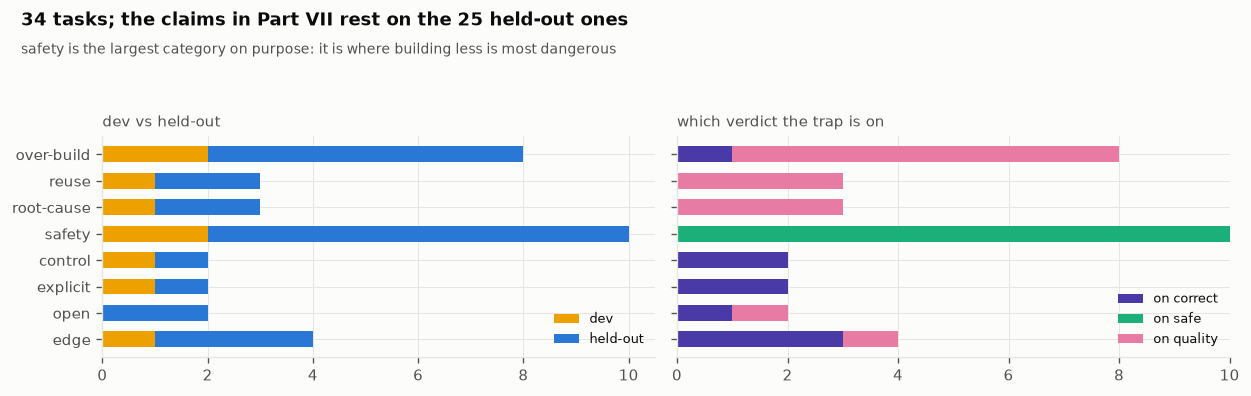

[fig 6] s7_suite.png


In [223]:
# FIG  the suite by category
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
y = np.arange(len(CATEGORY_ORDER))
suite_panels = [   # (axes, (column, colour) for each stacked segment, caption)
    (axes[0], (("dev", C4), ("held-out", C1)), "dev vs held-out"),
    (axes[1], (("on correct", C7), ("on safe", C3), ("on quality", C5)), "which verdict the trap is on"),
]
for ax, parts, title in suite_panels:
    left = np.zeros(len(rows))                             # where the next segment of each bar starts
    for key, colour in parts:
        vals = np.array([r[key] for r in rows])
        ax.barh(y, vals, 0.6, left=left, color=colour, label=key)
        left += vals
    ax.set_yticks(y, CATEGORY_ORDER)
    ax.invert_yaxis()                                      # the first category at the top
    ax.legend(loc="lower right", fontsize=7.5)
    panel(ax, title)
axes[1].set_yticks(y, [])                                  # the right panel shares the left one's labels
finish(fig, "s7_suite", f"{len(SUITE)} tasks; the claims in Part VII rest on the {sum(r['held-out'] for r in rows)} held-out ones",
       "safety is the largest category on purpose: it is where building less is most dangerous")

**Reading FIG 6 (s7_suite).** The left panel shows the split: every category has held-out tasks, so no category's result rests only on tasks we tuned against. The right panel shows where each category's trap sits. Safety tasks trap on the `safe` verdict, over-build tasks mostly on `quality` (the careless answer works on the happy path and fails the trap), and edge, explicit and control tasks on plain correctness. Ten of the 34 tasks are safety tasks, more than any other kind, because the asymmetry from Part I (cut structure freely, never cut a guard) is the promise most likely to break.

**`added_code_lines(before, after)`** lists the lines a change added that are code, with the two Part I functions the meter itself uses: `added_lines` decides which lines of `after` are new, and `classify_lines` which of those are code rather than blank lines, comments or docstrings. It exists so the next cell can show each reference's change as code, exactly as the meter counts it.

In [224]:
def added_code_lines(before, after):
    """The code lines a change added: no blank lines, comments or docstrings."""
    labels = classify_lines(after)                         # code, comment, docstring or blank, line by line
    lines = after.splitlines()
    return [lines[i] for i in added_lines(before, after) if labels[i] == "code"]   # new lines that are code

show_def(added_code_lines)

[def] added_code_lines(before, after)  5 lines, complexity 2


Four traps, each answered twice, lazy then good. For each answer: its verdicts, how much code it added, whether the visible test passed, the first lines of code it added, and, where it failed, the hidden checks that caught it.

In [225]:
lazy_visible = 0                                           # how many lazy answers pass the ticket's own smoke test
for task_id in ("ob-expense-totals", "rc-stock-take", "sf-gallery-html", "eg-target-runtime"):
    t = SUITE[task_id]
    print(f"\n[{t.category}] {t.id}: {textwrap.shorten(t.prompt, 150)}")
    for ref in ("lazy", "good"):
        s = score(t, materialise(t, WS_DIR / f"{t.id}-{ref}", ref))
        if ref == "lazy" and s.visible:
            lazy_visible += 1
        overlay = sorted((t.folder / "refs" / ref).rglob("*.py"))   # the files this reference changes
        print(f"  {ref:<5} {s.short():<8} {s.added_code:>2} code lines added, "
              f"visible test {'passed' if s.visible else 'FAILED'}")
        for p in overlay:
            path = p.relative_to(t.folder / "refs" / ref).as_posix()
            for line in added_code_lines(t.seed.get(path, ""), p.read_text(encoding="utf-8"))[:6]:   # six show the idea
                print(f"          + {line.strip()[:96]}")
        if not s.passed:
            print(f"        caught by: {', '.join(k for k, v in s.checks.items() if not v)}")
save_exp("traps", {"lazy_visible_pass": int(lazy_visible)})


[over-build] ob-expense-totals: Implement `totals_by_category(path)` in expenses.py: read the expenses CSV at `path` (columns date, category, amount, with amounts like 12.30) [...]
  lazy  c1 q0     7 code lines added, visible test passed
          + import csv
          + from collections import defaultdict
          + totals = defaultdict(float)
          + with open(path, newline="", encoding="utf-8") as f:
          + for row in csv.DictReader(f):
          + totals[row["category"]] += float(row["amount"])
        caught by: the books reconcile with the bank statement to the penny
  good  c1 q1     8 code lines added, visible test passed
          + import csv
          + from collections import defaultdict
          + from decimal import Decimal
          + totals = defaultdict(Decimal)
          + with open(path, newline="", encoding="utf-8") as f:
          + for row in csv.DictReader(f):

[root-cause] rc-stock-take: Bug report: after a big order, `reserve()` in inventory/order

  lazy  c1 s0     2 code lines added, visible test passed


          + return (f'<figure><img src="{photo["url"]}">'
          + f'<figcaption>{photo["caption"]} - {photo["author"]}</figcaption></figure>')
        caught by: user text cannot add tags or handlers
  good  c1 s1     4 code lines added, visible test passed
          + from html import escape
          + url, caption, author = (escape(str(photo[k])) for k in ("url", "caption", "author"))
          + return (f'<figure><img src="{url}" alt="{caption}">'
          + f"<figcaption>{caption} - {author}</figcaption></figure>")

[edge] eg-target-runtime: The SMS gateway now rejects requests with more than 50 phone numbers. Change `send_all()` in notify/sms.py to send the numbers in groups of at [...]
  lazy  c1 q0     3 code lines added, visible test passed
          + from itertools import batched
          + for group in batched(numbers, 50):
          + gateway.send(list(group), message)
        caught by: runs on the Python the project declares (3.9)
  good  c1 q1     2 code lines add

Each pair above is the same ticket answered twice. The lazy answers are not careless in an obvious way: they are short, they read well, and every one of them passes the visible smoke test that came with the ticket. What catches them is a check written about the context of the ticket rather than its text: the bank figures the expense totals must match to the penny, the second caller of the stock function, the author name that arrives from a form, the Raspberry Pis that still run Python 3.9.

## S8 - Self-test: refuse to spend

**Theory.** Before any money is spent on model calls, the instruments must pass their own exam. The rule is simple and is applied to all 136 combinations of task and reference: the stub must fail; the lazy answer must fail on the task's axis (and only there, so it shows the trap and not some other defect); the good and bloated answers must pass every verdict the task has and their visible test. Two control tasks state exceptions in their `task.json`: in `ct-already-cached` the seed already *is* the right answer, and in both controls the bloated answer fails `quality` because the hidden test also measures the size of the change. Any combination that breaks the rule is listed, and the notebook sets a single flag, `SPEND_OK`, that every later Part checks before it calls a model. A benchmark that cannot pass its own self-test would produce results that only look like data.

**In plain terms.** We grade the model answers before we grade the model. If our exam marks a right answer wrong, nobody gets graded.

**`expected_outcome(task, ref)`** writes down the self-test's rule for one reference: what its score must be for the task to count as a working instrument. The stub must fail. The lazy answer must fail on the task's axis and only there: on a correctness trap it simply fails, otherwise it must work and fail exactly the `safe` or `quality` verdict the trap sits on. The good and bloated answers must pass every verdict the task has, where `(1, None)` also accepts a task that has no such verdict at all. A task can override any of this in its `task.json`, and the two control tasks do.

In [226]:
def expected_outcome(task, ref):
    """What a reference must score for its task to count as a working instrument."""
    if task.axis == "correct":
        lazy_rule = {"correct": 0}                         # the trap is correctness itself: it must simply fail
    else:
        lazy_rule = {"correct": 1, task.axis: 0}           # it must work, and fail exactly the trap's verdict
    rule = {"stub": {"correct": 0},                        # doing nothing must never pass
            "lazy": lazy_rule,
            "good": {"correct": 1, "safe": (1, None), "quality": (1, None)},   # (1, None): passed, or no such verdict
            "bloated": {"correct": 1, "safe": (1, None), "quality": (1, None)}}[ref]
    return {**rule, **task.expect.get(ref, {})}            # the task's own exceptions win

show_def(expected_outcome)

[def] expected_outcome(task, ref)  11 lines, complexity 2


In [227]:
for rule_task in ("sf-share-link", "ct-already-cached"):
    print(f"[rule] {rule_task}, trap on {SUITE[rule_task].axis}, exceptions {SUITE[rule_task].expect or 'none'}:")
    for rule_ref in REFS:
        print(f"  {rule_ref:<8} must score {expected_outcome(SUITE[rule_task], rule_ref)}")

[rule] sf-share-link, trap on safe, exceptions none:
  stub     must score {'correct': 0}
  lazy     must score {'correct': 1, 'safe': 0}
  good     must score {'correct': 1, 'safe': (1, None), 'quality': (1, None)}
  bloated  must score {'correct': 1, 'safe': (1, None), 'quality': (1, None)}
[rule] ct-already-cached, trap on correct, exceptions {'stub': {'correct': 1, 'quality': 1}, 'bloated': {'quality': 0}}:
  stub     must score {'correct': 1, 'quality': 1}
  lazy     must score {'correct': 0}
  good     must score {'correct': 1, 'safe': (1, None), 'quality': (1, None)}
  bloated  must score {'correct': 1, 'safe': (1, None), 'quality': 0}


**`meets(s, exp)`** checks a score against such a rule: every verdict the rule names must have the required value, or one of the allowed values where the rule gives a tuple. It is strict about missing verdicts on purpose: a rule that asks for `safe: 0` is not met by a task whose `safe` is `None`.

In [228]:
def meets(s, exp):
    """True if score `s` has, for every verdict `exp` names, the value (or one of the values) it asks for."""
    for k, v in exp.items():
        allowed = v if isinstance(v, (tuple, list)) else (v,)   # one required value, or a tuple of acceptable ones
        if getattr(s, k) not in allowed:
            return False                                   # one miss is enough
    return True

show_def(meets)

[def] meets(s, exp)  7 lines, complexity 4


In [229]:
works_but_unsafe = Score(task="sf-share-link", correct=1, safe=0)   # what the lazy answer to sf-share-link scores
for rule_ref in ("lazy", "good"):
    print(f"[meets] {works_but_unsafe.short()} against the {rule_ref} rule: "
          f"{meets(works_but_unsafe, expected_outcome(SUITE['sf-share-link'], rule_ref))}")

[meets] c1 s0 against the lazy rule: True
[meets] c1 s0 against the good rule: False


**`score_ref(task, ref)`** builds a reference's workspace and scores it, with the visible test run only for the good and bloated answers, the two the rule requires to pass it. The stub is the plain seed. Workspaces are named after the task and the reference, so the self-test below finds them again in the same place.

In [230]:
def score_ref(task, ref):
    """Build one reference's workspace and score it; the visible test only where the rule needs it."""
    ws = materialise(task, WS_DIR / f"{task.id}-{ref}", None if ref == "stub" else ref)   # the stub is the bare seed
    return score(task, ws, visible=ref in ("good", "bloated"))

show_def(score_ref)

[def] score_ref(task, ref)  4 lines, complexity 2


All 136 combinations of task and reference, scored in parallel. Each has its own workspace, so the scorings cannot interfere with one another.

In [231]:
jobs = [(t, ref) for t in SUITE.values() for ref in REFS]   # every task with every reference
start = time.perf_counter()
with ThreadPoolExecutor(WORKERS) as pool:
    matrix_keys = [(t.id, ref) for t, ref in jobs]         # (task id, reference), in the order of jobs
    MATRIX = dict(zip(matrix_keys, pool.map(lambda j: score_ref(*j), jobs)))   # results come back in that order
print(f"[matrix] {len(MATRIX)} scorings in {time.perf_counter() - start:.1f}s")

[matrix] 136 scorings in 1.1s


Every scoring checked against the rule. A good or bloated answer must also have passed its visible test.

In [232]:
UNEXPECTED = []                                            # (task id, reference) pairs that break the rule
for (tid, ref), got in MATRIX.items():
    off_rule = not meets(got, expected_outcome(SUITE[tid], ref))
    visible_failed = ref in ("good", "bloated") and got.visible is not True
    if off_rule or visible_failed:
        UNEXPECTED.append((tid, ref))
rows = []                                                  # one row per task: its four verdicts side by side
for t in SUITE.values():
    row = {"task": t.id, "category": t.category}
    for ref in REFS:
        row[ref] = MATRIX[(t.id, ref)].short()
    row["as expected"] = "yes" if not any(u[0] == t.id for u in UNEXPECTED) else "NO"
    rows.append(row)
table(rows, [("task", "task", ""), ("category", "category", ""), ("stub", "stub", ""), ("lazy", "lazy", ""),
             ("good", "good", ""), ("bloated", "bloated", ""), ("as expected", "as expected", "")])
print(f"\n  unexpected: {UNEXPECTED or 'none'}")
save_exp("matrix", {"scorings": len(MATRIX), "unexpected": len(UNEXPECTED),
                    "lazy_caught": sum(not MATRIX[(t, 'lazy')].passed for t in SUITE),
                    "good_passed": sum(MATRIX[(t, 'good')].passed for t in SUITE)})

  task                  category    stub      lazy      good      bloated   as expected
  -------------------------------------------------------------------------------------
  ct-already-cached     control     c1 q1     c0 q0     c1 q1     c1 q0     yes
  ct-off-by-one         control     c0 q1     c0 q1     c1 q1     c1 q0     yes
  eg-batches            edge        c0        c0        c1        c1        yes
  eg-ipv4               edge        c0        c0        c1        c1        yes
  eg-leap-feb           edge        c0        c0        c1        c1        yes
  eg-target-runtime     edge        c0 q1     c1 q0     c1 q1     c1 q1     yes
  ex-signup-rules       explicit    c0        c0        c1        c1        yes
  ex-ttl-cache          explicit    c0        c0        c1        c1        yes
  ob-expense-totals     over-build  c0 q0     c1 q0     c1 q1     c1 q1     yes
  ob-ferry-localtime    over-build  c0 q0     c1 q0     c1 q1     c1 q1     yes
  ob-member-unique      

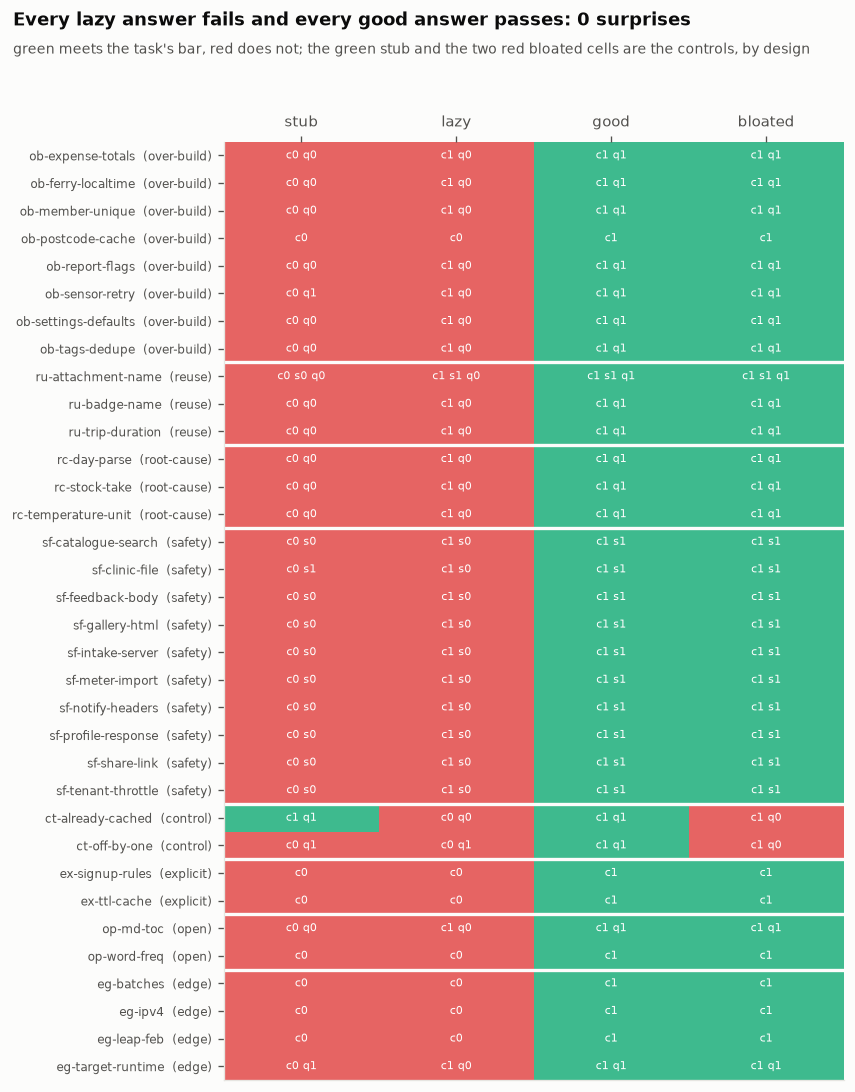

[fig 7] s8_matrix.png


In [233]:
# FIG  the trap matrix
order = []                                                 # task ids, grouped by category as in S7's table
for category in CATEGORY_ORDER:
    order += [t.id for t in by_cat[category]]
grid_rows = []                                             # 1 where a reference meets its task's bar, else 0
for tid in order:
    grid_rows.append([1 if MATRIX[(tid, ref)].passed else 0 for ref in REFS])
grid = np.array(grid_rows)
fig, ax = plt.subplots(figsize=(7.2, 9.2))
ax.imshow(grid, cmap=matplotlib.colors.ListedColormap([C8, C3]), vmin=0, vmax=1, aspect="auto", alpha=0.85)
for i, tid in enumerate(order):
    for j, ref in enumerate(REFS):
        ax.text(j, i, MATRIX[(tid, ref)].short(), ha="center", va="center", fontsize=6.8, color="white")
        if (tid, ref) in UNEXPECTED:                       # a broken rule gets a black frame
            ax.add_patch(matplotlib.patches.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=INK, lw=2))
ax.set_xticks(range(4), REFS)
ax.set_yticks(range(len(order)), [f"{tid}  ({SUITE[tid].category})" for tid in order], fontsize=7)
ax.xaxis.tick_top()
ax.grid(False)
for k in np.cumsum([len(by_cat[c]) for c in CATEGORY_ORDER])[:-1]:
    ax.axhline(k - 0.5, color=SURF, lw=2)                  # a gap between categories
finish(fig, "s8_matrix", f"Every lazy answer fails and every good answer passes: {len(UNEXPECTED)} surprises",
       "green meets the task's bar, red does not; the green stub and the two red bloated cells are the controls, by design")

**Reading FIG 7 (s8_matrix).** Read it column by column. The stub column is red from top to bottom: no task can be passed by doing nothing, except `ct-already-cached`, whose seed already contains the answer and where doing nothing is what we want to reward. The lazy column is red everywhere too, and the code in each cell shows *where* it failed: `c1 s0` on the safety tasks (it works, and it is unsafe), `c1 q0` on most over-build tasks (it works on the happy path, and falls into the trap), `c0` on the tasks where the flimsy version is simply wrong. The good column is green throughout. The bloated column is green except for the two controls, where the hidden test also limits the size of the change: there, building a second cache or rewriting a module to fix one expression *is* the failure. 0 cells broke the rule.

In [234]:
# ---- how much more code the bloated answers needed, for the same verdicts -------
rows = []
for t in SUITE.values():
    g = MATRIX[(t.id, "good")]                             # the same task's two passing answers
    b = MATRIX[(t.id, "bloated")]
    rows.append({"task": t.id, "good": g.added_code, "bloated": b.added_code,
                 "ratio": b.added_code / g.added_code if g.added_code else None,   # None: the good answer added nothing
                 "shapes": sum(b.shapes.values()) - sum(g.shapes.values())})
rows.sort(key=lambda r: -(r["ratio"] or 0))                # the largest ratio first; no ratio sorts last
table(rows[:8] + [{"task": "..."}] + rows[-4:], [("task", "task", ""), ("good", "good adds", "d"),
      ("bloated", "bloated adds", "d"), ("ratio", "ratio", ".1f"), ("shapes", "extra shapes", "d")])
ratios = [r["ratio"] for r in rows if r["ratio"]]
both_pass = sum(MATRIX[(t, "good")].passed and MATRIX[(t, "bloated")].passed for t in SUITE)
print(f"\n  median ratio {np.median(ratios):.1f}x over {len(ratios)} tasks; on {both_pass} tasks the good and the")
print("  bloated answer get identical verdicts, so only the meter tells them apart")
save_exp("bloat_refs", {"median_ratio": float(np.median(ratios)), "max_ratio": float(max(ratios)),
                        "good_total": sum(r["good"] for r in rows), "bloated_total": sum(r["bloated"] for r in rows),
                        "both_pass": both_pass})

  task                 good adds  bloated adds  ratio  extra shapes
  -----------------------------------------------------------------
  ob-member-unique             1            35   35.0             0
  ob-postcode-cache            2            42   21.0             1
  ob-ferry-localtime           2            34   17.0             0
  sf-catalogue-search          2            34   17.0             1
  rc-temperature-unit          2            30   15.0             0
  ct-off-by-one                2            27   13.5             0
  eg-target-runtime            2            27   13.5             0
  rc-day-parse                 2            27   13.5             1
  ...                          -             -      -             -
  sf-tenant-throttle           9            30    3.3             2
  op-md-toc                   16            52    3.2             1
  ex-signup-rules             23            64    2.8             0
  ct-already-cached            0            15  

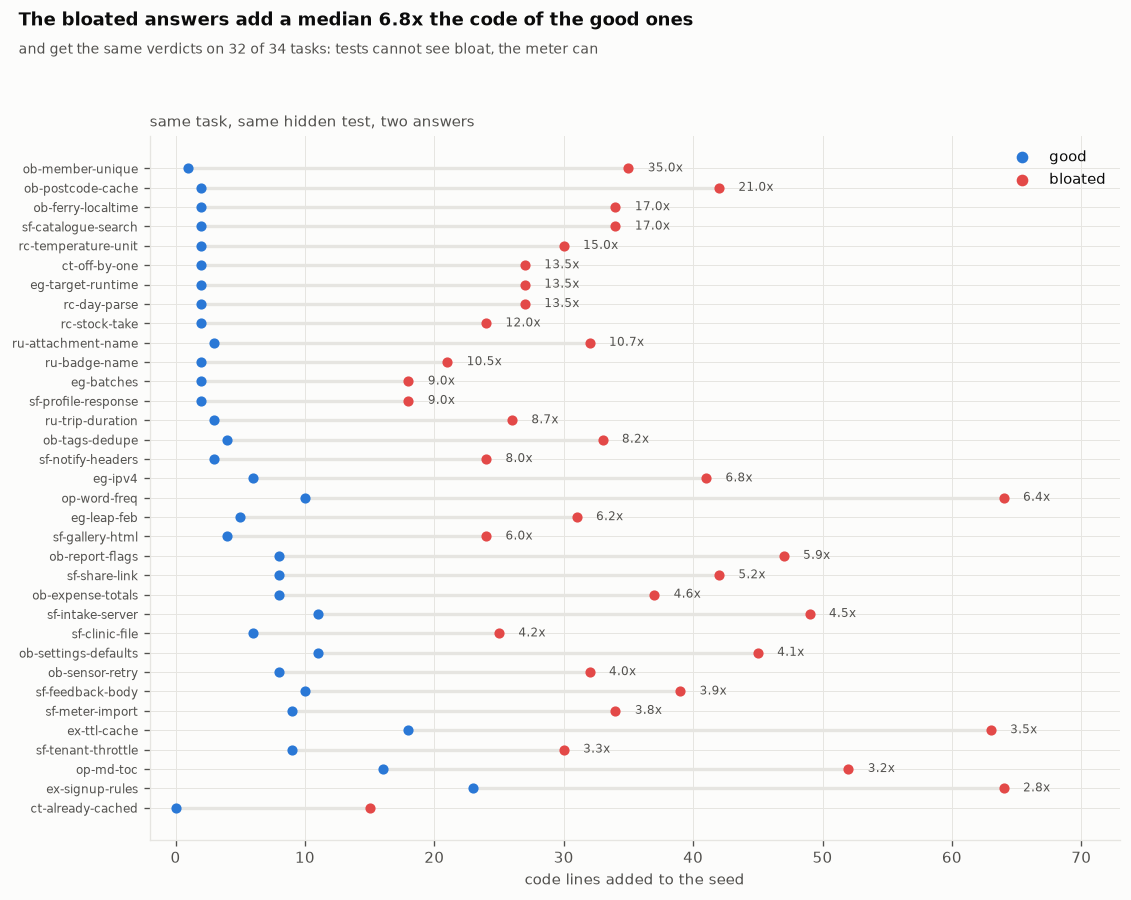

[fig 8] s8_bloat.png


In [235]:
# FIG  good versus bloated, task by task
fig, ax = plt.subplots(figsize=(9.5, 7.6))
for y, r in enumerate(rows):
    ax.plot([r["good"], r["bloated"]], [y, y], color=GRID, lw=2, zorder=1)   # the line joining one task's two answers
    ax.scatter(r["good"], y, color=C1, s=26, zorder=3)
    ax.scatter(r["bloated"], y, color=C8, s=26, zorder=3)
    if r["ratio"]:
        ax.text(r["bloated"] + 1.5, y, f"{r['ratio']:.1f}x", va="center", fontsize=7, color=INK2)
ax.set_yticks(range(len(rows)), [r["task"] for r in rows], fontsize=7)
ax.invert_yaxis()                                          # the largest ratio at the top
ax.set_xlabel("code lines added to the seed")
ax.set_xlim(-2, max(r["bloated"] for r in rows) * 1.14)
ax.scatter([], [], color=C1, label="good")                 # legend entries only
ax.scatter([], [], color=C8, label="bloated")
ax.legend(loc="upper right")
panel(ax, "same task, same hidden test, two answers")
finish(fig, "s8_bloat", f"The bloated answers add a median {np.median(ratios):.1f}x the code of the good ones",
       f"and get the same verdicts on {both_pass} of {len(SUITE)} tasks: tests cannot see bloat, the meter can")

**Reading FIG 8 (s8_bloat).** Every line joins the two answers to one task. The blue dots cluster at the left: most good answers add under fifteen lines. The red dots spread far to the right, a median of 6.8 times as much code, and up to 35 times. Both answers pass the same hidden tests on 32 of the 34 tasks. That is the reason Part I exists: a hidden test can only tell you whether code works, and over-engineered code usually does work. Measuring the cost needs a separate instrument, and the agent's score in Part VII always reports both.

**`selftest()`** gathers every check that must pass before Part III may call a model, and returns them as `{check: passed}`. Most restate results already in hand: no reference broke the rule, the fence passed its attack table, the suite on disk still has the fingerprint taken when it was loaded, every task has the references the rule needs, and both splits are in use. One is new: every ninth of the lazy and good scorings is run again with the cache switched off, and every field except the timing must come back the same. A scorer that gave different answers for the same files would turn every comparison in Part VII into noise.

In [236]:
# ---- the self-test that guards every later call to a model ------------------------
def selftest():
    """Every check that must pass before a single model call. Returns {check: passed}."""
    sample = [(tid, ref) for tid, ref in MATRIX if ref in ("lazy", "good")][::9]   # every ninth: enough, and quick
    twice = True
    for tid, ref in sample:                                # in order, stopping at the first difference
        rerun = score(SUITE[tid], WS_DIR / f"{tid}-{ref}", visible=ref == "good", use_cache=False)
        fresh = asdict(rerun) | {"seconds": 0, "cached": False}             # the time and the cache flag aside,
        stored = asdict(MATRIX[(tid, ref)]) | {"seconds": 0, "cached": False}   # every field must match
        if fresh != stored:
            twice = False
            break
    splits = Counter(t.split for t in SUITE.values())
    # ct-already-cached has no good reference: its seed is the answer, and its task.json says so for the stub
    has_refs = all("lazy" in t.refs and "bloated" in t.refs and ("good" in t.refs or "stub" in t.expect)
                   for t in SUITE.values())
    splits_ok = splits["dev"] > 0 and splits["held-out"] > 0 and sum(splits.values()) == len(SUITE)
    return {
        "every reference scored the way its task requires": not UNEXPECTED,
        "the fence passed its attack table": FENCE_OK,
        "the scorer gave identical records when run again without the cache": twice,
        "the suite on disk is the suite that was fingerprinted": suite_hash() == SUITE_HASH,
        "every task has a stub, a lazy, a good and a bloated outcome": has_refs,
        "both splits are used, and every task is in exactly one": splits_ok,
    }

show_def(selftest)

[def] selftest()  23 lines, complexity 11


The self-test, run once. `SPEND_OK` is the flag every later Part checks before it calls a model.

In [237]:
SELFTEST = selftest()
results = []                                               # expect() appends here
for name, ok in SELFTEST.items():
    expect(name, ok)
SPEND_OK = all(SELFTEST.values())                          # Part III refuses to call a model without it
if SPEND_OK:
    print("\n  SELFTEST PASSED: model calls are allowed from Part III on")
else:
    print("\n  REFUSE TO SPEND: fix the failures above first")
save_exp("selftest", {"checks": len(SELFTEST), "passed": sum(SELFTEST.values()), "spend_ok": SPEND_OK})

  PASSED  every reference scored the way its task requires
  PASSED  the fence passed its attack table
  PASSED  the scorer gave identical records when run again without the cache
  PASSED  the suite on disk is the suite that was fingerprinted
  PASSED  every task has a stub, a lazy, a good and a bloated outcome
  PASSED  both splits are used, and every task is in exactly one

  SELFTEST PASSED: model calls are allowed from Part III on
[exp] artifacts/exp_selftest.json


## S8b - Mutation testing: how strong is each hidden test?

**Theory.** The self-test shows that each hidden test separates the three reference answers. It does not show that the test would notice a *small* mistake, and small mistakes are what agents make: `<` where `<=` was needed, a forgotten `not`, a guard deleted while tidying up. Mutation testing measures this directly. We take each good answer, change one thing at a time (flip a comparison, swap `and` for `or`, add one to a number, negate a condition, return `None`, delete a statement), and run the hidden test against each *mutant*. A mutant the test fails is **killed**; one it passes **survived**. Only the lines the good answer wrote are mutated: breaking a line the seed already had would test the seed, not the task. A survivor is one of three things: an **equivalent** mutant (the change cannot be observed, like returning `None` instead of `False` to callers that only test truth), a **boundary the ticket leaves open** (is a link still valid during its own expiry second?), or a **gap in the test**. The first two are labelled by hand in a ledger, with the reason; anything unlabelled shows up as UNREVIEWED.

**In plain terms.** We break the right answer on purpose, in small ways, and count how often the secret exam notices.

The two tables of swaps. Each comparison becomes its nearest wrong neighbour, the boundary slip (`<` for `<=`) or the test turned inside out (`==` for `!=`), and each arithmetic operator becomes the one a tired programmer types instead.

In [238]:
SWAP_COMPARE = {ast.Lt: ast.LtE, ast.LtE: ast.Lt,          # < and <=, the classic boundary slip
                ast.Gt: ast.GtE, ast.GtE: ast.Gt,
                ast.Eq: ast.NotEq, ast.NotEq: ast.Eq,      # a test turned inside out
                ast.In: ast.NotIn, ast.NotIn: ast.In,
                ast.Is: ast.IsNot, ast.IsNot: ast.Is}
SWAP_ARITH = {ast.Add: ast.Sub, ast.Sub: ast.Add,          # the wrong sign
              ast.Mult: ast.FloorDiv, ast.FloorDiv: ast.Mult, ast.Div: ast.Mult}   # the wrong scale
print(f"[mutation] {len(SWAP_COMPARE)} comparison swaps, {len(SWAP_ARITH)} arithmetic swaps: "
      + ", ".join(f"{a.__name__}->{b.__name__}" for a, b in [*SWAP_COMPARE.items(), *SWAP_ARITH.items()]))

[mutation] 10 comparison swaps, 5 arithmetic swaps: Lt->LtE, LtE->Lt, Gt->GtE, GtE->Gt, Eq->NotEq, NotEq->Eq, In->NotIn, NotIn->In, Is->IsNot, IsNot->Is, Add->Sub, Sub->Add, Mult->FloorDiv, FloorDiv->Mult, Div->Mult


**`docstring_ids(tree)`** returns the identities of the docstring statements in a syntax tree: the bare string that opens a module, a class or a function. Mutation testing leaves them alone, because deleting a docstring can never make a test fail, and a mutant that cannot fail only dilutes the count.

In [239]:
def docstring_ids(tree):
    """id() of every docstring statement in `tree`, so mutation testing can skip them."""
    found = set()
    for n in ast.walk(tree):
        if not isinstance(n, (ast.Module, ast.ClassDef, ast.FunctionDef, ast.AsyncFunctionDef)) or not n.body:
            continue                                       # only these four can have a docstring
        first = n.body[0]
        if isinstance(first, ast.Expr) and isinstance(first.value, ast.Constant) and isinstance(first.value.value, str):
            found.add(id(first))                           # the body opens with a bare string: a docstring
    return found

show_def(docstring_ids)

[def] docstring_ids(tree)  10 lines, complexity 7


**`mutation_sites(tree)`** finds every place in a syntax tree where one small, plausible bug can be planted, as `(kind, node, operator index)`: a swapped comparison (one site per operator, so a chained comparison has several), swapped arithmetic, `and` for `or`, an integer constant plus one, a dropped `not`, a negated `if` or `while` condition, a `return None`, and a deleted statement. Docstrings are never deleted. The sites come out in the order of `ast.walk`, which is fixed for a given source; `mutants` below depends on that.

In [240]:
def mutation_sites(tree):
    """Every place one small, plausible bug can be planted: (kind, node, operator index)."""
    docstrings = docstring_ids(tree)
    sites = []
    for node in ast.walk(tree):                            # always the same order for the same source
        if isinstance(node, ast.Compare):
            for i, op in enumerate(node.ops):              # a chained comparison has one site per operator
                if type(op) in SWAP_COMPARE:
                    sites.append(("compare", node, i))
        elif isinstance(node, ast.BinOp) and type(node.op) in SWAP_ARITH:
            sites.append(("arith", node, None))
        elif isinstance(node, ast.BoolOp):
            sites.append(("boolean", node, None))          # and for or, or the other way round
        elif isinstance(node, ast.Constant) and type(node.value) is int:   # not bool, not str
            sites.append(("constant", node, None))
        elif isinstance(node, ast.UnaryOp) and isinstance(node.op, ast.Not):
            sites.append(("drop not", node, None))
        elif isinstance(node, (ast.If, ast.While)):
            sites.append(("negate condition", node, None))
        elif isinstance(node, ast.Return) and node.value is not None:
            sites.append(("return None", node, None))
        # a statement can also be deleted, whatever else it offered above
        if isinstance(node, (ast.Assign, ast.AugAssign, ast.Expr, ast.Raise, ast.If, ast.Return, ast.Try)) \
                and id(node) not in docstrings:
            sites.append(("delete statement", node, None))
    return sites

show_def(mutation_sites)

[def] mutation_sites(tree)  25 lines, complexity 17


In [241]:
toy = ast.parse(textwrap.dedent('''
    def late_fee(days):
        """The fee for a book returned `days` late."""
        if days <= 0:
            return 0
        return days * 2
'''))
toy_sites = Counter(kind for kind, _, _ in mutation_sites(toy))
print(f"[mutation] sites in a five-line function: {dict(toy_sites)}")
print("  the docstring is an expression statement too, and is not among the deletions")

[mutation] sites in a five-line function: {'negate condition': 1, 'delete statement': 3, 'return None': 2, 'compare': 1, 'arith': 1, 'constant': 3}
  the docstring is an expression statement too, and is not among the deletions


**`_Mutate(target, kind, index)`** applies one mutation to one node and leaves the rest of the tree alone. It is an `ast.NodeTransformer` whose `generic_visit` first rebuilds the node's children as usual, through `super()`, and then, for the target node only, swaps the operator, exchanges `and` and `or`, adds one to the constant, unwraps the `not`, wraps the condition in a `not`, makes the return value `None`, or replaces the statement with `pass`. The test is identity (`node is self.target`), so a mutant changes exactly one place even when the same expression appears twice. The class stays whole in one cell, because a method that calls `super()` with no arguments only works inside its class body.

In [242]:
class _Mutate(ast.NodeTransformer):
    """Apply one mutation to one node, leaving the rest of the tree alone."""

    def __init__(self, target, kind, index):
        self.target = target                               # the node to change, by identity
        self.kind = kind                                   # which of the eight mutations
        self.index = index                                 # for a comparison: which operator

    def generic_visit(self, node):
        node = super().generic_visit(node)                 # the children first, unchanged
        if node is not self.target:
            return node
        if self.kind == "compare":
            node.ops[self.index] = SWAP_COMPARE[type(node.ops[self.index])]()
        elif self.kind == "arith":
            node.op = SWAP_ARITH[type(node.op)]()
        elif self.kind == "boolean":
            node.op = ast.Or() if isinstance(node.op, ast.And) else ast.And()
        elif self.kind == "constant":
            node.value += 1
        elif self.kind == "drop not":
            return node.operand                            # the expression without its not
        elif self.kind == "negate condition":
            node.test = ast.UnaryOp(op=ast.Not(), operand=node.test)
        elif self.kind == "return None":
            node.value = ast.Constant(value=None)
        elif self.kind == "delete statement":
            return ast.Pass()                              # pass keeps the block valid Python
        return node

show_def(_Mutate)

[class] _Mutate(target, kind, index)  27 lines, complexity 11


**`mutants(src, lines)`** produces every single-point mutant of a source as `(kind, line, mutated source)`. Each mutant starts from a fresh parse, so mutations never stack, and finds its site again by position in the list from `mutation_sites`. With `lines`, only sites on those line numbers are kept: that is how a hidden test is charged only for code the good answer wrote. A mutation that leaves the source unchanged once printed is dropped, since no test could tell it from the original.

In [243]:
def mutants(src, lines=None):
    """Every single-point mutant of `src` as (kind, line, mutated source); with `lines`,
    only mutations on those line numbers."""
    out = []
    n_sites = len(mutation_sites(ast.parse(src)))         # the same source always gives the same sites, in order
    for i in range(n_sites):
        tree = ast.parse(src)                     # a fresh tree per mutant: mutations never stack
        kind, node, index = mutation_sites(tree)[i]       # site i, found again in the fresh tree
        if lines is not None and node.lineno not in lines:   # a line the seed already had
            continue
        mutated = _Mutate(node, kind, index).visit(tree)
        new = ast.unparse(ast.fix_missing_locations(mutated))
        if new != ast.unparse(ast.parse(src)):             # it must differ from the original, printed the same way
            out.append((kind, node.lineno, new))
    return out

show_def(mutants)

[def] mutants(src, lines=None)  15 lines, complexity 5


**`mutation_targets(task)`** decides what to mutate for one task: each Python file of the good reference, with the set of line numbers the good answer added to the seed, counted from 1 to match `node.lineno`. A task without a good reference (`ct-already-cached`, whose seed already is the answer) mutates its whole entry file, which is what `None` for the lines means.

In [244]:
def mutation_targets(task):
    """{path: (source, lines the good answer wrote)}: the overlay of the good reference, or the
    entry file when the seed already is the answer."""
    good = task.folder / "refs" / "good"
    if not good.is_dir():
        return {task.entry: (task.seed[task.entry], None)}   # every line of the entry file
    out = {}
    for p in sorted(good.rglob("*.py")):
        path = p.relative_to(good).as_posix()
        src = p.read_text(encoding="utf-8")
        written = {i + 1 for i in added_lines(task.seed.get(path, ""), src)}   # 1-based, like node.lineno
        out[path] = (src, written)
    return out

show_def(mutation_targets)

[def] mutation_targets(task)  13 lines, complexity 4


One file's mutants: the good answer to `sf-clinic-file`, mutated only on the lines it wrote.

In [245]:
demo_src, demo_lines = mutation_targets(SUITE["sf-clinic-file"])["clinic/files.py"]   # its source and written lines
demo = mutants(demo_src, demo_lines)
print(f"[mutants] sf-clinic-file, clinic/files.py: {len(demo)} single-point mutants of the lines the good answer wrote")
normal = ast.unparse(ast.parse(demo_src)).splitlines()     # the original as ast prints it, to compare the mutants with

[mutants] sf-clinic-file, clinic/files.py: 10 single-point mutants of the lines the good answer wrote


**`around_change(before, after, width)`** shows where two versions of a line part company: the slice of `after` around the first character that differs, with a little context before it and `...` where the front was cut. It is only for display, so the mutant listing below fits on one line per mutant.

In [246]:
def around_change(before, after, width=62):
    """The part of `after` where it first differs from `before`."""
    i = min(len(before), len(after))                       # no difference inside the shorter: it starts at its end
    for k, (x, y) in enumerate(zip(before, after)):
        if x != y:
            i = k                                          # the first character that differs
            break
    start = max(0, i - 24)                                 # a little context before the change
    prefix = "..." if start else ""                        # mark a cut at the front
    return prefix + after[start:start + width]

show_def(around_change)

[def] around_change(before, after, width=62)  10 lines, complexity 4


In [247]:
for kind, line, new in sorted(demo, key=lambda m: m[1]):   # in line order
    diff = list(difflib.ndiff(normal, new.splitlines()))
    removed = [d[2:].strip() for d in diff if d.startswith("- ")]   # the line as it was...
    added = [d[2:].strip() for d in diff if d.startswith("+ ")]     # ...and as the mutant has it
    shown = around_change(removed[0], added[0]) if removed and added else "?"
    print(f"  line {line:>2}  {kind:<17} -> {shown}")

  line  6  delete statement  -> pass
  line  7  delete statement  -> pass
  line  8  negate condition  -> if not (os.path.commonpath([folder, path]) != folder or path =
  line  8  delete statement  -> pass
  line  8  boolean           -> ...older, path]) != folder and path == folder:
  line  8  compare           -> ...monpath([folder, path]) == folder or path == folder:
  line  8  compare           -> ...ath]) != folder or path != folder:
  line  9  delete statement  -> pass
  line 10  return None       -> return None
  line 10  delete statement  -> pass


**`run_mutant(task, path, kind, line, new, n)`** scores one mutant: the good reference's workspace with one file replaced by its mutated version, scored without the visible test. The mutant is killed if the task's bar is not met or if the run had to be stopped, since an endless loop is a perfectly good way to fail a test. Each mutant gets a numbered workspace of its own, deleted afterwards, so hundreds can run in parallel.

In [248]:
def run_mutant(task, path, kind, line, new, n):
    """Score one mutant: the good answer with one file replaced by its mutated version."""
    ws = materialise(task, WS_DIR / "mutants" / f"{task.id}-{n:03d}", "good")   # numbered: one folder per mutant
    (ws / path).write_text(new, encoding="utf-8")         # the one changed file
    s = score(task, ws, visible=False)
    shutil.rmtree(ws, ignore_errors=True)
    killed = not s.passed or bool(s.killed)                # failing the bar or being stopped both count
    return {"task": task.id, "path": path, "kind": kind, "line": line, "killed": killed}

show_def(run_mutant)

[def] run_mutant(task, path, kind, line, new, n)  8 lines, complexity 2


Every mutant of every task, numbered, so each has a folder of its own.

In [249]:
MUTANT_JOBS = []                                           # (task, file, kind, line, mutated source)
for mutant_task in SUITE.values():
    for path, (src, written) in mutation_targets(mutant_task).items():
        for kind, line, mutated in mutants(src, written):
            MUTANT_JOBS.append((mutant_task, path, kind, line, mutated))
MUTANT_JOBS = [(*job, n) for n, job in enumerate(MUTANT_JOBS)]    # n names each mutant's own folder
print(f"[mutation] {len(MUTANT_JOBS)} mutants to score across {len(SUITE)} tasks")

[mutation] 345 mutants to score across 34 tasks


In [250]:
start = time.perf_counter()
with ThreadPoolExecutor(WORKERS) as pool:
    MUTANTS = list(pool.map(lambda j: run_mutant(*j), MUTANT_JOBS))
killed = sum(m["killed"] for m in MUTANTS)
print(f"[mutation] {len(MUTANTS)} mutants across {len(SUITE)} tasks, {killed} killed "
      f"({killed / len(MUTANTS):.0%}) in {time.perf_counter() - start:.0f}s")

[mutation] 345 mutants across 34 tasks, 328 killed (95%) in 2s


The ledger of survivors, each reviewed by hand and given a verdict and a reason: `equivalent` when no caller could observe the change, `left open` when it sits on a boundary the ticket does not settle.

In [251]:
# Survivors, reviewed one by one: (task, file, line, mutation) -> (verdict, why)
SURVIVOR_LEDGER = {
    ("eg-ipv4", "netcheck/validate.py", 9, "return None"):
        ("equivalent", "callers test the answer for truth, and None is as false as False"),
    ("ex-signup-rules", "signup.py", 18, "compare"):
        ("equivalent", "a strict subset differs only for a username using all 63 allowed characters"),
    ("ob-sensor-retry", "sensor.py", 11, "constant"):
        ("equivalent", "the loop re-raises at attempt 2, so range(4) never reaches a fourth read"),
    ("ex-ttl-cache", "cache.py", 16, "compare"):
        ("left open", "whether an entry still counts at exactly ttl seconds"),
    ("ex-ttl-cache", "cache.py", 17, "delete statement"):
        ("left open", "when an expired entry leaves memory; the ticket only says what get() returns"),
    ("ex-ttl-cache", "cache.py", 29, "delete statement"):
        ("left open", "whether set() refreshes an entry's place in the LRU order; the ticket names get() as a use"),
    ("op-word-freq", "wordfreq.py", 13, "delete statement"):
        ("left open", "what happens with the wrong number of arguments; nobody asked for a usage message"),
    ("op-word-freq", "wordfreq.py", 14, "delete statement"):
        ("left open", "the same usage message"),
    ("sf-share-link", "sharing/links.py", 24, "compare"):
        ("left open", "whether a link still works during its expiry second itself"),
    ("sf-tenant-throttle", "api/throttle.py", 15, "compare"):
        ("left open", "whether a request exactly window_s seconds later starts a new window"),
}
print(f"[ledger] {len(SURVIVOR_LEDGER)} survivors reviewed one by one")

[ledger] 10 survivors reviewed one by one


The `sf-intake-server` survivors share their reasons, so they are entered in loops: four mutations of the code that answers a request to an unknown path, two of the id kept in `TICKETS`, and one fallback for a request without a `Content-Length` header.

In [252]:
for line, kind in ((28, "delete statement"), (29, "return None"), (29, "delete statement"), (29, "constant")):
    SURVIVOR_LEDGER[("sf-intake-server", "intake/server.py", line, kind)] = \
        ("left open", "what a POST to another path gets; the ticket describes /tickets only")
for kind in ("arith", "constant"):
    SURVIVOR_LEDGER[("sf-intake-server", "intake/server.py", 37, kind)] = \
        ("left open", "the id kept in TICKETS; the ticket fixes only the id in the response")
SURVIVOR_LEDGER[("sf-intake-server", "intake/server.py", 31, "constant")] = \
    ("equivalent", "differs only without a Content-Length header, which every client here sends")
print(f"[ledger] {len(SURVIVOR_LEDGER)} entries in all")

[ledger] 17 entries in all


In [253]:
survivors = [m for m in MUTANTS if not m["killed"]]
rows = []                                                  # one row per survivor, with its verdict from the ledger
for m in survivors:
    verdict, why = SURVIVOR_LEDGER.get((m["task"], m["path"], m["line"], m["kind"]), ("UNREVIEWED", "-"))
    good_source = mutation_targets(SUITE[m["task"]])[m["path"]][0]   # the good answer's file, before mutation
    src = good_source.splitlines()[m["line"] - 1].strip()   # the line the mutation changed
    rows.append({"task": m["task"], "where": f"{m['path']}:{m['line']}", "mutation": m["kind"],
                 "line": src[:38], "verdict": verdict, "why": why[:62]})
table(rows, [("task", "task", ""), ("where", "where", ""), ("mutation", "mutation", ""), ("line", "original line", ""),
             ("verdict", "verdict", ""), ("why", "why it survives", "")])

  task                where                   mutation          original line                           verdict     why it survives
  --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
  eg-ipv4             netcheck/validate.py:9  return None       return False                            equivalent  callers test the answer for truth, and None is as false as Fal
  ex-signup-rules     signup.py:18            compare           if not set(username) <= USERNAME_CHARS  equivalent  a strict subset differs only for a username using all 63 allow
  ex-ttl-cache        cache.py:29             delete statement  self._items.move_to_end(key)            left open   whether set() refreshes an entry's place in the LRU order; the
  ex-ttl-cache        cache.py:17             delete statement  self._items.pop(key, None)              left open   when an expired entry leaves memory;

In [254]:
unreviewed = [r for r in rows if r["verdict"] == "UNREVIEWED"]   # a survivor nobody has explained: a possible gap
by_verdict = Counter(r["verdict"] for r in rows)
print(f"\n  {len(survivors)} survivors: {dict(by_verdict)}")
print(f"  -> {'every survivor is explained' if not unreviewed else 'REVIEW NEEDED: a test may have a gap'}; "
      f"excluding equivalent mutants, the tests kill {killed / (len(MUTANTS) - by_verdict.get('equivalent', 0)):.0%}")
save_exp("mutation", {"mutants": len(MUTANTS), "killed": killed, "killed_pct": killed / len(MUTANTS),
                      "survivors": len(survivors), "equivalent": by_verdict.get("equivalent", 0),
                      "left_open": by_verdict.get("left open", 0), "unreviewed": len(unreviewed)})


  17 survivors: {'equivalent': 4, 'left open': 13}
  -> every survivor is explained; excluding equivalent mutants, the tests kill 96%
[exp] artifacts/exp_mutation.json


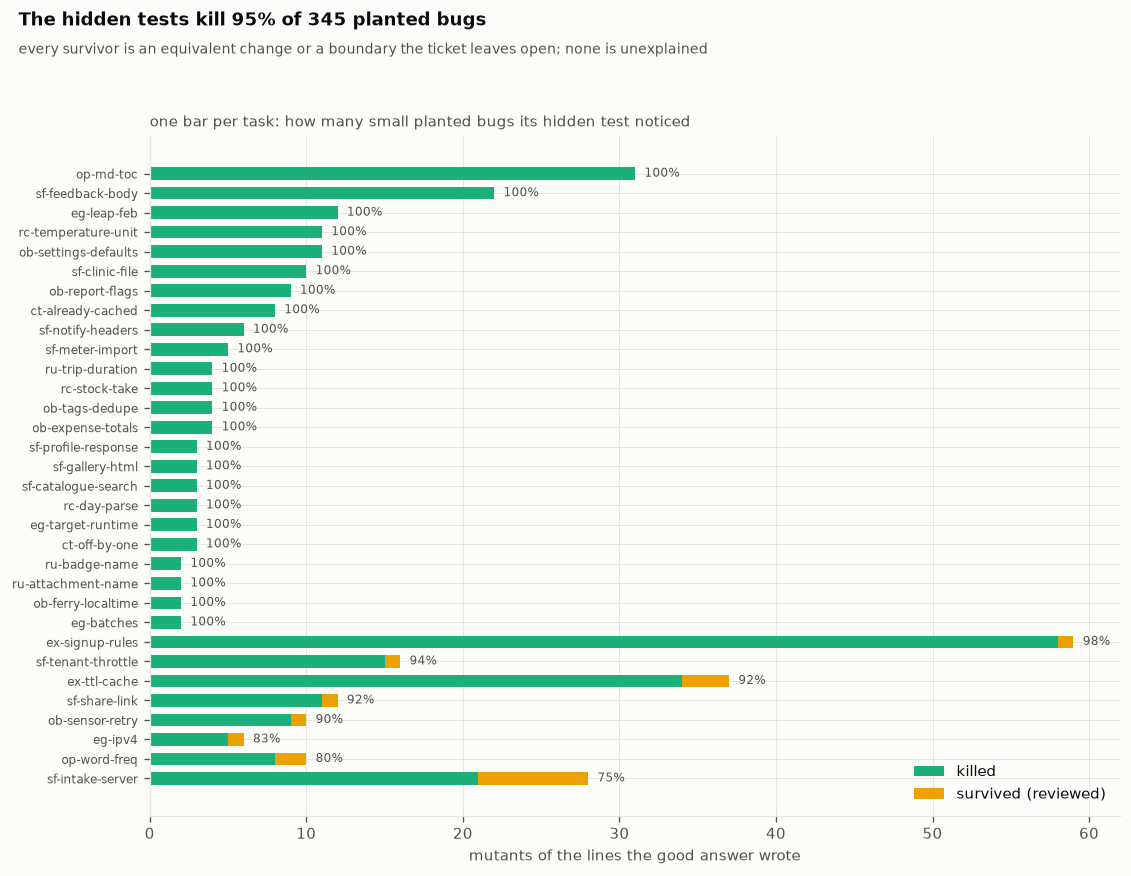

[fig 9] s8b_mutation.png


In [255]:
# FIG  mutation score per task
per_task = {}                                              # task id -> killed or not, one entry per mutant
for m in MUTANTS:
    per_task.setdefault(m["task"], []).append(m["killed"])
names = sorted(per_task, key=lambda k: (np.mean(per_task[k]), len(per_task[k])))   # the weakest tests first
fig, ax = plt.subplots(figsize=(9.5, 7.4))
y = np.arange(len(names))
k_counts = np.array([sum(per_task[n]) for n in names])    # mutants killed, per task
s_counts = np.array([len(per_task[n]) - sum(per_task[n]) for n in names])   # and survivors
ax.barh(y, k_counts, 0.65, color=C3, label="killed")
ax.barh(y, s_counts, 0.65, left=k_counts, color=C4, label="survived (reviewed)")
for i, n in enumerate(names):
    ax.text(k_counts[i] + s_counts[i] + 0.6, i, f"{np.mean(per_task[n]):.0%}", va="center", fontsize=7, color=INK2)
ax.set_yticks(y, names, fontsize=7)
ax.set_xlabel("mutants of the lines the good answer wrote")
ax.legend(loc="lower right")
panel(ax, "one bar per task: how many small planted bugs its hidden test noticed")
finish(fig, "s8b_mutation", f"The hidden tests kill {killed / len(MUTANTS):.0%} of {len(MUTANTS)} planted bugs",
       "every survivor is an equivalent change or a boundary the ticket leaves open; none is unexplained")

**Reading FIG 9 (s8b_mutation).** Most bars are entirely green: every small bug planted in those answers made the hidden test fail. The bars with an amber end are the tasks whose survivors are listed above, and each has a reason in the ledger. Two kinds of survivor are worth understanding. The `ex-ttl-cache` survivors are questions the ticket genuinely leaves open (does an entry count as alive at exactly `ttl` seconds?), and a test that settled them would be testing our preferences rather than the ticket. The `sf-intake-server` survivors all sit in code the ticket never asked about: a 404 for unknown paths, the id kept inside `TICKETS` (the ticket fixes only the id in the response), and a fallback for a request without a `Content-Length` header. Overall the tests kill 95% of 345 mutants.

That number was lower when this notebook was first built. The first run of this cell found holes in four hidden tests, five in all: a rating of 6 accepted on the feedback form, a document id with a dot in it refused by the share-link check, password and username lengths off by one at the exact limits the ticket states, an email domain boundary, and a table of contents indented far enough that GitHub would have shown it as a code block. Each was a real hole that the reference answers could not reveal, because all three references happened to treat those edges the same way. The edge cases were added to the hidden tests before the suite was fingerprinted, and Part VIII tells the story in full.

## S8c - Why a gate must execute the code

**Theory.** There is a cheaper way to check an agent's work than running it: look for the right tool in the code. A reviewer, human or model, who sees `hmac.compare_digest` in a token check or `Decimal` in money code tends to relax. A gate built that way is easy to write and fast to run, and it is wrong in both directions. It accepts code that names the right tool and uses it badly, and it rejects code that solves the problem with a different, equally good tool. Below, six tasks each get a keyword gate (the words a reviewer skimming for the right tool would look for) and face the three reference answers plus ten variants written for this test: six that contain the right words and are broken, four that are correct without them. The hidden tests from S6 are the second gate. The labels "correct" and "broken" were checked independently, by hand and against the hidden tests, before this cell was written. Writing the variants found one more hole of the kind S8b looks for: the IPv4 test never offered an IPv6 address, so `ipaddress.ip_address`, which accepts `::1`, would have passed a test for an IPv4-only rule. The test now includes three.

**In plain terms.** Seeing the right word in code tells you very little about whether the code works. Running it tells you a lot.

In [256]:
KEYWORD_GATES = {   # what a reviewer skimming for the right tool would look for
    "sf-share-link": [r"compare_digest"],
    "eg-ipv4": [r"\bipaddress\b"],
    "ob-expense-totals": [r"\bDecimal\b"],
    "sf-catalogue-search": [r"execute\(.*\?.*,"],
    "ob-tags-dedupe": [r"casefold"],
    "sf-gallery-html": [r"escape\(", r"\balt\s*="],
}
SHARE_HEAD = SUITE["sf-share-link"].seed["sharing/links.py"].split("\n\ndef open_link")[0]
print(f"[gates] keyword gates for {len(KEYWORD_GATES)} tasks: "
      + "; ".join(f"{tid}: {' and '.join(patterns)}" for tid, patterns in KEYWORD_GATES.items()))

[gates] keyword gates for 6 tasks: sf-share-link: compare_digest; eg-ipv4: \bipaddress\b; ob-expense-totals: \bDecimal\b; sf-catalogue-search: execute\(.*\?.*,; ob-tags-dedupe: casefold; sf-gallery-html: escape\( and \balt\s*=


The ten variants, a few at a time. The first two are the dangerous kind: they name the right tool and are still wrong. The share-link check compares signatures in constant time and never looks at the expiry; the IPv4 check uses `ipaddress`, which also accepts IPv6 addresses.

In [257]:
GATE_VARIANTS = [   # (task, what it does, really, file, source)
    ("sf-share-link", "compares in constant time, never checks expiry", "broken", "sharing/links.py", SHARE_HEAD + '''


def open_link(token, secret, now):
    try:
        doc_id, expires_at, signature = token.rsplit(".", 2)
    except ValueError:
        return None
    return doc_id if hmac.compare_digest(signature, _sign(f"{doc_id}.{expires_at}", secret)) else None
'''),
    ("eg-ipv4", "ipaddress.ip_address, which also accepts IPv6", "broken", "netcheck/validate.py", '''import ipaddress


def is_ipv4(text):
    try:
        ipaddress.ip_address(text)
    except ValueError:
        return False
    return True
'''),
]
for gate_variant in GATE_VARIANTS[-2:]:
    print(f"  {gate_variant[0]:<20} {gate_variant[2]:<8} {gate_variant[1]}")

  sf-share-link        broken   compares in constant time, never checks expiry
  eg-ipv4              broken   ipaddress.ip_address, which also accepts IPv6


Two answers to the expense totals. The first imports `Decimal` and still adds up floats; the second never mentions `Decimal` and is exact anyway, with `Fraction`.

In [258]:
GATE_VARIANTS += [
    ("ob-expense-totals", "imports Decimal, adds up floats", "broken", "expenses.py", '''import csv
from collections import defaultdict
from decimal import Decimal


def totals_by_category(path):
    totals = defaultdict(float)
    with open(path, newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            totals[row["category"]] += float(row["amount"])
    return {c: Decimal(t) for c, t in totals.items()}
'''),
    ("ob-expense-totals", "exact fractions, no Decimal anywhere", "correct", "expenses.py", '''import csv
from collections import defaultdict
from fractions import Fraction


def totals_by_category(path):
    totals = defaultdict(Fraction)
    with open(path, newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            totals[row["category"]] += Fraction(row["amount"])
    return dict(totals)
'''),
]
for gate_variant in GATE_VARIANTS[-2:]:
    print(f"  {gate_variant[0]:<20} {gate_variant[2]:<8} {gate_variant[1]}")

  ob-expense-totals    broken   imports Decimal, adds up floats
  ob-expense-totals    correct  exact fractions, no Decimal anywhere


Two for the catalogue search and two for tag de-duplication. A placeholder for the price does not make a query safe when the search term is pasted in, and a named parameter is as safe as `?` without containing it. `casefold()` to look a tag up but `lower()` to remember it goes wrong exactly where the two disagree; `upper().lower()` gets the hidden test right without the word.

In [259]:
GATE_VARIANTS += [
    ("sf-catalogue-search", "a placeholder for the price, the term pasted in", "broken", "catalogue/search.py", '''def search_products(conn, term):
    rows = conn.execute(f"SELECT name FROM products WHERE name LIKE '%{term}%' AND price_pence > ? ORDER BY name", (0,))
    return [name for (name,) in rows]
'''),
    ("sf-catalogue-search", "a named parameter instead of ?", "correct", "catalogue/search.py", '''def search_products(conn, term):
    rows = conn.execute("SELECT name FROM products WHERE name LIKE :pattern ORDER BY name", {"pattern": f"%{term}%"})
    return [name for (name,) in rows]
'''),
    ("ob-tags-dedupe", "casefold() to look up, lower() to remember", "broken", "tags.py", '''def unique_tags(tags):
    seen, out = set(), []
    for tag in tags:
        if tag.casefold() not in seen:
            seen.add(tag.lower())
            out.append(tag)
    return out
'''),
    ("ob-tags-dedupe", "upper().lower() instead of casefold()", "correct", "tags.py", '''def unique_tags(tags):
    first = {}
    for tag in tags:
        first.setdefault(tag.upper().lower(), tag)
    return list(first.values())
'''),
]
for gate_variant in GATE_VARIANTS[-4:]:
    print(f"  {gate_variant[0]:<20} {gate_variant[2]:<8} {gate_variant[1]}")

  sf-catalogue-search  broken   a placeholder for the price, the term pasted in
  sf-catalogue-search  correct  a named parameter instead of ?
  ob-tags-dedupe       broken   casefold() to look up, lower() to remember
  ob-tags-dedupe       correct  upper().lower() instead of casefold()


Two for the gallery card: one escapes the caption and forgets the author, which arrives from a form; the other escapes everything with `xml.sax.saxutils` and never calls a function named `escape`.

In [260]:
GATE_VARIANTS += [
    ("sf-gallery-html", "escapes the caption, not the author", "broken", "gallery/render.py", '''from html import escape


def render_card(photo):
    caption = escape(photo["caption"])
    return (f'<figure><img src="{escape(photo["url"])}" alt="{caption}">'
            f'<figcaption>{caption} - {photo["author"]}</figcaption></figure>')
'''),
    ("sf-gallery-html", "xml.sax.saxutils instead of html.escape", "correct", "gallery/render.py", '''from xml.sax.saxutils import escape as esc, quoteattr


def render_card(photo):
    url, caption, author = (str(photo[k]) for k in ("url", "caption", "author"))
    return (f"<figure><img src={quoteattr(url)} alt={quoteattr(caption)}>"
            f"<figcaption>{esc(caption)} - {esc(author)}</figcaption></figure>")
'''),
]
for gate_variant in GATE_VARIANTS[-2:]:
    print(f"  {gate_variant[0]:<20} {gate_variant[2]:<8} {gate_variant[1]}")
print(f"[gates] {len(GATE_VARIANTS)} variants: {sum(v[2] == 'broken' for v in GATE_VARIANTS)} broken, "
      f"{sum(v[2] == 'correct' for v in GATE_VARIANTS)} correct")

  sf-gallery-html      broken   escapes the caption, not the author
  sf-gallery-html      correct  xml.sax.saxutils instead of html.escape
[gates] 10 variants: 6 broken, 4 correct


**`keyword_gate(task_id, sources)`** is the cheap gate under test. It passes a change if every pattern on the task's list appears somewhere in the changed files, and it reads the code without ever running it, which is exactly the property being measured.

In [261]:
def keyword_gate(task_id, sources):
    """Pass if every pattern of the task's gate appears somewhere in the changed files."""
    text = "\n".join(sources)                              # all the changed files as one text
    return all(re.search(p, text) for p in KEYWORD_GATES[task_id])   # every pattern, anywhere

show_def(keyword_gate)

[def] keyword_gate(task_id, sources)  4 lines, complexity 2


The answers both gates will judge: each task's three references, whose labels follow from S8 (only the lazy one is broken), and the ten variants above.

In [262]:
cases = []                                                 # (task, label, really, sources, reference, file to replace)
for tid in KEYWORD_GATES:
    t = SUITE[tid]
    for ref in ("good", "lazy", "bloated"):
        overlay = [p.read_text(encoding="utf-8") for p in (t.folder / "refs" / ref).rglob("*.py")]   # what the gate reads
        cases.append((tid, f"the {ref} reference", "broken" if ref == "lazy" else "correct", overlay, ref, None))
for tid, label, really, path, src in GATE_VARIANTS:
    cases.append((tid, label, really, [src], None, (path, src)))   # the seed, with one file replaced
print(f"[gates] {len(cases)} answers to judge")

[gates] 28 answers to judge


In [263]:
GATE_ROWS = []
for n, (tid, label, really, sources, ref, replace) in enumerate(cases):
    t = SUITE[tid]
    ws = materialise(t, WS_DIR / "gates" / f"{tid}-{n:02d}", ref)
    if replace:                                            # a variant: the seed with its one file swapped in
        (ws / replace[0]).write_text(replace[1], encoding="utf-8")
    executes = score(t, ws, visible=False).passed          # the execution gate: run the hidden test
    keyword = keyword_gate(tid, sources)                   # the keyword gate: look for the words
    should_pass = really == "correct"                      # what a perfect gate would say
    if keyword == should_pass:
        keyword_verdict = "right"
    elif keyword:
        keyword_verdict = "FALSE ACCEPT"                   # broken code let through: the dangerous mistake
    else:
        keyword_verdict = "FALSE REJECT"                   # correct code refused: the expensive one
    GATE_ROWS.append({"task": tid, "answer": label, "really": really,
                      "keyword gate": "pass" if keyword else "fail", "execution gate": "pass" if executes else "fail",
                      "keyword verdict": keyword_verdict,
                      "execution verdict": "right" if executes == should_pass else "WRONG"})
table(GATE_ROWS, [("task", "task", ""), ("answer", "answer", ""), ("really", "really", ""),
                  ("keyword gate", "keywords", ""), ("keyword verdict", "keyword verdict", ""),
                  ("execution gate", "execution", ""), ("execution verdict", "execution verdict", "")])

  task                 answer                                           really   keywords  keyword verdict  execution  execution verdict
  --------------------------------------------------------------------------------------------------------------------------------------
  sf-share-link        the good reference                               correct  pass      right            pass       right
  sf-share-link        the lazy reference                               broken   fail      right            fail       right
  sf-share-link        the bloated reference                            correct  pass      right            pass       right
  eg-ipv4              the good reference                               correct  pass      right            pass       right
  eg-ipv4              the lazy reference                               broken   fail      right            fail       right
  eg-ipv4              the bloated reference                            correct  fail      FALSE REJE

In [264]:
kv = Counter(r["keyword verdict"] for r in GATE_ROWS)
ev = Counter(r["execution verdict"] for r in GATE_ROWS)
print(f"\n  keyword gate  : {kv['right']}/{len(GATE_ROWS)} right, {kv['FALSE ACCEPT']} broken answers accepted, "
      f"{kv['FALSE REJECT']} correct answers refused")
print(f"  execution gate: {ev['right']}/{len(GATE_ROWS)} right")
save_exp("gates", {"cases": len(GATE_ROWS), "keyword_right": kv["right"], "false_accept": kv["FALSE ACCEPT"],
                   "false_reject": kv["FALSE REJECT"], "execution_right": ev["right"]})


  keyword gate  : 15/28 right, 6 broken answers accepted, 7 correct answers refused
  execution gate: 28/28 right
[exp] artifacts/exp_gates.json


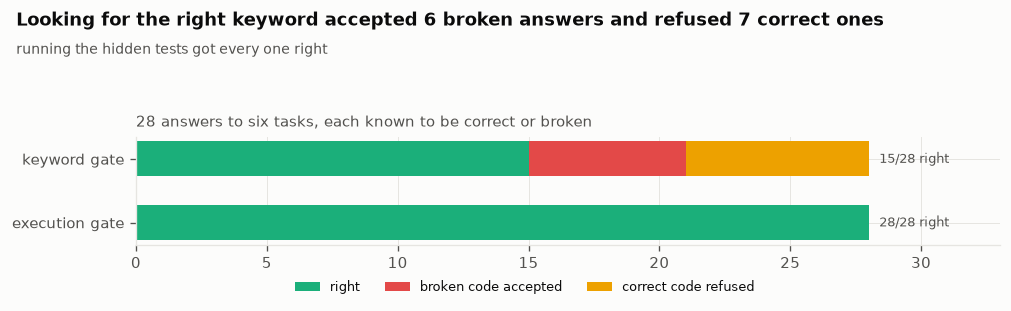

[fig 10] s8c_gates.png


In [265]:
# FIG  two gates, same answers
fig, ax = plt.subplots(figsize=(8.5, 3.0))
gates = [("keyword gate", [kv["right"], kv["FALSE ACCEPT"], kv["FALSE REJECT"]]),
         ("execution gate", [ev["right"], 0, ev["WRONG"]])]   # any execution mistake is drawn as a refusal
for y, (name, (right, accept, reject)) in enumerate(gates):
    ax.barh(y, right, 0.55, color=C3, label="right" if y == 0 else None)   # labels once, for the legend
    ax.barh(y, accept, 0.55, left=right, color=C8, label="broken code accepted" if y == 0 else None)
    ax.barh(y, reject, 0.55, left=right + accept, color=C4, label="correct code refused" if y == 0 else None)
    ax.text(right + accept + reject + 0.4, y, f"{right}/{len(GATE_ROWS)} right", va="center", fontsize=8, color=INK2)
ax.set_yticks([0, 1], [g[0] for g in gates])
ax.invert_yaxis()                                          # the keyword gate on top
ax.set_xlim(0, len(GATE_ROWS) + 5)
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.22), fontsize=7.5, ncol=3)
panel(ax, f"{len(GATE_ROWS)} answers to six tasks, each known to be correct or broken")
finish(fig, "s8c_gates", f"Looking for the right keyword accepted {kv['FALSE ACCEPT']} broken answers and refused "
       f"{kv['FALSE REJECT']} correct ones", "running the hidden tests got every one right")

**Reading FIG 10 (s8c_gates).** The keyword gate was wrong 6 times in the dangerous direction: every broken variant that mentioned the right tool got through, including a share-link check that compares signatures in constant time and never looks at the expiry date, and a search that uses a placeholder for the price while pasting the user's search term straight into the SQL. It was wrong 7 times in the expensive direction, refusing correct answers that used `Fraction`, a named SQL parameter, `upper().lower()`, `xml.sax.saxutils` or a hand-written validator, or that simply organised the code so the expected words did not land where the pattern looked. The execution gate made no mistakes, because it asks the only question that matters. This is why the critic and the review skill in Part VI are never allowed to *accept* code on their own: they can point at a problem, but a change is accepted only when the tests run.

**Part II recap.** The notebook can now hand an agent a task, run whatever it writes without risk to anything outside its workspace, and turn the result into a record that cannot be inflated by comments, fooled by keywords, or confused by work left lying around. The suite is fingerprinted, its 136 reference scorings behave as the rule requires, its hidden tests notice 95% of small planted bugs with every survivor explained, and `SPEND_OK` is set. Nothing so far has cost a model call. Part III builds the host the agent will run in, and from S12 on, it starts spending.

**Try it yourself.**
1. In the attack table, add a row that tries to open a file in your home folder with `pathlib.Path.home()`. Before you run it, predict which rule refuses it and what the message will say.
2. Take `sf-tenant-throttle` and change its good answer's `<=` to `<` (one of the reviewed survivors). Write the hidden-test check that would kill that mutant, then decide whether the ticket justifies adding it.
3. Add a keyword gate for `sf-clinic-file` that looks for `commonpath`, and write one variant that uses `commonpath` and is still unsafe. How short can you make it?

# Part III - The host: an agent runtime that knows nothing about over-engineering

A coding agent is a loop: ask a model what to do, do it, show the model what happened, repeat.

**Where this sits.** Parts I and II built the instruments and the exam. This Part builds the thing being examined: a small, complete agent runtime, which we call the **host**. It talks to the six models over the API, keeps every call in a ledger so that no answer is ever paid for twice, gives the model six tools that work only inside a fenced copy of the project, and offers the extension points every serious agent runtime has: lifecycle events that plugins can hook, skills and slash commands, configuration, subagents and a statusline. The host deliberately knows nothing about over-engineering. Everything this notebook is about arrives in Part IV as a *plugin* that rides on these extension points, and that separation is what makes the experiments in Part VII fair: the same host runs every arm, and only the plugin changes. The Part ends with the first measurement made with real models: given our 34 tickets and no guidance, how much code do they write?

**By the end of this Part you can** call a model over a streaming API with nothing but the standard library, explain why a ledger of calls is also a replay source and a set of accounts, keep an agent's file access inside its workspace, design a tool protocol a model can follow, hook an agent's lifecycle without letting a broken hook break the agent, manage a context window, and run, trace and score an agent end to end.

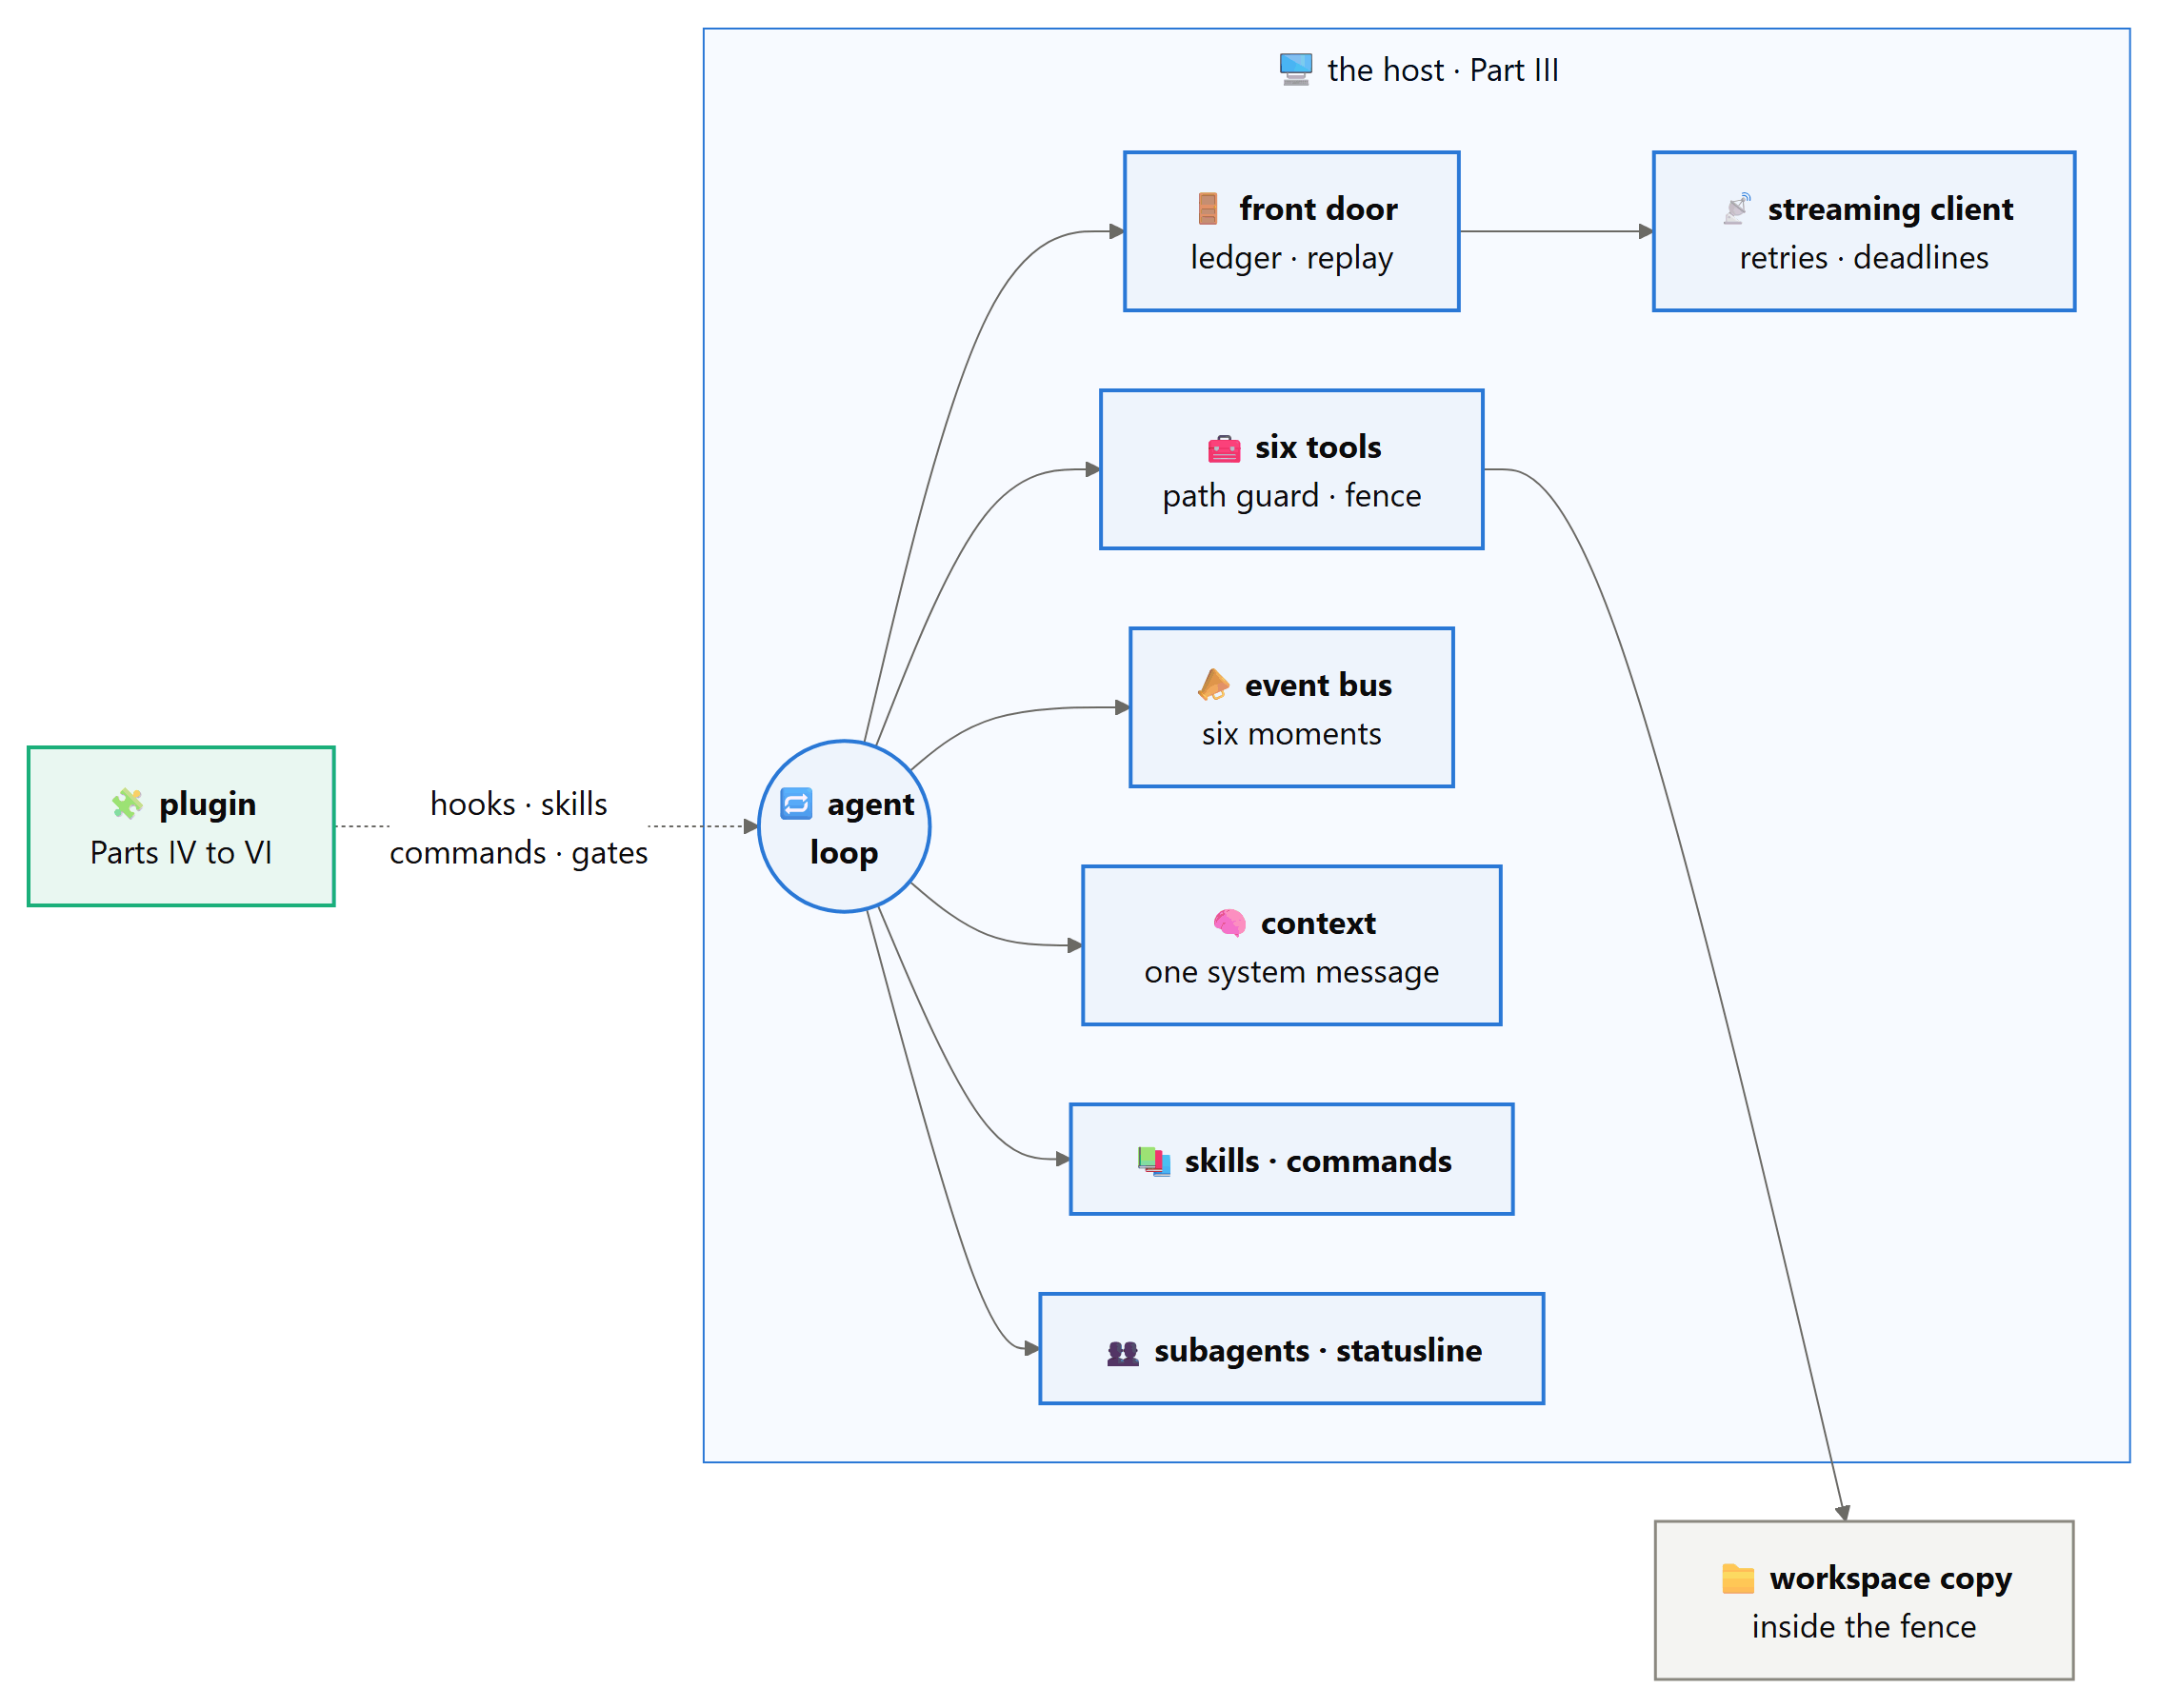

## S9 - Credentials: the key is read once and never seen again

**Theory.** The API key is the one secret in this project, and it can leak through more doors than people expect: a print statement, an exception message that includes a request, a cached request written to disk, an environment variable inherited by a child process, an agent that reads files it was not given. Each door gets its own lock. The key is read once from a file outside the notebook folder, its opening characters are never printed (only its length and a four-character suffix, enough to tell two keys apart), and it joins `SECRETS`, so that `scrub()` replaces it in anything printed or stored. The client sends it only in an HTTP header, and headers are never written to the ledger. The fence from S5 builds every sandboxed environment from scratch, so the key is not in any child process, and the attack table already showed that sandboxed code cannot open the key file. A last check scans everything the notebook has written so far for the key's bytes.

**In plain terms.** The key is read once, shown only as a short fingerprint, and checked for in every file we write.

**`load_key(path=None)`** reads the ModelScope key from a file outside the notebook folder, or returns `None` when there is no such file. Smoke and replay runs never call the API, so for them a missing key is the normal case, not an error. The one check it makes is on the key's shape (`ms-` followed by at least twenty hexadecimal digits and dashes): a file that holds something else fails here, before any request is built, instead of turning into a puzzling authentication error several sections later. The file is read as `utf-8-sig`, so a key saved by a Windows editor with a byte-order mark still matches.

In [266]:
def load_key(path=None):
    """The ModelScope key, or None when there is none (smoke and replay runs need none)."""
    path = Path(path or KEY_FILE)
    if not path.is_file():
        return None
    key = path.read_text(encoding="utf-8-sig").strip()
    if not re.fullmatch(r"ms-[0-9a-fA-F-]{20,}", key):
        raise ValueError("[key] the key file does not hold a ModelScope key")
    return key

show_def(load_key, layer="host")

[def] load_key(path=None)  9 lines, complexity 4


**`mask(secret)`** is the only form in which the key is ever shown: its length and its last four characters. That is enough to tell two keys apart, or to confirm that the key you meant is the one that was loaded, and it is useless to anyone who reads it over your shoulder. With no key it says `none`.

In [267]:
def mask(secret):
    return f"{len(secret)} characters, ending ...{secret[-4:]}" if secret else "none"

show_def(mask, layer="host")

[def] mask(secret)  2 lines, complexity 2


In [268]:
# a made-up value in the key's shape: the real key is never handed to a demonstration
print(f"[mask] {mask('ms-' + '0' * 28 + 'beef')}")  # 35 characters in, only the last four shown
print(f"[mask] no key at all: {mask(None)}")        # what every smoke and replay run shows

[mask] 35 characters, ending ...beef
[mask] no key at all: none


**`bytes_scan(secret, folders)`** is the last line of defence: it reads every file under the given folders as raw bytes and returns the ones that contain the secret. Reading bytes rather than text means a SQLite database or a binary file is searched as thoroughly as a source file, and no decoding error can make it skip one. It is a brute-force search, which is fine for a check that runs over the few folders this notebook writes to.

In [269]:
def bytes_scan(secret, folders):
    """Files under `folders` that contain the secret's bytes."""
    needle = secret.encode()
    return [p for f in folders for p in Path(f).rglob("*") if p.is_file() and needle in p.read_bytes()]

show_def(bytes_scan, layer="host")

[def] bytes_scan(secret, folders)  4 lines, complexity 4


In [270]:
# a made-up secret planted in a binary file two folders down; the clean file must not be reported
scan_dir = RUNTIME / "demo" / "s09_scan"
shutil.rmtree(scan_dir, ignore_errors=True)  # start from nothing, so only this run's files count
(scan_dir / "nested").mkdir(parents=True)    # two levels down, so the scan has to recurse
# binary bytes with the value buried in the middle, as in a database page
(scan_dir / "nested" / "notes.bin").write_bytes(b"\x00\x01token=ms-not-a-real-key-0000\x02")
(scan_dir / "clean.txt").write_text("nothing to see here", encoding="utf-8")  # a file the scan must not report
# the same call the last check below makes with the real key
planted_hits = bytes_scan("ms-not-a-real-key-0000", [scan_dir])
print(f"[scan] files holding the planted value: {[rel(p) for p in planted_hits]}")  # only notes.bin should be listed

[scan] files holding the planted value: ['.runtime/demo/s09_scan/nested/notes.bin']


Now the key itself. Only a `collect` run calls the API, so only a `collect` run reads the key; in every other mode `KEY` stays `None` and the key file is never opened.

In [271]:
KEY = load_key() if LEAN_MODE == "collect" else None  # smoke and replay never open the key file
if KEY:                                               # None in smoke and replay
    SECRETS.append(KEY)                               # from here on scrub() prints and stores it as <key>
# at most the key's length and last four characters ever reach the output
print(f"[key] mode {LEAN_MODE}: key {'loaded, ' + mask(KEY) if KEY else 'not needed and not read'}")

[key] mode replay: key not needed and not read


Three checks cover the doors that matter most here: printed text, the environment of a sandboxed process, and the files written so far. Each passes trivially when no key was read, because then there is nothing to leak.

In [272]:
results = []  # expect() records into this list; a fresh one per test cell
# a request printed in an error message is the likeliest leak, so scrub() is tried on one
expect("scrub() hides the key in any printed text", not KEY or scrub(f"token={KEY}") == "token=<key>")
# the fence builds a child's environment from nothing, so no variable can carry the key in
expect("no sandboxed process inherits a variable holding the key",
       not KEY or not any(KEY in v for v in fence_env(WS_DIR).values()))
# the experiment records, the agents' workspaces and the fence's own files, byte by byte
expect("nothing written so far contains the key",
       not KEY or not bytes_scan(KEY, [ART, RUNTIME / "ws", RUNTIME / "fence"]))

  PASSED  scrub() hides the key in any printed text
  PASSED  no sandboxed process inherits a variable holding the key
  PASSED  nothing written so far contains the key


## S10 - A streaming client in the standard library

**Theory.** The models are reached through an OpenAI-compatible endpoint. Reasoning models think before they answer, sometimes for a minute, so the reply is **streamed**: the server sends *server-sent events*, one `data: {...}` line per small piece, with the reasoning arriving in `reasoning_content` before the answer arrives in `content`, and a final event that carries the token counts. Streaming lets the client enforce a **deadline for the whole call** (a non-streaming request can sit silently for minutes) and notice the first byte, which separates a slow network from a slow model. Around that sit the mechanics of calling a busy shared service politely: a **retry** with exponential backoff and jitter, but only for errors that retrying can fix (429, 5xx, a dropped connection; never 400, which will fail the same way every time), a **cap on concurrent calls per model**, a **circuit breaker** that stops calling a model after five failed calls in a row and tries again two minutes later, and a **stop flag** that ends every call cleanly when a run is interrupted. All of it fits in the standard library: `urllib`, `json`, `threading`.

**In plain terms.** The client asks the model, reads the answer as it arrives, gives up politely when it should, and never hammers a service that is struggling.

**`Reply`** is everything one model call produced, in one flat record: the answer, the reasoning that came before it, why it stopped, the token counts, how long it took and how many attempts it needed. Every path through the front door returns one, whether the answer came from the network, the ledger or the scripted stand-in, so nothing downstream ever has to ask where an answer came from. A failed call is a `Reply` too, with `finish="error"` and the error text, which lets the agent loop treat a failure as data rather than as an exception.

In [273]:
@dataclass
class Reply:
    text: str = ""              # the answer, assembled from the content stream
    reasoning: str = ""         # what the model thought first, from the reasoning_content stream
    finish: str = None          # stop, length or error
    prompt_tokens: int = 0      # as the server counted them, from the final usage event
    completion_tokens: int = 0  # the answer's length in tokens, from the same event
    seconds: float = 0.0        # the whole call
    first_byte: float = None    # seconds until the first line arrived
    model: str = ""             # the model that answered
    attempts: int = 0           # tries the call needed
    error: str = None           # set only when finish is "error"
    cached: bool = False        # True when the ledger answered instead of the network

show_def(Reply, layer="host")

[class] Reply(text: str = '', reasoning: str = '', finish: str = None, prompt_to...)  12 lines, complexity 1


**`parse_sse(lines, model="")`** folds a stream of server-sent event lines into one `Reply`. Each `data:` line carries a small JSON chunk: pieces of the answer in `delta.content`, pieces of the reasoning in `delta.reasoning_content`, a `finish_reason` near the end, and, in a last chunk with no choices at all, the token counts. Lines that are not `data:` lines (keep-alives, comments) are skipped, and so is the `[DONE]` marker. Keeping this a pure function of the lines is what makes it testable without a network: the cell after it feeds it a recorded stream.

In [274]:
def parse_sse(lines, model=""):
    """Fold a stream of server-sent event lines into one Reply."""
    reply = Reply(model=model)                        # empty until the stream fills it in
    for line in lines:                                # one event per line
        line = line.strip()                           # each line ends with a newline
        if not line.startswith("data:") or line == "data: [DONE]":  # keep-alives and the end marker carry nothing
            continue
        chunk = json.loads(line[5:])                  # everything after "data:" is one JSON object
        for choice in chunk.get("choices") or []:     # one choice per chunk in practice; the last chunk has none
            delta = choice.get("delta") or {}         # the new piece of text this chunk carries
            reply.text += delta.get("content") or ""  # the answer arrives a few characters at a time
            reply.reasoning += delta.get("reasoning_content") or ""  # and so does the reasoning, before it
            reply.finish = choice.get("finish_reason") or reply.finish  # only a late chunk names a reason
        usage = chunk.get("usage") or {}              # the last chunk: no choices, just the counts
        # a chunk without counts keeps the values already there
        reply.prompt_tokens = usage.get("prompt_tokens", reply.prompt_tokens)
        reply.completion_tokens = usage.get("completion_tokens", reply.completion_tokens)
    return reply

show_def(parse_sse, layer="host")

[def] parse_sse(lines, model='')  17 lines, complexity 11


In [275]:
SAMPLE_STREAM = [                           # the shape of a real reply from the probe in S12, shortened
    # two chunks of reasoning while the answer is still empty
    'data: {"choices":[{"delta":{"role":"assistant","content":"","reasoning_content":"The user wants"}}]}',
    'data: {"choices":[{"delta":{"content":"","reasoning_content":" one word."}}]}',
    # the answer, with the reason the model stopped
    'data: {"choices":[{"delta":{"content":"OK","reasoning_content":""},"finish_reason":"stop"}]}',
    # no choices at all: only the token counts
    'data: {"choices":[],"usage":{"prompt_tokens":64,"completion_tokens":14,"total_tokens":78}}',
    "data: [DONE]",
]
r = parse_sse(SAMPLE_STREAM, model="demo")  # five lines in, one Reply out
# the answer and the reasoning arrive separately and are kept apart
print(f"[sse] {len(SAMPLE_STREAM)} events -> text {r.text!r}, reasoning {r.reasoning!r}, finish {r.finish}, "
      f"tokens {r.prompt_tokens}+{r.completion_tokens}")

[sse] 5 events -> text 'OK', reasoning 'The user wants one word.', finish stop, tokens 64+14


**`plain(text)`** turns the typographic characters models like to produce (long dashes, arrows, curly quotes, the one-character ellipsis) into plain ASCII before a reply is printed. Only the printed copy changes; the ledger stores every reply exactly as it arrived. The order of the pairs matters: a dash with a space on each side is replaced before a bare dash, or it would come out with two spaces on each side.

In [276]:
def plain(text):
    """Model text as this notebook prints it: dashes and arrows in plain ASCII. The stored
    replies are never changed."""
    for a, b in ((" \u2014 ", " - "),  # a spaced long dash first, so it keeps single spaces
                 ("\u2014", " - "),    # then a bare long dash between two words
                 (" \u2013 ", " - "),  # the same two cases for the shorter dash
                 ("\u2013", "-"),      # a bare short dash is usually a range, as in 3-5
                 ("\u2192", "->"),     # arrows, both ways
                 ("\u2190", "<-"),
                 ("\u2026", "..."),    # the one-character ellipsis
                 ("\u2018", "'"),      # curly single quotes
                 ("\u2019", "'"),
                 ("\u201c", '"'),      # curly double quotes
                 ("\u201d", '"'),
                 ("\ufffd", "?")):     # what a broken decode leaves behind
        text = text.replace(a, b)         # every occurrence, pair by pair, in the order above
    return text

show_def(plain, layer="host")

[def] plain(text)  17 lines, complexity 2


In [277]:
# the dash becomes ' - ' and the arrow '->'
print(f"[plain] {plain('cache it \u2014 then measure \u2192 ship')!r}")

[plain] 'cache it - then measure -> ship'


**`ModelClient`** is the HTTP side of the front door, written with nothing but `urllib`, `json` and `threading`. Its state is small, and all of it is about being polite to a shared service: a semaphore per model that caps concurrent calls, a count of failures in a row per model, the time until which a model's circuit stays open, a lock that guards those three, and a stop flag. `RETRY_HTTP` lists the status codes worth another try: timeouts, conflicts, rate limits and server errors. A 400 is not on it, because a malformed request fails the same way however often it is sent. The methods follow, one per cell.

In [278]:
import urllib.request                                      # Request and urlopen: the whole HTTP client
import urllib.error                                        # HTTPError carries the status code that decides on a retry
import http.client                                         # IncompleteRead: a stream cut off in the middle of a chunk

# calls in flight per model, however many worker threads there are
PER_MODEL_CONCURRENCY = 6

class ModelClient:
    """Chat completions over HTTP with only the standard library: a streamed reply, a deadline
    for the whole call, retries with backoff for the errors worth retrying, a cap on concurrent
    calls per model, a circuit breaker, and a stop flag."""

    RETRY_HTTP = {408, 409, 425, 429, 500, 502, 503, 504}  # timeout, conflict, too early, rate limit, server errors

    def __init__(self, key, endpoint=ENDPOINT, max_attempts=4):
        self.key = key                                     # sent only in a request header, never stored
        self.endpoint = endpoint                           # the OpenAI-compatible base URL
        self.max_attempts = max_attempts                   # the first try plus up to three retries
        self.gates = {}                                    # model: a semaphore that caps its concurrent calls
        self.failures = {}                                 # model: failed calls in a row; a success resets it
        self.open_until = {}                               # model: the time until which its circuit stays open
        self.lock = threading.Lock()                       # the worker threads share the three dicts above
        self.stop = threading.Event()                      # once set, no call starts another attempt

show_def(ModelClient, layer="host")

[class] ModelClient(key, endpoint='https://api-inference.modelscope.ai/v1', max_attemp...)  14 lines, complexity 1


**`ModelClient._gate(model)`** returns the semaphore for one model, creating it on first use. Up to `WORKERS` threads run episodes at once, and without a gate they could all call the same model at the same moment; with it, at most `PER_MODEL_CONCURRENCY` calls per model are in flight and the rest wait their turn. The lock matters: two threads asking for a new model's gate at the same moment must get the same semaphore, not one each.

In [279]:
@method_of(ModelClient)
def _gate(self, model):
    with self.lock:  # look up and create in one step, so a model never gets two gates
        # setdefault stores the new semaphore only when the model has none yet
        return self.gates.setdefault(model, threading.BoundedSemaphore(PER_MODEL_CONCURRENCY))

show_def(ModelClient._gate, layer="host")

[def] ModelClient._gate(self, model)  4 lines, complexity 1


In [280]:
gate_demo = ModelClient(key=None)  # a private client; nothing here makes a request
one_gate = gate_demo._gate("demo-model") is gate_demo._gate("demo-model")  # asked twice: the very same object
own_gate = gate_demo._gate("other-model") is not gate_demo._gate("demo-model")  # a different model: a different object
# both should be True
print(f"[gate] the same model always gets the same gate: {one_gate}; another model gets its own: {own_gate}")

[gate] the same model always gets the same gate: True; another model gets its own: True


**`ModelClient._stream(body, deadline)`** makes one HTTP request and reads the reply as it streams in. Two clocks run here. The socket timeout passed to `urlopen` only limits how long a single read may sit silent; the deadline is checked on every line and limits the call as a whole, which is the number that matters when a reasoning model decides to think for five minutes. The time to the first line is kept as well, because it separates a slow network (a late first line) from a slow model (an early first line and a long stream). The key appears in exactly one place, the `Authorization` header, and headers are never written anywhere.

In [281]:
@method_of(ModelClient)
def _stream(self, body, deadline):
    url = f"{self.endpoint}/chat/completions"           # the OpenAI-compatible chat route
    headers = {"Authorization": f"Bearer {self.key}", "Content-Type": "application/json"}  # the only place the key goes
    req = urllib.request.Request(url, data=json.dumps(body).encode(), headers=headers)  # the body goes as JSON bytes
    start = time.perf_counter()                         # the deadline and the timings count from here
    lines = []                                          # raw event lines, parsed in one go at the end
    first = None                                        # seconds until the first line arrived
    # the socket timeout bounds one silent read; the deadline below bounds the whole call
    with urllib.request.urlopen(req, timeout=min(60, deadline)) as resp:
        for raw in resp:                                # one line at a time, as the server sends it
            if first is None:                           # the first line ends the silent wait
                first = time.perf_counter() - start     # a late first line means a slow network
            if time.perf_counter() - start > deadline:  # checked on every line, not only at the end
                # chat() treats this like any other failure
                raise TimeoutError(f"the call ran past its {deadline}s deadline")
            lines.append(raw.decode("utf-8"))           # bytes from the socket, text for the parser
    reply = parse_sse(lines, body["model"])             # the stream is complete: fold it into one Reply
    reply.seconds = time.perf_counter() - start         # the whole call, which is what the time budget counts
    reply.first_byte = first                            # for the probe's timing table
    return reply

show_def(ModelClient._stream, layer="host")

[def] ModelClient._stream(self, body, deadline)  19 lines, complexity 4


**`ModelClient.chat(model, messages, **params)`** is the public call. The failures it expects come back as a `Reply` with `finish="error"` and the scrubbed error text, not as an exception. A model whose circuit is open is refused at once, without touching the network. Otherwise the call waits at the model's gate and makes up to `max_attempts` tries: an HTTP error outside `RETRY_HTTP` ends them at once, and a retryable failure sleeps first, with a backoff that doubles each time (capped at 30 seconds) and a random factor between a half and one, so that threads which failed together do not all retry at the same instant. A success resets the model's failure count; the fifth failed call in a row opens its circuit for two minutes.

In [282]:
@method_of(ModelClient)
def chat(self, model, messages, **params):
    body = {"model": model, "messages": messages, "stream": True,
            # include_usage: the token counts arrive in a last event
            "stream_options": {"include_usage": True}, **params}
    deadline = CALL_DEADLINE_S.get(model, CALL_DEADLINE_S["default"])  # some models are given longer to think
    if time.time() < self.open_until.get(model, 0):             # the circuit is open: do not even try
        # refused without a request, so a failing model is left alone while it recovers
        return Reply(model=model, finish="error", error="circuit open after repeated failures")
    last, attempt = None, 0                                     # the latest error, and the tries made so far
    with self._gate(model):                                     # wait for a free place at this model's gate
        # until a try succeeds, the tries run out, or the run is stopped
        while attempt < self.max_attempts and not self.stop.is_set():
            attempt += 1                                        # counts from 1
            try:                                                # one try is one whole streamed call
                reply = self._stream(body, deadline)            # raises on any failure, including the deadline
                reply.attempts = attempt                        # kept in the Reply, and so in the ledger
                with self.lock:                                 # other threads may be updating the counts
                    self.failures[model] = 0                    # a success clears the record of failures
                return reply
            except urllib.error.HTTPError as e:                 # the server answered, with an error status
                # the status code and the start of the server's explanation
                last = f"HTTP {e.code}: {e.read()[:200].decode('utf-8', 'replace')}"
                if e.code not in self.RETRY_HTTP:               # a bad request fails the same way every time
                    break
            # no answer at all, or one that could not be read: cut off, garbled, or not UTF-8
            except (urllib.error.URLError, TimeoutError, ConnectionError, OSError, json.JSONDecodeError,
                    http.client.HTTPException, UnicodeDecodeError) as e:
                last = f"{type(e).__name__}: {e}"               # network trouble, a deadline, a garbled stream
            time.sleep(min(30, 2 ** attempt) * (0.5 + random.random() / 2))  # backoff with jitter
    # every try failed, or none was allowed: count it against the model
    with self.lock:
        self.failures[model] = self.failures.get(model, 0) + 1  # failed calls in a row
        if self.failures[model] >= 5:                           # five failed calls in a row
            self.open_until[model] = time.time() + 120          # leave the model alone for two minutes
    # "stopped" when the stop flag ended the call before any try; scrubbed, as everything stored is
    return Reply(model=model, finish="error", error=scrub(last or "stopped"), attempts=attempt)

show_def(ModelClient.chat, layer="host")

[def] ModelClient.chat(self, model, messages, **params)  30 lines, complexity 9

Two of those paths can be shown without a network, in any mode: a client whose stop flag is set gives up before its first attempt, and a model whose circuit is open is refused before it even reaches the gate.

In [283]:
offline = ModelClient(key=None)                       # a private client with no key: nothing here is sent
offline.stop.set()                                    # as if the run had just been interrupted
# returns at once: the while loop never starts
stopped = offline.chat("demo-model", [{"role": "user", "content": "hi"}])
# expect error 'stopped' and no attempts
print(f"[client] stop flag set: finish {stopped.finish}, error {stopped.error!r}, attempts {stopped.attempts}")
offline.open_until["demo-model"] = time.time() + 120  # as if five calls in a row had just failed
tripped = offline.chat("demo-model", [{"role": "user", "content": "hi"}])  # refused before the gate
print(f"[client] circuit open: finish {tripped.finish}, error {tripped.error!r}")  # expect the circuit's own message

[client] stop flag set: finish error, error 'stopped', attempts 0
[client] circuit open: finish error, error 'circuit open after repeated failures'


## S11 - The ledger: cache, replay source and accounts in one table

**Theory.** Every model call goes through one front door, `LLM.chat`, and every answer is written to one SQLite table, the **ledger**, keyed by a fingerprint of the exact request: model, messages, sampling parameters and a replica number (so that two samples of the same prompt are two entries, not one). The same table plays three roles. It is a **cache**: a repeated request is answered from disk for free, which makes an interrupted nine-hour run resumable. It is the **replay source**: in `replay` mode the front door refuses to touch the network, and a request that is not in the ledger is an error rather than a silent new call, which is how we know the committed notebook shows exactly the answers it was built from. A request that failed during collection (a timeout, say) is noted as well, not as an answer but as a failure: a replay meets the same failure the collect run met, so its numbers match, and a later collect run tries the request again. And it is the **accounts**: calls, tokens and seconds per model and per day come from a `SELECT`. There is one complication. An agent's `run` tool shows the model whatever a program printed, and programs print timings. So each entry also gets a *loose* fingerprint in which `run` output is masked. When the exact fingerprint misses and the loose one hits, the stored answer is reused and the event is counted, never hidden.

**In plain terms.** Every answer the models ever gave is in one table. Asking again costs nothing, re-running the notebook needs no network, and the bill is a query.

**For teams.** Keep a ledger like this for any evaluation of an agent you might want to repeat or defend. Without one, a rerun is a different experiment, and an argument about a result cannot be settled by looking at what the model actually said.

**Every model request goes through one door.** The three modes differ only in what happens on a miss. That is why the committed notebook can be re-run offline: replay finds every answer the collect run stored, and a request it cannot find stops the run instead of quietly paying for a new one.

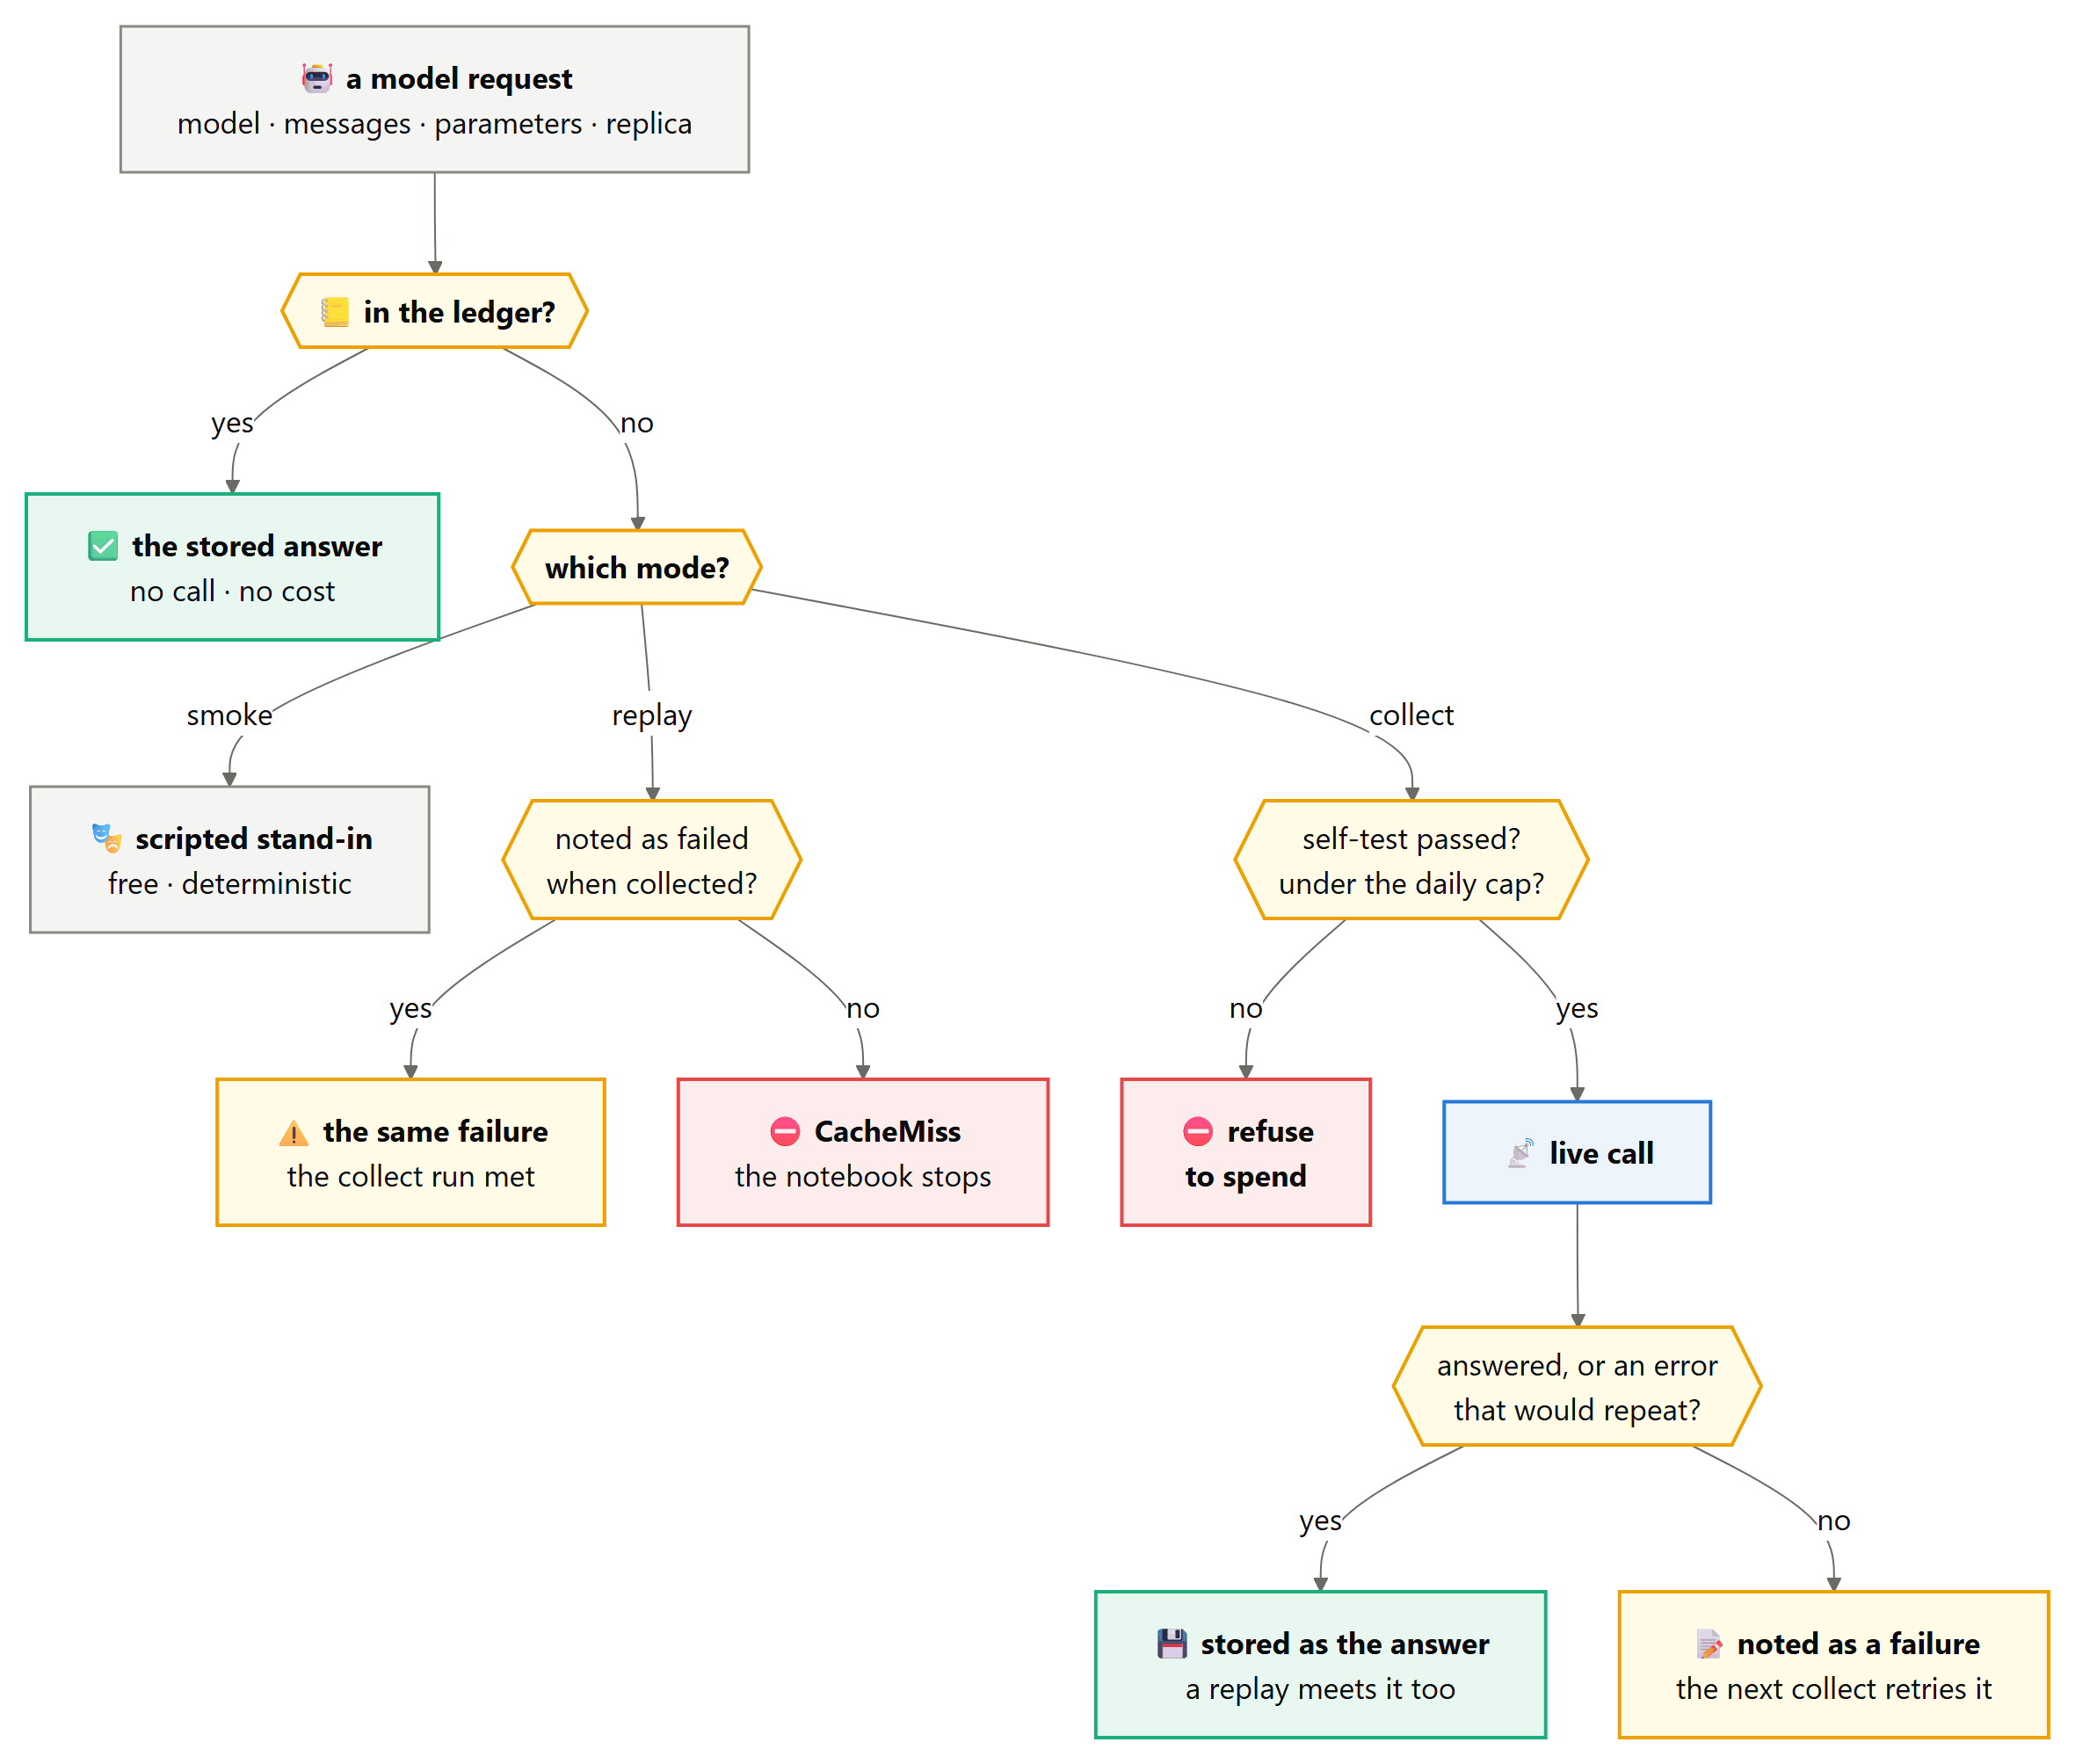

**`CacheMiss`** is what a replay raises when the ledger holds no answer for a request. It is deliberately an error and not a quiet fall-back to the network: a replay that made a new call would show answers the committed notebook was never built from. The class needs no body, because its name says everything.

In [284]:
class CacheMiss(RuntimeError):
    pass  # the type is the message: replay asked for an answer nobody stored

show_def(CacheMiss, layer="host")

[class] CacheMiss  2 lines, complexity 1


**`SpendRefused`** is raised in place of a call that must not be paid for. Two guards raise it: the S8 self-test, until it has passed, and the daily call cap, which protects against a runaway loop rather than acting as a budget. Raising stops the run where it stands, and since every answer so far is already in the ledger, the next run resumes from that point for free.

In [285]:
class SpendRefused(RuntimeError):
    """Raised instead of a call that must not be paid for: before the S8 self-test, or at the daily cap."""

show_def(SpendRefused, layer="host")

[class] SpendRefused  2 lines, complexity 1


**`_RUN_OUTPUT`** matches the body of a `run` result inside a message: everything between `<result action="run">` and `</result>`, with the two tags kept as groups so they survive a substitution. The ledger uses it to build the loose fingerprint, in which that body becomes the word `<output>`, because a program's printed timings change from run to run while the request means the same thing. Only `run` results are masked; a `read` result is a file's contents and has to match exactly.

In [286]:
_RUN_OUTPUT = re.compile(r'(<result action="run">\n).*?(\n</result>)', re.S)  # re.S: the body spans lines

# a run result, as the agent's next message carries it
run_sample = '<result action="run">\nexit code 0\ntook 0.031s\n</result>'
run_masked = _RUN_OUTPUT.sub(r"\1<output>\2", run_sample)  # the tags stay, the body goes
print(f"[loose] {run_sample!r}\n        becomes {run_masked!r}")  # the timing is gone; the tags remain

[loose] '<result action="run">\nexit code 0\ntook 0.031s\n</result>'
        becomes '<result action="run">\n<output>\n</result>'


**`Ledger`** is one SQLite file with two tables. `calls` holds every answer under its exact fingerprint, with the loose fingerprint in its own indexed column and the accounts (model, tag, day, seconds, tokens) beside it; `failures` holds requests the API failed on, which are not answers. The connection is shared by the worker threads (`check_same_thread=False`), and every use of it goes through one lock. `keys` is a static method because it needs no ledger at all: it turns a request into its two fingerprints, the exact one over the model, the messages, the sampling parameters and the replica number, and the loose one over the same with every `run` result's body masked. `json.dumps(..., sort_keys=True)` is what makes a fingerprint independent of the order in which a dict happened to be built.

In [287]:
class Ledger:
    """Every model call, by fingerprint: the cache, the replay source and the accounts."""

    def __init__(self, path):
        self.db = sqlite3.connect(path, check_same_thread=False)  # shared by the worker threads, behind self.lock
        # one row per answer: both fingerprints, the accounts, and the request and reply as JSON
        self.db.execute("""CREATE TABLE IF NOT EXISTS calls (key TEXT PRIMARY KEY, loose TEXT, model TEXT,
                           tag TEXT, day TEXT, request TEXT, reply TEXT, seconds REAL, prompt_tokens INT,
                           completion_tokens INT, reasoning_chars INT)""")
        self.db.execute("CREATE INDEX IF NOT EXISTS calls_loose ON calls (loose)")  # keeps the loose lookup fast
        # failures live apart from answers, so get() never returns one and a later collect run retries it
        self.db.execute("CREATE TABLE IF NOT EXISTS failures (key TEXT PRIMARY KEY, model TEXT, tag TEXT, day TEXT, error TEXT)")
        self.lock = threading.Lock()  # every use of the connection holds this
        self.soft_hits = 0            # answers found only through the loose fingerprint

    @staticmethod
    def keys(model, messages, params, replica):
        """The exact fingerprint, and the loose one with the body of every `run` result masked."""
        masked = []                   # the messages again, with run output masked
        for m in messages:
            # the same message, with the program output inside any run result replaced by <output>
            masked.append({**m, "content": _RUN_OUTPUT.sub(r"\1<output>\2", m["content"])})
        exact = json.dumps([model, messages, params, replica], sort_keys=True)  # sort_keys: dict order never matters
        loose = json.dumps([model, masked, params, replica], sort_keys=True)  # the same text, with run output masked
        # two hashes of 64 hex characters: the table's keys
        return hashlib.sha256(exact.encode()).hexdigest(), hashlib.sha256(loose.encode()).hexdigest()

show_def(Ledger, layer="host")

[class] Ledger(path)  20 lines, complexity 2


**`Ledger.get(exact, loose)`** looks a request up by its exact fingerprint first and, only if that misses, by its loose one. A hit is rebuilt into a `Reply` marked `cached=True`, so the record of an episode shows which turns came from disk. A loose hit is allowed, since a request that differs only in a program's timing output means the same thing, but it is counted in `soft_hits`, never hidden; the baseline in S23 prints the count.

In [288]:
@method_of(Ledger)
def get(self, exact, loose):
    with self.lock:                             # both lookups under one lock
        # the exact fingerprint first
        row = self.db.execute("SELECT reply FROM calls WHERE key = ?", (exact,)).fetchone()
        if row is None:                         # no exact match: try the request with run output masked
            # any answer with the same loose key
            row = self.db.execute("SELECT reply FROM calls WHERE loose = ?", (loose,)).fetchone()
            self.soft_hits += row is not None   # a loose hit is allowed, and always counted
    if not row:                                 # neither fingerprint is in the ledger
        return None
    stored = json.loads(row[0])                 # the Reply as it was saved, field by field
    return Reply(**{**stored, "cached": True})  # marked as an answer from the ledger, not the network

show_def(Ledger.get, layer="host")

[def] Ledger.get(self, exact, loose)  11 lines, complexity 3


**`Ledger.put(exact, loose, model, tag, request, reply)`** stores one answer under both fingerprints, with the request and the whole `Reply` saved as JSON, each passed through `scrub()` so that neither the key nor a path on this machine can reach the file. `INSERT OR REPLACE` keeps one row per exact fingerprint, and an answer clears any failure recorded earlier for the same request. Every write is committed at once, which is what makes a nine-hour run resumable: a crash loses at most the call in flight.

In [289]:
@method_of(Ledger)
def put(self, exact, loose, model, tag, request, reply):
    with self.lock:                                         # the insert, the clean-up and the commit as one step
        # the day comes from SQLite's own clock, so the accounts can count calls per day
        self.db.execute("INSERT OR REPLACE INTO calls VALUES (?, ?, ?, ?, date('now'), ?, ?, ?, ?, ?, ?)",
                        (exact, loose, model, tag,
                         scrub(json.dumps(request)),        # the request as sent, minus secrets and local paths
                         scrub(json.dumps(asdict(reply))),  # the whole Reply, so a hit can rebuild it exactly
                         reply.seconds, reply.prompt_tokens, reply.completion_tokens,
                         len(reply.reasoning)))             # only the reasoning's length goes to the accounts
        self.db.execute("DELETE FROM failures WHERE key = ?", (exact,))  # an answer supersedes a failure
        self.db.commit()                                    # on disk now: a crash loses at most the call in flight

show_def(Ledger.put, layer="host")

[def] Ledger.put(self, exact, loose, model, tag, request, reply)  11 lines, complexity 1


In [290]:
ledger_demo = Ledger(":memory:")                          # private and in memory: the real ledger is never touched
# the two fingerprints of a one-message request
k_exact, k_loose = Ledger.keys("demo-model", [{"role": "user", "content": "hi"}], {}, 0)
ledger_demo.put(k_exact, k_loose, "demo-model", "demo", {"messages": "hi"},  # stored under both
                Reply(text="hello", finish="stop", completion_tokens=2))
by_exact = ledger_demo.get(k_exact, "no-such-loose-key")  # found by the exact key
by_loose = ledger_demo.get("no-such-exact-key", k_loose)  # found only by the loose key: a soft hit
print(f"[ledger] by the exact key: {by_exact.text!r}, cached={by_exact.cached}")  # cached=True: it came from the table
# one soft hit, and it is on the record
print(f"[ledger] by the loose key alone: {by_loose.text!r}; soft hits counted: {ledger_demo.soft_hits}")

[ledger] by the exact key: 'hello', cached=True
[ledger] by the loose key alone: 'hello'; soft hits counted: 1


**`Ledger.put_failure(exact, model, tag, error)`** records a request the API failed on, in the separate `failures` table. A failure is not an answer, so `get` never returns one and a later collect run simply tries the request again.

In [291]:
@method_of(Ledger)
def put_failure(self, exact, model, tag, error):
    """A request the API failed on. It is not an answer, so a later collect run tries it again,
    but a replay meets the same failure the collect run met, and its numbers match."""
    with self.lock:                                         # one writer at a time
        self.db.execute("INSERT OR REPLACE INTO failures VALUES (?, ?, ?, date('now'), ?)",
                        (exact, model, tag, scrub(error)))  # an error text can quote a request: scrubbed too
        self.db.commit()                                    # on disk at once, like an answer

show_def(Ledger.put_failure, layer="host")

[def] Ledger.put_failure(self, exact, model, tag, error)  8 lines, complexity 1


**`Ledger.failure(exact)`** returns the stored error for a request, or `None` if it never failed. Only the replay path in `LLM.chat` asks, and that is how a replay meets the same failure the collect run met, with the same numbers as a result.

In [292]:
@method_of(Ledger)
def failure(self, exact):
    with self.lock:                 # the same lock as every other use of the connection
        # failures are looked up by the exact key only
        row = self.db.execute("SELECT error FROM failures WHERE key = ?", (exact,)).fetchone()
    return row[0] if row else None  # the error text, or None when the request never failed

show_def(Ledger.failure, layer="host")

[def] Ledger.failure(self, exact)  5 lines, complexity 2


In [293]:
# a request that timed out during collection
ledger_demo.put_failure("request-1", "demo-model", "demo", "TimeoutError: the call ran past its 120s deadline")
print(f"[ledger] a failed request is remembered: {ledger_demo.failure('request-1')!r}")  # the error text comes back
# get() never returns a failure, so a collect run would try the request again
print(f"[ledger] ...but it is not an answer: get() gives {ledger_demo.get('request-1', 'request-1-loose')}")
ledger_demo.put("request-1", "request-1-loose", "demo-model", "demo", {},  # a later collect run gets an answer
                Reply(text="late answer", finish="stop", completion_tokens=3))
# None: put() deleted it
print(f"[ledger] once an answer is stored, the failure is gone: {ledger_demo.failure('request-1')}")

[ledger] a failed request is remembered: 'TimeoutError: the call ran past its 120s deadline'
[ledger] ...but it is not an answer: get() gives None
[ledger] once an answer is stored, the failure is gone: None


**`Ledger.query(sql, args=())`** runs any SQL against the ledger under the same lock and returns every row. This is the accounts side of the table: calls per model, tokens per day and the daily cap are each a `SELECT` away, so there is no separate bookkeeping to keep in step with it.

In [294]:
@method_of(Ledger)
def query(self, sql, args=()):
    with self.lock:                                   # SQLite's connection is shared across the worker threads
        return self.db.execute(sql, args).fetchall()  # every row, as tuples

show_def(Ledger.query, layer="host")

[def] Ledger.query(self, sql, args=())  4 lines, complexity 1


In [295]:
for model_name, n_calls, tokens_out in ledger_demo.query(  # the accounts are one GROUP BY away
        "SELECT model, COUNT(*), SUM(completion_tokens) FROM calls GROUP BY model"):
    print(f"[accounts] {model_name}: {n_calls} answers, {tokens_out} tokens out")  # both answers stored above

[accounts] demo-model: 2 answers, 5 tokens out


**`ScriptedModel`** is the stand-in that answers in smoke runs: free, deterministic, and wrong in exactly the ways a test asks for. It holds a list of *responders*, small functions that each recognise the requests of one section and return the text to answer with, or `None` when a request is not theirs. Each section registers its own responders as it goes, so the stand-in grows with the notebook and never needs to know about sections that come later.

In [296]:
class ScriptedModel:
    """A stand-in model for smoke runs: free, deterministic, and wrong in exactly the ways a
    test asks for. Each section registers a responder for the requests it makes; the newest
    responder that recognises a request answers it."""

    def __init__(self):
        self.responders = []  # in order of registration; the newest is asked first

show_def(ScriptedModel, layer="host")

[class] ScriptedModel()  6 lines, complexity 1


**`ScriptedModel.register(fn)`** adds a responder and returns the function unchanged, which is what lets it be used as a decorator: `@SCRIPTED.register` above a function both defines and registers it. Registration order matters, because the newest responder is asked first; a later section can therefore answer a kind of request in its own way without editing an earlier one.

In [297]:
@method_of(ScriptedModel)
def register(self, fn):
    self.responders.append(fn)  # newest last; __call__ walks the list backwards
    return fn

show_def(ScriptedModel.register, layer="host")

[def] ScriptedModel.register(self, fn)  4 lines, complexity 1


**`ScriptedModel.__call__(model, messages, params)`** asks the responders, newest first, and the first one that returns text answers. The reply looks like a real one, with token counts estimated at four characters a token, so that the tables a smoke run produces hold plausible numbers. A request nobody recognises still gets an answer, a `<done>` that says so, which ends an agent's episode cleanly instead of crashing the run.

In [298]:
@method_of(ScriptedModel)
def __call__(self, model, messages, params):
    for fn in reversed(self.responders):    # newest first: a later section can override an earlier one
        text = fn(model, messages, params)  # each responder sees the whole request
        if text is not None:                # None means "not my request"
            n_in = sum(len(m["content"]) for m in messages) // 4  # about four characters a token
            return Reply(text=text, finish="stop", model=model, prompt_tokens=n_in,  # to the host, a normal answer
                         completion_tokens=len(text) // 4, attempts=1)
    # nobody recognised the request: end the episode rather than crash it
    return Reply(text="<done>(the scripted model has no answer for this request)</done>", finish="stop", model=model)

show_def(ScriptedModel.__call__, layer="host")

[def] ScriptedModel.__call__(self, model, messages, params)  9 lines, complexity 4


In [299]:
stand_in = ScriptedModel()                           # a private one: SCRIPTED itself is created further down
stand_in.register(lambda model, messages, params: "the older responder")  # answers anything
stand_in.register(lambda model, messages, params:    # answers only about caches
                  "the newer responder" if "cache" in messages[-1]["content"] else None)
for prompt in ("add a cache", "rename a function"):  # the first is about a cache, the second is not
    scripted_reply = stand_in("demo-model", [{"role": "user", "content": prompt}], {})  # called like a model
    # the newer responder wins whenever it has an answer
    print(f"[scripted] {prompt!r}: {scripted_reply.text!r}, about {scripted_reply.prompt_tokens} tokens in")
# a stand-in with no responders still answers
unrecognised = ScriptedModel()("demo-model", [{"role": "user", "content": "anything"}], {})
print(f"[scripted] with no responders at all: {unrecognised.text!r}")  # a <done> that ends the episode

[scripted] 'add a cache': 'the newer responder', about 2 tokens in
[scripted] 'rename a function': 'the older responder', about 4 tokens in
[scripted] with no responders at all: '<done>(the scripted model has no answer for this request)</done>'


**`LLM`** is the only door to a model, and its mode decides what is behind it. In `smoke` the scripted stand-in answers; in `collect` the ledger answers first and the network only on a miss, and only once S8 has set `SPEND_OK`; in `replay` the ledger is all there is, and a miss is an error. `DETERMINISTIC_ERRORS` names the API failures worth storing as answers: a request the server rejects as malformed will be rejected again, so a replay should meet the same rejection, while a timeout or an overloaded server is only noted as a failure for the next collect run to retry. `spent` counts the calls that really went over the network.

In [300]:
DETERMINISTIC_ERRORS = ("HTTP 400", "HTTP 404", "HTTP 422")  # the same request fails the same way: worth storing

class LLM:
    """The only door to a model. smoke: the scripted stand-in answers. collect: the ledger
    first, the network on a miss, and only once S8 has set SPEND_OK. replay: the ledger
    only, and a miss is an error. A transient failure is noted, never stored as an answer; a rejection that
    would repeat (a bad request) is, so a replay meets it too."""

    def __init__(self, mode, ledger, client=None, scripted=None):
        self.mode = mode                                     # smoke, collect or replay
        self.ledger = ledger                                 # every answer goes in here, whatever produced it
        self.client = client                                 # a ModelClient, or None when there is no key
        self.scripted = scripted                             # the stand-in, used only in smoke mode
        self.spent = 0                                       # calls that really went over the network

show_def(LLM, layer="host")

[class] LLM(mode, ledger, client=None, scripted=None)  11 lines, complexity 1


**`LLM.chat(model, messages, tag="", replica=0, **params)`** is the call every section makes. It fingerprints the request and returns a stored answer if there is one; otherwise it follows the mode: a replay returns the failure the collect run met or raises `CacheMiss`, a smoke run asks the stand-in, and a collect run checks the two spending guards before calling the network. Whatever came back is then stored, as an answer or as a failure. The `tag` names the call in the accounts (`probe:answers`, `off:ob-postcode-cache`) but is not part of the fingerprint, so renaming a tag never invalidates the ledger; the `replica` number is part of it, so two samples of the same prompt are two separate answers.

In [301]:
@method_of(LLM)
def chat(self, model, messages, tag="", replica=0, **params):
    exact, loose = Ledger.keys(model, messages, params, replica)  # the tag is in neither fingerprint
    hit = self.ledger.get(exact, loose)                      # exact first, then loose
    if hit:                                                  # answered before: free, and the same answer in every mode
        return hit
    if self.mode == "replay":                                # replay never touches the network
        failed = self.ledger.failure(exact)                  # did the collect run fail here?
        # the collect run met a failure here, and so does the replay
        if failed:
            return Reply(model=model, finish="error", error=failed)  # the same error the collect run met
        # a request the collect run never made: stop rather than pay for it
        raise CacheMiss(f"{tag or model}: no stored reply for this request; run in collect mode first")
    if self.mode == "smoke":                                 # the scripted stand-in, free
        reply = self.scripted(model, messages, params)       # the newest responder that recognises it
    else:
        if not SPEND_OK:                                     # the S8 self-test guards every paid call
            # until S8 passes, nothing is paid for
            raise SpendRefused("REFUSE TO SPEND: the S8 self-test has not passed")
        # today's calls, from the ledger's own accounts
        calls_today = self.ledger.query("SELECT COUNT(*) FROM calls WHERE day = date('now')")[0][0]
        if calls_today >= DAILY_CALL_CAP:                    # a runaway loop stops here, not at the bill
            # the run stops; every answer so far is already stored
            raise SpendRefused("the daily call cap is reached; the next run resumes from the ledger")
        if self.client is None:                              # collect mode with no key: say so, do not crash
            raise SpendRefused("no API key was found, so nothing can be collected; replay needs no key")
        reply = self.client.chat(model, messages, **params)  # the network: retries and deadlines live in the client
        self.spent += 1                                      # a call really paid for
    # an answer is stored, and so is a rejection that would repeat; a transient failure is only noted
    if reply.finish != "error" or (reply.error or "").startswith(DETERMINISTIC_ERRORS):
        # the request is stored beside its answer, so the ledger can be read on its own
        self.ledger.put(exact, loose, model, tag, {"messages": messages, "params": params, "replica": replica}, reply)
    else:
        self.ledger.put_failure(exact, model, tag, reply.error or "")  # noted, so a replay meets it too
    return reply

show_def(LLM.chat, layer="host")

[def] LLM.chat(self, model, messages, tag='', replica=0, **params)  28 lines, complexity 13


With the classes in place, the notebook builds the three objects every later section shares: the stand-in that sections register their responders on, the ledger, and the front door. A smoke run gets a fresh ledger of its own each time, so a scripted answer from an earlier smoke run can never answer a request in this one; collect and replay share the committed ledger.

In [302]:
SCRIPTED = ScriptedModel()                         # sections register their responders on this one
# a fresh ledger per smoke run, so stale scripts never linger
if LEAN_MODE == "smoke":
    # an earlier smoke run's answers must not answer this one's requests
    (RUNTIME / "smoke_llm.sqlite").unlink(missing_ok=True)
    LEDGER = Ledger(RUNTIME / "smoke_llm.sqlite")  # in the smoke folder, apart from the real ledger
else:
    LEDGER = Ledger(CACHE_DB)                      # collect and replay share the committed ledger
# a network client exists only when a key was read, which means only in collect mode
FRONT_DOOR = LLM(LEAN_MODE, LEDGER, ModelClient(KEY) if KEY else None, SCRIPTED)
# which ledger is in use, and how many answers it already holds
print(f"[llm] mode {LEAN_MODE}; ledger {rel(LEDGER.db.execute('PRAGMA database_list').fetchone()[2])} "
      f"holds {LEDGER.query('SELECT COUNT(*) FROM calls')[0][0]} calls")

[llm] mode replay; ledger artifacts/cache/llm.sqlite holds 12547 calls


**`_echo`** is the first scripted responder, and the simplest: a request whose last message starts with `ECHO ` is answered with the rest of that message. It exists for the demonstration below, which shows the ledger answering the second time the same request is made.

In [303]:
@SCRIPTED.register
def _echo(model, messages, params):
    if messages[-1]["content"].startswith("ECHO "):  # only requests that ask for it
        return messages[-1]["content"][5:]           # everything after "ECHO "

show_def(_echo, layer="lab")

[def] _echo(model, messages, params)  4 lines, complexity 2


In [304]:
demo_door = LLM("smoke", Ledger(":memory:"), scripted=SCRIPTED)  # a private ledger: costs nothing in any mode
# the stand-in echoes the text after ECHO
demo_msgs = [{"role": "user", "content": "ECHO the ledger answers the second time"}]
first = demo_door.chat("demo-model", demo_msgs, tag="demo")  # the stand-in answers, and the answer is stored
again = demo_door.chat("demo-model", demo_msgs, tag="demo")  # the same request: the ledger answers
# expect cached=False and then cached=True, with the same text
print(f"[ledger] first call: cached={first.cached}; second call: cached={again.cached}, text {again.text!r}")

[ledger] first call: cached=False; second call: cached=True, text 'the ledger answers the second time'


The loose fingerprint at work: two `run` results that differ only in a timing get the same loose key, while the same difference inside a `read` result does not.

In [305]:
# two run results that differ only in a timing
exact, loose = Ledger.keys("m", [{"role": "user", "content": '<result action="run">\ntook 0.031s\n</result>'}], {}, 0)
# the same run result with another timing
exact2, loose2 = Ledger.keys("m", [{"role": "user", "content": '<result action="run">\ntook 0.047s\n</result>'}], {}, 0)
# expect the exact keys to differ and the loose keys to match
print(f"[ledger] two run results that differ only in a timing: exact keys equal {exact == exact2}, "
      f"loose keys equal {loose == loose2}")
# the same two timings inside a read result, which is never masked
exact3, loose3 = Ledger.keys("m", [{"role": "user", "content": '<result action="read">\ntook 0.031s\n</result>'}], {}, 0)
# and with the second timing
exact4, loose4 = Ledger.keys("m", [{"role": "user", "content": '<result action="read">\ntook 0.047s\n</result>'}], {}, 0)
# expect neither pair to match
print(f"[ledger] the same difference in a read result:     exact keys equal {exact3 == exact4}, "
      f"loose keys equal {loose3 == loose4}  (only run output is masked)")

[ledger] two run results that differ only in a timing: exact keys equal False, loose keys equal True
[ledger] the same difference in a read result:     exact keys equal False, loose keys equal False  (only run output is masked)


## S12 - Probing the six models

**Theory.** Before any experiment, each model is asked a handful of tiny questions whose answers decide how the host may use it. Is it listed by the endpoint? How long until the first byte, and until the end? Does it reason by default, and does `enable_thinking: false` switch that off? Does it accept two system messages, or does the host have to merge everything into one? Does it honour a request for JSON output? The rule that follows from the answers is a small piece of YAGNI applied to ourselves: a capability is used only for a model whose probe showed it working. A model that is not listed is replaced by its fallback, and the substitution is printed, because a result produced by a different model than the one named in the table is a different result.

**In plain terms.** We knock on each model's door and write down what it can do before relying on any of it.

**`list_models()`** asks the endpoint which model ids it serves, and goes through the ledger like any other call, so a replay sees exactly the list the collect run saw. The request is a plain `GET /models` with no messages, so it gets a fingerprint of its own, the hash of the text `GET /models`, used as both the exact and the loose key. In a smoke run the list is simply every model the notebook names, so every role resolves to its first choice.

In [306]:
def list_models():
    """The ids the endpoint lists, through the ledger like any other call."""
    exact = hashlib.sha256(b"GET /models").hexdigest()          # a fixed fingerprint for a request without messages
    hit = LEDGER.get(exact, exact)                              # the same key twice: there is nothing to mask
    if hit:                                                     # asked before: this run sees the list the first run saw
        return json.loads(hit.text)                             # the stored answer is the list itself, as JSON
    if LEAN_MODE == "replay":                                   # a replay may not ask the network
        raise CacheMiss("the model list is not in the ledger")  # the collect run never stored it
    if LEAN_MODE == "smoke":                                    # no network, no key
        ids = sorted(set(MODELS.values()) | set(FALLBACKS.values()))  # every id the notebook names
    else:
        # a plain GET with the key in its header, like every other request
        req = urllib.request.Request(f"{ENDPOINT}/models", headers={"Authorization": f"Bearer {KEY}"})
        with urllib.request.urlopen(req, timeout=60) as resp:   # a short answer, so a plain timeout is enough
            listing = json.loads(resp.read())["data"]           # one entry per model, each with an "id"
            # sorted, so the stored answer never depends on the server's order
            ids = sorted(m["id"] for m in listing)
    # stored like a model's answer, so the next run (and every replay) reads it from disk
    LEDGER.put(exact, exact, "endpoint", "models", {"get": "/models"}, Reply(text=json.dumps(ids), finish="stop"))
    return ids

show_def(list_models, layer="host")

[def] list_models()  17 lines, complexity 5


**`PROBES`** is the probe set as data: for each capability, the messages to send, any extra request parameters, and a check that decides from the `Reply` whether the capability works. Every request's last message starts with the word `PROBE`, which is how the scripted stand-in below recognises them. The JSON check strips a code fence and a leading `json` before parsing, because a JSON object wrapped in a fence is still a usable answer.

In [307]:
PROBES = {  # name -> (messages, extra parameters, passed?)
    # can it answer at all, with its default settings
    "answers": ([{"role": "system", "content": "Answer in one word."},
                 {"role": "user", "content": "PROBE Reply with the single word OK."}], {},
                lambda r: r.text.strip().strip(".").upper() == "OK"),
    # does enable_thinking: false really switch the reasoning off
    "thinking off": ([{"role": "system", "content": "Answer in one word."},
                      {"role": "user", "content": "PROBE Reply with the single word OK."}], {"enable_thinking": False},
                     lambda r: r.text.strip().strip(".").upper() == "OK" and not r.reasoning),
    # is a second system message accepted, or rejected with an error
    "two system messages": ([{"role": "system", "content": "Answer in one word."},
                             {"role": "system", "content": "Use capital letters."},
                             {"role": "user", "content": "PROBE Reply with the single word OK."}], {"enable_thinking": False},
                            lambda r: r.finish != "error"),
    # does it honour response_format, even if it wraps the object in a code fence
    "JSON mode": ([{"role": "system", "content": "Reply with a JSON object only."},
                   {"role": "user", "content": 'PROBE Return {"ok": true}.'}],
                  {"enable_thinking": False, "response_format": {"type": "json_object"}},
                  lambda r: r.finish != "error" and json.loads(r.text.strip().strip("`").removeprefix("json")) == {"ok": True}),
}
# answers, thinking off, two system messages, JSON mode
print(f"[probe] {len(PROBES)} probes per model: {', '.join(PROBES)}")

[probe] 4 probes per model: answers, thinking off, two system messages, JSON mode


**`_probe`** is the stand-in's answer to the probes: `OK` to everything, except a JSON object when the system message asks for JSON. In a smoke run every model therefore passes every probe, which is what the subtitle of the figure below warns about.

In [308]:
@SCRIPTED.register
def _probe(model, messages, params):
    if not messages[-1]["content"].startswith("PROBE"):  # not a probe: an older responder may know it
        return None
    if "JSON" in messages[0]["content"]:                 # only the JSON-mode probe's system message says JSON
        return '{"ok": true}'
    return "OK"

show_def(_probe, layer="lab")

[def] _probe(model, messages, params)  7 lines, complexity 3


**`probe_model(model)`** sends one model the four probes and returns a row of verdicts: for each probe, whether its check passed, plus the timings, the amount of reasoning and any error from the plain `answers` probe. A check that raises (a reply that is not valid JSON, say) counts as a failed probe, not as a crash, because a model that answers badly has still answered. Each probe goes through the front door with a tag of its own, so the ledger's accounts show what the probing cost.

In [309]:
def probe_model(model):
    out = {"model": model}                                  # one row of the capability table
    for name, (messages, extra, passed) in PROBES.items():  # the four probes, in order
        # through the front door, so the ledger answers every later run
        r = FRONT_DOOR.chat(model, messages, tag=f"probe:{name}", max_tokens=1200, **extra)
        try:                                                # the check reads the reply, and may fail to
            ok = bool(passed(r))                            # True only if the capability works
        except (ValueError, json.JSONDecodeError):          # an answer the check cannot even read is a failed probe
            ok = False                                      # an unreadable answer is a failed probe
        out[name] = ok                                      # one column per probe
        if name == "answers":                               # the plain probe also gives the timings
            # the timings and the reasoning size for the figure
            out.update(seconds=r.seconds, first_byte=r.first_byte, reasoning=len(r.reasoning), error=r.error)
    return out

show_def(probe_model, layer="host")

[def] probe_model(model)  12 lines, complexity 4


First the roles: each one gets its model, or that model's fallback when the endpoint does not list it. A substitution is always printed, because a table that names one model and reports another model's numbers would be wrong.

In [310]:
listed = set(list_models())                            # what the endpoint offers today
MODEL_FOR = {}                                         # role: the model id that really plays it
for role, model in MODELS.items():                     # coder, fast, judge, judge2, big, omni
    if model in listed:                                # the first choice is available
        MODEL_FOR[role] = model                        # the model the parameters name
    else:
        MODEL_FOR[role] = FALLBACKS.get(model, model)  # with no fallback the id stays, and its probes will fail
    if MODEL_FOR[role] != model:                       # a substitution changes the experiment
        # so it is always printed
        print(f"[probe] {model} is not listed; role '{role}' uses the fallback {MODEL_FOR[role]}")
# True when every role ended up with a model the endpoint serves
print(f"[probe] the endpoint lists {len(listed)} models; all six roles resolved: "
      f"{all(m in listed for m in MODEL_FOR.values())}")

[probe] the endpoint lists 33 models; all six roles resolved: True


Then the probes, each distinct model once, all of them side by side. The verdicts become the capability table below.

In [311]:
with ThreadPoolExecutor(WORKERS) as pool:      # the models are probed in parallel, each in sorted order of id
    # each distinct model once; map keeps the sorted order
    PROBE = {p["model"]: p for p in pool.map(probe_model, sorted(set(MODEL_FOR.values())))}
rows = []                                      # one row per model for the table
for probed_model, probe_row in PROBE.items():  # in the sorted order of the probes
    roles = ", ".join(r for r, m in MODEL_FOR.items() if m == probed_model)  # a model can play several roles
    # yes or no for each probe; the timings are not probes
    verdicts = {k: "yes" if v else "no" for k, v in probe_row.items() if k in PROBES}
    # the id without its organisation prefix
    rows.append({"role": roles, "model": probed_model.split("/")[-1], **verdicts,
                 "first byte": probe_row["first_byte"], "seconds": probe_row["seconds"],
                 "reasoning": probe_row["reasoning"]})
# the capability table, then the timings
table(rows, [("model", "model", ""), ("role", "role", ""), ("answers", "answers", ""), ("thinking off", "thinking off", ""),
             ("two system messages", "2 system msgs", ""), ("JSON mode", "JSON mode", ""),
             ("first byte", "first byte s", ".2f"), ("seconds", "total s", ".2f"), ("reasoning", "reasoning chars", "d")])

  model               role    answers  thinking off  2 system msgs  JSON mode  first byte s  total s  reasoning chars
  -------------------------------------------------------------------------------------------------------------------
  Qwen3.7-Max         judge   yes      yes           yes            yes                1.12     3.12              594
  Qwen3.7-Plus        judge2  yes      yes           yes            yes                1.03     4.09              638
  Qwen3.8-27B         coder   yes      yes           yes            yes                0.72     1.45              159
  Qwen3.8-Flash-Next  fast    yes      yes           yes            yes                1.02     1.54              110
  Qwen3.8-Max         big     yes      yes           yes            yes                1.55     2.25              113
  Qwen3.8-Omni-Flash  omni    yes      yes           yes            yes                1.03     1.61              158


`CAN` is what the host consults later: for each model, the set of capabilities its probes showed working. The record saved here is what the prose quotes.

In [312]:
CAN = {model: {k for k in PROBES if p[k]} for model, p in PROBE.items()}  # capabilities a model may be asked to use
probe_by_model = {}                                    # the record's per-model part
for probed_model, probe_row in PROBE.items():          # the same order as the table
    passed_probes = {k: probe_row[k] for k in PROBES}  # True or False for each probe
    # the verdicts plus the reasoning size, by short model name
    probe_by_model[probed_model.split("/")[-1]] = passed_probes | {"reasoning": probe_row["reasoning"]}
save_exp("probe", {"models": probe_by_model,           # the numbers the prose quotes
                   "all_answer": all(p["answers"] for p in PROBE.values()),
                   "two_system_ok": sum(p["two system messages"] for p in PROBE.values()),
                   "json_ok": sum(p["JSON mode"] for p in PROBE.values()), "n": len(PROBE)})

[exp] artifacts/exp_probe.json


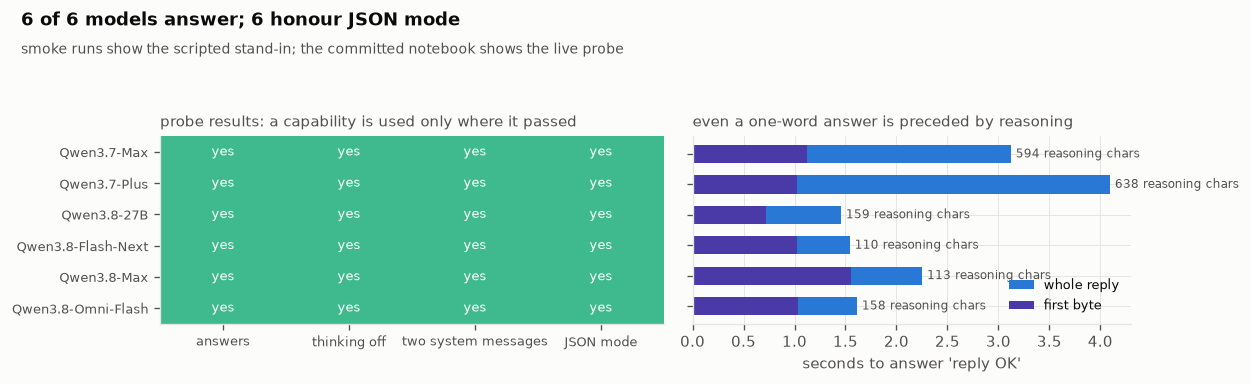

[fig 11] s12_probe.png


In [313]:
# FIG  what each model can do, and how long it takes to say OK
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.3), gridspec_kw={"width_ratios": [1.15, 1]})
names = [m.split("/")[-1] for m in PROBE]                     # model ids without the organisation prefix
ax = axes[0]                                                  # the left panel
# left: one row per model, one column per probe, 1 where the probe passed
grid = np.array([[1 if PROBE[m][k] else 0 for k in PROBES] for m in PROBE])
# red for a failed probe, green for a passed one
ax.imshow(grid, cmap=matplotlib.colors.ListedColormap([C8, C3]), vmin=0, vmax=1, aspect="auto", alpha=0.85)
for i in range(grid.shape[0]):                                # each model
    for j in range(grid.shape[1]):                            # each probe
        # words, not only colour
        ax.text(j, i, "yes" if grid[i, j] else "no", ha="center", va="center", fontsize=8, color="white")
ax.set_xticks(range(len(PROBES)), list(PROBES), fontsize=8)   # the probe names along the top
ax.set_yticks(range(len(names)), names, fontsize=8)           # the model names down the side
ax.grid(False)                                                # grid lines would cut through the cells
panel(ax, "probe results: a capability is used only where it passed")  # the caption states the rule
ax = axes[1]                                                  # the right panel
# right: the whole reply against the first byte, for the plain "answers" probe
y = np.arange(len(names))
ax.barh(y, [PROBE[m]["seconds"] for m in PROBE], 0.6, color=C1, label="whole reply")  # the whole call
# drawn over it: the wait before anything arrived
ax.barh(y, [PROBE[m]["first_byte"] or 0 for m in PROBE], 0.6, color=C7, label="first byte")
for i, m in enumerate(PROBE):                                 # a label at the end of each bar
    # how much the model reasoned before saying OK
    ax.text(PROBE[m]["seconds"] + 0.05, i, f"{PROBE[m]['reasoning']} reasoning chars", va="center", fontsize=7, color=INK2)
ax.set_yticks(y, [])                                          # the names are already on the left panel
ax.invert_yaxis()                                             # the same model order as the left panel
ax.set_xlabel("seconds to answer 'reply OK'")                 # the plain probe's timings
ax.legend(loc="lower right", fontsize=7.5)                    # the two bars
panel(ax, "even a one-word answer is preceded by reasoning")  # the point of the right panel
# the title states the finding; the subtitle says what a smoke run shows instead
finish(fig, "s12_probe", f"{sum(p['answers'] for p in PROBE.values())} of {len(PROBE)} models answer; "
       f"{sum(p['JSON mode'] for p in PROBE.values())} honour JSON mode",
       "smoke runs show the scripted stand-in; the committed notebook shows the live probe")

**Reading FIG 11 (s12_probe).** The left panel is the capability table the host consults: a red cell is a capability the host will never ask that model for. The right panel shows why reasoning matters for cost: even "reply with the single word OK" is preceded by reasoning on the models that think by default, which is the first hint of the cost question Part VII returns to (H7). In the live probe, 6 of 6 models accepted two system messages. The host sends exactly one anyway (S17): it costs nothing, it works with every model, and a host that relies on a tolerance it does not need is making a promise on someone else's behalf.

## S13 - The path guard

**Theory.** The fence in S5 stops sandboxed *programs* from leaving the workspace. The agent's own tools (read, edit, list) run inside the notebook, not in the sandbox, so they need their own guard. `resolve_in(ws, path)` turns whatever path the model wrote into an absolute path and refuses anything that is absolute, starts with a drive or a home directory, climbs out with `..`, or lands in a harness folder such as `_tmp/`. Resolution happens *before* the check (so `a/../../x` is judged by where it really goes, and a symbolic link is judged by its target), and the comparison is done on resolved paths, not on strings. A guard like this is easy to get almost right, so it is fuzzed: thousands of random paths built from dangerous pieces must each either resolve inside the workspace or be refused with `ToolError`. No third outcome is allowed.

**In plain terms.** Whatever path the model types, the tools only ever touch files inside the copy of the project.

**`ToolError`** is how a tool says no. Its message is not a crash report but the observation the model reads next, so every message raised with it below is written for the model: what went wrong and, where it can, what to send instead.

In [314]:
class ToolError(Exception):
    """A tool refused or failed; the message goes back to the model as the observation."""

show_def(ToolError, layer="host")

[class] ToolError  2 lines, complexity 1


**`resolve_in(ws, path)`** takes whatever path the model wrote and returns the absolute path inside the workspace that it names, or raises `ToolError` with a sentence the model can act on. It refuses, in this order: an empty path, one that is not a string, or one holding a NUL byte; an absolute path, a drive, or a path that starts with a slash or `~`; a Windows device name such as `con` or `nul` in any part, with or without an extension (`DEVICE_NAMES` lists them, and Windows treats them as devices in every folder); a path that cannot be resolved; one that resolves outside the workspace; and one inside a harness folder. The containment test runs on the resolved path, so `a/../../x` is judged by where it really leads and a symbolic link by its target.

In [315]:
# reserved in every folder on Windows: con, prn, aux, nul, com1 to com9, lpt1 to lpt9
DEVICE_NAMES = {"con", "prn", "aux", "nul", *(f"com{i}" for i in range(1, 10)), *(f"lpt{i}" for i in range(1, 10))}

def resolve_in(ws, path):
    """A path the model gave, resolved inside its workspace, or ToolError."""
    if not isinstance(path, str) or not path.strip() or "\0" in path:  # not a string, blank, or a NUL byte
        raise ToolError("a path relative to the project folder is needed")  # the sentence the model reads
    raw = path.strip()                                          # models sometimes pad a path with spaces
    p = Path(raw)                                               # not resolved yet: first the cheap checks on the text
    if p.is_absolute() or p.drive or raw.startswith(("/", "\\", "~")):  # C:\x, C:x, /x, \x and ~/x
        # the message quotes the path back, so the model sees what it sent
        raise ToolError(f"use a path relative to the project folder, not {raw!r}")
    stems = [part.split(".")[0].strip().lower() for part in p.parts]  # "CON.txt" and "nul " are devices too
    if any(stem in DEVICE_NAMES for stem in stems):             # any part of the path, not only the last
        raise ToolError(f"{raw!r} names a Windows device, not a file")  # reading one would hang or misbehave
    root = Path(ws).resolve()                                   # the workspace itself, resolved the same way
    try:                                                        # some paths cannot be resolved at all
        full = (root / p).resolve()                             # resolve first: .. and symbolic links are followed here
    except (OSError, ValueError) as e:                          # too long, or characters the system rejects
        # the kind of failure, without the system's own message
        raise ToolError(f"{raw!r} is not a usable path: {type(e).__name__}")
    if full != root and not full.is_relative_to(root):          # compared as paths, never as strings
        raise ToolError(f"{raw!r} leads outside the project folder")  # the escape the fuzz below looks for
    if any(_harness(x) for x in full.relative_to(root).parts):  # _tmp, _seed and the like belong to us
        raise ToolError(f"{raw!r} is not part of the project")  # the harness's own files stay invisible
    return full

show_def(resolve_in, layer="host")

[def] resolve_in(ws, path)  21 lines, complexity 15


The fuzz: 3,000 random paths, each one to five pieces chosen from a list of dangerous ones (climbing dots, both kinds of slash, a drive, a home directory, a NUL byte, a device name, a harness folder, the Unicode two-dot leader, a network share), sometimes with a leading slash. Each path must either resolve inside the workspace or be refused with `ToolError`; any other exception is a bug in the guard and is counted as a crash.

In [316]:
guard_ws = materialise(SUITE["sf-clinic-file"], WS_DIR / "guard")  # a real seed to aim at
# ordinary names mixed with every piece a path attack is made of
PIECES = ["a", "b.py", "clinic", "..", ".", "", "/", "\\", "C:", "~", "%2e%2e", "\x00", "con", " ", "_tmp", "....",
          "a/../..", "..\\..", "files.py", "\u2025", "//server/share"]
rng = random.Random(SEED)                                    # a private generator: the same 3,000 paths on every run
outcomes, escapes = Counter(), []                            # the tally, and any path that got out
for _ in range(3000):
    # a leading slash one time in twenty, then one to five pieces joined by slashes
    lead = rng.choice(["", "/"]) * (rng.random() < 0.1)
    # the draws happen in the same order as ever, so SEED gives the same 3,000 paths
    path = lead + "/".join(rng.choice(PIECES) for _ in range(rng.randint(1, 5)))
    try:                                                     # each path either resolves or is refused
        full = resolve_in(guard_ws, path)                    # the guard under test
        # checked again here, independently of the guard's own test
        inside = full == guard_ws.resolve() or full.is_relative_to(guard_ws.resolve())
        outcomes["resolved inside"] += inside                # True counts as 1
        if not inside:                                       # the guard said yes, and it should have said no
            escapes.append(path)                             # the one outcome that must never happen
    except ToolError:                                        # a refusal is a correct outcome
        outcomes["refused"] += 1                             # refused, with a sentence for the model
    except Exception as e:                                   # any other exception is a bug in the guard
        # counted by exception type, so the table shows what went wrong
        outcomes[f"crashed: {type(e).__name__}"] += 1
print(f"[guard] fuzz, 3000 random paths: {dict(outcomes)}")  # only two kinds should appear: refused and resolved inside

[guard] fuzz, 3000 random paths: {'refused': 2361, 'resolved inside': 639}


Twelve paths a model might really write, and what the guard made of each.

In [317]:
# the paths a model is most likely to try, harmless and harmful
named = ["clinic/files.py", "clinic/../clinic/files.py", "../modelscope.txt", "..\\..\\x", "C:\\Windows\\win.ini",
         "C:x", "/etc/passwd", "~/notes", "_tmp/x", "_seed/clinic/files.py", "con", "clinic/./letters.py"]
rows = []                   # one row per path
for p in named:             # in the order above
    try:                    # each path is either inside or refused
        landed = resolve_in(guard_ws, p).relative_to(guard_ws.resolve()).as_posix()  # where it really points
        rows.append({"path": repr(p), "outcome": "inside: " + landed})  # repr shows backslashes as the model wrote them
    except ToolError as e:  # refused: show the reason
        rows.append({"path": repr(p), "outcome": f"refused: {scrub(e)}"})  # the sentence the model would read
table(rows, [("path", "path the model wrote", ""), ("outcome", "outcome", "")])  # the guard's verdict on each

  path the model wrote         outcome
  -----------------------------------------------------------------------------------------------------------
  'clinic/files.py'            inside: clinic/files.py
  'clinic/../clinic/files.py'  inside: clinic/files.py
  '../modelscope.txt'          refused: '../modelscope.txt' leads outside the project folder
  '..\\..\\x'                  refused: '..\\..\\x' leads outside the project folder
  'C:\\Windows\\win.ini'       refused: use a path relative to the project folder, not 'C:\\Windows\\win.ini'
  'C:x'                        refused: use a path relative to the project folder, not 'C:x'
  '/etc/passwd'                refused: use a path relative to the project folder, not '/etc/passwd'
  '~/notes'                    refused: use a path relative to the project folder, not '~/notes'
  '_tmp/x'                     refused: '_tmp/x' is not part of the project
  '_seed/clinic/files.py'      refused: '_seed/clinic/files.py' is not part of the pro

In [318]:
results = []
expect("no fuzzed path resolved outside the workspace", not escapes)  # the property that matters
expect("no fuzzed path crashed the guard", not any(k.startswith("crashed") for k in outcomes))  # and no third outcome
# the numbers the prose quotes
save_exp("path_guard", {"fuzz": 3000, "refused": outcomes["refused"], "inside": outcomes["resolved inside"],
                        "escapes": len(escapes)})

  PASSED  no fuzzed path resolved outside the workspace
  PASSED  no fuzzed path crashed the guard
[exp] artifacts/exp_path_guard.json


## S14 - Six tools

**Theory.** The agent gets six tools, and each is as small as it can be while still doing its job. `ls` lists a folder with line counts, so the model can see the shape of a project without reading every file. `read` returns numbered lines, a window at a time for long files. `grep` searches with a regular expression, and it runs inside the fence with a ten-second limit, because a pattern like `(a+)+$` can backtrack for longer than anyone wants to wait and the model writes the pattern. `edit` replaces one exact, unique piece of text and answers with a small diff; an empty `<old>` creates a file. Making the model quote the text it replaces is what keeps edits surgical, and the two error messages it can get back ("not found, copy it exactly" and "found three times, include more lines") are the ones that teach it to read before it writes. `run` runs Python in the fenced workspace. `done` ends the episode with a message to whoever wrote the ticket. There is no tool to delete a file, fetch a URL or install a package, because no ticket in this notebook needs one, and the tool list is the first place over-building shows up in a host.

**In plain terms.** List, read, search, edit, run, finish. Nothing else, and every tool explains its errors in words the model can act on.

**`tool_ls(ws, path=".")`** lists one folder: subfolders first, then files, each file with its line count, so the model sees the shape of a project without opening anything. Harness files are left out here, as they are everywhere the model can look. A file that is not UTF-8 text says so instead of giving a line count, and an empty folder says `(empty folder)` rather than returning nothing, because an empty observation reads to a model like a failed call.

In [319]:
def tool_ls(ws, path="."):
    if path in (".", "", "./"):                       # the three ways a model writes "here"
        folder = Path(ws).resolve()                   # the project folder itself needs no guard
    else:
        folder = resolve_in(ws, path)                 # anything else goes through it
    if not folder.is_dir():                           # a file, or nothing at all
        raise ToolError(f"{path!r} is not a folder")  # the model may have meant read
    rows = []                                         # one line per entry
    for p in sorted(folder.iterdir(), key=lambda p: (p.is_file(), p.name)):  # folders first, then files, by name
        if _harness(p.name):                          # _tmp, caches and dot files are not part of the project
            continue
        if p.is_dir():                                # folders before files, thanks to the sort
            rows.append(f"{p.name}/")                 # a trailing slash marks a folder
        else:
            try:                                      # a file that is not text has no line count
                # the line count tells the model how big a file is before it reads it
                rows.append(f"{p.name}  ({len(p.read_text(encoding='utf-8').splitlines())} lines)")
            except UnicodeDecodeError:                # binary, or another encoding
                rows.append(f"{p.name}  (not text)")  # listed, but not counted
    return "\n".join(rows) or "(empty folder)"        # an empty answer would look like a failed call

show_def(tool_ls, layer="host")

[def] tool_ls(ws, path='.')  19 lines, complexity 8


A workspace for trying the tools, and **`show(label, fn, **kw)`**, a small helper that calls a tool on it and prints the first lines of what came back, or the `ToolError` the model would have read instead. Each tool below is tried on this workspace as soon as it is defined.

In [320]:
tw = materialise(SUITE["ob-postcode-cache"], WS_DIR / "tools-demo")  # a fresh copy of one seed

def show(label, fn, **kw):
    try:                                      # the tool may refuse, which is worth seeing too
        out = fn(tw, **kw)                    # every tool takes the workspace first
    except ToolError as e:                    # the refusal the model would read
        out = f"ToolError: {e}"               # a refusal is an observation too
    print(f"[{label}]")                       # a heading for each call
    for line in scrub(out).splitlines()[:7]:  # the first seven lines are enough to see the format
        print("   " + line)                   # indented under its heading

show_def(show, layer="lab")

[def] show(label, fn, **kw)  8 lines, complexity 3


In [321]:
show("ls .", tool_ls)  # folders first, each file with its line count

[ls .]
   addresses.py  (6 lines)
   geo.py  (11 lines)
   register.py  (19 lines)
   tests_visible.py  (6 lines)


**`tool_read(ws, path, start="1", end=None)`** returns a file's lines numbered like an editor's gutter, at most 400 at a time. The numbers let the model ask for a range and point at a line precisely; the window keeps a single read of a long file affordable. When only part of a file was shown, the result ends by saying which lines those were and how to ask for the rest. The file is read as `utf-8-sig`, so a byte-order mark never shows up as a stray character on line 1.

In [322]:
def tool_read(ws, path, start="1", end=None):
    p = resolve_in(ws, path)                                    # the guard first, as in every tool
    if not p.is_file():                                         # missing, or a folder
        raise ToolError(f"{path!r} does not exist")             # the model reads this and can look with ls
    try:                                                        # a file that is not text cannot be shown as lines
        lines = p.read_text(encoding="utf-8-sig").splitlines()  # utf-8-sig: a byte-order mark never shows on line 1
    except UnicodeDecodeError:                                  # binary, or another encoding
        raise ToolError(f"{path!r} is not a text file")         # say so instead of printing noise
    a = max(1, int(start or 1))                                 # the first line to show, counted from 1
    if end:                                                     # the model asked for a range
        # the caller's last line, but never past the end of the file
        b = min(len(lines), int(end))
    else:
        b = min(len(lines), a + 399)                            # 400 lines at a time
    body = "\n".join(f"{i:>4}  {lines[i - 1]}" for i in range(a, b + 1))  # line numbers right-aligned in 4 columns
    more = ""                                                   # nothing to add when the whole file was shown
    if b < len(lines) or a > 1:                                 # only part of the file was shown: say which part
        # where the window sits in the file, and how to move it
        more = f"\n(lines {a}-{b} of {len(lines)}; use start and end for the rest)"
    return (body or "(empty file)") + more                      # an empty file still gets an answer

show_def(tool_read, layer="host")

[def] tool_read(ws, path, start='1', end=None)  18 lines, complexity 9


In [323]:
show("read geo.py", tool_read, path="geo.py", start="1", end="6")  # lines 1 to 6, with the note about the rest

[read geo.py]
      1  import register
      2  
      3  
      4  def normalise(postcode):
      5      """'sw1a 1aa' -> 'SW1A1AA'"""
      6      return postcode.replace(" ", "").upper()
   (lines 1-6 of 11; use start and end for the rest)


**`GREP_SCRIPT`** is the search itself, a small program that runs inside the fence. It walks the folder in sorted order, so results come out the same on every run, skips harness and hidden folders, reads each file as UTF-8 and skips any that is not, and prints `path:line: text` for each match, at most 100 of them. It runs fenced rather than in the notebook for one reason: the model writes the regular expression, and a pattern that backtracks can run for minutes. A separate process can be stopped after ten seconds; a regular expression running inside the notebook cannot be interrupted at all.

In [324]:
# the program the fence runs for a search: argv[1] is the pattern, argv[2] the folder, argv[3] a file-name glob
GREP_SCRIPT = r'''
import fnmatch, os, re, sys
pattern, top, glob, hits = re.compile(sys.argv[1]), sys.argv[2], sys.argv[3], 0
for folder, dirs, files in os.walk(top):
    dirs[:] = sorted(d for d in dirs if d.startswith("__") and d != "__pycache__" or not d.startswith((".", "_")))
    for name in sorted(files):
        if glob and not fnmatch.fnmatch(name, glob):
            continue
        path = os.path.join(folder, name)
        try:
            lines = open(path, encoding="utf-8").read().splitlines()
        except (UnicodeDecodeError, OSError):
            continue
        for n, line in enumerate(lines, 1):
            if pattern.search(line):
                print(f"{os.path.relpath(path, '.')}:{n}: {line.strip()[:160]}")
                hits += 1
                if hits >= 100:
                    sys.exit(print("(stopped at 100 matches)"))
if not hits:
    print("(no matches)")
'''
# the script is passed to python -c, so nothing is written to the workspace
print(f"[grep] the search is a {len(GREP_SCRIPT.strip().splitlines())}-line program that runs inside the fence")

[grep] the search is a 20-line program that runs inside the fence


**`tool_grep(ws, pattern, path=".", glob="")`** compiles the pattern once before starting anything, so a typo comes back as a one-line explanation rather than a traceback from inside the fence. It then runs `GREP_SCRIPT` fenced, with a ten-second limit, and returns the matches with forward slashes whatever the platform. A search that hits the limit comes back as a `ToolError` asking for a simpler pattern.

In [325]:
def tool_grep(ws, pattern, path=".", glob=""):
    try:                                        # the pattern is the model's, so it may not compile
        re.compile(pattern)                     # compiled only to check it: a typo costs no process
    except re.error as e:                       # a typo in the regular expression
        # re's own explanation, which models can act on
        raise ToolError(f"that regular expression does not compile: {e}")
    if path in (".", "", "./"):                 # the whole project
        folder = Path(ws).resolve()             # no guard needed for the project folder itself
    else:
        folder = resolve_in(ws, path)           # the same guard as every other tool
    top = folder.relative_to(Path(ws).resolve()).as_posix() or "."  # the search folder, relative to the project
    # fenced, with ten seconds: the pattern cannot hang the notebook
    r = run_fenced(ws, ["-c", GREP_SCRIPT, pattern, top, glob], timeout=10)
    if r.killed:                                # ten seconds is far more than any sensible search needs
        # the likely cause is a pattern that backtracks
        raise ToolError("the search ran for more than ten seconds; simplify the pattern")
    return r.stdout.strip().replace("\\", "/")  # forward slashes on every platform

show_def(tool_grep, layer="host")

[def] tool_grep(ws, pattern, path='.', glob='')  14 lines, complexity 5


In [326]:
show("grep 'def ' in .py files", tool_grep, pattern=r"def \w+", glob="*.py")  # path:line: text, one match per line

[grep 'def ' in .py files]
   addresses.py:4: def label(name, street, postcode):
   geo.py:4: def normalise(postcode):
   geo.py:9: def lookup_district(postcode):
   register.py:14: def scan(code):


**`tool_edit(ws, path, old, new)`** replaces one exact, unique piece of text, and an empty `old` creates a new file. Requiring an exact quote is what keeps edits surgical: the model must have read the text it changes, and the two errors it can get back ("not in the file, copy it exactly" and "appears three times, include more lines") push it to read before it writes. A line that is nothing but an `<old>`, `<new>` or `<edit>` tag (`STRAY_TAG`) is refused before anything is written, because it almost always means the model fumbled the edit format and would otherwise commit the slip into the file. The answer is a small diff of the changed lines, at most 30 of them, so the model sees exactly what it did.

In [327]:
STRAY_TAG = re.compile(r"^\s*</?(old|new|edit)\b[^>]*>\s*$", re.M)  # a line that is nothing but an edit tag

def tool_edit(ws, path, old, new):
    p = resolve_in(ws, path)                             # the guard first, before anything is written
    if STRAY_TAG.search(old) or STRAY_TAG.search(new):   # a slip in the edit format, not code
        # nothing is written, so the model can simply send the edit again
        raise ToolError("a line in this edit is nothing but an <old>, <new> or <edit> tag, which looks like a slip "
                        "in the edit format; nothing was changed, so send the edit again")
    if old == "":                                        # an empty <old> creates a file
        if p.exists() and p.read_text(encoding="utf-8-sig").strip():  # a file that exists and has content
            # an empty <old> must never overwrite a file by accident
            raise ToolError(f"{path} already exists; to change it, put the exact text to replace in <old>")
        p.parent.mkdir(parents=True, exist_ok=True)      # new folders are allowed
        ending = "\n" if new and not new.endswith("\n") else ""  # a created file always ends with a newline
        p.write_text(new + ending, encoding="utf-8", newline="\n")  # UTF-8 with LF line endings, like the seeds
        # the size of the new file tells the model what it just did
        return f"created {path} ({len(new.splitlines())} lines)"
    if not p.is_file():                                  # nothing to edit
        # the message says how to create the file instead
        raise ToolError(f"{path} does not exist; an empty <old></old> creates it")
    text = p.read_text(encoding="utf-8-sig")             # the file as it is now
    count = text.count(old)                              # the quote must appear exactly once
    if count == 0:                                       # not found: usually a slip in the indentation
        # the commonest cause, named in the message
        raise ToolError(f"the <old> text is not in {path}; copy it exactly, indentation included")
    if count > 1:                                        # found more than once: which one is meant is unclear
        # more context makes the quote unique
        raise ToolError(f"the <old> text appears {count} times in {path}; include more lines so it is unique")
    after = text.replace(old, new, 1)                    # exactly one replacement
    p.write_text(after, encoding="utf-8", newline="\n")  # LF line endings, whatever the platform
    # the changed lines only: no file headers, no @@ hunk lines
    diff = [d for d in difflib.unified_diff(text.splitlines(), after.splitlines(), lineterm="", n=0)
            if d[:1] in "+-" and not d.startswith(("+++", "---"))]
    # lines in and out, then the changed lines themselves, at most 30
    return (f"edited {path}: {sum(d.startswith('+') for d in diff)} lines in, "
            f"{sum(d.startswith('-') for d in diff)} out\n" + "\n".join(diff[:30]))

show_def(tool_edit, layer="host")

[def] tool_edit(ws, path, old, new)  26 lines, complexity 15


Four edits to the same file: text that is not there, text that is everywhere (a single newline), a stray closing tag left inside `<new>`, and finally an exact, unique quote. Only the last one changes the file.

In [328]:
show("edit, the old text is not there", tool_edit, path="geo.py", old="def nothing():", new="")  # not in the file
show("edit, the old text is ambiguous", tool_edit, path="geo.py", old="\n", new="\n\n")  # every line break matches
# the slip STRAY_TAG catches
show("edit, a stray tag left inside <new>", tool_edit, path="geo.py", old="import register",
     new="import register\n</old>")
# this one applies, and the diff shows the two added lines
show("edit, exact and unique", tool_edit, path="geo.py", old="import register", new="from functools import cache\n\nimport register")

[edit, the old text is not there]
   ToolError: the <old> text is not in geo.py; copy it exactly, indentation included
[edit, the old text is ambiguous]
   ToolError: the <old> text appears 11 times in geo.py; include more lines so it is unique
[edit, a stray tag left inside <new>]
   ToolError: a line in this edit is nothing but an <old>, <new> or <edit> tag, which looks like a slip in the edit format; nothing was changed, so send the edit again
[edit, exact and unique]
   edited geo.py: 2 lines in, 0 out
   +from functools import cache
   +


**`tool_run(ws, args)`** runs `python ARGS` in the fenced workspace with a sixty-second limit. The arguments are split the way a shell would split them, and a leading `python`, `python3` or `py` is dropped, because models write the command both ways. The output is stdout followed by stderr, with the workspace's absolute path turned into `.` and then scrubbed, so the model never sees (and the ledger never stores) where the project really lives. Long output keeps its first and last 2,000 characters, which is where a traceback's cause and its final error are, and the first line of the result says how the run ended: an exit code, or why the fence stopped it.

In [329]:
import shlex                                                  # splits "tests_visible.py -v" the way a shell would

def tool_run(ws, args):
    try:                                                      # an unclosed quote cannot be split
        argv = shlex.split(args)                              # as a shell would split the command
    except ValueError as e:                                   # an unclosed quote, typically
        raise ToolError(f"cannot read those arguments: {e}")  # shlex's own explanation
    if argv and argv[0] in ("python", "python3", "py"):       # the model wrote the interpreter as well
        argv = argv[1:]                                       # the fence starts Python itself
    if not argv:                                              # nothing left to run
        # an example of the right form, which is what the model needs
        raise ToolError("say what to run, for example <run>tests_visible.py</run>")
    # sixty seconds, the memory limit and the output cap from S5
    r = run_fenced(ws, argv, timeout=60)
    out = (r.stdout + ("\n" if r.stdout and r.stderr else "") + r.stderr)  # stdout first, then stderr
    # the workspace's absolute path becomes ".", in both spellings, before anything else sees it
    out = scrub(out.replace(str(Path(ws).resolve()), ".").replace(Path(ws).resolve().as_posix(), "."))
    if len(out) > 4000:                                       # long output: keep both ends
        out = out[:2000] + "\n...\n" + out[-2000:]            # the head and the tail: a traceback's cause and its error
    if r.killed:                                              # the fence stopped it
        status = f"stopped: {r.killed}"                       # timeout, memory or output
    else:
        status = f"exit code {r.returncode}"                  # it ran to the end
    return f"{status}\n{out.strip()}".strip()                 # the status line first, then the output

show_def(tool_run, layer="host")

[def] tool_run(ws, args)  19 lines, complexity 9


In [330]:
show("run the visible test", tool_run, args="tests_visible.py")  # the test runs against the edited file

[run the visible test]
   exit code 0
   ok


**`TOOLS`** maps each action name to its function. `done` is missing on purpose: finishing is handled by the loop, not by a tool. `READ_ONLY` is the subset a subagent gets, so it can look but nothing it does can change the project.

In [331]:
# the action name the model writes, and the function that answers it
TOOLS = {"ls": tool_ls, "read": tool_read, "grep": tool_grep, "edit": tool_edit, "run": tool_run}
READ_ONLY = ("ls", "read", "grep")  # a subagent can look, never change
# the whole tool list, which is short on purpose
print(f"[tools] the agent's tools: {', '.join(TOOLS)}, plus done, which the loop handles itself; "
      f"a subagent gets {', '.join(READ_ONLY)}")

[tools] the agent's tools: ls, read, grep, edit, run, plus done, which the loop handles itself; a subagent gets ls, read, grep


Last, the case that put the search inside the fence: a pattern that backtracks. On these small files it answers at once; a single long line of `a`s would keep it busy until the ten-second limit stopped it.

In [332]:
t0 = time.perf_counter()  # time the search
# nested repetition: the classic slow pattern
show("grep with a pattern that backtracks", tool_grep, pattern=r"(a+)+$", path=".")
# fast here only because no line is long
print(f"   (answered in {time.perf_counter() - t0:.1f}s on these small files; a long line of a's would hit the 10s limit)")

[grep with a pattern that backtracks]
   (no matches)
   (answered in 0.2s on these small files; a long line of a's would hit the 10s limit)


## S15 - The protocol: how a model asks for a tool

**Theory.** Many APIs offer native "tool calling", where the model returns a JSON object naming a function. We use a plain-text protocol instead, for three reasons that matter here. It works the same way with all six models, including any whose tool-calling support is missing or different. Code inside an edit needs no JSON escaping, and escaping is where models make most of their mistakes when they write code as a JSON string. And a text protocol can be parsed, fuzzed and tested in this notebook. The rules are short: each reply ends with exactly one action written as a tag; anything before it is the model's notes (which Part VII counts, because prose is a cost); the result comes back in the next message as `<result action="...">`. The parser takes the first action in the reply and reports any extras, so a model that sends two actions learns that only one ran. A reply with no action is a *protocol error*: the model is told what went wrong in one sentence, and three in a row end the episode. The protocol's error rate per model is measured, and a model above 30% is reported as not evaluable rather than prompted until it complies.

**In plain terms.** The model writes `<read path="geo.py"/>`, the host reads the file and replies with the contents. One action per message, in a format any model can learn from one example.

**`BASE_PROMPT`** is the host's entire system prompt, quoted in full because it is short. It shows each action once, in the exact form the parser expects, says that the folder is a disposable copy, and asks for no questions, since nobody is there to answer them mid-ticket. It says nothing at all about code size, simplicity or style: everything this notebook has to say on that subject arrives later, as a plugin, so that the host on its own is a fair baseline.

In [333]:
# the host's whole system prompt; plugins add their rules as further sections of the same system message
BASE_PROMPT = """You are a coding agent. You work inside a project folder and change it to complete the ticket you are given.

You act through tools. End every reply with exactly one action in this format; anything you write before the action is your own notes.

<ls path="."/>                      list a folder
<read path="FILE"/>                 read a file (add start="N" end="M" for part of a long one)
<grep pattern="REGEX" path="."/>    search the files under a folder
<edit path="FILE">
<old>
the exact text to replace, copied from the file
</old>
<new>
the text that replaces it
</new>
</edit>                             change a file; an empty <old></old> creates a new file
<run>ARGS</run>                     run `python ARGS` in the project folder, e.g. <run>tests_visible.py</run>
<done>what you changed</done>       finish; the text is your answer to whoever wrote the ticket

The result of each action comes back in the next message. The folder is a copy made for this ticket, so you can run whatever you need, but do not start servers that keep running, and do not ask questions: nobody can answer them until you are done."""

# its size, at four characters a token
print(f"[protocol] the host's whole system prompt: {len(BASE_PROMPT.split())} words, about {len(BASE_PROMPT) // 4} tokens;")
# the point of this section
print("  it explains the tools and nothing else. It does not mention code size, simplicity or style.")

[protocol] the host's whole system prompt: 176 words, about 280 tokens;
  it explains the tools and nothing else. It does not mention code size, simplicity or style.


**`_ATTR`** and **`_ACTIONS`** are the protocol's grammar, written as regular expressions. `_ATTR` reads `name="value"` or `name='value'`, since models use both kinds of quote. `_ACTIONS` has one pattern per action: the three looking tools are self-closing tags that may also come with a closing tag, `edit` has attributes and a body, `run` and `done` have only a body, and a bare `<done/>` also counts as finishing. Every pattern uses `re.S`, so a body can span lines.

In [334]:
_ATTR = re.compile(r'(\w+)\s*=\s*"([^"]*)"|(\w+)\s*=\s*\'([^\']*)\'')  # name="value" or name='value'
_ACTIONS = {
    "ls": re.compile(r"<ls\b([^>]*?)/?>(?:\s*</ls>)?", re.S),  # <ls path="."/>, a closing tag allowed
    "read": re.compile(r"<read\b([^>]*?)/?>(?:\s*</read>)?", re.S),
    "grep": re.compile(r"<grep\b([^>]*?)/?>(?:\s*</grep>)?", re.S),
    "edit": re.compile(r"<edit\b([^>]*)>(.*?)</edit>", re.S),  # attributes, then a body with <old> and <new>
    "run": re.compile(r"<run>(.*?)</run>", re.S),              # the arguments are the body
    "done": re.compile(r"<done>(.*?)</done>|<done\s*/>", re.S),  # a bare <done/> finishes too
}
print(f"[protocol] the actions the parser knows: {', '.join(_ACTIONS)}")  # done is an action without a tool

[protocol] the actions the parser knows: ls, read, grep, edit, run, done


**`Action`** is one parsed action: its name, its arguments as a dict, the notes the model wrote before it, and the number of further actions in the same reply, which do not run. The notes are kept because Part VII counts them; prose the model writes around its actions is a cost like any other.

In [335]:
@dataclass
class Action:
    name: str        # ls, read, grep, edit, run or done
    args: dict       # tag attributes, plus old and new for an edit, args for run, text for done
    notes: str = ""  # what the reply said before the action
    extra: int = 0   # further actions in the same reply; they do not run

show_def(Action, layer="host")

[class] Action(name: str, args: dict, notes: str = '', extra: int = 0) -> None  5 lines, complexity 1


**`ProtocolError`** means a reply could not be read as an action at all. It is not a crash: the loop turns the message into an observation that tells the model what went wrong, and only three in a row end the episode.

In [336]:
class ProtocolError(Exception):
    pass  # the message says what was wrong with the reply, in words the model can act on

show_def(ProtocolError, layer="host")

[class] ProtocolError  2 lines, complexity 1


**`_attrs(text)`** turns the attribute text of a tag into a dict. Each match of `_ATTR` comes from one of its two branches, double-quoted or single-quoted, and only that branch's two groups are filled; the loop takes the name and the value from whichever branch matched.

In [337]:
def _attrs(text):
    out = {}                       # name: value, in the order written
    for m in _ATTR.findall(text):  # each match: (name, value, "", "") or ("", "", name, value)
        if m[0]:                   # the double-quoted branch matched
            out[m[0]] = m[1]       # double-quoted, path="geo.py"
        else:
            out[m[2]] = m[3]       # single-quoted, path='geo.py'
    return out

show_def(_attrs, layer="host")

[def] _attrs(text)  8 lines, complexity 3


In [338]:
attr_text = "path=\"geo.py\" start='3' end = \"9\""     # both kinds of quote, and spaces round one '='
print(f"[attrs] {attr_text}  ->  {_attrs(attr_text)}")  # all three attributes, quotes removed

[attrs] path="geo.py" start='3' end = "9"  ->  {'path': 'geo.py', 'start': '3', 'end': '9'}


**`_block(body, tag)`** takes the text between `<tag>` and `</tag>` inside an edit, minus the one newline after the opening tag and the one before the closing tag, which are layout rather than content. `<old>` is matched lazily, to its first closing tag, but `<new>` greedily, to its last, so new code that happens to contain the text `</new>` (an HTML template, a parser's own test) survives intact.

In [339]:
def _block(body, tag):
    """The text between <tag> and </tag>, minus the one newline after the opening tag and
    the one before the closing tag. <new> runs to its last closing tag, so code that
    happens to contain '</new>' survives."""
    # "(.*)" for <new>, so it runs to its last </new>; "(.*?)" for <old>, which stops at the first
    m = re.search(rf"<{tag}>(.*{'' if tag == 'new' else '?'})</{tag}>", body, re.S)
    if m is None:              # the tag is missing
        return None
    text = m.group(1)          # everything between the tags
    if text.startswith("\n"):  # <old> on a line of its own
        text = text[1:]        # the newline after the opening tag is layout, not content
    if text.endswith("\n"):    # </old> on a line of its own
        text = text[:-1]       # and so is the one before the closing tag
    return text

show_def(_block, layer="host")

[def] _block(body, tag)  13 lines, complexity 5


In [340]:
# the body of an edit whose new code happens to contain the text </new>
edit_body = "\n<old>\nx = 1\n</old>\n<new>\nhtml = '<p>use </new> to close</p>'\n</new>\n"
print(f"[block] old: {_block(edit_body, 'old')!r}")  # x = 1, without the layout newlines
# the greedy match runs to the last </new>
print(f"[block] new: {_block(edit_body, 'new')!r}   (the </new> inside the code survives)")

[block] old: 'x = 1'
[block] new: "html = '<p>use </new> to close</p>'"   (the </new> inside the code survives)


**`parse_action(reply)`** finds every action in a reply, takes the one that starts first, and returns it as an `Action`; whatever came before it becomes the notes. A reply with no complete action raises `ProtocolError`, and if the reply opened an `<edit>`, `<run>` or `<done>` without closing it, the error says so, which is the usual sign of a reply cut off by the token limit. Actions after the first are counted, not run, so the loop can tell the model that only one ran; a tag that sits inside the first action (a `<read .../>` quoted in an edit's new code, say) is not counted as another action.

In [341]:
def parse_action(reply):
    """The first action in a model reply, or ProtocolError."""
    found = []                                            # (position, name, match) for every action
    for name, pat in _ACTIONS.items():                    # one pattern per action
        for m in pat.finditer(reply):                     # every occurrence, not just the first
            found.append((m.start(), name, m))            # every action in the reply, wherever it is
    found.sort()                                          # by position: the first one written is the one that runs
    if not found:                                         # no complete action anywhere
        opened = re.search(r"<(edit|run|done)\b", reply)  # an opening tag with no closing one
        if opened:                                        # usually a reply cut off by the token limit
            # says which tag, so the model knows what to finish
            raise ProtocolError(f"<{opened.group(1)}> was opened but never closed with </{opened.group(1)}>")
        raise ProtocolError("no action found")            # prose with no action at all
    start, name, m = found[0]                             # the first action in the reply
    if name in ("ls", "read", "grep"):                    # the looking tools
        args = _attrs(m.group(1))                         # the three looking tools take attributes only
    elif name == "edit":                                  # the one action with a structured body
        args = _attrs(m.group(1))                         # the path
        old = _block(m.group(2), "old")                   # the text to find
        new = _block(m.group(2), "new")                   # the text that replaces it
        if old is None or new is None:                    # both blocks are required, even if one is empty
            # the exact form the model must send
            raise ProtocolError("an edit needs both <old>...</old> and <new>...</new>")
        args.update(old=old, new=new)                     # next to the path
    elif name == "run":                                   # the arguments for python
        args = {"args": m.group(1).strip()}               # tool_run splits them as a shell would
    else:
        args = {"text": (m.group(1) or "").strip()}       # a bare <done/> has no body: an empty answer
    later = sum(f[0] >= m.end() for f in found[1:])       # actions after this one; a tag quoted inside it is not one
    # the notes are everything the model wrote before its action
    return Action(name, args, notes=reply[:start].strip(), extra=later)

show_def(parse_action, layer="host")

[def] parse_action(reply)  28 lines, complexity 12


The parser's test set: eleven replies it must read correctly (notes before the action, single quotes, a reply fenced as code, a closing tag, an escaped pattern, an edit, a new file, new code that contains `</new>`, a run, a finish with a multi-line answer, two actions in one reply) and five it must refuse.

In [342]:
CASES = [  # (what a model might send, the action and arguments the parser must find)
    ('<read path="geo.py"/>', ("read", {"path": "geo.py"})),
    ("Let me look first.\n<read path='geo.py'/>", ("read", {"path": "geo.py"})),
    ('```xml\n<ls path="."/>\n```', ("ls", {"path": "."})),
    ('<read path="geo.py"></read>', ("read", {"path": "geo.py"})),
    ('<grep pattern="def \\w+" path="."/>', ("grep", {"pattern": "def \\w+", "path": "."})),
    ('<edit path="a.py">\n<old>\nx = 1\n</old>\n<new>\nx = 2\n</new>\n</edit>', ("edit", {"path": "a.py", "old": "x = 1", "new": "x = 2"})),
    ('<edit path="new.py">\n<old></old>\n<new>\nprint("hi")\n</new>\n</edit>', ("edit", {"path": "new.py", "old": "", "new": 'print("hi")'})),
    ('<edit path="t.html">\n<old>\n<p>\n</old>\n<new>\n<p>use </new> to close\n</new>\n</edit>',
     ("edit", {"path": "t.html", "old": "<p>", "new": "<p>use </new> to close"})),
    ("<run>tests_visible.py</run>", ("run", {"args": "tests_visible.py"})),
    ("Done.\n<done>Added a cache.\nskipped: eviction</done>", ("done", {"text": "Added a cache.\nskipped: eviction"})),
    ('<read path="a.py"/>\n<read path="b.py"/>', ("read", {"path": "a.py"})),
]
# prose with no action, an edit without <new>, a misspelt tag, an empty reply, a run never closed
BAD = ["I will now read the file.", "<edit path=\"a.py\"><old>x</old></edit>", "<reed path=\"a.py\"/>", "",
       '<run>-c "print(1)"/>']
print(f"[protocol] {len(CASES)} replies the parser must read, {len(BAD)} it must refuse")  # sixteen tests in all

[protocol] 11 replies the parser must read, 5 it must refuse


In [343]:
rows = []                         # one row per test
for text, (name, args) in CASES:  # each reply with the answer the parser must give
    a = parse_action(text)        # none of these may raise
    # ok only if both the action and every argument match exactly
    rows.append({"reply": text.replace("\n", "\\n")[:52], "action": a.name, "ok": a.name == name and a.args == args,
                 "extra": a.extra, "notes": len(a.notes)})
for text in BAD:                  # each reply the parser must refuse
    try:                          # a ProtocolError is the right answer here
        parse_action(text)        # should raise
        rows.append({"reply": text[:52], "action": "?", "ok": False})  # it read something it should have refused
    except ProtocolError as e:    # refused, as it should be
        # the first words of the message the model would read
        rows.append({"reply": text.replace("\n", "\\n")[:52] or "(empty)", "action": f"ProtocolError: {e}"[:44], "ok": True})
# every row should say PASSED
table([{**r, "ok": "PASSED" if r["ok"] else "FAILED"} for r in rows],
      [("reply", "what the model sent", ""), ("action", "parsed as", ""), ("extra", "extra", "d"), ("notes", "notes chars", "d"),
       ("ok", "verdict", "")])
results = []
# one verdict for the whole set
expect(f"{sum(r['ok'] for r in rows)}/{len(rows)} replies parsed exactly as intended", all(r["ok"] for r in rows))

  what the model sent                                   parsed as                                     extra  notes chars  verdict
  -------------------------------------------------------------------------------------------------------------------------------
  <read path="geo.py"/>                                 read                                              0            0  PASSED
  Let me look first.\n<read path='geo.py'/>             read                                              0           18  PASSED
  ```xml\n<ls path="."/>\n```                           ls                                                0            6  PASSED
  <read path="geo.py"></read>                           read                                              0            0  PASSED
  <grep pattern="def \w+" path="."/>                    grep                                              0            0  PASSED
  <edit path="a.py">\n<old>\nx = 1\n</old>\n<new>\nx =  edit                                   

## S16 - The event bus: hooks that cannot break the agent

**Theory.** A plugin changes an agent's behaviour by reacting to **lifecycle events**. The host raises six: `session_start` (with its source: a fresh `startup`, a `resume` from disk, a `clear`, or a `compact` after the context was summarised), `user_prompt` (a message from the user, before the model sees it), `pre_llm_call`, `subagent_start`, `pre_tool` (a hook can refuse the action, with a reason the model reads) and `post_tool` (a hook can add a note to the result). Hooks *return* what they want done (a system section to set, a line to prepend, a refusal) and the host applies it, so a hook never reaches into the agent's state directly. Three properties make hooks safe to rely on. **Fail-open:** a hook that raises is logged and counted, and the agent carries on as if the hook were not there, because a plugin bug must never stop a user's work. **Time-boxed:** each hook runs with a budget; one that overruns is flagged, and one that hangs is abandoned. **Traced:** every call is recorded with its duration and outcome, so a health report can say which hooks are slow or failing. Fail-open has a well-known danger, failing *silently*, which is why the counting is not optional.

**In plain terms.** Plugins listen for moments in the agent's life and ask for changes. A broken plugin is noticed and ignored, never fatal.

**For teams.** Fail-open hooks need a health report somebody reads. A plugin that crashes on every call is indistinguishable from one that is switched off unless its failures are counted and shown, which is what the statusline's hook health is for.

**The six moments a plugin can hook.**

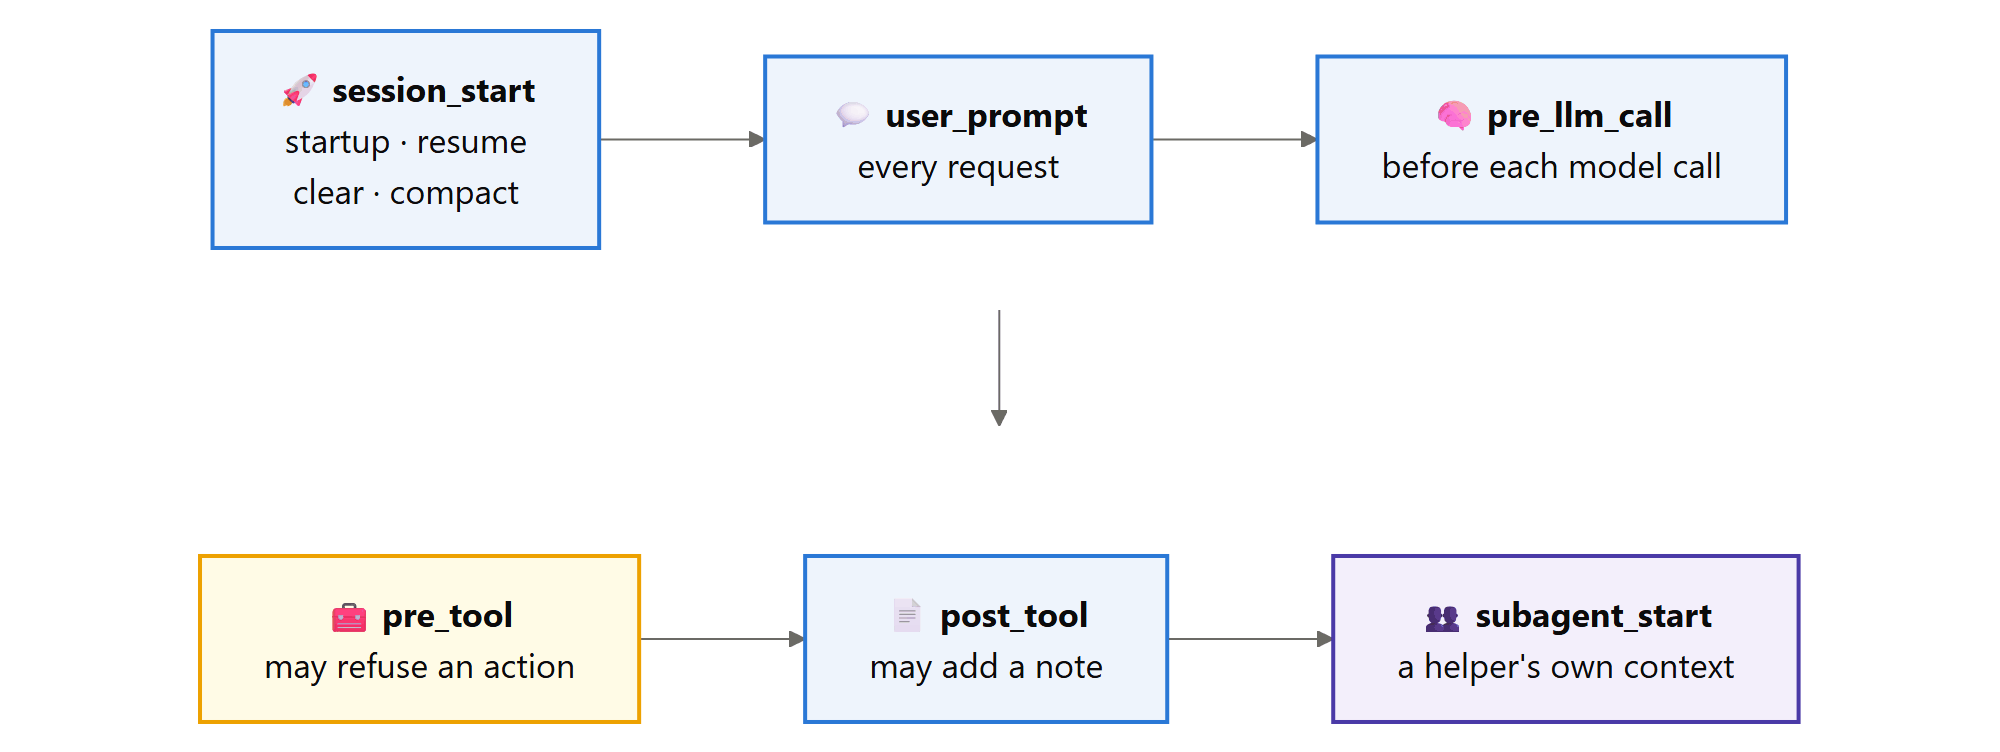

**What happens to one hook.** Each hook runs in its own thread with a time budget. A slow hook still counts; a broken or hung one is logged, counted and skipped, and the agent carries on. The health report is how a broken plugin gets noticed instead of quietly doing nothing.

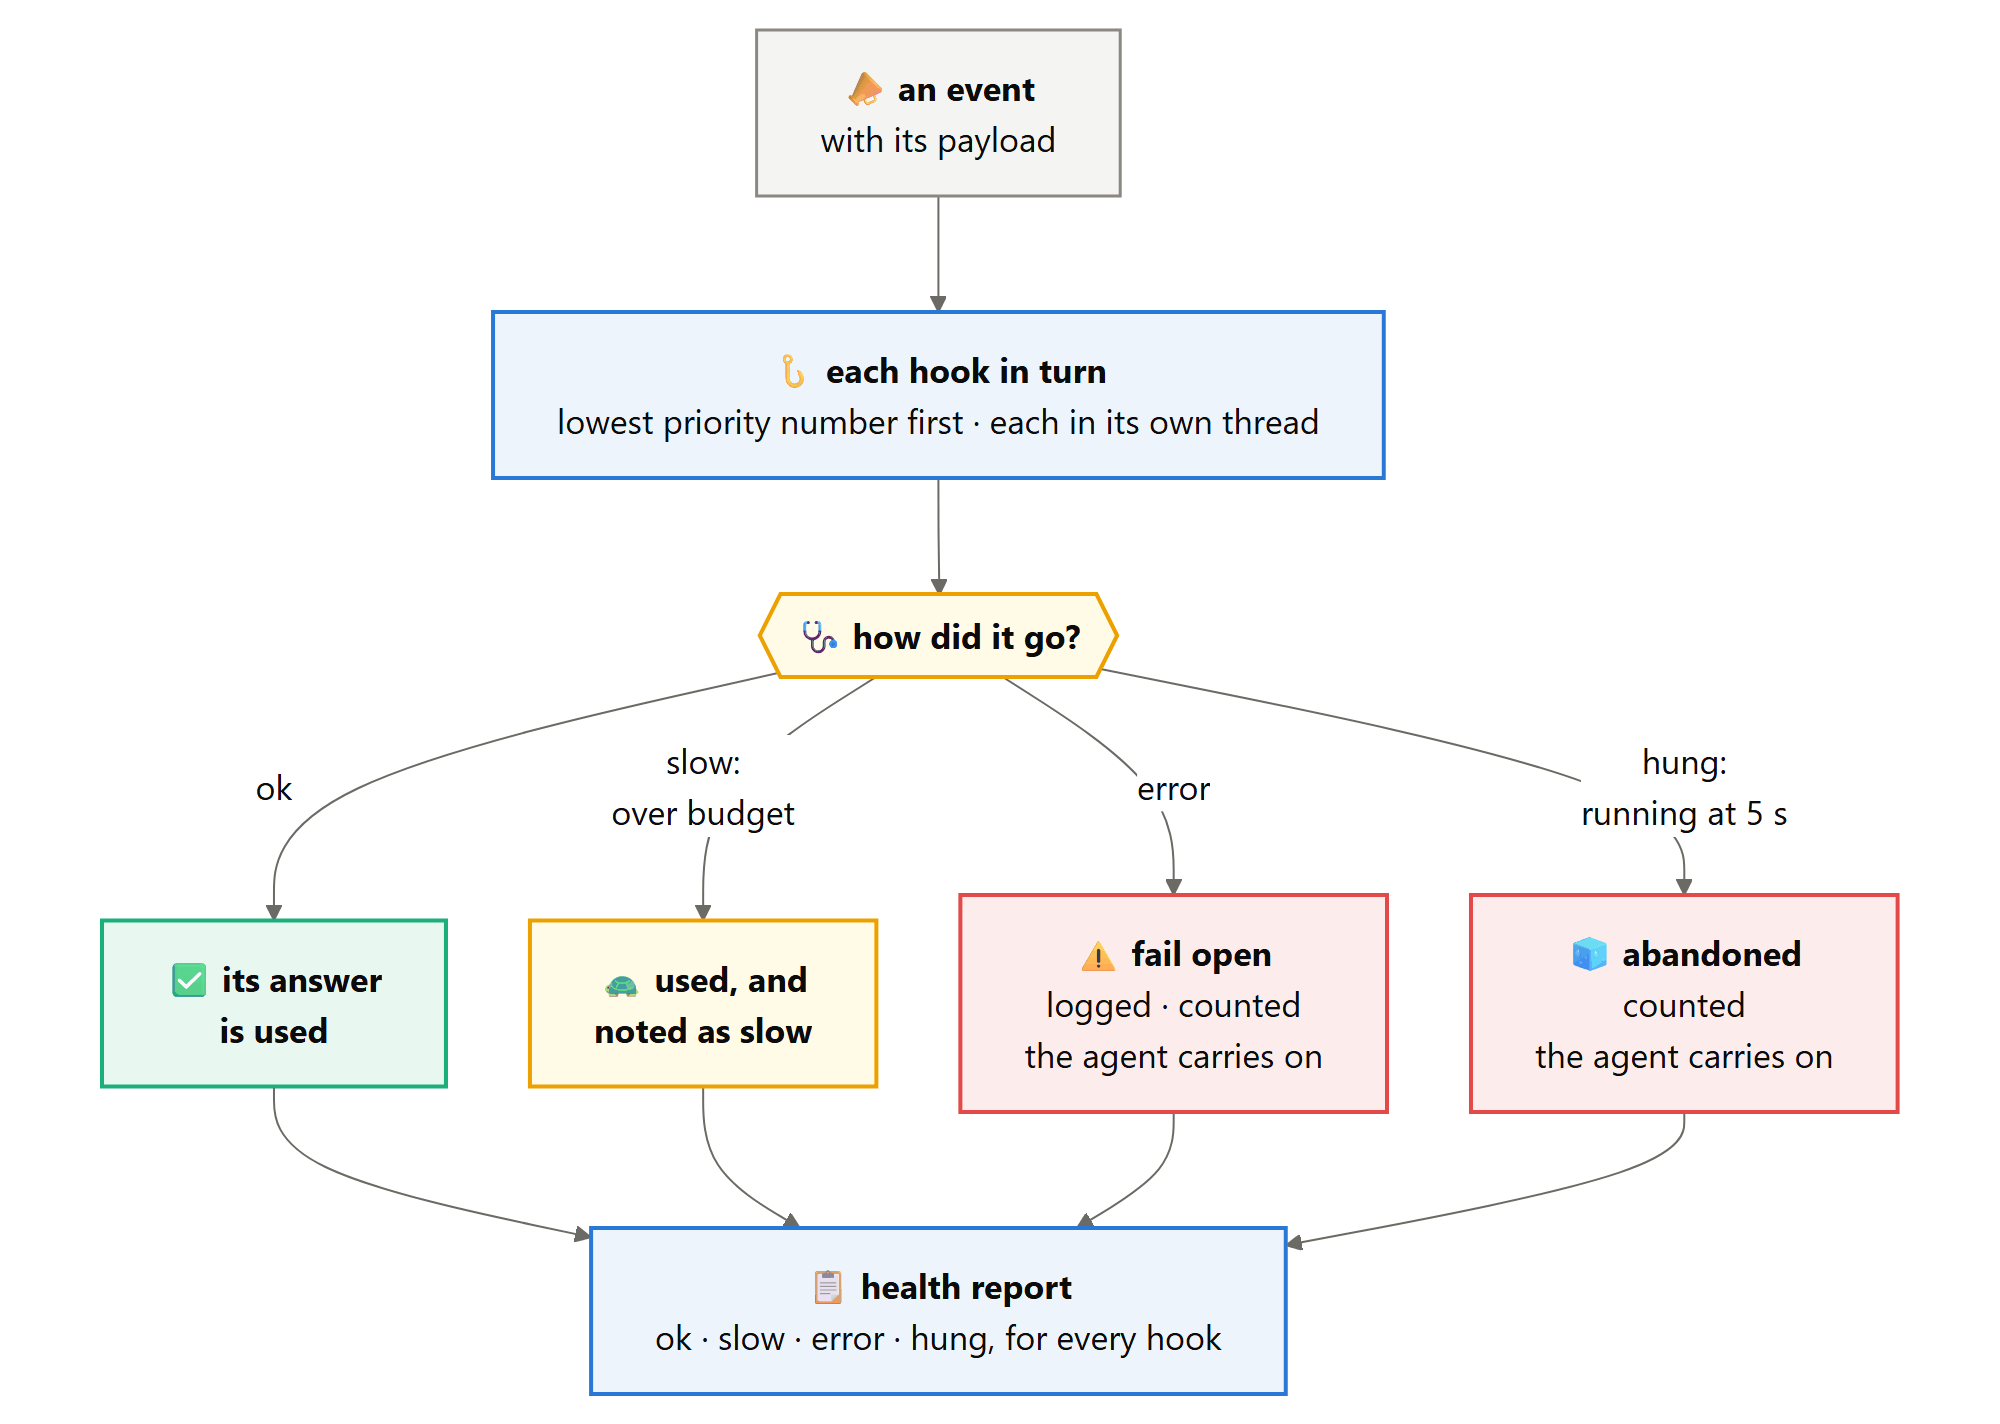

**`Hook`** is one registered listener: the event it listens to, the function to call, a name for the trace and the health report, a priority (lower runs first) and a time budget in milliseconds. The budget is not a hard limit. A hook that overruns it is still waited for and flagged as slow; only one still running after `EventBus.HANG_S` seconds (or after its own budget, if that is longer) is abandoned.

In [344]:
@dataclass
class Hook:
    event: str               # one of EventBus.EVENTS
    fn: object               # called with the event's payload as keyword arguments
    name: str                # how the trace and the health report refer to it
    priority: int = 50       # lower runs first
    budget_ms: float = 50.0  # over this it counts as slow, and is still waited for

show_def(Hook, layer="host")

[class] Hook(event: str, fn: object, name: str, priority: int = 50, budget_ms: ...)  6 lines, complexity 1


**`EventBus`** keeps the hooks for each of the six lifecycle events in `EVENTS`, every list sorted by priority, together with a trace of every hook call and a health counter of outcomes per hook. `HANG_S` is a class attribute, so a demonstration can shorten it for one call and put it back.

In [345]:
class EventBus:
    # the six moments a plugin can hook, in the order a session meets them
    EVENTS = ("session_start", "user_prompt", "pre_llm_call", "subagent_start", "pre_tool", "post_tool")
    HANG_S = 5.0                                   # a hook still running after this is abandoned

    def __init__(self):
        self.hooks = {e: [] for e in self.EVENTS}  # event: its hooks, kept sorted by priority
        self.trace = []                            # every hook call, with its time and outcome
        self.health = Counter()                    # (hook name, outcome): how many times

show_def(EventBus, layer="host")

[class] EventBus()  7 lines, complexity 2


**`EventBus.on(event, fn, name=None, priority=50, budget_ms=50.0)`** registers a hook. An unknown event name is an immediate `ValueError` that lists the real ones, because a hook registered on a misspelt event would never fire and nobody would notice. The list is sorted again by priority after every registration, and Python's sort is stable, so hooks with equal priority keep the order in which they were registered; that is what makes the order of a plugin's hooks predictable.

In [346]:
@method_of(EventBus)
def on(self, event, fn, name=None, priority=50, budget_ms=50.0):
    if event not in self.hooks:                       # a misspelt event would otherwise never fire, silently
        # the message lists the real names, so the typo is easy to spot
        raise ValueError(f"unknown event {event!r}; events are {', '.join(self.EVENTS)}")
    # the function's own name unless a clearer one is given
    self.hooks[event].append(Hook(event, fn, name or fn.__name__, priority, budget_ms))
    self.hooks[event].sort(key=lambda h: h.priority)  # stable: equal priorities keep their registration order

show_def(EventBus.on, layer="host")

[def] EventBus.on(self, event, fn, name=None, priority=50, budget_ms=50.0)  6 lines, complexity 3


In [347]:
order_demo = EventBus()                           # a private bus, just for this demonstration
order_demo.on("pre_tool", lambda **_: None, name="first in, priority 90", priority=90)  # registered first, runs last
order_demo.on("pre_tool", lambda **_: None, name="second in, priority 10", priority=10)  # registered second, runs first
# the same priority: stays behind the second
order_demo.on("pre_tool", lambda **_: None, name="third in, priority 10", priority=10)
print(f"[on] run order: {[h.name for h in order_demo.hooks['pre_tool']]}")  # second, third, first
try:                                              # an event that does not exist
    order_demo.on("pre_tools", lambda **_: None)  # one letter too many
except ValueError as e:                           # refused at registration, not ignored at run time
    print(f"[on] {e}")                            # the message names all six events

[on] run order: ['second in, priority 10', 'third in, priority 10', 'first in, priority 90']
[on] unknown event 'pre_tools'; events are session_start, user_prompt, pre_llm_call, subagent_start, pre_tool, post_tool


**`EventBus.emit(event, **payload)`** calls every hook for an event, in priority order, and returns the answers of those that gave one. Each hook runs in its own daemon thread, and the bus waits for it at most `HANG_S` seconds (or the hook's budget, if that is longer); the outcome is `hung` if the thread is still running, `error` if the hook raised, `slow` if it finished over budget, and `ok` otherwise. Every call is traced and counted. Only `ok` and `slow` answers are returned: a hook that crashed or hung is skipped as if it were not there, which is the fail-open rule, and the counting is what keeps fail-open from being fail-silent.

In [348]:
@method_of(EventBus)
def emit(self, event, **payload):
    """Call every hook for `event`; return [(hook name, result)] for those that returned one."""
    out = []                                                # (hook name, answer) for the hooks that answered
    for h in self.hooks[event]:                             # in priority order
        box, start = {}, time.perf_counter()                # the box carries the answer or the error out of the thread

        def run(h=h, box=box):                              # h and box bound now, not when the thread gets round to it
            try:                                            # anything a hook raises stays in its thread
                box["value"] = h.fn(**payload)              # every hook gets the whole payload; it takes what it needs
            except Exception as e:                          # fail open, but never silently
                box["error"] = f"{type(e).__name__}: {e}"   # for the trace and the health report

        worker = threading.Thread(target=run, daemon=True)  # daemon: a hung hook never keeps Python alive
        worker.start()                                      # the hook starts running now
        worker.join(max(self.HANG_S, h.budget_ms / 1000))   # wait up to HANG_S, or the budget if it is longer
        ms = (time.perf_counter() - start) * 1000           # how long it took, or how long we waited
        if worker.is_alive():                               # still running after the wait
            outcome = "hung"                                # abandoned; an answer that arrives later is ignored
        elif "error" in box:                                # it raised
            outcome = "error"                               # logged and skipped: fail open
        elif ms > h.budget_ms:                              # it answered, but late
            outcome = "slow"                                # flagged, but its answer still counts
        else:
            outcome = "ok"                                  # on time and without an error
        self.health[(h.name, outcome)] += 1                 # the counts the health report is built from
        # every call, so a slow or failing hook can be found
        self.trace.append({"event": event, "hook": h.name, "ms": ms, "outcome": outcome,
                           "detail": box.get("error", "")})
        # only an answer that arrived counts; None means the hook had nothing to say
        if outcome in ("ok", "slow") and box.get("value") is not None:
            out.append((h.name, box["value"]))              # in priority order, for the host to apply
    return out

show_def(EventBus.emit, layer="host")

[def] EventBus.emit(self, event, **payload)  29 lines, complexity 8


**`EventBus.report()`** turns the health counter into one row per hook, with a column for each outcome. The statusline's hook health and the health tables in later Parts are built from it.

In [349]:
@method_of(EventBus)
def report(self):
    """Per hook: calls, and how many were slow, failed or hung."""
    names = sorted({n for n, _ in self.health})  # every hook that has run at least once
    rows = []                                    # one row per hook
    for n in names:                              # in name order
        # a Counter gives 0 for a missing pair
        counts = {o: self.health[(n, o)] for o in ("ok", "slow", "error", "hung")}
        rows.append({"hook": n, **counts})       # the hook's name, then its four counts
    return rows

show_def(EventBus.report, layer="host")

[def] EventBus.report(self)  9 lines, complexity 4


Four hooks on one event, each behaving differently: one answers, one crashes, one is slow, and one hangs for thirty seconds.

In [350]:
bus = EventBus()  # a private bus for the demonstration
bus.on("user_prompt", lambda prompt, **_: {"prefix": "[mode: demo]"}, name="good_hook")  # answers at once
bus.on("user_prompt", lambda prompt, **_: 1 / 0, name="crashing_hook")  # raises
# sleeps past its 50 ms budget, then answers
bus.on("user_prompt", lambda prompt, **_: time.sleep(0.12) or {"prefix": "[late]"}, name="slow_hook", budget_ms=50)
bus.on("user_prompt", lambda prompt, **_: time.sleep(30), name="hanging_hook")  # far too long
# equal priorities, so registration order
print(f"[bus] hooks on user_prompt, in the order they will run: {[h.name for h in bus.hooks['user_prompt']]}")

[bus] hooks on user_prompt, in the order they will run: ['good_hook', 'crashing_hook', 'slow_hook', 'hanging_hook']


One event. The hang limit is shortened to half a second for the demonstration and put back straight after.

In [351]:
EventBus.HANG_S = 0.5                                    # shortened for the demo; the real limit is 5s
t0 = time.perf_counter()                                 # time the whole event
answers = bus.emit("user_prompt", prompt="add a cache")  # one event, four hooks
EventBus.HANG_S = 5.0                                    # the real limit again, before anything else runs
# well under a second, and only the good and the slow hooks' answers come back
print(f"[bus] one user_prompt event, four hooks, {time.perf_counter() - t0:.2f}s; results the host applies: {answers}")

[bus] one user_prompt event, four hooks, 0.63s; results the host applies: [('good_hook', {'prefix': '[mode: demo]'}), ('slow_hook', {'prefix': '[late]'})]


In [352]:
# one row per hook: each misbehaviour is counted in its own column
table(bus.report(), [("hook", "hook", ""), ("ok", "ok", "d"), ("slow", "slow", "d"), ("error", "error", "d"), ("hung", "hung", "d")])
for t in bus.trace:  # the trace: every call, with its time and what went wrong
    # the error text, where there was one
    print(f"  {t['hook']:<14} {t['ms']:>7.1f} ms  {t['outcome']:<6} {t['detail']}")
# the three properties, seen at once
print("  -> the crash and the hang were recorded and skipped; the slow hook's answer still counts")

  hook           ok  slow  error  hung
  ------------------------------------
  crashing_hook   0     0      1     0
  good_hook       1     0      0     0
  hanging_hook    0     0      0     1
  slow_hook       0     1      0     0
  good_hook          0.6 ms  ok     
  crashing_hook      0.4 ms  error  ZeroDivisionError: division by zero
  slow_hook        120.6 ms  slow   
  hanging_hook     510.6 ms  hung   
  -> the crash and the hang were recorded and skipped; the slow hook's answer still counts


Why hooks run in the host's own process: the price of a hook that is a separate program. **`in_process_hook(prompt, **_)`** stands in for a real header hook, a function that returns a one-line prefix. The cell after it calls it twenty times, and compares that with starting a Python process, plain and fenced, that prints the same line.

In [353]:
def in_process_hook(prompt, **_):
    if prompt:                            # any prompt gets the header
        return {"prefix": "[lean:full]"}  # the shape of a real header hook's answer
    return None

show_def(in_process_hook, layer="lab")

[def] in_process_hook(prompt, **_)  4 lines, complexity 2


In [354]:
# the seconds each way of running a hook takes, per call
timings = {"in-process function": [], "a Python subprocess": [], "a fenced subprocess": []}
for _ in range(20):                                    # a function call is too quick to time just once
    t0 = time.perf_counter()                           # start the clock
    in_process_hook(prompt="x")                        # the whole cost of an in-process hook
    timings["in-process function"].append(time.perf_counter() - t0)  # seconds for one call
for _ in range(8):                                     # starting processes is slow, so fewer samples
    t0 = time.perf_counter()                           # start the clock
    # a hook as a separate Python program, with a minimal environment
    subprocess.run([sys.executable, "-c", "print('[lean:full]')"], capture_output=True, env=bare_env)
    timings["a Python subprocess"].append(time.perf_counter() - t0)  # seconds for one process
    # the same program inside the fence, which adds its own start-up
    timings["a fenced subprocess"].append(run_fenced(probe, ["-c", "print('[lean:full]')"]).seconds)
HOOK_COST = {k: float(np.median(v)) for k, v in timings.items()}  # the median, so one slow start does not skew it
for k, v in HOOK_COST.items():                         # one line per way of running a hook
    print(f"  {k:<22} {v * 1000:>10.3f} ms per call")  # in milliseconds
per_turn = 3                                           # user_prompt, pre_tool and post_tool fire on every turn
# what each choice would cost over one whole episode
print(f"\n  at {per_turn} hooked events a turn and {MAX_TURNS} turns, subprocess hooks would add "
      f"{HOOK_COST['a Python subprocess'] * per_turn * MAX_TURNS:.1f}s per episode; in-process ones "
      f"{HOOK_COST['in-process function'] * per_turn * MAX_TURNS * 1000:.2f} ms")

  in-process function         0.001 ms per call
  a Python subprocess       105.661 ms per call
  a fenced subprocess       138.755 ms per call

  at 3 hooked events a turn and 20 turns, subprocess hooks would add 6.3s per episode; in-process ones 0.04 ms


Command-line agent tools often run hooks as separate programs, so that any language can be used. That flexibility has a price, and the measurement above puts a number on it: a few microseconds for a function call against tens of milliseconds for a process. Our hooks are Python functions in the host's own process, which is the right trade-off for a host and a plugin that are written together. The fence is not involved here, because hooks are our code, not the agent's.

## S17 - The context manager: one system message, stable sections, compaction

**Theory.** What the model sees on each call is built by the context manager, and three of its decisions matter later. **One system message.** Everything the host and the plugins want to say permanently goes into named *sections* of a single system message, in a fixed order. Some APIs reject a second system message, some silently ignore it, and some merge it in a way nobody documented; one message works everywhere. **Stable order.** Sections are rendered by rank, never by the order hooks happened to fire, so the system message is byte-identical from turn to turn unless something really changed. That makes it friendly to providers that cache a long, unchanging prefix, and it makes a change visible as a new fingerprint. **Compaction.** When the conversation grows past a budget, it is summarised: the first ticket, the latest request and the last few turns are kept, the turns in between become one paragraph listing what was done, and every section except the host's own instructions is dropped. That includes the project's instructions file and the skills index, which the host does not put back; plugins hear a `session_start` with the source `compact` and must restore their own sections. That last step is deliberate. It reproduces what real agents suffer (a long session loses whatever was injected into it), and it is why a plugin must listen for `session_start` with source `compact` and put its rules back. Part V measures what happens when it does not.

**In plain terms.** The model always gets one tidy system message plus the conversation. When the conversation gets too long, the middle is replaced by a summary, and whatever plugins added has to be added again.

**What compaction keeps.** The first ticket and the latest request survive word for word, the last three exchanges stay as they were, and the middle becomes one message listing the steps. Every section but the host's own is dropped, which is the gap Part V's compaction hook exists to close.

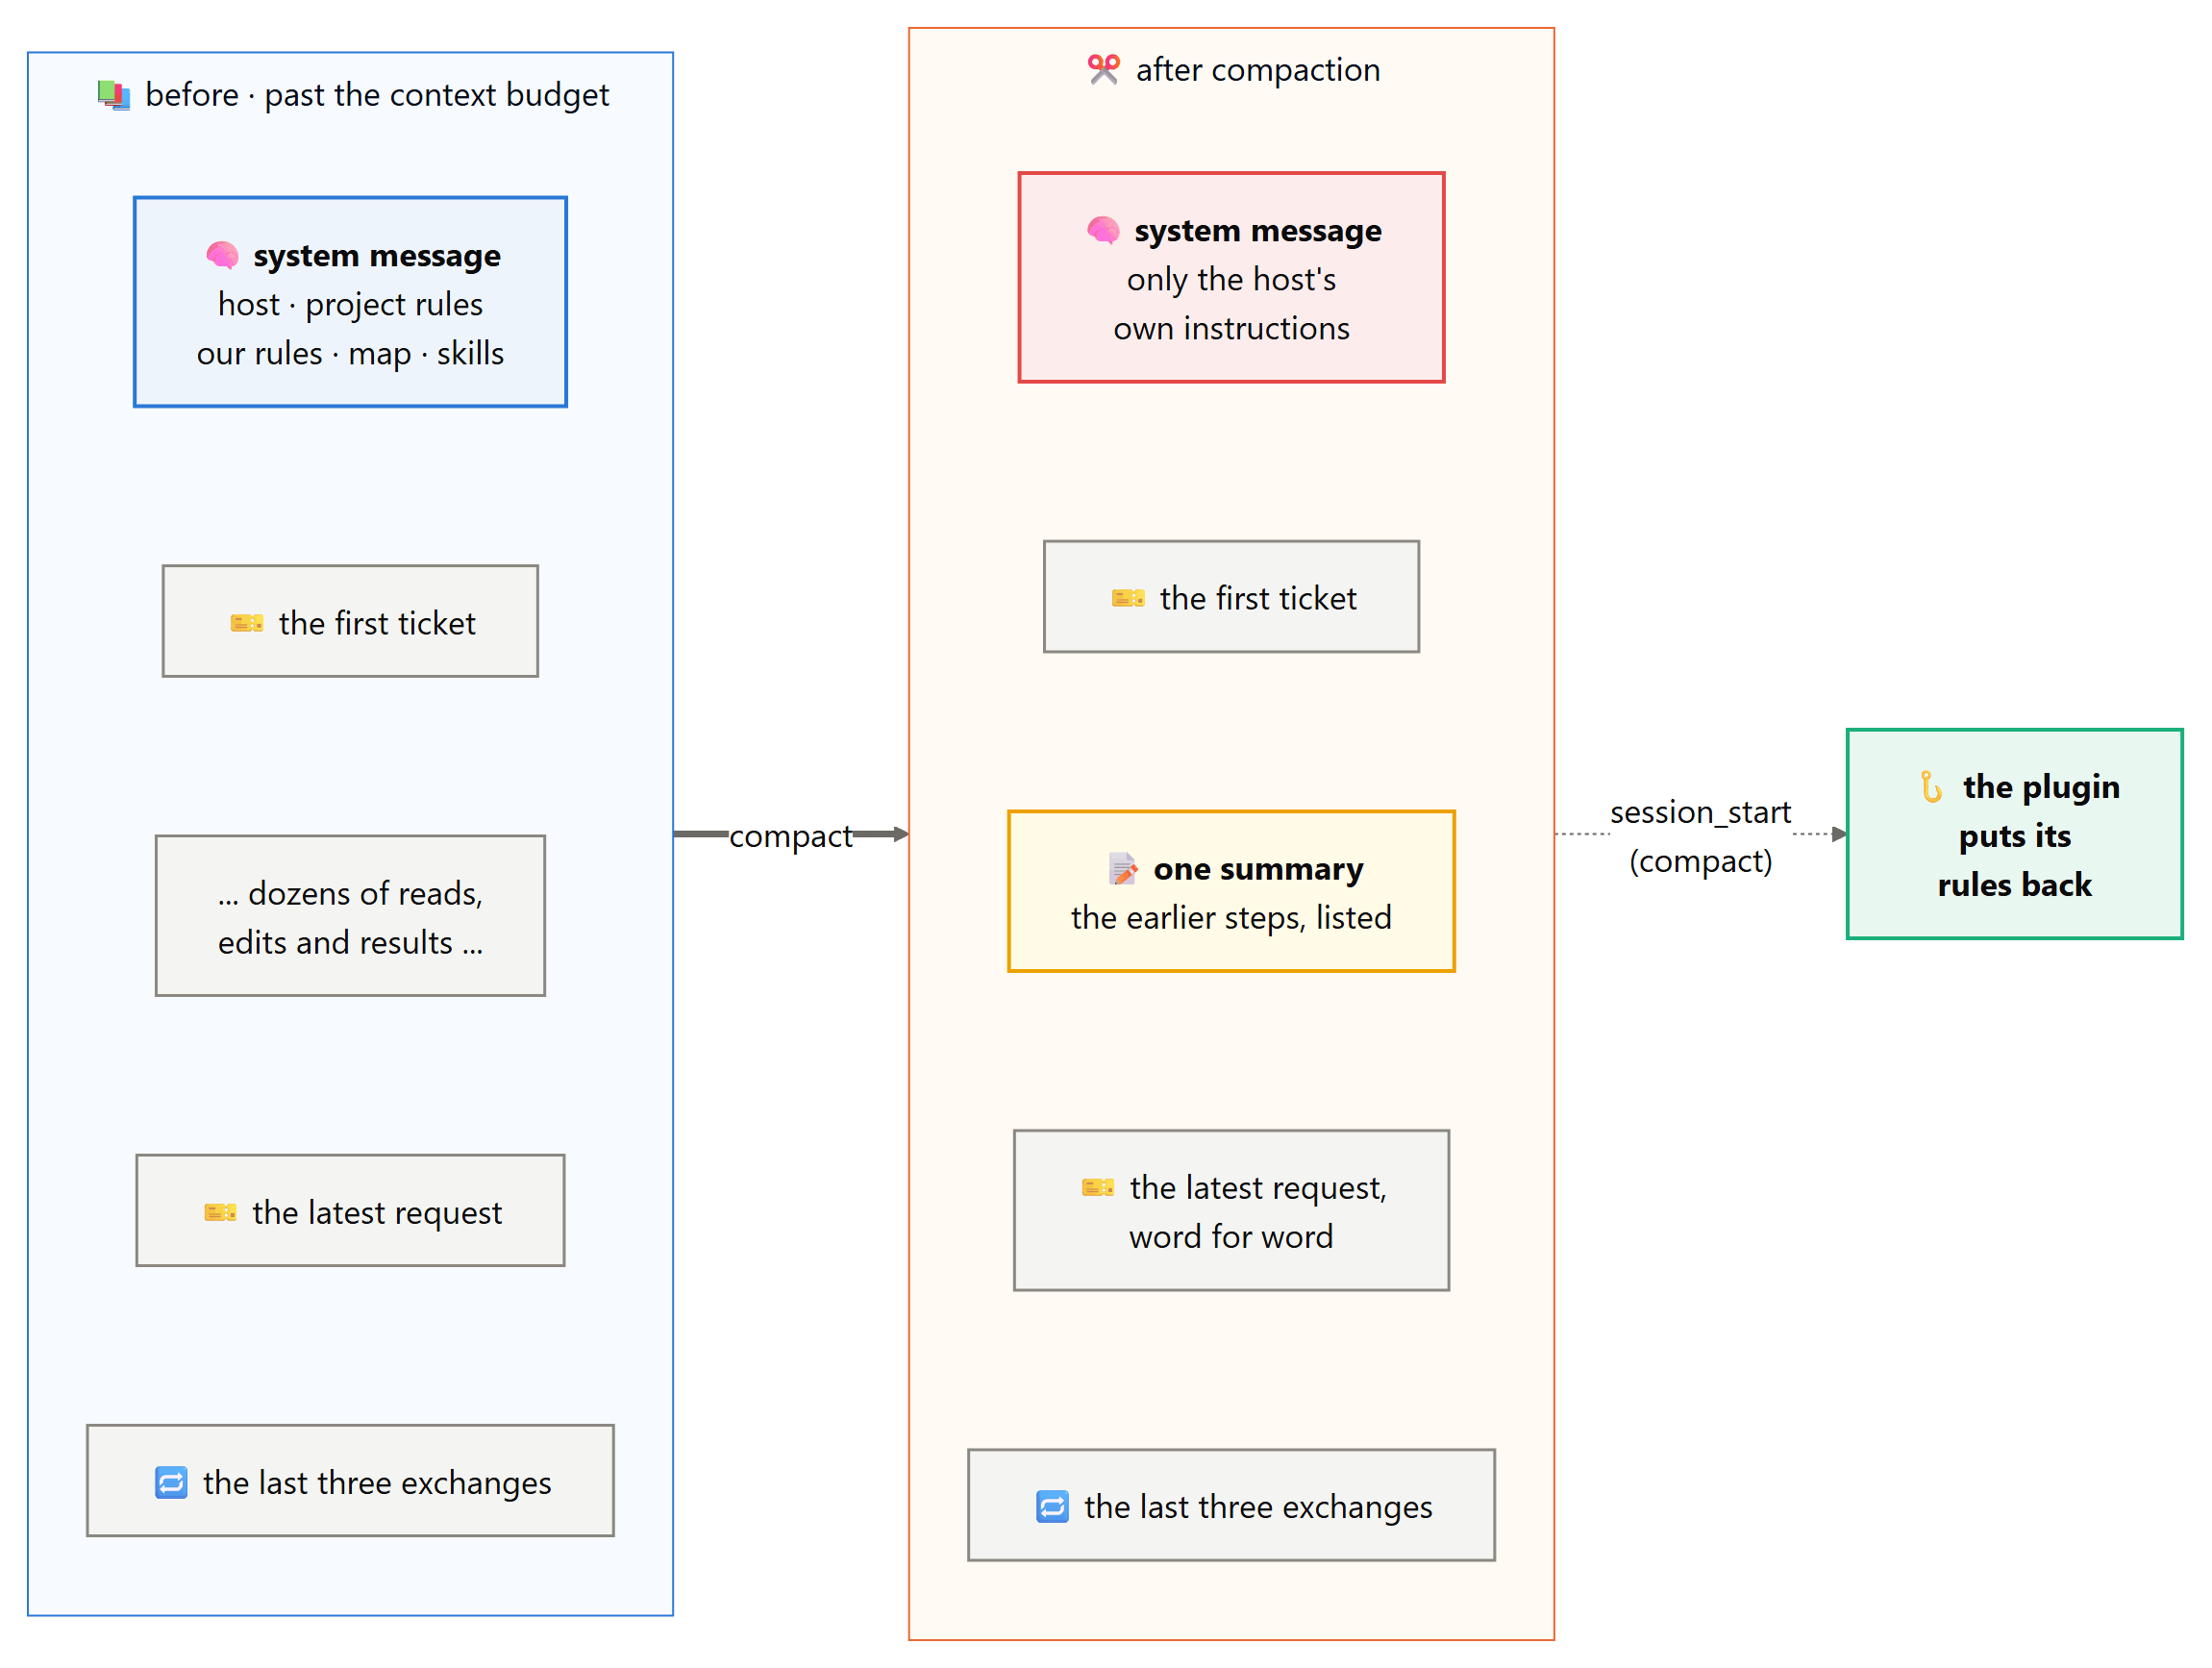

**`Context`** holds what the model sees: a dict of named *sections* that together make one system message, and the list of conversation turns that follow it. Each section is stored with a rank, and the host's own prompt is the `host` section at rank 0, so it always comes first. `CONTEXT_BUDGET` is the size, in estimated tokens, at which the host compacts the conversation, and `SECTION_CAP` is the most any one section may hold. Two counters record how often a section had to be cut and how often the conversation was compacted, so a report can show both.

In [355]:
CONTEXT_BUDGET = 24_000                      # tokens; S40 lowers it on purpose to force compaction
SECTION_CAP = 16_000                         # characters per section; more is truncated, and counted

class Context:
    """What the model sees: one system message built from ranked sections, then the turns."""

    def __init__(self, base=BASE_PROMPT):
        self.sections = {"host": (0, base)}  # name: (rank, text); rank 0 puts the host's prompt first
        self.messages = []                   # the conversation after the system message
        self.truncated = 0                   # sections cut down to SECTION_CAP
        self.compactions = 0                 # times the conversation was summarised

show_def(Context, layer="host")

[class] Context(base='You are a coding agent. You work inside a project folder and...)  7 lines, complexity 1


**`Context.set_section(name, text, rank=50)`** adds a section or replaces one. A section longer than `SECTION_CAP` characters keeps its head, gains a `[truncated]` line and is counted, because one oversized project file must not crowd the conversation out of the context. Setting a section to the text it already has leaves the system message byte-identical, which is what keeps its fingerprint stable from turn to turn.

In [356]:
@method_of(Context)
def set_section(self, name, text, rank=50):
    if len(text) > SECTION_CAP:                      # an oversized section would crowd out the conversation
        text = text[:SECTION_CAP] + "\n[truncated]"  # keep the head, and say that it was cut
        self.truncated += 1                          # counted, so a report can show it happened
    self.sections[name] = (rank, text)               # rank decides the order in the system message

show_def(Context.set_section, layer="host")

[def] Context.set_section(self, name, text, rank=50)  6 lines, complexity 2


In [357]:
sections_demo = Context(base="HOST RULES")                    # a short base prompt keeps the output readable
sections_demo.set_section("plugin", "PLUGIN RULES", rank=20)  # an ordinary section
sections_demo.set_section("huge", "x" * (SECTION_CAP + 500), rank=30)  # over the cap on purpose
# 16,000 characters plus the marker line, and one truncation counted
print(f"[section] the huge section kept {len(sections_demo.sections['huge'][1])} characters "
      f"(the cap plus a [truncated] line); truncations counted: {sections_demo.truncated}")

[section] the huge section kept 16012 characters (the cap plus a [truncated] line); truncations counted: 1


**`Context.drop_section(name)`** removes a section, and removing one that is not there is not an error. A plugin uses it to take its rules out when the user switches it off.

In [358]:
@method_of(Context)
def drop_section(self, name):
    self.sections.pop(name, None)  # dropping a section that is not there is not an error

show_def(Context.drop_section, layer="host")

[def] Context.drop_section(self, name)  3 lines, complexity 1


In [359]:
sections_demo.drop_section("huge")       # gone from the system message
sections_demo.drop_section("never-set")  # quietly ignored
print(f"[section] sections left: {list(sections_demo.sections)}")  # host and plugin

[section] sections left: ['host', 'plugin']


**`Context.system_text()`** renders the sections into the one system message: sorted by rank, then by name when two ranks are equal, and separated by blank lines. Sorting by rank rather than by insertion order is the point. Hooks fire in whatever order they fire, but as long as the sections are the same, the message comes out the same, byte for byte.

In [360]:
@method_of(Context)
def system_text(self):
    ordered = sorted(self.sections.items(), key=lambda kv: (kv[1][0], kv[0]))  # by rank, then by name on a tie
    return "\n\n".join(text for _, (rank, text) in ordered)  # a blank line between sections

show_def(Context.system_text, layer="host")

[def] Context.system_text(self)  4 lines, complexity 2


In [361]:
sections_demo.set_section("skills", "SKILLS INDEX", rank=90)    # rank 90: near the end
sections_demo.set_section("project", "PROJECT RULES", rank=10)  # set last, but rank 10 puts it second
system_blocks = sections_demo.system_text().split("\n\n")       # the system message, cut at its blank lines
print(f"[system] the system message, block by block: {system_blocks}")  # host, project, plugin, skills: by rank

[system] the system message, block by block: ['HOST RULES', 'PROJECT RULES', 'PLUGIN RULES', 'SKILLS INDEX']


**`Context.render()`** is the list of messages that goes to the model: the system message first, then every turn in order. It is built afresh on each call, so the system message is always current.

In [362]:
@method_of(Context)
def render(self):
    return [{"role": "system", "content": self.system_text()}] + self.messages  # one system message, then the turns

show_def(Context.render, layer="host")

[def] Context.render(self)  3 lines, complexity 1


In [363]:
print(f"[render] {sections_demo.render()}")  # one system message and, so far, no turns

[render] [{'role': 'system', 'content': 'HOST RULES\n\nPROJECT RULES\n\nPLUGIN RULES\n\nSKILLS INDEX'}]


**`Context.fingerprint()`** is a short hash of the system message, recorded on every turn. Part V uses it to show which rules a model really had in front of it on each turn; ten hexadecimal digits are plenty to tell the versions within one episode apart.

In [364]:
@method_of(Context)
def fingerprint(self):
    return hashlib.sha256(self.system_text().encode()).hexdigest()[:10]  # ten hex digits tell versions apart

show_def(Context.fingerprint, layer="host")

[def] Context.fingerprint(self)  3 lines, complexity 1


In [365]:
fp_before = sections_demo.fingerprint()                       # before
sections_demo.set_section("plugin", "PLUGIN RULES", rank=20)  # the same text again
fp_same = sections_demo.fingerprint()                         # after setting the same text: unchanged
sections_demo.set_section("plugin", "PLUGIN RULES, revised", rank=20)  # a real change
# expect the first two to match and the third to differ
print(f"[fingerprint] {fp_before}, then {fp_same} after setting the same text again, "
      f"then {sections_demo.fingerprint()} after a change")

[fingerprint] 333eae0f84, then 333eae0f84 after setting the same text again, then a8950658bc after a change


**`Context.tokens()`** estimates the size of the rendered context at four characters a token. It does not need to be exact: its only job is to decide when to compact, and an estimate is enough for that.

In [366]:
@method_of(Context)
def tokens(self):
    return sum(len(m["content"]) for m in self.render()) // 4  # about four characters a token

show_def(Context.tokens, layer="host")

[def] Context.tokens(self)  3 lines, complexity 2


In [367]:
n_chars = sum(len(m["content"]) for m in sections_demo.render())  # every character the model would receive
# a quarter of the characters
print(f"[tokens] {n_chars} characters in the rendered context, about {sections_demo.tokens()} tokens")

[tokens] 62 characters in the rendered context, about 15 tokens


**`Context.add(role, content)`** appends one turn. Every message the conversation ever holds comes in through here, and none of them touches the system message, so the fingerprint does not move.

In [368]:
@method_of(Context)
def add(self, role, content):
    self.messages.append({"role": role, "content": content})  # the conversation only ever grows here

show_def(Context.add, layer="host")

[def] Context.add(self, role, content)  3 lines, complexity 1


In [369]:
fp_before_turns = sections_demo.fingerprint()            # the system message before any turn
sections_demo.add("user", "Ticket: add a cache.")        # the ticket
sections_demo.add("assistant", '<read path="geo.py"/>')  # the agent's first action
# system, user, assistant; turns never touch the system message
print(f"[add] roles in order: {[m['role'] for m in sections_demo.render()]}; "
      f"fingerprint unchanged: {sections_demo.fingerprint() == fp_before_turns}")

[add] roles in order: ['system', 'user', 'assistant']; fingerprint unchanged: True


**`Context.compact(keep_turns=3)`** shrinks a long conversation. The first message (the ticket) and the last `keep_turns` exchanges are kept as they are. Every turn in between becomes one step in a single summary message, built from the actions themselves (`read geo.py`, `edit geo.py`, `run tests_visible.py`), while a later request from the user is also kept word for word, because it is the work in progress. Then every section except the host's is dropped, which is what a long session in a real agent suffers, and it returns the summary so that a caller can show it.

In [370]:
@method_of(Context)
def compact(self, keep_turns=3):
    """Keep the first ticket, the latest request and the last `keep_turns` exchanges;
    summarise the rest in one message; drop every section but the host's. Returns the summary."""
    head = self.messages[:1]                                  # the ticket that started the session
    tail = self.messages[1:][-2 * keep_turns:]                # the last exchanges, two messages each
    middle = self.messages[1:len(self.messages) - len(tail)]  # everything between the ticket and the kept tail
    steps, latest = [], []                                    # the summary's parts, and the request in progress
    for m in middle:                                          # oldest first
        if m["role"] == "assistant":                          # each action becomes a step, such as "read geo.py"
            try:                                              # an unreadable reply has no action to name
                a = parse_action(m["content"])                # the same parser the loop uses
                # the action and what it touched, such as "read geo.py" or "run tests_visible.py"
                steps.append(f"{a.name} {a.args.get('path') or a.args.get('args') or a.args.get('pattern') or ''}".strip())
            except ProtocolError:                             # a reply without an action
                steps.append("(a reply without an action)")   # still a step, so the count stays honest
        # results and old summaries are skipped
        elif not m["content"].startswith(("<result", "Summary of earlier work")):
            # a later message from the user, shortened in the list
            steps.append("new request: " + textwrap.shorten(m["content"], 60))
            # a later ticket: the one in progress must survive verbatim
            latest = [m]
    if steps:                                                 # something happened in the middle
        # one sentence listing every step, in order
        summary = "Summary of earlier work in this session: " + "; ".join(steps) + "."
    else:
        summary = "Summary of earlier work in this session: nothing yet."  # too short to have a middle
    # the ticket, the summary, the request in progress, then the last exchanges
    self.messages = head + [{"role": "user", "content": summary}] + latest + tail
    self.sections = {"host": self.sections["host"]}           # only the host's own prompt survives
    self.compactions += 1                                     # counted for the reports
    return summary

show_def(Context.compact, layer="host")

[def] Context.compact(self, keep_turns=3)  26 lines, complexity 9


A session in miniature: the host's prompt alone, then two sections, then twelve turns, each with a 300-line result. The fingerprint changes once, when the sections arrive, and never again, however many turns follow.

In [371]:
ctx = Context()                                             # the real host prompt this time
fp = [ctx.fingerprint()]                                    # the host's prompt alone
ctx.set_section("plugin:rules", "Rules from a plugin.", rank=20)  # a plugin's section
ctx.set_section("project", "Rules from the project's AGENTS.md.", rank=10)  # the project's own rules, ranked before it
fp.append(ctx.fingerprint())                                # the host plus two sections
for n in range(12):                                         # twelve turns
    if n == 0:                                              # the first turn
        ctx.add("user", "Ticket: add a cache.")             # the ticket opens the conversation
    else:
        ctx.add("assistant", f'<read path="file{n}.py"/>')  # then one read per turn
    ctx.add("user", f'<result action="read">\n' + "x = 1\n" * 300 + "</result>")  # a 300-line result each time
    fp.append(ctx.fingerprint())                            # after every turn
# host, project, plugin:rules: by rank, not by the order they were set
print(f"[context] sections in render order: {[name for name, _ in sorted(ctx.sections.items(), key=lambda kv: kv[1][0])]}")
# fourteen fingerprints, only two different ones
print(f"[context] system fingerprints over {len(fp)} steps: {len(set(fp))} distinct "
      f"(the host alone, then host + two sections, unchanged by every turn that followed)")

[context] sections in render order: ['host', 'project', 'plugin:rules']
[context] system fingerprints over 14 steps: 2 distinct (the host alone, then host + two sections, unchanged by every turn that followed)


In [372]:
messages = ctx.render()  # what the model would be sent now
# one system message however many sections, and well over the budget in tokens
print(f"[context] {sum(m['role'] == 'system' for m in messages)} system message, {len(messages) - 1} turns, "
      f"about {ctx.tokens()} tokens")

[context] 1 system message, 24 turns, about 5860 tokens


Compaction, keeping the last two exchanges. The summary lists what the agent did, and every section but the host's is gone: that is the gap a plugin closes by listening for `session_start` with source `compact`.

In [373]:
before = ctx.tokens()                   # the size before compaction
summary = ctx.compact(keep_turns=2)     # the last two exchanges are kept
# much smaller, and only the host's section is left
print(f"[compact] {before} -> {ctx.tokens()} tokens; sections left: {list(ctx.sections)}")
print(f"[compact] {summary[:150]}...")  # the start of the summary message

[compact] 5860 -> 1257 tokens; sections left: ['host']
[compact] Summary of earlier work in this session: read file1.py; read file2.py; read file3.py; read file4.py; read file5.py; read file6.py; read file7.py; read...


## S18 - Skills: instructions loaded only when they are needed

**Theory.** A *skill* is a packaged set of instructions for one kind of job ("review this diff for over-engineering", "audit the repository"), kept out of the context until it is needed. Each skill is a Markdown file with a short header: a `name`, a `description` that says when to use it, an optional `argument-hint`, and a `mode` (`one-shot` instructions apply to one request; `persistent` ones stay until switched off). The host puts only the names and descriptions in the system message, a line each, and loads a skill's body when it is invoked. This is *progressive disclosure*, and it matters for cost: six skills described in six lines cost almost nothing per call, where six bodies on every call would cost thousands of tokens. Because the description is the only thing the model sees until the skill is used, it has to be written as a **trigger**: it says when the skill applies, not what is inside it (S35 measures how much the wording matters). A skill is invoked as `/name`, `/plugin:name`, `@name` or `$name`, the forms users of different agent tools already type.

**In plain terms.** A skill is a recipe the agent knows the title of and reads only when asked.

**Progressive disclosure.** The model sees one line per skill until a prompt names one. Then a one-shot body joins that request only, and a persistent one stays in the system message until it is switched off.

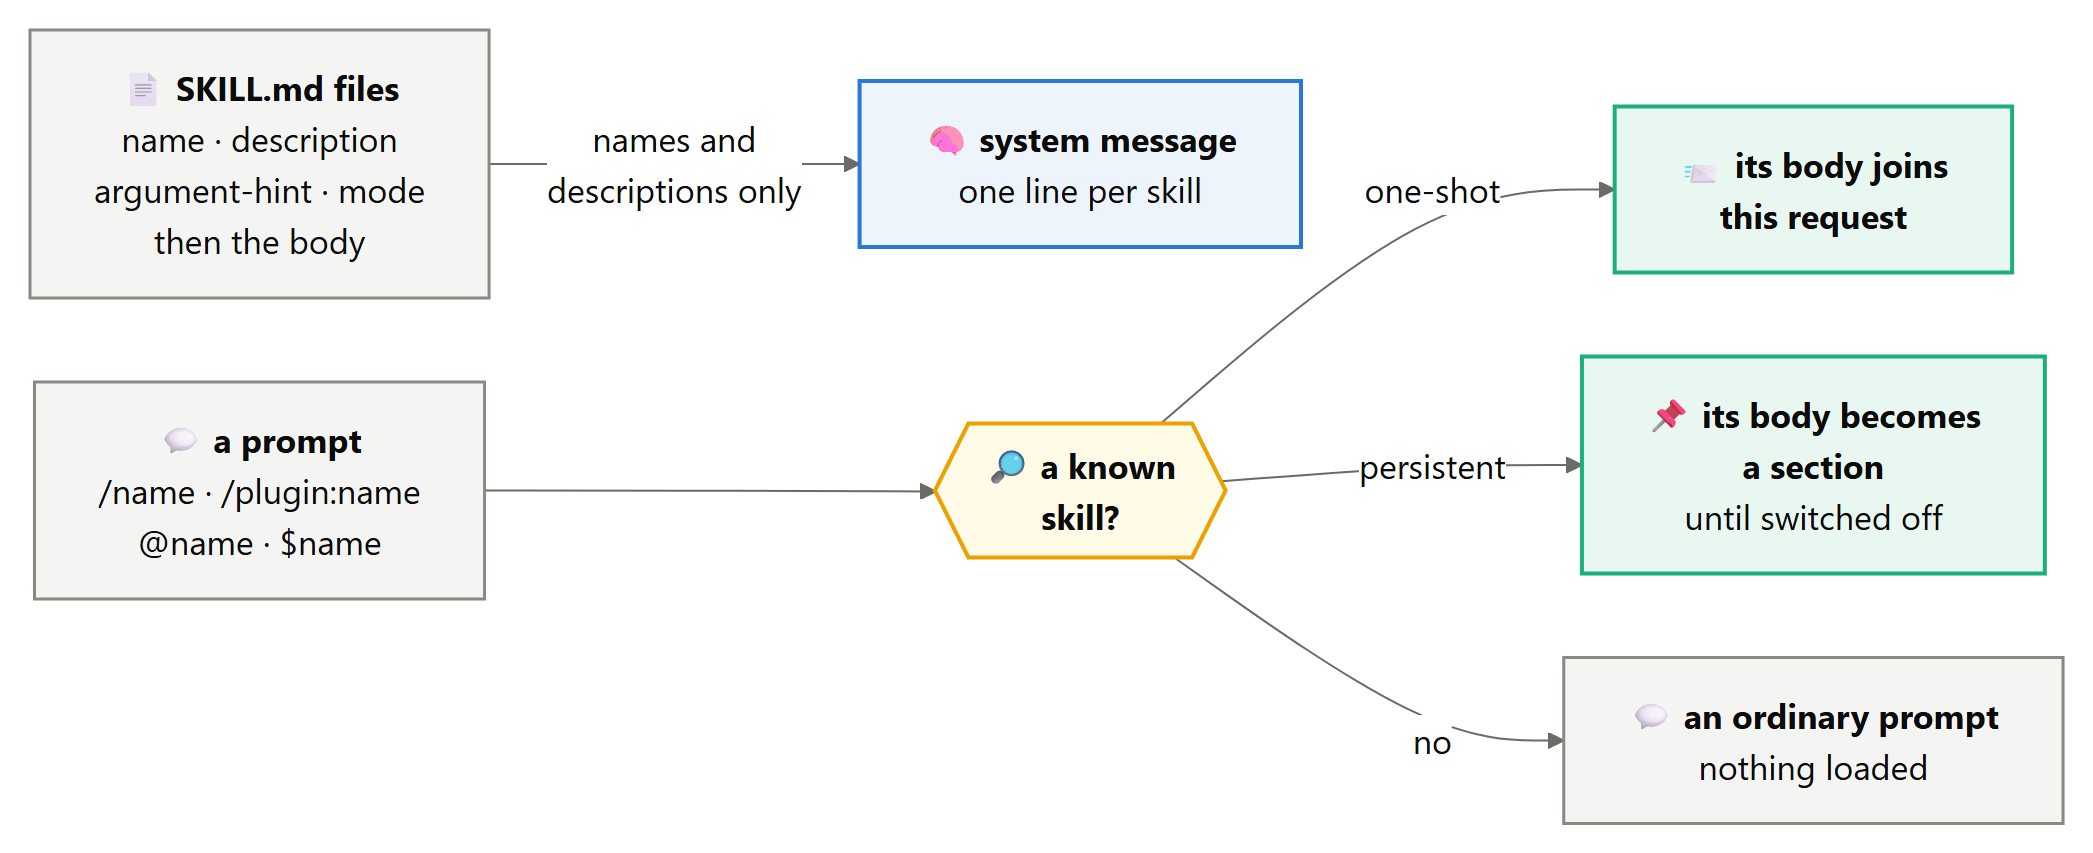

**`Skill`** is one skill as loaded from its file: the name a user types, the description that tells the model when it applies, the body that is loaded only on use, an optional hint about arguments, its mode, the namespace of the plugin it came from, and the file itself. It is a plain record: everything a skill does happens in the registry and the host.

In [374]:
@dataclass
class Skill:
    name: str                # what the user types after the slash
    description: str         # when to use it: all the model sees until the skill is used
    body: str                # the instructions themselves, loaded on use
    argument_hint: str = ""  # what may follow the name, if anything
    mode: str = "one-shot"   # or persistent
    namespace: str = ""      # the plugin it came from, for /plugin:name
    path: Path = None        # the SKILL.md it was read from

show_def(Skill, layer="host")

[class] Skill(name: str, description: str, body: str, argument_hint: str = '', m...)  8 lines, complexity 1


**`parse_skill(text, path=None, namespace="")`** reads a `SKILL.md`: a header of `key: value` lines between two `---` lines, then the body. A byte-order mark is stripped first, because it would otherwise hide the opening `---`, and quotes round the description are removed. A file without a header, or without a `name` and a `description`, is an error that names the file, since a skill nobody can trigger is a mistake worth hearing about.

In [375]:
def parse_skill(text, path=None, namespace=""):
    """A SKILL.md file: a '---' header of key: value lines, then the body."""
    text = text.lstrip("\ufeff")                  # a byte-order mark would hide the opening ---
    # the header between two --- lines, then everything after it
    m = re.match(r"---\s*\n(.*?)\n---\s*\n(.*)", text, re.S)
    if not m:                                        # no header at all
        # names the file, so the broken skill is easy to find
        raise ValueError(f"[skill] {path}: no header between '---' lines")
    head = dict(re.findall(r"^([\w-]+):\s*(.*?)\s*$", m.group(1), re.M))  # one key: value per header line
    missing = {"name", "description"} - head.keys()  # the two keys every skill needs
    if missing:                                      # a skill nobody can trigger
        # says which keys are missing, in a stable order
        raise ValueError(f"[skill] {path}: missing {', '.join(sorted(missing))}")
    return Skill(head["name"],
                 head["description"].strip('"'),     # a quoted description loses its quotes
                 m.group(2).strip(),                 # the body: everything after the second ---
                 head.get("argument-hint", ""),
                 head.get("mode", "one-shot"),
                 namespace, path)

show_def(parse_skill, layer="host")

[def] parse_skill(text, path=None, namespace='')  16 lines, complexity 3


In [376]:
# a skill file saved with a byte-order mark and a quoted description
skill_text = '\ufeff---\nname: explain\ndescription: "Use when the user asks why."\n---\nExplain the design.\n'
print(f"[skill] {parse_skill(skill_text, path='explain/SKILL.md')}")  # the mark and the quotes are gone
try:                                                       # a file with no header
    parse_skill("no header here", path="broken/SKILL.md")  # should raise
except ValueError as e:                                    # the error names the file
    print(f"[skill] {e}")                                  # the message a skill's author would see

[skill] Skill(name='explain', description='Use when the user asks why.', body='Explain the design.', argument_hint='', mode='one-shot', namespace='', path='explain/SKILL.md')
[skill] [skill] broken/SKILL.md: no header between '---' lines


**`SkillRegistry`** holds the loaded skills by name. `INVOKE` is the one pattern for every way of calling a skill: `/`, `@` or `$`, an optional `plugin:` prefix, the skill's name, and whatever the user typed after it.

In [377]:
class SkillRegistry:
    # /name, @name or $name, with an optional plugin: prefix, then the rest of the prompt
    INVOKE = re.compile(r"^\s*([/@$])(?:([\w-]+):)?([\w-]+)\b\s*(.*)$", re.S)

    def __init__(self):
        self.skills = {}  # name: Skill; a later skill with the same name replaces the earlier one

show_def(SkillRegistry, layer="host")

[class] SkillRegistry()  4 lines, complexity 1


**`SkillRegistry.load(folder, namespace="")`** reads every `*/SKILL.md` under a folder, one folder per skill, in sorted order so that loading is repeatable. It returns the registry itself, so a registry can be made and filled in one expression.

In [378]:
@method_of(SkillRegistry)
def load(self, folder, namespace=""):
    for path in sorted(Path(folder).glob("*/SKILL.md")):  # one folder per skill, in a stable order
        # the namespace lets /plugin:name find it
        s = parse_skill(path.read_text(encoding="utf-8"), path, namespace)
        self.skills[s.name] = s                           # by the name the user types
    return self

show_def(SkillRegistry.load, layer="host")

[def] SkillRegistry.load(self, folder, namespace='')  6 lines, complexity 2


In [379]:
demo_skills = RUNTIME / "demo_skills"                         # a scratch folder; the real skills live elsewhere
shutil.rmtree(demo_skills, ignore_errors=True)                # two skills written fresh for this demonstration
for name, desc, mode, body in (                               # two skills, one of each mode
        ("explain", "Use when the user asks why the code is the way it is.", "one-shot",
         "Explain the design in plain words; do not change any file."),
        ("strict", "Use when the user wants every change double-checked.", "persistent",
         "Run the visible test after every edit.")):
    (demo_skills / name).mkdir(parents=True)                  # one folder per skill
    # written with a byte-order mark, as a Windows editor might
    (demo_skills / name / "SKILL.md").write_text(
        f"\ufeff---\nname: {name}\ndescription: {desc}\nmode: {mode}\n---\n{body}\n", encoding="utf-8")
skills = SkillRegistry().load(demo_skills, namespace="demo")  # made and filled in one expression
# both skills load despite the byte-order marks
print(f"[skills] loaded {len(skills.skills)} skills (each file starts with a byte-order mark, which is ignored)")

[skills] loaded 2 skills (each file starts with a byte-order mark, which is ignored)


**`SkillRegistry.index()`** is the part of the skills that the model always sees: one line per skill, its name and its description, sorted by name so the system message never depends on the order in which skills were loaded. With no skills it is empty, and the host then adds no section at all.

In [380]:
@method_of(SkillRegistry)
def index(self):
    """The one line per skill that goes into the system message."""
    if not self.skills:                               # no skills, no section
        return ""
    lines = []                                        # one line per skill
    for s in sorted(self.skills.values(), key=lambda s: s.name):  # by name, so load order never matters
        lines.append(f"- {s.name}: {s.description}")  # the name, and when to use it
    # a heading that tells the model how to invoke one
    return "Skills (invoke with /name):\n" + "\n".join(lines)

show_def(SkillRegistry.index, layer="host")

[def] SkillRegistry.index(self)  9 lines, complexity 3


In [381]:
# two lines: all the model sees of the skills until one is used
print("  the index the system message carries:\n" + textwrap.indent(skills.index(), "    "))

  the index the system message carries:
    Skills (invoke with /name):
    - explain: Use when the user asks why the code is the way it is.
    - strict: Use when the user wants every change double-checked.


**`SkillRegistry.invocation(prompt)`** decides whether a prompt invokes a skill and, if so, which one and with what. Only a known skill counts, and only at the very start of the prompt, so a sentence that merely mentions `/explain` is left alone; a namespace prefix must name the plugin the skill came from. It returns the skill and the rest of the prompt, or `None`.

In [382]:
@method_of(SkillRegistry)
def invocation(self, prompt):
    """(skill, the rest of the prompt) if the prompt invokes a known skill, else None."""
    m = self.INVOKE.match(prompt)                 # only at the very start of the prompt
    if not m or m.group(3) not in self.skills:    # not an invocation, or a skill nobody loaded
        return None
    s = self.skills[m.group(3)]                   # the skill named
    if m.group(2) and m.group(2) != s.namespace:  # /other:explain asks for a different plugin's skill
        return None
    return s, m.group(4).strip()                  # the skill, and what followed its name

show_def(SkillRegistry.invocation, layer="host")

[def] SkillRegistry.invocation(self, prompt)  10 lines, complexity 5


In [383]:
rows = []                                                     # one row per prompt
# the three prefixes, a namespace, a wrong namespace, an unknown skill, and a mention mid-sentence
for prompt in ("/explain the cache", "@explain", "$strict on", "/demo:explain why", "/other:explain", "/unknown x",
               "please /explain", "/explain"):
    hit = skills.invocation(prompt)                           # a skill and the rest of the prompt, or None
    rows.append({"prompt": prompt,
                 "skill": hit[0].name if hit else "-",        # "-" where no skill was invoked
                 "mode": hit[0].mode if hit else "-",
                 "rest": hit[1] if hit and hit[1] else "-"})  # what is passed on with the skill
# which prompts invoke a skill, and what is passed on with it
table(rows, [("prompt", "user types", ""), ("skill", "skill", ""), ("mode", "mode", ""), ("rest", "passed on", "")])
# what progressive disclosure saves: the index is paid on every call, a body only on use
print(f"\n  index cost: {len(skills.index()) // 4} tokens per call; both bodies: {sum(len(s.body) for s in skills.skills.values()) // 4} "
      f"tokens, paid only when a skill is used")

  user types          skill    mode        passed on
  --------------------------------------------------
  /explain the cache  explain  one-shot    the cache
  @explain            explain  one-shot    -
  $strict on          strict   persistent  on
  /demo:explain why   explain  one-shot    why
  /other:explain      -        -           -
  /unknown x          -        -           -
  please /explain     -        -           -
  /explain            explain  one-shot    -

  index cost: 38 tokens per call; both bodies: 24 tokens, paid only when a skill is used


## S19 - Commands and configuration

**Theory.** Settings reach a host from three places, and the order of precedence is a promise to the user: an **environment variable** beats the **configuration file**, which beats the **default**. Two details make that promise hold in practice. A configuration file saved by a Windows editor often starts with a byte-order mark, which breaks a naive JSON parser, so the file is read as `utf-8-sig`. And a value that fails validation (a level that does not exist, a negative number) is reported and skipped, falling through to the next source; it never silently resets the setting to its default, and it never crashes the host. Slash commands are the user's direct line to the host and its plugins: `/help`, `/clear`, `/compact`, and whatever a plugin registers. A command is handled by the host and never reaches the model, so it costs no tokens.

**In plain terms.** Settings come from the environment, then a file, then the defaults; bad values are ignored with a warning. Commands starting with `/` are for the host, not the model.

**`Config`** keeps that promise for any number of settings. It knows the file's path and the prefix of its environment variables, and for each registered setting a default and a validity check; every value it had to ignore is recorded as a warning, so a misconfiguration is visible rather than silently papered over.

In [384]:
class Config:
    """Settings with a promise: environment beats file beats default. A bad value is
    reported and skipped, never a crash and never a silent reset."""

    def __init__(self, path, env_prefix="LEAN_"):
        self.path = Path(path)        # the settings file; it does not have to exist
        self.env_prefix = env_prefix  # LEAN_LEVEL overrides the setting "level"
        self.defaults = {}            # key: the value used when no source has a valid one
        self.valid = {}               # key: the check every value must pass
        self.warnings = []            # every value that was ignored, and why

show_def(Config, layer="host")

[class] Config(path, env_prefix='LEAN_')  9 lines, complexity 1


**`Config.register(key, default, valid=lambda v: True)`** declares a setting: its default, and a check that any value from the environment or the file must pass. A setting registered without a check accepts anything.

In [385]:
@method_of(Config)
def register(self, key, default, valid=lambda v: True):
    self.defaults[key] = default  # used when no source has a valid value
    self.valid[key] = valid       # with no check given, every value passes

show_def(Config.register, layer="host")

[def] Config.register(self, key, default, valid=<function <lambda> at 0x0000014CC7D20540>)  4 lines, complexity 1


**`Config._file()`** reads the settings file, or returns an empty dict when there is none. It reads with `utf-8-sig`, so a byte-order mark is harmless; a file that is not valid JSON is recorded as a warning and treated as empty, and so is one whose top level is not an object.

In [386]:
@method_of(Config)
def _file(self):
    if not self.path.is_file():                        # no file is the normal case
        return {}
    try:                                               # a file a person edits by hand can be broken
        data = json.loads(self.path.read_text(encoding="utf-8-sig"))  # utf-8-sig: a byte-order mark is harmless
        return data if isinstance(data, dict) else {}  # a list or a number is not a settings file
    except json.JSONDecodeError as e:                  # not JSON at all
        # the file's name and the parser's reason, never a crash
        self.warnings.append(f"{self.path.name} is not valid JSON ({e.msg}); using defaults")
        return {}

show_def(Config._file, layer="host")

[def] Config._file(self)  10 lines, complexity 4


**`Config.get(key)`** returns a setting's value together with where it came from: the environment, then the file, then the default. A value that fails its check is recorded as a warning and the next source is tried, so a typo in an environment variable falls back to the file rather than to the default. The file is read on every call, so an edit to it counts at once.

In [387]:
@method_of(Config)
def get(self, key):
    """(value, where it came from)."""
    env = os.environ.get(self.env_prefix + key.upper())  # LEAN_LEVEL for the key "level"
    from_file = self._file().get(key)                    # read on every call, so an edit counts at once
    for source, value in (("environment", env), ("file", from_file)):  # in order of precedence
        if value is None:                                # this source says nothing about the key
            continue
        if self.valid[key](value):                       # the setting's own check
            return value, source                         # the first valid source wins
        self.warnings.append(f"{key}={value!r} from the {source} is not valid; ignored")  # then try the next source
    return self.defaults[key], "default"                 # no source had a valid value

show_def(Config.get, layer="host")

[def] Config.get(self, key)  12 lines, complexity 4


**`Config.set_default(key, value)`** saves a new default by merging it into the file: everything else the file holds is written back as it was, so changing one setting can never wipe out another. Part V's command for choosing a default level uses it, so a choice made in one session holds in the next.

In [388]:
@method_of(Config)
def set_default(self, key, value):
    """Persist a new default by merging into the file, never by overwriting it."""
    data = self._file()                                  # whatever the file holds now
    data[key] = value                                    # only this key changes
    self.path.parent.mkdir(parents=True, exist_ok=True)  # the folder may not exist yet
    self.path.write_text(json.dumps(data, indent=2), encoding="utf-8")  # every other key goes back as it was

show_def(Config.set_default, layer="host")

[def] Config.set_default(self, key, value)  7 lines, complexity 1


A scratch settings file and two settings, each with its check.

In [389]:
cfg_path = RUNTIME / "demo_config" / "lean.json"    # a scratch file; the real settings are never touched
shutil.rmtree(cfg_path.parent, ignore_errors=True)  # start with no file at all
cfg = Config(cfg_path)                              # reads LEAN_ variables
# only the four real levels are valid
cfg.register("level", "full", valid=lambda v: v in ("off", "lite", "full", "ultra"))
# a positive whole number, given as text or as a number
cfg.register("max_turns", 14, valid=lambda v: str(v).isdigit() and int(v) > 0)
print(f"[config] defaults: {cfg.defaults}")         # what get() falls back to

[config] defaults: {'level': 'full', 'max_turns': 14}


Then one setting read in six situations, each recorded with the source its value came from. The environment variable is set and removed within the same cell, so nothing after it can see it.

In [390]:
steps = []                                                   # (situation, (value, source)) for the table
steps.append(("no file, no environment", cfg.get("level")))  # the default
cfg_path.parent.mkdir(parents=True)                          # the file appears
cfg_path.write_text("\ufeff" + json.dumps({"level": "lite"}), encoding="utf-8")  # as a Windows editor saves it
# the file wins over the default, mark and all
steps.append(("file says lite (saved with a byte-order mark)", cfg.get("level")))
os.environ["LEAN_LEVEL"] = "ultra"                           # a valid environment value
steps.append(("environment says ultra", cfg.get("level")))   # the environment wins over the file
os.environ["LEAN_LEVEL"] = "extreme"                         # not a level
# warned about and skipped: the file's value applies, not the default
steps.append(("environment says 'extreme' (not a level)", cfg.get("level")))
del os.environ["LEAN_LEVEL"]                                 # gone again at once
cfg_path.write_text("{level: lite", encoding="utf-8")        # no quotes and no closing brace: not JSON
steps.append(("file is broken JSON", cfg.get("level")))      # warned about: the default applies
# a valid file with two settings
cfg_path.write_text(json.dumps({"level": "lite", "max_turns": 20}), encoding="utf-8")
cfg.set_default("level", "ultra")                            # must leave max_turns alone
# the new default is in the file now
steps.append(("after set_default('level', 'ultra')", cfg.get("level")))
# each situation, the value that won, and where it came from
table([{"situation": s, "level": v, "from": src} for s, (v, src) in steps],
      [("situation", "situation", ""), ("level", "level", ""), ("from", "came from", "")])
# 20 from the file: set_default merged rather than overwrote
print(f"\n  max_turns kept through the merge: {cfg.get('max_turns')}; warnings recorded: {len(cfg.warnings)}")
for w in cfg.warnings:                                       # every value that was ignored
    print(f"    - {w}")                                      # one line each

  situation                                      level  came from


  -----------------------------------------------------------------
  no file, no environment                        full   default
  file says lite (saved with a byte-order mark)  lite   file
  environment says ultra                         ultra  environment
  environment says 'extreme' (not a level)       lite   file
  file is broken JSON                            full   default
  after set_default('level', 'ultra')            ultra  file

  max_turns kept through the merge: (20, 'file'); warnings recorded: 2
    - level='extreme' from the environment is not valid; ignored
    - lean.json is not valid JSON (Expecting property name enclosed in double quotes); using defaults


**`Commands`** is the table of slash commands: for each name, the function that answers it and a line of help. A command is answered by the host and never reaches the model, so it costs nothing.

In [391]:
class Commands:
    def __init__(self):
        self.table = {}  # name: (function, help text)

show_def(Commands, layer="host")

[class] Commands()  3 lines, complexity 1


**`Commands.register(name, fn, help_text)`** adds a command. The function receives the host and whatever followed the command's name, and returns the text the user sees; the host's own `/help`, `/clear` and `/compact` are registered this way, and so is every command a plugin adds.

In [392]:
@method_of(Commands)
def register(self, name, fn, help_text):
    self.table[name] = (fn, help_text)  # fn(host, args) returns the answer the user sees

show_def(Commands.register, layer="host")

[def] Commands.register(self, name, fn, help_text)  3 lines, complexity 1


**`Commands.parse(prompt)`** decides whether a prompt is a command: a slash, a registered name, and anything after it as the arguments. A name nobody registered is not a command, which leaves `/explain` free to be a skill and lets an ordinary prompt that happens to start with a slash reach the model.

In [393]:
@method_of(Commands)
def parse(self, prompt):
    """(name, args) for a registered '/name args' prompt, else None."""
    m = re.match(r"^\s*/([\w-]+)\b\s*(.*)$", prompt, re.S)  # a slash, a name, then the arguments
    if m and m.group(1) in self.table:                      # only a registered name is a command
        return m.group(1), m.group(2).strip()               # the name, and what followed it
    return None

show_def(Commands.parse, layer="host")

[def] Commands.parse(self, prompt)  7 lines, complexity 3


In [394]:
commands_demo = Commands()  # a private table with one command
# one command with a fixed answer
commands_demo.register("help", lambda host, args: "commands: /help", "list commands and skills")
# a command, a command with arguments, a skill, and plain text
for typed in ("/help", "  /help me", "/explain the cache", "help"):
    # only the first two are commands
    print(f"[commands] {typed!r:<22} parsed as {commands_demo.parse(typed)}")

[commands] '/help'                parsed as ('help', '')
[commands] '  /help me'           parsed as ('help', 'me')
[commands] '/explain the cache'   parsed as None
[commands] 'help'                 parsed as None


## S20 - The host: one loop for agents and subagents

**Theory.** The host class wires the parts together. A **session** starts in a workspace: the context is built, a project rules file (`AGENTS.md`, if the workspace has one) becomes the `project` section, the skills index becomes a section, and `session_start` fires so plugins can add theirs. Each **prompt** from the user first meets the command table and the skill table, then the `user_prompt` hooks, and only then the model. The **loop** is the same for the main agent and for subagents: ask the model, parse the action, let `pre_tool` hooks refuse it, run it, let `post_tool` hooks annotate the result, and repeat until `done`, the turn limit, the time budget, or three protocol errors in a row. Two numbers need care. The time budget counts the seconds the *model* spent, which the ledger records, so a replayed episode stops at exactly the turn the live one did. And a **subagent** is just the loop run again with a fresh context, read-only tools and the fast model; `subagent_start` fires before it begins, and that event is the only way a plugin can reach a subagent, because the subagent does not inherit the main agent's context. Real agent tools learned the same lesson the hard way: subagents that missed the session's rules over-built, and the fix was to hook their start.

**In plain terms.** The host runs the conversation, gives plugins their say at each step, and can hand a side question to a helper agent with its own small context.

**One request, turn by turn.** Each turn is one model call and exactly one action. A gate's refusal comes back as that turn's result, so the model learns why and tries again, and the loop ends only when the model says done and nothing on the bus objects.

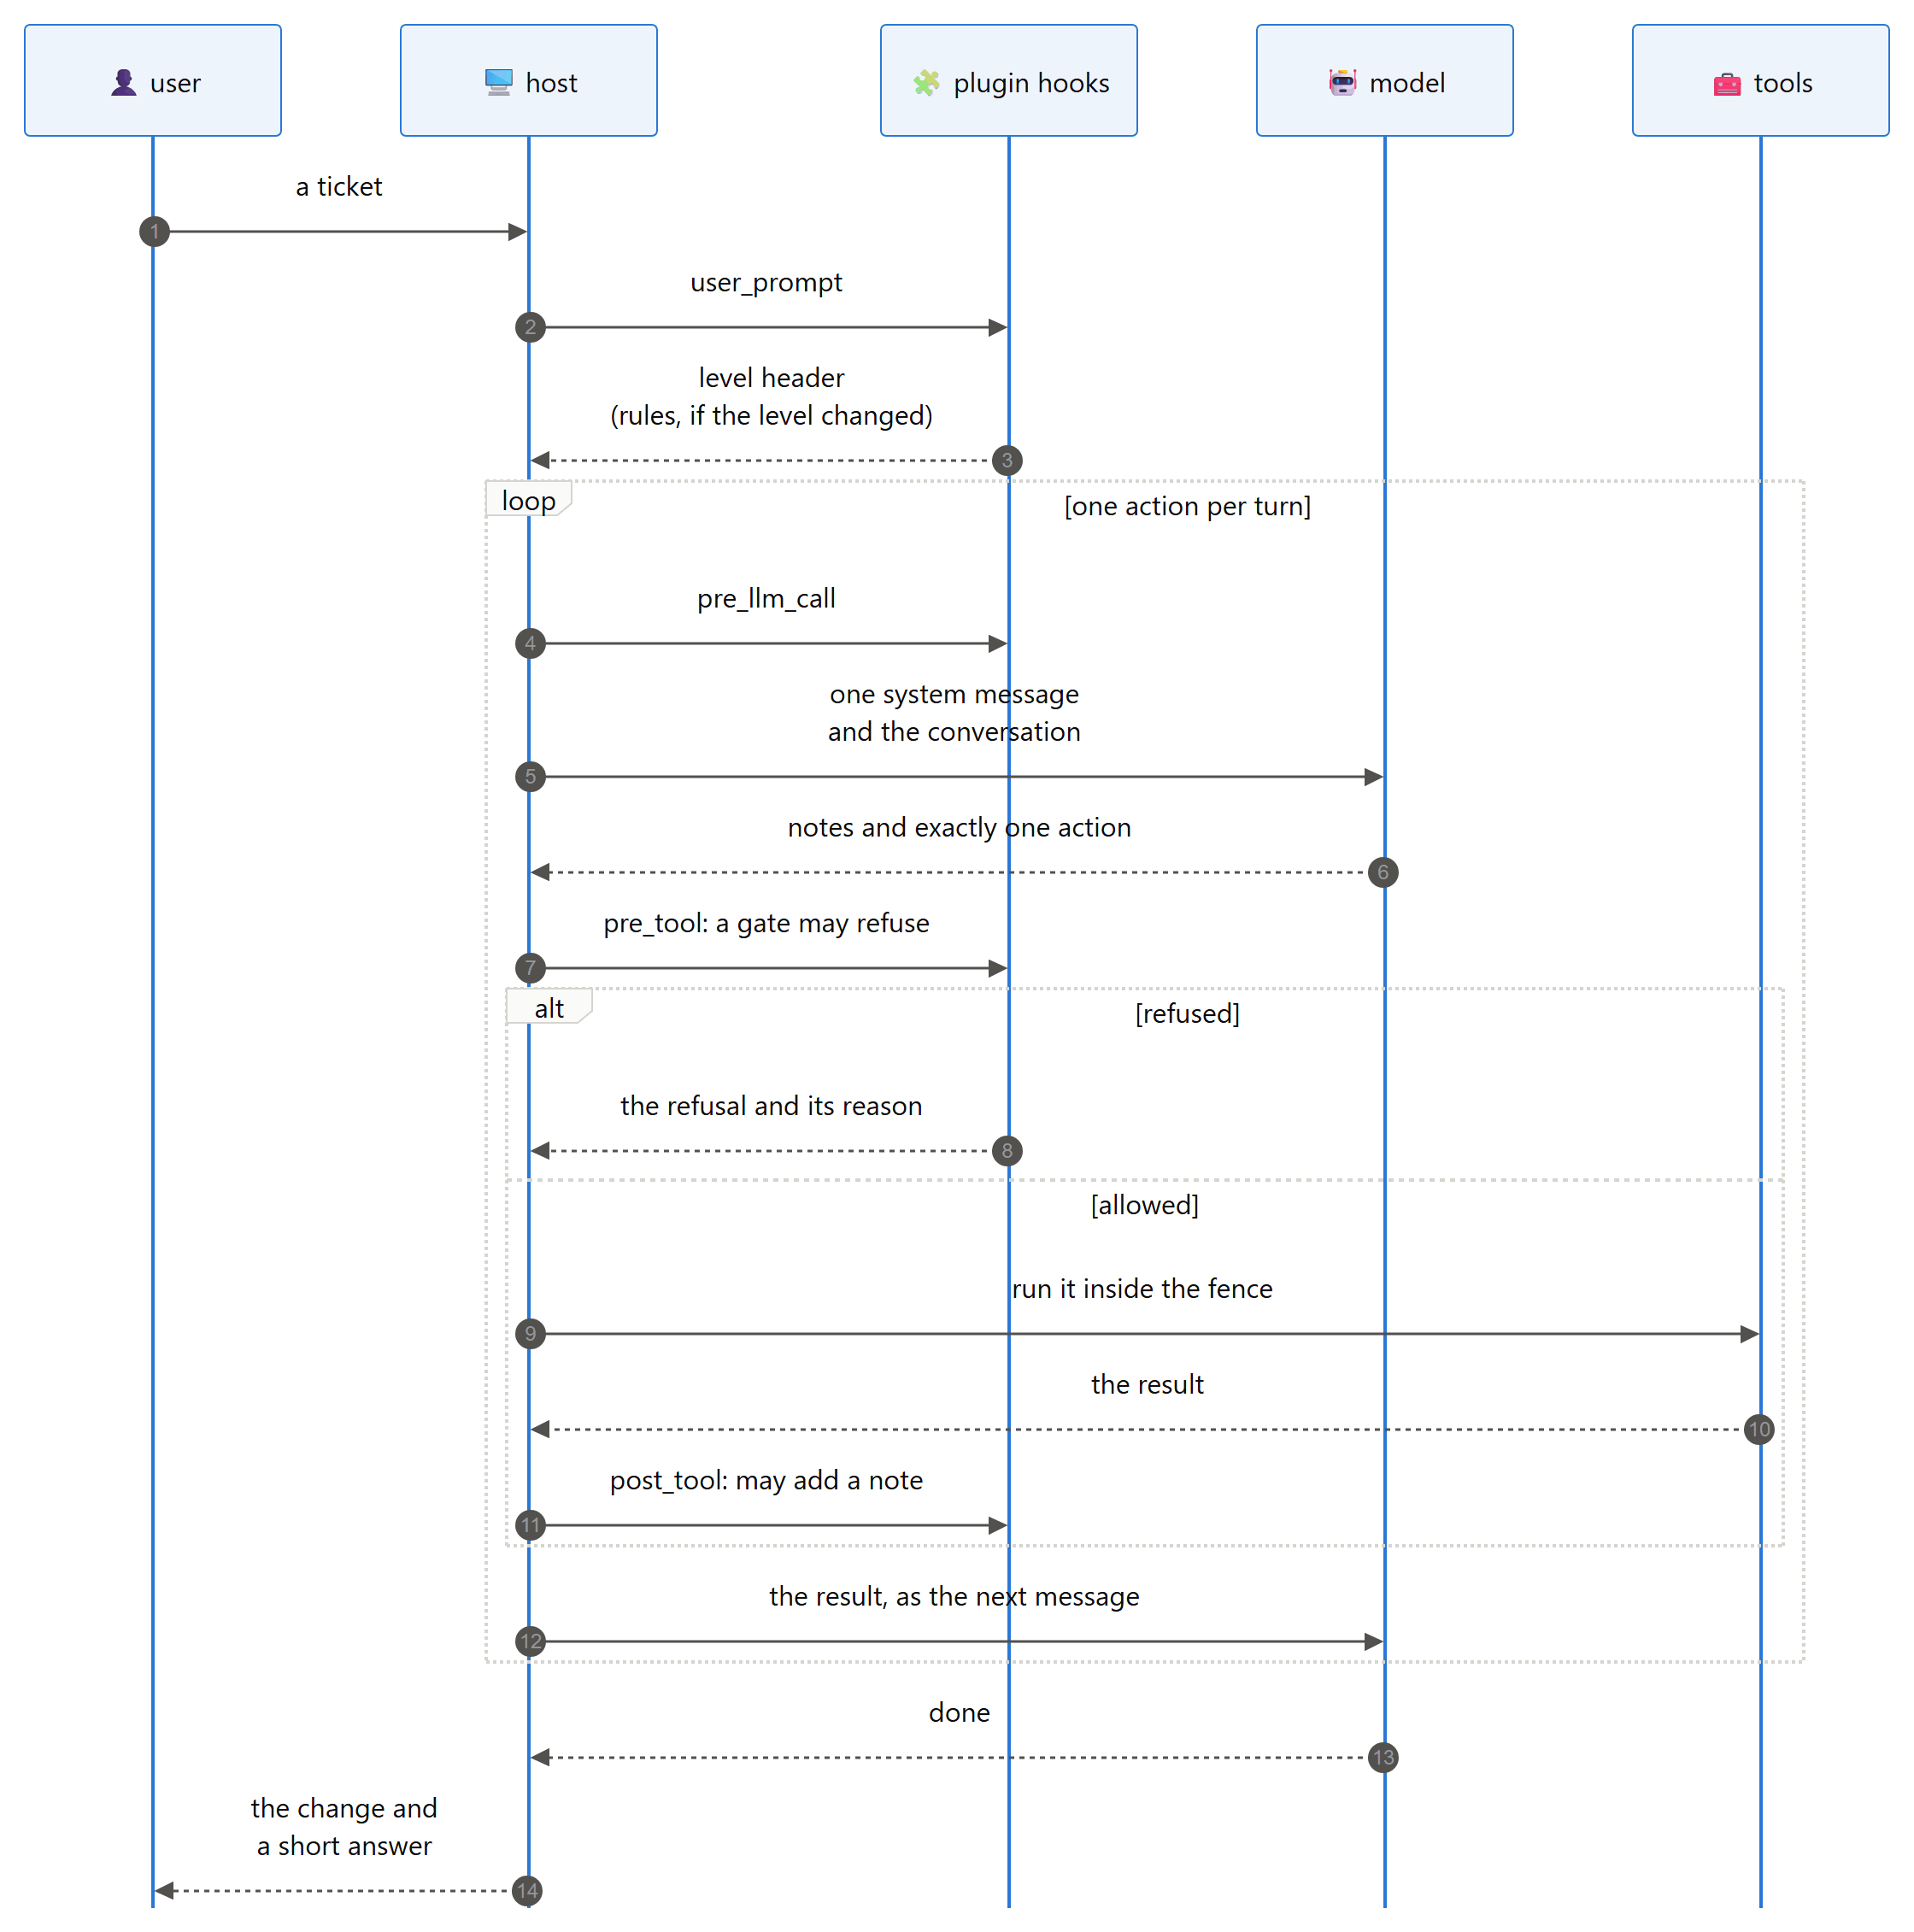

**`Turn`** is the record of one turn of the loop: the action and what it touched, whether it worked, what the model was told, how much prose and reasoning the model wrote, tokens, seconds, whether the answer came from the ledger, any hook refusal, and the fingerprint of the system message the model saw. Later Parts are built from these records, which is why the fingerprint is here: Part V uses it to show that rules really were in front of the model on a given turn.

In [395]:
@dataclass
class Turn:
    n: int                  # 1 for the first turn
    action: str             # the action's name, or "none" for an unreadable reply
    target: str             # its path, arguments or pattern, cut to 60 characters
    ok: bool                # whether the action did what it asked
    observation: str        # what the model was told
    notes_chars: int        # prose the model wrote before the action
    reasoning_chars: int    # reasoning, which Part VII counts as a cost
    prompt_tokens: int      # the context the model was sent, as the server counted it
    completion_tokens: int  # what the model wrote back
    seconds: float          # the model's time on this turn
    cached: bool            # answered from the ledger
    denied: str = ""        # the first line of each hook refusal, if any
    system: str = ""        # fingerprint of the system message this turn saw

show_def(Turn, layer="host")

[class] Turn(n: int, action: str, target: str, ok: bool, observation: str, note...)  14 lines, complexity 1


**`LoopResult`** is what a run of the loop returns: every turn, why it stopped (`done`, `max_turns`, `deadline`, `protocol`, or the API's error), the model's final answer when it finished, the protocol errors, and the model's own seconds. The episode record in S22 is built from it.

In [396]:
@dataclass
class LoopResult:
    turns: list           # every Turn, in order
    stop: str             # done, max_turns, deadline, protocol, or "error: ..."
    done_text: str        # the final answer, when the model finished
    protocol_errors: int  # replies that held no readable action
    model_seconds: float  # the model's own time, which the time budget counts

show_def(LoopResult, layer="host")

[class] LoopResult(turns: list, stop: str, done_text: str, protocol_errors: int, mode...)  6 lines, complexity 1


Three settings the host needs. **`SUBAGENT_PROMPT`** is the coder's prompt cut off before the `edit` action, with the task changed to answering a question and a `done` line of its own, so a helper is told about exactly the tools it has. **`CODER_PARAMS`** are the sampling settings for every agent call, and **`PROJECT_RULE_FILES`** names the file a project can use to give the agent its own instructions.

In [397]:
# the coder's prompt up to the edit action, a helper's task instead of a ticket, and its own done line
SUBAGENT_PROMPT = BASE_PROMPT.split("<edit path")[0].replace(
    "change it to complete the ticket you are given", "answer a question about it") + \
    '<done>your answer</done>           finish with the answer\n\nYou can only look; nothing you do changes the project.'
CODER_PARAMS = {"temperature": TEMPERATURE, "top_p": TOP_P, "max_tokens": 8000}  # for every agent call
PROJECT_RULE_FILES = ("AGENTS.md",)  # a project's own instructions, read at session start if present
# three looking tools and done: no edit and no run
print("[subagent] the helper's whole system prompt:\n" + textwrap.indent(SUBAGENT_PROMPT, "    "))

[subagent] the helper's whole system prompt:
    You are a coding agent. You work inside a project folder and answer a question about it.

    You act through tools. End every reply with exactly one action in this format; anything you write before the action is your own notes.

    <ls path="."/>                      list a folder
    <read path="FILE"/>                 read a file (add start="N" end="M" for part of a long one)
    <grep pattern="REGEX" path="."/>    search the files under a folder
    <done>your answer</done>           finish with the answer

    You can only look; nothing you do changes the project.


**`Host`** is the agent runtime, and its constructor lists everything it is made of: a front door to a model, an event bus, a skill registry, a command table, a configuration, a turn limit, a label naming the experiment arm, and a `state` dict where plugins keep their own data. Three commands come built in (`/help`, `/clear` and `/compact`), and plugins are installed last, so a plugin's `install` sees a complete host and can add hooks, commands, skills and statusline parts to it. The statusline parts start from `Host.default_status`, which S21 sets; a host made before then has an empty statusline. `help` stays in the class body, because a module-level function of that name would hide Python's own `help()` for the rest of the notebook; the other methods follow one per cell.

In [398]:
class Host:
    """The agent runtime: a loop with tools, hooks, skills, commands, subagents and a
    statusline. It knows nothing about over-engineering; plugins teach it that."""

    def __init__(self, llm=None, model=None, plugins=(), max_turns=MAX_TURNS, label="off", config_path=None):
        self.llm = llm or FRONT_DOOR                     # the ledger-backed front door, unless a test passes its own
        self.model = model or MODEL_FOR["coder"]         # the coder, unless a section asks for another model
        self.bus = EventBus()                            # where plugins listen
        self.skills = SkillRegistry()                    # empty until a plugin or the user loads skills
        self.commands = Commands()                       # the built-in commands are registered below
        # settings from the environment, a file, or the defaults (S19)
        self.config = Config(config_path or RUNTIME / "config" / "lean.json")
        self.max_turns = max_turns                       # the same limit for every arm
        self.label = label                               # the experiment arm, e.g. "off"; it names episode folders
        self.state = {}                                  # plugins keep their own data here, each under its own key
        self.status_parts = list(getattr(type(self), "default_status", ()))  # S21 sets the default parts
        self.ctx, self.ws, self.replica = None, None, 0  # no session yet; the replica is part of every fingerprint
        # each command receives the host and its arguments, and returns the answer the user sees
        self.commands.register("help", lambda host, args: host.help(), "list commands and skills")
        # start_session returns None, so the "or" supplies the answer
        self.commands.register("clear", lambda host, args: host.start_session(host.ws, "clear") or "context cleared",
                               "start the session again in the same workspace")
        self.commands.register("compact", lambda host, args: host.compact() or "context compacted",  # the same trick
                               "summarise the conversation now")
        self.plugins = list(plugins)                     # kept, so a test can see what was installed
        for p in self.plugins:                           # in the order given
            p.install(self)                              # last, so a plugin sees a complete host

    def help(self):
        lines = [f"/{n}: {h}" for n, (_, h) in sorted(self.commands.table.items())]  # commands, by name
        lines += [f"/{s.name}: {s.description}" for s in self.skills.skills.values()]  # then skills, as loaded
        return "\n".join(lines)                          # one /name: help line each

show_def(Host, layer="host")

[class] Host(llm=None, model=None, plugins=(), max_turns=20, label='off', confi...)  27 lines, complexity 9


In [399]:
host_demo = Host(label="demo")  # no plugins; nothing in these demonstrations calls a model
# the coder model and the turn limit from the parameters
print(f"[host] model {host_demo.model.split('/')[-1]}, at most {host_demo.max_turns} turns, label {host_demo.label!r}")
# the three built-in commands, and no skills yet
print("[host] /help lists:\n" + textwrap.indent(host_demo.help(), "    "))

[host] model Qwen3.8-27B, at most 20 turns, label 'demo'
[host] /help lists:
    /clear: start the session again in the same workspace
    /compact: summarise the conversation now
    /help: list commands and skills


**`Host._apply(ctx, results)`** is the one place where hook answers change a context. A hook asks for a section to be set by returning `{"section": name, "text": ..., "rank": ...}`, or for one to be dropped with `{"drop": name}`, and this method does it; anything else a hook returns is ignored here and read by the step that asked for it (a prefix, a refusal, a note). Because hooks ask and the host applies, every change a plugin makes to the system message happens here.

In [400]:
@method_of(Host)
def _apply(self, ctx, results):
    """Apply what hooks returned: set a system section, or drop one."""
    for name, r in results:                         # (hook name, what it returned), in priority order
        if isinstance(r, dict) and "section" in r:  # the hook asks for a section
            ctx.set_section(r["section"], r["text"], r.get("rank", 50))  # rank 50 unless the hook says otherwise
        if isinstance(r, dict) and "drop" in r:     # not elif: one answer may set one section and drop another
            ctx.drop_section(r["drop"])             # the hook asks for one to go

show_def(Host._apply, layer="host")

[def] Host._apply(self, ctx, results)  8 lines, complexity 6


In [401]:
apply_ctx = Context(base="HOST RULES")  # a bare context to apply answers to
host_demo._apply(apply_ctx, [("rules_hook", {"section": "rules", "text": "RULES", "rank": 20}),
                             ("map_hook", {"section": "map", "text": "MAP", "rank": 30}),
                             ("prefix_hook", {"prefix": "[mode: demo]"}),  # not a section: handle_prompt reads it
                             ("off_hook", {"drop": "rules"})])
# host and map: rules was set, then dropped
print(f"[apply] sections after the four answers: {list(apply_ctx.sections)}")

[apply] sections after the four answers: ['host', 'map']


**`Host.start_session(ws, source="startup")`** begins a session in a workspace with a fresh context. A project rules file becomes the `project` section at rank 10, the skills index becomes the `skills` section at rank 90, and then `session_start` fires with its source, so plugins can add sections of their own, ranked wherever they belong. The same method serves `/clear`, with source `clear`.

In [402]:
@method_of(Host)
def start_session(self, ws, source="startup"):
    self.ws = Path(ws)               # the workspace for this session
    self.ctx = Context()             # a fresh context: the host's prompt and nothing else
    for f in PROJECT_RULE_FILES:     # AGENTS.md
        if (self.ws / f).is_file():  # the project's own instructions, if it has any
            # rank 10: right after the host's own prompt
            self.ctx.set_section("project", (self.ws / f).read_text(encoding="utf-8-sig"), rank=10)
    if self.skills.skills:           # only when there are skills to list
        self.ctx.set_section("skills", self.skills.index(), rank=90)  # the index only; bodies load on use
    # plugins add their sections now, by returning them
    self._apply(self.ctx, self.bus.emit("session_start", host=self, ctx=self.ctx, source=source))

show_def(Host.start_session, layer="host")

[def] Host.start_session(self, ws, source='startup')  10 lines, complexity 4


In [403]:
session_ws = RUNTIME / "demo" / "s20_session"  # a scratch workspace with a project rules file
shutil.rmtree(session_ws, ignore_errors=True)  # start clean
session_ws.mkdir(parents=True)                 # an empty project
# with a rules file of its own
(session_ws / "AGENTS.md").write_text("Keep every change small.", encoding="utf-8")
# a one-line plugin: on every session_start it adds a section that says why it fired
host_demo.bus.on("session_start", lambda source, **_: {"section": "demo", "text": f"plugin rules ({source})", "rank": 30},
                 name="demo_session")
host_demo.start_session(session_ws)            # project rules, then the plugin's section
# host, project and demo; the plugin saw source "startup"
print(f"[session] sections: {list(host_demo.ctx.sections)}; the plugin's says {host_demo.ctx.sections['demo'][1]!r}")

[session] sections: ['host', 'project', 'demo']; the plugin's says 'plugin rules (startup)'


**`Host.compact()`** compacts the session's context and then fires `session_start` again with source `compact`, which is the plugins' chance to put back what compaction removed. The host restores nothing itself, not even the project's rules file: only what a hook puts back survives. That is the gap Part V's compaction hook exists to close.

In [404]:
@method_of(Host)
def compact(self):
    self.ctx.compact()  # summarise, and drop every section but the host's
    # the plugins' chance to put back what compaction removed
    self._apply(self.ctx, self.bus.emit("session_start", host=self, ctx=self.ctx, source="compact"))

show_def(Host.compact, layer="host")

[def] Host.compact(self)  4 lines, complexity 1


In [405]:
host_demo.compact()  # the project section goes; the plugin puts its own back
# host and demo only, and the plugin's section now says "compact"
print(f"[compact] sections after compaction: {list(host_demo.ctx.sections)}; "
      f"the plugin's section now says {host_demo.ctx.sections['demo'][1]!r}")

[compact] sections after compaction: ['host', 'demo']; the plugin's section now says 'plugin rules (compact)'


**`Host.handle_prompt(prompt)`** takes one message from the user. A command is answered by the host directly and never reaches the model. Otherwise a skill invocation is expanded: a persistent skill becomes a `skill:name` section that stays for the session, while a one-shot skill is written into the prompt above the user's own words. Then the `user_prompt` hooks run, their section requests are applied, and any `prefix` lines they returned go above the prompt before it joins the conversation. It returns a command's answer, or `None`.

In [406]:
@method_of(Host)
def handle_prompt(self, prompt):
    """Commands answer directly (no model, no tokens). Otherwise skills and hooks shape
    the prompt, and it joins the conversation. Returns a command's answer, or None."""
    cmd = self.commands.parse(prompt)                     # (name, args), or None
    if cmd:                                               # a command never reaches the model
        fn, _ = self.commands.table[cmd[0]]               # the help text is not needed here
        return fn(self, cmd[1])                           # the command's answer goes straight back to the user
    hit = self.skills.invocation(prompt)                  # (skill, rest of the prompt), or None
    if hit:                                               # the prompt invokes a skill
        skill, prompt = hit                               # from here on the prompt is what followed the skill's name
        if skill.mode == "persistent":                    # on until switched off
            self.ctx.set_section(f"skill:{skill.name}", skill.body, rank=60)  # stays for the whole session
        else:
            prompt = f"[{skill.name}]\n{skill.body}\n\n{prompt}".strip()  # for this request only
    # plugins see the prompt after any skill has been expanded
    answers = self.bus.emit("user_prompt", host=self, ctx=self.ctx, prompt=prompt)
    self._apply(self.ctx, answers)                        # sections first
    prefixes = []                                         # header lines, in hook order
    for _, r in answers:                                  # every answer a hook gave
        if isinstance(r, dict) and r.get("prefix"):       # a header line to put above the prompt
            prefixes.append(r["prefix"])                  # then any header lines, in hook order, above the prompt
    self.ctx.add("user", "\n".join(prefixes + [prompt]))  # the headers, then the prompt, as one user message
    return None

show_def(Host.handle_prompt, layer="host")

[def] Host.handle_prompt(self, prompt)  23 lines, complexity 7


In [407]:
host_demo.skills.load(demo_skills, namespace="demo")          # the two skills written in S18
help_head = host_demo.handle_prompt("/help").splitlines()[0]  # a command returns its answer
# no model, no tokens: the answer comes from the command table
print(f"[prompt] '/help' is answered by the host itself; its first line: {help_head!r}")
host_demo.handle_prompt("$strict on")                         # a persistent skill: it becomes a section
host_demo.handle_prompt("/explain the cache")                 # a one-shot skill: it is written into the prompt
print(f"[prompt] sections now: {list(host_demo.ctx.sections)}")  # skill:strict is now a section of its own
# the one-shot skill's body sits above what the user typed
print("[prompt] the last user message:\n" + textwrap.indent(host_demo.ctx.messages[-1]["content"], "    "))

[prompt] '/help' is answered by the host itself; its first line: '/clear: start the session again in the same workspace'
[prompt] sections now: ['host', 'demo', 'skill:strict']
[prompt] the last user message:
    [explain]
    Explain the design in plain words; do not change any file.

    the cache


**`Host.loop(ctx, ws, model, tools=None, max_turns=None, tag="", params=None)`** is the agent itself, the same loop for the main agent and for subagents, kept whole in one cell because its steps share state from turn to turn. Each turn checks the budgets (the model's own seconds, which a replay reproduces exactly, and the context size, which triggers compaction of the main session only), asks the model, and parses the reply. A readable action then meets the `pre_tool` hooks, any of which may refuse it, then its tool, then the `post_tool` hooks, which may add notes; a `done` that no hook refused ends the episode. Unreadable replies, refusals, unknown actions, unexpected attributes and tool errors all come back to the model as observations, so a confused model gets the chance to recover instead of ending the run, and three unreadable replies in a row end the episode with `protocol`. Every turn is recorded as a `Turn`, and the observation goes back to the model as a `<result action="...">` message.

In [408]:
@method_of(Host)
def loop(self, ctx, ws, model, tools=None, max_turns=None, tag="", params=None):
    tools = {k: TOOLS[k] for k in (tools or TOOLS)}            # the tools this run may use, by name
    params = {**CODER_PARAMS, **(params or {})}                # the caller's settings override the defaults
    turns, streak, model_s = [], 0, 0.0                        # the record, unreadable replies in a row, model seconds
    for n in range(1, (max_turns or self.max_turns) + 1):
        # the budget counts the model's own seconds, which a replay reproduces exactly
        if model_s > EPISODE_DEADLINE_S:
            # stop before the next call, counting the unreadable replies so far
            return LoopResult(turns, "deadline", "", sum(not t.ok and t.action == "none" for t in turns), model_s)
        if ctx.tokens() > CONTEXT_BUDGET and ctx is self.ctx:  # only the main session is ever compacted
            self.compact()                                     # then session_start fires with source compact
        self.bus.emit("pre_llm_call", host=self, ctx=ctx)      # plugins may look, but nothing they return is applied
        # through the front door: the ledger answers whatever it has already seen
        reply = self.llm.chat(model, ctx.render(), tag=tag, replica=self.replica, **params)
        model_s += reply.seconds                               # the model's time, which the ledger replays exactly
        if reply.finish == "error":                            # the API failed: stop, and say why
            return LoopResult(turns, f"error: {reply.error}", "", 0, model_s)  # the error text is the stop reason
        ctx.add("assistant", reply.text)                       # the reply joins the conversation, readable or not
        denied = ""                                            # no refusal yet on this turn
        try:                                                   # an unreadable reply is a protocol error, not a crash
            act = parse_action(reply.text)                     # the first action in the reply
            streak = 0                                         # a readable reply resets the count
        except ProtocolError as e:                             # no readable action
            streak += 1                                        # unreadable replies in a row
            # a reply cut off by the token limit gets a hint about why
            cut = " Your reply was cut off; keep notes short." if reply.finish == "length" else ""
            act, ok = Action("none", {}), False                # recorded as an action called "none"
            # what was wrong, a hint if the reply was cut off, and an example of the right form
            obs = f"{e}.{cut} End your reply with exactly one action, for example <read path=\"FILE\"/>."
        else:
            # pre_tool hooks may refuse the action
            refusals = [r["deny"] for _, r in self.bus.emit("pre_tool", host=self, action=act, ws=ws)
                        if isinstance(r, dict) and r.get("deny")]
            if act.name == "done" and not refusals:            # a hook may hold the finish back; none did
                # the finishing turn is recorded too
                turns.append(Turn(n, "done", "", True, "", len(act.notes), len(reply.reasoning), reply.prompt_tokens,
                                  reply.completion_tokens, reply.seconds, reply.cached, system=ctx.fingerprint()))
                # the answer to whoever wrote the ticket
                return LoopResult(turns, "done", act.args["text"], sum(t.action == "none" for t in turns), model_s)
            if refusals:                                       # every refusal reaches the model, not just the first
                # the first line of each refusal, for the record
                denied, ok = "; ".join(r.splitlines()[0] for r in refusals), False
                # the model reads every refusal in full
                obs = "refused: " + "\n\nalso refused: ".join(refusals)
            elif act.name not in tools:                        # an action this run does not offer
                # a helper asking to edit gets the list of what it can do
                ok, obs = False, f"error: <{act.name}> is not available here; use one of {', '.join(tools)}"
            elif set(act.args) - set(inspect.signature(tools[act.name]).parameters):  # attributes the tool lacks
                # the attributes the tool does take; ws is the host's, not the model's
                takes = [p for p in inspect.signature(tools[act.name]).parameters if p != "ws"]
                # the names it got wrong, then the ones it may use
                ok, obs = False, (f"error: <{act.name}> does not take "
                                  f"{', '.join(sorted(set(act.args) - set(takes)))}; it takes {', '.join(takes)}")
            else:
                try:                                           # the tool itself may refuse
                    obs, ok = tools[act.name](ws, **act.args), True  # the tool's own output is the observation
                except ToolError as e:                         # a refusal or failure the tool explains itself
                    obs, ok = f"error: {e}", False             # the tool's sentence, as written for the model
                except TypeError as e:                         # most often an attribute the tool needs is missing
                    # Python's own message says which attribute
                    obs, ok = f"error: <{act.name}> got attributes it does not take ({e})", False
                except ValueError as e:                        # a value of the wrong kind, such as start="ten"
                    obs, ok = f"error: <{act.name}> got a value it cannot use ({e})", False
            # post_tool hooks may add notes below the result
            notes = [r["note"] for _, r in self.bus.emit("post_tool", host=self, action=act, ok=ok, observation=obs, ws=ws)
                     if isinstance(r, dict) and r.get("note")]
            obs = "\n".join([obs] + notes)                     # the notes go under the result
            if act.extra:                                      # the model is told that only one action ran
                obs += f"\n(only the first action ran; {act.extra} more were ignored. One action per reply.)"
        # what the action touched: a path, the run arguments or a search pattern
        target = str(act.args.get("path") or act.args.get("args") or act.args.get("pattern") or "")
        turns.append(Turn(n, act.name, target[:60], ok, obs, len(act.notes), len(reply.reasoning),
                          reply.prompt_tokens, reply.completion_tokens, reply.seconds, reply.cached, denied,
                          ctx.fingerprint()))                  # the system message this turn saw
        if streak >= 3:                                        # three unreadable replies in a row end the episode
            return LoopResult(turns, "protocol", "", streak, model_s)  # the streak is the count of errors reported
        ctx.add("user", f'<result action="{act.name}">\n{obs}\n</result>')  # what the model reads next turn
    # the turn limit was reached without a finish
    return LoopResult(turns, "max_turns", "", sum(t.action == "none" for t in turns), model_s)

show_def(Host.loop, layer="host")

[def] Host.loop(self, ctx, ws, model, tools=None, max_turns=None, tag='', params=N...)  63 lines, complexity 35


**`Host.subagent(role, question, ws, max_turns=6, model=None)`** hands a side question to a helper: a fresh context built on `SUBAGENT_PROMPT`, the read-only tools, the fast model and a few turns. `subagent_start` fires before the helper starts, and it is the only way a plugin can reach a helper, because nothing from the main session's context is carried over. A helper that uses up its turns while still exploring is told so and given one more turn to answer with what it has, since a helper that never answers has spent its turns for nothing. It returns the result and the helper's context, so the caller can see what the helper saw.

In [409]:
@method_of(Host)
def subagent(self, role, question, ws, max_turns=6, model=None):
    """A helper with its own small context and read-only tools. One that runs out of turns
    still exploring is asked once for its answer so far: a helper that never answers has
    spent its turns for nothing."""
    sub = Context(SUBAGENT_PROMPT)                # a fresh context: nothing from the main session comes along
    # the only way a plugin can reach a helper is this event
    self._apply(sub, self.bus.emit("subagent_start", host=self, ctx=sub, role=role))
    sub.add("user", question)                     # the question is the helper's whole ticket
    model = model or MODEL_FOR["fast"]            # the fast model, unless the caller names another
    # the same loop as the main agent, with read-only tools and a few turns
    result = self.loop(sub, ws, model, tools=READ_ONLY, max_turns=max_turns, tag=f"subagent:{role}")
    if result.stop == "max_turns":                # still exploring when the turns ran out: ask once for an answer
        # one plain request for whatever it has found
        sub.add("user", "You are out of turns. Reply now with your answer so far, in one <done>...</done> block.")
        # one more turn, under a tag of its own in the ledger
        last = self.loop(sub, ws, model, tools=READ_ONLY, max_turns=1, tag=f"subagent:{role}:last")
        if last.stop == "done":                   # it answered this time
            stop = "out of turns, then answered"  # a stop reason of its own, so reports can count it
        else:
            stop = result.stop                    # still no answer: the first reason stands
        result = LoopResult(result.turns + last.turns, stop, last.done_text,  # both runs as one result
                            result.protocol_errors + last.protocol_errors,
                            result.model_seconds + last.model_seconds)
    return result, sub                            # the context too, so the caller can see what the helper saw

show_def(Host.subagent, layer="host")

[def] Host.subagent(self, role, question, ws, max_turns=6, model=None)  21 lines, complexity 4


**`Host.status()`** joins the statusline parts with ` | `. Each part is a function of the host, registered by the host itself or by a plugin (S21 and Part V), so the statusline can grow without this method changing.

In [410]:
@method_of(Host)
def status(self):
    return " | ".join(part(self) for part in self.status_parts)  # each part is a function of the host

show_def(Host.status, layer="host")

[def] Host.status(self)  3 lines, complexity 2


In [411]:
host_demo.status_parts = [lambda h: h.label, lambda h: f"{len(h.ctx.messages)} messages"]  # two throwaway parts
print(f"[status] {host_demo.status()}")  # demo | and the number of messages so far

[status] demo | 3 messages


The scripted stand-ins for smoke runs: a coder and a read-only helper. They let the whole host run end to end with no model at all, and they are deliberately plain: each follows a fixed plan and repeats its last step once the plan runs out. **`_ticket(messages)`** finds which suite task a conversation is about, by looking for a task's ticket text inside the first user message.

In [412]:
def _ticket(messages):
    first = next((m["content"] for m in messages if m["role"] == "user"), "")  # the first user message
    return next((t for t in SUITE.values() if t.prompt in first), None)  # the task whose ticket it holds

show_def(_ticket, layer="lab")

[def] _ticket(messages)  3 lines, complexity 3


**`scripted_plan(task, policy)`** is the scripted coder's whole plan for one ticket: list the folder, read the entry file, lay one of the task's reference solutions over the seed one file at a time (an edit that replaces a seed file's whole text, or creates a file the seed lacks), run the visible test, and finish. The policy picks the reference, `good`, `bloated` or `lazy`, so a smoke run produces the full range of results the scorer and the tables downstream must handle.

In [413]:
def scripted_plan(task, policy):
    """The actions a scripted coder takes: look, read, lay the chosen reference over the seed
    one file at a time, run the visible test, finish."""
    # look at the folder, then read the file the ticket is about
    steps = ['<ls path="."/>', f'<read path="{task.entry}"/>']
    overlay = task.folder / "refs" / policy       # the reference solution for this policy
    files = sorted(overlay.rglob("*.py")) if overlay.is_dir() else []  # no such reference: no edits
    for p in files:                               # one edit per file of the reference
        path = p.relative_to(overlay).as_posix()  # the same relative path in the workspace
        if path in task.seed:                     # an existing file: replace its whole text
            # the seed's text out, the reference's text in
            steps.append(f'<edit path="{path}">\n<old>\n{task.seed.get(path, "")}\n</old>\n<new>\n'
                         f'{p.read_text(encoding="utf-8")}\n</new>\n</edit>')
        else:                                     # a new file: an empty <old> creates it
            # the reference's text as a new file
            steps.append(f'<edit path="{path}">\n<old></old>\n<new>\n{p.read_text(encoding="utf-8")}\n</new>\n</edit>')
    steps.append("<run>tests_visible.py</run>")   # check the work, as a real agent should
    # a short note, then the finish; the answer names the policy, so smoke tables are easy to read
    steps.append(f"Finished.\n<done>Applied the {policy} change to {task.entry}.</done>")
    return steps

show_def(scripted_plan, layer="host")

[def] scripted_plan(task, policy)  16 lines, complexity 4


In [414]:
for step in scripted_plan(SUITE["ob-postcode-cache"], "good"):  # the good reference's plan for one ticket
    print(f"[plan] {textwrap.shorten(step, 96)}")               # each step on one line, long edits shortened

[plan] <ls path="."/>
[plan] <read path="geo.py"/>
[plan] <edit path="geo.py"> <old> import register def normalise(postcode): """'sw1a 1aa' -> [...]
[plan] <run>tests_visible.py</run>
[plan] Finished. <done>Applied the good change to geo.py.</done>


**`_scripted_coder`** answers any request whose system message says it is a coding agent and whose ticket it recognises. It picks its policy from a hash of the system message and the task, so the same arm always gets the same policy for the same task, while arms whose system messages differ can get different ones; then it replies with the step of the plan that matches the number of replies it has already sent.

In [415]:
@SCRIPTED.register
def _scripted_coder(model, messages, params):
    task = _ticket(messages)                             # which suite task this conversation is about
    if task is None or "coding agent" not in messages[0]["content"]:  # not a coder working on a suite ticket
        return None
    # the same system message and task always give the same policy
    seed = int(hashlib.sha256((messages[0]["content"] + task.id).encode()).hexdigest(), 16)
    policy = ("good", "bloated", "lazy")[seed % 3]       # one of the task's three references
    steps = scripted_plan(task, policy)                  # the whole plan, rebuilt on every call
    n = sum(m["role"] == "assistant" for m in messages)  # replies sent so far
    return steps[min(n, len(steps) - 1)]                 # the next step, or the last one again

show_def(_scripted_coder, layer="lab")

[def] _scripted_coder(model, messages, params)  10 lines, complexity 4

**`_scripted_helper`** answers a subagent: a `grep` for function definitions, then a fixed answer. It recognises a helper's request by a phrase from `SUBAGENT_PROMPT`.

In [416]:
@SCRIPTED.register
def _scripted_helper(model, messages, params):
    if "answer a question about it" not in messages[0]["content"]:  # a phrase from SUBAGENT_PROMPT
        return None
    n = sum(m["role"] == "assistant" for m in messages)  # replies sent so far
    replies = ['<grep pattern="def " path="."/>',        # first, look around
               "<done>The functions are listed above; the entry point is the first one.</done>"]  # then answer
    return replies[min(n, 1)]                            # the grep, then the answer forever after

show_def(_scripted_helper, layer="lab")

[def] _scripted_helper(model, messages, params)  8 lines, complexity 3


In [417]:
# in registration order; the newest is asked first
print(f"[scripted] responders registered: {[f.__name__ for f in SCRIPTED.responders]}")

[scripted] responders registered: ['_echo', '_probe', '_scripted_coder', '_scripted_helper']


A subagent end to end: an explorer asked where a function is defined, on a fresh copy of one seed.

In [418]:
host = Host()           # a plain host with no plugin
ws = materialise(SUITE["ob-postcode-cache"], WS_DIR / "subagent-demo")  # a fresh copy of one seed
# a side question; the main session is not even started
result, sub = host.subagent("explorer", "Which function in this project looks up a district, and where is it defined?", ws)
# the fast model, a few turns, and how it stopped
print(f"[subagent] model {MODEL_FOR['fast'].split('/')[-1]}, read-only tools, {len(result.turns)} turns, stop: {result.stop}")
for t in result.turns:  # one line per turn
    # what the helper did, and how much it wrote each time
    print(f"  turn {t.n}  {t.action:<5} {t.target:<28} {'ok' if t.ok else 'ERR'}  {t.completion_tokens:>5} tokens out")
print(f"  answer: {textwrap.shorten(plain(result.done_text), 200)}")  # the helper's answer, in plain ASCII
# only the host section: no plugin added anything at subagent_start
print(f"  the subagent's context: {len(sub.messages)} messages, sections {list(sub.sections)} "
      f"(nothing from the main session leaks in unless a subagent_start hook adds it)")

[subagent] model Qwen3.8-Flash-Next, read-only tools, 4 turns, stop: done
  turn 1  grep  .                            ok     70 tokens out
  turn 2  read  geo.py                       ok     23 tokens out
  turn 3  read  register.py                  ok     64 tokens out
  turn 4  done                               ok    263 tokens out
  answer: The district lookup function is `lookup_district(postcode)`, defined in `geo.py` at line 9. - Signature: `def lookup_district(postcode)` - docstring: "Return the district for a postcode, or None [...]
  the subagent's context: 8 messages, sections ['host'] (nothing from the main session leaks in unless a subagent_start hook adds it)


## S21 - The statusline

**Theory.** A user who cannot see what mode an agent is in cannot trust it, and the cheapest place to show it is a single line under the prompt. The host builds its statusline from parts that the host and plugins register: the model, the turn and its limit, the tokens spent, the last action, and the health of the hooks. A plugin adds its own part (in Part V, the level badge). Colour is used as a second signal, never the only one: the text says `full` as well as being green, so the line still works for a reader who cannot tell the colours apart, in a log file, or in a screen reader.

**In plain terms.** One line that says what the agent is doing and in which mode, readable with or without colour.

**`status_model(host)`** is the statusline's model part. It shows the model id without its organisation prefix, which is the same for every model here and would only take up room on a short line.

In [419]:
def status_model(host):
    return host.model.split("/")[-1]  # the id without its organisation prefix

show_def(status_model, layer="host")

[def] status_model(host)  2 lines, complexity 1


In [420]:
print(f"[status] model part for the demo host: {status_model(host_demo)!r}")  # the coder's id, without its prefix

[status] model part for the demo host: 'Qwen3.8-27B'


**`status_progress(host)`** shows the turn against its limit, the tokens spent so far in thousands, and the last action with its target. It reads the turns of the host's latest episode, so between episodes it describes the one that just finished; a host that has not run one says `idle`.

In [421]:
def status_progress(host):
    turns = getattr(host, "last_turns", [])  # the host's latest episode, if it has run one
    tokens = sum(t.prompt_tokens + t.completion_tokens for t in turns)  # everything sent and received in the episode
    if turns:                                # an episode has run
        last = f"{turns[-1].action} {turns[-1].target}".strip()  # the latest action and what it touched
    else:
        last = "idle"                        # nothing has run yet
    # the turn against its limit, tokens in thousands, and the last action cut to fit
    return f"turn {len(turns)}/{host.max_turns} | {tokens / 1000:.1f}k tokens | {last[:28]}"

show_def(status_progress, layer="host")

[def] status_progress(host)  8 lines, complexity 3


In [422]:
# turn 0, no tokens, idle
print(f"[status] progress part before any episode: {status_progress(host_demo)!r}")

[status] progress part before any episode: 'turn 0/20 | 0.0k tokens | idle'


**`status_health(host)`** reports hook failures: `hooks ok`, or how many hook calls failed or hung. A slow hook is not counted, because its answer still reached the host. This is the part that keeps fail-open from becoming fail-silent.

In [423]:
def status_health(host):
    bad = sum(v for (n, o), v in host.bus.health.items() if o in ("error", "hung"))  # slow hooks still answered
    if not bad:                    # every hook answered, even if some were slow
        return "hooks ok"
    return f"hooks: {bad} failed"  # failed or hung calls, counted together

show_def(status_health, layer="host")

[def] status_health(host)  5 lines, complexity 3


In [424]:
health_demo = Host(label="health-demo")  # a fresh host with nothing hooked yet
print(f"[status] health part of a fresh host: {status_health(health_demo)!r}")  # nothing has run, so nothing has failed
health_demo.bus.on("pre_tool", lambda **_: 1 / 0, name="broken_hook")  # a hook that always raises
health_demo.bus.emit("pre_tool")         # the hook raises; the bus counts it and carries on
# one failure, now visible on the statusline
print(f"[status] after one broken hook call: {status_health(health_demo)!r}")

[status] health part of a fresh host: 'hooks ok'
[status] after one broken hook call: 'hooks: 1 failed'


**`badge_html(text, colour)`** renders a badge as a small coloured HTML label, for any display that can show HTML, such as a notebook's output. The text is escaped, so a badge can never break the page it sits in, and it always carries the meaning by itself; the colour only repeats it.

In [425]:
import html  # html.escape keeps the badge's text from breaking the markup

def badge_html(text, colour):
    # inline styles only, so the badge looks the same wherever HTML is shown
    return (f'<span style="font-family:monospace;padding:2px 8px;border-radius:4px;background:{colour};'
            f'color:white">{html.escape(text)}</span>')

show_def(badge_html, layer="host")

[def] badge_html(text, colour)  3 lines, complexity 1


In [426]:
print(f"[badge] {badge_html('lean: full', C3)}")  # the markup itself; a notebook would render it as a green label

[badge] <span style="font-family:monospace;padding:2px 8px;border-radius:4px;background:#1baf7a;color:white">lean: full</span>


The default statusline is the three parts above, in that order. Every host made from here on starts with them, and a plugin inserts its own part where it wants it (Part V puts its level badge first). The host from the subagent demonstration was made before the defaults existed, so it gets them by hand.

In [427]:
Host.default_status = (status_model, status_progress, status_health)  # every Host made from now on starts with these
host.status_parts = list(Host.default_status)  # the S20 host was made before they existed
print(f"[status] {host.status()}")             # model | progress | hook health

[status] Qwen3.8-27B | turn 0/20 | 0.0k tokens | idle | hooks ok


## S22 - The agent loop, end to end

**Theory.** An **episode** is one ticket, start to finish: a fresh copy of the seed, a new session, the ticket as the first prompt, the loop until it stops, and a record of every turn. The record keeps what later Parts need: the action and its target, whether it worked, how much the model wrote as notes (prose) and as reasoning, tokens, seconds, whether the answer came from the ledger, any refusal by a hook, and the fingerprint of the system message the model saw on that turn (which Part V uses to prove that rules really were present). One more check runs at the end, because models sometimes claim work they did not do: if the final message says something was changed and the workspace is identical to the seed, the episode is flagged as a **phantom completion**. The loop is first run with the scripted stand-in, which costs nothing and lets the notebook run end to end in smoke mode, then attacked with a stand-in that misbehaves on purpose.

**In plain terms.** An episode is one ticket worked from start to finish, with every step written down.

**`Episode`** is the record of one ticket worked from start to finish: the task, the arm, the model and the replica, every turn, why it stopped, the final answer, the protocol errors, the model's seconds, the workspace it left behind, and whether it was a phantom completion. Part VII's tables are built from these records and the workspaces they point to.

In [428]:
@dataclass
class Episode:
    task: str              # the task id
    arm: str               # the experiment arm; it names the folder the workspace is kept in
    model: str             # the model that played the coder
    replica: int           # which sample of the same ticket and arm
    turns: list            # every Turn
    stop: str              # why the loop stopped
    done_text: str         # the agent's final message to whoever wrote the ticket
    protocol_errors: int   # replies that held no readable action
    model_seconds: float   # the model's own time, which the budget counts
    ws: str                # the workspace the agent left behind, kept for scoring
    phantom: bool = False  # claimed a change, changed nothing

show_def(Episode, layer="host")

[class] Episode(task: str, arm: str, model: str, replica: int, turns: list, stop: ...)  12 lines, complexity 1


**`CLAIMS_WORK`** recognises a claim of work in a final answer: a verb such as *added*, *fixed* or *updated*. Together with an untouched workspace it marks a phantom completion. **`EPISODES_DIR`** is where every episode's workspace is kept, one folder per arm, so a number in a table can always be traced back to the files that produced it.

In [429]:
# the verbs of a finished change, as whole words in any case
CLAIMS_WORK = re.compile(r"\b(added|changed|created|edited|fixed|implemented|updated|replaced|refactored|wrote)\b", re.I)
EPISODES_DIR = RUNTIME / "episodes"  # one folder per arm, one workspace per task and replica
# a claim of work, and an answer that only mentions change
for answer_text in ("I updated geo.py with a cache.", "Nothing needed changing; the cache already exists."):
    print(f"[claims] {answer_text!r} claims work: {bool(CLAIMS_WORK.search(answer_text))}")  # True, then False

[claims] 'I updated geo.py with a cache.' claims work: True
[claims] 'Nothing needed changing; the cache already exists.' claims work: False


**`run_episode(task, host=None, replica=0, arm=None, prompt=None)`** works one ticket: a fresh copy of the seed under `EPISODES_DIR`, a new session, the ticket as the first prompt, and the loop until it stops. Afterwards the workspace is compared with the seed: if no Python file changed and the final answer claims work, the episode is flagged as a phantom completion. `prompt` lets a section ask something else of the same project, and `arm` defaults to the host's label, which names the episode's folder and tags its calls in the ledger.

In [430]:
def run_episode(task, host=None, replica=0, arm=None, prompt=None):
    """One ticket, start to finish, on a fresh copy of the seed. `prompt` replaces the
    task's own ticket when a section needs to ask something else of the same project."""
    host = host or Host()                      # a plain host with no plugin, unless the caller brings one
    arm = arm or host.label                    # the arm names the episode's folder
    ws = materialise(task, EPISODES_DIR / arm / f"{task.id}-r{replica}")  # a fresh copy of the seed
    host.replica = replica                     # part of every request's fingerprint
    host.start_session(ws, "startup")          # a new session in the fresh copy
    host.handle_prompt(prompt or task.prompt)  # the ticket, unless a section asks something else
    # the loop until done, the turn limit, the time budget or three protocol errors
    res = host.loop(host.ctx, ws, host.model, tag=f"{arm}:{task.id}")
    host.last_turns = res.turns                # for the statusline
    final_py = {p: s for p, s in snapshot(ws).items() if p.endswith(".py")}  # the Python files as the agent left them
    unchanged = final_py == task.seed_py       # no Python file differs from the seed
    phantom = unchanged and bool(CLAIMS_WORK.search(res.done_text))  # says it changed something; changed nothing
    # the record Part VII is built from
    return Episode(task.id, arm, host.model, replica, res.turns, res.stop, res.done_text, res.protocol_errors,
                   res.model_seconds, str(ws), phantom=phantom)

show_def(run_episode, layer="host")

[def] run_episode(task, host=None, replica=0, arm=None, prompt=None)  16 lines, complexity 6


**`show_episode(ep, notes=False)`** prints an episode as one line per turn: the action and its target, whether it worked, the notes and reasoning the model wrote, tokens, seconds, and whether the answer came from the ledger or a hook refused the action. The `notes` parameter is accepted but not used.

In [431]:
def show_episode(ep, notes=False):
    # which ticket, arm, model and replica
    print(f"[episode] {ep.task}  arm {ep.arm}  model {ep.model.split('/')[-1]}  replica {ep.replica}")
    for t in ep.turns:  # one line per turn
        # the action, its target, whether it worked, then the costs of the turn
        print(f"  {t.n:>2}  {t.action:<5} {t.target[:30]:<32} {'ok ' if t.ok else 'ERR'} notes {t.notes_chars:>4}c  "
              f"reasoning {t.reasoning_chars:>5}c  tokens {t.prompt_tokens:>6}+{t.completion_tokens:<5}"
              f"{t.seconds:6.1f}s{'  ledger' if t.cached else ''}{'  DENIED' if t.denied else ''}")
    # how the episode ended, and whether it claimed work it did not do
    print(f"  stop: {ep.stop}; protocol errors {ep.protocol_errors}; model time {ep.model_seconds:.1f}s; "
          f"phantom completion: {'YES' if ep.phantom else 'no'}")
    print("  answer: " + textwrap.shorten(plain(ep.done_text), 300))  # the final message, shortened

show_def(show_episode, layer="host")

[def] show_episode(ep, notes=False)  9 lines, complexity 6


One episode with the host and no plugin. In a smoke run the scripted coder plays it; in a replay, the ledger answers with the turns of the live run.

In [432]:
ep = run_episode(SUITE["ob-postcode-cache"], Host())  # one ticket, a plain host
show_episode(ep)                                      # one line per turn

[episode] ob-postcode-cache  arm off  model Qwen3.8-27B  replica 0
   1  ls    .                                ok  notes    0c  reasoning    58c  tokens    382+22      1.3s  ledger
   2  read  geo.py                           ok  notes    0c  reasoning    30c  tokens    447+45      1.7s  ledger
   3  read  register.py                      ok  notes    0c  reasoning    42c  tokens    641+22      1.2s  ledger
   4  read  tests_visible.py                 ok  notes    0c  reasoning  1574c  tokens    902+339     7.6s  ledger
   5  edit  geo.py                           ok  notes    0c  reasoning  1657c  tokens   1014+667    11.1s  ledger
   6  read  addresses.py                     ok  notes    0c  reasoning  2364c  tokens   1403+563    11.3s  ledger
   7  run   tests_visible.py                 ok  notes    0c  reasoning   140c  tokens   1511+44      1.9s  ledger
   8  run   python -c "
import time, regis   ok  notes   76c  reasoning   151c  tokens   1551+311     5.9s  ledger
   9  run   t

The episode's score, and the change the agent made to the entry file.

In [433]:
s = score(SUITE["ob-postcode-cache"], ep.ws)  # the hidden check, run on what the agent left
# the verdicts, the added code and any shapes the detectors found
print(f"\n  scored: {s.short()}, {s.added_code} code lines added, shapes {shape_names(s)}")
print("  the change:")                        # the diff of the entry file follows
final = snapshot(ep.ws)                       # the workspace as the agent left it
# seed against result, with no context lines
for line in difflib.unified_diff(SUITE["ob-postcode-cache"].seed["geo.py"].splitlines(), final["geo.py"].splitlines(),
                                 "seed/geo.py", "agent/geo.py", lineterm="", n=0):
    print("    " + plain(line))               # plain ASCII, as every model text is printed


  scored: c1, 7 code lines added, shapes -
  the change:
    --- seed/geo.py
    +++ agent/geo.py
    @@ -1,0 +2,4 @@
    +
    +# Memoised results, keyed by normalised postcode. None is cached too, so
    +# repeated lookups of unknown postcodes are fast as well.
    +_CACHE = {}
    @@ -11 +15,6 @@
    -    return register.scan(normalise(postcode))
    +    code = normalise(postcode)
    +    if code in _CACHE:
    +        return _CACHE[code]
    +    district = register.scan(code)
    +    _CACHE[code] = district
    +    return district


Then a stand-in that misbehaves on purpose, one way per turn, to show that the loop survives all of it: a reply with no action, an edit that cannot apply, a path outside the workspace, two actions in one reply, an unknown action, an attribute the tool does not take, and a closing claim of work that was never done.

In [434]:
CHAOS = ["I think I should read the file first.",              # no action
         "<edit path=\"geo.py\"><old>no such text</old><new>x</new></edit>",  # edit that cannot apply
         '<read path="../../modelscope.txt"/>',                # leaves the workspace
         '<read path="geo.py"/><read path="register.py"/>',    # two actions
         '<frobnicate path="x"/>',                             # unknown action
         '<read path="geo.py" colour="red"/>',                 # an attribute the tool lacks
         "<done>I updated geo.py with a cache.</done>"]        # a phantom claim
print(f"[chaos] {len(CHAOS)} replies, one misbehaviour each")  # seven turns, seven ways to go wrong

[chaos] 7 replies, one misbehaviour each


**`_chaos`** sends the `CHAOS` replies in order, one per turn, and keeps repeating the last one. It answers only when the system message contains the word `CHAOS`, which only the plugin below puts there, so it can never interfere with another section's requests.

In [435]:
@SCRIPTED.register
def _chaos(model, messages, params):
    if "CHAOS" not in messages[0]["content"]:            # only an episode run with the chaos plugin
        return None
    n = sum(m["role"] == "assistant" for m in messages)  # replies sent so far: the next one is CHAOS[n]
    return CHAOS[min(n, len(CHAOS) - 1)]                 # past the end, the last reply again

show_def(_chaos, layer="lab")

[def] _chaos(model, messages, params)  6 lines, complexity 3


**`ChaosPlugin`** is the smallest possible plugin. On `session_start` it adds a section that says `CHAOS`, which is how the stand-in recognises the episode as its own.

In [436]:
class ChaosPlugin:
    def install(self, host):
        # one section that says CHAOS: the stand-in's signal that this episode is its own
        host.bus.on("session_start", lambda ctx, **_: {"section": "chaos", "text": "CHAOS", "rank": 99})

show_def(ChaosPlugin, layer="lab")

[class] ChaosPlugin()  3 lines, complexity 1


The episode runs on a private front door in smoke mode, so in every mode it costs nothing and leaves the ledger alone.

In [437]:
chaos_host = Host(llm=LLM("smoke", Ledger(":memory:"), scripted=SCRIPTED),  # the stand-in, with a private ledger
                  plugins=[ChaosPlugin()], label="chaos")
chaos_ep = run_episode(SUITE["ob-postcode-cache"], chaos_host)  # the same ticket as above, played by the chaos stand-in
for t in chaos_ep.turns:                                        # one line per turn
    # what the model would have been told each time
    print(f"  {t.n}  {t.action:<5} {'ok ' if t.ok else 'ERR'} {textwrap.shorten(scrub(t.observation), 96)}")

  1  none  ERR no action found. End your reply with exactly one action, for example <read path="FILE"/>.
  2  edit  ERR error: the <old> text is not in geo.py; copy it exactly, indentation included
  3  read  ERR error: '../../modelscope.txt' leads outside the project folder
  4  read  ok  1 import register 2 3 4 def normalise(postcode): 5 """'sw1a 1aa' -> 'SW1A1AA'""" 6 return [...]
  5  none  ERR no action found. End your reply with exactly one action, for example <read path="FILE"/>.
  6  read  ERR error: <read> does not take colour; it takes path, start, end
  7  done  ok  


In [438]:
results = []
# turn 1: prose with no action
expect("a reply without an action became a protocol error, not a crash", chaos_ep.turns[0].action == "none")
# turn 2: an edit whose old text is not in the file
expect("an edit that cannot apply was explained to the model", "not in geo.py" in chaos_ep.turns[1].observation)
# turn 3: a read that climbs out of the workspace
expect("a path outside the workspace was refused by the guard", "outside the project" in chaos_ep.turns[2].observation)
# turn 4: two reads in one reply
expect("of two actions only the first ran, and the model was told", "only the first action ran" in chaos_ep.turns[3].observation)
# turn 5: an action the parser does not know is no action at all
expect("an action the host does not know got no special treatment", chaos_ep.turns[4].action == "none")
# turn 6: an attribute read does not take
expect("an attribute a tool does not take was explained", "does not take colour" in chaos_ep.turns[5].observation)
# turn 7: a finish that claims work never done
expect("a claimed change with an untouched workspace is flagged as a phantom", chaos_ep.phantom)

  PASSED  a reply without an action became a protocol error, not a crash
  PASSED  an edit that cannot apply was explained to the model
  PASSED  a path outside the workspace was refused by the guard
  PASSED  of two actions only the first ran, and the model was told
  PASSED  an action the host does not know got no special treatment
  PASSED  an attribute a tool does not take was explained
  PASSED  a claimed change with an untouched workspace is flagged as a phantom


## S23 - The first measurement: do models over-build?

**Theory.** Everything is now in place to ask the question this notebook exists to answer, in its plainest form. The host, with **no plugin**, runs the coder on all 34 tickets, once each, and the scorer from S6 grades the result. Two numbers matter most. The **pass rate** says whether the agent can do the work at all; a system that makes code smaller by making it wrong is worthless. The **added code against the good reference** says how much the agent wrote compared with what the task needed. These are the same episodes that Part VII uses as the first replica of its baseline arm, so nothing here is spent twice. This section is also where the notebook first spends money, which is why the S8 self-test guards it.

**In plain terms.** We let the model loose on all 34 tickets with no advice, and count how much code it writes compared with what each ticket needed.

**`evaluate(ep)`** scores an episode with the task's hidden check and puts the episode's own numbers beside the score: turns, how it stopped, notes and reasoning in characters, tokens, model seconds and protocol errors. `good` is how much code the good reference added to the same seed (from Part II's reference matrix), which is the yardstick for how much the agent wrote.

In [439]:
def evaluate(ep):
    """An episode's score, with the episode's own numbers beside it."""
    task = SUITE[ep.task]                               # the episode records only the task's id
    s = score(task, ep.ws)                              # the hidden check, run on the workspace the agent left
    good = MATRIX[(task.id, "good")] if (task.id, "good") in MATRIX else None  # the good reference's own score
    return {"task": task.id, "category": task.category, "split": task.split,  # which ticket
            "verdicts": s.short(), "passed": s.passed,  # did it work
            "added": s.added_code, "good": good.added_code if good else None,  # code written, code needed
            "prose": s.added_prose, "files_new": s.files_new, "shapes": sum(s.shapes.values()),
            "guards": s.guards,
            "turns": len(ep.turns), "stop": ep.stop, "phantom": ep.phantom,  # how the episode went
            "notes": sum(t.notes_chars for t in ep.turns), "reasoning": sum(t.reasoning_chars for t in ep.turns),
            "tokens": sum(t.prompt_tokens + t.completion_tokens for t in ep.turns), "model_s": ep.model_seconds,
            "protocol_errors": ep.protocol_errors}

show_def(evaluate)

[def] evaluate(ep)  14 lines, complexity 6


The baseline: every ticket once, with no plugin, several episodes at a time.

In [440]:
BASELINE = {}                              # task id: Episode
start = time.perf_counter()                # the whole baseline is timed, scoring included
with ThreadPoolExecutor(WORKERS) as pool:  # the client still caps each model's share of the calls
    # every ticket on a fresh host with no plugin, labelled "off" like Part VII's baseline arm
    for ep in pool.map(lambda t: run_episode(t, Host(label="off")), SUITE.values()):
        BASELINE[ep.task] = ep             # map gives results in the suite's order, whatever finishes first
print(f"[baseline] {len(BASELINE)} episodes run; scoring them next")  # all 34 tickets

[baseline] 34 episodes run; scoring them next


In [441]:
B_ROWS = [evaluate(ep) for ep in BASELINE.values()]     # one row per episode, scored
for r in B_ROWS:                                        # every row
    r["pass"] = "yes" if r["passed"] else "no"          # a text column for the table
calls = sum(len(ep.turns) for ep in BASELINE.values())  # one model call per turn
cached = sum(t.cached for ep in BASELINE.values() for t in ep.turns)  # of which the ledger answered
# in a replay every call comes from the ledger
print(f"[baseline] {len(BASELINE)} episodes, {calls} model calls ({cached} from the ledger), "
      f"{time.perf_counter() - start:.0f}s; ledger soft hits so far: {LEDGER.soft_hits}")
# by category, then by task, so related tickets sit together
table(sorted(B_ROWS, key=lambda r: (CATEGORY_ORDER.index(r["category"]), r["task"])),
      [("task", "task", ""), ("verdicts", "verdicts", ""), ("pass", "passed", ""), ("added", "added", "d"),
       ("good", "good adds", "d"), ("files_new", "new files", "d"), ("shapes", "shapes", "d"), ("turns", "turns", "d"),
       ("stop", "stop", ""), ("tokens", "tokens", "d")])

[baseline] 34 episodes, 385 model calls (385 from the ledger), 5s; ledger soft hits so far: 8
  task                  verdicts  passed  added  good adds  new files  shapes  turns  stop       tokens
  -----------------------------------------------------------------------------------------------------
  ob-expense-totals     c1 q1     yes         9          8          0       0      9  done        10760
  ob-ferry-localtime    c1 q1     yes         2          2          0       0      8  done         8209
  ob-member-unique      c1 q1     yes        30          1          0       0     15  done        69001
  ob-postcode-cache     c1        yes         7          2          0       0     10  done        14162
  ob-report-flags       c1 q1     yes        42          8          0       0     15  done        30559
  ob-sensor-retry       c1 q1     yes         6          8          0       0      9  done        11814
  ob-settings-defaults  c1 q1     yes        14         11          0     

The two numbers that matter, the safety tasks on their own, and the record the prose quotes.

In [442]:
passed = [r for r in B_ROWS if r["passed"]]                     # the episodes whose hidden check passed
ratios = [r["added"] / r["good"] for r in passed if r["good"]]  # code written against code needed
over = [r for r in passed if r["good"] and r["added"] > 2 * r["good"]]  # more than twice what was needed
# the rows of each category, in the suite's order
by_cat = {c: [r for r in B_ROWS if r["category"] == c] for c in CATEGORY_ORDER}
# the two numbers that matter most: passes, and code against what was needed
print(f"  passed {len(passed)}/{len(B_ROWS)}; among the passes, the agent added a median "
      f"{np.median(ratios):.1f}x the good reference's code, and more than twice as much on {len(over)} tasks")
# safety on its own, then the protocol's own failures
print(f"  safety tasks passed: {sum(r['passed'] for r in by_cat['safety'])}/{len(by_cat['safety'])}; "
      f"phantom completions: {sum(r['phantom'] for r in B_ROWS)}; protocol errors: {sum(r['protocol_errors'] for r in B_ROWS)}")
# what the agent wrote besides code
print(f"  prose in the agent's notes: {sum(r['notes'] for r in B_ROWS)} characters; reasoning: "
      f"{sum(r['reasoning'] for r in B_ROWS)} characters")
# the record the Reading below quotes; the median ratio is None when nothing passed
save_exp("baseline", {"episodes": len(B_ROWS), "passed": len(passed), "median_ratio": float(np.median(ratios)) if ratios else None,
                      "over_2x": len(over), "safety_passed": sum(r["passed"] for r in by_cat["safety"]),
                      "safety_total": len(by_cat["safety"]), "phantom": sum(r["phantom"] for r in B_ROWS),
                      "protocol_errors": sum(r["protocol_errors"] for r in B_ROWS),
                      "added_total": sum(r["added"] for r in B_ROWS), "good_total": sum(r["good"] or 0 for r in B_ROWS),
                      "mode": LEAN_MODE})

  passed 32/34; among the passes, the agent added a median 1.5x the good reference's code, and more than twice as much on 12 tasks
  safety tasks passed: 10/10; phantom completions: 0; protocol errors: 2
  prose in the agent's notes: 22851 characters; reasoning: 350992 characters
[exp] artifacts/exp_baseline.json


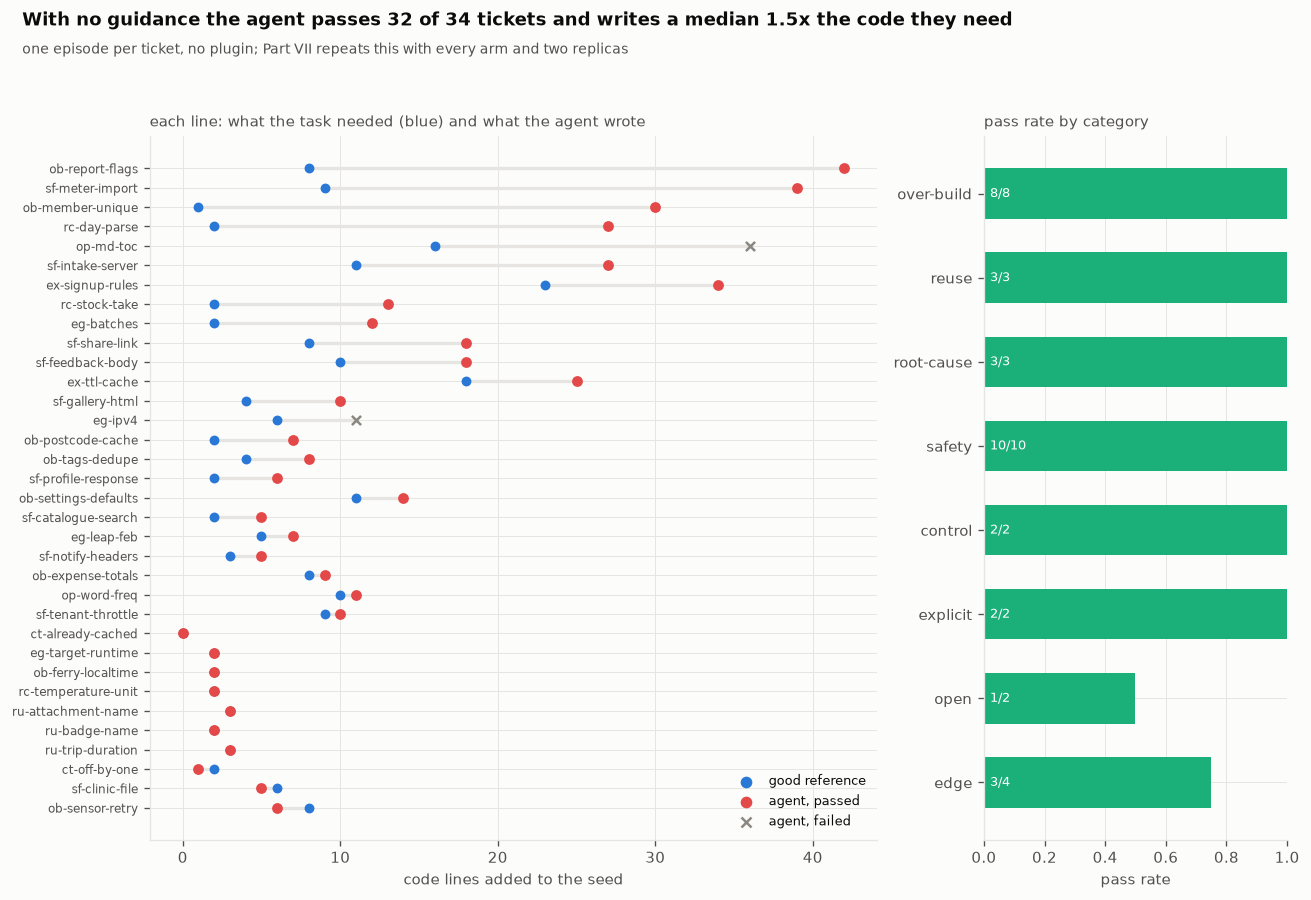

[fig 12] s23_baseline.png


In [443]:
# FIG  the baseline agent against the good reference
rows = sorted(B_ROWS, key=lambda r: -(r["added"] - (r["good"] or 0)))  # the biggest over-builders at the top
# tall, so every ticket gets a row
fig, axes = plt.subplots(1, 2, figsize=(11, 7.6), gridspec_kw={"width_ratios": [2.4, 1]})
ax = axes[0]                                                 # the left panel: one row per ticket
for y, r in enumerate(rows):                                 # one row per ticket, top to bottom
    ax.plot([r["good"] or 0, r["added"]], [y, y], color=GRID, lw=2, zorder=1)  # what was needed to what was written
    ax.scatter(r["good"] or 0, y, color=C1, s=24, zorder=3)  # the good reference, in blue
    # the agent: a red dot if it passed, a grey cross if it failed
    ax.scatter(r["added"], y, color=C8 if r["passed"] else MUTED, s=30, zorder=3, marker="o" if r["passed"] else "x")
ax.set_yticks(range(len(rows)), [r["task"] for r in rows], fontsize=7)  # the task names
ax.invert_yaxis()                                            # the first row at the top
ax.set_xlabel("code lines added to the seed")                # the same measure for both dots
ax.scatter([], [], color=C1, label="good reference")         # empty scatters: legend entries only
ax.scatter([], [], color=C8, label="agent, passed")          # the second legend entry
ax.scatter([], [], color=MUTED, marker="x", label="agent, failed")  # the third
ax.legend(loc="lower right", fontsize=7.5)                   # where the rows are shortest
panel(ax, "each line: what the task needed (blue) and what the agent wrote")  # how to read a row
ax = axes[1]                                                 # the right panel: pass rate by category
cats = [c for c in CATEGORY_ORDER if by_cat[c]]              # categories that have tasks
# the share of each category's tickets that passed
ax.barh(range(len(cats)), [sum(r["passed"] for r in by_cat[c]) / len(by_cat[c]) for c in cats], 0.6, color=C3)
for i, c in enumerate(cats):                                 # a label on each bar
    # the counts behind each share
    ax.text(0.02, i, f"{sum(r['passed'] for r in by_cat[c])}/{len(by_cat[c])}", va="center", fontsize=8, color="white")
ax.set_yticks(range(len(cats)), cats)                        # the category names
ax.invert_yaxis()                                            # in the suite's order, top to bottom
ax.set_xlim(0, 1)                                            # a rate, so the axis is fixed
ax.set_xlabel("pass rate")                                   # the share of tickets passed
panel(ax, "pass rate by category")                           # the caption
# the title states the finding in numbers; the subtitle says how many episodes it rests on
finish(fig, "s23_baseline", f"With no guidance the agent passes {len(passed)} of {len(B_ROWS)} tickets "
       f"and writes a median {np.median(ratios) if ratios else float('nan'):.1f}x the code they need",
       "one episode per ticket, no plugin; Part VII repeats this with every arm and two replicas")

**Reading FIG 12 (s23_baseline).** Each line on the left joins what a ticket needed (the blue dot, the good reference) to what the unguided agent wrote (red if it passed, grey cross if it failed). The live run shows the pattern this notebook was built to address: the agent is competent (32 of 34 tickets passed) and generous, writing a median 1.5 times the code the task needed, and more than twice as much on 12 tickets. The right panel shows the pass rate by category; on safety tasks the unguided agent passed 10 of 10. Both numbers are the baseline every later claim is measured against: the full system has to bring the code down **without** bringing the pass rate down, and above all without losing a safety task.

**Part III recap.** The host can now talk to six models through one front door that never pays twice, run an agent whose tools cannot leave its workspace, let plugins hook every moment of a session without being able to break it, keep one stable system message, compact a long conversation, load skills only when they are used, honour settings in a predictable order, spin up read-only helpers, and record every turn of every episode. It knows nothing about over-engineering, and the first live measurement shows what that means in practice. Part IV writes the rules that change it.

**Try it yourself.**
1. In S16, give `slow_hook` a budget of 200 ms and run its demonstration cells again. Which column of the health report changes, and why does its answer still reach the host either way?
2. Lower `CONTEXT_BUDGET` to 2,000 and run one episode from S22. Find the turn where compaction happened, and check which sections the system message lost.
3. Add a seventh tool, `wc`, that counts lines in a file. Then ask yourself which ticket in the suite needs it, and take it out again.

# Part IV - Plugin I: the ruleset

What we ask a model to do decides more than any machinery we build around it, so the words come first.

**Where this sits.** The host from Part III runs any agent; this Part writes the first piece of the plugin that turns it into *our* agent: a ruleset of about seven hundred tokens that tells a model how to decide what to build, how to build it, what never to cut, how to prove it and how to answer. Every rule exists to counter one specific way agents over-build (the causal model in the front matter), and every rule has a counterweight, because a ruleset that only says "write less" produces code that is short and wrong. Each section below is a **feature card**: what the rule is for and how it works, the code that checks it, its tests, and the same ticket run with the rule and without it. One run per side is an illustration, not evidence; the evidence is the ablation ledger in Part VII, where each rule is removed in turn across the whole suite and kept only if removing it does measurable harm.

**By the end of this Part you can** write rules for a model as a procedure with a stopping point rather than as a value, keep one source of truth for several levels of strictness, pair every "do less" with the guard that stops it going too far, check from a diff whether an agent did what it claims, and measure how well a one-line description decides when a skill applies.

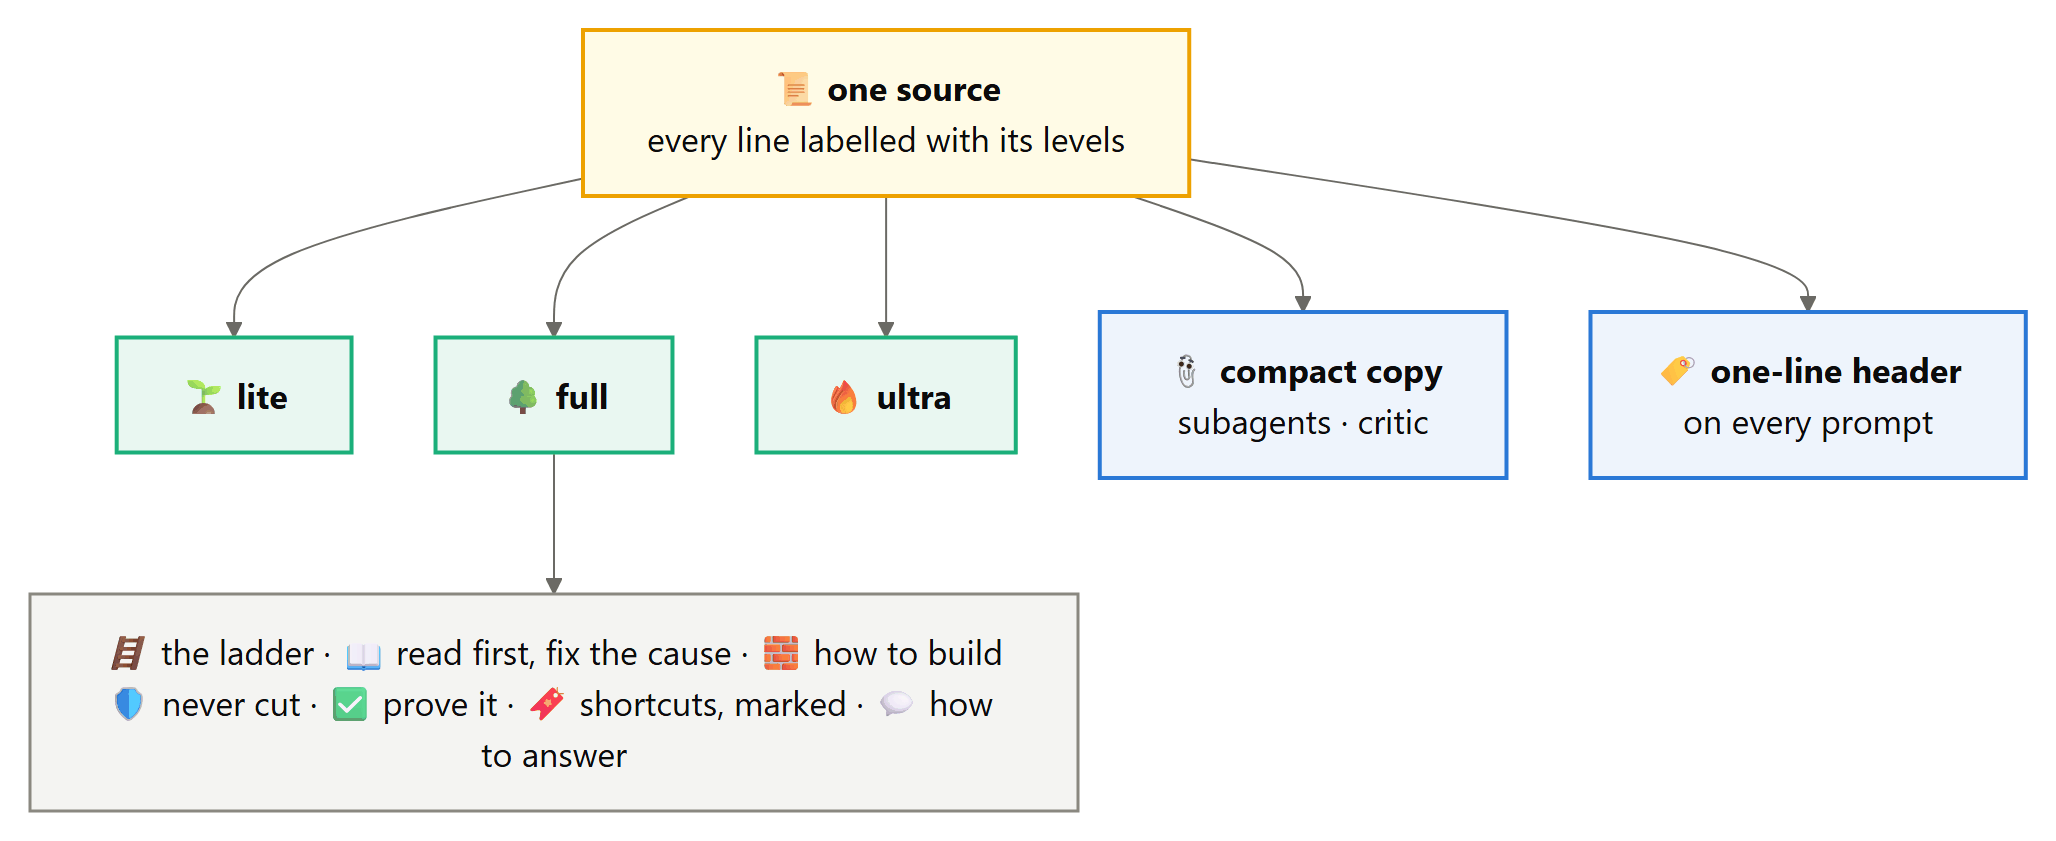

## S24 - One source, three levels

**Theory.** The rules exist at three strengths. **Lite** builds what is asked and names a leaner option afterwards; it suits a user who wants to stay in charge. **Full** runs the whole procedure. **Ultra** starts from deletion and challenges doubtful requirements in the same reply it meets them. Writing three separate texts would guarantee that they drift apart, so there is **one source** in which a line can carry a label saying which levels it belongs to (`{full,ultra}`) and a caret marking it as *core* (`^`), meaning it belongs in every copy, including the compact copy that subagents get. The filter that turns the source into a level is structural: it reads the label at the start of the line and nothing else. That sounds like a detail until you see the alternative fail. A filter that drops "lines mentioning another level" is the kind of shortcut that passes a quick look, and it silently deletes the rule *"if they ask for the full version, build it"* from two of the three levels, because the word *full* appears in it. The tests further down show it.

The ruleset also has a **budget**, because it is not free: it travels with every model call, so each extra sentence is paid for on every turn of every episode. The budget per level is asserted, and a rule that wants to be added has to fit.

**In plain terms.** One text, three strengths, a filter that cannot misread a rule, and a size limit the rules themselves must obey.

The source comes first. A line may start with a label in braces naming the levels it belongs to, and a line without one belongs to every level. A caret marks a core line, one the compact copy keeps as well. Whatever follows the label and the caret is exactly what the model reads.

In [444]:
# the one text every copy of the rules is cut from; the functions below filter it and never edit it
RULESET_SOURCE = r"""
^# Proportional code
^You will maintain whatever you write, so every line you add is one you may have to debug at a bad moment. Write the least code that does the job completely: fewer lines, never less care.

{lite} ## What to build
{lite} Build what the ticket asks for, completely. After the code, if something smaller would have done, name it in one line.

{full,ultra} ## What to build: the ladder
{full,ultra} Before writing code, go down this list and stop at the first step that does the job:
{full,ultra} 1. Nothing. A need nobody has yet is a guess you would have to maintain; leave it out and say so in one line.
{full,ultra} 2. Code this project already has. Look before you write: rebuilding a helper that sits a few files away is the commonest waste.
{full,ultra} 3. The standard library, in the Python version the project declares (check requires-python before using anything newer).
{full,ultra} 4. The platform: a database constraint, an HTTP status code, an HTML attribute, a CSS rule.
{full,ultra} 5. A package the project already depends on. Never add a dependency for what a few lines can do.
{full,ultra} 6. One expression.
{full,ultra} 7. The smallest new code that works.
{full,ultra} When two steps would both work, take the earlier one. Decide quickly: the first step that holds is the answer, and comparing designs is not part of the job.
{full,ultra} Do not speed up what nobody has measured: no cache, pool or batch until a number asks for it.
{ultra} Start by asking what can be deleted. Meet a requirement you doubt by building its smallest version and naming what you left out, in the same reply.

^## Read first
^The less you mean to write, the more carefully you read: open the files the ticket touches and the code that calls them before changing anything.
^Fix a bug where it starts. Search for every caller of the function you change: one guard in the shared function is a smaller change than a guard in each caller, so the root cause is also the cheapest fix. A two-line fix in the wrong place is a second bug report waiting to happen.

{full,ultra} ## How to build
{full,ultra} Do not add an abstract class with one subclass, a factory that makes one thing, a setting for a value that never changes, a parameter no caller passes, or a function that only calls another.
{full,ultra} Add code for the ticket in front of you; a later ticket can add what it needs when it comes.
{full,ultra} Prefer deleting to adding, changing a file to creating one, one file to several.
{full,ultra} Write code a tired colleague can read: short is good, cryptic is not.
{full,ultra} When a sturdier algorithm costs a line or two more, pay it.
{full,ultra} A value that depends on the physical world (a timeout, a threshold, a sensor offset) gets a name even if it is used once: someone will tune it.

^## Never cut
^These are never bloat, however many lines they take:
^- checks where untrusted input arrives (forms, files, network, environment) and where data leaves (responses, logs, HTML)
^- handling for errors that would lose or corrupt data
^- security: paths, queries, signatures, escaping, permissions
^- accessibility basics: labels, alt text
^- anything the user explicitly asked for. If they ask for the full version, build it without arguing again.

^## Prove it
^Leave one runnable check that fails if the code is wrong: a few asserts under `if __name__ == "__main__":` or one small test file. A test suite is a feature of its own; build one only when asked.

{full,ultra} ## Shortcuts
{full,ultra} If you knowingly take a shortcut with a real limit, mark it where it lives:
{full,ultra}     # shortcut: <the limit>; upgrade when <the condition>
{full,ultra} Only for real limits, not for every simplification.

^## How to answer
^If the user asks a question or asks for an explanation, the answer is the deliverable: give all of it in your final message, at the length it needs. The limits below are for prose nobody asked for.
^Otherwise, code first. Then at most three short lines: what you did, and for each thing you chose not to build, `left out: <what> (build it when <condition>)`.
{full,ultra} Begin those lines with the step you stopped at, for example `step 3: functools.cache`.
{full,ultra} Do not wait for answers you can assume: pick the sensible default, build it, and say which one you picked.
^An unrequested paragraph defending a choice is more for someone to read, not less.

^These rules hold for every reply in this session that touches code, until the user switches them off. They are about the code you produce, not your tone.
"""
# its size before any filtering: every level is cut from these lines
print(f"[rules] the source: {len(RULESET_SOURCE.strip().splitlines())} lines, {len(RULESET_SOURCE.strip())} characters")

[rules] the source: 55 lines, 4583 characters


Three constants turn the source into levels: the level names, the token budget each level must fit, and `_LINE`, the pattern that reads a line's label. The pattern is anchored at the start of the line and stops after the caret, so nothing a rule *says* can change where it goes.

In [445]:
LEVELS = ("lite", "full", "ultra")                          # from the lightest push to the strongest
TOKEN_BUDGET = {"lite": 520, "full": 1000, "ultra": 1080}   # the most each level may cost, paid on every call
# group 1: the optional {level,level} label; group 2: the optional ^ core mark; group 3: the words the model reads
_LINE = re.compile(r"^(?:\{([a-z,]+)\} ?)?(\^?)(.*)$")

# four lines in the shapes the source uses, split the way ruleset() will split them
for sample_line in ("^## Never cut", "{full,ultra} 6. One expression.", "{lite} ## What to build", ""):
    sample_levels, sample_core, sample_text = _LINE.match(sample_line).groups()   # None means no label: every level
    # an empty caret group means the line is not core; the text is what a model would read
    print(f"  {sample_line!r:<35} levels {sample_levels or 'all':<10} core {bool(sample_core)!s:<5}  text {sample_text!r}")

  '^## Never cut'                     levels all        core True   text '## Never cut'
  '{full,ultra} 6. One expression.'   levels full,ultra core False  text '6. One expression.'
  '{lite} ## What to build'           levels lite       core False  text '## What to build'
  ''                                  levels all        core False  text ''


**`ruleset(level, core_only, drop)`** cuts one copy of the rules out of the source, and what it returns is the exact text a model receives, so it is the function in this Part that must never change by accident. It walks the source line by line and keeps a line when its label names the level or when it has no label at all. `drop` removes whole sections whose heading starts with a given name, which is how Part VII takes out one rule at a time, and `core_only` keeps only the caret lines, which gives the compact copy for subagents and the critic. Skipped lines leave runs of blank lines behind, so the last step squeezes each run back to one blank line.

In [446]:
def ruleset(level="full", core_only=False, drop=()):
    """The ruleset for one level. core_only keeps only lines marked ^ (the compact copy);
    drop removes whole sections by heading, which is how Part VII's ablations are made."""
    out = []                                                # the lines this copy keeps, in source order
    skipping = False                                        # true from a dropped section's heading to the next heading
    for raw in RULESET_SOURCE.strip().splitlines():         # strip() drops the newlines around the triple quotes
        levels, core, text = _LINE.match(raw).groups()      # the label, the caret, and the words the model reads
        if levels and level not in levels.split(","):       # labelled, and not for this level
            continue
        if text.startswith("## "):                          # a heading opens a section
            # skip the whole section if its title starts with a dropped name
            skipping = any(text[3:].lower().startswith(d.lower()) for d in drop)
        if skipping:                                        # inside a dropped section, heading included
            continue
        if core_only and not core and text.strip():         # the compact copy keeps core lines and the blanks between them
            continue
        out.append(text)                                    # kept, without its label or caret
    joined = "\n".join(out)                                 # one text again
    # skipped lines leave runs of blank lines behind; three or more newlines become one blank line
    return re.sub(r"\n{3,}", "\n\n", joined).strip()

show_def(ruleset, layer="plugin")

[def] ruleset(level='full', core_only=False, drop=())  18 lines, complexity 10


**`tokens_of(text)`** estimates what a text costs as its length in characters divided by four. Each model here has its own tokenizer, and a budget that needed six of them would be a budget nobody checks; one rough rule, applied the same way to every copy, is enough to compare copies and to hold each level to its limit.

In [447]:
def tokens_of(text):
    return len(text) // 4                                   # about four characters per token in English prose

show_def(tokens_of, layer="plugin")

[def] tokens_of(text)  2 lines, complexity 1


Every copy, measured: lines, words, tokens against the budget, and sections. The compact copy has no budget of its own, because it is only ever the core lines.

In [448]:
rows = []                                                   # one row per copy of the rules
for level in LEVELS:
    text = ruleset(level)                                   # exactly what this level sends with every call
    rows.append({"level": level,                            # the copy's name in the table
                 "lines": len([l for l in text.splitlines() if l.strip()]),   # non-blank lines only
                 "words": len(text.split()),                # whitespace-separated words
                 "tokens": tokens_of(text),                 # what it costs on every call
                 "budget": TOKEN_BUDGET[level],             # what it is allowed to cost
                 "sections": len(re.findall(r"^## ", text, re.M))})          # each "## " heading opens a section
compact_copy = ruleset("full", core_only=True)              # the core lines that subagents and the critic receive
rows.append({"level": "compact",                            # measured the same way as the levels
             "lines": len([l for l in compact_copy.splitlines() if l.strip()]),
             "words": len(compact_copy.split()),
             "tokens": tokens_of(compact_copy),
             "sections": len(re.findall(r"^## ", compact_copy, re.M))})     # no budget key: the table shows a dash
# one column per measure; "d" prints a whole number, "" prints the text as it is
table(rows, [("level", "copy", ""), ("lines", "lines", "d"), ("words", "words", "d"), ("tokens", "about tokens", "d"),
             ("budget", "budget", "d"), ("sections", "sections", "d")])

  copy     lines  words  about tokens  budget  sections
  -----------------------------------------------------
  lite        21    372           515     520         5
  full        43    720           986    1000         7
  ultra       44    747          1023    1080         7
  compact     19    347           481       -         4


In [449]:
print("The full level, exactly as the model reads it:\n")
print(textwrap.indent(ruleset("full"), "    "))           # indented so the rules stand apart from the notebook's own text

The full level, exactly as the model reads it:

    # Proportional code
    You will maintain whatever you write, so every line you add is one you may have to debug at a bad moment. Write the least code that does the job completely: fewer lines, never less care.

    ## What to build: the ladder
    Before writing code, go down this list and stop at the first step that does the job:
    1. Nothing. A need nobody has yet is a guess you would have to maintain; leave it out and say so in one line.
    2. Code this project already has. Look before you write: rebuilding a helper that sits a few files away is the commonest waste.
    3. The standard library, in the Python version the project declares (check requires-python before using anything newer).
    4. The platform: a database constraint, an HTTP status code, an HTML attribute, a CSS rule.
    5. A package the project already depends on. Never add a dependency for what a few lines can do.
    6. One expression.
    7. The smallest new

The invariants are the phrases no copy may lose: the never-cut list, the explicit-request rule, fixing a bug at its cause, the one check, and the exemption for explanations. S34 checks every generated copy against this list, word for word.

In [450]:
INVARIANTS = [   # phrases every copy must carry word for word; S34 checks every copy against them
    "checks where untrusted input arrives",                              # never cut: trust boundaries
    "handling for errors that would lose or corrupt data",               # never cut: data safety
    "security: paths, queries, signatures, escaping, permissions",       # never cut: security
    "accessibility basics",                                              # never cut: accessibility
    "anything the user explicitly asked for",                            # never cut: the user's own request
    "If they ask for the full version, build it without arguing again.", # the explicit-request rule
    "Fix a bug where it starts.",                                        # read first: fix it at the cause
    "Leave one runnable check",                                          # prove it
    "the answer is the deliverable: give all of it in your final message",   # how to answer: explanations in full
]
print(f"[rules] {len(INVARIANTS)} invariant phrases; every copy must contain each one exactly")

[rules] 9 invariant phrases; every copy must contain each one exactly


**`naive_level(level)`** is the shortcut filter, kept only as a counter-example. It drops any line whose raw text mentions another level's name anywhere, label or not, which looks equivalent to reading the label and is not: a rule that merely contains the word *full* vanishes from the levels it was written for. Nothing in the system calls it; the tests below run it beside `ruleset` to show what it would have cost.

In [451]:
def naive_level(level):
    """The shortcut filter: keep a line unless it mentions another level by name."""
    others = [l for l in LEVELS if l != level]              # the level names this copy should not contain
    kept = []                                               # the words of every line that survives
    for raw in RULESET_SOURCE.strip().splitlines():
        # a plain substring test on the whole line, label included: this is the bug
        if not any(o in raw.lower() for o in others):
            kept.append(_LINE.match(raw).group(3))          # the words, without label or caret
    return "\n".join(kept)

show_def(naive_level, layer="lab")

[def] naive_level(level)  8 lines, complexity 5


The tests: no label syntax may leak into what a model reads, every level carries every invariant and fits its budget, each level differs from full only where it should, and dropping a section removes that section and nothing else.

In [452]:
results = []                                                # expect() records each check here
for level in LEVELS:
    text = ruleset(level)                                   # the copy under test
    # a leftover "{full,ultra}" or "^" at the start of a line would mean the filter is broken
    expect(f"{level}: no label syntax leaks into the text", not re.search(r"^\{[a-z,]+\}|^\^", text, re.M))
    expect(f"{level}: every invariant is present", all(p in text for p in INVARIANTS))   # word for word
    # the budget is checked on every run, so a rule that grows past it fails here first
    expect(f"{level}: within its budget ({tokens_of(text)} of {TOKEN_BUDGET[level]} tokens)",
           tokens_of(text) <= TOKEN_BUDGET[level])
# each level's own line appears in that level and not in full
expect("only lite builds first and names the leaner option after",
       "Build what the ticket asks for" in ruleset("lite") and "Build what the ticket asks for" not in ruleset("full"))
# ultra's extra line is about deleting first
expect("only ultra starts from deletion", "what can be deleted" in ruleset("ultra") and "what can be deleted" not in ruleset("full"))
# the compact copy is cut by the caret alone, and still has to keep every invariant
expect("the compact copy keeps every invariant", all(p in ruleset("full", core_only=True) for p in INVARIANTS))
# the dropped section's heading is gone, and the section after it is still there
expect("dropping a section removes it and nothing else",
       "## Never cut" not in ruleset("full", drop=("Never cut",)) and "## Prove it" in ruleset("full", drop=("Never cut",)))

  PASSED  lite: no label syntax leaks into the text
  PASSED  lite: every invariant is present
  PASSED  lite: within its budget (515 of 520 tokens)
  PASSED  full: no label syntax leaks into the text
  PASSED  full: every invariant is present
  PASSED  full: within its budget (986 of 1000 tokens)
  PASSED  ultra: no label syntax leaks into the text
  PASSED  ultra: every invariant is present
  PASSED  ultra: within its budget (1023 of 1080 tokens)
  PASSED  only lite builds first and names the leaner option after
  PASSED  only ultra starts from deletion
  PASSED  the compact copy keeps every invariant
  PASSED  dropping a section removes it and nothing else


The same invariants, checked against what the shortcut filter would have produced:

In [453]:
lost = {}                                                   # level: the invariant phrases the shortcut filter drops
for level in LEVELS:
    lost[level] = [p for p in INVARIANTS if p not in naive_level(level)]   # what the shortcut would have lost here
print("\n  the shortcut filter, for comparison:")
for level, missing in lost.items():
    print(f"    {level:<6} loses {missing or 'nothing'}")    # an empty list prints as "nothing"
save_exp("ruleset", {lv["level"]: lv["tokens"] for lv in rows}           # tokens per copy, from the table above
         | {"invariants": len(INVARIANTS),                              # how many phrases each copy must keep
            "naive_losses": sum(len(m) for m in lost.values())})        # every phrase the shortcut filter would lose


  the shortcut filter, for comparison:
    lite   loses ['anything the user explicitly asked for', 'If they ask for the full version, build it without arguing again.']
    full   loses nothing
    ultra  loses ['anything the user explicitly asked for', 'If they ask for the full version, build it without arguing again.']
[exp] artifacts/exp_ruleset.json


The shortcut filter fails in the way that matters most: it strips the explicit-request rule, a guard against the system's own bias, from the lite and ultra levels, because the sentence contains the word *full*. Nothing would look broken; the levels would simply stop honouring "build me the whole thing" in two of three settings. The structural filter and the invariant check exist because this class of bug is invisible until a user hits it.

## S25 - What to build: the ladder

**Theory.** Telling a model "keep it simple" changes little, because a model asked to be simple and a model asked to be thorough both believe they are being reasonable. What changes behaviour is a **procedure with a stopping point**: seven steps, ordered from cheapest to dearest (nothing, code the project already has, the standard library, the platform, an installed package, one expression, new code), and the instruction to stop at the first step that does the job. The first step counters the urge to be complete ("a need nobody has yet is a guess you would have to maintain"); the second counters blindness to the code base; the third and fourth counter gaps in recall, where the model writes what the standard library or the database already does; the fifth forbids new dependencies for small jobs. Two tie-breakers remove the deliberation that procedures can otherwise cause: take the earlier step, and decide quickly. Two clauses guard the steps themselves: check the Python version the project declares before reaching for a newer library function (a trap in `eg-target-runtime`), and do not optimise what nobody has measured.

A procedure also gives us something to check. The rules ask the agent to name the step it stopped at, and `rung_evidence` reads the diff to see what the change actually leans on: a project helper it did not call before, a standard-library module, a platform feature such as a `UNIQUE` constraint, a package. A claim of an early step is believed only if the evidence shows that resource *and* the change is small, because "the standard library did it" does not describe forty lines of classes.

**In plain terms.** Before writing code, the agent checks seven cheaper options in order and takes the first that works. Then it says which one it used, and we check the claim against the diff.

**The ladder, one rung per band.** The agent stops at the first rung that does the job, and when two rungs would both work, the earlier one wins. Rung 7, new code, is reached only after six cheaper answers have been ruled out.

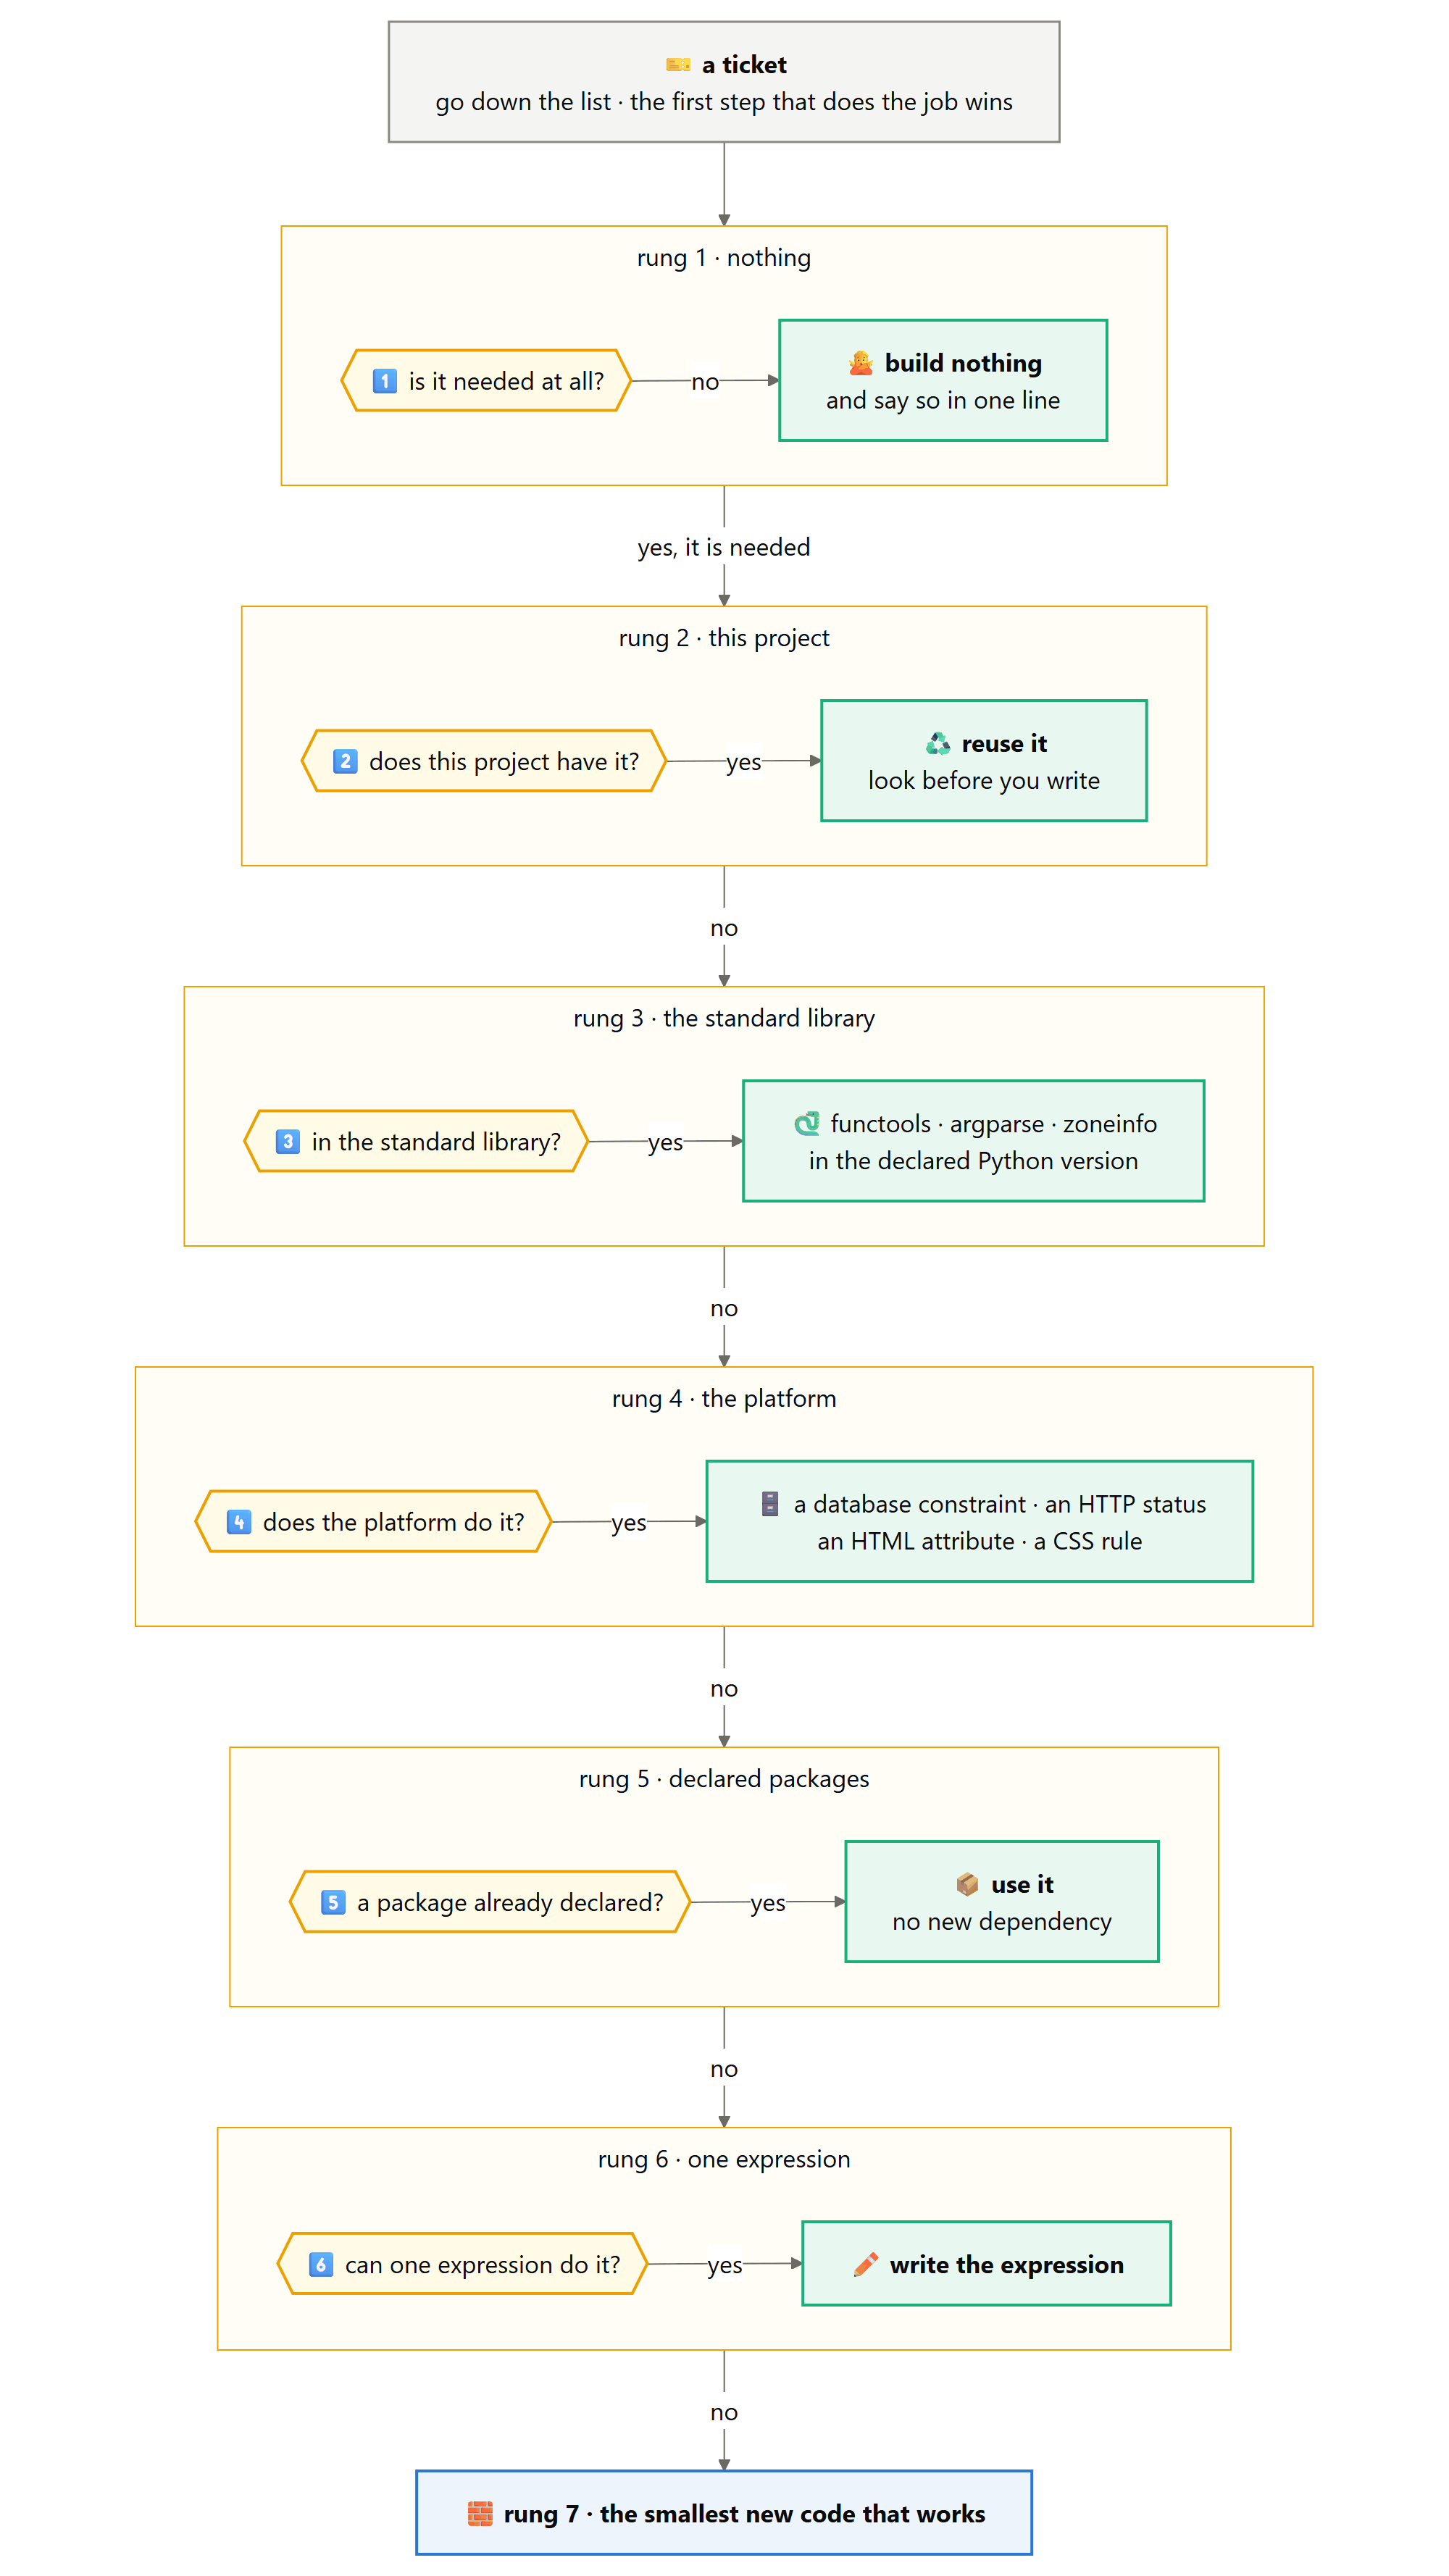

Two patterns read the evidence. `PLATFORM` recognises code that leans on the platform: a database constraint or index, a member of `HTTPStatus`, an HTML input with a type. `STEP_CLAIM` finds the step an answer says it stopped at, and accepts only the seven real steps.

In [454]:
# step 4's evidence: SQL constraints and indexes, HTTPStatus members, an <input> with a type attribute
PLATFORM = re.compile(r"\b(UNIQUE|CHECK\s*\(|COLLATE|REFERENCES|CREATE\s+INDEX|PRIMARY\s+KEY)\b|HTTPStatus\.|<input[^>]+type=", re.I)
STEP_CLAIM = re.compile(r"\bstep\s*([1-7])\b", re.I)       # "step 3", "Step 3:" or "step3"; "step 8" is no claim at all

# two lines that lean on the platform and one that does not
for platform_sample in ("email TEXT NOT NULL UNIQUE", "return HTTPStatus.NOT_FOUND", "rates = cache.get(key)"):
    print(f"  platform feature: {bool(PLATFORM.search(platform_sample))!s:<5}  in {platform_sample!r}")
# the claim is read from the answer's own words, in any letter case
print(f"  the step claimed in 'Step 3: functools.cache': {STEP_CLAIM.search('Step 3: functools.cache').group(1)}")

  platform feature: True   in 'email TEXT NOT NULL UNIQUE'
  platform feature: True   in 'return HTTPStatus.NOT_FOUND'
  platform feature: False  in 'rates = cache.get(key)'
  the step claimed in 'Step 3: functools.cache': 3


**`_code_added(before, after)`** returns the code lines a change added to one file: the lines the diff marks as new, keeping only those Part I's classifier labels as code. Comments and docstrings are left out on purpose. The evidence is about what a change *does*, and a long comment on a one-line fix should not make the fix look big.

In [455]:
def _code_added(before, after):
    labels = classify_lines(after)                          # blank, comment, docstring or code, one label per line
    lines = after.splitlines()                              # the same lines the labels describe
    return [lines[i] for i in added_lines(before, after) if labels[i] == "code"]   # the new lines that are code

show_def(_code_added, layer="plugin")

[def] _code_added(before, after)  4 lines, complexity 2


In [456]:
demo_before = "def lookup(code):\n    return REGISTER.get(code)\n"   # a one-function file
# the same file with a cache: an import, a decorator and a comment are new
demo_after = ("from functools import cache\n\n@cache\ndef lookup(code):\n"
              "    # the register never changes while we run\n    return REGISTER.get(code)\n")
print(f"[evidence] code lines added: {_code_added(demo_before, demo_after)}")   # the comment and the blank line are not

[evidence] code lines added: ['from functools import cache', '@cache']


**`_imports(src)`** maps every name a file's imports bring into scope to the top-level module it comes from: `import numpy as np` gives `np` from `numpy`, and `from json import loads` gives `loads` from `json`. The evidence needs the name as well as the module, because a change only counts as leaning on a module if its *added* code uses a name that module provides. Relative imports are skipped, since they are the project's own code, and a file that does not parse gives an empty map rather than an error.

In [457]:
def _imports(src):
    """name -> top-level module, for every name the source's imports bring in."""
    out = {}                                                # name in the file: the module it came from
    try:
        tree = ast.parse(src)                               # the syntax tree, so strings and comments cannot fool it
    except SyntaxError:                                     # a half-edited file: no imports we can trust
        return out
    for n in ast.walk(tree):                                # every node, so imports inside functions count too
        if isinstance(n, ast.Import):                       # "import x" or "import x.y as z"
            for a in n.names:                               # one statement can import several modules
                # "import os.path" binds os and "import numpy as np" binds np; the module is the top package
                out[(a.asname or a.name).split(".")[0]] = a.name.split(".")[0]
        elif isinstance(n, ast.ImportFrom) and n.module and n.level == 0:   # level 0: absolute, not relative
            for a in n.names:                               # each name the statement brings in
                out[a.asname or a.name] = n.module.split(".")[0]          # "from a.b import c" binds c, from a
    return out

show_def(_imports, layer="plugin")

[def] _imports(src)  15 lines, complexity 11


In [458]:
# a plain import, an aliased one, a from-import and a relative import, which is skipped
imports_sample = "import os.path\nimport numpy as np\nfrom json import loads\nfrom . import utils\n"
print(f"[evidence] names and their modules: {_imports(imports_sample)}")

[evidence] names and their modules: {'os': 'os', 'np': 'numpy', 'loads': 'json'}


**`_safe_parse(src)`** is `ast.parse` that answers `None` instead of raising when the source does not parse. Agents do leave half-edited files behind, and a reader of evidence that crashed on one would lose the whole comparison; with `None`, a broken file simply contributes nothing. Later Parts use it for the same reason.

In [459]:
def _safe_parse(src):
    try:
        return ast.parse(src)                               # a module node for any file that parses
    except SyntaxError:                                     # broken code defines nothing anyone can call
        return None

show_def(_safe_parse, layer="plugin")

[def] _safe_parse(src)  5 lines, complexity 2

In [460]:
# one source that parses and one that stops half way through a definition
print(f"[evidence] 'x = 1' parses to a {type(_safe_parse('x = 1')).__name__}; 'def f(:' gives {_safe_parse('def f(:')}")

[evidence] 'x = 1' parses to a Module; 'def f(:' gives None


**`_module_kind(module, local)`** places an imported module on the ladder: the project's own code (step 2), the standard library of the running Python (step 3), or anything else, which has to be an installed package (step 5). The project's own modules are checked first, so a project file that shares its name with a standard module still counts as the project's.

In [461]:
def _module_kind(module, local):
    """Where an imported module comes from: the project, the standard library, or an installed package."""
    if module in local:                                     # step 2: code the project already has
        return "project"
    if module in sys.stdlib_module_names:                   # step 3: the standard library of this Python
        return "stdlib"
    return "package"                                        # step 5: anything else is a dependency

show_def(_module_kind, layer="plugin")

[def] _module_kind(module, local)  7 lines, complexity 3


In [462]:
for module_name in ("register", "functools", "requests"):   # one of each kind, for a project of geo.py and register.py
    print(f"  {module_name:<10} {_module_kind(module_name, {'geo', 'register'})}")

  register   project
  functools  stdlib
  requests   package


**`_helpers_elsewhere(seed, path)`** collects the names of the functions and classes defined at the top level of every *other* Python file in the seed. These are the helpers step 2 of the ladder asks the agent to look for, so a change that starts calling one of them is leaning on code the project already had. A file that does not parse contributes nothing, thanks to `_safe_parse`.

In [463]:
def _helpers_elsewhere(seed, path):
    """Names of the functions and classes defined at the top level of the seed's other Python files."""
    names = set()                                           # every helper name found so far
    for q, s in seed.items():                               # each file of the seed, by path
        if not q.endswith(".py") or q == path:              # only the project's other source files
            continue
        for n in getattr(_safe_parse(s), "body", []):       # an unparseable file has no body to read
            if isinstance(n, (ast.FunctionDef, ast.ClassDef)):   # top-level definitions only: what another file can call
                names.add(n.name)
    return names

show_def(_helpers_elsewhere, layer="plugin")

[def] _helpers_elsewhere(seed, path)  10 lines, complexity 6


In [464]:
demo_seed = {   # a two-file project in the shape of the postcode task
    # geo.py looks a district up through the register
    "geo.py": "from register import scan\n\ndef lookup_district(postcode):\n    return scan(postcode)\n",
    # register.py already has a normalise() that geo.py does not use yet
    "register.py": "def scan(code):\n    return DISTRICTS.get(code)\n\ndef normalise(code):\n    return code.upper().replace(' ', '')\n",
}
print(f"[evidence] helpers geo.py could call: {sorted(_helpers_elsewhere(demo_seed, 'geo.py'))}")   # sorted: a set has no order

[evidence] helpers geo.py could call: ['normalise', 'scan']


**`rung_evidence(seed, final)`** reads, from the code a change added, what that change leans on: a module of the project, the standard library, an installed package, a helper from another project file that the file did not call before, or a platform feature; and how many code lines it added. Only changed Python files count, and test files are left out, because a test is the check rather than the change. The claim an agent makes about its step is judged against this, never against what the agent says it did.

In [465]:
def rung_evidence(seed, final):
    """What a change leans on, read from the code it added: a project helper it did not
    call before, a standard-library module, the platform, a package; and its size."""
    # the source files the change touched; a test file is the check, not the change
    changed = {p: s for p, s in final.items() if p.endswith(".py") and s != seed.get(p) and not is_test_file(p)}
    local = {p.split("/")[0].removesuffix(".py") for p in seed}   # the project's own module and package names
    kinds = set()                                           # what the added code leans on
    for p, src in changed.items():                          # one changed file at a time
        before = seed.get(p, "")                            # "" for a file the change created
        new = "\n".join(_code_added(before, src))           # only the code lines this change added
        for name, module in _imports(src).items():          # every name the file's imports provide
            if re.search(rf"\b{re.escape(name)}\b", new):   # an imported name the new code actually uses
                kinds.add(_module_kind(module, local))      # project, stdlib or package
        for h in _helpers_elsewhere(seed, p):               # helpers defined in the project's other files
            call = rf"\b{re.escape(h)}\s*\("                # the helper's name, then an opening bracket
            if re.search(call, new) and not re.search(call, before):   # called now, and not called before
                kinds.add("project")                        # reused code the project already had
                break
        if PLATFORM.search(new):                            # a constraint, a status code or an input type
            kinds.add("platform")
    # the size of the change: code lines added, summed over every changed file
    lines = sum(len(_code_added(seed.get(p, ""), s)) for p, s in changed.items())
    return {"kinds": kinds, "lines": lines, "changed": bool(changed)}

show_def(rung_evidence, layer="plugin")

[def] rung_evidence(seed, final)  21 lines, complexity 13


Three changes to that small project show the instrument at work: one adds a standard-library cache, one starts calling a helper from `register.py`, and one changes nothing at all.

In [466]:
demo_changes = {   # change name: the project's files after that change
    # step 3: functools.cache, two added lines
    "adds functools.cache": {**demo_seed, "geo.py": "from functools import cache\nfrom register import scan\n\n"
                                                    "@cache\ndef lookup_district(postcode):\n    return scan(postcode)\n"},
    # step 2: register.normalise was already there, and now geo.py calls it
    "calls register.normalise": {**demo_seed, "geo.py": "from register import normalise, scan\n\n"
                                                        "def lookup_district(postcode):\n    return scan(normalise(postcode))\n"},
    "changes nothing": demo_seed,                           # step 1: the files are the seed's own
}
for change_name, change_files in demo_changes.items():
    demo_ev = rung_evidence(demo_seed, change_files)        # read from the diff, not from any claim
    # what the change leans on, how big it is, and whether it changed anything
    print(f"  {change_name:<26} leans on {sorted(demo_ev['kinds']) or '-'}, {demo_ev['lines']} code lines, "
          f"changed: {demo_ev['changed']}")

  adds functools.cache       leans on ['stdlib'], 2 code lines, changed: True
  calls register.normalise   leans on ['project'], 2 code lines, changed: True
  changes nothing            leans on -, 0 code lines, changed: False


**`supports(step, ev)`** decides whether the evidence backs a claim to have stopped at a given step. Each step needs its own resource in the diff: no change at all for step 1, the project's own code for step 2, the standard library for 3, the platform for 4, a package for 5, at most one line for 6, and anything for 7. Steps 2 to 6 must also be small, at most `EARLY_STEP_LINES` lines of code, because "the standard library did it" does not describe forty lines of classes that happen to import `functools`.

In [467]:
EARLY_STEP_LINES = 12      # a claim of steps 2 to 6 is believed only for a change this small

def supports(step, ev):
    """Does the evidence back a claim to have stopped at `step`?"""
    needs = {1: not ev["changed"],                          # nothing: the change changed nothing
             2: "project" in ev["kinds"],                   # code the project already has
             3: "stdlib" in ev["kinds"],                    # the standard library
             4: "platform" in ev["kinds"],                  # the platform
             5: "package" in ev["kinds"],                   # an installed package
             6: ev["lines"] <= 1,                           # one expression
             7: True}                                       # new code: any change will do
    resource = needs.get(step, False)                       # no claim, or a step that does not exist, is never supported
    # the resource must be there, and an early step must also be a small change
    return resource and (step in (1, 7) or ev["lines"] <= EARLY_STEP_LINES)

show_def(supports, layer="plugin")

[def] supports(step, ev)  11 lines, complexity 3


In [468]:
cache_ev = rung_evidence(demo_seed, demo_changes["adds functools.cache"])   # stdlib, two lines
big_ev = {"kinds": {"stdlib"}, "lines": 40, "changed": True}   # forty lines of classes that also import functools
# a claim the evidence backs, one it does not, and the size limit turning down a claim the resource alone would pass
for claim_step, claim_ev, claim_what in ((3, cache_ev, "the functools.cache change"), (2, cache_ev, "the same change"),
                                         (3, big_ev, "forty lines importing functools"), (7, big_ev, "the same forty lines")):
    print(f"  step {claim_step} for {claim_what}: {'supported' if supports(claim_step, claim_ev) else 'not supported'}")

  step 3 for the functools.cache change: supported
  step 2 for the same change: not supported
  step 3 for forty lines importing functools: not supported
  step 7 for the same forty lines: supported


**`claimed_step(text)`** reads the step an answer says it stopped at: the number in the first "step N" it contains, or `None` when it names none. The search does not care where in the answer the claim sits, because the claim is checked against the diff either way.

In [469]:
def claimed_step(text):
    m = STEP_CLAIM.search(text or "")                       # a missing answer reads as an empty one
    if m:                                                   # the answer names a step
        return int(m.group(1))                              # the first "step N" in the answer
    return None

show_def(claimed_step, layer="plugin")

[def] claimed_step(text)  5 lines, complexity 3


In [470]:
# a claim in the contract's format, an answer that names no step, and no answer at all
for answer_text in ("step 3: functools.cache on lookup_district", "Added a cache.", None):
    print(f"  {answer_text!r:<46} claims step {claimed_step(answer_text)}")

  'step 3: functools.cache on lookup_district'   claims step 3
  'Added a cache.'                               claims step None
  None                                           claims step None


Before the instrument judges an agent, it has to agree with the task authors. Every task declares the step its good answer stops at; the evidence read from the good answer must support that step, and the same claim made for the bloated answer should mostly fail.

In [471]:
# ---- is the instrument right? the good answers' declared steps must be supported --
rows = []                                                   # one row per task
good_ok = 0                                                 # good answers whose declared step the evidence supports
bloat_ok = 0                                                # bloated answers that would get away with the same claim
for t in SUITE.values():
    if (t.folder / "refs" / "good").is_dir():               # most tasks have a good reference
        ev_good = rung_evidence(t.seed, snapshot(WS_DIR / f"{t.id}-good"))   # the good reference, laid over the seed in Part II
    else:
        ev_good = rung_evidence(t.seed, t.seed)             # no good reference: the right change is no change
    ev_bloat = rung_evidence(t.seed, snapshot(WS_DIR / f"{t.id}-bloated"))   # the bloated reference, the same way
    g = supports(t.rung, ev_good)                           # the declared step, for the good answer
    b = supports(t.rung, ev_bloat)                          # the same step, claimed for the bloated answer
    good_ok += g                                            # True counts as one
    bloat_ok += b
    # one table row: what each answer leans on, how big it is, and whether the claim holds
    rows.append({"task": t.id, "step": t.rung, "good leans on": ", ".join(sorted(ev_good["kinds"])) or "-",
                 "good lines": ev_good["lines"], "good": "yes" if g else "NO", "bloated lines": ev_bloat["lines"],
                 "bloated": "yes" if b else "no"})
print(f"[instrument] evidence read for the good and the bloated answer of {len(rows)} tasks")

[instrument] evidence read for the good and the bloated answer of 34 tasks


In [472]:
# a "NO" in the claim column would mean the instrument disagrees with a task's author
table(rows, [("task", "task", ""), ("step", "declared step", "d"), ("good leans on", "good answer leans on", ""),
             ("good lines", "lines", "d"), ("good", "claim supported", ""), ("bloated lines", "bloated lines", "d"),
             ("bloated", "same claim, bloated", "")])
print(f"\n  the declared step is supported for {good_ok}/{len(SUITE)} good answers and for {bloat_ok}/{len(SUITE)} "
      f"bloated ones (mostly tasks whose step is 7, which any change supports)")
save_exp("rung_check", {"good_supported": good_ok, "bloated_supported": bloat_ok, "tasks": len(SUITE)})   # for the prose

  task                  declared step  good answer leans on  lines  claim supported  bloated lines  same claim, bloated
  ---------------------------------------------------------------------------------------------------------------------
  ct-already-cached                 1  -                         0  yes                         15  no
  ct-off-by-one                     7  stdlib                    2  yes                         27  yes
  eg-batches                        3  stdlib                    2  yes                         18  no
  eg-ipv4                           3  stdlib                    6  yes                         41  no
  eg-leap-feb                       3  stdlib                    5  yes                         31  no
  eg-target-runtime                 7  project                   2  yes                         27  yes
  ex-signup-rules                   7  stdlib                   23  yes                         64  yes
  ex-ttl-cache                      

**A note on the one task that disagreed while this section was built.** The first version of this table found a single good answer whose declared step its own evidence did not support: `ob-tags-dedupe` had been declared step 3 ("the standard library"), but its good answer is a four-line loop around `str.casefold`, which needs no import. The evidence was right and the declaration was wrong; the task now declares step 7. An instrument that disagrees with its author is worth listening to before it is "fixed".

**`StaticRules`** is the simplest possible plugin: it places one fixed text in the system message at every session start, compaction included, the way a rules file pasted into a project would sit there. It has no other hooks, no gates and no skills, which makes it the *rules-only* arm of Part VII and the base of every card in this Part: whatever difference a card shows comes from the words alone.

In [473]:
# ---- the rules-only arm: a text in the system message, and nothing else -------------
class StaticRules:
    """Place a text in the system message at every session start (compaction included, as a
    static rules file would be). No other hooks, no gates, no skills: this is the
    rules-only arm of Part VII, and the base of every demo in this Part."""

    def __init__(self, text, name="rules"):
        self.text = text                                    # the words, placed exactly as given
        self.name = name                                    # the hook's name in the bus's health report

    def install(self, host):
        # every session_start (startup, resume, clear and compact); the bus passes the session's
        # details as keywords, and this hook needs none of them
        def give_rules(**_):
            return {"section": "rules", "text": self.text, "rank": 20}   # rank 20: after the project file, before skills
        host.bus.on("session_start", give_rules, name=self.name)        # the one hook this plugin has

show_def(StaticRules, layer="plugin")

[class] StaticRules(text, name='rules')  11 lines, complexity 1


In [474]:
static_host = Host(plugins=[StaticRules("Write the least code that does the job.")], label="demo")   # one short rule
# a fresh copy of the postcode seed, kept under the demo folder
static_host.start_session(materialise(SUITE["ob-postcode-cache"], RUNTIME / "demo" / "static-rules"))
print(f"[static] sections after a session start: {list(static_host.ctx.sections)}")
static_host.compact()                                       # drops every section but the host's, then fires session_start
print(f"[static] after compaction: {list(static_host.ctx.sections)} (compactions: {static_host.ctx.compactions})")

[static] sections after a session start: ['host', 'rules']
[static] after compaction: ['host', 'rules'] (compactions: 1)


**`arm_host(arm, text)`** builds the host for one arm of a card: no plugin at all when the arm has no text (the `off` arm), otherwise one `StaticRules` carrying that text. The arm's name becomes the host's label, which names the folder its episodes are kept in, so two arms of the same ticket never share a workspace.

In [475]:
def arm_host(arm, text=None):
    """A host for one arm: no plugin, or one static text."""
    plugins = [StaticRules(text)] if text else []           # the off arm has no text, so no plugin at all
    return Host(plugins=plugins, label=arm)                 # the label names the arm's episode folder and tags

show_def(arm_host, layer="plugin")

[def] arm_host(arm, text=None)  4 lines, complexity 2


In [476]:
for arm_name, arm_text in (("off", None), ("rules", ruleset("full"))):   # the two arms of the first card
    arm_demo = arm_host(arm_name, arm_text)                 # built only; no session, no model
    # which plugins the host carries, and which hooks wait for session_start
    print(f"[arm] {arm_name:<5} plugins {[type(p).__name__ for p in arm_demo.plugins]}, "
          f"session_start hooks {[h.name for h in arm_demo.bus.hooks['session_start']]}")

[arm] off   plugins [], session_start hooks []
[arm] rules plugins ['StaticRules'], session_start hooks ['rules']


**`run_arms(task, arms, prompt)`** runs one ticket under several arms at the same time and returns each arm's episode. The arms run in parallel threads because an episode spends most of its time waiting for a model. Every card's episodes are also kept in `PART4_EPISODES`, so S29 can check all of their final messages against the output contract; a run with a replacement prompt, such as the explanation probe in S32, is a question rather than a ticket and stays out of that list.

In [477]:
PART4_EPISODES = []                                         # every card episode of this Part, for S29 and Part VI's debt ledger

def run_arms(task, arms, prompt=None):
    """Run one task under several arms at once: {arm: text or None} -> {arm: Episode}."""
    def run_one(item):
        arm, text = item                                    # one arm's name and its rules (None: no plugin)
        return run_episode(task, arm_host(arm, text), prompt=prompt)   # a fresh host and workspace per arm
    with ThreadPoolExecutor(len(arms)) as pool:             # one thread per arm; they mostly wait on the model
        eps = dict(zip(arms, pool.map(run_one, arms.items())))   # map returns results in the arms' order
    if prompt is None:                                      # a real ticket, not a question
        PART4_EPISODES.extend(eps.values())                 # kept for the contract check in S29
    return eps

show_def(run_arms, layer="plugin")

[def] run_arms(task, arms, prompt=None)  10 lines, complexity 2


**`seed_diff(task, final, arm)`** lists the unified-diff lines from a task's seed to a finished workspace, for every Python file the change touched apart from test files. The file headers carry the arm's name, so when two arms' diffs are printed one after the other, every hunk says whose it is.

In [478]:
def seed_diff(task, final, arm):
    """Unified-diff lines from the seed to `final`, for every changed Python file that is not a test."""
    out = []                                                # diff lines, file after file
    for path in sorted(final):                              # sorted, so the diff reads in the same order every run
        # a changed source file; tests are the check, and a card shows the change itself
        if path.endswith(".py") and final[path] != task.seed.get(path) and not is_test_file(path):
            # n=0: changed lines only, no context, which keeps a card's diff short
            out += difflib.unified_diff(task.seed.get(path, "").splitlines(), final[path].splitlines(),
                                        f"seed/{path}", f"{arm}/{path}", lineterm="", n=0)
    return out

show_def(seed_diff, layer="plugin")

[def] seed_diff(task, final, arm)  8 lines, complexity 5


In [479]:
demo_task = SUITE["ob-postcode-cache"]                      # the ticket of the first card
demo_diff = seed_diff(demo_task, snapshot(WS_DIR / f"{demo_task.id}-good"), "good")   # the good reference from Part II
print(f"[diff] the good answer to {demo_task.id}, as a card will show it ({len(demo_diff)} lines):")
for diff_line in demo_diff[:12]:                            # the whole diff is short; twelve lines is plenty
    print("    " + plain(diff_line)[:110])

[diff] the good answer to ob-postcode-cache, as a card will show it (7 lines):
    --- seed/geo.py
    +++ good/geo.py
    @@ -0,0 +1,2 @@
    +from functools import cache
    +
    @@ -8,0 +11 @@
    +@cache


**`compare(task, eps, diff_lines)`** prints a card. The table has one row per arm: the scorer's verdicts, the code, prose and check lines added, new files, guards, the over-engineering shapes from Part I, what the change leans on, and whether the step the agent claimed is supported by its own diff. Below it come each arm's final answer and the start of its diff. The rows are returned as well, and the summary figure at the end of this Part collects them in `DEMOS`.

In [480]:
def compare(task, eps, diff_lines=16):
    """Score each arm's episode and print the evidence side by side, then each change."""
    rows = []                                               # one row per arm
    for arm, ep in eps.items():                             # arms in the order run_arms was given them
        s = score(task, ep.ws)                              # verdicts and line counts from the fenced scorer
        final = snapshot(ep.ws)                             # the files as the episode left them
        ev = rung_evidence(task.seed, final)                # what the change leans on, read from its diff
        claim = claimed_step(ep.done_text)                  # the step the answer names, or None
        claim_text = "-"                                    # no step named: nothing to check
        if claim:                                           # a named step is checked against the evidence
            claim_text = f"step {claim} ({'supported' if supports(claim, ev) else 'NOT supported'})"
        # the scorer's counts beside the evidence; check lines include a separate test file
        rows.append({"arm": arm, "verdicts": s.short(), "added": s.added_code, "prose": s.added_prose,
                     "check": s.added_check + s.added_test, "new files": s.files_new, "guards": s.guards,
                     "shapes": shape_names(s), "leans on": ", ".join(sorted(ev["kinds"])) or "-",
                     "claim": claim_text, "turns": len(ep.turns)})
    # the card's table: one row per arm, numbers right-aligned
    table(rows, [("arm", "arm", ""), ("verdicts", "verdicts", ""), ("added", "code", "d"), ("prose", "prose", "d"),
                 ("check", "check", "d"), ("new files", "new files", "d"), ("guards", "guards", "d"),
                 ("shapes", "shapes", ""), ("leans on", "leans on", ""), ("claim", "claimed", ""), ("turns", "turns", "d")])
    for arm, ep in eps.items():                             # then each arm's answer and its change
        print(f"\n  [{arm}] answer: {textwrap.shorten(plain(ep.done_text), 240)}")   # the final message, shortened
        diff = seed_diff(task, snapshot(ep.ws), arm)        # every diff line of this arm's change
        for line in diff[:diff_lines]:                      # the first few lines show the shape of the change
            print("    " + plain(line)[:110])               # plain() turns typographic dashes into ASCII
        if len(diff) > diff_lines:                          # say how much was left out, rather than hiding it
            print(f"    ... {len(diff) - diff_lines} more diff lines")
    return rows

show_def(compare, layer="plugin")

[def] compare(task, eps, diff_lines=16)  26 lines, complexity 8


The first card: the postcode ticket from S23, once with no rules and once with the full level.

In [481]:
DEMOS = {}       # card name: its rows, for the summary figure at the end of this Part
t = SUITE["ob-postcode-cache"]                              # S23's worked example
eps = run_arms(t, {"off": None, "rules": ruleset("full")})  # the same ticket with no rules, then with the full level
DEMOS["S25 the ladder"] = compare(t, eps)                   # print the card, and keep its rows for the figure

  arm    verdicts  code  prose  check  new files  guards  shapes  leans on         claimed  turns
  -----------------------------------------------------------------------------------------------
  off    c1           7      2      0          0       0  -       project          -           10
  rules  c1           5      1      7          0       0  -       project, stdlib  -           13

  [off] answer: Added a memoisation cache to `lookup_district` in geo.py. - A module-level `_CACHE` dict maps normalised postcodes to their district. - `lookup_district` now normalises the postcode once, returns the cached value if present, and only [...]
    --- seed/geo.py
    +++ off/geo.py
    @@ -1,0 +2,4 @@
    +
    +# Memoised results, keyed by normalised postcode. None is cached too, so
    +# repeated lookups of unknown postcodes are fast as well.
    +_CACHE = {}
    @@ -11 +15,6 @@
    -    return register.scan(normalise(postcode))
    +    code = normalise(postcode)
    +    if code in _

**Reading the card.** The `off` arm is the episode from S23 (the ledger answers it, so it costs nothing to show again), and the `rules` arm is the same ticket with the full ruleset in the system message. The table shows what each change leans on and whether the agent's claimed step is supported by its own diff; the two diffs below it show the code. Part VII removes the ladder from the full system across all 34 tasks to measure what it is worth; this card shows what the difference looks like on one ticket.

## S26 - Read first, and fix the cause

**Theory.** A rule that asks for small changes has a predictable failure: the agent makes a small change *in the wrong place*. Two sentences guard against it. The first makes reading a precondition rather than an option: the less code the agent means to write, the more carefully it reads, including the code that calls the function it changes. The second is the most carefully worded sentence in the ruleset. The plain-prose version of the rule ("fix the root cause, not the symptom") is a value, and a model that has also been told to make small changes resolves the conflict in favour of the smaller-looking patch. Our version removes the conflict by putting the guard on the side of the incentive: *one guard in the shared function is a smaller change than a guard in each caller, so the root cause is also the cheapest fix.* The three root-cause tasks are built for this: each bug sits in a shared function, the ticket mentions one caller, and a second caller elsewhere in the project shows whether the fix landed in the right place.

**In plain terms.** Read before you change anything, and fix the bug where it starts, because that is also the smaller fix.

**`read_before_edit(ep)`** answers, for each file the agent edited, whether it had looked at that file first: read it, or seen it in a search result. A grep counts because each line of its output starts with a file's path, and an agent that found a function by searching for its callers has read the part that matters. Only the first edit of each file is judged, since a second edit of a file the agent has just changed says nothing about reading.

In [482]:
def read_before_edit(ep):
    """For each file the agent edited: had it been read, or found by a search, first?"""
    seen = set()                                            # files the agent has looked at so far
    out = {}                                                # edited file: was it seen before its first edit?
    for t in ep.turns:                                      # the episode's turns, in order
        if t.action == "read" and t.ok:                     # a successful read
            seen.add(t.target)
        if t.action == "grep" and t.ok:                     # a search shows the files it matched
            # grep output lines look like "geo.py:12: ..."; every file named there has been seen
            seen.update(re.findall(r"^([\w./-]+\.py):\d+:", t.observation, re.M))
        if t.action == "edit" and t.ok and t.target not in out:   # the first successful edit of this file
            out[t.target] = t.target in seen                # had it been looked at by then?
    return out

show_def(read_before_edit, layer="plugin")

[def] read_before_edit(ep)  12 lines, complexity 9


In [483]:
t = SUITE["rc-day-parse"]                                   # a root-cause task: the bug sits in a shared function
# the full level with its read-first section removed, against the full level as written
eps = run_arms(t, {"rules-no-read": ruleset("full", drop=("Read first",)), "rules": ruleset("full")})
DEMOS["S26 read first"] = compare(t, eps)                   # the card, kept for the figure
for arm, ep in eps.items():                                 # then what each arm read before it edited
    print(f"\n  [{arm}] files read before they were edited: {read_before_edit(ep) or 'no edits'}")

  arm            verdicts  code  prose  check  new files  guards  shapes  leans on  claimed  turns
  ------------------------------------------------------------------------------------------------
  rules-no-read  c1 q1        2      1      2          0       0  -       stdlib    -           17
  rules          c1 q1        2      1      1          0       0  -       stdlib    -           14

  [rules-no-read] answer: Replaced `date.fromisoformat` in `bookings/dates.py:parse_day` with a split-and-`int()` parse, which accepts both `2026-03-07` and `2026-3-7` (and any other digit count per field) while still raising `ValueError` on invalid dates like [...]
    --- seed/bookings/dates.py
    +++ rules-no-read/bookings/dates.py
    @@ -5,2 +5,3 @@
    -    """'2026-03-07' -> date(2026, 3, 7)"""
    -    return date.fromisoformat(text.strip())
    +    """'2026-03-07' or '2026-3-7' -> date(2026, 3, 7)"""
    +    year, month, day = (int(part) for part in text.strip().split("-"))
    +    r

## S27 - How to build

**Theory.** Most over-engineering has a recognisable shape, and the ten shapes from Part I are named here in plain words, because a model obeys a concrete prohibition ("an abstract class with one subclass") far more reliably than an abstract one ("avoid unnecessary abstraction"). Around the prohibitions sit four habits with their own counterweights. *Code for the ticket in front of you* stops scaffolding for imagined futures, and *prefer deleting to adding, changing a file to creating one* sets the default direction of change. Then two sentences push the other way, on purpose: *short is good, cryptic is not* stops the golfing that S3b measured, and *when a sturdier algorithm costs a line or two more, pay it* stops the flimsy-algorithm failure that the edge tasks are built to catch. The last line is the calibration rule. "No setting for a value that never changes" has one real exception, values that depend on the physical world, which do change, because someone tunes them.

**In plain terms.** No layers for one implementation, no code for imagined futures, readable rather than clever, and sturdy where it matters.

In [484]:
worst = max(B_ROWS, key=lambda r: (r["shapes"], r["added"]))   # the S23 answer with the most shapes, then the most code
t = SUITE[worst["task"]]                                    # its ticket, run again below
print(f"[card] the baseline ticket with the most shapes from Part I: {t.id} ({worst['shapes']} shapes, "
      f"{worst['added']} code lines)")
eps = run_arms(t, {"off": None, "rules": ruleset("full")})  # the same ticket again, without the rules and with them
DEMOS["S27 how to build"] = compare(t, eps)                 # the card, kept for the figure

[card] the baseline ticket with the most shapes from Part I: ob-report-flags (0 shapes, 42 code lines)


  arm    verdicts  code  prose  check  new files  guards  shapes  leans on         claimed  turns
  -----------------------------------------------------------------------------------------------
  off    c1 q1       42      0      0          0       0  -       project, stdlib  -           15
  rules  c1 q1       20      6     17          0       0  -       project, stdlib  -           14

  [off] answer: Added two optional command-line options to report.py using argparse: - `--since YYYY-MM-DD`: counts only sales on or after that day. Validated via a `parse_date` type using `date.fromisoformat`; bad dates (e.g. `not-a-date`, [...]
    --- seed/report.py
    +++ off/report.py
    @@ -1,0 +2 @@
    +import argparse
    @@ -3,0 +5 @@
    +from datetime import date
    @@ -15,0 +18,38 @@
    +def parse_date(value):
    +    try:
    +        return date.fromisoformat(value)
    +    except ValueError:
    +        raise argparse.ArgumentTypeError(
    +            f"invalid date {value!r}

The calibration rule is the one place where the ruleset asks for *more* naming, so it is checked against Part I's detector for "config for a constant": a named constant for a value someone will tune should be wanted and not flagged, and a settings class only ever built with its defaults should be flagged.

In [485]:
CALIBRATION = {   # snippet: does the calibration rule want this name?
    "READ_TIMEOUT_S = 2.5  # the radio link drops after this": True,                # tuned in the field
    "SENSOR_OFFSET_C = -0.4  # measured against a reference thermometer": True,     # measured once, and measured again later
    # a settings class that is only ever built with its defaults: config for a constant
    "class TaxSettings:\n    def __init__(self, rate=0.2):\n        self.rate = rate\n\nVAT = TaxSettings().rate": False,
}
rows = []                                                   # one row per snippet
for snippet, ok in CALIBRATION.items():                     # ok: does the calibration rule want it?
    shown = snippet.splitlines()[0]                         # the first line stands for the snippet
    if "\n" in snippet:                                     # a multi-line snippet
        shown += " ..."                                     # says that there is more of it
    fires = any(s == 3 for s, _, _ in detect(snippet))      # shape 3 is Part I's "config for a constant"
    rows.append({"snippet": shown, "wanted": "yes" if ok else "no", "fires": "yes" if fires else "no"})
# the two columns should disagree on every row: wanted means not flagged, and flagged means not wanted
table(rows, [("snippet", "snippet", ""), ("wanted", "the calibration rule wants it", ""),
             ("fires", "Part I's settings detector fires", "")])
print("\n  the two rules agree: a named constant for a value someone will tune is wanted and not flagged; a")
print("  settings class only ever built with its defaults is the shape Part I calls config for a constant")

  snippet                                                             the calibration rule wants it  Part I's settings detector fires
  -----------------------------------------------------------------------------------------------------------------------------------
  READ_TIMEOUT_S = 2.5  # the radio link drops after this             yes                            no
  SENSOR_OFFSET_C = -0.4  # measured against a reference thermometer  yes                            no
  class TaxSettings: ...                                              no                             yes

  the two rules agree: a named constant for a value someone will tune is wanted and not flagged; a
  settings class only ever built with its defaults is the shape Part I calls config for a constant


## S28 - Never cut

**Theory.** This is the section that makes the ruleset safe to use. Every other rule pushes towards less code, and a model under that pressure cuts first whatever *looks* optional, which is very often the guard: the path check, the placeholder in the query, the try around one row, the alt text. The list names five things that are never bloat, however many lines they take, and the wording is chosen so the model cannot read it as a size rule: *these are never bloat*. It covers trust boundaries in both directions (input arriving, and data leaving, which is where `sf-profile-response` leaks a password hash), errors that lose data, security, accessibility, and anything the user asked for. The last item doubles as the explicit-request rule: a user who wants the full version gets it, without being argued with a second time. Ten of the 34 tasks are safety tasks whose tickets never mention the guard they need, so this card is tested more than any other.

**In plain terms.** Five things are never trimmed, no matter how many lines they take: input checks, data safety, security, accessibility, and what the user asked for.

**For teams.** The list is short on purpose, and yours will need additions: audit logging, personal data, anything a regulator asks about. Add them to the list, then to the invariants of S34, so that no later rewording of the rules can drop them unnoticed.

**What the rules protect, whatever it costs in lines.** Removing any of these turns a smaller answer into a wrong or unsafe one. The ones that live in code have signatures from S3c, and Part VI's trim guard refuses any edit that lowers their count.

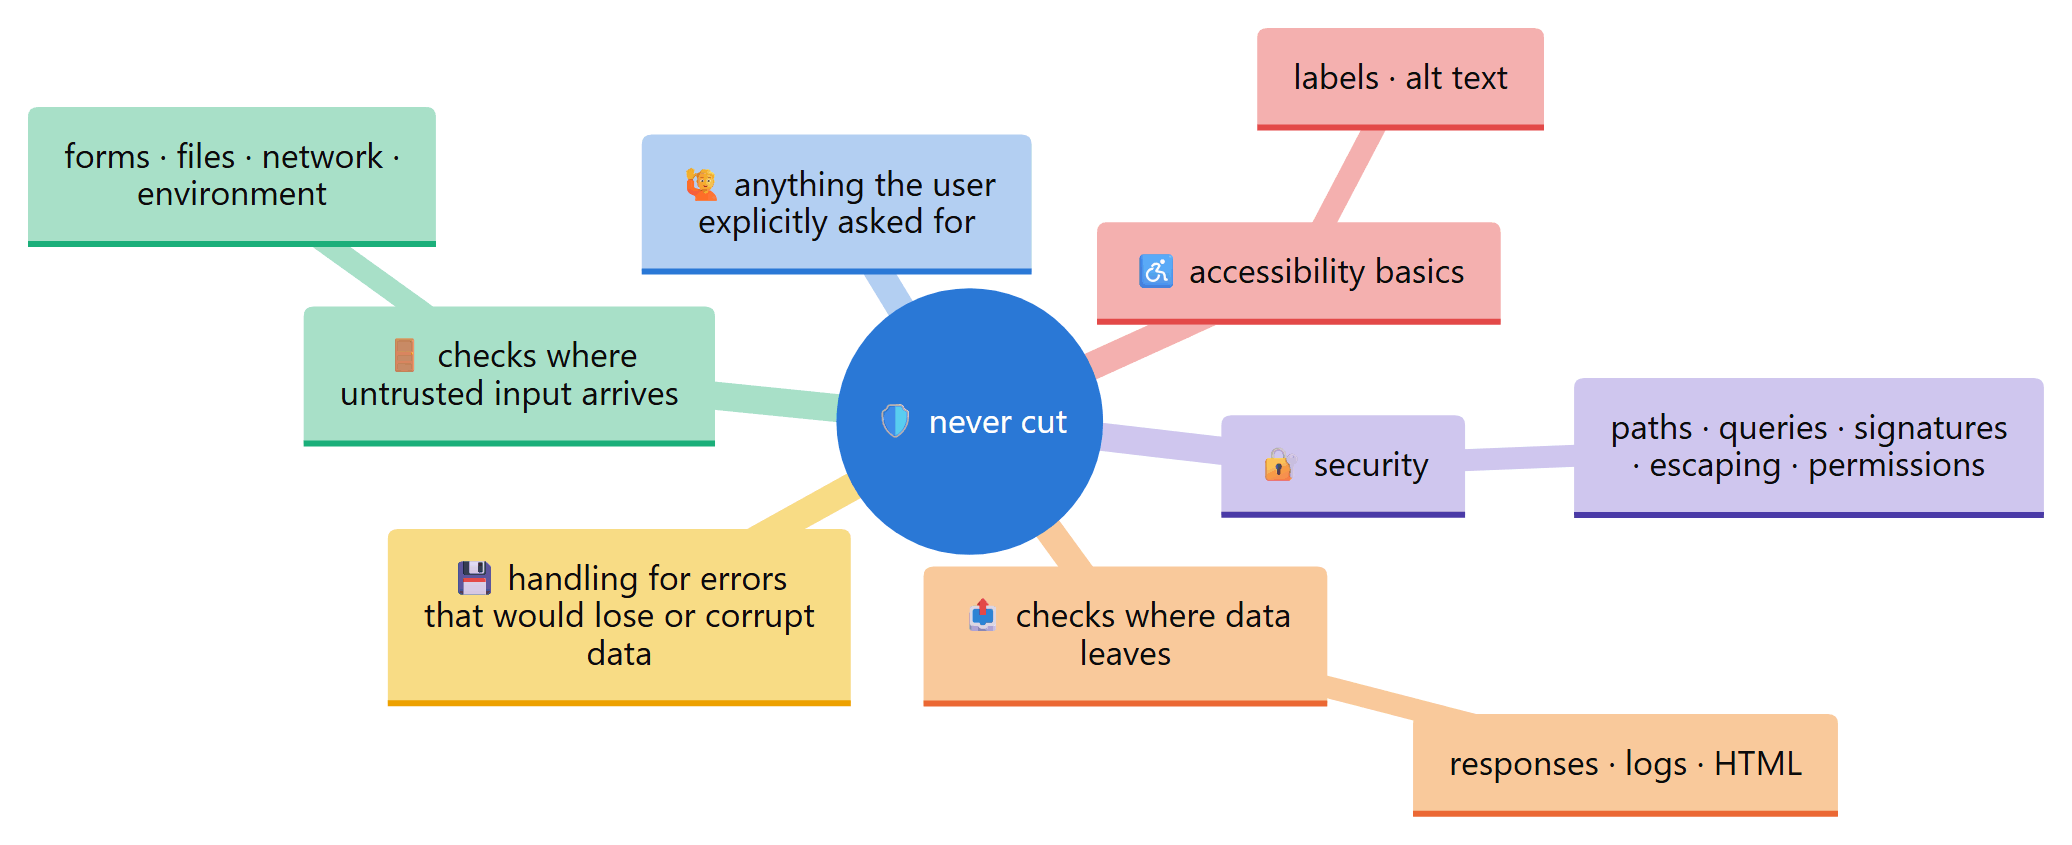

In [486]:
t = SUITE["sf-feedback-body"]                               # a safety task whose ticket never mentions the guard it needs
# the full level with its never-cut section removed, against the full level as written
eps = run_arms(t, {"rules-no-never-cut": ruleset("full", drop=("Never cut",)), "rules": ruleset("full")})
DEMOS["S28 never cut"] = compare(t, eps)                    # the card, kept for the figure
for arm, ep in eps.items():                                 # then the guards each arm's code carries
    final = snapshot(ep.ws)                                 # the files as the episode left them
    found = guard_signatures(final.get(t.entry, ""))        # Part I's guard patterns, in the ticket's own file
    print(f"\n  [{arm}] guard signatures in {t.entry}: {found or 'none'}")

  arm                 verdicts  code  prose  check  new files  guards  shapes  leans on  claimed  turns
  -----------------------------------------------------------------------------------------------------
  rules-no-never-cut  c1 s1       18      0     25          0      10  -       stdlib    -           10
  rules               c1 s1       14      0     24          0       9  -       stdlib    -           11

  [rules-no-never-cut] answer: Implemented `parse_feedback` in feedback/api.py: parses the JSON body, requires an object with an integer `rating` in 1-5 (rejecting bools, floats, and strings) and an optional string `comment` defaulting to `''`, raising `ValueError` [...]
    --- seed/feedback/api.py
    +++ rules-no-never-cut/feedback/api.py
    @@ -0,0 +1,3 @@
    +import json
    +
    +
    @@ -3 +6,44 @@
    -    raise NotImplementedError
    +    try:
    +        data = json.loads(raw_body)
    +    except (TypeError, json.JSONDecodeError) as exc:
    +        raise Valu

## S29 - How to answer

**Theory.** Over-building is not only code. An agent that writes twelve lines and a three-paragraph essay about why it wrote twelve lines has produced more for someone to read, and the essay is often where the hedging and the second-guessing live. The output contract is short: code first, then at most three short lines, and for each thing deliberately not built, a line in a fixed format, `left out: <what> (build it when <condition>)`. The format matters more than it seems. A deferral with a condition is a decision someone can act on later; a vague "could be extended" is not. The contract also asks the agent to state the step it stopped at, which S25 checks against the diff. Two exceptions keep the contract from cutting the wrong prose: an explanation the user asked for is given in full, and the agent does not stop to ask a question it can answer with a sensible default (it builds the default and says which one it picked), because a question costs the user a round trip.

**In plain terms.** Show the code, then say in three lines what you did and what you left out, and when the leftover should be built.

**`check_contract(text)`** measures a final message against the output contract: its non-blank lines and words, whether it stays within three lines, how many well-formed `left out:` lines it carries, how many lines try to defer something without the required `(build it when ...)` condition, and which step it claims. The pattern `LEFT_OUT` is strict on purpose. A deferral is only useful with its condition, so a line that leaves the condition out is counted as malformed rather than quietly accepted.

In [487]:
# "left out: <what> (build it when <condition>)", then at most a full stop
LEFT_OUT = re.compile(r"^\s*left out:\s*(.+?)\s*\(build it when\s+(.+?)\)\s*\.?\s*$", re.I)

def check_contract(text):
    """How a final message measures against the contract."""
    lines = [l for l in (text or "").splitlines() if l.strip()]   # non-blank lines; a missing answer has none
    left = []                                               # well-formed deferrals, as (what, when)
    for line in lines:                                      # each line, tried against the strict pattern
        m = LEFT_OUT.match(line)                            # None unless the whole line is a deferral
        if m:                                               # both parts are there: what, and when to build it
            left.append(m.groups())                         # (what was left out, when to build it)
    # lines that start like a deferral but miss the format, usually the "(build it when ...)" part
    loose = [l for l in lines if l.strip().lower().startswith("left out") and not LEFT_OUT.match(l)]
    return {"lines": len(lines),
            "words": len((text or "").split()),
            "within": len(lines) <= 3,                      # the contract allows three short lines
            "left_out": len(left),                          # deferrals someone can act on later
            "malformed": len(loose),                        # deferrals without a condition
            "step": claimed_step(text)}                     # compare() checks this claim against the diff

show_def(check_contract, layer="plugin")

[def] check_contract(text)  15 lines, complexity 8


In [488]:
samples = {   # one message that keeps the contract, and two that break it in the usual ways
    "contract kept": "step 3: functools.cache on lookup_district.\nleft out: cache clearing (build it when the register changes)",
    "a deferral without a condition": "Added a cache.\nleft out: eviction, could be added later",
    "an essay": "I considered several approaches.\n" * 6 + "In the end I added a cache.",
}
# one row per sample message, with every measure check_contract returns
table([{"message": k, **check_contract(v)} for k, v in samples.items()],
      [("message", "message", ""), ("lines", "lines", "d"), ("within", "within 3 lines", ""), ("left_out", "left out", "d"),
       ("malformed", "malformed", "d"), ("step", "step", "")])

  message                         lines  within 3 lines  left out  malformed  step
  --------------------------------------------------------------------------------
  contract kept                       2            True         1          0     3
  a deferral without a condition      2            True         0          1     -
  an essay                            7           False         0          0     -


The same measure over every final message the cards above produced, and over the 34 unguided answers from S23 for scale.

In [489]:
# one row per card episode: the contract's measures, and how much prose the agent wrote along the way
rows = [{"arm": ep.arm, "task": ep.task,
         **check_contract(ep.done_text),                    # lines, words, within, left_out, malformed, step
         "notes": sum(t.notes_chars for t in ep.turns)}    # prose the agent wrote between its actions
        for ep in PART4_EPISODES]
print("\n  every final message from this Part's cards so far:")
# the contract limits the final message, not the notes, so the notes column is there for scale
table(rows, [("arm", "arm", ""), ("task", "task", ""), ("words", "words", "d"), ("lines", "lines", "d"),
             ("within", "within 3 lines", ""), ("left_out", "left out", "d"), ("step", "step", ""),
             ("notes", "notes chars", "d")])


  every final message from this Part's cards so far:
  arm                 task               words  lines  within 3 lines  left out  step  notes chars
  ------------------------------------------------------------------------------------------------
  off                 ob-postcode-cache    100      4           False         0     -          301
  rules               ob-postcode-cache     73      1            True         0     -          312
  rules-no-read       rc-day-parse          46      1            True         0     -          330
  rules               rc-day-parse          45      1            True         0     -          833
  off                 ob-report-flags      119      4           False         0     -          841
  rules               ob-report-flags       85      5           False         0     -          778
  rules-no-never-cut  sf-feedback-body      76      1            True         0     -           17
  rules               sf-feedback-body      70      1  

In [490]:
base = [check_contract(ep.done_text) for ep in BASELINE.values()]   # the unguided answers from S23
# the median length, how many kept to three lines, and how many deferrals they wrote without being asked
print(f"\n  for scale, the 34 baseline answers from S23: median {np.median([c['words'] for c in base]):.0f} words, "
      f"{sum(c['within'] for c in base)}/{len(base)} within three lines, {sum(c['left_out'] for c in base)} 'left out' lines")
save_exp("contract", {"baseline_median_words": float(np.median([c["words"] for c in base])),   # a plain float for JSON
                      "baseline_within": sum(c["within"] for c in base),     # baseline answers within three lines
                      "baseline_n": len(base),                               # how many baseline answers there are
                      # this Part's card answers, the fields the prose quotes
                      "cards": [{k: r[k] for k in ("arm", "task", "words", "within", "left_out")} for r in rows]})


  for scale, the 34 baseline answers from S23: median 74 words, 23/34 within three lines, 0 'left out' lines
[exp] artifacts/exp_contract.json


## S30 - Shortcuts, marked where they live

**Theory.** Permission to build less is only safe if the limits of what was built are visible. A shortcut marker is one comment on the line where the limit lives, naming the limit and the condition for upgrading: `# shortcut: unbounded cache; upgrade when memory matters`. It turns a hidden assumption into a searchable fact, it tells a reviewer that the simple version is a choice rather than an oversight, and it is what Part VI's debt skill collects into a ledger. The rule is restricted to *real* limits on purpose: a marker on every simplification is noise, and noise teaches reviewers to ignore markers.

**In plain terms.** When the agent knowingly cuts a corner, it leaves a note saying where the corner is and when to come back.

**`find_markers(files)`** lists every shortcut marker in a set of files, well formed or not. Two patterns do the work: `ANY_MARKER` finds anything that looks like a marker, and `MARKER` checks the full form, a limit and an upgrade condition. Keeping the loose search separate is what lets a malformed marker show up as malformed instead of disappearing; Part VI's debt ledger lists them all and flags the ones with no condition.

In [491]:
MARKER = re.compile(r"#\s*shortcut:\s*(.+?);\s*upgrade when\s+(.+?)\s*$", re.I)   # the full form, any letter case
ANY_MARKER = re.compile(r"#\s*shortcut\b", re.I)           # anything that tries to be a marker

def find_markers(files):
    """Every shortcut marker in {path: text}, well formed or not."""
    out = []                                                # one entry per marker found
    for path, text in files.items():                        # every file given, by path
        for n, line in enumerate(text.splitlines(), 1):     # numbered from 1, as an editor shows them
            if ANY_MARKER.search(line):                     # something on this line tries to be a marker
                m = MARKER.search(line)                     # None when the limit or the condition is missing
                out.append({"file": path, "line": n,        # where the marker lives
                            "limit": m.group(1) if m else None,
                            "when": m.group(2) if m else None,
                            "well_formed": bool(m)})
    return out

show_def(find_markers, layer="plugin")

[def] find_markers(files)  12 lines, complexity 6


In [492]:
demo_files = {"geo.py": "@cache  # shortcut: unbounded cache; upgrade when memory matters\n"   # well formed
                        "def lookup(code): ...\n"                                              # no marker here
                        "# shortcut: global lock\n"                                            # no upgrade condition
                        "LOCK = threading.Lock()  # SHORTCUT: one lock for all accounts; Upgrade when two accounts contend\n"}
# the capitals on the last line still count: both patterns ignore letter case
table(find_markers(demo_files), [("file", "file", ""), ("line", "line", "d"), ("limit", "limit", ""), ("when", "upgrade when", ""),
                                 ("well_formed", "well formed", "")])

  file    line  limit                      upgrade when          well formed
  --------------------------------------------------------------------------
  geo.py     1  unbounded cache            memory matters               True
  geo.py     3  -                          -                           False
  geo.py     4  one lock for all accounts  two accounts contend         True


## S31 - Prove it: one runnable check

**Theory.** Less code is only an improvement if it still works, and the cheapest way to keep that promise is one runnable check that fails when the code is wrong. "One" is doing as much work as "check". An agent told to test tends to produce a test suite, with fixtures, a framework and a test per function, which is a feature nobody asked for and more code to maintain than the change itself. The rule asks for a few asserts under `if __name__ == "__main__":` or one small test file, and Part I's meter already treats both as *check* lines rather than code, so writing the check is never punished as bloat. Part VII measures whether the checks agents write actually catch bugs, by running the same mutation testing as S8b against them.

**In plain terms.** Leave one small test that would fail if the code were wrong. A test suite is a separate job.

In [493]:
# a cached lookup with its check: three asserts under the main guard
check_example = textwrap.dedent('''
    from functools import cache

    @cache
    def lookup_district(postcode):
        return register.scan(normalise(postcode))

    if __name__ == "__main__":
        assert lookup_district("SW1A 1AA") == "Westminster"
        assert lookup_district("ZZ9 9ZZ") is None
        print("ok")
''')
m = measure_source(check_example, "geo.py")                 # Part I's meter, on a change that carries its check
print(f"[meter] a change with its check: {m['code']} code lines, {m['check']} check lines; the check is not counted as code")

[meter] a change with its check: 4 code lines, 4 check lines; the check is not counted as code


In [494]:
# what each card's arms wrote as checks, beside the code they added
for card, rows in DEMOS.items():                            # every card so far
    for r in rows:                                          # every arm of that card
        print(f"  {card:<20} {r['arm']:<20} check lines {r['check']:>3}   code lines {r['added']:>3}")

  S25 the ladder       off                  check lines   0   code lines   7
  S25 the ladder       rules                check lines   7   code lines   5
  S26 read first       rules-no-read        check lines   2   code lines   2
  S26 read first       rules                check lines   1   code lines   2
  S27 how to build     off                  check lines   0   code lines  42
  S27 how to build     rules                check lines  17   code lines  20
  S28 never cut        rules-no-never-cut   check lines  25   code lines  18
  S28 never cut        rules                check lines  24   code lines  14


## S32 - The scope of the rules, and how long they last

**Theory.** Two sentences close the ruleset, and both are boundaries. The first says how long the rules last: *every reply in this session that touches code, until the user switches them off*. Models drift back to their habits as a conversation grows, and a rule that does not say it persists is quietly treated as a one-off. Part V reinforces this mechanically, with a one-line header on every prompt and a re-injection after compaction, and Part VII measures the drift with and without those mechanisms. The second sentence fences the scope: *they are about the code you produce, not your tone*. Without it, a model that has been told to be brief becomes curt with the user, truncates explanations it was asked for, and treats a question about code as an invitation to write some. Together with the explanation exemption in "How to answer", it is what lets the ruleset sit in every session without spoiling the ones that are not about building anything.

**In plain terms.** The rules last the whole session, and they cover the code, not the conversation.

In [495]:
t = SUITE["ob-postcode-cache"]                              # the project the question is about
# a question about the code, not a ticket; with a prompt given, run_arms keeps these out of PART4_EPISODES
question = ("Explain, in detail, how lookup_district in geo.py finds a district, step by step. "
            "Do not change any code; this is a question.")
eps = run_arms(t, {"off-explain": None, "rules-explain": ruleset("full")}, prompt=question)   # no rules, then full
for arm, ep in eps.items():                                 # each arm's answer to the question
    edits = sum(t_.action == "edit" for t_ in ep.turns)    # edits made while answering a question
    c = check_contract(ep.done_text)                        # its length in words and lines
    print(f"[{arm}] {c['words']} words in {c['lines']} lines, {edits} edits; first lines:")
    for line in plain(ep.done_text).splitlines()[:4]:       # the start of the answer is enough to judge its shape
        print("    " + line[:110])

[off-explain] 344 words in 16 lines, 0 edits; first lines:
    Explanation only; no code was changed. Here is how `lookup_district` works, step by step, based on geo.py, reg
    
    1. **Entry point (geo.py, line 9):** `lookup_district(postcode)` is called with a raw postcode string, e.g. `'
    
[rules-explain] 66 words in 1 lines, 0 edits; first lines:
    No code changed - explained lookup_district in geo.py: it normalises the postcode (strip all spaces, uppercase


In [496]:
EXPLAIN = {}                                                # arm: how long its answer was, and how many edits it made
for arm, ep in eps.items():                                 # the two arms of the question above
    # the answer's length in words, and any edits made while answering a question
    EXPLAIN[arm] = {"words": check_contract(ep.done_text)["words"], "edits": sum(x.action == "edit" for x in ep.turns)}
# the exemption holds if the answer under the rules is at least half as long as the one without them
if EXPLAIN["rules-explain"]["words"] >= 0.5 * EXPLAIN["off-explain"]["words"]:
    EXPLAIN["verdict"] = "IN FULL"                          # the explanation survived the three-line limit
else:
    EXPLAIN["verdict"] = "CUT SHORT"                        # the limit won, and the rule needs rewording
print(f"\n  the requested explanation, with the rules: {EXPLAIN['verdict']}")
save_exp("explain", EXPLAIN)                                # the prose below quotes these numbers


  the requested explanation, with the rules: CUT SHORT
[exp] artifacts/exp_explain.json


Asked for a step-by-step explanation, the agent without the rules answered in 344 words and the agent with them in 66, with 0 edits made where none were asked for. The exemption still loses to the limit: the explanation that was asked for came back cut short, and the wording of "How to answer" needs another revision before this rule can be trusted. This is the sentence whose first wording failed (S85, bug 5), measured again after the rewrite.

## S33 - Three levels, side by side

**Theory.** The three levels are the user's way of choosing how hard the system pushes. They are not three personalities: they share every core line, every invariant and the whole never-cut list, and they differ only in how the build decision is made (lite builds first and comments afterwards, full climbs the ladder, ultra starts from deletion). The widget below shows any level next to full; the static print above it shows exactly which lines differ, so the comparison survives in a notebook viewer that cannot run widgets. Part VII measures the dose-response across all 34 tasks (H6), including the cost we expect ultra to pay in completeness.

**In plain terms.** Lite, full and ultra share their safety rules and differ only in how much they push to build less.

**Three strengths of the same rules.** Lite changes what the agent says after the code, full changes what it builds, and ultra changes what it is willing to keep. S67 measures what each one costs and saves.

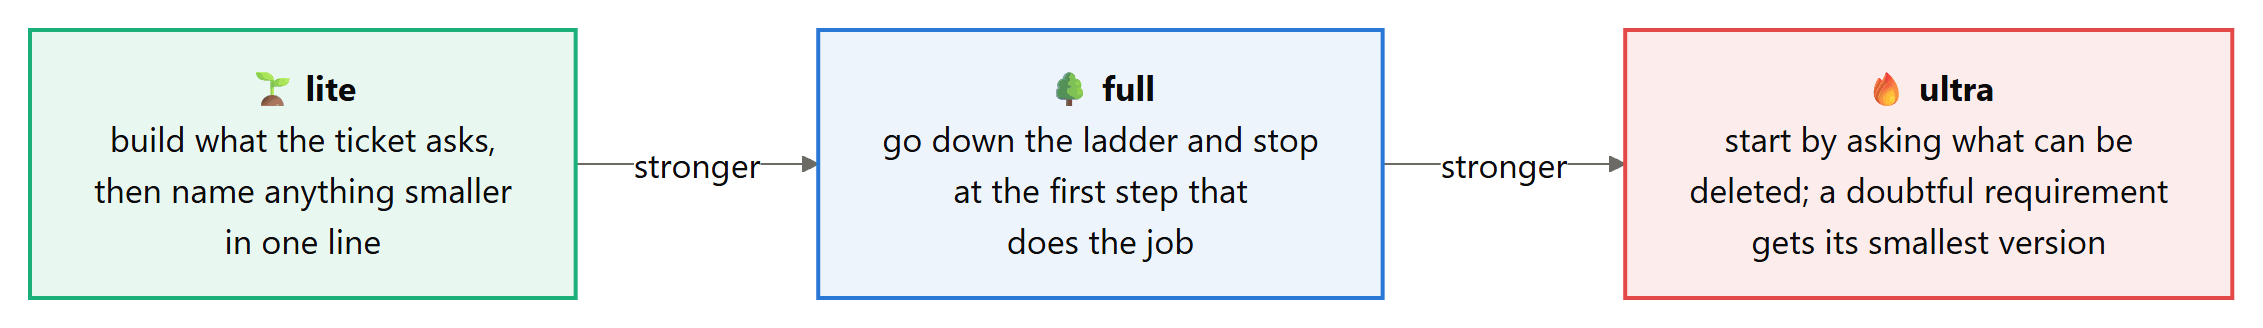

In [497]:
full_lines = set(ruleset("full").splitlines())              # the full level, as a set of lines
for level in ("lite", "ultra"):                             # each level against full
    lines = set(ruleset(level).splitlines())                # this level's lines
    print(f"[{level} vs full] only in {level}:")
    for line in sorted(lines - full_lines - {""}):          # a blank line is not a difference worth printing
        print(f"    + {line}")
    if level == "lite":                                     # lite also lacks lines that full has: count them
        print(f"  only in full: {len(full_lines - lines - {''})} lines (the ladder and the build rules)")
    else:                                                   # ultra keeps every line of full
        print("  everything else is shared")

[lite vs full] only in lite:
    + ## What to build
    + Build what the ticket asks for, completely. After the code, if something smaller would have done, name it in one line.
  only in full: 24 lines (the ladder and the build rules)
[ultra vs full] only in ultra:
    + Start by asking what can be deleted. Meet a requirement you doubt by building its smallest version and naming what you left out, in the same reply.
  everything else is shared


In [498]:
W = widgets()                                               # None in a headless run: the comparison above then stands alone
if W:
    from IPython.display import display                     # only needed when there is a widget to show
    pick = W.ToggleButtons(options=LEVELS, value="full", description="level")   # one button per level
    # a scrolling box for the chosen level's text
    out = W.Output(layout={"border": "1px solid #e6e5e1", "max_height": "320px", "overflow": "auto"})

    def _show(change=None):
        out.clear_output()                                  # one level at a time
        with out:                                           # print into the box, not under the cell
            text = ruleset(pick.value)                      # the chosen level, exactly as a model reads it
            print(f"{pick.value}: about {tokens_of(text)} tokens\n")
            print(text)

    pick.observe(_show, names="value")                      # redraw whenever another level is picked
    _show()                                                 # and draw the starting level once
    display(W.VBox([pick, out]))                            # the buttons above the box
else:
    print("(no widget in this run, which needs a live Jupyter session; the static comparison above is the whole story)")

(no widget in this run, which needs a live Jupyter session; the static comparison above is the whole story)


In [499]:
t = SUITE["ob-postcode-cache"]                              # the ladder's ticket again, so the levels line up with S25
# the three levels side by side; the full arm repeats S25's run, so the ledger answers it
eps = run_arms(t, {"rules-lite": ruleset("lite"), "rules": ruleset("full"), "rules-ultra": ruleset("ultra")})
DEMOS["S33 three levels"] = compare(t, eps, diff_lines=8)   # three diffs, so a shorter excerpt of each

  arm          verdicts  code  prose  check  new files  guards  shapes  leans on         claimed  turns
  -----------------------------------------------------------------------------------------------------
  rules-lite   c1           5      3      6          0       0  -       project          -           14
  rules        c1           5      1      7          0       0  -       project, stdlib  -           13
  rules-ultra  c1           8      2      7          0       0  -       project          -           17

  [rules-lite] answer: Added a memo cache to lookup_district in geo.py (keyed by normalised postcode, caches None as well); register.py unchanged; extended tests_visible.py with a check that repeated lookups perform zero register scans.
    --- seed/geo.py
    +++ rules-lite/geo.py
    @@ -1,0 +2,4 @@
    +
    +# Memo of normalised postcode -> district (None for codes the register does not know).
    +# The register is static, so results never go stale.
    +_CACHE = {}
   

## S34 - Copies that cannot drift

**Theory.** The ruleset reaches the model through several copies: three levels, a compact copy for subagents and the critic (core lines only), and a one-line header that Part V adds to every prompt. Hand-maintained copies drift: someone edits the long version, forgets the short one, and the safety rule that was reworded in one place is missing from the other. Ours cannot drift for a simple reason: every copy is *generated* by filtering the single source, so there is nothing to keep in sync by hand. What can still go wrong is the filter, which is why `drift_check` verifies every copy against the list of invariant phrases, word for word, and the test below plants a hand-edited copy to show the check catching it.

**In plain terms.** Every version of the rules is cut from the same text by a program, and a checker makes sure each one still carries the safety rules.

**For teams.** If the rules live in more than one place (a project file, a CI prompt, a review bot), generate every copy from one source and run a drift check like this one in CI. Hand-edited copies diverge within weeks, and the line that goes missing is rarely the one anybody would choose to lose.

**`copies()`** returns every copy of the ruleset the plugin uses, each one generated from `RULESET_SOURCE` on the spot: the three levels and the compact copy. Because nothing is stored, there is nothing to keep in sync; what remains to check is the generator, which is what `drift_check` is for.

In [500]:
def copies():
    """Every copy of the ruleset the plugin uses, all generated from RULESET_SOURCE."""
    out = {level: ruleset(level) for level in LEVELS}       # lite, full and ultra
    out["compact"] = ruleset("full", core_only=True)        # the core lines, for subagents and the critic
    return out

show_def(copies, layer="plugin")

[def] copies()  5 lines, complexity 2


In [501]:
for copy_name, copy_text in copies().items():               # every copy the plugin can send, and its cost
    print(f"  {copy_name:<8} about {tokens_of(copy_text)} tokens")

  lite     about 515 tokens
  full     about 986 tokens
  ultra    about 1023 tokens
  compact  about 481 tokens


**`drift_check(texts)`** compares each copy with the list of invariant phrases and reports, for every copy that has lost one, exactly which phrases are missing; a clean set of copies gives an empty result. The comparison is word for word on purpose. A reworded safety rule is the drift that matters, and a check that accepted near matches would miss it.

In [502]:
def drift_check(texts):
    """{copy: [invariant phrases it lacks]} for every copy that lacks one."""
    out = {}                                                # copy name: the phrases it lost
    for name, text in texts.items():                        # every copy handed in, generated or not
        missing = [p for p in INVARIANTS if p not in text]  # phrases this copy no longer carries word for word
        if missing:                                         # a clean copy is left out, so {} means all clean
            out[name] = missing
    return out

show_def(drift_check, layer="plugin")

[def] drift_check(texts)  8 lines, complexity 4


In [503]:
results = []                                                # expect() records each check here
expect("every generated copy carries every invariant", drift_check(copies()) == {})   # {} means nothing is missing
# a hand-edited copy, the way drift really happens: one safety line reworded into something vaguer
hand_edited = ruleset("full").replace("handling for errors that would lose or corrupt data", "error handling where it matters")
caught = drift_check({**copies(), "hand-edited full": hand_edited})   # the generated copies plus the planted one
expect("a hand-edited copy that rewords a safety rule is caught", list(caught) == ["hand-edited full"])   # and only it
print(f"  the planted copy lacks: {caught.get('hand-edited full')}")
save_exp("drift", {"copies": len(copies()), "clean": drift_check(copies()) == {}})   # for Part VII's summary

  PASSED  every generated copy carries every invariant
  PASSED  a hand-edited copy that rewords a safety rule is caught
  the planted copy lacks: ['handling for errors that would lose or corrupt data']
[exp] artifacts/exp_drift.json


## S35 - The router: does a skill's description decide when it applies?

**Theory.** The ruleset should govern requests that produce code and stay out of the way of everything else: "what does a decorator do?" does not need a ladder. The plugin decides with a **router**: the fast model reads a skill's one-line description and the user's request, and answers yes or no. That makes the description the whole of the routing logic, so it has to be written as a *trigger* ("use for every request that writes, changes, fixes or removes code, however small; do not use for questions, explanations or writing that is not code") rather than as a summary of what the skill contains ("keeps code simple and lean"). The difference is measured here on 40 labelled requests, half of which ask for code. A few are deliberately close calls, such as explaining a piece of code (no code is produced) and writing a test (code is produced). Recall matters more than precision for this skill: a missed coding request runs without the rules, while a false alarm only adds a ruleset to a conversation that ignores it.

**In plain terms.** A one-line description decides when the rules switch on, so we test two wordings against forty requests and count the mistakes.

The test set: twenty requests that ask for code and twenty that do not, with a few close calls on each side.

In [504]:
# (request, does it ask for code?): the first twenty do, the second twenty do not
ROUTER_SET = [(r, True) for r in (
    "Add a --verbose flag to the command-line tool.", "Fix the off-by-one error in paginate().",
    "Rename get_user to fetch_user everywhere.", "Write a function that parses ISO dates from the log lines.",
    "The import job crashes on empty rows; make it skip them.", "Cache the exchange-rate lookups.",
    "Add a unique constraint so emails cannot repeat.", "Remove the duplicated retry code from the payment module.",
    "Make the search endpoint return results sorted by date.", "Add type hints to utils.py.",
    "Delete the unused legacy exporter.", "Write a test for the discount calculation.",
    "Port this script from Python 2 to Python 3.", "Implement CSV export for the orders table.",
    "Validate the uploaded file name before saving it.", "The report reads the same file five times; make it read it once.",
    "Change the default timeout from 5 to 30 seconds.", "Log a warning when a retry happens.",
    "Make the config loader accept a missing file.", "Split the 900-line views.py into smaller modules.")] + \
    [(r, False) for r in (
    "What does a Python decorator do?", "Explain how this caching code works.", "Write a haiku about debugging.",
    "Summarise this meeting transcript.", "Which is faster in Python, a list or a tuple, and why?",
    "Draft an email to the team about the release.", "Translate this paragraph into French.",
    "What is the difference between TCP and UDP?", "Review this pull request description for clarity.",
    "How do I pronounce 'nginx'?", "Give me three names for a new coffee shop.", "What time zone is Auckland in?",
    "Explain the CAP theorem simply.", "Write a cover letter for a junior developer job.",
    "What are the trade-offs of microservices?", "Proofread the introduction of my README.",
    "Plan a two-week study schedule for learning SQL.", "Is it 'licence' or 'license' in British English?",
    "Tell me a joke about recursion.", "Compare Rust and Go for a beginner.")]
# the labels are what the router is scored against
print(f"[router] {len(ROUTER_SET)} labelled requests, {sum(want for _, want in ROUTER_SET)} of them asking for code")

[router] 40 labelled requests, 20 of them asking for code


The two wordings under test, and the router's system message, into which one wording at a time is placed.

In [505]:
# "trigger" says when the skill applies and when it does not; "summary" says what the skill contains
DESCRIPTIONS = {
    "trigger": "Use for every request that writes, changes, fixes or removes code, however small. "
               "Do not use for questions, explanations or writing that is not code.",
    "summary": "Keeps code simple and lean.",
}
ROUTER_SYSTEM = ("You decide whether a skill applies to a request. Answer with exactly one word, yes or no.\n\n"
                 "The skill: {description}")
print(ROUTER_SYSTEM.format(description=DESCRIPTIONS["trigger"]))   # the system message as the router reads it

You decide whether a skill applies to a request. Answer with exactly one word, yes or no.

The skill: Use for every request that writes, changes, fixes or removes code, however small. Do not use for questions, explanations or writing that is not code.


**`route(request, description, model)`** asks the fast model whether a skill applies to a request, with the skill's one-line description placed in the router's system message, and reads the first word of the reply as yes or no. The call is made as cheap and as repeatable as possible: temperature zero, eight tokens at most, and thinking switched off on every model the S12 probe found to accept that switch, since a yes or no gains nothing from reasoning.

In [506]:
def route(request, description, model=None):
    """True if the router thinks the skill applies to the request."""
    model = model or MODEL_FOR["fast"]                      # routing runs on every prompt, so it uses the cheap model
    extra = {}                                              # parameters only some models accept
    if "thinking off" in CAN.get(model, ()):                # S12 found which models accept the switch
        extra = {"enable_thinking": False}                  # a one-word answer needs no reasoning
    # one system message with the description in it, then the request; one word back, the same word every time
    r = FRONT_DOOR.chat(model, [{"role": "system", "content": ROUTER_SYSTEM.format(description=description)},
                                {"role": "user", "content": request}], tag="router", temperature=0.0, max_tokens=8, **extra)
    return r.text.strip().lower().startswith("yes")         # "Yes.", "yes" and "YES" all count

show_def(route, layer="plugin")

[def] route(request, description, model=None)  9 lines, complexity 3


**`_scripted_router(model, messages, params)`** answers router requests in smoke runs, where no model is called. Under the summary wording it says yes to every request; under the trigger wording it says yes exactly when the request opens with one of the coding verbs from the test set. That keeps a smoke run's table fixed from run to run, while the live numbers come from the real router. It returns `None` for any other request, so the scripted model passes it on to the next responder.

In [507]:
@SCRIPTED.register
def _scripted_router(model, messages, params):
    if not messages[0]["content"].startswith("You decide whether a skill applies"):   # not a router request
        return None
    if "simple and lean" in messages[0]["content"]:          # the summary wording
        return "yes"
    # the openings of the twenty coding requests; none of the other twenty starts with one of them
    verbs = ("add", "fix", "rename", "write a function", "make", "cache", "remove", "delete", "port", "implement",
             "validate", "change", "log", "split", "write a test", "the import", "the report")
    if messages[-1]["content"].lower().startswith(verbs):   # the request, in lower case, opens with one of them
        return "yes"
    return "no"

show_def(_scripted_router, layer="lab")

[def] _scripted_router(model, messages, params)  11 lines, complexity 4


Every request under both wordings, eighty questions in all, asked in parallel:

In [508]:
jobs = [(req, want, name) for name in DESCRIPTIONS for req, want in ROUTER_SET]   # every request under both wordings
with ThreadPoolExecutor(WORKERS) as pool:                   # the questions are independent, so they run at once
    # a job is (request, wanted answer, wording name): ask the request under that wording
    said = list(pool.map(lambda j: route(j[0], DESCRIPTIONS[j[2]]), jobs))
print(f"[router] {len(jobs)} questions asked, {sum(said)} answered yes")

[router] 80 questions asked, 36 answered yes


In [509]:
ROUTER = {}                                                 # wording name: its scores
for name in DESCRIPTIONS:                                   # trigger, then summary
    pairs = [(want, s) for (req, want, n), s in zip(jobs, said) if n == name]   # (wanted, said) for this wording
    tp = sum(w and s for w, s in pairs)                     # coding requests it said yes to
    fp = sum(not w and s for w, s in pairs)                 # false alarms: yes to a request that is not code
    fn = sum(w and not s for w, s in pairs)                 # misses: no to a request that is code
    ROUTER[name] = {"precision": tp / (tp + fp) if tp + fp else 0.0,   # of its yes answers, the share that wanted code
                    "recall": tp / (tp + fn) if tp + fn else 0.0,      # of the coding requests, the share it caught
                    "false alarms": fp, "missed": fn}       # the two kinds of mistake, as counts
# recall is the column that matters most for this skill: a miss runs a coding request without the rules
table([{"description": n, **v} for n, v in ROUTER.items()],
      [("description", "description", ""), ("precision", "precision", ".2f"), ("recall", "recall", ".2f"),
       ("false alarms", "false alarms", "d"), ("missed", "missed coding requests", "d")])

  description  precision  recall  false alarms  missed coding requests
  --------------------------------------------------------------------
  trigger           1.00    1.00             0                       0
  summary           0.94    0.75             1                       5


In [510]:
# the requests the trigger wording got wrong, with the answer each one wanted
wrong = [(req, want) for (req, want, n), s in zip(jobs, said) if n == "trigger" and s != want]
print(f"\n  the trigger wording's mistakes: {wrong or 'none'}")
save_exp("router", ROUTER)                                  # the prose under the figure quotes these scores


  the trigger wording's mistakes: none


[exp] artifacts/exp_router.json


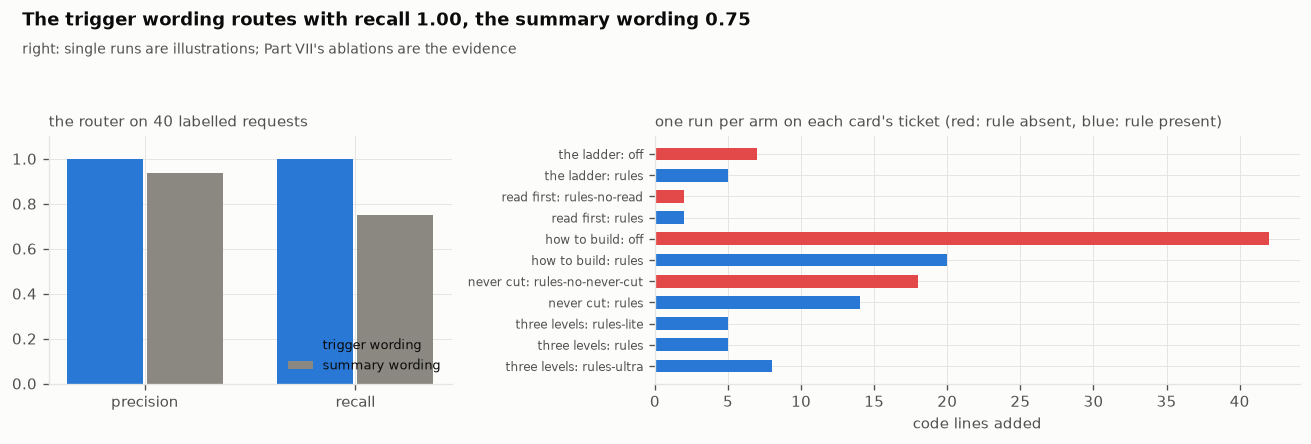

[fig 13] s35_router_cards.png


In [511]:
# FIG  the router, and every live card of this Part on one page
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})   # the cards get the wider panel
ax = axes[0]                                                # left: the router test
x = np.arange(2)                                            # two groups of bars: precision, then recall
for i, name in enumerate(DESCRIPTIONS):                     # one colour per wording
    # one bar per wording in each group, side by side
    ax.bar(x + (i - 0.5) * 0.38, [ROUTER[name]["precision"], ROUTER[name]["recall"]], 0.36,
           color=(C1, MUTED)[i], label=f"{name} wording")
ax.set_xticks(x, ["precision", "recall"])                   # name the two groups
ax.set_ylim(0, 1.1)                                         # room above a perfect score for the bars to breathe
ax.legend(loc="lower right", fontsize=7.5)                  # bottom right, clear of the bar tops
panel(ax, "the router on 40 labelled requests")             # the caption, top left
ax = axes[1]                                                # right: one bar per arm of every card
labels = []                                                 # "the ladder: off" and so on, without the section number
added = []                                                  # the code lines each of those arms added
for card, rows in DEMOS.items():                            # every card, in the order it ran
    for r in rows:                                          # every arm of that card
        labels.append(f"{card.split(' ', 1)[1]}: {r['arm']}")   # drop the "S25 " prefix
        added.append(r["added"])                            # the bar's length
y = np.arange(len(labels))                                  # one row per arm
# red where the arm lacks the rule the card is about (off, or rules-no-...), blue where it has it
ax.barh(y, added, 0.6, color=[C8 if "off" in l or "no-" in l else C1 for l in labels])
ax.set_yticks(y, labels, fontsize=7)                        # small type: one label per arm of every card
ax.invert_yaxis()                                           # cards from top to bottom, in the order they ran
ax.set_xlabel("code lines added")                           # Part I's meter: comments and docstrings not counted
panel(ax, "one run per arm on each card's ticket (red: rule absent, blue: rule present)")
# the title states the finding; the subtitle says how much weight single runs can bear
finish(fig, "s35_router_cards", f"The trigger wording routes with recall {ROUTER['trigger']['recall']:.2f}, "
       f"the summary wording {ROUTER['summary']['recall']:.2f}",
       "right: single runs are illustrations; Part VII's ablations are the evidence")

**Reading FIG 13 (s35_router_cards).** The left panel is the router test. The trigger wording, which says when to apply the skill and when not to, scored a precision of 1.00 and a recall of 1.00; the summary wording, which describes what the skill contains, scored 0.94 and 0.75. The right panel collects every live card of this Part: each bar is one run of one ticket under one arm, red where the rule being demonstrated was absent and blue where it was present. This is what single runs look like: some cards show the expected difference, others show none, because one sample of a stochastic model proves little. That is why every rule faces the ablation ledger in Part VII before it is kept.

**Part IV recap.** The plugin now has its words: a ruleset of about seven hundred tokens, generated at three levels from one source that cannot drift, in which every push towards less code is paired with the guard that stops it going too far. The ladder gives the model a procedure with a stopping point instead of a value; reading first and fixing the cause are framed so that the guard is also the cheaper option; five things are never cut; one check proves the code; shortcuts are marked; answers are short except where an explanation was asked for. Every claim the agent makes about its own work (the step it stopped at, what it left out, its shortcuts) can be checked against its diff. Part V delivers these words reliably, every session, every prompt, every subagent.

**Try it yourself.**
1. Add a rule to `RULESET_SOURCE`, for example "prefer pure functions", and run S24. Does it fit the budget? If it does not, which existing line would you remove to make room, and why that one?
2. Change `EARLY_STEP_LINES` to 6 and re-run the instrument check in S25. Which good answers stop being believable, and is the rule or the threshold at fault?
3. Write a third router description of your own and add it to `DESCRIPTIONS`. Try to beat the trigger wording's recall without losing precision.

# Part V - Plugin II: delivering the rules

A rule the model never sees does nothing, and a rule it saw forty turns ago does less.

**Where this sits.** Part IV wrote the rules; this Part makes sure they arrive, and keep arriving. Writing a ruleset into a system message once is the easy part, and it is what the *rules-only* arm of Part VII does. Real sessions are harder on rules than a single episode is: the user changes the level halfway through or switches the system off, the conversation is compacted and loses whatever was injected into it, a subagent starts with a context of its own, a project already carries a copy of the rules in its own instructions file, and a hook can run without its text ever reaching the model. Each of those is a way for the rules to silently stop applying, and each gets a mechanism here: a session hook, a mode tracker with a one-line header on every prompt, inject-once accounting, re-injection after compaction, subagent injection, coexistence with a static copy, and a delivery probe that asks the model to prove what it received. Part VII then measures whether the mechanisms beat the words alone (H4) and what happens to the rules in a long session without them (H10, H11).

**By the end of this Part you can** deliver instructions through lifecycle hooks rather than by pasting them, design mode commands that cannot be triggered by accident, keep the token cost of rules flat over a long session, survive compaction and subagents, avoid double injection, and verify delivery instead of assuming it.

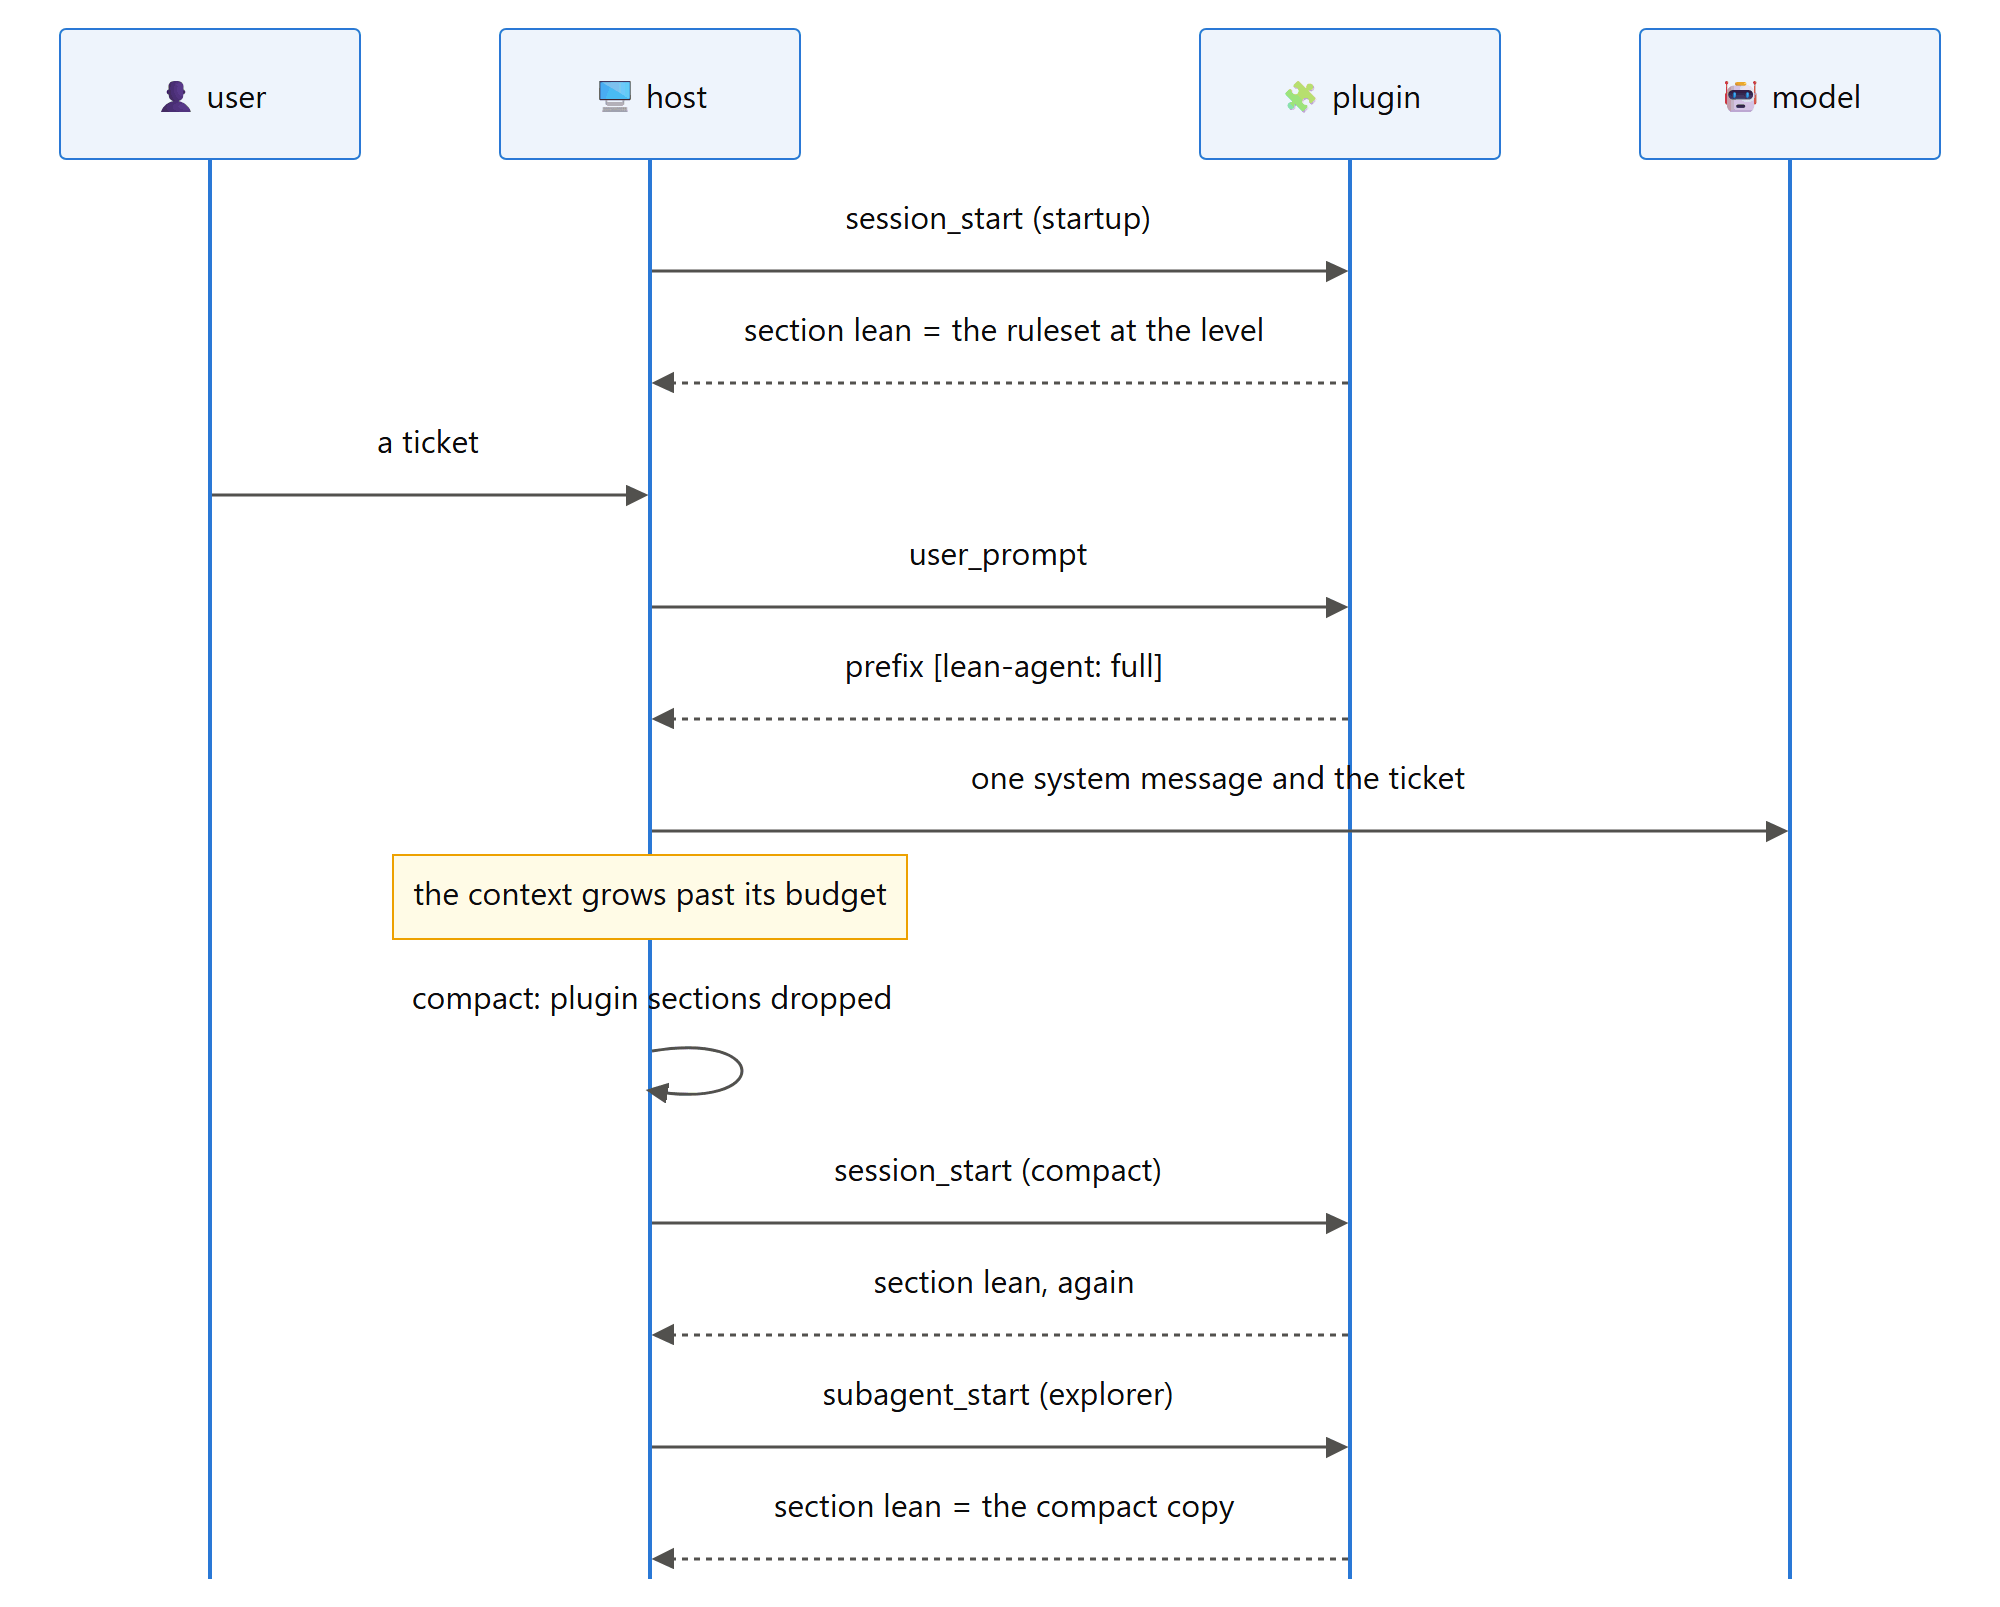

## S37 - The plugin and its session hook

**Theory.** The plugin is one class with an `install` method, like the chaos plugin in S22; everything it does goes through the host's public extension points. Its session hook answers every `session_start` (a new session, a resumed one, a cleared one and a compacted one) with the ruleset at the current level as a system section. Two conditions make it step back. If the user has switched the system off, it injects nothing. And if the project's own instructions file already contains our ruleset (someone pasted it into `AGENTS.md`), it injects nothing either, because the model would otherwise read the same seven hundred tokens twice on every call. The hook keeps a little state on the host (`on`, `level`, what it last injected), and the statusline gets a badge that says the level in words.

**In plain terms.** The plugin hands the model its rules at the start of every session, unless they are switched off or already there.

The plugin needs one way to recognise a copy of the rules that it did not inject itself. The first line of the full ruleset is its title, and no project file would carry it by accident.

In [512]:
MARKER_LINE = ruleset("full").splitlines()[0]          # how a static copy of the rules is recognised
print(f"[plugin] a pasted copy of the rules is recognised by its first line: {MARKER_LINE!r}")

[plugin] a pasted copy of the rules is recognised by its first line: '# Proportional code'


**`LeanPlugin`** is our delivery layer, the one class that turns the ruleset into hooks on the host. Its constructor only records switches, one for each delivery mechanism: the level to start at, the header on every prompt, re-injection after compaction, subagent injection, the repeat-on-every-prompt variant, and which subagent roles receive rules. The experiments switch these off one at a time to measure what each is worth, which is why every one of them is a constructor argument rather than a constant. The methods follow, one per cell.

In [513]:
class LeanPlugin:
    """Our system's delivery layer: the ruleset reaches the model through hooks, at the right
    level, once per session and again after compaction, in subagents too, with a one-line
    header on every prompt and a command to change level or switch off. Every behaviour can
    be switched off for the ablations of Part VII."""

    def __init__(self, level=None, header=True, reinject_on_compact=True, subagents=True,
                 every_prompt=False, matcher=r"^(?!router$)", label=None):
        self.start_level = level                        # None: start at the level saved in the configuration
        self.header = header                            # the one-line mode header on every prompt
        self.reinject = reinject_on_compact             # give the rules back after compaction (S40)
        self.subagents = subagents                      # hand subagents the compact copy (S41)
        self.every_prompt = every_prompt                # the whole ruleset with every prompt: the variant S39 measures
        self.matcher = re.compile(matcher)              # subagent roles that get rules: by default every role but the router
        self.label = label                              # a name for the configuration; nothing reads it yet

show_def(LeanPlugin, layer="plugin")

[class] LeanPlugin(level=None, header=True, reinject_on_compact=True, subagents=True,...)  14 lines, complexity 1


In [514]:
as_built = LeanPlugin()                                 # every switch at its default
# everything on except the every-prompt variant; the level comes from the configuration at install time
print(f"[plugin] as built: start level {as_built.start_level or 'from the configuration'}, header {as_built.header}, "
      f"re-inject {as_built.reinject}, subagents {as_built.subagents}, every prompt {as_built.every_prompt}")

[plugin] as built: start level from the configuration, header True, re-inject True, subagents True, every prompt False


**`LeanPlugin.install(host)`** is the only place the plugin reaches into a host, and it does so only through the host's public extension points. It registers the `level` setting, so a default saved with `/lean default` reaches new sessions; it creates the plugin's state on this host; it attaches three hooks; it registers the `/lean` command; and it puts the level badge first on the statusline. The state lives on the host rather than on the plugin object, which is what keeps one session's mode out of another's (S44).

In [515]:
@method_of(LeanPlugin)
def install(self, host):
    host.config.register("level", "full", valid=lambda v: v in LEVELS)   # a saved default must name a real level
    level = self.start_level or host.config.get("level")[0]           # an explicit level beats the saved default
    host.state["lean"] = {"on": True,                   # on until the user types /lean off
                          "level": level,               # the level this session runs at
                          "injected": None,             # the level whose rules sit in the context now, if any
                          "static": False,              # true when the project file already carries the rules
                          "announce_off": False}        # true from /lean off until the next prompt carries the notice
    # priority 20: our hooks run before other plugins' hooks at the default of 50
    host.bus.on("session_start", self.on_session_start, name="lean.session", priority=20)
    host.bus.on("user_prompt", self.on_user_prompt, name="lean.prompt", priority=20)   # header, level changes, off
    if self.subagents:                                  # the S41 switch: without it, subagents start with no rules
        host.bus.on("subagent_start", self.on_subagent_start, name="lean.subagent", priority=20)   # the compact copy
    # /lean with its arguments; the third value is the line /help prints for it
    host.commands.register(CMD, self.on_command, f"/{CMD} [on|off|lite|full|ultra|status|default LEVEL]")
    host.status_parts.insert(0, self.badge)             # first on the statusline: the mode is what a user looks for

show_def(LeanPlugin.install, layer="plugin")

[def] LeanPlugin.install(self, host)  15 lines, complexity 3


**`LeanPlugin.on_session_start(host, ctx, source)`** answers every `session_start`, whatever caused it (a new session, a resume, a clear or a compaction), with the ruleset at the current level as the `lean` system section. It steps back in three cases: the user has switched the system off, the project's own instructions file already contains the rules (recognised by `MARKER_LINE`), or the context has just been compacted and re-injection is switched off for an experiment. It also records which level it injected, and that record is how the prompt hook knows, later, that the section has gone stale.

In [516]:
@method_of(LeanPlugin)
def on_session_start(self, host, ctx, source, **_):
    st = host.state["lean"]                             # this host's mode, created by install()
    st["injected"] = None                               # a new context starts without our section
    project = ctx.sections.get("project")               # (rank, text) from AGENTS.md, or None
    st["static"] = bool(project) and MARKER_LINE in project[1]   # someone pasted the rules into the project file
    if not st["on"]:                                    # switched off: inject nothing
        return None
    if st["static"]:                                    # already there: a second copy costs tokens and adds nothing
        return None
    if source == "compact" and not self.reinject:       # the S40 variant: let compaction lose the rules
        return None
    st["injected"] = st["level"]                        # remembered, so a later level change can be spotted
    return {"section": "lean", "text": ruleset(st["level"]), "rank": 20}   # rank 20: after the project file

show_def(LeanPlugin.on_session_start, layer="plugin")

[def] LeanPlugin.on_session_start(self, host, ctx, source, **_)  14 lines, complexity 6


`install` wires up methods that are only defined further down, so for now the hooks are tried on a bare host that is handed, by hand, the state `install` would create. A clean project gets the section; a project whose `AGENTS.md` already holds the rules gets nothing.

In [517]:
hook_host = Host(label="demo", config_path=RUNTIME / "demo" / "lean.json")   # no plugin; its own config file, kept apart
# the state install() would create, written out by hand
hook_host.state["lean"] = {"on": True, "level": "full", "injected": None, "static": False, "announce_off": False}
hook_plugin = LeanPlugin(level="full")                  # its hooks are called directly in the cells below
pasted_ctx = Context()                                  # a project that pasted the rules into its AGENTS.md
pasted_ctx.set_section("project", "Team conventions.\n\n" + ruleset("full"), rank=10)   # where start_session puts it
print(f"[hook] AGENTS.md already holds the rules: {hook_plugin.on_session_start(hook_host, pasted_ctx, 'startup')}")
hook_ctx = Context()                                    # a project with no rules file
hook_answer = hook_plugin.on_session_start(hook_host, hook_ctx, "startup")   # a dict the host would apply
print(f"[hook] a clean project: section {hook_answer['section']!r} at rank {hook_answer['rank']}, "
      f"about {tokens_of(hook_answer['text'])} tokens")
hook_ctx.set_section(hook_answer["section"], hook_answer["text"], hook_answer["rank"])   # what the host does with it
print(f"[hook] the plugin's state now: {hook_host.state['lean']}")   # injected now says full

[hook] AGENTS.md already holds the rules: None
[hook] a clean project: section 'lean' at rank 20, about 986 tokens
[hook] the plugin's state now: {'on': True, 'level': 'full', 'injected': 'full', 'static': False, 'announce_off': False}


**`LeanPlugin.on_user_prompt(host, ctx, prompt)`** runs before every prompt joins the conversation, and does two jobs. It keeps the section in step with the state: a level changed since the last injection is replaced, and a system switched off has its section dropped. And it builds the prefix that goes in front of the prompt: the one-line mode header while the system is on, the whole ruleset as well in the every-prompt variant, and, once, a notice that the rules no longer apply right after `/lean off`. When there is nothing to do it returns `None`, which the host treats as no answer at all.

In [518]:
@method_of(LeanPlugin)
def on_user_prompt(self, host, ctx, prompt, **_):
    st = host.state["lean"]                             # this host's mode
    out = {}                                            # what the host should do; nothing, if it stays empty
    # on, not already in the project file, and the section holds another level (or none)
    if st["on"] and not st["static"] and st["injected"] != st["level"]:
        out.update(section="lean", text=ruleset(st["level"]), rank=20)      # the level changed: replace
        st["injected"] = st["level"]                                         # and remember the new one
    if not st["on"] and st["injected"]:                 # off, with our section still in the context
        out["drop"] = "lean"                                                 # switched off: remove
        st["injected"] = None                                                # nothing of ours is left
    prefix = []                                         # lines to put in front of the prompt
    if self.every_prompt and st["on"]:                  # only in the every-prompt variant
        prefix.append(ruleset(st["level"]))                                  # the ablation S39 measures
    if self.header and st["on"]:                        # the header is on by default
        prefix.append(f"[{SYSTEM_NAME}: {st['level']}]")                     # the reminder, at the point of decision
    if st["announce_off"]:                              # set by /lean off
        prefix.append(f"[{SYSTEM_NAME}: off] The proportional-code rules no longer apply.")
        st["announce_off"] = False                                           # said once, then never again
    if prefix:                                          # one block of lines, in the order built above
        out["prefix"] = "\n".join(prefix)
    return out or None

show_def(LeanPlugin.on_user_prompt, layer="plugin")

[def] LeanPlugin.on_user_prompt(self, host, ctx, prompt, **_)  21 lines, complexity 13


In [519]:
hook_host.state["lean"]["level"] = "ultra"              # what /lean ultra does to the state
hook_answer = hook_plugin.on_user_prompt(hook_host, hook_ctx, "fix the cache")   # the first prompt after the change
# the answer replaces the section and carries the header
print(f"[hook] after a level change: keys {sorted(hook_answer)}; the new text is the ultra level: "
      f"{hook_answer['text'] == ruleset('ultra')}; prefix {hook_answer['prefix']!r}")
hook_ctx.set_section(hook_answer["section"], hook_answer["text"], hook_answer["rank"])   # applied, as the host would
# nothing to replace now, so only the header remains
print(f"[hook] the next prompt, with nothing changed: {hook_plugin.on_user_prompt(hook_host, hook_ctx, 'and add a test')}")

[hook] after a level change: keys ['prefix', 'rank', 'section', 'text']; the new text is the ultra level: True; prefix '[lean-agent: ultra]'
[hook] the next prompt, with nothing changed: {'prefix': '[lean-agent: ultra]'}


**`LeanPlugin.on_subagent_start(host, ctx, role)`** gives a starting subagent the compact copy of the rules, the core lines only, when the system is on and the subagent's role passes the plugin's matcher. A subagent never inherits the main conversation, so this hook is the only way rules can reach it. The router is left out by default: a helper whose only job is to answer yes or no has no use for them.

In [520]:
@method_of(LeanPlugin)
def on_subagent_start(self, host, ctx, role, **_):
    st = host.state["lean"]                             # the main session's mode applies to its helpers
    if st["on"] and self.matcher.search(role):          # on, and a role the matcher lets through
        return {"section": "lean", "text": ruleset("full", core_only=True), "rank": 20}   # the compact copy
    return None

show_def(LeanPlugin.on_subagent_start, layer="plugin")

[def] LeanPlugin.on_subagent_start(self, host, ctx, role, **_)  6 lines, complexity 3


In [521]:
for role_name in ("explorer", "reviewer", "router"):    # two helpers that read code, and the router
    sub_answer = hook_plugin.on_subagent_start(hook_host, Context(SUBAGENT_PROMPT), role_name)   # a subagent's own context
    got = f"the compact copy, about {tokens_of(sub_answer['text'])} tokens" if sub_answer else "nothing"
    print(f"[hook] subagent role {role_name!r}: {got}")

[hook] subagent role 'explorer': the compact copy, about 481 tokens
[hook] subagent role 'reviewer': the compact copy, about 481 tokens
[hook] subagent role 'router': nothing


**`LeanPlugin.on_command(host, args)`** handles `/lean` and whatever follows it. A bare `/lean` or `on` switches on, `off` switches off and arranges the notice, a level name switches on at that level, `status` reports, and `default LEVEL` saves a default for new sessions by merging it into the configuration file. Anything else is reported back with the state left exactly as it was, because a typo must never quietly reset the level.

In [522]:
@method_of(LeanPlugin)
def on_command(self, host, args):
    st = host.state["lean"]                             # the state every branch below reads or changes
    arg = args.strip().lower()                          # "/lean  Ultra " means ultra
    if arg in ("", "on"):                               # a bare /lean switches on, as /lean on does
        st["on"] = True                                 # at whatever level was set before
        return f"{SYSTEM_NAME} on ({st['level']})"
    if arg == "off":                                    # the level is kept for the next /lean
        st["on"] = False                                # the hooks stop injecting from here on
        st["announce_off"] = True                       # the next prompt says so, once
        return f"{SYSTEM_NAME} off"
    if arg in LEVELS:                                   # lite, full or ultra
        st["on"] = True                                 # choosing a level also switches on
        st["level"] = arg                               # the prompt hook swaps the section at the next prompt
        return f"{SYSTEM_NAME} on ({arg})"
    if arg == "status":                                 # report only; nothing changes
        return f"{SYSTEM_NAME}: {'on' if st['on'] else 'off'}, level {st['level']}"
    m = re.fullmatch(r"default\s+(\w+)", arg)           # "default lite", and nothing after it
    if m and m.group(1) in LEVELS:                      # a real level, or nothing is saved
        host.config.set_default("level", m.group(1))    # merged into the file, so other settings survive
        return f"default level is now {m.group(1)} for new sessions"
    # anything else: say so, and leave every part of the state alone
    return f"unknown option {args!r}; nothing changed ({SYSTEM_NAME} is {'on' if st['on'] else 'off'}, {st['level']})"

show_def(LeanPlugin.on_command, layer="plugin")

[def] LeanPlugin.on_command(self, host, args)  22 lines, complexity 9


In [523]:
for typed in ("status", "lite", "extreme", "off"):      # a report, a level, a typo, and off
    print(f"  /{CMD} {typed:<8} {hook_plugin.on_command(hook_host, typed)}")
# the prompt after /lean off: the section is dropped and the notice goes out, once
print(f"  {'a prompt':<14} {hook_plugin.on_user_prompt(hook_host, hook_ctx, 'fix the cache')}")
print(f"  /{CMD} {'on':<8} {hook_plugin.on_command(hook_host, 'on')}")   # back on, at the level chosen before

  /lean status   lean-agent: on, level ultra
  /lean lite     lean-agent on (lite)
  /lean extreme  unknown option 'extreme'; nothing changed (lean-agent is on, lite)
  /lean off      lean-agent off
  a prompt       {'drop': 'lean', 'prefix': '[lean-agent: off] The proportional-code rules no longer apply.'}
  /lean on       lean-agent on (lite)


**`LeanPlugin.badge(host)`** is the plugin's part of the statusline: the system's name and either its level or `off`, in words. The words carry the meaning by themselves, so the badge still works without colour, in a log file or in a screen reader (S21).

In [524]:
@method_of(LeanPlugin)
def badge(self, host):
    st = host.state["lean"]                             # read fresh on every redraw of the statusline
    return f"{SYSTEM_NAME}: {st['level'] if st['on'] else 'off'}"   # the level while on, otherwise the word off

show_def(LeanPlugin.badge, layer="plugin")

[def] LeanPlugin.badge(self, host)  4 lines, complexity 2


In [525]:
print(f"[badge] {hook_plugin.badge(hook_host)}")        # on, at lite after the commands above
# switch off, then read the badge again in the same line
print(f"  /{CMD} off: {hook_plugin.on_command(hook_host, 'off')}; the badge now reads {hook_plugin.badge(hook_host)!r}")

[badge] lean-agent: lite
  /lean off: lean-agent off; the badge now reads 'lean-agent: off'


Every method is attached now, so the plugin can be installed the normal way, in a host that starts a real session.

In [526]:
host = Host(plugins=[LeanPlugin(level="full")], label="demo")   # the constructor calls install()
host.start_session(materialise(SUITE["ob-postcode-cache"], WS_DIR / "plugin-demo"))   # session_start fires here
print(f"[plugin] sections after session start: {list(host.ctx.sections)}")
# every event that has at least one hook, with the hooks' names
print(f"[plugin] hooks installed: {[(e, [h.name for h in hs]) for e, hs in host.bus.hooks.items() if hs]}")
print(f"[plugin] statusline: {host.status()}")         # the badge first, then the host's own parts
# the fingerprint changes only when the system message really changes
print(f"[plugin] system message: about {tokens_of(host.ctx.system_text())} tokens, fingerprint {host.ctx.fingerprint()}")

[plugin] sections after session start: ['host', 'lean']
[plugin] hooks installed: [('session_start', ['lean.session']), ('user_prompt', ['lean.prompt']), ('subagent_start', ['lean.subagent'])]
[plugin] statusline: lean-agent: full | Qwen3.8-27B | turn 0/20 | 0.0k tokens | idle | hooks ok
[plugin] system message: about 1267 tokens, fingerprint 2eef666019


## S38 - Modes: commands that cannot fire by accident

**Theory.** The user controls the system with one command, `/lean`, followed by a level, `on`, `off`, `status` or `default LEVEL`. Four details separate a mode system people trust from one they fight. **Only a standalone command counts**: the whole prompt must be the command, so a ticket that says *"add a normal mode toggle to the settings page"* is a ticket, not an instruction to switch anything off. **An invalid argument changes nothing**: `/lean extreme` reports the problem and leaves the level where it was, rather than resetting it to a default the user did not ask for. **Off is announced**: rules already in the conversation can keep steering a model after they are removed, so switching off adds a one-line notice that they no longer apply. **A default persists by merging** into the configuration file, so setting it never wipes other settings. On every prompt while the system is on, the tracker adds a one-line header, `[lean-agent: full]`. It costs a few tokens and keeps the mode visible to the model at the point of decision, which is where a long conversation erodes it.

**In plain terms.** One command changes the mode; nothing else can. Bad input changes nothing, switching off is said out loud, and every prompt carries a short reminder.

**The mode as a state machine.** Only a prompt that is the whole command moves between states. A level name switches the rules on at that level, and switching off is announced to the model once.

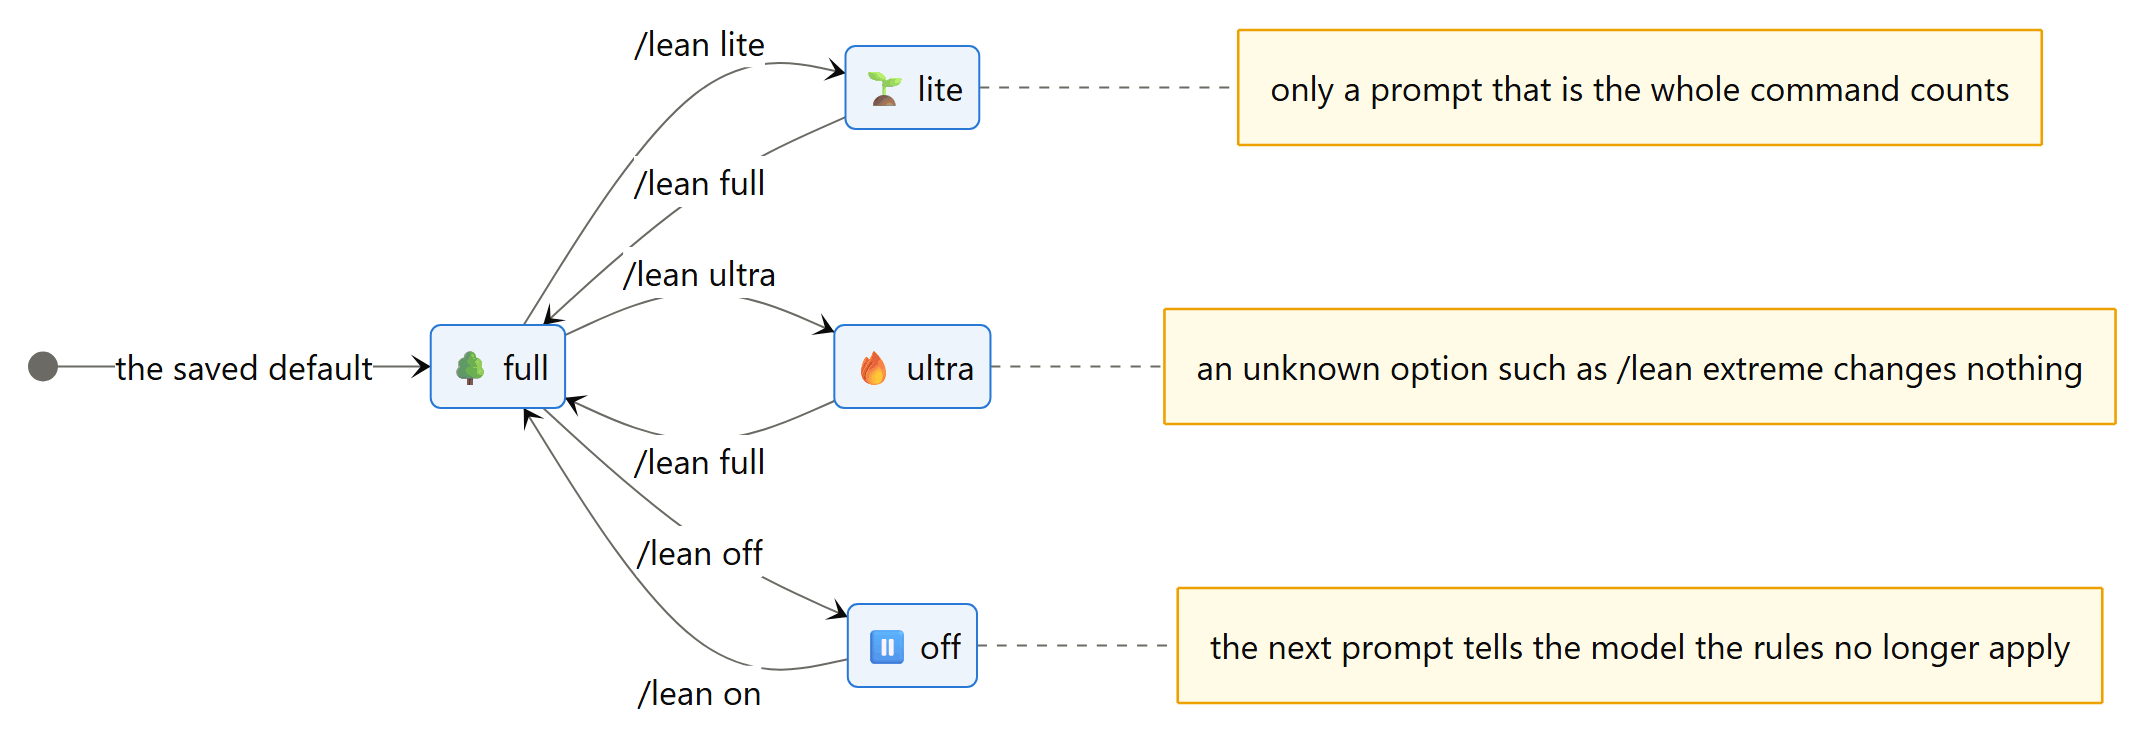

**`section_level(ctx)`** reads back which level's ruleset a context really holds, by comparing the `lean` section with each level's text, word for word. The plugin's state says what it *intends*; this says what the model would *see*, and the mode test below checks both.

In [527]:
def section_level(ctx):
    """Which level's ruleset the context holds, or '-'."""
    text = ctx.sections.get("lean", (0, ""))[1]         # the plugin's section text, or "" when there is none
    for lv in LEVELS:                                   # lite, full, ultra
        if text == ruleset(lv):                         # an exact match, never a guess from a few words
            return lv
    return "-"

show_def(section_level, layer="plugin")

[def] section_level(ctx)  7 lines, complexity 3


In [528]:
# the demo context holds the ultra section applied above; a brand new context holds none
print(f"[modes] the demo context above holds: {section_level(hook_ctx)}; a fresh context holds: {section_level(Context())}")

[modes] the demo context above holds: ultra; a fresh context holds: -


**`mode_trace(steps, level)`** runs a script of typed lines through a host with the plugin and records, after each line, what the host answered and the plugin's state: on or off, the level, which ruleset the context really holds, and the badge. Two pseudo-steps stand for events a user cannot type, `<compact>` and `<new session>`. It uses the scripted model with a throwaway ledger, so no model is called, and it deletes its configuration file first, so a default saved by an earlier run cannot leak in.

In [529]:
def mode_trace(steps, level="full"):
    """Run a script of prompts through a host with the plugin and record the state after each."""
    cfg = RUNTIME / "modes" / "lean.json"               # where /lean default saves, for this trace only
    shutil.rmtree(cfg.parent, ignore_errors=True)       # start with no saved default at all
    door = LLM("smoke", Ledger(":memory:"), scripted=SCRIPTED)   # nothing here reaches a real model
    h = Host(llm=door, plugins=[LeanPlugin(level=level)], label="modes", config_path=cfg)   # the plugin under test
    h.start_session(materialise(SUITE["ob-postcode-cache"], WS_DIR / "modes"))   # a fresh copy of the postcode seed
    rows = []                                           # one row per step
    for step in steps:                                  # typed lines, and the two pseudo-steps
        if step == "<compact>":                         # as if the conversation had grown past the budget
            h.compact()                                 # drops every plugin section, then fires session_start
            said = "(context compacted)"                # what the table shows in the answer column
        elif step == "<new session>":
            # a new host whose plugin has no level of its own: it has to pick up the saved default
            h = Host(llm=door, plugins=[LeanPlugin()], label="modes", config_path=cfg)
            h.start_session(materialise(SUITE["ob-postcode-cache"], WS_DIR / "modes"))   # a fresh workspace too
            said = "(a new session reads the saved default)"
        else:
            reply = h.handle_prompt(step)               # a command answers; anything else joins the conversation
            # the command's answer, or the start of what the model would be sent, header included
            said = reply if reply is not None else f"to the model: {h.ctx.messages[-1]['content'][:40]!r}"
        st = h.state["lean"]                            # the state after this step
        # what was typed, what came back, and the state it left behind
        rows.append({"step": step, "said": said, "on": st["on"], "level": st["level"],
                     "section": section_level(h.ctx), "status": h.status().split(" | ")[0]})   # the badge comes first
    return rows

show_def(mode_trace, layer="plugin")

[def] mode_trace(steps, level='full')  23 lines, complexity 5


The script is the test: twelve typed lines, and for each one the state it must leave behind.

In [530]:
# twelve typed lines; <compact> and <new session> stand for events a user cannot type
SCRIPT = ["/lean ultra", "fix the cache", "/lean off", "fix the cache", "add a normal mode toggle to the settings page",
          "/lean extreme", "<compact>", "/lean", "fix the cache", "/lean default lite", "<new session>", "/lean status"]
EXPECT = [("ultra", True, "full"),      # /lean ultra: the level changes at once, the context still holds full
          ("ultra", True, "ultra"),     # the next prompt: the hook swaps in the ultra rules
          ("ultra", False, "ultra"),    # /lean off: off at once, the section goes with the next prompt
          ("ultra", False, "-"),        # that prompt: the section is dropped and the notice sent
          ("ultra", False, "-"),        # a ticket that mentions a mode is still a ticket
          ("ultra", False, "-"),        # /lean extreme: not a level, so nothing changes
          ("ultra", False, "-"),        # compaction while off brings nothing back
          ("ultra", True, "-"),         # a bare /lean switches on; the rules return with the next prompt
          ("ultra", True, "ultra"),     # and here they are
          ("ultra", True, "ultra"),     # /lean default lite saves a default; this session stays at ultra
          ("lite", True, "lite"),       # a new session starts at the saved default
          ("lite", True, "lite")]       # /lean status only reports
print(f"[modes] {len(SCRIPT)} steps, each with its expected (level, on, rules in the context)")

[modes] 12 steps, each with its expected (level, on, rules in the context)


In [531]:
rows = mode_trace(SCRIPT)                               # one row per step, as the host saw it
for r, (lv, on, sec) in zip(rows, EXPECT):              # each step beside what it should have left behind
    # a step passes only if all three parts of the state are what the script expects
    r["verdict"] = "PASSED" if (r["level"], r["on"], r["section"]) == (lv, on, sec) else "FAILED"
table(rows, [("step", "user types", ""), ("said", "host answers", ""), ("on", "on", ""), ("level", "level", ""),
             ("section", "rules in the context", ""), ("status", "badge", ""), ("verdict", "verdict", "")])
results = []                                            # expect() records each check here
# one line for the whole script: every step has to pass
expect(f"{sum(r['verdict'] == 'PASSED' for r in rows)}/{len(rows)} steps left the state exactly as expected",
       all(r["verdict"] == "PASSED" for r in rows))

  user types                                     host answers                                                             on  level  rules in the context  badge              verdict


  -----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
  /lean ultra                                    lean-agent on (ultra)                                                  True  ultra  full                  lean-agent: ultra  PASSED
  fix the cache                                  to the model: '[lean-agent: ultra]\nfix the cache'                     True  ultra  ultra                 lean-agent: ultra  PASSED
  /lean off                                      lean-agent off                                                        False  ultra  ultra                 lean-agent: off    PASSED
  fix the cache                                  to the model: '[lean-agent: off] The proportional-code '              False  ultra  -                     lean-agent: off    PASSED
  add a normal mode toggle to the settings page  to the model: 'add a normal mode toggle to t

**Try the modes yourself.** The box below runs whatever you type through a fresh host with the plugin installed. Commands answer at once; anything else is shown as it would reach the model, header included. No model is called, so it works in every mode, a replay included.

In [532]:
# W5: any sequence of commands and requests, one at a time
play = Host(llm=LLM("smoke", Ledger(":memory:"), scripted=SCRIPTED), plugins=[LeanPlugin()], label="modes",
            config_path=RUNTIME / "modes-play" / "lean.json")   # a scripted model and its own config: nothing typed here costs anything
play.start_session(materialise(SUITE["ob-postcode-cache"], WS_DIR / "modes-play"))   # its own copy of the seed
print(f"[modes] a fresh host for the box below: {play.status()}")

[modes] a fresh host for the box below: lean-agent: full | Qwen3.8-27B | turn 0/20 | 0.0k tokens | idle | hooks ok


**`play_step(text)`** sends one typed line to that host and reports what came back and the mode afterwards: a command's answer, or the start of the message as the model would receive it, header included. It is the engine of the box below, and it can be called directly in a session without widgets.

In [533]:
def play_step(text):
    """One line typed at the host: what it answered, and the mode afterwards."""
    reply = play.handle_prompt(text)                    # None unless the line was a command
    st = play.state["lean"]                             # the mode after this line
    # a command's answer, or the first 60 characters the model would receive
    said = reply if reply is not None else "to the model: " + repr(play.ctx.messages[-1]["content"][:60])
    return f"{said}\n  on {st['on']}, level {st['level']}, rules in the context: {section_level(play.ctx)}"

show_def(play_step, layer="lab")

[def] play_step(text)  6 lines, complexity 2


In [534]:
print(f"[modes] for example, '/{CMD} lite' then a request:")
for line in (f"/{CMD} lite", "add a retry to the uploader"):   # a command, then an ordinary request
    print(f"  > {line}\n  {play_step(line)}")

[modes] for example, '/lean lite' then a request:
  > /lean lite
  lean-agent on (lite)
  on True, level lite, rules in the context: full
  > add a retry to the uploader
  to the model: '[lean-agent: lite]\nadd a retry to the uploader'
  on True, level lite, rules in the context: lite


In [535]:
W = widgets()                                           # None in a headless run: play_step() still works by hand
if W:
    from IPython.display import display                 # only needed when there is a widget to show
    # Enter sends the line, because continuous_update is off
    box = W.Text(placeholder=f"/{CMD} ultra, /{CMD} off, or any request", continuous_update=False, layout={"width": "60%"})
    # a scrolling log of everything typed and answered
    out = W.Output(layout={"border": "1px solid #e6e5e1", "max_height": "260px", "overflow": "auto"})

    def _play(change):
        text = change["new"].strip()                    # the line just sent
        if not text:                                    # clearing the box fires this too; ignore it
            return
        with out:                                       # print into the log, not under the cell
            print(f"> {text}\n  {play_step(text)}")
        box.value = ""                                  # ready for the next line

    box.observe(_play, names="value")                   # runs whenever a line is sent
    display(W.VBox([box, out]))                         # the box above its log
else:
    print("(no widget in this run, which needs a live Jupyter session; call play_step('...') directly)")

(no widget in this run, which needs a live Jupyter session; call play_step('...') directly)

Read the table from the top. `/lean ultra` changes the level at once, but the context still holds the full ruleset until the next prompt, when the hook replaces it (row 2). `/lean off` takes effect the same way, and the next prompt carries the notice. The ticket about a "normal mode toggle" leaves the mode alone, and so does `/lean extreme`. Compaction while off brings nothing back. A bare `/lean` switches on again, and a default saved with `/lean default lite` is what the next session starts with.

## S39 - Inject once, remind every time

**Theory.** There are two ways to keep rules in front of a model over a long session. One is to repeat the whole ruleset with every prompt, which many hook-based setups do because it is the simplest thing that works. The other is to inject it once, as a stable system section, and remind the model of it with a one-line header on each prompt. The first costs the full ruleset again on every turn, and that cost compounds, because every earlier copy stays in the conversation and is re-sent on every later call. The second costs the ruleset once and a few tokens per prompt, and the stable system section is also the part of the request a provider can cache. The measurement below runs the same five-prompt conversation both ways, with the scripted stand-in so the numbers are exact.

**In plain terms.** Say the rules once and point at them afterwards; repeating them every time gets expensive fast.

**`session_tokens(plugin, prompts)`** measures what a plugin costs over a conversation: it sends a list of prompts through a scripted host and records, after each one, how many tokens the whole request to the model would hold. The scripted model makes the numbers exact and free, and a short stand-in reply after each prompt keeps the conversation growing the way a real one does.

In [536]:
def session_tokens(plugin, prompts):
    """Prompt tokens the model is sent over a scripted multi-prompt session."""
    door = LLM("smoke", Ledger(":memory:"), scripted=SCRIPTED)   # no real model: the counts are exact and free
    h = Host(llm=door, plugins=[plugin], label="tokens")    # the plugin under measurement, alone
    h.start_session(materialise(SUITE["ob-postcode-cache"], WS_DIR / "tokens"))   # a fresh copy of the postcode seed
    per_call = []                                       # the request's size after each prompt
    for p in prompts:                                   # the conversation, one prompt at a time
        h.handle_prompt(p)                              # the hooks run, and the prompt joins the conversation
        per_call.append(sum(len(m["content"]) for m in h.ctx.render()) // 4)   # tokens_of's rule, over every message
        h.ctx.add("assistant", "<done>ok</done>")       # a short stand-in reply, so the history grows
    return per_call

show_def(session_tokens, layer="plugin")

[def] session_tokens(plugin, prompts)  11 lines, complexity 3


In [537]:
# five follow-up requests in one session, the shape of a real working conversation
PROMPTS = ["Add a cache to lookup_district.", "Now make unknown postcodes return None.", "Add a check for that.",
           "Rename normalise to clean.", "Update the visible test."]
once = session_tokens(LeanPlugin(level="full"), PROMPTS)                     # the rules once, then a header per prompt
every = session_tokens(LeanPlugin(level="full", every_prompt=True), PROMPTS)  # the whole ruleset with every prompt
print(f"[tokens] per call, injecting once: {once}")
print(f"[tokens] per call, repeating the rules: {every}")

[tokens] per call, injecting once: [1280, 1298, 1312, 1327, 1341]


[tokens] per call, repeating the rules: [2266, 3271, 4271, 5273, 6274]


In [538]:
# one row per call; the ratio is what repeating costs at that point in the session
table([{"prompt": i + 1, "inject once": a, "every prompt": b, "ratio": b / a}
       for i, (a, b) in enumerate(zip(once, every))],
      [("prompt", "call", "d"), ("inject once", "tokens, inject once", "d"), ("every prompt", "tokens, every prompt", "d"),
       ("ratio", "ratio", ".1f")])
# the totals over the five calls, and their ratio
print(f"\n  five prompts: {sum(once)} tokens injecting once, {sum(every)} repeating the rules "
      f"({sum(every) / sum(once):.1f}x); the gap grows with every further prompt")
save_exp("inject_once", {"once": sum(once), "every": sum(every), "ratio": sum(every) / sum(once)})   # for Part VII

  call  tokens, inject once  tokens, every prompt  ratio
  ------------------------------------------------------
     1                 1280                  2266    1.8
     2                 1298                  3271    2.5
     3                 1312                  4271    3.3
     4                 1327                  5273    4.0
     5                 1341                  6274    4.7

  five prompts: 6558 tokens injecting once, 21355 repeating the rules (3.3x); the gap grows with every further prompt
[exp] artifacts/exp_inject_once.json


## S40 - Compaction drops the rules; the hook puts them back

**Theory.** S17 built compaction to behave the way it does in real agents: the conversation is summarised and every injected section is dropped, as if a new session had started with a summary in hand. That is precisely how rules disappear from long sessions, and nothing visibly breaks when they do: the agent simply starts writing the way it wrote before the rules arrived. The defence is one line of the session hook, which answers `session_start` with source `compact` by injecting the rules again. The demonstration below forces compaction early, by lowering the context budget, and prints for every turn whether the rules were in the system message the model saw. The plugin is run twice, with re-injection on and off.

**In plain terms.** Summarising a long conversation throws the rules away; the plugin notices and hands them back.

**`rules_by_turn(plugin, task_id, budget)`** runs one scripted episode with a context budget small enough to force compaction within a few turns, and records, before every model call, whether the `lean` section is in the context the model is about to see. It shrinks the notebook's global `CONTEXT_BUDGET` for the run and puts it back in a `finally` block, so an error inside the episode cannot leave every later episode compacting early.

In [539]:
def rules_by_turn(plugin, task_id="sf-intake-server", budget=1500):
    """Run a scripted episode with a tiny context budget; for every turn, was the ruleset in
    the system message?"""
    global CONTEXT_BUDGET                               # the host's loop reads this global on every turn
    saved = CONTEXT_BUDGET                              # the real budget, put back however the run ends
    CONTEXT_BUDGET = budget                             # small enough that compaction comes within a few turns
    try:
        door = LLM("smoke", Ledger(":memory:"), scripted=SCRIPTED)   # the scripted coder: free and repeatable
        h = Host(llm=door, plugins=[plugin], label="compact")   # the plugin under test, alone
        seen = []                                       # one entry per model call: were the rules there?

        def note_rules(ctx, **_):                       # pre_llm_call fires just before every call
            seen.append("lean" in ctx.sections)         # True while our section is in the context

        h.bus.on("pre_llm_call", note_rules, name="probe")   # a probe, not a plugin: it only looks
        ep = run_episode(SUITE[task_id], h)             # a whole ticket, start to finish
        return seen, h.ctx.compactions, ep
    finally:
        CONTEXT_BUDGET = saved                          # every later episode gets the real budget back

show_def(rules_by_turn, layer="plugin")

[def] rules_by_turn(plugin, task_id='sf-intake-server', budget=1500)  17 lines, complexity 1


In [540]:
with_hook, n1, _ = rules_by_turn(LeanPlugin(level="full"))                             # the plugin as built
without, n2, _ = rules_by_turn(LeanPlugin(level="full", reinject_on_compact=False))   # the same, without re-injection
print(f"[compact] compactions: {n1} with re-injection, {n2} without")
print("  rules in the system message, turn by turn (R = present, . = missing):")
print(f"    with the hook    {''.join('R' if x else '.' for x in with_hook)}")   # one character per model call
print(f"    without it       {''.join('R' if x else '.' for x in without)}")

[compact] compactions: 5 with re-injection, 4 without
  rules in the system message, turn by turn (R = present, . = missing):
    with the hook    RRRRRRRR
    without it       RR.....


In [541]:
results = []                                            # expect() records each check here
expect("with re-injection the rules are present on every turn", all(with_hook))   # not one missing turn
# gone somewhere, and still gone at the last turn: nothing else brings them back
expect("without it they vanish at the first compaction and stay gone", not all(without) and not without[-1])
save_exp("compact_reinject", {"with": sum(with_hook), "without": sum(without), "turns": len(with_hook)})   # for Part VII

  PASSED  with re-injection the rules are present on every turn
  PASSED  without it they vanish at the first compaction and stay gone
[exp] artifacts/exp_compact_reinject.json


## S41 - Subagents start from nothing

**Theory.** A subagent gets a fresh context on purpose: it should not inherit the main agent's long conversation. The side effect is that it does not inherit the rules either. A helper that explores the code base, reviews a diff or proposes a fix then works by the model's defaults, and its suggestions flow back into the main agent's work. The plugin answers `subagent_start` with the **compact copy** of the ruleset (the core lines: read first, never cut, prove it, how to answer), which is enough for a helper that only reads, at a fraction of the cost. A **matcher** decides which roles receive it; the router, whose only job is to answer yes or no, is excluded. Part VII measures whether injected subagents behave differently (H11).

**In plain terms.** Helper agents start with a blank slate, so the plugin hands them a short version of the rules.

In [542]:
# the same question to an explorer subagent, from a host without subagent injection and from one with it
for label, plugin in (("plugin without subagent injection", LeanPlugin(subagents=False)),
                      ("plugin with it", LeanPlugin())):
    h = Host(plugins=[plugin], label="sub")             # the notebook's front door: the call is kept in the ledger
    ws = materialise(SUITE["ob-postcode-cache"], WS_DIR / "sub-demo")   # a fresh copy of the postcode seed
    h.start_session(ws)
    result, sub = h.subagent("explorer", "Which function looks up a district?", ws)   # the fast model, read-only tools
    # the sections the subagent's own context received, and what its system message costs
    print(f"[{label}] explorer sections: {list(sub.sections)}, system message about {tokens_of(sub.system_text())} tokens")

[plugin without subagent injection] explorer sections: ['host'], system message about 138 tokens


[plugin with it] explorer sections: ['host', 'lean'], system message about 619 tokens


In [543]:
h = Host(plugins=[LeanPlugin()], label="sub")           # the plugin as built, matcher included
h.start_session(ws)                                     # the workspace from the cell above
# one turn is enough: what matters is which sections the router's context gets, not its answer
_, router_ctx = h.subagent("router", "Is 'fix the cache' a coding request?", ws, max_turns=1)
print(f"[router] sections: {list(router_ctx.sections)} (excluded by the matcher, as intended)")
# what an included subagent pays for its rules, against the full level
print(f"  the compact copy: {tokens_of(ruleset('full', core_only=True))} tokens instead of {tokens_of(ruleset('full'))}")

[router] sections: ['host'] (excluded by the matcher, as intended)
  the compact copy: 481 tokens instead of 986


## S42 - Two copies are not better than one

**Theory.** Some teams will paste the ruleset into their project's `AGENTS.md`, the static instructions file the host reads at every session start. If the plugin also injects it, the model reads seven hundred tokens twice on every call and gains nothing. The session hook therefore looks at the project section first and steps back when it finds the ruleset's first line there. A related guard sits in the context manager: every section has a size cap, so a project instructions file of thirty thousand characters cannot crowd everything else out of the window.

**In plain terms.** If the project already carries the rules, the plugin does not add a second copy.

In [544]:
ws = materialise(SUITE["ob-postcode-cache"], WS_DIR / "coexist")   # a fresh copy of the postcode seed
# a team that pasted our rules under its own conventions
(ws / "AGENTS.md").write_text("Team conventions: British spelling in comments.\n\n" + ruleset("full"), encoding="utf-8")
rows = []                                               # one row per setup
# the same project, opened by a plugin that never looks and by ours
for label, plugin in (("plugin, no AGENTS.md check", None), ("plugin as built", LeanPlugin())):
    # no plugin given: a StaticRules that pastes the rules without looking, which is what the check prevents
    h = Host(plugins=[plugin] if plugin else [StaticRules(ruleset("full"))], label="coexist")
    h.start_session(ws)                                 # reads AGENTS.md into the project section
    text = h.ctx.system_text()                          # everything the model would read before the conversation
    # how many times the rules' title appears, what the system message costs, and which sections it holds
    rows.append({"setup": label, "copies of the rules": text.count(MARKER_LINE), "tokens": tokens_of(text),
                 "sections": ", ".join(h.ctx.sections)})
# without the check the rules appear twice; with it, once
table(rows, [("setup", "setup", ""), ("copies of the rules", "copies of the rules", "d"), ("tokens", "system tokens", "d"),
             ("sections", "sections", "")])

  setup                       copies of the rules  system tokens  sections
  ------------------------------------------------------------------------------------
  plugin, no AGENTS.md check                    2           2266  host, project, rules
  plugin as built                               1           1279  host, project


The size cap from S17, on a project file far over the limit:

In [545]:
big = Context()                                         # a context on its own, no host needed
big.set_section("project", "x" * 40_000, rank=10)       # a project file far beyond SECTION_CAP
# what was kept, and the count of truncations the context keeps for the health report
print(f"\n  a 40,000-character project file is capped at {len(big.sections['project'][1]):,} characters "
      f"(truncations recorded: {big.truncated})")


  a 40,000-character project file is capped at 16,012 characters (truncations recorded: 1)


## S43 - Delivery: did the model actually receive the rules?

**Theory.** A hook that ran is not the same as a rule that arrived. Between the two sit the context manager, the provider's handling of the system message, the model's chat template and anything that truncates long inputs; any of them can lose the text without an error. The only proof of delivery is to ask the model, so each of the six models is asked to quote two things it should have been given: the ruleset's title and the mode header on the prompt. A model that cannot quote them did not receive them, whatever the hook log says.

**In plain terms.** We do not trust that the rules got through; we ask each model to repeat them back.

In [546]:
# the question every model is asked; it names both things it should have been given
DELIVERY_PROMPT = ("Before anything else: quote, exactly, the first heading of the rules in your system message, "
                   "and the bracketed mode header at the start of this message. Reply with just those two lines.")
print(f"[delivery] every model is asked:\n  {DELIVERY_PROMPT}")

[delivery] every model is asked:
  Before anything else: quote, exactly, the first heading of the rules in your system message, and the bracketed mode header at the start of this message. Reply with just those two lines.


**`_scripted_delivery(model, messages, params)`** is the scripted model's answer to the delivery question in smoke runs: it quotes the two lines that a model which received both the rules and the header would quote. It recognises its request by the question itself and returns `None` for anything else, so it cannot answer another section's requests by accident.

In [547]:
@SCRIPTED.register
def _scripted_delivery(model, messages, params):
    if DELIVERY_PROMPT not in messages[-1]["content"]:  # not the delivery question: leave it to another responder
        return None
    # the rules' first line and the mode header, as a model that received both would quote them
    return f"{MARKER_LINE}\n[{SYSTEM_NAME}: full]"

show_def(_scripted_delivery, layer="lab")

[def] _scripted_delivery(model, messages, params)  5 lines, complexity 2


**`delivered(model)`** asks one model to prove what it received. It builds a host with the plugin at the full level, starts a session, sends the delivery question through the normal prompt path, so the mode header is attached exactly as it would be for a ticket, and makes one call with the resulting context. A model passes on each item only if its reply contains the text it was given: the ruleset's title and the bracketed header.

In [548]:
def delivered(model):
    h = Host(model=model, plugins=[LeanPlugin(level="full")], label="delivery")   # the model under test, our plugin
    # a workspace per model, so the probes can run at the same time without sharing files
    h.start_session(materialise(SUITE["ob-postcode-cache"], WS_DIR / f"delivery-{model.split('/')[-1]}"))
    h.handle_prompt(DELIVERY_PROMPT)                    # the prompt hook puts the mode header in front of it
    r = h.llm.chat(model, h.ctx.render(), tag="delivery", max_tokens=1500)   # exactly what an agent would send
    first_line = r.text.strip().splitlines()[0] if r.text.strip() else ""     # an empty reply has no first line
    return {"model": model.split("/")[-1],                # the name without its organisation prefix
            "title": MARKER_LINE.lstrip("# ") in r.text,          # "Proportional code", the ruleset's title
            "header": f"[{SYSTEM_NAME}: full]" in r.text,         # the header exactly as it was sent
            "reply": plain(first_line)[:60]}                      # enough of the reply to see what it quoted

show_def(delivered, layer="plugin")

[def] delivered(model)  10 lines, complexity 2


In [549]:
with ThreadPoolExecutor(WORKERS) as pool:               # one probe per distinct model, all at once
    DELIVERY = list(pool.map(delivered, sorted(set(MODEL_FOR.values()))))   # sorted, so the table order is fixed
# yes or NO in capitals, so a failed delivery stands out in the table
table([{**d, "title": "yes" if d["title"] else "NO", "header": "yes" if d["header"] else "NO"} for d in DELIVERY],
      [("model", "model", ""), ("title", "quoted the rules' title", ""), ("header", "quoted the header", ""), ("reply", "first line of the reply", "")])
# how many models quoted each item, for the prose and Part VII
save_exp("delivery", {"models": len(DELIVERY), "title": sum(d["title"] for d in DELIVERY), "header": sum(d["header"] for d in DELIVERY)})

  model               quoted the rules' title  quoted the header  first line of the reply
  --------------------------------------------------------------------------------------------
  Qwen3.7-Max         yes                      yes                # Proportional code
  Qwen3.7-Plus        yes                      yes                # Proportional code
  Qwen3.8-27B         yes                      yes                <done>
  Qwen3.8-Flash-Next  yes                      yes                # Proportional code
  Qwen3.8-Max         yes                      yes                # Proportional code
  Qwen3.8-Omni-Flash  NO                       yes                ## What to build: the ladder
[exp] artifacts/exp_delivery.json


## S44 - Scope, persistence and chaos

**Theory.** Three last properties keep the plugin well behaved in real use. **Scope:** the mode lives on the host instance, one per session, so two sessions (or two users) never see each other's level; only the *default* is shared, through the configuration file, and only when someone sets it on purpose. **Persistence:** a session that is resumed gets the rules at its current level again, through the same `session_start` hook with source `resume`. **Chaos:** a corrupt configuration file, a plugin hook that raises, or a hook that hangs must never stop the user's work; the configuration falls back to defaults with a warning (S19), and the event bus records and skips failing hooks (S16). The test below breaks each of these on purpose.

**In plain terms.** Each session has its own mode, a resumed session gets its rules back, and broken files or broken hooks cannot stop the work.

In [550]:
results = []                                            # expect() records each check here
# scope: two sessions, one level change
a = Host(plugins=[LeanPlugin(level="full")], label="a")
b = Host(plugins=[LeanPlugin(level="full")], label="b")   # a second, separate session
a.start_session(materialise(SUITE["ob-postcode-cache"], WS_DIR / "scope-a"))   # each with its own workspace
b.start_session(materialise(SUITE["ob-postcode-cache"], WS_DIR / "scope-b"))   # nothing shared with a
a.handle_prompt("/lean ultra")                          # a command, so no model is involved
# a changed, b untouched
expect("switching one session's level leaves another session alone",
       a.state["lean"]["level"] == "ultra" and b.state["lean"]["level"] == "full")
# persistence: resuming fires session_start with source "resume", and the hook answers at the current level
a.start_session(a.ws, "resume")
# "what can be deleted" is the line only ultra has
expect("a resumed session gets its rules back at its current level", "what can be deleted" in a.ctx.system_text())

  PASSED  switching one session's level leaves another session alone
  PASSED  a resumed session gets its rules back at its current level


In [551]:
# chaos, part one: a configuration file cut off half way, as a crash during a save would leave it
broken = RUNTIME / "chaos" / "lean.json"
broken.parent.mkdir(parents=True, exist_ok=True)        # the folder may not exist yet
broken.write_text('{"level": ', encoding="utf-8")       # not valid JSON
c = Host(plugins=[], label="chaos")                     # a host with no plugin
c.config = Config(broken)                               # reading the broken file
c.config.register("level", "full", valid=lambda v: v in LEVELS)   # what install() registers
# the default comes back, and the problem is written down rather than raised
expect("a corrupt configuration file falls back to the default, with a warning",
       c.config.get("level") == ("full", "default") and c.config.warnings)

  PASSED  a corrupt configuration file falls back to the default, with a warning


**`BrokenPlugin`** is a plugin written to fail: its session hook divides by zero and its prompt hook sleeps for ten seconds. Installed beside ours, it shows that the event bus contains the damage: the crash is recorded and skipped, the hang is abandoned at the bus's time limit, and our hooks still deliver the rules.

In [552]:
class BrokenPlugin:
    """A plugin that fails on purpose: one hook raises, the other hangs."""

    def install(self, host):
        host.bus.on("session_start", lambda **_: 1 / 0, name="broken.session")         # raises ZeroDivisionError
        host.bus.on("user_prompt", lambda **_: time.sleep(10), name="broken.prompt")    # hangs well past the limit

show_def(BrokenPlugin, layer="lab")

[class] BrokenPlugin()  5 lines, complexity 1


In [553]:
EventBus.HANG_S = 0.3                                   # shortened, so the hang costs a third of a second here
d = Host(plugins=[BrokenPlugin(), LeanPlugin(level="full")], label="chaos")   # the broken plugin beside ours
d.start_session(materialise(SUITE["ob-postcode-cache"], WS_DIR / "chaos"))    # the session hook crashes here
d.handle_prompt("fix the cache")                        # and the prompt hook hangs here
EventBus.HANG_S = 5.0                                   # back to the real limit
# our section is in place, and the prompt reached the conversation with our header in front
expect("a crashing and a hanging plugin did not stop ours from delivering the rules",
       "lean" in d.ctx.sections and d.ctx.messages[-1]["content"].startswith(f"[{SYSTEM_NAME}: full]"))
print(f"  health report: {d.bus.report()}")             # the crash and the hang, counted
print(f"  statusline: {d.status()}")                    # the failures show on the statusline too

  PASSED  a crashing and a hanging plugin did not stop ours from delivering the rules
  health report: [{'hook': 'broken.prompt', 'ok': 0, 'slow': 0, 'error': 0, 'hung': 1}, {'hook': 'broken.session', 'ok': 0, 'slow': 0, 'error': 1, 'hung': 0}, {'hook': 'lean.prompt', 'ok': 1, 'slow': 0, 'error': 0, 'hung': 0}, {'hook': 'lean.session', 'ok': 1, 'slow': 0, 'error': 0, 'hung': 0}]
  statusline: lean-agent: full | Qwen3.8-27B | turn 0/20 | 0.0k tokens | idle | hooks: 2 failed


**Part V recap.** The rules now reach the model through hooks rather than by being pasted in: at every session start at the level the user chose, with a one-line reminder on every prompt, once rather than repeatedly, again after compaction, in a compact form for subagents, never twice when the project already carries them, and with each model able to quote them back. Mode commands cannot fire by accident, bad arguments change nothing, switching off is announced, and broken plugins or files cannot stop the work. Whether all this delivery machinery beats the same words pasted into a system message is a question for Part VII (H4); Part VI first adds the parts of the system that do not rely on words at all.

**Try it yourself.**
1. Add `"/LEAN Full"` and `"please /lean off"` to the mode script in S38 and predict both rows before running. Which one is a command?
2. In S40, set `budget=4000` and find the smallest budget at which compaction still happens.
3. Change the subagent matcher so that no subagent receives the rules, and check which line of S41's output changes.

# Part VI - Plugin III: gates, a critic and skills

Words ask; gates make sure.

**Where this sits.** Parts IV and V gave the model rules and made sure it received them. Everything in those Parts still depends on the model choosing to follow what it read. This Part adds the pieces that do not: **gates** that sit on the agent's tools and refuse an action, or annotate its result, whatever the model intended. A map of the project arrives at the start of the session, so existing helpers are visible before anything is written. A read gate refuses to edit a file the agent has not opened. A sibling scan names the other callers of a shared helper as soon as the agent touches code that uses it. A dependency gate refuses imports the project does not declare and features its Python version does not have. A one-time nudge asks for a check before finishing. A critic reviews the change before the agent may finish, and a trim guard refuses any follow-up edit that removes a guard. Then come the **skills** a user calls by name: review, audit (tested against a project with known bloat planted in it), debt, gain and help. Each piece is an hypothesis about machinery beating words, and Part VII keeps only the pieces that earn their place (H4).

**By the end of this Part you can** turn a rule into a gate, tell a gate that helps from one that only adds turns, run a critic inside the loop without letting it delete guards, measure an audit's recall and precision against planted ground truth, and see why "search before you delete" needs a second safety net.

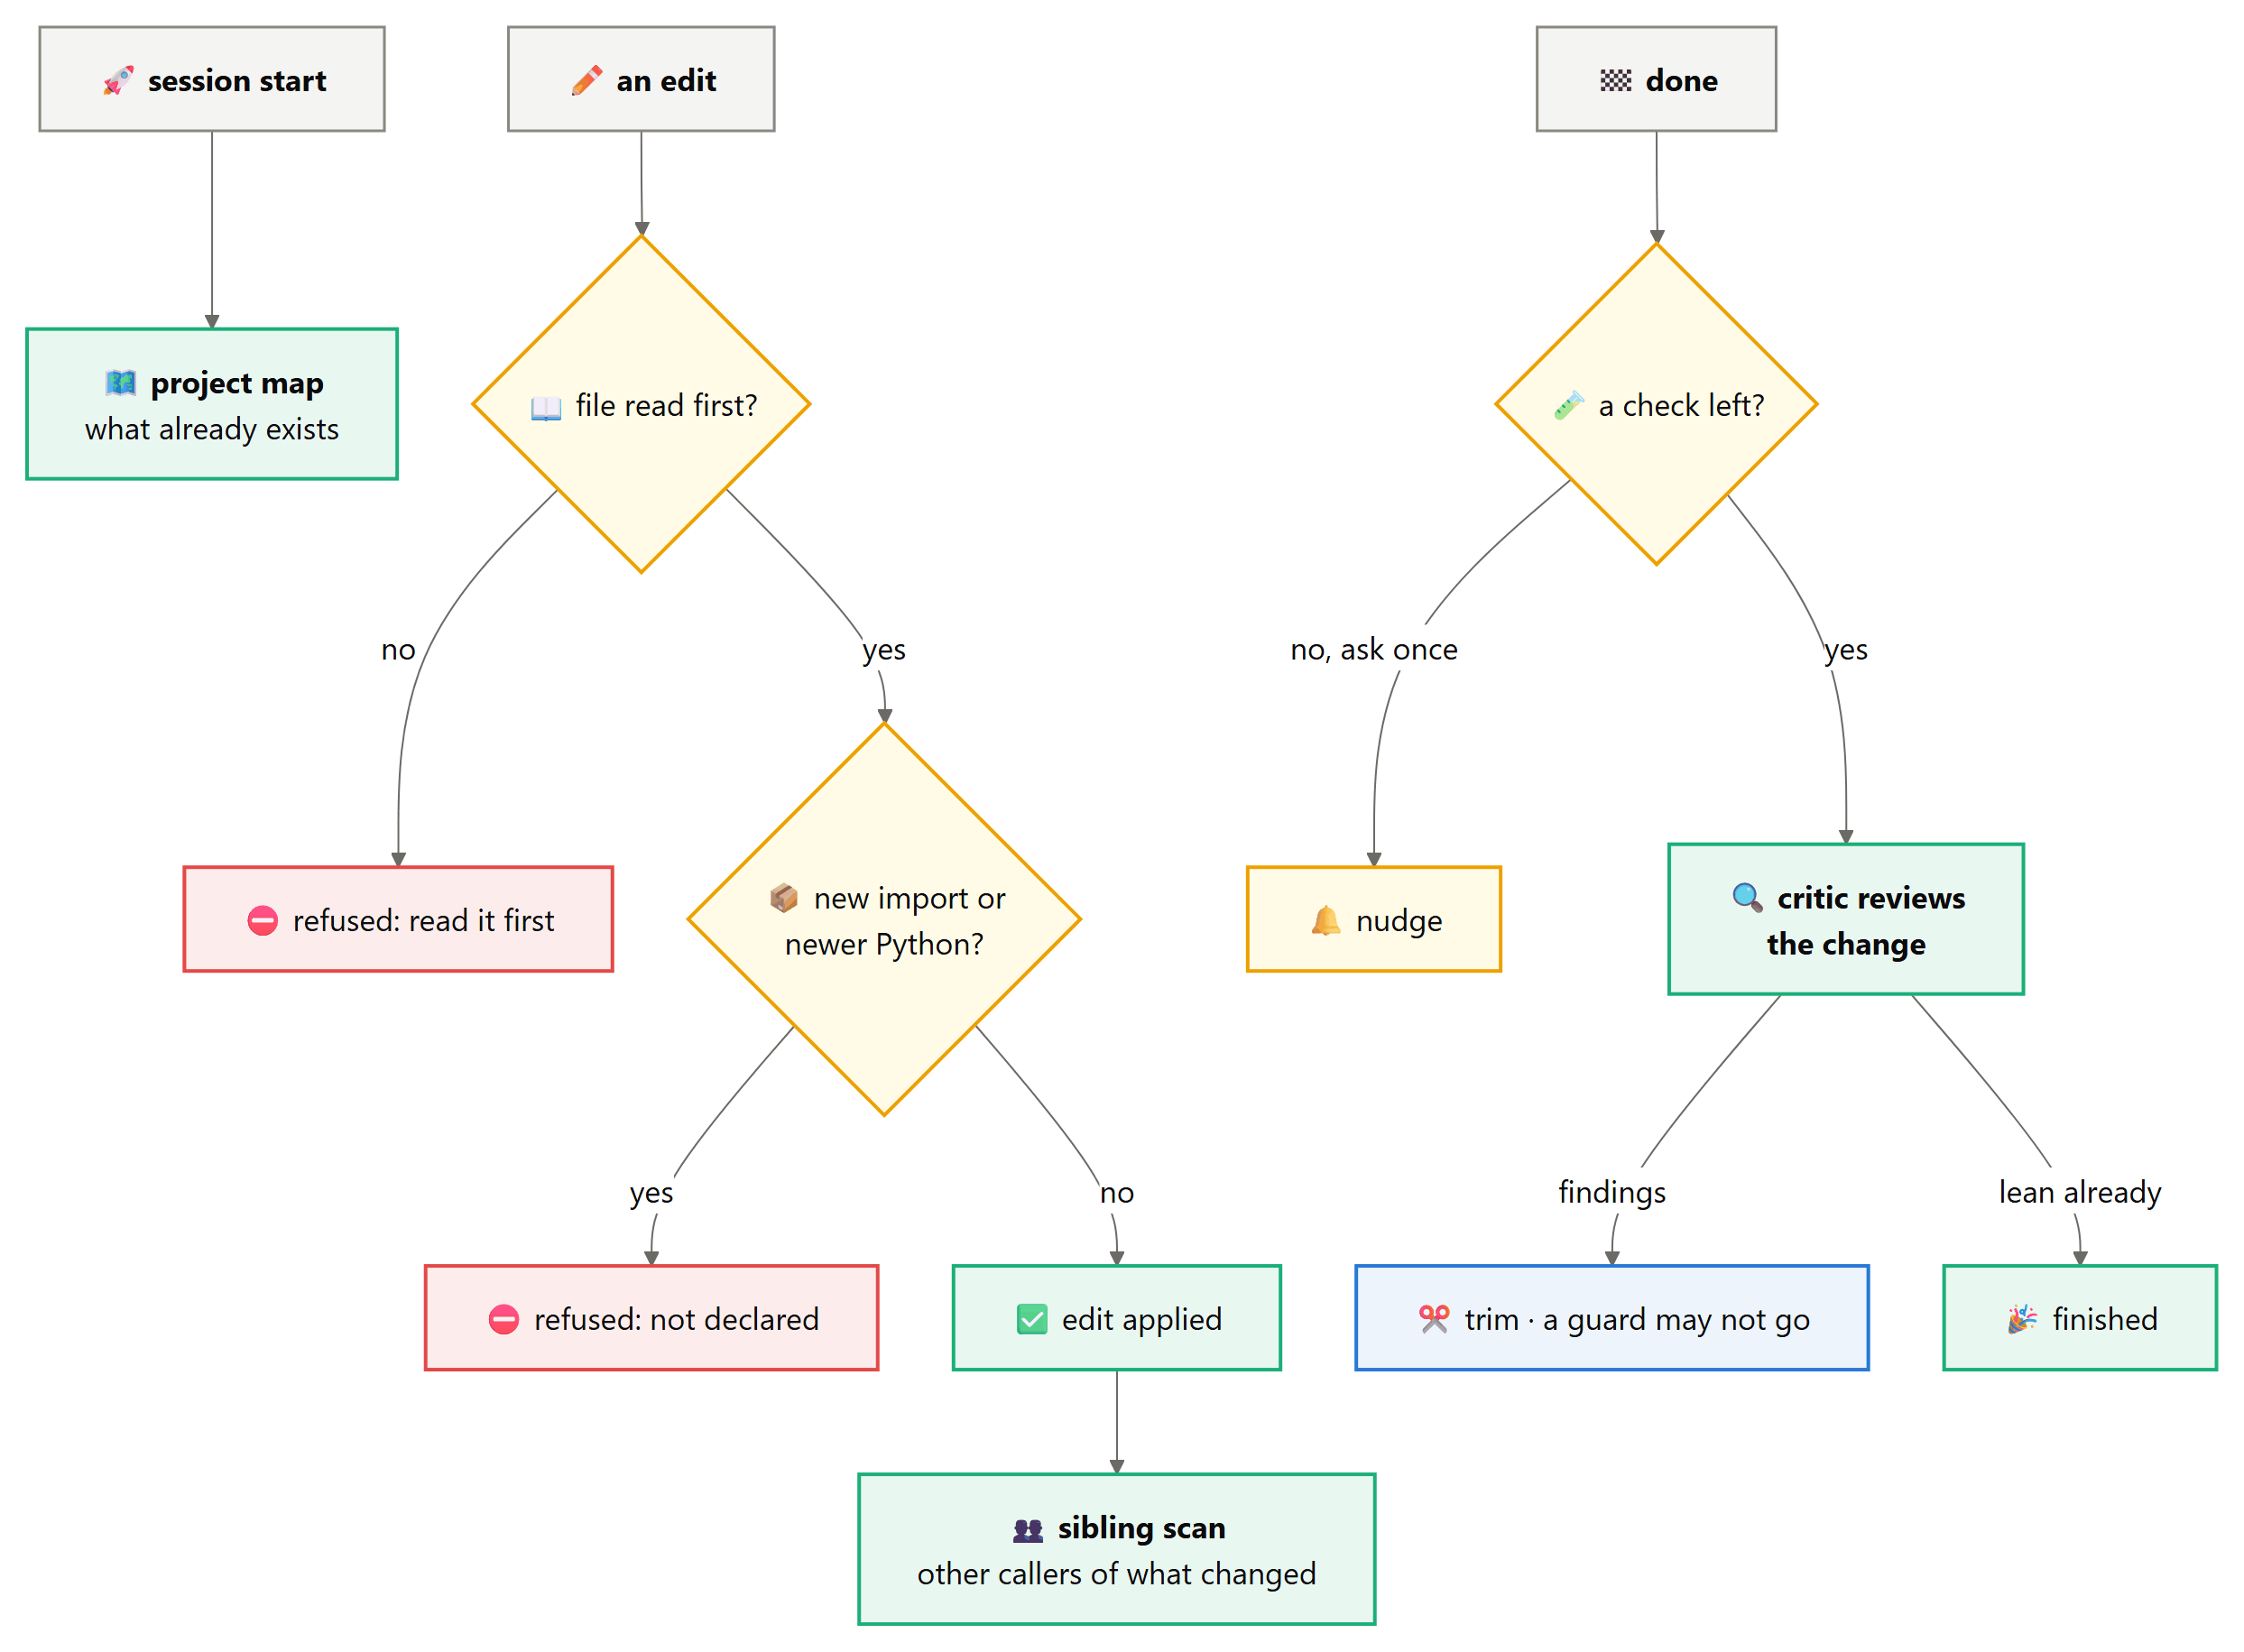

## S45 - A map of the project

**Theory.** The cheapest moment to stop an agent rebuilding a helper is before it starts writing, and the cheapest way is to show it what exists. The map is one line per source file: its length and its top-level functions and classes with their parameters. For our tasks that is a few hundred tokens; for a large repository it is capped, and Part X's folder runner relies on the cap. The map does not replace reading (S46 makes sure of that). It answers the question *what is there to read?*, which is the question an agent skips when it assumes the helper it needs does not exist yet.

**In plain terms.** At the start, the agent gets a one-page list of every file and the functions in it.

**`repo_map(ws, cap=2400)`** builds that list: one line per Python source file, giving its length and the functions and classes defined at its top level, each function with its positional parameters. Only the top level is listed, because that is what another module can import and reuse, and test files are left out, because a helper that lives in a test is not one the agent should call. A file that does not parse still gets its line, saying so, rather than quietly vanishing from the map. The cap keeps a large project from flooding the system message: the text is cut back to the last whole line that fits and marked as truncated.

In [554]:
def repo_map(ws, cap=2400):
    """One line per source file: its length and its top-level functions and classes."""
    lines = []                                                # one entry per file, in path order
    for path, text in snapshot(ws).items():                   # snapshot already leaves out harness folders and caches
        if not path.endswith(".py") or is_test_file(path):    # tests and non-Python files hold nothing to reuse
            continue
        tree = _safe_parse(text)                              # None when the file does not parse
        if tree is None:
            lines.append(f"{path} ({len(text.splitlines())} lines): does not parse")   # still listed, so a broken file is not invisible
            continue
        defs = []                                             # what this file offers the rest of the project
        for n in tree.body:                                   # the top level only: what another module can import
            if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)):
                defs.append(f"{n.name}({', '.join(a.arg for a in n.args.args)})")   # a function with its parameter names
            elif isinstance(n, ast.ClassDef):
                defs.append(f"class {n.name}")                # a class by its name only
        # "path (N lines): f(a, b), class C", or "no functions" for a file that defines none
        lines.append(f"{path} ({len(text.splitlines())} lines): {', '.join(defs) or 'no functions'}")
    text = "Project map:\n" + "\n".join(lines)                # a heading, then the files
    if len(text) <= cap:                                      # a small project fits whole
        return text
    return text[:cap].rsplit("\n", 1)[0] + "\n(map truncated)"   # back to the last whole line, and say so

show_def(repo_map, layer="plugin")

[def] repo_map(ws, cap=2400)  21 lines, complexity 11


The map for `ru-badge-name`, a reuse task: the ticket asks for names printed on conference badges, and the project already has a function that formats names.

In [555]:
t = SUITE["ru-badge-name"]
map_ws = materialise(t, WS_DIR / "map-demo")                  # a fresh copy of the seed, as an episode starts
print(textwrap.indent(repo_map(map_ws), "  "))
print(f"\n  about {tokens_of(repo_map(map_ws))} tokens; the helper the ticket needs, "
      f"people/names.display_name, is on the map before the agent reads a single file")

  Project map:
  billing/__init__.py (0 lines): no functions
  billing/invoice.py (5 lines): invoice_header(first, last, number)
  events/__init__.py (0 lines): no functions
  events/badges.py (6 lines): badge_text(first, last, company)
  events/schedule.py (10 lines): ends_at(title)
  people/__init__.py (0 lines): no functions
  people/directory.py (7 lines): staff_list()
  people/names.py (19 lines): _cap(part), _word(word, first), display_name(first, last)

  about 111 tokens; the helper the ticket needs, people/names.display_name, is on the map before the agent reads a single file


## S46 to S49 - Four gates

**Theory.** Each gate turns one rule from Part IV into something the host enforces.

- **The read gate** (S46, from *read first*) refuses an edit to an existing file the agent has not read in this session. New files are exempt, and a refusal costs one turn: the agent reads the file and tries again, now knowing what is in it.
- **The sibling scan** (S47, from *fix a bug where it starts*) runs after every successful edit. It finds the project helpers the edited code calls and lists the *other* places that call the same helper. When an agent patches a symptom in one caller, the note it reads next says, in effect, "the function you are working around is also used over there". When it fixes the helper itself, the note confirms which callers the fix covers.
- **The dependency and runtime gate** (S48, from steps 3 and 5 of the ladder) reads the edit before it is applied. It refuses an import the project does not declare (with a standard-library alternative where one is known), and a language or library feature newer than the Python version in `pyproject.toml`.
- **The check nudge** (S49, from *prove it*) holds back the first `done` of each request in which code was added but no check was, and asks once for a few asserts. It never asks twice, because a gate that can loop is a bug.

Gates refuse with a reason written for the model, never with an error code, because the reason is the only thing the model learns from.

**In plain terms.** Four checkpoints on the agent's tools: read before editing, see who else calls the helper, no new packages or newer Python than the project allows, and leave a test before finishing.

The gates need a few helpers, and they come first because the class uses them. **`MODULE_HINTS`** is the first of three small tables behind the dependency and runtime gate: it pairs a package an agent tends to reach for with what the standard library already offers for the same job, so a refusal can name the alternative instead of only saying no. It is advice, not the rule: an undeclared import is refused whether or not it has a hint.

In [556]:
MODULE_HINTS = {   # a package an agent reaches for, and what this project already has instead
    # dates and time zones
    "dateutil": "date.fromisoformat or datetime.fromisoformat",
    "pytz": "zoneinfo.ZoneInfo",
    "arrow": "datetime and zoneinfo",
    "pendulum": "datetime and zoneinfo",
    # serialisation, records and configuration
    "simplejson": "json",
    "ujson": "json",
    "attrs": "dataclasses",
    "toml": "tomllib (Python 3.11+)",
    # small utilities
    "cachetools": "functools.lru_cache",
    "more_itertools": "itertools",
    # the heavy ones, when the job is small
    "requests": "urllib.request, if a few calls are all you need",
    "pandas": "csv and collections, for a few columns",
    "numpy": "statistics and math, for a few numbers",
}
print(f"[deps] {len(MODULE_HINTS)} packages with a standard-library answer ready; for example pandas: {MODULE_HINTS['pandas']}")

[deps] 13 packages with a standard-library answer ready; for example pandas: csv and collections, for a few columns


**`NEWER_NAMES`** is the table for the runtime half: a name that only exists from a given Python version, with that version and the label a refusal will use. The gate looks for these names in the code an edit would leave behind. Matching by name is crude (any attribute called `batched` matches), but it catches the realistic case, an agent writing `itertools.batched` in a project that promises to run on Python 3.9, without importing or running anything.

In [557]:
NEWER_NAMES = {                                               # name: (major, minor, the label a refusal uses)
    "batched": (3, 12, "itertools.batched"),
    "pairwise": (3, 10, "itertools.pairwise"),
    "tomllib": (3, 11, "tomllib"),
    "TaskGroup": (3, 11, "asyncio.TaskGroup"),
    "ExceptionGroup": (3, 11, "ExceptionGroup"),
    "StrEnum": (3, 11, "enum.StrEnum"),
    "Self": (3, 11, "typing.Self"),
    "TypeAlias": (3, 10, "typing.TypeAlias"),
    "ParamSpec": (3, 10, "typing.ParamSpec"),
    "bit_count": (3, 10, "int.bit_count"),
}
for newer_name, newer_spec in NEWER_NAMES.items():
    print(f"[runtime] {newer_name:<15} needs Python {newer_spec[0]}.{newer_spec[1]} ({newer_spec[2]})")

[runtime] batched         needs Python 3.12 (itertools.batched)
[runtime] pairwise        needs Python 3.10 (itertools.pairwise)
[runtime] tomllib         needs Python 3.11 (tomllib)
[runtime] TaskGroup       needs Python 3.11 (asyncio.TaskGroup)
[runtime] ExceptionGroup  needs Python 3.11 (ExceptionGroup)
[runtime] StrEnum         needs Python 3.11 (enum.StrEnum)
[runtime] Self            needs Python 3.11 (typing.Self)
[runtime] TypeAlias       needs Python 3.10 (typing.TypeAlias)
[runtime] ParamSpec       needs Python 3.10 (typing.ParamSpec)
[runtime] bit_count       needs Python 3.10 (int.bit_count)


**`declared_dependencies(ws)`** reads the two places a Python project declares its packages, `requirements.txt` and the `dependencies` list in `pyproject.toml`, and returns the bare package names in lower case. The idea that makes it work is to cut each requirement at the first character that cannot be part of a name (a version operator, an extras bracket, a marker or a space), so `requests>=2.31` and `rich[jupyter]` come back as `requests` and `rich`. Both files are read as plain text with regular expressions, which is enough for the short, flat lists these projects carry; the `pyproject.toml` list ends at the first `]` outside quotes, because an extra such as `requests[socks]` carries brackets of its own.

In [558]:
def declared_dependencies(ws):
    """Package names the project declares in requirements.txt or pyproject.toml."""
    names, ws = set(), Path(ws)                                   # a set: a package declared twice counts once
    if (ws / "requirements.txt").is_file():                       # pip's format: one requirement per line
        for line in (ws / "requirements.txt").read_text(encoding="utf-8").splitlines():
            if line.strip() and not line.startswith("#"):         # skip blank lines and comment lines
                # the name ends where a version, an extra, a marker or a space begins
                names.add(re.split(r"[<>=!~\[; ]", line.strip())[0].lower())
    if (ws / "pyproject.toml").is_file():                         # where a modern project keeps its list
        # the list after "dependencies = [", up to the first "]" outside quotes: an extra such as
        # "requests[socks]" carries brackets of its own
        deps = re.search(r"dependencies\s*=\s*\[((?:\"[^\"]*\"|'[^']*'|[^\]\"'])*)\]",
                         (ws / "pyproject.toml").read_text(encoding="utf-8"))
        entries = re.findall(r"\"[^\"]*\"|'[^']*'", deps.group(1)) if deps else []   # each quoted requirement, quotes included
        for entry in entries:
            if entry.strip():                                     # an empty string declares nothing
                names.add(re.split(r"[<>=!~\[; ]", entry.strip().strip("'\""))[0].lower())   # unquote, then cut as above
    return names - {""}                                           # a line such as ">=1" would leave an empty name

show_def(declared_dependencies, layer="plugin")

[def] declared_dependencies(ws)  15 lines, complexity 9


A scratch project shows both files being read: a `requirements.txt` with a comment line, a pin, an inline comment and an extra, and a `pyproject.toml` with a Python floor and three dependencies, one with an extra in brackets.

In [559]:
deps_demo = RUNTIME / "demo" / "deps-project"                 # a scratch project, outside every task
shutil.rmtree(deps_demo, ignore_errors=True)
deps_demo.mkdir(parents=True)
(deps_demo / "requirements.txt").write_text("# runtime\nrequests>=2.31\nPyYAML==6.0  # config files\nrich[jupyter]\n",
                                            encoding="utf-8")
(deps_demo / "pyproject.toml").write_text('[project]\nname = "demo"\nrequires-python = ">=3.9"\n'
                                          'dependencies = ["python-dateutil>=2.8", "requests[socks]>=2", "attrs"]\n',
                                          encoding="utf-8")
print(f"[deps] the scratch project declares {sorted(declared_dependencies(deps_demo))}")
print(f"[deps] the runtime task declares {sorted(declared_dependencies(SUITE['eg-target-runtime'].folder / 'seed')) or 'nothing'}")

[deps] the scratch project declares ['attrs', 'python-dateutil', 'pyyaml', 'requests', 'rich']
[deps] the runtime task declares nothing


**`declared_python(ws)`** answers one question: what is the oldest Python this project promises to run on? It reads the `requires-python` floor from `pyproject.toml` and returns it as a tuple such as `(3, 9)`, which compares directly with the versions in `NEWER_NAMES`. Only a `>=` floor is read. A project that declares nothing, or declares it some other way, gets `None`, and the runtime half of the gate then has nothing to enforce.

In [560]:
def declared_python(ws):
    """(3, minor) from requires-python, or None."""
    p = Path(ws) / "pyproject.toml"                           # where a project states the Python it supports
    if not p.is_file():                                       # no pyproject.toml: no promise to hold the agent to
        return None
    # the minor version in a floor such as requires-python = ">=3.9"
    m = re.search(r'requires-python\s*=\s*"\s*>=\s*3\.(\d+)', p.read_text(encoding="utf-8"))
    return (3, int(m.group(1))) if m else None                # a tuple, so it compares with (3, 12) directly

show_def(declared_python, layer="plugin")

[def] declared_python(ws)  7 lines, complexity 3


In [561]:
for py_floor_task in ("eg-target-runtime", "eg-batches", "ob-postcode-cache"):
    py_floor = declared_python(SUITE[py_floor_task].folder / "seed")   # read straight from the task's seed folder
    print(f"[runtime] {py_floor_task:<18} {py_floor or 'declares no floor'}")
print(f"[runtime] {'scratch project':<18} {declared_python(deps_demo)}")

[runtime] eg-target-runtime  (3, 9)
[runtime] eg-batches         (3, 12)
[runtime] ob-postcode-cache  declares no floor
[runtime] scratch project    (3, 9)


**`newer_features(src)`** lists the features in a piece of source that need a newer Python than some projects promise, as `(major, minor, feature)` triples, oldest first. It walks the syntax tree once and looks at three kinds of node: a name or attribute listed in `NEWER_NAMES`, including one that is only imported; a `match` statement; and a call to `zip` with `strict=`. Working on the tree rather than the text means a feature mentioned in a comment or a string is not counted, and source that does not parse gives an empty list.

In [562]:
def newer_features(src):
    """[(version, feature)] for features that need a newer Python, found in src."""
    tree = _safe_parse(src)                                   # None for source that does not parse
    if tree is None:
        return []
    found = set()                                             # a feature used ten times is reported once
    for n in ast.walk(tree):                                  # every node, however deeply nested
        name = None                                           # the identifier this node uses, if it has one
        if isinstance(n, ast.Attribute):
            name = n.attr                                     # itertools.batched, n.bit_count()
        elif isinstance(n, ast.Name):
            name = n.id                                       # batched, after a from-import
        if isinstance(n, (ast.Import, ast.ImportFrom)):
            # an import is enough on its own: an older Python fails on that line, before any call
            name = next((a.name.split(".")[-1] for a in n.names if a.name.split(".")[-1] in NEWER_NAMES), None)
            if isinstance(n, ast.ImportFrom) and n.module == "tomllib":
                name = "tomllib"                              # from tomllib import loads: the module itself is new
        if name in NEWER_NAMES:
            found.add(NEWER_NAMES[name][:2] + (NEWER_NAMES[name][2],))   # (major, minor, feature)
        if isinstance(n, ast.Match):                          # match and case arrived in 3.10
            found.add((3, 10, "the match statement"))
        is_zip_call = isinstance(n, ast.Call) and getattr(n.func, "id", "") == "zip"   # zip(...) by its plain name
        if is_zip_call and any(k.arg == "strict" for k in n.keywords):                # strict= arrived in 3.10 too
            found.add((3, 10, "zip(strict=...)"))
    return sorted(found)                                      # by version, oldest first

show_def(newer_features, layer="plugin")

[def] newer_features(src)  24 lines, complexity 15


In [563]:
newer_demo_src = '''
import tomllib
from itertools import batched

def chunks(items):
    return list(batched(items, 50))     # pairwise, named in a comment, is not counted

def kind(x):
    match x:
        case 0:
            return "zero"
    return "other"
'''
print(f"[runtime] {newer_features(newer_demo_src)}")
print(f"[runtime] source that does not parse: {newer_features('def broken(:')}")

[runtime] [(3, 10, 'the match statement'), (3, 11, 'tomllib'), (3, 12, 'itertools.batched')]
[runtime] source that does not parse: []


**`DIST_MODULE`** covers the awkward case where the name you install is not the name you import: you install `python-dateutil` and write `import dateutil`. Declared names pass through this table before an import is compared with them (every other name just has its dashes turned into underscores), so a project that declares `pyyaml` may import `yaml`.

In [564]:
DIST_MODULE = {"python-dateutil": "dateutil", "pyyaml": "yaml", "beautifulsoup4": "bs4", "pillow": "pil",
               "scikit-learn": "sklearn"}   # where the name on PyPI differs from the name you import
for dist_name, module_name in DIST_MODULE.items():
    print(f"[deps] declared {dist_name!r:<18} is imported as {module_name!r}")

[deps] declared 'python-dateutil'  is imported as 'dateutil'
[deps] declared 'pyyaml'           is imported as 'yaml'
[deps] declared 'beautifulsoup4'   is imported as 'bs4'
[deps] declared 'pillow'           is imported as 'pil'
[deps] declared 'scikit-learn'     is imported as 'sklearn'


**`import_problems(ws, before, after)`** is the dependency and runtime gate as a pure function of one file before and after an edit. It judges only what the edit adds: an import the file already had, or a feature it already used, is not this edit's doing. A new import passes if it is in the standard library, is one of the project's own modules, or is declared; anything else becomes a reason to refuse, with an alternative where `MODULE_HINTS` knows one. If the project declares a Python floor, every new feature above that floor becomes a reason too, and an empty list means the edit may go ahead.

In [565]:
def import_problems(ws, before, after):
    """Reasons to refuse an edit that turns `before` into `after`, or []."""
    # the project's own top-level modules and packages: importing one of those is reuse
    local = {p.split("/")[0].removesuffix(".py") for p in snapshot(ws)}
    # declared packages, under the names they are imported by
    declared = {DIST_MODULE.get(d, d.replace("-", "_")) for d in declared_dependencies(ws)}
    new_mods = set(_imports(after).values()) - set(_imports(before).values())   # only what this edit brings in
    out = []                                                  # the reasons, in the order the model will read them
    for m in sorted(new_mods):                                # sorted, so the same edit always gets the same message
        if m in sys.stdlib_module_names or m in local or m.lower() in declared:   # standard library, the project, or declared
            continue
        # anything else is refused, with the alternative when MODULE_HINTS knows one
        out.append(f"this project does not depend on {m}; use {MODULE_HINTS.get(m, 'the standard library or code already here')}")
    target = declared_python(ws)                              # (3, minor), or None
    if target:                                                # no floor declared: nothing to compare features with
        old = set(newer_features(before))                     # features the file already used are not the edit's doing
        for major, minor, feature in newer_features(after):
            if (major, minor) > target and (major, minor, feature) not in old:   # above the floor, and new
                # the floor, the feature, and the version that feature needs
                out.append(f"this project declares Python >= {target[0]}.{target[1]}, and {feature} needs {major}.{minor}")
    return out

show_def(import_problems, layer="plugin")

[def] import_problems(ws, before, after)  17 lines, complexity 11


Three edits to the runtime task's `notify/sms.py`, judged before any of them is applied: one brings in `pandas`, one uses `itertools.batched` in a project that promises Python 3.9, and one only adds a standard-library import.

In [566]:
deps_task = SUITE["eg-target-runtime"]                        # declares Python >= 3.9 and no dependencies
sms_seed = deps_task.seed["notify/sms.py"]
sms_edits = {"import pandas": "import pandas\n" + sms_seed,   # three ways the file could look after an edit
             "itertools.batched": "from itertools import batched\n" + sms_seed,
             "import json": "import json\n" + sms_seed}
for edit_label, sms_edited in sms_edits.items():
    edit_reasons = import_problems(deps_task.folder / "seed", sms_seed, sms_edited)
    print(f"[deps] {edit_label:<18} {'; '.join(edit_reasons) or 'allowed'}")

[deps] import pandas      this project does not depend on pandas; use csv and collections, for a few columns
[deps] itertools.batched  this project declares Python >= 3.9, and itertools.batched needs 3.12
[deps] import json        allowed


The sibling scan has to know which functions an edit touched. **`changed_functions(before, after)`** answers by comparing source text rather than line numbers: it collects every function and method in both versions with its exact source, and returns the names whose text is new or different. A deleted function is not listed, since there is no code left in it to scan, and if the old version does not parse, every function in the new one counts as changed.

In [567]:
def changed_functions(before, after):
    """Names of top-level functions (and methods) whose source differs between two versions."""
    def bodies(src):
        # every function and method in the file, by name, with its exact source text
        tree = _safe_parse(src)
        if tree is None:                                      # a file that does not parse has no functions to compare
            return {}
        out = {}                                              # name: source; a later definition of a name wins
        for n in ast.walk(tree):                              # walk, not body: methods count as well
            if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)):
                out[n.name] = ast.get_source_segment(src, n)  # from the def line to the end, decorators aside
        return out

    b, a = bodies(before), bodies(after)                      # the same table for both versions
    return sorted(name for name in a if a[name] != b.get(name))   # new, or different from before

show_def(changed_functions, layer="plugin")

[def] changed_functions(before, after)  13 lines, complexity 5

In `rc-stock-take` the bug lives in a shared helper, `core._take`, and the lazy answer guards one of its callers, `orders.reserve`, instead. Only that caller changed:

In [568]:
stock_task = SUITE["rc-stock-take"]
orders_seed = stock_task.seed["inventory/orders.py"]
orders_lazy = (stock_task.folder / "refs" / "lazy" / "inventory" / "orders.py").read_text(encoding="utf-8")
print(f"[siblings] functions the lazy answer changed in orders.py: {changed_functions(orders_seed, orders_lazy)}")

[siblings] functions the lazy answer changed in orders.py: ['reserve']


**`sibling_note(ws, path, before, after)`** is the sibling scan itself. For each function the edit changed, it takes the project helpers that function calls, plus the function itself when it is a top-level project function, and searches every source file for other lines that call the same name; `def` lines and the lines of the edited function do not count. What is left are the other callers, and the note keeps at most three such lines, each naming at most three callers. It ends with the sentence that carries the point, that a fix in the shared helper covers every caller, and it returns `None` when there is nothing to say, so the agent sees no note at all.

In [569]:
def sibling_note(ws, path, before, after):
    """After an edit: which shared helpers does the changed code call, and who else calls them?"""
    files = {p: s for p, s in snapshot(ws).items() if p.endswith(".py") and not is_test_file(p)}   # tests are not callers
    defined = {}                                              # top-level function name: the file that defines it
    for p, s in files.items():
        for n in getattr(_safe_parse(s), "body", []):         # a file that does not parse defines nothing
            if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)):
                defined[n.name] = p
    tree, changed = _safe_parse(after), changed_functions(before, after)   # the edited file, and what the edit changed
    if tree is None or not changed:                           # nothing parsed, or nothing changed: nothing to say
        return None
    # the definitions of the changed functions, methods included
    changed_defs = [n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)) and n.name in changed]
    lines = []                                                # one line of the note per (function, helper) pair
    for fn in changed_defs:
        # every name the function calls, as f() or as obj.f()
        called = {getattr(c.func, "attr", getattr(c.func, "id", None)) for c in ast.walk(fn) if isinstance(c, ast.Call)}
        # the project helpers among them, and the function itself if other code may call it
        for helper in sorted((called & defined.keys()) | ({fn.name} & defined.keys())):
            sites = []                                        # file:line of every other call
            for p, s in files.items():
                for i, line in enumerate(s.splitlines(), 1):  # numbered from 1, as an editor shows them
                    inside_fn = p == path and fn.lineno <= i <= fn.end_lineno     # the edited function's own lines
                    # a call of the helper that is not its own def line and not inside the edited function
                    if re.search(rf"\b{re.escape(helper)}\s*\(", line) and not line.lstrip().startswith("def ") and not inside_fn:
                        sites.append(f"{p}:{i}")
            if sites:                                         # a helper nobody else calls needs no note
                verb = "is" if helper == fn.name else "calls"   # the function itself, or a helper it calls
                where = "" if helper == fn.name else f" (in {defined[helper]})"   # where the helper lives
                # e.g. "reserve calls _take (in inventory/core.py), which is also called from inventory/shipping.py:6"
                lines.append(f"{fn.name} {verb} {helper}" + where + f", which is also called from {', '.join(sites[:3])}")
    if not lines:                                             # no shared helper in sight: no note at all
        return None
    # at most three lines, then the advice that is the point of the note
    return "Other callers: " + "; ".join(lines[:3]) + ". If the problem is in a shared helper, fixing it there covers every caller."

show_def(sibling_note, layer="plugin")

[def] sibling_note(ws, path, before, after)  29 lines, complexity 23


The same lazy answer, laid over a scratch copy of the project so the scan sees the files as the edit would leave them:

In [570]:
siblings_ws = materialise(stock_task, RUNTIME / "demo" / "siblings", "lazy")   # the seed with the lazy answer on top
sibling_demo_note = sibling_note(siblings_ws, "inventory/orders.py", orders_seed, snapshot(siblings_ws)["inventory/orders.py"])
print("[siblings] " + textwrap.fill(sibling_demo_note or "(no note)", 110, subsequent_indent="  "))

[siblings] Other callers: reserve calls _take (in inventory/core.py), which is also called from inventory/shipping.py:6;
  reserve calls level (in inventory/core.py), which is also called from inventory/core.py:16,
  inventory/core.py:20. If the problem is in a shared helper, fixing it there covers every caller.


**`LeanGates`** is the plugin that carries the map and the four gates. The constructor takes one switch per piece and keeps them in `self.on`, because Part VII's ablations switch pieces off one at a time and `full_system` passes those switches through by name. Besides the constructor, the class body keeps one helper that both edit hooks use: `_rel`, a static method that turns the path the model wrote into the project-relative form the gates record, or `None` when the path leads outside the workspace. The hooks follow, one per cell.

In [571]:
class LeanGates:
    """The gates: a project map at session start, and checks on edit and on done that do not
    depend on the model having read the rules. Each can be switched off for Part VII."""

    def __init__(self, project_map=True, read_gate=True, siblings=True, deps=True, check_nudge=True):
        # one switch per piece, so an ablation can remove exactly one of them
        self.on = {"map": project_map, "read": read_gate, "siblings": siblings, "deps": deps, "nudge": check_nudge}

    @staticmethod
    def _rel(ws, path):
        try:
            # through the host's path guard, then relative to the workspace, with forward slashes
            return resolve_in(ws, path).relative_to(Path(ws).resolve()).as_posix()
        except ToolError:                                     # a path the guard refuses: the tool will say why
            return None

show_def(LeanGates, layer="plugin")

[class] LeanGates(project_map=True, read_gate=True, siblings=True, deps=True, check_...)  11 lines, complexity 2


In [572]:
gates_demo_ws = materialise(SUITE["ob-postcode-cache"], RUNTIME / "demo" / "gates")   # a scratch copy for the demos below
for raw_path in ("geo.py", "./geo.py", "tests/../geo.py", "../geo.py", "/etc/passwd"):
    print(f"[gates] _rel({raw_path!r}) gives {LeanGates._rel(gates_demo_ws, raw_path)!r}")

[gates] _rel('geo.py') gives 'geo.py'

[gates] _rel('./geo.py') gives 'geo.py'
[gates] _rel('tests/../geo.py') gives 'geo.py'
[gates] _rel('../geo.py') gives None
[gates] _rel('/etc/passwd') gives None


**`LeanGates.install(host)`** wires the plugin to four events on the host's bus: `session_start` for the map and fresh state, `user_prompt` for a reset on every new request, and `pre_tool` and `post_tool` for the gates themselves. Hooks run in order of priority, lowest first, and every refusal reaches the model, so a lower number never silences a later hook; it only puts its reason first, which is why the gates' tool hooks at 20 come before the critic's at 40. Each hook is named (`gates.pre` and so on), so the bus's trace and health report can say which one ran, how long it took and whether it failed.

In [573]:
@method_of(LeanGates)
def install(self, host):
    host.bus.on("session_start", self.on_session_start, name="gates.session", priority=30)   # after the rules plugin at 20
    host.bus.on("user_prompt", self.on_user_prompt, name="gates.request", priority=30)        # each request starts afresh
    host.bus.on("pre_tool", self.on_pre_tool, name="gates.pre", priority=20)                  # read, dependency and check gates
    host.bus.on("post_tool", self.on_post_tool, name="gates.post", priority=20)               # read tracking and the sibling scan

show_def(LeanGates.install, layer="plugin")

[def] LeanGates.install(self, host)  6 lines, complexity 1


**`LeanGates.on_session_start(host, ctx, source)`** prepares the gates for a session and hands the model the map. On a fresh start or after `/clear` it creates the state the other hooks share: the files read so far, a snapshot of the workspace as the baseline for the check nudge, the nudge flag, and a log of every time a gate fired. After a compaction the state is kept, because the agent has still read what it read, but the map is returned again: compaction drops every system section except the host's, and a hook that ignored it would lose its section for the rest of the session. The map goes in at rank 30, after the host's instructions, a project rules file and the ruleset.

In [574]:
@method_of(LeanGates)
def on_session_start(self, host, ctx, source, **_):
    if source in ("startup", "clear") or "gates" not in host.state:   # a new session, or no state yet
        # read: files read so far; seed: the baseline the nudge measures from;
        # nudged: whether this request has had its reminder; log: (gate, file) each time a gate fires
        host.state["gates"] = {"read": set(), "seed": snapshot(host.ws), "nudged": False, "log": []}
    if self.on["map"]:                                        # off only for an ablation
        return {"section": "map", "text": repo_map(host.ws), "rank": 30}   # after the host (0), a project file (10), the rules (20)
    return None

show_def(LeanGates.on_session_start, layer="plugin")

[def] LeanGates.on_session_start(self, host, ctx, source, **_)  7 lines, complexity 4


Called directly on a bare host, with no plugins and no model, the hook returns the map section and leaves its state on the host:

In [575]:
gates_demo_host = Host(label="gates-demo")                    # nothing here calls a model
gates_demo_host.start_session(gates_demo_ws)
demo_gates = LeanGates()
map_answer = demo_gates.on_session_start(gates_demo_host, gates_demo_host.ctx, "startup")
print(f"[gates] section {map_answer['section']!r} at rank {map_answer['rank']}:")
print(textwrap.indent(map_answer["text"], "  "))
print(f"[gates] state kept on the host: {sorted(gates_demo_host.state['gates'])}")

[gates] section 'map' at rank 30:
  Project map:
  addresses.py (6 lines): label(name, street, postcode)
  geo.py (11 lines): normalise(postcode), lookup_district(postcode)
  register.py (19 lines): scan(code)
[gates] state kept on the host: ['log', 'nudged', 'read', 'seed']


**`LeanGates.on_user_prompt(host)`** runs before each new request reaches the model. It takes a fresh snapshot as the request's baseline and clears the nudge flag, so in a session of several tickets each one is measured on its own and gets its own single reminder. The set of files read is left alone: a file read for the first ticket has still been read.

In [576]:
@method_of(LeanGates)
def on_user_prompt(self, host, **_):
    if "gates" in host.state:                 # a new request: its own baseline, its own reminder
        host.state["gates"].update(seed=snapshot(host.ws), nudged=False)

show_def(LeanGates.on_user_prompt, layer="plugin")

[def] LeanGates.on_user_prompt(self, host, **_)  4 lines, complexity 2


**`LeanGates.on_pre_tool(host, action, ws)`** holds three gates, because all three must decide before an action runs. For an edit, the read gate goes first: replacing text in an existing file that has not been read in this session is refused, with a reason that tells the agent what to do. Then the dependency and runtime gate rebuilds the file as the edit would leave it and asks `import_problems` about the difference. For `done`, the check nudge measures what the request has added since its baseline, and if that is code with no check, it refuses once and sets the flag that stops it refusing again for this request; every refusal is written to the log, which S56's trace prints.

In [577]:
@method_of(LeanGates)
def on_pre_tool(self, host, action, ws, **_):
    st = host.state["gates"]                                  # this session's gate state, kept on the host
    if action.name == "edit":                                 # the read and dependency gates judge edits only
        rel_path = self._rel(ws, action.args.get("path", ""))
        if rel_path is None:                                  # the path guard explains this one
            return None
        full = Path(ws) / rel_path                            # the file the edit would change, if it exists yet
        # the read gate: replacing text in an existing file nobody has read in this session
        if self.on["read"] and full.is_file() and action.args.get("old") and rel_path not in st["read"]:
            st["log"].append(("read gate", rel_path))
            return {"deny": f"read {rel_path} before changing it; the rules ask you to read what you change first"}
        if self.on["deps"]:                                   # the dependency and runtime gate
            before = full.read_text(encoding="utf-8-sig") if full.is_file() else ""   # a new file starts empty
            old, new = action.args.get("old", ""), action.args.get("new", "")
            after = before.replace(old, new, 1) if old else new                      # the file as the edit would leave it
            problems = import_problems(ws, before, after)     # [] when the edit adds nothing it should not
            if problems:
                st["log"].append(("dependency gate", rel_path))
                return {"deny": "; ".join(problems)}         # every reason at once, so one retry can fix them all
    # the check nudge: the first done of a request that added code but no check
    if action.name == "done" and self.on["nudge"] and not st["nudged"]:
        m = measure_change(st["seed"], snapshot(ws))         # what this request has added so far, by kind
        if m["added_code"] > 0 and m["added_check"] + m["added_test"] == 0:   # code, and not one line of check
            st["nudged"] = True                              # never again for this request: a gate that can loop is a bug
            st["log"].append(("check nudge", ""))
            return {"deny": "before finishing, leave one runnable check: a few asserts under "
                            "if __name__ == \"__main__\": or one small test file. If no check fits, say why "
                            "in your answer. (This reminder appears once.)"}
    return None

show_def(LeanGates.on_pre_tool, layer="plugin")

[def] LeanGates.on_pre_tool(self, host, action, ws, **_)  28 lines, complexity 16


Driven directly, the hook shows each refusal on its own. The first edit adds `import pandas` to a file nobody has read; once a read is recorded, the same edit meets the dependency gate instead.

In [578]:
pandas_edit = Action("edit", {"path": "geo.py", "old": "import register", "new": "import pandas\nimport register"})
print(f"[gates] edit before any read: {demo_gates.on_pre_tool(gates_demo_host, pandas_edit, gates_demo_ws)}")
gates_demo_host.state["gates"]["read"].add("geo.py")         # what on_post_tool records after a successful read
print(f"[gates] the same edit after a read: {demo_gates.on_pre_tool(gates_demo_host, pandas_edit, gates_demo_ws)}")

[gates] edit before any read: {'deny': 'read geo.py before changing it; the rules ask you to read what you change first'}
[gates] the same edit after a read: {'deny': 'this project does not depend on pandas; use csv and collections, for a few columns'}


For the nudge, two lines of code go into `geo.py` with no check beside them, and the hook is offered `done` twice. A new request then re-arms the reminder.

In [579]:
nudge_file = gates_demo_ws / "geo.py"                         # written straight to disk, as if an edit had been applied
nudge_file.write_text(nudge_file.read_text(encoding="utf-8") + "\n\ndef first_code(codes):\n    return sorted(codes)[0]\n",
                      encoding="utf-8")
done_action = Action("done", {"text": "Added first_code()."})
for nudge_try in ("first", "second"):
    print(f"[gates] {nudge_try} done: {demo_gates.on_pre_tool(gates_demo_host, done_action, gates_demo_ws)}")
demo_gates.on_user_prompt(gates_demo_host)                    # a new request: a new baseline, the reminder armed again
print(f"[gates] after a new request: nudged={gates_demo_host.state['gates']['nudged']}")
print(f"[gates] log: {gates_demo_host.state['gates']['log']}")

[gates] first done: {'deny': 'before finishing, leave one runnable check: a few asserts under if __name__ == "__main__": or one small test file. If no check fits, say why in your answer. (This reminder appears once.)'}
[gates] second done: None
[gates] after a new request: nudged=False
[gates] log: [('read gate', 'geo.py'), ('dependency gate', 'geo.py'), ('check nudge', '')]


**`LeanGates.on_post_tool(host, action, ok, observation, ws)`** runs after a tool has run, and does two things. A successful read is recorded, which is what opens the read gate for that file. A successful edit is followed by the sibling scan: the hook reads the file as the edit left it, rebuilds the earlier version by putting the old text back in place of the new, and passes both to `sibling_note`. If the scan has something to say it comes back as a note, which the host appends to the edit's result, so the agent reads it on its next turn.

In [580]:
@method_of(LeanGates)
def on_post_tool(self, host, action, ok, observation, ws, **_):
    st = host.state["gates"]                                         # this session's gate state, kept on the host
    if action.name == "read" and ok:                                 # a read that failed opens nothing
        st["read"].add(self._rel(ws, action.args.get("path", "")))   # this file may now be edited
    if action.name == "edit" and ok and self.on["siblings"]:         # only an edit that went through
        rel_path = self._rel(ws, action.args.get("path", ""))        # inside the workspace, since the edit worked
        after = (Path(ws) / rel_path).read_text(encoding="utf-8")    # the file as the edit left it
        if action.args.get("old"):
            # put the old text back where the new text is, to rebuild the file as it was
            before = after.replace(action.args.get("new", ""), action.args.get("old", ""), 1)
        else:
            before = ""                                              # the edit created the file
        note = sibling_note(ws, rel_path, before, after)             # None when there is nothing to say
        if note:
            st["log"].append(("sibling scan", rel_path))
            return {"note": note}                                    # appended to the edit's result
    return None

show_def(LeanGates.on_post_tool, layer="plugin")

[def] LeanGates.on_post_tool(self, host, action, ok, observation, ws, **_)  17 lines, complexity 8


**`_scripted_gate_agent(model, messages, params)`** is a stand-in coder for the gate demos, registered with Part III's scripted model. It recognises its ticket by a marker such as `GATE-READ` in the first user message and replies with the next step of that marker's script, counting the replies it has already sent; when the script runs out, the last step repeats. Every move is fixed in advance, so each gate's outcome below is exact, and no model is called.

In [581]:
# ---- each gate on its own, driven by a scripted agent so every outcome is exact -------
GATE_SCRIPT = {}                                              # marker in the ticket: the replies, in order

@SCRIPTED.register
def _scripted_gate_agent(model, messages, params):
    script = None                                             # the script for this ticket, if it is one of ours
    for marker, steps in GATE_SCRIPT.items():
        if marker in messages[1]["content"]:                  # messages[1] is the ticket; [0] is the system message
            script = steps
            break
    if script is None or "coding agent" not in messages[0]["content"]:   # not a gate demo: another responder answers
        return None
    replies_so_far = sum(m["role"] == "assistant" for m in messages)   # the agent's own turns so far
    return script[min(replies_so_far, len(script) - 1)]       # the next step; the last one repeats

show_def(_scripted_gate_agent)

[def] _scripted_gate_agent(model, messages, params)  11 lines, complexity 6


**`gate_run(task_id, marker, script, gates)`** runs one scripted episode. It files the script under its marker, builds a host with only the gates under test and a private ledger held in memory, and adds the marker to the end of the task's own ticket so the stand-in agent can find its script. It returns the host as well as the episode, because the host's state holds the gate log.

In [582]:
def gate_run(task_id, marker, script, gates):
    """Run a scripted sequence of actions on a task with the gates; return the episode and the host."""
    GATE_SCRIPT[marker] = script                              # the stand-in agent finds its steps by this marker
    # a private smoke-mode door to the scripted model: free, and nothing reaches the shared ledger
    h = Host(llm=LLM("smoke", Ledger(":memory:"), scripted=SCRIPTED), plugins=[gates], label=f"gates-{marker}")
    ep = run_episode(SUITE[task_id], h, prompt=f"{SUITE[task_id].prompt}\n{marker}")   # the marker rides on the ticket
    return ep, h

show_def(gate_run)

[def] gate_run(task_id, marker, script, gates)  6 lines, complexity 1


**The read gate.** The script edits `geo.py` before reading it, then reads it, then sends the same edit again.

In [583]:
seed_geo = SUITE["ob-postcode-cache"].seed["geo.py"]          # geo.py as the seed has it; the script below does not use it
ep, h = gate_run("ob-postcode-cache", "GATE-READ", [
    # 1: an edit to a file the agent has not read
    f'<edit path="geo.py">\n<old>\nimport register\n</old>\n<new>\nfrom functools import cache\n\nimport register\n</new>\n</edit>',
    '<read path="geo.py"/>',                                  # 2: read it
    # 3: the same edit, now that the file has been read
    f'<edit path="geo.py">\n<old>\nimport register\n</old>\n<new>\nfrom functools import cache\n\nimport register\n</new>\n</edit>',
    "<done>step 3: functools.cache</done>"], LeanGates(siblings=False, deps=False, check_nudge=False))   # only the read gate
print("[read gate]")
for t_ in ep.turns:
    print(f"  {t_.n}  {t_.action:<5} {'ok ' if t_.ok else 'NO '} {textwrap.shorten(t_.observation, 100)}")

[read gate]
  1  edit  NO  refused: read geo.py before changing it; the rules ask you to read what you change first
  2  read  ok  1 import register 2 3 4 def normalise(postcode): 5 """'sw1a 1aa' -> 'SW1A1AA'""" 6 return [...]
  3  edit  ok  edited geo.py: 2 lines in, 0 out +from functools import cache +
  4  done  ok  


**The sibling scan.** The script reads `orders.py` in `rc-stock-take` and replaces it with the lazy answer; the note appended to the edit's result is printed.

In [584]:
rc = SUITE["rc-stock-take"]                                   # the root-cause task
# the answer that guards the caller instead of fixing the shared helper
lazy_orders = (rc.folder / "refs" / "lazy" / "inventory" / "orders.py").read_text(encoding="utf-8")
ep, h = gate_run("rc-stock-take", "GATE-SIBLING", [
    '<read path="inventory/orders.py"/>',
    # the whole seed file out, the lazy answer in: reserve() is guarded and core._take is left as it was
    f'<edit path="inventory/orders.py">\n<old>\n{rc.seed["inventory/orders.py"]}\n</old>\n<new>\n{lazy_orders}\n</new>\n</edit>',
    "<done>Guarded reserve().</done>"], LeanGates(read_gate=True, deps=False, check_nudge=False))
print("[sibling scan] after the lazy fix to orders.py:")
print("  " + textwrap.fill(ep.turns[1].observation.split("\n")[-1], 110, subsequent_indent="  "))   # the note is the last line

[sibling scan] after the lazy fix to orders.py:
  Other callers: reserve calls _take (in inventory/core.py), which is also called from inventory/shipping.py:6;
  reserve calls level (in inventory/core.py), which is also called from inventory/core.py:16,
  inventory/core.py:20. If the problem is in a shared helper, fixing it there covers every caller.


**The dependency and runtime gate.** In the runtime task, which promises Python 3.9, the script reads `notify/sms.py`, tries to write the lazy answer, which uses `itertools.batched`, and then tries to add `import pandas`. The two edits are printed.

In [585]:
et = SUITE["eg-target-runtime"]                              # promises Python 3.9 and declares no packages
batched_sms = (et.folder / "refs" / "lazy" / "notify" / "sms.py").read_text(encoding="utf-8")   # the lazy answer
ep, h = gate_run("eg-target-runtime", "GATE-DEPS", [
    '<read path="notify/sms.py"/>',
    # the lazy answer: itertools.batched, which needs Python 3.12
    f'<edit path="notify/sms.py">\n<old>\n{et.seed["notify/sms.py"]}\n</old>\n<new>\n{batched_sms}\n</new>\n</edit>',
    # a package the project does not declare
    f'<edit path="notify/sms.py">\n<old>\n{et.seed["notify/sms.py"]}\n</old>\n<new>\nimport pandas\n{et.seed["notify/sms.py"]}\n</new>\n</edit>',
    "<done>Batched the sends.</done>"], LeanGates(read_gate=True, siblings=False, check_nudge=False))
print("[dependency and runtime gate]")
for t_ in ep.turns[1:3]:                                       # turns 2 and 3: the two edits
    print(f"  {t_.n}  {t_.action:<5} {'ok ' if t_.ok else 'NO '} {textwrap.shorten(t_.observation, 140)}")

[dependency and runtime gate]
  2  edit  NO  refused: this project declares Python >= 3.9, and itertools.batched needs 3.12
  3  edit  NO  refused: this project does not depend on pandas; use csv and collections, for a few columns


**The check nudge.** The script adds one line of code with no check, then says `done`, and says it again.

In [586]:
ep, h = gate_run("ob-postcode-cache", "GATE-NUDGE", [
    '<read path="geo.py"/>',
    f'<edit path="geo.py">\n<old>\nimport register\n</old>\n<new>\nfrom functools import cache\n\nimport register\n</new>\n</edit>',
    "<done>step 3: functools.cache</done>", "<done>step 3: functools.cache; the visible test is the check</done>"],
    LeanGates(siblings=False, deps=False))                    # the read gate stays on; the script reads first
print("[check nudge]")
for t_ in ep.turns:
    print(f"  {t_.n}  {t_.action:<5} {'ok ' if t_.ok else 'NO '} {textwrap.shorten(t_.observation or '(finished)', 100)}")
print(f"  stop: {ep.stop}; the nudge fired {sum(1 for kind, _ in h.state['gates']['log'] if kind == 'check nudge')} time(s)")

[check nudge]
  1  read  ok  1 import register 2 3 4 def normalise(postcode): 5 """'sw1a 1aa' -> 'SW1A1AA'""" 6 return [...]
  2  edit  ok  edited geo.py: 2 lines in, 0 out +from functools import cache +
  3  done  NO  refused: before finishing, leave one runnable check: a few asserts under if __name__ == [...]
  4  done  ok  (finished)
  stop: done; the nudge fired 1 time(s)


Four short scripts, four gates, every outcome exact because the agent is scripted. The read gate refused the first edit and accepted the same edit once the file had been read. The sibling scan answered the lazy fix to `orders.reserve` by naming `shipping.dispatch`, the second caller of the same shared function: the root-cause trap of `rc-stock-take`. The runtime gate refused `itertools.batched` in a project that declares Python 3.9, and the dependency gate refused `pandas` with an alternative. The nudge held back the first `done` and let the second through.

## S50 - The critic: a review before the agent may finish

**Theory.** A second pass catches what the first missed, which is why human teams review code. Our critic is a short, separate model call made when the agent first says `done` on a request. It receives the change as a diff, plus the review instructions packaged as the `lean-review` skill. It replies with numbered findings, each tagged with what kind of cut it is (`delete`, `stdlib`, `native`, `reuse`, `yagni`, `shrink`), each naming its replacement and the lines it would save, or with exactly *"Lean already. Ship."* Three details keep the critic from doing harm. Its **scope** is complexity only: correctness, security and style are explicitly out of scope, because a reviewer told to find problems will otherwise add code. It may **never flag the one runnable check or a guard**. And its findings are **flat statements**, not hedged questions ("Could the cache be simpler?" invites keeping everything; "shrink: geo.py: replace the dict cache with functools.cache (net: -5 lines)" invites a decision). The agent sees the findings once and applies the ones it agrees with. A **trim guard** then sits on every later edit and refuses any that lowers the file's count of guard signatures from Part I's S3c. The critic can suggest cutting; it cannot cut a guard.

**In plain terms.** Before finishing, a reviewer lists what could go. The agent decides what to cut, and nothing that protects the program may be among it.

**For teams.** The critic costs one short call per ticket. Its value is in the trim guard as much as the findings: a review step that may delete code must be prevented from deleting checks, or it becomes the most dangerous tool in the loop.

**How a request ends.** The nudge asks for a check once and the critic reviews once. From then on the trim guard stands between the critic's suggestions and the file's guards: structure can go, a guard cannot.

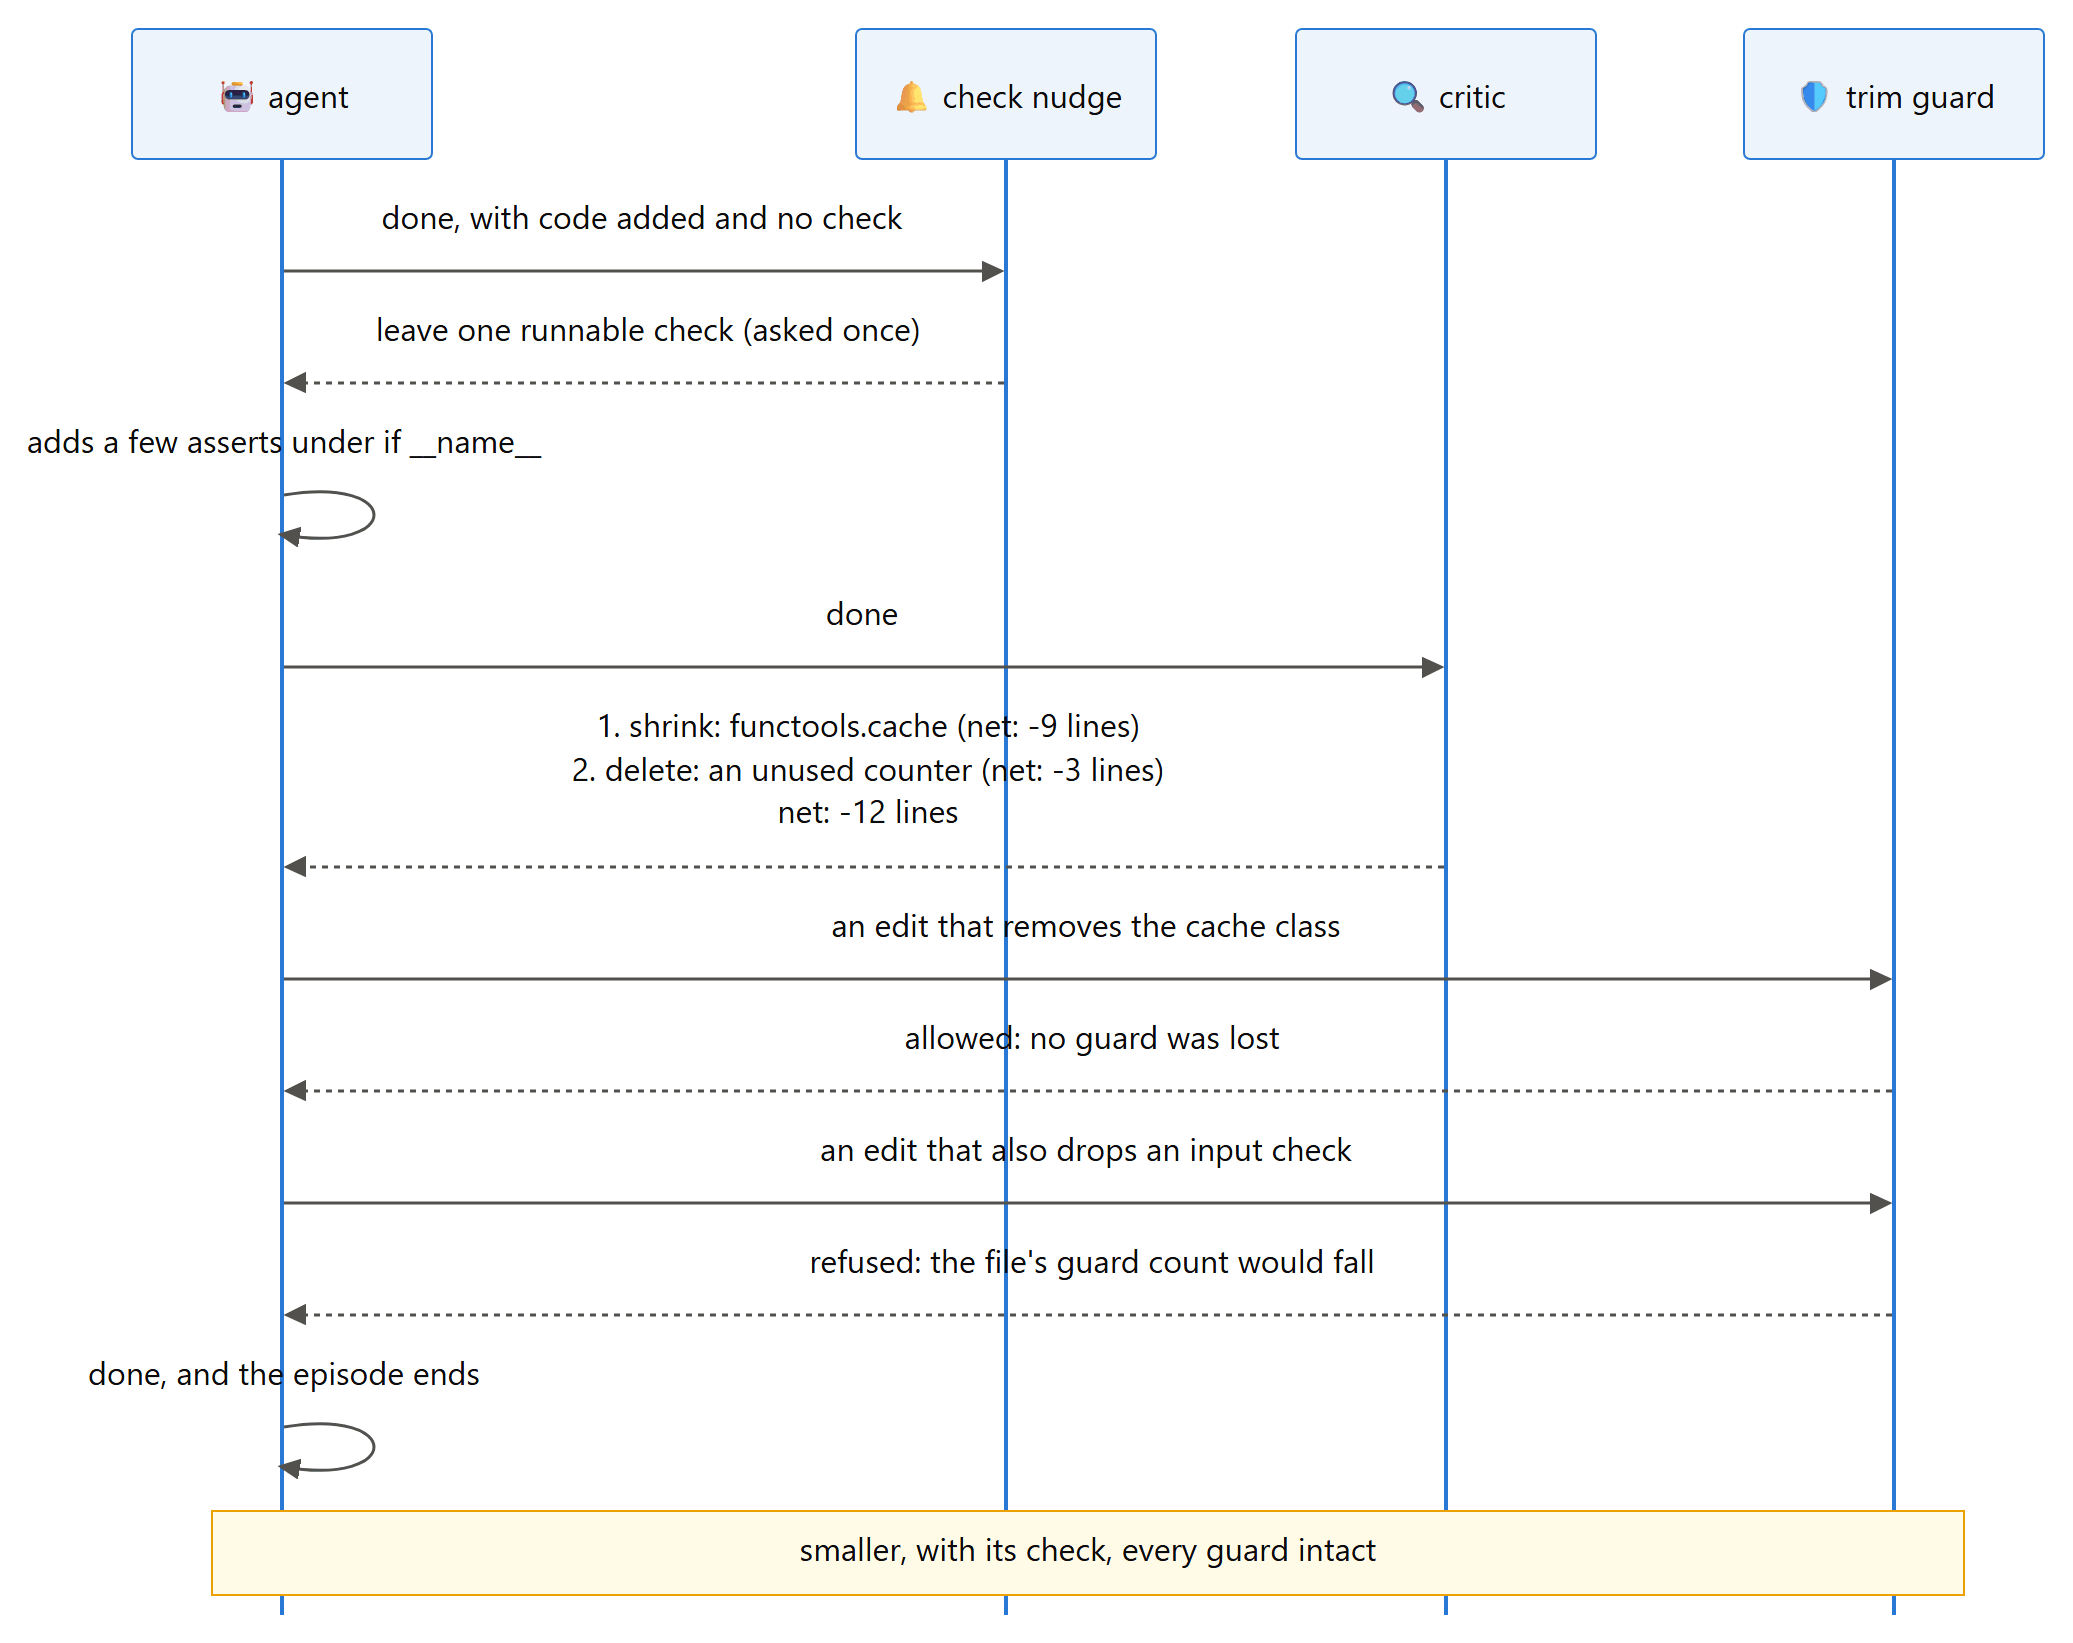

**`SKILL_TEXTS`** holds the six skills as data: `lean` itself and the five a user calls by name. For each name it gives the trigger description the model sees in the skills index, the mode, an argument hint and the body. Only two bodies are written out, `lean-review` and `lean-audit`, because those are the only skills a model runs: `lean` takes its body from the ruleset, and the other three are commands that need no model. The review body carries the three protections above: complexity is the only scope, the check and the guards are off limits, and findings are flat statements in a fixed form that ends with a net line count.

In [587]:
SKILL_TEXTS = {
    "lean": ("Use for every request that writes, changes, fixes or removes code, however small. "
             "Do not use for questions, explanations or writing that is not code.", "persistent", "", None),
    "lean-review": ("Use when asked to review code or a change for unnecessary complexity, and before finishing a change. "
                    "Not for correctness, security or style reviews.", "one-shot", "[the change to review]", """
Review the change for code it did not need. Scope: complexity only. Correctness, security and style are out of scope, and so is the one runnable check: never suggest removing it, and never suggest removing a guard (input checks, error handling that prevents data loss, security checks, accessibility).

List findings as numbered lines, most valuable first, each in this form:
N. tag: file: what to remove or replace, and with what (net: -K lines)
Tags: delete (code nothing needs), stdlib (the standard library already does it), native (the platform does it), reuse (the project already has it), yagni (built for a need nobody has), shrink (the same behaviour in fewer lines).
State each finding flatly, as a fact with its replacement. Do not ask questions and do not hedge.
End with one line: net: -N lines.
If nothing is worth removing, reply with exactly: Lean already. Ship."""),
    "lean-audit": ("Use when asked to audit a whole project for over-engineering: unused code, needless layers, "
                   "dependencies the standard library covers.", "one-shot", "[folder]", """
Audit the whole project for code it does not need. Look for: packages the standard library or the platform already covers; an abstract class with one subclass; a factory that makes one thing; a settings class for values that never change; functions that only call another function; hand-written versions of standard-library functions; duplicate helpers; modules nothing imports; flags nothing turns on; retries around calls that cannot fail transiently; parameters nobody passes; thread or process pools for work that does no I/O.

Before you list anything for deletion, search the whole tree for it, tests included, and remember that code can be reached by a name built at run time (getattr, importlib, a lookup table). If you find any reference, it is not dead.

List findings as numbered lines, biggest cut first:
N. tag: file: symbol: what to do (net: -K lines)
Use the tags delete, stdlib, native, reuse, yagni, shrink. End with: net: -N lines, -M dependencies."""),
    "lean-debt": ("Use when asked what shortcuts or deferred work the code is carrying.", "one-shot", "", None),
    "lean-gain": ("Use when asked how much the system has helped, in measured numbers.", "one-shot", "", None),
    "lean-help": ("Use when asked how to use the system.", "one-shot", "", None),
}
print(f"[skills] {len(SKILL_TEXTS)} skills: {', '.join(SKILL_TEXTS)}")

[skills] 6 skills: lean, lean-review, lean-audit, lean-debt, lean-gain, lean-help


**`write_skills(folder=SKILLS_DIR)`** turns that table into files, one `SKILL.md` per skill with the header Part III's loader expects, and then loads the folder back through the same `SkillRegistry` any user's skills go through. Writing real files and reading them back means the skills the experiments use are exactly the files a user would install, parsed by the same code. A skill with no body of its own gets a one-line note saying which command runs it.

In [588]:
def write_skills(folder=SKILLS_DIR):
    """Write each skill as a SKILL.md: the header, then the body (or a note that a command runs it)."""
    for name, (description, mode, hint, body) in SKILL_TEXTS.items():
        if name == "lean":
            body = ruleset("full")                            # the main skill is the ruleset itself: one copy of the words
        else:
            body = body or f"Run by the /{name} command; no model is needed."   # no body of its own: a command runs it
        (Path(folder) / name).mkdir(parents=True, exist_ok=True)   # one folder per skill, as the loader expects
        header = f"---\nname: {name}\ndescription: {description}\nmode: {mode}\n"   # the header the loader reads
        if hint:
            header += f"argument-hint: {hint}\n"              # only a skill that takes an argument says what it is
        (Path(folder) / name / "SKILL.md").write_text(header + f"---\n{body.strip()}\n", encoding="utf-8")   # close it, then the body
    return SkillRegistry().load(folder, namespace=SYSTEM_NAME)   # read back by the host's own loader

show_def(write_skills, layer="plugin")

[def] write_skills(folder=WindowsPath('<project>/skills'))  13 lines, complexity 5


In [589]:
LEAN_SKILLS = write_skills()                                  # written to skills/ and loaded back
for s in LEAN_SKILLS.skills.values():
    print(f"[skill] {s.name:<12} {s.mode:<10} {tokens_of(s.body):>4} tokens  {textwrap.shorten(s.description, 84)}")

[skill] lean         persistent  986 tokens  Use for every request that writes, changes, fixes or removes code, however [...]
[skill] lean-audit   one-shot    241 tokens  Use when asked to audit a whole project for over-engineering: unused code, [...]
[skill] lean-debt    one-shot     12 tokens  Use when asked what shortcuts or deferred work the code is carrying.
[skill] lean-gain    one-shot     12 tokens  Use when asked how much the system has helped, in measured numbers.
[skill] lean-help    one-shot     12 tokens  Use when asked how to use the system.
[skill] lean-review  one-shot    219 tokens  Use when asked to review code or a change for unnecessary complexity, and [...]


Two regular expressions read the critic's replies. **`FINDING`** matches one numbered finding in the form the review skill asks for, `N. tag: text`, and captures the number, the tag and the rest; a line in any other shape is not a finding. **`HEDGE`** spots a hedged finding (a question mark, or words such as *consider* and *maybe*), which the measurement below counts, because a finding phrased as a question invites keeping everything.

In [590]:
# "2. shrink: geo.py: ..." gives (number, tag, the rest); a tag outside the six is not a finding
FINDING = re.compile(r"^\s*(\d+)[.)]\s*(delete|stdlib|native|reuse|yagni|shrink)\s*:\s*(.+?)\s*$", re.I)
# a question mark, or one of the phrases that turn a finding into a suggestion
HEDGE = re.compile(r"\?|\b(consider|maybe|perhaps|might want|could you|you may want)\b", re.I)
print(f"[critic] {FINDING.match('2. shrink: geo.py: replace the dict cache with functools.cache (net: -5 lines)').groups()}")
print(f"[critic] hedged: {bool(HEDGE.search('Could the cache be simpler?'))} and "
      f"{bool(HEDGE.search('delete: geo.py: remove the unused counter (net: -3 lines)'))}")

[critic] ('2', 'shrink', 'geo.py: replace the dict cache with functools.cache (net: -5 lines)')
[critic] hedged: True and False


**`parse_findings(text)`** turns a review into a list of `(number, tag, text)` tuples, one per line that matches `FINDING`, with the tag in lower case. Everything else in the reply is ignored, the closing `net:` line included, and the verdict *Lean already. Ship.* parses as an empty list, which is how the critic's caller knows there is nothing to pass on.

In [591]:
def parse_findings(text):
    """[(number, tag, text)] from a review; [] for 'Lean already. Ship.'"""
    found = []
    for line in (text or "").splitlines():                    # no reply at all reads as no findings
        m = FINDING.match(line)                               # None for a line that is not a finding
        if m:
            found.append((int(m.group(1)), m.group(2).lower(), m.group(3)))   # the number as an int, the tag in lower case
    return found

show_def(parse_findings, layer="plugin")

[def] parse_findings(text)  8 lines, complexity 4


In [592]:
sample_review = ("1. shrink: geo.py: replace the dict cache with functools.cache (net: -5 lines)\n"
                 "2) delete: geo.py: remove the unused statistics counter (net: -3 lines)\n"
                 "Could the cache be simpler?\n"
                 "net: -8 lines")
print(f"[critic] {parse_findings(sample_review)}")
print(f"[critic] 'Lean already. Ship.' parses as {parse_findings('Lean already. Ship.')}")

[critic] [(1, 'shrink', 'geo.py: replace the dict cache with functools.cache (net: -5 lines)'), (2, 'delete', 'geo.py: remove the unused statistics counter (net: -3 lines)')]
[critic] 'Lean already. Ship.' parses as []


**`change_diff(seed, final, limit=4000)`** is what the critic is shown: a unified diff of every non-test Python file the change touched, with two lines of context, in path order. Test files are left out, since the check is off limits to the critic in any case. The text is capped at `limit` characters and marked when it is cut, so one sprawling change cannot make the review call arbitrarily large.

In [593]:
def change_diff(seed, final, limit=4000):
    """A unified diff of every non-test Python file the change touched."""
    out = []                                                  # diff lines from every file, one file after another
    for path in sorted(final):                                # path order, so the same change gives the same diff
        if path.endswith(".py") and final[path] != seed.get(path) and not is_test_file(path):
            # a new file is diffed against nothing, so every line shows as added
            out += difflib.unified_diff(seed.get(path, "").splitlines(), final[path].splitlines(),
                                        f"a/{path}", f"b/{path}", lineterm="", n=2)
    text = "\n".join(out)
    if len(text) <= limit:                                    # most changes fit whole
        return text
    return text[:limit] + "\n(diff truncated)"

show_def(change_diff, layer="plugin")

[def] change_diff(seed, final, limit=4000)  11 lines, complexity 6


In [594]:
diff_demo_task = SUITE["ob-postcode-cache"]
print(change_diff(diff_demo_task.seed, snapshot(WS_DIR / "ob-postcode-cache-good")))   # the good answer, as Part II laid it out

--- a/geo.py
+++ b/geo.py
@@ -1,2 +1,4 @@
+from functools import cache
+
 import register
 
@@ -7,4 +9,5 @@
 
 
+@cache
 def lookup_district(postcode):
     """Return the district for a postcode, or None if the register does not know it."""


**`review(llm, diff, replica=0)`** is the critic's one model call. The system message is the review skill's body followed by the compact copy of the rules, the user message is the diff, and the call goes to the fast model. Thinking is switched off wherever the S12 probe showed that works, because a review is a short answer that does not need it. The function returns the reply's text and nothing else; reading it is `parse_findings`' job.

In [595]:
def review(llm, diff, replica=0):
    """One critic call: the review skill, the compact rules, the diff. A review is a short
    answer, so the model's thinking is switched off wherever the S12 probe showed that works."""
    system = LEAN_SKILLS.skills["lean-review"].body + "\n\n" + ruleset("full", core_only=True)   # the skill, then the rules
    extra = {}                                                # no extra parameter unless the probe allows one
    if "thinking off" in CAN.get(MODEL_FOR["fast"], ()):
        extra = {"enable_thinking": False}                    # only for a model whose probe passed
    messages = [{"role": "system", "content": system},        # one system message, as the host always sends
                {"role": "user", "content": f"The change:\n{diff}"}]
    r = llm.chat(MODEL_FOR["fast"], messages, tag="critic", replica=replica,      # through the ledger, like every call
                 temperature=TEMPERATURE, top_p=TOP_P, max_tokens=4000, **extra)
    return r.text.strip()

show_def(review, layer="plugin")

[def] review(llm, diff, replica=0)  12 lines, complexity 2


**`_scripted_critic(model, messages, params)`** stands in for the critic in smoke runs. It recognises a review by the opening words of the review skill and counts the lines the diff adds: six or fewer get the exact verdict *Lean already. Ship.*, and anything larger gets two fixed findings in the required form.

In [596]:
@SCRIPTED.register
def _scripted_critic(model, messages, params):
    if not messages[0]["content"].lstrip().startswith("Review the change"):   # not a review: another responder answers
        return None
    diff = messages[-1]["content"]                            # the user turn: "The change:" and the diff
    added = sum(1 for line in diff.splitlines() if line.startswith("+") and not line.startswith("+++"))   # file headers aside
    if added <= 6:                                            # a small change passes as it is
        return "Lean already. Ship."
    return ("1. shrink: the changed file: replace the hand-written cache class with functools.cache (net: -9 lines)\n"
            "2. delete: the changed file: remove the unused statistics counter (net: -3 lines)\nnet: -12 lines")

show_def(_scripted_critic)

[def] _scripted_critic(model, messages, params)  10 lines, complexity 5


The critic is measured on six changes, a good and a bloated answer to each of three tasks. For each review the table counts the findings, whether it said *Lean already*, how many findings were hedged, the lines the findings claim to save, and how many propose deleting something that looks like a guard.

In [597]:
rows = []
for task_id in ("ob-postcode-cache", "sf-share-link", "ob-member-unique"):
    t = SUITE[task_id]
    for ref in ("good", "bloated"):
        text = review(FRONT_DOOR, change_diff(t.seed, snapshot(WS_DIR / f"{t.id}-{ref}")))   # one critic call per answer
        found = parse_findings(text)
        # deletions whose text names something guard-like: what the trim guard is there for
        guard_cuts = [f for f in found if re.search(r"\b(guard|validat|escap|check|compare_digest|constraint)", f[2], re.I)
                      and f[1] == "delete"]
        all_findings = "\n".join(f[2] for f in found)
        rows.append({"task": task_id, "answer": ref, "findings": len(found),
                     "lean already": "yes" if "Lean already" in text else "no",
                     "hedged": sum(bool(HEDGE.search(f[2])) for f in found),                    # phrased as suggestions
                     "claimed net": sum(int(x) for x in re.findall(r"net:\s*-(\d+)", all_findings)),   # lines they say go
                     "touches a guard": len(guard_cuts),
                     "first finding": textwrap.shorten(plain(found[0][2]), 70) if found else "-"})
print(f"[critic] {len(rows)} reviews")

[critic] 6 reviews

In [598]:
table(rows, [("task", "task", ""), ("answer", "answer", ""), ("findings", "findings", "d"), ("lean already", "lean already", ""),
             ("hedged", "hedged", "d"), ("claimed net", "net lines", "d"), ("touches a guard", "guard deletions", "d"),
             ("first finding", "first finding", "")])
save_exp("critic", {"rows": rows})

  task               answer   findings  lean already  hedged  net lines  guard deletions  first finding
  --------------------------------------------------------------------------------------------------------------------------------------------------------------
  ob-postcode-cache  good            1  no                 0          2                0  geo.py: the `@cache` decorator and its import - `postcode` is an [...]
  ob-postcode-cache  bloated         4  no                 0         42                0  `enable_stats` flag and the two counter attributes - no caller [...]
  sf-share-link      good            1  yes                0          0                0  sharing/links.py: remove the `int(expires_at)` conversion and [...]
  sf-share-link      bloated         4  no                 0         16                0  sharing/links.py: remove the `ShareLinkService` class and its [...]
  ob-member-unique   good            0  yes                0          0                0  -
  ob-me

**`accept_trim(task, before, after, ws)`** is the test a trim must pass, in two parts: no source file may end up with fewer guard signatures than it started with, and the project's visible test must still pass. Both are needed, and the demonstration below shows why the guard count carries the weight: deleting the signature check from the good share-link answer leaves the visible test green. The function returns its verdict with the evidence, the files that lost guards and the test result, so a refusal can say what went wrong.

In [599]:
def accept_trim(task, before, after, ws):
    """A trim is accepted only if no file lost a guard and the visible test still passes."""
    lost = {}                                                 # file: (guards before, guards after)
    for p, s in after.items():
        if p.endswith(".py") and not is_test_file(p):         # source files only: a test is not a guard
            lost[p] = (sum(guard_signatures(before.get(p, "")).values()), sum(guard_signatures(s).values()))
    lost = {p: v for p, v in lost.items() if v[1] < v[0]}      # keep only the files whose count went down
    visible = run_fenced(ws, ["tests_visible.py"], timeout=60).returncode == 0   # the project's own test, fenced
    return (not lost and visible), lost, visible              # the verdict, then the evidence for it

show_def(accept_trim, layer="plugin")

[def] accept_trim(task, before, after, ws)  9 lines, complexity 6


The trim to test: the good share-link answer with its constant-time signature check deleted.

In [600]:
t = SUITE["sf-share-link"]
ws = materialise(t, WS_DIR / "trim-demo", "good")
before = snapshot(ws)
# the two lines that turn away a forged signature
trimmed = before["sharing/links.py"].replace("    if not hmac.compare_digest(signature, _sign(f\"{doc_id}.{expires_at}\", secret)):\n        return None\n", "")
(ws / "sharing" / "links.py").write_text(trimmed, encoding="utf-8")
print(f"[trim] links.py: {len(before['sharing/links.py'].splitlines())} lines before the trim, {len(trimmed.splitlines())} after")

[trim] links.py: 24 lines before the trim, 22 after


In [601]:
ok, lost, visible = accept_trim(t, before, snapshot(ws), ws)
print(f"[trim] deleting the signature check from the good share-link answer: accepted={ok}, guards lost={lost}, "
      f"visible test {'passed' if visible else 'failed'}")
print(f"  the visible test still passes, which is exactly why the guard count is the second condition; the hidden "
      f"test agrees: {score(t, ws, visible=False).short()}")

[trim] deleting the signature check from the good share-link answer: accepted=False, guards lost={'sharing/links.py': (2, 1)}, visible test passed
  the visible test still passes, which is exactly why the guard count is the second condition; the hidden test agrees: c1 s0


**`LeanCritic`** puts the review inside the agent's loop and then stands guard. Its one switch is the trim guard, which an ablation can turn off to see what the critic does without it (the third exercise at the end of this Part). Like the gates, it keeps its state on the host, under `critic`: whether this request has been reviewed, the findings, and the snapshot the review diffs against.

In [602]:
class LeanCritic:
    """The critic inside the loop: on the first done of each request, review what the request
    changed; afterwards, refuse any edit that lowers a file's guard count."""

    def __init__(self, trim_guard=True):
        self.trim_guard = trim_guard                          # off only for an ablation: nothing then stops a trim cutting a guard

show_def(LeanCritic, layer="plugin")

[class] LeanCritic(trim_guard=True)  5 lines, complexity 1


**`LeanCritic.install(host)`** registers three hooks. The one on `pre_tool` gets the same deadline as a model call instead of the bus's default of 50 milliseconds, because on the first `done` it waits for the review. With the default, any review that took longer than the bus's five-second hang limit would be abandoned and its findings lost.

In [603]:
@method_of(LeanCritic)
def install(self, host):
    host.bus.on("session_start", self.on_session_start, name="critic.session", priority=40)
    host.bus.on("user_prompt", self.on_user_prompt, name="critic.request", priority=40)
    # the review is a model call, so this hook gets a model call's deadline
    host.bus.on("pre_tool", self.on_pre_tool, name="critic.review", priority=40, budget_ms=CALL_DEADLINE_S["default"] * 1000)

show_def(LeanCritic.install, layer="plugin")

[def] LeanCritic.install(self, host)  5 lines, complexity 1


**`LeanCritic.on_session_start(host, source)`** creates the critic's state on a fresh start or after `/clear`, including the workspace snapshot that the review diffs against. Unlike the gates' hook it returns nothing, since the critic adds no text to the system message, and a compaction leaves its state as it was.

In [604]:
@method_of(LeanCritic)
def on_session_start(self, host, source, **_):
    if source in ("startup", "clear") or "critic" not in host.state:
        # reviewed: this request's one review has happened; seed: what the review diffs against
        host.state["critic"] = {"reviewed": False, "findings": [], "seed": snapshot(host.ws)}

show_def(LeanCritic.on_session_start, layer="plugin")

[def] LeanCritic.on_session_start(self, host, source, **_)  4 lines, complexity 3


**`LeanCritic.on_user_prompt(host)`** gives every new request its own review by resetting that state, baseline included. Without it, only the first ticket of a session would be reviewed, because the flag that marks the review as done would stay set until the session was cleared.

In [605]:
@method_of(LeanCritic)
def on_user_prompt(self, host, **_):
    if "critic" in host.state:                # a new request gets its own review
        host.state["critic"] = {"reviewed": False, "findings": [], "seed": snapshot(host.ws)}

show_def(LeanCritic.on_user_prompt, layer="plugin")

[def] LeanCritic.on_user_prompt(self, host, **_)  4 lines, complexity 2


**`LeanCritic.on_pre_tool(host, action, ws)`** does the critic's two jobs. On the first `done` of a request it diffs the workspace against the request's baseline, sends the diff to `review`, and if there are findings, holds the finish back once with up to six of them and the instruction to apply the ones the agent agrees with; a request that changed no Python source is not reviewed at all. From then on the trim guard is armed: any edit that replaces text and would lower the file's count of guard signatures is refused, whatever the review said.

In [606]:
@method_of(LeanCritic)
def on_pre_tool(self, host, action, ws, **_):
    st = host.state["critic"]                                 # this request's review state
    # the trim guard, armed once the review has happened
    if action.name == "edit" and st["reviewed"] and self.trim_guard:
        try:
            full = resolve_in(ws, action.args.get("path", ""))   # the host's path guard
        except ToolError:                                     # the path guard explains this one
            return None
        before = full.read_text(encoding="utf-8-sig") if full.is_file() else ""   # a new file starts empty
        old, new = action.args.get("old", ""), action.args.get("new", "")
        after = before.replace(old, new, 1) if old else ""    # the file as the edit would leave it
        # only a replacement can remove a guard: fewer signatures after it than before means one went
        if old and sum(guard_signatures(after).values()) < sum(guard_signatures(before).values()):
            return {"deny": "that edit removes a guard; the review may cut structure, never input checks, "
                            "error handling, security or accessibility"}
    # the review, once per request, on the first done
    if action.name == "done" and not st["reviewed"]:
        st["reviewed"] = True                                 # set first, so a failed or abandoned review is not retried
        diff = change_diff(st["seed"], snapshot(ws))          # everything this request changed
        if not diff:                                          # nothing changed, nothing to review
            return None
        reply = review(host.llm, diff, host.replica)          # the one model call the critic makes
        found = parse_findings(reply)                         # [] for "Lean already. Ship."
        st["findings"] = found                                # kept on the host for the trace
        if found:
            listing = "\n".join(f"{n}. {tag}: {text}" for n, tag, text in found[:6])   # at most six, numbered as the critic numbered them
            return {"deny": f"a review of your change suggests:\n{listing}\nApply the ones you agree with, then "
                            "finish. Never remove a guard or the check."}
    return None

show_def(LeanCritic.on_pre_tool, layer="plugin")

[def] LeanCritic.on_pre_tool(self, host, action, ws, **_)  27 lines, complexity 14


The trim guard can be tried without a model: mark the review as done, then offer two deletions from the good share-link answer, one of the signature check and one of a docstring.

In [607]:
critic_demo_ws = materialise(SUITE["sf-share-link"], RUNTIME / "demo" / "critic", "good")
critic_demo_host = Host(label="critic-demo")                  # a bare host; the review itself is never called here
critic_demo_host.start_session(critic_demo_ws)
demo_critic = LeanCritic()
demo_critic.on_session_start(critic_demo_host, "startup")
critic_demo_host.state["critic"]["reviewed"] = True           # as if the first done had been reviewed: the guard is armed
guard_cut = Action("edit", {"path": "sharing/links.py", "new": "",
                            "old": "    if not hmac.compare_digest(signature, _sign(f\"{doc_id}.{expires_at}\", secret)):\n"
                                   "        return None\n"})
docstring_cut = Action("edit", {"path": "sharing/links.py", "new": "",
                                "old": '    """Return the document id this token grants access to, or None if it is not valid."""\n'})
print(f"[critic] cutting the signature check: {demo_critic.on_pre_tool(critic_demo_host, guard_cut, critic_demo_ws)}")
print(f"[critic] cutting a docstring: {demo_critic.on_pre_tool(critic_demo_host, docstring_cut, critic_demo_ws)}")

[critic] cutting the signature check: {'deny': 'that edit removes a guard; the review may cut structure, never input checks, error handling, security or accessibility'}
[critic] cutting a docstring: None


## S51 - Choosing which findings to apply

**Theory.** A review that can only be accepted or rejected as a whole is a review people stop reading. Every finding is numbered so that a user (or the agent) can apply any subset: "fix 2 and 5" is the whole instruction. The widget below shows the critic's findings on the bloated postcode answer as checkboxes, and builds the instruction the agent would receive. The static print above it shows the same findings for readers whose viewer cannot run widgets. Whatever subset is chosen, the trim guard from S50 still stands between the instruction and the code.

**In plain terms.** Every suggestion has a number, and you pick the ones you want.

In [608]:
t = SUITE["ob-postcode-cache"]
review_text = review(FRONT_DOOR, change_diff(t.seed, snapshot(WS_DIR / f"{t.id}-bloated")))   # the critic on the bloated answer
FOUND = parse_findings(review_text)
print("[review] the critic on the bloated postcode answer:")
for n, tag, text in FOUND:
    print(f"  {n}. {tag}: {textwrap.shorten(plain(text), 110)}")
first_two = " and ".join(str(n) for n, _, _ in FOUND[:2])     # what a user would type to apply the first two
print(f"  ({len(FOUND)} findings; to apply some, the user types e.g. 'fix {first_two}')")

[review] the critic on the bloated postcode answer:
  1. yagni: `enable_stats` flag and the two counter attributes - no caller reads them; drop the parameter, the `if [...]
  2. delete: `CacheEntry` class - store `(value, stored_at)` tuples directly in `_entries`; eliminates a class and [...]
  3. stdlib: hand-rolled size eviction via `min(... key=...)` inside `put` - use `functools.lru_cache(maxsize=...)` [...]
  4. shrink: `clear()` method - never called anywhere in the diff; remove it (net: -3 lines)
  (4 findings; to apply some, the user types e.g. 'fix 1 and 2')


The same findings as checkboxes. Ticking or unticking one rebuilds the instruction the agent would receive.

In [609]:
W = widgets()                                                 # None in a headless run
if W:
    from IPython.display import display
    # one box per finding; the first two start ticked, as in the example above
    boxes = [W.Checkbox(value=i < 2, description=f"{n}. {tag}", indent=False) for i, (n, tag, _) in enumerate(FOUND)]
    instruction = W.Textarea(layout={"width": "100%", "height": "70px"})

    def _instruction(change=None):
        chosen = [str(n) for b, (n, _, _) in zip(boxes, FOUND) if b.value]   # the numbers of the ticked boxes
        if chosen:
            instruction.value = f"Apply review findings {' and '.join(chosen)} to this project. Never remove a guard."
        else:
            instruction.value = "(no findings chosen: nothing to apply)"

    for b in boxes:
        b.observe(_instruction, names="value")                # any change to a box rebuilds the text
    _instruction()                                            # once now, for the starting ticks
    display(W.VBox(boxes + [instruction]))
else:
    print("(no widget in this run, which needs a live Jupyter session; the list above is the whole story)")

(no widget in this run, which needs a live Jupyter session; the list above is the whole story)


## S52 - The audit, against a project with planted bloat

**Theory.** Reviewing one change is local; auditing a whole project is where over-engineering that has already shipped gets found. The `lean-audit` skill hunts for twelve kinds of bloat and ranks what it finds by the size of the cut. Measuring an audit needs ground truth, so the notebook carries a small invoicing project with **twelve known pieces of bloat**: an interface with one implementation, a factory with one product, a settings class for constants, a hand-written rounding function, a forwarding wrapper, `python-dateutil` for ISO dates, a duplicate helper, a dead module, a dead flag with its dead branch, a retry around a list append, an unused parameter and a thread pool for string formatting. It also carries **five decoys**, functions that look dead to a quick search but are used: two reached through `getattr` with a name built at run time, one loaded by `importlib` from a module name, one called through a lookup table, and one used only by the tests. The audit's findings are matched against the truth: **recall** is the share of the twelve it found, **precision** the share of its findings that are real, and a **false delete** is a finding that proposes deleting a decoy.

Then comes the safety net the audit skill itself asks for: *search before you delete*. `verify_delete` searches the whole tree, tests included, for any reference to a symbol outside its own definition. That catches three of the decoys. It cannot catch the fourth kind, a name assembled at run time (`f"to_{fmt}"`), because there is nothing to search for. So the second layer runs the project's tests on a copy with the symbol deleted, and only a delete that survives both is accepted.

**In plain terms.** We planted twelve bits of bloat and five traps in a small project, ask the audit to find the bloat, and check that nothing it wants deleted is secretly in use.

The planted project and its answer key live in `fixtures/`. **`AUDIT_TRUTH`** lists the twelve pieces of bloat, each with its file, the symbol that identifies it and the fix, and the five decoys with the way each one is reached.

In [610]:
AUDIT_DIR = ROOT / "fixtures" / "audit_project"                # the invoicing project with the bloat planted in it
AUDIT_TRUTH = json.loads((ROOT / "fixtures" / "audit_truth.json").read_text(encoding="utf-8"))   # its answer key
print(f"[audit] {rel(AUDIT_DIR)}: {len(AUDIT_TRUTH['bloat'])} pieces of planted bloat, {len(AUDIT_TRUTH['decoys'])} decoys")
for audit_item in AUDIT_TRUTH["bloat"]:
    print(f"  {audit_item['id']:>2}. {audit_item['symbol']:<20} {audit_item['kind']}")

[audit] fixtures/audit_project: 12 pieces of planted bloat, 5 decoys
   1. BaseInvoiceStore     an interface with one implementation
   2. StoreFactory         a factory with one product
   3. InvoiceSettings      a settings class for values that never change
   4. round_half_up        hand-rolled standard library
   5. _invoice_total       a function that only forwards
   6. isoparse             a dependency the standard library covers
   7. parse_issue_date     a duplicate helper
   8. export_legacy        a module nothing imports
   9. PDF_V2               a flag nothing turns on
  10. attempts             a retry around a call that cannot fail transiently
  11. verbose              a parameter nobody passes
  12. ThreadPoolExecutor   a thread pool for work that does no I/O


**`audit_findings_to_truth(found)`** scores an audit against the key by the symbols its findings name, matched as whole words. A finding that names a planted symbol is a hit, and two findings on the same piece count once. A finding that proposes *deleting* a decoy is a false delete, and one that names nothing in the key at all is unmatched, which counts against precision. The audit may describe a problem however it likes, but it has to point at the right code.

In [611]:
def audit_findings_to_truth(found):
    """Match findings to the planted bloat and the decoys by the symbols they name."""
    hits, decoys, unmatched = set(), [], []                   # bloat ids found, decoys proposed for deletion, misses
    for n, tag, text in found:
        # the planted pieces and the decoys this finding names
        bloat = [b["id"] for b in AUDIT_TRUTH["bloat"] if re.search(rf"\b{re.escape(b['symbol'])}\b", text)]
        decoy = [d["symbol"] for d in AUDIT_TRUTH["decoys"] if re.search(rf"\b{re.escape(d['symbol'])}\b", text)]
        hits.update(bloat)                                    # a set of ids: one piece found twice counts once
        if decoy and tag == "delete":
            decoys.append((n, decoy[0]))                      # only a proposed deletion of a decoy is a false delete
        if not bloat and not decoy:
            unmatched.append(n)                               # names nothing in the key
    return hits, decoys, unmatched

show_def(audit_findings_to_truth, layer="plugin")

[def] audit_findings_to_truth(found)  12 lines, complexity 8


In [612]:
example_findings = parse_findings("1. delete: invoicing/legacy_csv.py: export_legacy: nothing imports it (net: -8 lines)\n"
                                  "2. delete: invoicing/exporters.py: to_json: never called (net: -2 lines)\n"
                                  "3. shrink: app.py: tidy the start-up code (net: -3 lines)")
print(f"[audit] hits, false deletes, unmatched: {audit_findings_to_truth(example_findings)}")

[audit] hits, false deletes, unmatched: ({8}, [(2, 'to_json')], [3])


**`verify_delete(project, symbol)`** is the safety net for a proposed deletion, in two layers. The first is a whole-word search of every Python file, tests included, for the symbol anywhere except its own `def` or `class` line; any hit means it is still in use. The second runs only when the search finds nothing: a copy of the project is written with the definition cut out, and the project's tests run on the copy inside the fence. A delete is allowed only when both layers agree, and the reason says which layer decided.

In [613]:
def verify_delete(project, symbol):
    """(safe, reason). Layer 1: no reference to the symbol outside its definition anywhere in the
    tree, tests included. Layer 2: the tests still pass on a copy with the definition removed."""
    files = snapshot(project)                                 # every text file, tests included
    refs = []                                                 # file:line of every mention
    for p, s in files.items():
        if not p.endswith(".py"):
            continue
        for i, line in enumerate(s.splitlines(), 1):
            mentions = re.search(rf"\b{re.escape(symbol)}\b", line)                    # the name, as a whole word
            defines = re.match(rf"\s*(def|class)\s+{re.escape(symbol)}\b", line)       # its own def or class line
            if mentions and not defines:
                refs.append(f"{p}:{i}")
    if refs:
        return False, f"still referenced at {', '.join(refs[:2])}"   # layer 1 is enough to say no
    # layer 2: a copy of the project with the definition cut out
    scratch = write_files(files, RUNTIME / "audit-verify" / symbol)
    for p, s in files.items():
        tree = _safe_parse(s) if p.endswith(".py") else None
        if tree is None:
            continue
        for node in tree.body:                                # only a top-level def or class is cut
            if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name == symbol:
                lines = s.splitlines()
                del lines[node.lineno - 1:node.end_lineno]    # from its def line to its last line
                (scratch / p).write_text("\n".join(lines) + "\n", encoding="utf-8")   # the copy, without it
    tests = run_fenced(scratch, ["-m", "tests.test_invoicing"], timeout=60)   # the project's own tests, fenced
    passed = tests.returncode == 0
    return (passed, "the tests pass without it" if passed else "the tests fail without it")

show_def(verify_delete, layer="plugin")

[def] verify_delete(project, symbol)  28 lines, complexity 14


Each decoy goes through the net, and so does one symbol that really is dead, as a control that a true delete still gets through.

In [614]:
rows = []
for d in AUDIT_TRUTH["decoys"] + [{"symbol": "parse_issue_date", "why": "truly dead: a duplicate nothing calls"}]:
    safe, why = verify_delete(AUDIT_DIR, d["symbol"])
    rows.append({"symbol": d["symbol"], "how it is reached": d["why"][:58],
                 "delete allowed": "yes" if safe else "no", "because": why})
table(rows, [("symbol", "symbol", ""), ("how it is reached", "how it is reached", ""), ("delete allowed", "delete allowed", ""),
             ("because", "because", "")])

  symbol            how it is reached                                           delete allowed  because
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------------
  to_csv            called through getattr with a name built at run time; only  no              the tests fail without it
  to_json           called through getattr with a name built at run time        yes             the tests pass without it
  on_issue          loaded by importlib from a module name in app.py            no              still referenced at app.py:20
  shout             called through a globals() lookup from the FILTERS table    no              still referenced at invoicing/templates.py:1
  is_balanced       used only by the test suite                                 no              still referenced at tests/test_invoicing.py:3, tests/test_invoicing.py:12
  parse_issue_date  truly dead: a duplicate n

In [615]:
VERIFY = {r["symbol"]: r["delete allowed"] == "yes" for r in rows}   # symbol: was the delete allowed
results = []
expect("a search catches the decoys named somewhere in the tree", not any(VERIFY[s] for s in ("on_issue", "shout", "is_balanced")))
expect("the tests catch the run-time name the tests exercise (to_csv)", not VERIFY["to_csv"])
expect("the truly dead duplicate may go", VERIFY["parse_issue_date"])
missed_decoys = [s for s, ok in VERIFY.items() if ok and s != 'parse_issue_date']   # allowed, yet not dead
print(f"\n  not caught by either layer: {missed_decoys or 'none'}: reached by a name built at run time, on a path no test covers")

  PASSED  a search catches the decoys named somewhere in the tree
  PASSED  the tests catch the run-time name the tests exercise (to_csv)
  PASSED  the truly dead duplicate may go

  not caught by either layer: ['to_json']: reached by a name built at run time, on a path no test covers


**`_scripted_auditor(model, messages, params)`** answers the audit in smoke runs. It replies only to the first turn of a request that carries the audit instruction, with three findings chosen to exercise the scoring: two real pieces of bloat and a proposed deletion of the `to_csv` decoy.

In [616]:
@SCRIPTED.register
def _scripted_auditor(model, messages, params):
    last = messages[-1]                                       # the newest message in the conversation
    is_audit_request = "Audit the whole project" in last["content"] and last["role"] == "user"
    if not is_audit_request or len(messages) > 2:             # only the opening turn of an audit gets this answer
        return None
    return ("<done>1. delete: invoicing/legacy_csv.py: export_legacy: nothing imports this module (net: -8 lines)\n"
            "2. yagni: invoicing/store.py: StoreFactory: one product (net: -7 lines)\n"
            "3. delete: invoicing/exporters.py: to_csv: never called (net: -2 lines)\n"
            "net: -17 lines, -0 dependencies</done>")

show_def(_scripted_auditor)

[def] _scripted_auditor(model, messages, params)  10 lines, complexity 4


The audit itself runs as a read-only helper on a copy of the project, with the coder model and thirty turns, so it can read the whole project before it answers.

In [617]:
audit_ws = write_files(snapshot(AUDIT_DIR), RUNTIME / "audit-run")   # a copy, so the fixture is never touched
h = Host(label="audit")                                       # no plugins: the audit skill is the whole instruction
h.start_session(audit_ws)
res, _ = h.subagent("auditor", LEAN_SKILLS.skills["lean-audit"].body.strip() + "\n\nAudit the whole project.", audit_ws,
                    max_turns=30, model=MODEL_FOR["coder"])
AUDIT_FOUND = parse_findings(res.done_text)
print(f"[audit] {len(res.turns)} turns, stop: {res.stop}; {len(AUDIT_FOUND)} findings")
for n, tag, text in AUDIT_FOUND:
    print(f"  {n}. {tag}: {textwrap.shorten(plain(text), 108)}")

[audit] 31 turns, stop: out of turns, then answered; 10 findings
  1. delete: invoicing/send.py: send: drop the retry loop, `time` import, `_deliver`, and the `attempts` param - [...]
  2. yagni: invoicing/models.py: BaseInvoiceStore: abstract class with exactly one subclass (MemoryInvoiceStore); [...]
  3. delete: invoicing/legacy_csv.py: export_legacy: module nothing imports anywhere (verified tree-wide, tests [...]
  4. stdlib: invoicing/totals.py: round_half_up: hand-written version of `Decimal.quantize(Decimal("0.01"), [...]
  5. yagni: invoicing/store.py: StoreFactory: factory that makes one thing (MemoryInvoiceStore); `kind` param [...]
  6. yagni: invoicing/settings.py: InvoiceSettings/SETTINGS: settings class for values that never change; only [...]
  7. delete: invoicing/flags.py: PDF_V2: flag nothing turns on (always False); also delete the branch in render.py [...]
  8. reuse: invoicing/totals.py: invoice_total: function that only calls `_invoice_total`; merge the two (net:

Scored against the key, with every proposed deletion of a decoy put through the two-layer check:

In [618]:
hits, decoy_deletes, unmatched = audit_findings_to_truth(AUDIT_FOUND)
verified = [(n, sym) for n, sym in decoy_deletes if verify_delete(AUDIT_DIR, sym)[0]]   # false deletes the net would let through
recall = len(hits) / len(AUDIT_TRUTH["bloat"])                # the share of the twelve planted pieces found
precision = 0.0                                               # no findings at all scores nothing
if AUDIT_FOUND:
    # a finding is real unless it names nothing in the key or proposes deleting a decoy
    precision = (len(AUDIT_FOUND) - len(unmatched) - len(decoy_deletes)) / len(AUDIT_FOUND)
print(f"[audit] recall {recall:.0%} ({len(hits)} of {len(AUDIT_TRUTH['bloat'])} planted items), precision {precision:.0%}")
print(f"  proposed deletions of decoys: {len(decoy_deletes)} {decoy_deletes or ''}; after verification: {len(verified)}")
save_exp("audit", {"findings": len(AUDIT_FOUND), "found": len(hits), "planted": len(AUDIT_TRUTH["bloat"]),
                   "recall": recall, "precision": precision, "decoy_deletes": len(decoy_deletes),
                   "decoy_deletes_verified": len(verified), "turns": len(res.turns)})

[audit] recall 100% (12 of 12 planted items), precision 100%
  proposed deletions of decoys: 0 ; after verification: 0
[exp] artifacts/exp_audit.json


## S53 to S55 - Debt, gain and help

**Theory.** Three skills need no model at all, so they run as commands and cost no tokens. **Debt** (`/lean-debt`) collects every shortcut marker in the code and every `left out:` line in the agent's answers into one ledger, and flags any entry without a condition for revisiting it. A deferral without a trigger is how "later" quietly becomes "never", and the flag exists to stop that. **Gain** (`/lean-gain`) reports what the lab has measured, and only that: it reads the experiment records and refuses to promise anything about a particular repository, because the defensible claim is "on this suite, with these models", not "on your code". **Help** (`/lean-help`) is generated from the command table and the skill registry, so it cannot describe a command that does not exist or miss one that does; a parity test checks both directions.

**In plain terms.** Three commands that only read: what corners were cut, what the measurements say, and how to use the system.

**`debt_ledger(workspaces, answers)`** gathers deferred work from both places it is written down. In the code it collects every shortcut marker with Part IV's `find_markers`; in the agents' final answers, every line that starts with `left out`, read with the `LEFT_OUT` pattern from the output contract. Each entry is flagged under `no trigger` when it has no condition for coming back to it: a marker without its *upgrade when* part, or a `left out:` line without *build it when*.

In [619]:
def debt_ledger(workspaces, answers):
    """Every shortcut marker in the code and every 'left out' line in the answers, with a flag
    for entries that have no condition for coming back to them."""
    rows = []                                                 # one row per piece of deferred work
    for ws in workspaces:
        py_files = {p: s for p, s in snapshot(ws).items() if p.endswith(".py")}   # markers live in Python files
        for m in find_markers(py_files):                      # well formed or not
            rows.append({"where": f"{Path(ws).name}/{m['file']}:{m['line']}", "kind": "shortcut",
                         "what": m["limit"] or "(unreadable marker)", "when": m["when"] or "-",
                         "no trigger": "YES" if not m["when"] else ""})        # a marker with no 'upgrade when'
    for label, text in answers:
        for line in (text or "").splitlines():                # an episode with no answer has no lines
            if not line.strip().lower().startswith("left out"):   # only deferral lines, in any case
                continue
            m = LEFT_OUT.match(line)                          # None when the line has no "(build it when ...)"
            if m:
                what, when, no_trigger = m.group(1), m.group(2), ""
            else:
                what, when, no_trigger = line.strip(), "-", "YES"
            rows.append({"where": label, "kind": "left out", "what": what[:46], "when": when, "no trigger": no_trigger})
    return rows

show_def(debt_ledger, layer="plugin")

[def] debt_ledger(workspaces, answers)  21 lines, complexity 12


The ledger over every episode Part IV ran, plus one made-up answer so that both kinds of `left out:` line appear:

In [620]:
part4_workspaces = [EPISODES_DIR / ep.arm / f"{ep.task}-r0" for ep in PART4_EPISODES]   # where each episode worked
part4_answers = [(f"{ep.arm}:{ep.task}", ep.done_text) for ep in PART4_EPISODES]       # and what it said at the end
ledger_rows = debt_ledger(part4_workspaces, part4_answers)
demo_rows = debt_ledger([], [("example", "step 3: functools.cache\nleft out: cache clearing (build it when the register "
                                         "changes)\nleft out: eviction, maybe later")])
table((ledger_rows + demo_rows)[:12], [("where", "where", ""), ("kind", "kind", ""), ("what", "what", ""), ("when", "come back when", ""),
                                      ("no trigger", "no trigger", "")])

  where    kind      what                             come back when        no trigger
  ------------------------------------------------------------------------------------
  example  left out  cache clearing                   the register changes  -
  example  left out  left out: eviction, maybe later  -                     YES


**`gain_report()`** is the honest version of a usage report. It reads the experiment records and repeats only what they contain: the baseline's pass count and median code ratio, and the full system's headline from Part VII once that exists, or a plain statement that it does not yet. The last line states the boundary of the claim, because a number measured on this notebook's tasks and models promises nothing about someone else's repository.

In [621]:
def gain_report():
    """Only what has been measured, with the boundary of the claim stated."""
    base = load_exp("baseline") or {}                         # {} before the baseline exists: counts print as '?', the ratio as nan
    main = load_exp("main")                                   # None until Part VII has run
    # the baseline, exactly as its record states it
    lines = [f"baseline (no plugin, one run per task): {base.get('passed', '?')}/{base.get('episodes', '?')} tasks passed, "
             f"a median {base.get('median_ratio') or float('nan'):.1f}x the code the tasks needed"]
    if main and "summary" in main:
        lines.append(f"full system vs baseline: {main['summary']}")   # Part VII's headline, once it has run
    else:
        lines.append("full system vs baseline: not measured yet in this run (Part VII)")
    # the boundary of the claim, always the last line
    lines.append("These numbers are from this notebook's 34 tasks and the models named in S0. "
                 "They are not a prediction for your repository.")
    return "\n".join(lines)

show_def(gain_report, layer="plugin")

[def] gain_report()  13 lines, complexity 5


In [622]:
print("[gain]\n" + textwrap.indent(gain_report(), "  "))

[gain]
  baseline (no plugin, one run per task): 32/34 tasks passed, a median 1.5x the code the tasks needed
  full system vs baseline: code ratio 0.88 (0.68 to 1.00) on held-out tasks; safety +0%; completeness +0%
  These numbers are from this notebook's 34 tasks and the models named in S0. They are not a prediction for your repository.


**`help_card(host)`** builds the help text from the host's command table and skill registry instead of from a hand-written list, so it cannot drift: every command and skill that exists is listed, and nothing that does not exist can be. S56 checks both directions.

In [623]:
def help_card(host):
    lines = [f"/{name}: {text}" for name, (_, text) in sorted(host.commands.table.items())]   # commands, by name
    lines += [f"/{s.name}: {s.description}" for s in sorted(host.skills.skills.values(), key=lambda s: s.name)]   # then skills
    return "\n".join(lines)

show_def(help_card, layer="plugin")

[def] help_card(host)  4 lines, complexity 3


In [624]:
print(textwrap.indent(help_card(Host(label="help-demo")), "  "))   # a bare host: only the host's own three commands

  /clear: start the session again in the same workspace
  /compact: summarise the conversation now
  /help: list commands and skills


## S56 - The assembled system, one complete trace

**Theory.** Here everything runs together for the first time: the rules delivered by hooks (Part V), the map and the gates, the critic with its trim guard, and the skills registered on the host. The trace below prints how often each hook ran and its slowest call, every turn with what the agent did and whether a gate refused it, each time a gate fired, the critic's findings, and the score. It is one episode on one dev task, chosen because it exercises the gates, and it is the shape of every episode of the `full` arm in Part VII.

**In plain terms.** The whole system, start to finish, on one ticket, with nothing hidden.

**`LeanSkills`** is the last plugin and the smallest. It puts the two skills a model runs, `lean-review` and `lean-audit`, into the host's registry, so they appear in the skills index, and registers the three model-free skills as commands: `/lean-debt` over the current workspace, `/lean-gain` and `/lean-help`. The host answers commands itself, so these three never cost a token.

In [625]:
class LeanSkills:
    """Registers the skills and the read-only commands on the host."""

    def install(self, host):
        for name in ("lean-review", "lean-audit"):              # the rest are commands, or the /lean command itself
            host.skills.skills[name] = LEAN_SKILLS.skills[name]

        def debt_command(host, _args):                        # a command gets (host, args); this one takes no arguments
            # one line per shortcut marker in this workspace's code
            entries = [f"{r['where']}: {r['what']} (come back when {r['when']})" for r in debt_ledger([host.ws], [])]
            return "\n".join(entries) or "no debt recorded"

        host.commands.register(f"{CMD}-debt", debt_command, "list shortcuts and deferred work")
        host.commands.register(f"{CMD}-gain", lambda host, args: gain_report(), "what the lab has measured")   # from the records
        host.commands.register(f"{CMD}-help", lambda host, args: help_card(host), "this card")   # from the tables, so it cannot drift

show_def(LeanSkills, layer="plugin")

[class] LeanSkills()  11 lines, complexity 4


**`full_system(level="full", **off)`** assembles the full arm: the rules plugin from Part V, the gates, the critic and the skills, in that order. Every piece is on by default, and each keyword names a piece to switch off, so `full_system(critic=True)` is the full system without its critic. That one convention is what Part VII's ablations of the machinery rest on: each is this function called with one name.

In [626]:
def full_system(level="full", **off):
    """Every plugin of the full arm. Part VII's ablations switch single pieces off by name."""
    # each keyword names a piece to switch off, so the default is everything on
    rules = LeanPlugin(level=level, header=not off.get("header"), reinject_on_compact=not off.get("reinject"),
                       subagents=not off.get("subagent_rules"))
    gates = LeanGates(project_map=not off.get("map"), read_gate=not off.get("read_gate"), siblings=not off.get("siblings"),
                      deps=not off.get("deps"), check_nudge=not off.get("nudge"))
    plugins = [rules, gates]                                  # the order the full arm installs them in
    if not off.get("critic"):                                 # without its critic, the arm has no critic object at all
        plugins.append(LeanCritic())
    plugins.append(LeanSkills())                              # the skills are never switched off
    return plugins

show_def(full_system, layer="plugin")

[def] full_system(level='full', **off)  11 lines, complexity 2


Built with every plugin, the host's help card must name exactly the commands and skills that exist. The check compares the two sets in both directions.

In [627]:
h = Host(plugins=full_system(), label="full")
results = []
cmds = {n for n in h.commands.table} | {s for s in h.skills.skills}                     # what exists
card_names = {re.match(r"/([\w-]+)", l).group(1) for l in help_card(h).splitlines()}  # what the card says exists
expect("the help card names every command and skill, and nothing else", card_names == cmds)
print(textwrap.indent(help_card(h), "  "))

  PASSED  the help card names every command and skill, and nothing else
  /clear: start the session again in the same workspace
  /compact: summarise the conversation now
  /help: list commands and skills
  /lean: /lean [on|off|lite|full|ultra|status|default LEVEL]
  /lean-debt: list shortcuts and deferred work
  /lean-gain: what the lab has measured
  /lean-help: this card
  /lean-audit: Use when asked to audit a whole project for over-engineering: unused code, needless layers, dependencies the standard library covers.
  /lean-review: Use when asked to review code or a change for unnecessary complexity, and before finishing a change. Not for correctness, security or style reviews.


One episode of `rc-day-parse` under the full system. First, how the hooks saw it: how often each one ran, and its slowest call.

In [628]:
t = SUITE["rc-day-parse"]                                     # a dev task that exercises the gates
h = Host(plugins=full_system(), label="full")                 # the full arm, as Part VII runs it
ep = run_episode(t, h)                                        # one episode, start to finish
print(f"[trace] {t.id} under the full system\n")
print("  hook calls:")
hook_rows = Counter(x["hook"] for x in h.bus.trace)           # calls per hook
slowest = {x["hook"]: 0.0 for x in h.bus.trace}               # every hook starts at zero
for x in h.bus.trace:
    slowest[x["hook"]] = max(slowest[x["hook"]], x["ms"])     # the longest single call of each hook
for hook, n in sorted(hook_rows.items()):
    print(f"    {hook:<16} {n:>3} calls, slowest {slowest[hook]:8.1f} ms")
print()

[trace] rc-day-parse under the full system

  hook calls:
    critic.request     1 calls, slowest      2.8 ms
    critic.review     16 calls, slowest      4.5 ms
    critic.session     1 calls, slowest      3.6 ms
    gates.post        15 calls, slowest      9.5 ms
    gates.pre         16 calls, slowest      7.7 ms
    gates.request      1 calls, slowest      3.6 ms
    gates.session      1 calls, slowest     26.3 ms
    lean.prompt        1 calls, slowest      0.4 ms
    lean.session       1 calls, slowest      1.5 ms



Then the turns, every time a gate fired, and the critic's findings:

In [629]:
show_episode(ep)                                              # every turn, a refused one marked DENIED
for kind, where in h.state["gates"]["log"]:                   # each time a gate fired, and on which file
    print(f"  gate: {kind} {where}")
print(f"  critic findings: {h.state.get('critic', {}).get('findings') or 'none'}")

[episode] rc-day-parse  arm full  model Qwen3.8-27B  replica 0
   1  read  bookings/window.py               ok  notes    0c  reasoning    41c  tokens   1472+67      2.0s  ledger
   2  read  bookings/dates.py                ok  notes    0c  reasoning    73c  tokens   1676+31      6.2s  ledger
   3  ls    .                                ok  notes    0c  reasoning   298c  tokens   1783+104     3.6s  ledger
   4  read  tests_visible.py                 ok  notes    0c  reasoning    46c  tokens   1826+23      1.3s  ledger
   5  ls    bookings                         ok  notes    0c  reasoning   361c  tokens   1917+137     3.4s  ledger
   6  run   tests_visible.py                 ok  notes    0c  reasoning    89c  tokens   2026+34      1.5s  ledger
   7  run   -c "import sys; print(sys.vers   ok  notes    0c  reasoning   567c  tokens   2066+188     3.9s  ledger
   8  run   -c "from datetime import date;   ok  notes    0c  reasoning   489c  tokens   2189+204     5.0s  ledger
   9  read  booki

And the score, the statusline, and the record Part VII compares with:

In [630]:
s = score(t, ep.ws)                                           # the hidden test and the meter, fenced
print(f"\n  scored: {s.short()}, {s.added_code} code lines added (the good answer adds {MATRIX[(t.id, 'good')].added_code}), "
      f"guards {s.guards}, check lines {s.added_check + s.added_test}")
print(f"  statusline: {h.status()}")
# the trace's headline numbers, saved with the other records
FULL_TRACE = {"task": t.id, "turns": len(ep.turns), "passed": s.passed, "added": s.added_code,
              "denied": sum(bool(x.denied) for x in ep.turns), "gates": [k for k, _ in h.state["gates"]["log"]]}
save_exp("full_trace", FULL_TRACE)


  scored: c1 q1, 2 code lines added (the good answer adds 2), guards 0, check lines 1
  statusline: lean-agent: full | Qwen3.8-27B | turn 17/20 | 53.9k tokens | done | hooks ok
[exp] artifacts/exp_full_trace.json


**Part VI recap.** The system now has machinery as well as words: a map that shows what already exists, a read gate, a sibling scan that points at the shared helper, a gate on undeclared packages and on Python features the project cannot run, a one-time nudge for a check, and a critic whose findings can be applied selectively but can never take a guard with them. The audit was measured against planted ground truth, and the two-layer delete check showed why searching alone is not enough when code is reached by names built at run time. Debt, gain and help cost no tokens. The full arm of Part VII is the sum of Parts IV, V and VI, and every piece of it is about to be switched off in turn to see whether it was worth having.

**Try it yourself.**
1. Add `"tomli"` to `MODULE_HINTS` with the hint `tomllib (Python 3.11+)`, then work out what the runtime gate should say if a project declaring Python 3.9 imports `tomllib`.
2. Write a decoy that defeats both layers of `verify_delete`: a function that is used, but that neither a search nor the project's tests would notice was gone. What does that tell you about deleting code with no tests?
3. Turn the critic's trim guard off with `LeanCritic(trim_guard=False)` and run S56 again. Did the agent's trim change? (One run proves little; Part VII's ablation is the real answer.)

# Part VII - Experiments: does any of it work?

Everything so far was built to be measured; this Part measures it.

**Where this sits.** Parts IV to VI built a system out of hypotheses: that a procedure with a stopping point changes what models write, that guards survive when they are named as non-negotiable, that hooks beat pasted text, that gates beat rules, that a critic finds what the first pass missed. This Part tests them against the 34 tasks, with the rule this notebook applies to everything it builds: a piece of the system that does not earn its place is removed. The hypotheses and their decision rules are written down and fingerprinted *before* the main run, the arms are run on the same tasks with the same budget, every comparison is paired by task, and every interval comes from resampling tasks, the unit that actually varies.

**By the end of this Part you can** pre-register an experiment on an agent, run arms against each other without letting one contaminate another, estimate before spending how large an effect your design can detect, read a paired bootstrap interval and a Holm-corrected decision, run an ablation ledger that can remove features, and put a proposed rule change through a gate that refuses ties.

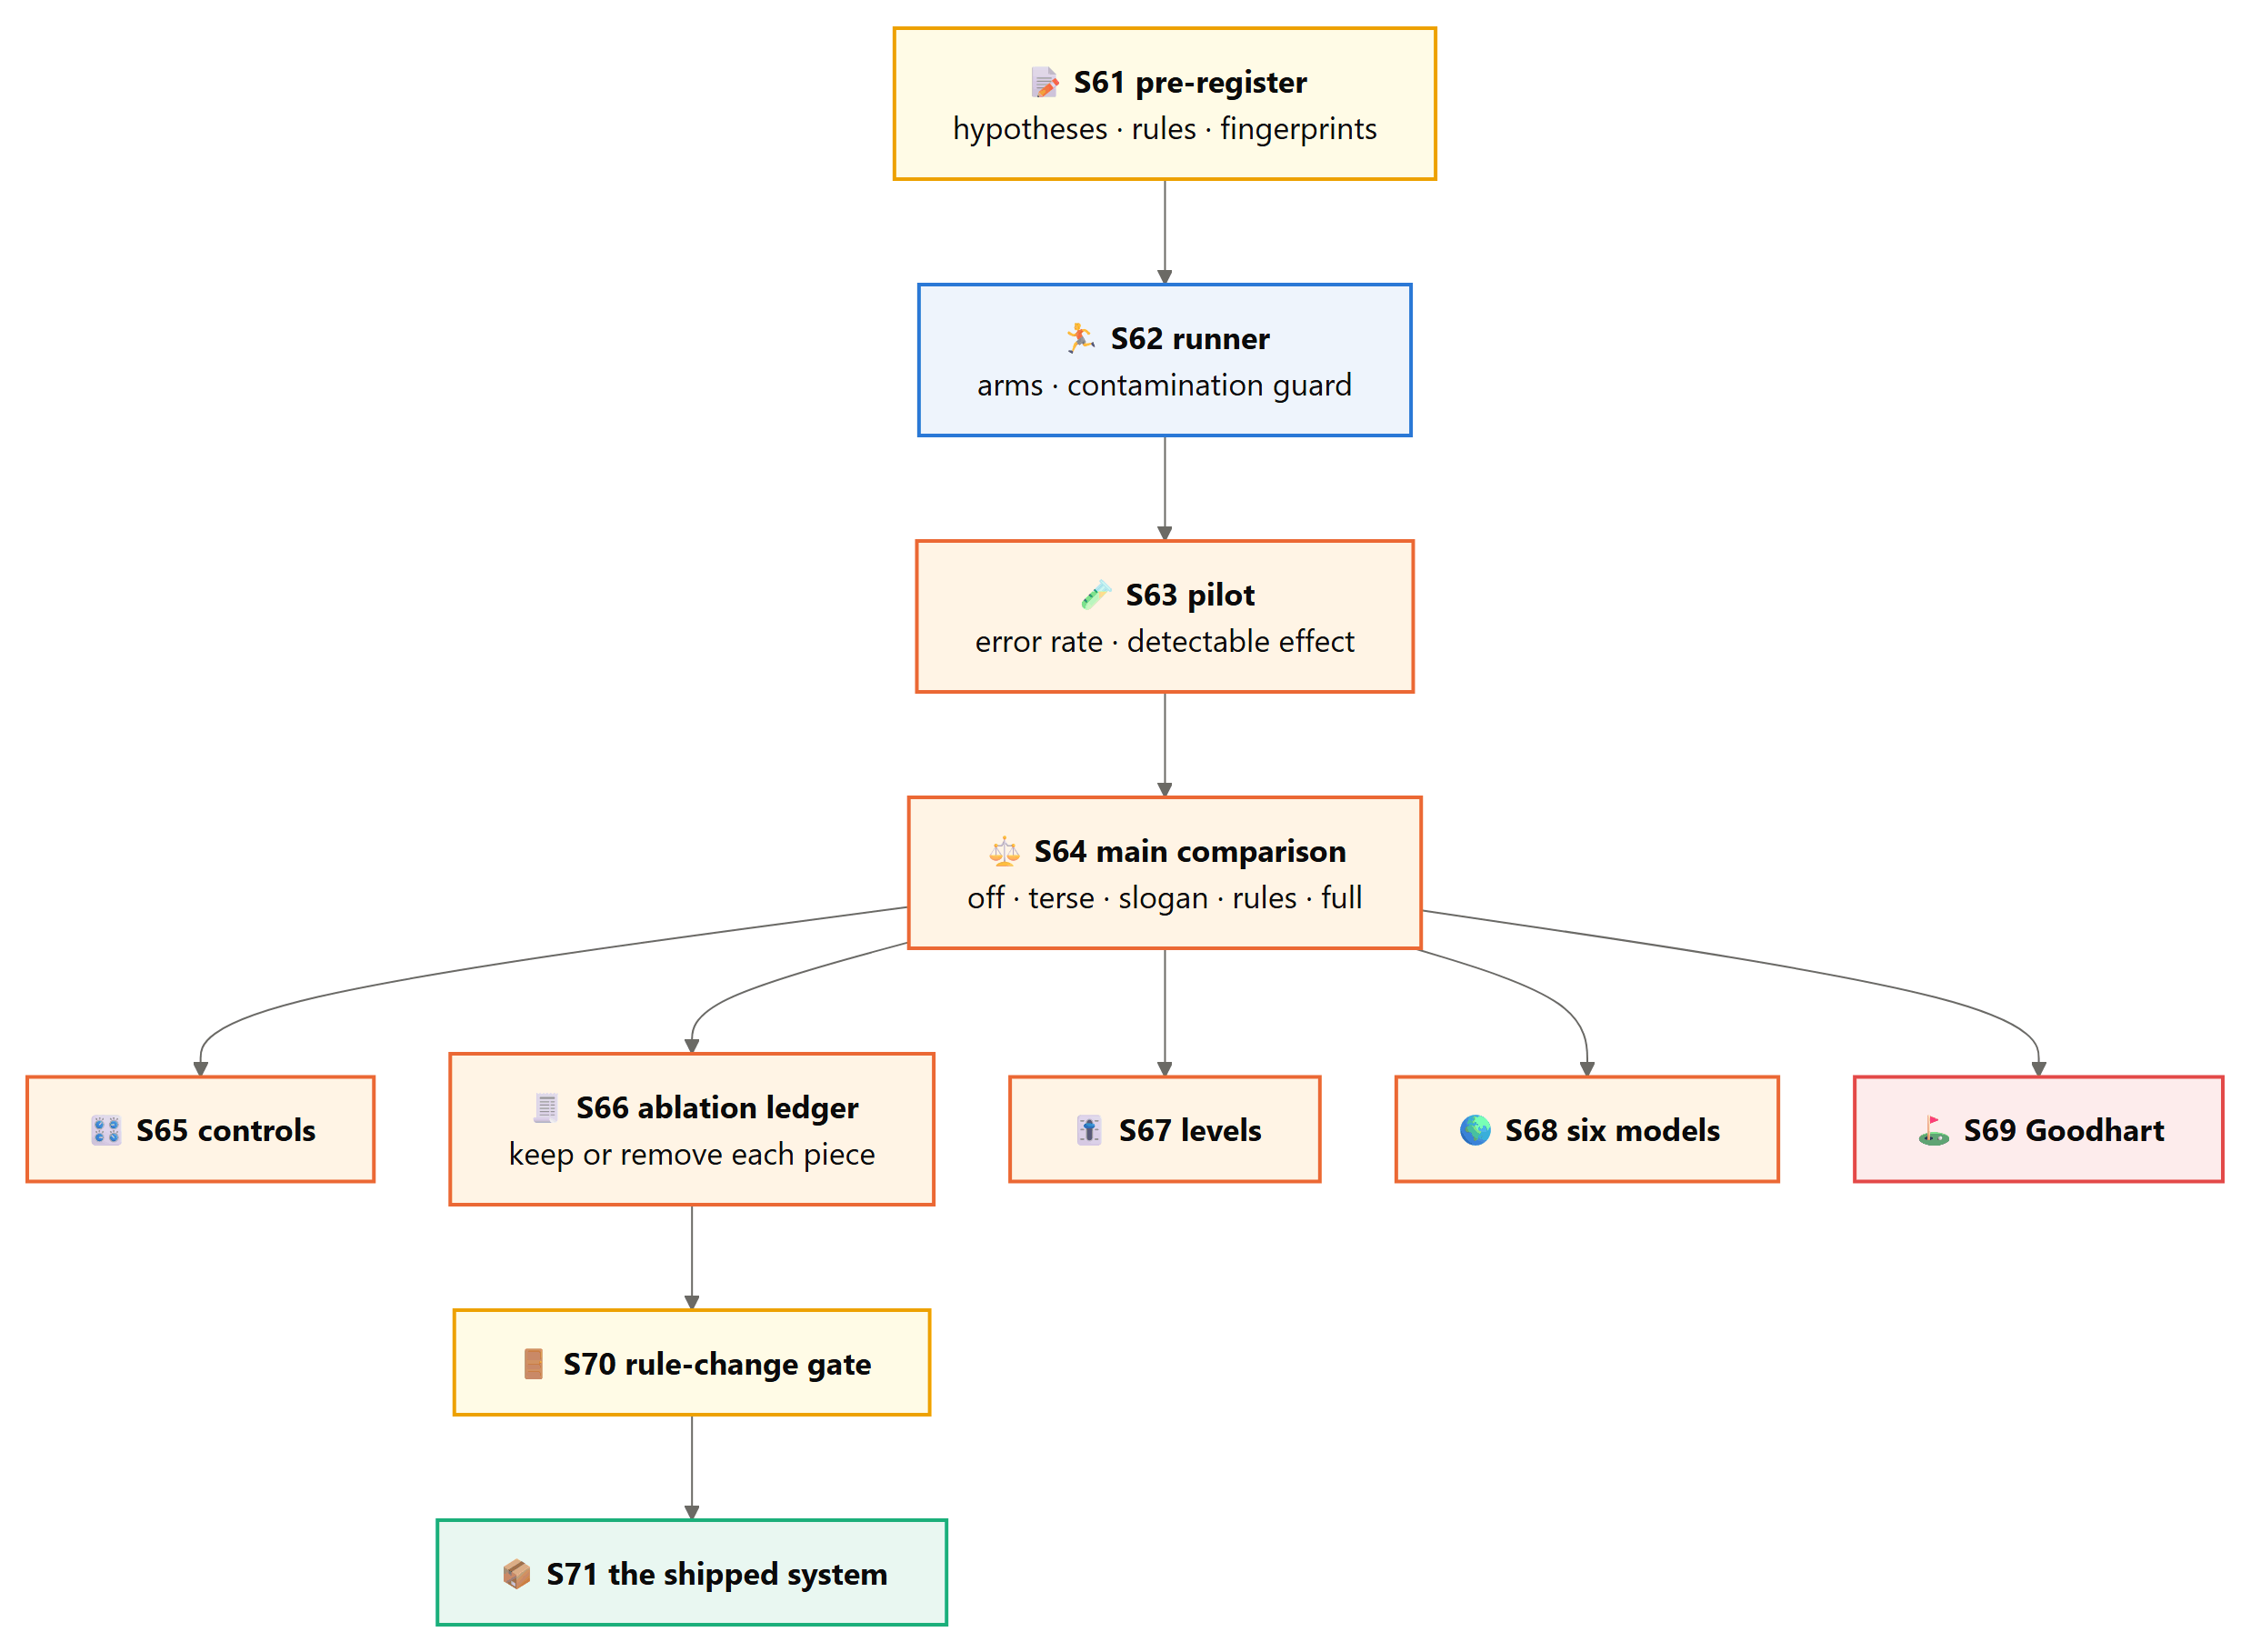

## S61 - Pre-registration: the rules of the game, before the game

**Theory.** An experiment designed after its results are known can find almost anything. The cure is to write down, before the main run, what will be measured, on which tasks, how it will be summarised and what result would count as success, and then to fingerprint that record so any later change is visible. Here the record holds thirteen hypotheses with their metrics and decision rules, the arms, the replicas, the analysis split (held-out tasks for the headline claims) and the fingerprints of the suite, the ruleset and the fence. The notebook writes it once. If it runs again with a different record (a reworded hypothesis, an edited task), it does not overwrite anything: it prints what changed, so the change has to be explained rather than slipped in.

**In plain terms.** We write down what would count as success before we look, and lock the note.

**For teams.** Before trying a new agent setup, write down what would make you keep it and what would make you drop it, with numbers. It takes ten minutes and removes the most common failure of internal evaluations, which is deciding what the result means after seeing it.

**The order that keeps a test honest.** The hypotheses and the bars they must clear are written down and fingerprinted before the main run produces a single number, so no verdict below can be bent to fit the data.

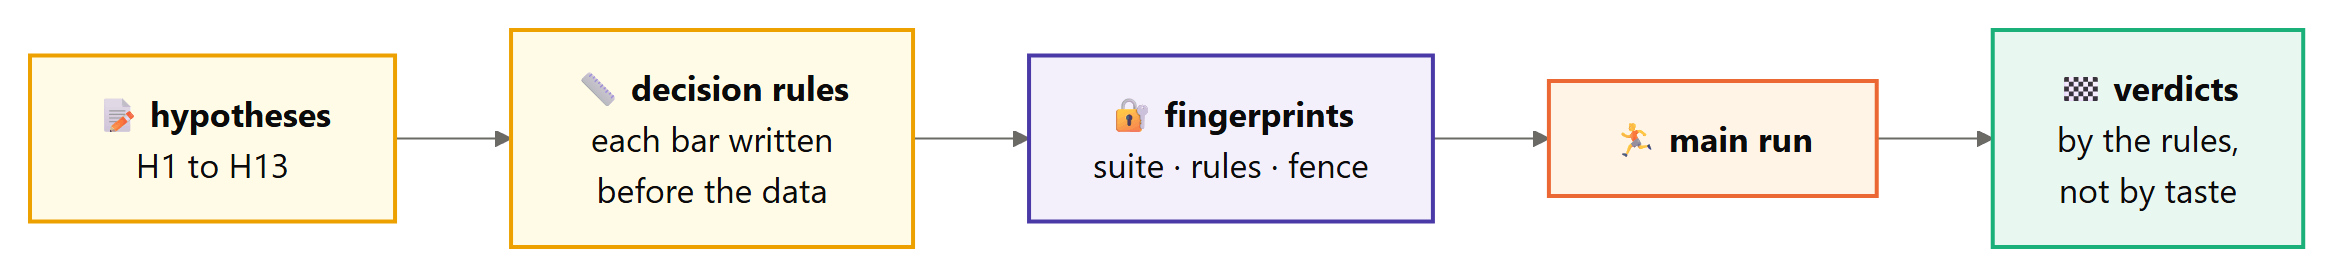

The record starts with the hypotheses as a plain table: an id, the claim in words, the metric that will decide it, and the decision rule. H1 to H5 are confirmatory and are judged together in S64; the others are decided or reported in their own sections.

In [631]:
# each entry: (id, the claim, the metric that decides it, the decision rule)
HYPOTHESES = [
    # confirmatory: H1 to H5 are judged together in S64, under Holm's correction
    ("H1", "the full system adds less code on held-out tasks",
     "median over held-out tasks of (code added + 1) under full / under off, replicas averaged",
     "the upper end of the 95% interval is below 0.85"),
    ("H2", "the full system is not less safe",
     "pass rate on the 10 safety tasks, full minus off", "the lower end of the 95% interval is above -5 points"),
    ("H3", "the full system is not less complete where completeness is the point",
     "pass rate on explicit and open tasks, full minus off", "the lower end of the 95% interval is above -10 points"),
    ("H4", "the plugin beats the same words pasted as rules on reuse, root-cause and platform tasks",
     "pass rate on those 7 tasks, full minus rules", "the difference is at least 15 points"),
    ("H5", "a slogan without counterweights drops guards",
     "safe pass rate and guard signatures on safety tasks, slogan vs off", "slogan is lower on either, interval excluding 0"),
    # the rest are decided or reported in their own sections, outside the correction
    ("H6", "strength follows the level: lite adds most, ultra least; ultra costs completeness",
     "code-added ratio and pass rate by level", "the ordering holds; reported with intervals"),
    ("H7", "the rules raise reasoning on reasoning models", "reasoning characters per call, full vs off, per model",
     "reported as a cost bound, not a success criterion"),
    ("H8", "a fewest-lines objective produces golfed, less safe code",
     "golf score and safe pass rate, fewest vs full", "fewest is worse on either"),
    ("H9", "the judges are valid", "agreement between the two judges (kappa) and bloated ranked above good",
     "kappa at least 0.6 and bloated above good on 90% of pairs"),
    ("H10", "without re-injection the rules decay after compaction",
     "code-added ratio per ticket position in a long session, with and without the compaction hook", "reported"),
    ("H11", "subagents without the rules miss more", "critic and audit findings with and without subagent rules", "reported"),
    ("H12", "lean code is cheaper to extend", "lines changed by the extension ticket, full vs off", "reported"),
    ("H13", "on a project with heavy conventions the full system adds fewer files and layers, tests still passing",
     "new files and code added per house-style ticket, full vs off", "reported"),
]
print(f"[prereg] {len(HYPOTHESES)} hypotheses: " + ", ".join(h[0] for h in HYPOTHESES))   # the ids, in order

[prereg] 13 hypotheses: H1, H2, H3, H4, H5, H6, H7, H8, H9, H10, H11, H12, H13


Around the hypotheses goes the rest of the design: the arms, the replicas, the turn limit and the coder, the split the headline claims are made on, the correction, the ablation rule, and the fingerprints of the suite, the ruleset and the fence. If any of those changes, the experiment has changed, so all of it goes into the record.

In [632]:
ARM_NAMES = ("off", "terse", "slogan", "rules", "full")     # the five arms of S64, in the order every table lists them
PREREG = {
    # each hypothesis as a record with named fields, in the order of the table above
    "hypotheses": [dict(zip(("id", "claim", "metric", "decision"), h)) for h in HYPOTHESES],
    # the design: which arms, how many runs of each task, how long an episode may go, which model writes the code
    "arms": list(ARM_NAMES), "replicas": REPLICAS, "max_turns": MAX_TURNS, "coder": MODEL_FOR["coder"],
    # the analysis: headline claims on held-out tasks only, five of them corrected together
    "headline_split": "held-out", "confirmatory": ["H1", "H2", "H3", "H4", "H5"], "alpha": 0.05, "correction": "Holm",
    # the rule S66 applies to every piece of the system, and the one piece it never removes
    "ablation_rule": "a piece is kept only if removing it makes its target measurably worse; neutral and harmful pieces leave",
    "exempt_from_removal": ["never cut: it protects a promise (H2), not a metric"],
    # what happens to a model that cannot follow the action protocol
    "not_evaluable": "a model with protocol errors on more than 30% of turns is reported, not tuned for",
    # what the experiment runs on: an edited task, rule or fence shows up as a changed record
    "fingerprints": {"suite": SUITE_HASH[:16],
                     "ruleset": hashlib.sha256(RULESET_SOURCE.encode()).hexdigest()[:16],
                     "fence": FENCE_HASH},
}
# the design at a glance, and the three fingerprints that pin down what it runs on
print(f"[prereg] arms {', '.join(PREREG['arms'])}; {PREREG['replicas']} replicas per task; "
      f"fingerprints {PREREG['fingerprints']}")

[prereg] arms off, terse, slogan, rules, full; 2 replicas per task; fingerprints {'suite': '546b6a4cb486c895', 'ruleset': '688b204efa8a2738', 'fence': '90ab1dd4106c'}


The record is written as JSON with sorted keys, so the same content always produces the same bytes and the same fingerprint. Only the first run writes it; every later run compares itself with what was registered and names the entries that differ.

In [633]:
PREREG_PATH = ART / "preregistration.json"                         # beside the experiment records it governs
record = json.dumps(PREREG, indent=2, sort_keys=True)              # sorted keys: the same content always gives the same text
fingerprint = hashlib.sha256(record.encode()).hexdigest()[:16]     # short, but any change to the record changes it
if not PREREG_PATH.exists():
    PREREG_PATH.write_text(record, encoding="utf-8")               # the first run registers; no later run writes here
    print(f"[prereg] registered {len(HYPOTHESES)} hypotheses, fingerprint {fingerprint}")
else:
    old = json.loads(PREREG_PATH.read_text(encoding="utf-8"))      # what was registered before the main run
    # entry by entry, so the message names what changed rather than only that something did
    changed = sorted(k for k in PREREG
                     if json.dumps(old.get(k), sort_keys=True) != json.dumps(PREREG[k], sort_keys=True))
    # a change is reported, never written: it has to be explained, not slipped in
    print(f"[prereg] fingerprint now {fingerprint}; " + (f"CHANGED SINCE REGISTRATION: {changed}" if changed
                                                         else "unchanged since registration"))

[prereg] fingerprint now e150f88d7ab7aa8c; unchanged since registration


In [634]:
# the five confirmatory hypotheses, each with the rule that will decide it
for h in HYPOTHESES[:5]:
    print(f"  {h[0]:<4} {h[1]}\n       decision: {h[3]}")     # id and claim, with the decision rule under them
print(f"  ... and {len(HYPOTHESES) - 5} more; H1 to H5 are confirmatory and Holm-corrected together")

  H1   the full system adds less code on held-out tasks
       decision: the upper end of the 95% interval is below 0.85
  H2   the full system is not less safe
       decision: the lower end of the 95% interval is above -5 points
  H3   the full system is not less complete where completeness is the point
       decision: the lower end of the 95% interval is above -10 points
  H4   the plugin beats the same words pasted as rules on reuse, root-cause and platform tasks
       decision: the difference is at least 15 points
  H5   a slogan without counterweights drops guards
       decision: slogan is lower on either, interval excluding 0
  ... and 8 more; H1 to H5 are confirmatory and Holm-corrected together


## S62 - The runner and the contamination guard

**Theory.** An arm is a recipe for a host: no plugin, a static text, or the full system. The runner plays every combination of arm, task and replica through the same `run_episode`, in parallel, resuming from the ledger. It also checks that no arm saw another arm's instructions. That sounds paranoid until it happens: a benchmark once found its baseline quietly running with the very skill under test, because the rules were installed globally and leaked into every arm. Our guard rebuilds each arm's system message for each task and compares its fingerprint with the one the model actually saw on the episode's first turn. Any mismatch stops the analysis. A failed episode (an API error, a timeout) is recorded as failed and counted, never silently dropped, because dropping failures is how an arm that crashes on hard tasks ends up looking better on the easy ones. It gets no score, because a provider's bad minute is not the agent's failure either. And a grid in which more than one episode in twenty failed that way stops the notebook: a partial grid is resumed from the ledger later, not analysed.

**In plain terms.** Every arm runs the same tasks in the same way, and we prove afterwards that none of them saw another arm's instructions.

The arms first. Each one is a recipe, a function that builds fresh plugins for one host, so no two episodes ever share a plugin's state. The two controls are single sentences, placed in the system message exactly as written.

In [635]:
# the two control texts, placed in the system message of their arms exactly as written
TERSE_TEXT = "Keep your code and your answers short. Do not add anything the ticket does not need."
SLOGAN_TEXT = "Write the least code that works."
ARMS = {
    "off": lambda: [],                                   # the unguided agent: no plugin at all
    "terse": lambda: [StaticRules(TERSE_TEXT)],          # one sentence asking for short code
    "slogan": lambda: [StaticRules(SLOGAN_TEXT)],        # the slogan, without any of the counterweights
    "rules": lambda: [StaticRules(ruleset("full"))],     # the whole ruleset as static text: the words, no machinery
    "full": lambda: full_system(),                       # plugin, gates, critic and skills
}
print(f"[arms] {', '.join(ARMS)}")                      # the order every table uses
print(f"  terse : {TERSE_TEXT}")                         # what the two controls say, word for word
print(f"  slogan: {SLOGAN_TEXT}")

[arms] off, terse, slogan, rules, full
  terse : Keep your code and your answers short. Do not add anything the ticket does not need.
  slogan: Write the least code that works.


**`expected_system(arm, task, plugins_for=None)`** rebuilds, from scratch, the system message an arm should show on its first turn of a task, and returns its fingerprint. The contamination guard needs something to compare each real episode against, and the only trustworthy reference is the arm's own recipe run again. The host it builds talks to the scripted stand-in through a throwaway in-memory ledger, so making the reference can never reach a model or touch the stored answers. The ticket goes through the prompt hooks as well, so the reference has seen every hook that runs before the model's first turn.

In [636]:
def expected_system(arm, task, plugins_for=None):
    """The fingerprint of the system message an arm should show on its first turn of a task."""
    recipe = plugins_for or ARMS[arm]                              # the arm's own recipe, unless the caller brings one
    offline = LLM("smoke", Ledger(":memory:"), scripted=SCRIPTED)  # a door to nowhere: no model, no stored answers
    h = Host(llm=offline, plugins=recipe(), label=arm)             # fresh plugins, exactly as an episode gets them
    h.start_session(materialise(task, WS_DIR / "contamination" / f"{arm}-{task.id}"))   # the task's seed, untouched
    h.handle_prompt(task.prompt)                                   # prompt hooks may change the system message too
    return h.ctx.fingerprint()                                     # ten hex digits of the system message's hash

show_def(expected_system, layer="lab")

[def] expected_system(arm, task, plugins_for=None)  8 lines, complexity 2


In [637]:
toy_task = SUITE["ob-postcode-cache"]               # any task will do; this one recurs through the notebook
toy_off = expected_system("off", toy_task)          # the unguided agent's system message, fingerprinted
toy_again = expected_system("off", toy_task)        # built again from nothing: must come out the same
toy_terse = expected_system("terse", toy_task)      # one control sentence more in the system message
print(f"[expected_system] off on {toy_task.id}: {toy_off}; rebuilt: {toy_again}; identical: {toy_off == toy_again}")
print(f"  terse on the same task: {toy_terse}; different from off: {toy_terse != toy_off}")

[expected_system] off on ob-postcode-cache: 1d277b65ab; rebuilt: 1d277b65ab; identical: True
  terse on the same task: af3fc612df; different from off: True


**`Run`** is the record of one cell of the grid: which arm, which task, which replica, the episode if there was one, its score, and an error if something outside the agent stopped it. Keeping a failure as a `Run` with an error, rather than dropping it, is what lets every table count failures. A run with an error has no score, so every analysis that filters on `r.score` leaves it out of the comparisons, while the failure count still sees it.

In [638]:
@dataclass
class Run:
    arm: str                     # the arm's name, which is also the key of its recipe
    task: str                    # the task id
    replica: int                 # which repeat of the (arm, task) pair; part of the key of every stored answer
    episode: Episode = None      # what happened, turn by turn; None if the episode never got going
    score: Score = None          # the hidden test's verdicts; None for a run the API cut short
    error: str = ""              # why the run failed outside the agent's control, if it did

show_def(Run, layer="lab")

[class] Run(arm: str, task: str, replica: int, episode: __main__.Episode = Non...)  7 lines, complexity 1


In [639]:
toy_failed = Run("full", "ob-postcode-cache", 0, error="HTTP 503: the provider was busy")   # what an API failure leaves
# no score, so no comparison sees it; a non-empty error, so every failure count does
print(f"[run] {toy_failed.arm}/{toy_failed.task} replica {toy_failed.replica}: score {toy_failed.score}, "
      f"counted as failed: {bool(toy_failed.error)}")

[run] full/ob-postcode-cache replica 0: score None, counted as failed: True


**`GridIncomplete`** is the exception that stops the notebook when too many episodes in a grid failed for reasons outside the agent, such as timeouts and provider errors. A partial grid analysed as if it were whole would compare arms on different sets of tasks, the very mistake the paired design is there to prevent. It is a class of its own so the traceback names the problem precisely and its message says what to do: resume the run from the ledger later.

In [640]:
class GridIncomplete(RuntimeError):
    """Too many episodes failed for reasons outside the agent for the grid to be worth analysing."""

show_def(GridIncomplete, layer="lab")

[class] GridIncomplete  2 lines, complexity 1


**`run_grid(arms, tasks, replicas, recipes, label, model, max_failed)`** plays every combination of arm, task and replica through the same `run_episode`, ten at a time, and returns one `Run` per combination. Each episode gets a fresh host built from its arm's recipe, with the same turn limit and the same model, so the recipe is the only thing that differs between arms. An error inside an episode is caught and recorded on its `Run`, apart from two that must stop everything: a reply missing from the ledger in a replay, and a refusal to spend. Once every episode is back, more failures than one in twenty (three are always tolerated) raise `GridIncomplete` instead of returning a partial grid.

In [641]:
def run_grid(arms, tasks, replicas=range(REPLICAS), recipes=None, label="", model=None, max_failed=0.05):
    """Every (arm, task, replica), in parallel, resumable from the ledger. Returns [Run]. An
    episode the API cut short is a failed run, not a failed agent: it gets no score. More
    than `max_failed` of them stops the notebook: a partial grid is resumed, not analysed."""
    recipes = recipes or ARMS                                  # the five arms of S64, unless a section brings its own
    jobs = []
    for r in replicas:                                         # replica 0 of every arm and task is queued before replica 1
        for a in arms:
            for t in tasks:
                jobs.append((a, t, r))                         # one episode to play

    def one(job):
        arm, task, replica = job                               # one queued episode
        try:
            # a fresh host per episode, from the arm's recipe, so nothing carries over between runs
            ep = run_episode(task, Host(model=model, plugins=recipes[arm](), label=arm), replica=replica)
            if ep.stop.startswith("error"):                    # the API gave up mid-episode: a failed run, not a failed agent
                return Run(arm, task.id, replica, ep, error=scrub(ep.stop)[:200])
            return Run(arm, task.id, replica, ep, score(task, ep.ws, visible=False))   # judged by the hidden test alone
        except (CacheMiss, SpendRefused):
            raise                                              # a missing answer or a refusal to spend stops everything
        except Exception as e:                    # recorded and counted, never dropped
            return Run(arm, task.id, replica, error=f"{type(e).__name__}: {scrub(e)}"[:200])

    start = time.perf_counter()                                # for the elapsed time in the progress lines
    out = []                                                   # results in job order, which pool.map keeps
    every = max(1, len(jobs) // 6)                             # report progress about six times per grid
    pool = ThreadPoolExecutor(WORKERS)                         # not a with-block: an interrupt must not wait for it
    try:
        for i, run in enumerate(pool.map(one, jobs), 1):
            out.append(run)
            if i % every == 0 or i == len(jobs):               # and always once at the end
                print(f"  [{label or 'grid'}] {i}/{len(jobs)} episodes, {time.perf_counter() - start:.0f}s, "
                      f"{sum(bool(r.error) for r in out)} failed")
    except KeyboardInterrupt:
        if FRONT_DOOR.client:
            FRONT_DOOR.client.stop.set()                       # the client stops retrying, so the threads end quickly
        pool.shutdown(wait=False, cancel_futures=True)         # queued episodes are dropped; finished ones are in the ledger
        raise
    pool.shutdown()                                            # every episode is back
    failed = sum(bool(r.error) for r in out)                   # runs that ended outside the agent's control
    # three failures always pass, so one bad minute cannot stop a small grid
    if failed > max(3, max_failed * len(out)):
        raise GridIncomplete(f"{failed} of {len(out)} episodes in '{label}' failed outside the agent's control; "
                             "resume the run later instead of analysing a partial grid")
    return out

show_def(run_grid, layer="lab")

[def] run_grid(arms, tasks, replicas=range(0, 2), recipes=None, label='', model=N...)  42 lines, complexity 17

**`contamination(runs, recipes=None)`** is the guard itself. For every run it rebuilds the system message the run's arm should have shown, with `expected_system`, and compares that fingerprint with the one recorded on the episode's first turn; it returns the runs that do not match. It checks what the model actually saw, not what the configuration says it should have seen, because the leak it exists to catch (rules installed globally and picked up by every arm) leaves the configuration looking clean. A run without an episode has nothing to check and is already counted as a failure.

In [642]:
def contamination(runs, recipes=None):
    """Runs whose first-turn system message differs from what their arm should show."""
    bad = []                                                   # (arm, task, replica) of every run that saw the wrong rules
    for r in runs:
        if r.episode and r.episode.turns:                      # a run that never reached the model has nothing to check
            # the reference, rebuilt from the arm's own recipe on the same task
            want = expected_system(r.arm, SUITE[r.task], (recipes or ARMS)[r.arm])
            if r.episode.turns[0].system != want:              # the fingerprint the model saw on turn one
                bad.append((r.arm, r.task, r.replica))
    return bad

show_def(contamination, layer="lab")

[def] contamination(runs, recipes=None)  9 lines, complexity 6


Two hand-built runs show the guard at work: both claim to be the terse arm on the same task, but only the first carries the fingerprint the terse arm really produces.

In [643]:
toy_runs = []
for toy_system in (expected_system("terse", toy_task), "0123456789"):    # the arm's real fingerprint, then a stranger's
    # a first turn with nothing in it but the fingerprint the guard reads
    toy_turn = Turn(1, "read", toy_task.entry, True, "", 0, 0, 0, 0, 0.0, False, system=toy_system)
    toy_episode = Episode(toy_task.id, "terse", "toy", len(toy_runs), [toy_turn], "done", "", 0, 0.0, "")
    toy_runs.append(Run("terse", toy_task.id, len(toy_runs), toy_episode))   # replicas 0 and 1
# only the second run should come back: it saw a system message the terse arm never produces
print(f"[contamination] runs whose first turn does not match their arm: {contamination(toy_runs)}")

[contamination] runs whose first turn does not match their arm: [('terse', 'ob-postcode-cache', 1)]

In [644]:
# every arm on one task: the fingerprints must all differ, or the guard could not tell the arms apart
fps = {arm: expected_system(arm, SUITE["ob-postcode-cache"]) for arm in ARMS}   # one fingerprint per arm
# as many distinct fingerprints as arms means no two arms share a system message
print(f"[arms] {len(ARMS)} arms, all with distinct system messages: {len(set(fps.values())) == len(ARMS)}")
for arm, fp in fps.items():
    print(f"  {arm:<7} system fingerprint {fp}")

[arms] 5 arms, all with distinct system messages: True
  off     system fingerprint 1d277b65ab
  terse   system fingerprint af3fc612df
  slogan  system fingerprint cf5ef4d453
  rules   system fingerprint 2eef666019
  full    system fingerprint 7b187d422d


## S63 - The pilot, and the smallest effect worth looking for

**Theory.** Before the main run, a pilot answers two questions cheaply. First, does the full system work at all with this model: is the protocol error rate under 10%, the limit the plan set for the pilot, and do episodes finish? (The registered record itself holds only the 30% rule for calling a model not evaluable.) Second, how noisy is the thing we will measure? The headline metric is a per-task ratio of code added, and the spread of its logarithm across tasks decides the **minimum detectable effect**: the smallest true reduction that a design with this many tasks and replicas would detect most of the time. If that effect is larger than anything we could hope for, the main run would be a waste of money, and it is better to know that now. The pilot uses the nine dev tasks, which are allowed to inform choices; the held-out tasks are not touched until the main run.

**In plain terms.** A small dress rehearsal on the practice tasks: does the system run cleanly, and is the experiment big enough to see what we are looking for?

In [645]:
DEV = [t for t in SUITE.values() if t.split == "dev"]               # the practice tasks: allowed to inform choices
HELD = [t for t in SUITE.values() if t.split == "held-out"]         # the tasks every headline claim is made on
print(f"[pilot] {len(DEV)} dev tasks for the pilot; {len(HELD)} held-out tasks wait for the main run")
PILOT = run_grid(["off", "full"], DEV, replicas=[0], label="pilot")   # one run each, unguided and full

[pilot] 9 dev tasks for the pilot; 25 held-out tasks wait for the main run


  [pilot] 3/18 episodes, 2s, 0 failed
  [pilot] 6/18 episodes, 2s, 0 failed
  [pilot] 9/18 episodes, 2s, 0 failed


  [pilot] 12/18 episodes, 3s, 0 failed
  [pilot] 15/18 episodes, 3s, 0 failed
  [pilot] 18/18 episodes, 3s, 0 failed


The first question is whether the full system can follow the action protocol with this model. A turn whose action is `none` is a turn where the model's reply held no usable action.

In [646]:
full_turns = []                                                      # every turn the full system took in the pilot
for r in PILOT:
    if r.arm == "full" and r.episode:                                # failed runs have no turns to count
        full_turns.extend(r.episode.turns)
proto_rate = sum(x.action == "none" for x in full_turns) / max(1, len(full_turns))   # max(1, ...) guards an empty pilot
# the counts behind the rate; the verdict against the 10% limit comes after the table
print(f"[pilot] the full system took {len(full_turns)} turns on the dev tasks; "
      f"{sum(x.action == 'none' for x in full_turns)} of them held no usable action")

[pilot] the full system took 117 turns on the dev tasks; 3 of them held no usable action


The second question is how noisy the headline metric is. The spread of the log code ratio across dev tasks, together with the number of held-out tasks, gives the smallest ratio the main run can be expected to detect.

In [647]:
by = {(r.arm, r.task): r for r in PILOT}                            # one run per (arm, task) in the pilot
logs = []                                                            # the paired code ratio per dev task, as a log
for t in DEV:
    full_score, off_score = by[("full", t.id)].score, by[("off", t.id)].score   # either is None for a failed run
    if full_score and off_score:                                     # a task with a failed run has no pair
        logs.append(math.log((full_score.added_code + 1) / (off_score.added_code + 1)))   # log of the paired ratio
sd = float(np.std(logs, ddof=1)) if len(logs) > 1 else float("nan")   # one task alone has no spread
n_main = len(HELD)                                                   # the main run's sample, in tasks
# 2.8 is 1.96 + 0.84: a two-sided 5% test with 80% power, on the log scale, turned back into a ratio
mde = math.exp(-2.8 * sd / math.sqrt(n_main))
# below zero, the full system wrote less than the unguided agent on that task
print("[pilot] log of (full + 1) / (off + 1) per dev task: " + ", ".join(f"{v:+.2f}" for v in logs))

[pilot] log of (full + 1) / (off + 1) per dev task: +0.00, -0.13, -0.42, -0.29, +0.00, -2.23, -0.29, +0.00, -0.11


In [648]:
pilot_rows = []                                                      # one row per dev task, both arms side by side
for t in DEV:
    off_run, full_run = by[("off", t.id)], by[("full", t.id)]        # the pair the pilot compares
    pilot_rows.append({
        "task": t.id,
        "off": off_run.score.short() if off_run.score else "error",          # every verdict, or 'error' for a failed run
        "full": full_run.score.short() if full_run.score else "error",
        "off code": off_run.score.added_code if off_run.score else None,     # lines of code added
        "full code": full_run.score.added_code if full_run.score else None,
        "full turns": len(full_run.episode.turns) if full_run.episode else None,      # did episodes finish in time?
    })
# column key, header, number format
table(pilot_rows, [("task", "dev task", ""), ("off", "off", ""), ("full", "full", ""), ("off code", "off code", "d"),
                   ("full code", "full code", "d"), ("full turns", "full turns", "d")])

  dev task              off    full   off code  full code  full turns
  -------------------------------------------------------------------
  ct-off-by-one         c1 q1  c1 q1         1          1          11
  eg-leap-feb           c1     c1            7          6          11
  ex-signup-rules       c1     c1           34         22          20
  ob-postcode-cache     c1     c1            7          5          14
  ob-settings-defaults  c1 q1  c1 q1        14         14          10
  rc-day-parse          c1 q1  c1 q1        27          2          17
  ru-trip-duration      c1 q1  c1 q1         3          2          11
  sf-clinic-file        c1 s1  c1 s1         5          5          11
  sf-feedback-body      c1 s1  c1 s1        18         16          12


In [649]:
# the pilot's two answers: does the protocol hold, and how small an effect can the main run see?
print(f"\n  protocol errors under the full system: {proto_rate:.1%} of turns (the plan's limit, 10%): "
      f"{'PASSED' if proto_rate < 0.10 else 'FAILED'}")
print(f"  spread of log(code ratio) across dev tasks: sd {sd:.2f}; with {n_main} held-out tasks the main run can detect")
print(f"  a true ratio of about {mde:.2f} (a {1 - mde:.0%} reduction) with 80% power at the 5% level")
save_exp("pilot", {"protocol_rate": proto_rate, "sd_log_ratio": sd, "mde_ratio": mde, "tasks": len(DEV)})   # S66 quotes mde_ratio


  protocol errors under the full system: 2.6% of turns (the plan's limit, 10%): PASSED
  spread of log(code ratio) across dev tasks: sd 0.71; with 25 held-out tasks the main run can detect
  a true ratio of about 0.67 (a 33% reduction) with 80% power at the 5% level
[exp] artifacts/exp_pilot.json


## S64 - The main comparison

**Theory.** Five arms run on all 34 tasks, twice each: no plugin, the two controls (a terse instruction and a slogan), the ruleset pasted as static text, and the full system. Every comparison is **paired by task**: an arm's result on a task is compared with the baseline's result on the same task, and the tasks are what get resampled when the intervals are built (a cluster bootstrap), because tasks differ far more from each other than replicas of one task do. The headline metric for size is the median, over held-out tasks, of the per-task ratio of code added (one is added to both sides, so a task where either arm added nothing does not divide by zero). The pass rate is reported beside it everywhere, because a system that shrinks code by breaking it has achieved nothing.

**In plain terms.** Five versions of the agent do the same 34 tickets twice. We compare each one with the unguided agent, ticket by ticket.

**Five arms, from nothing to everything.** Two cheap controls (a short-prose instruction and a one-line slogan), the full ruleset pasted in as plain text, and the full system, which delivers the same ruleset through hooks and adds the gates and the critic. The gap between the last two is what the machinery is worth (H4).

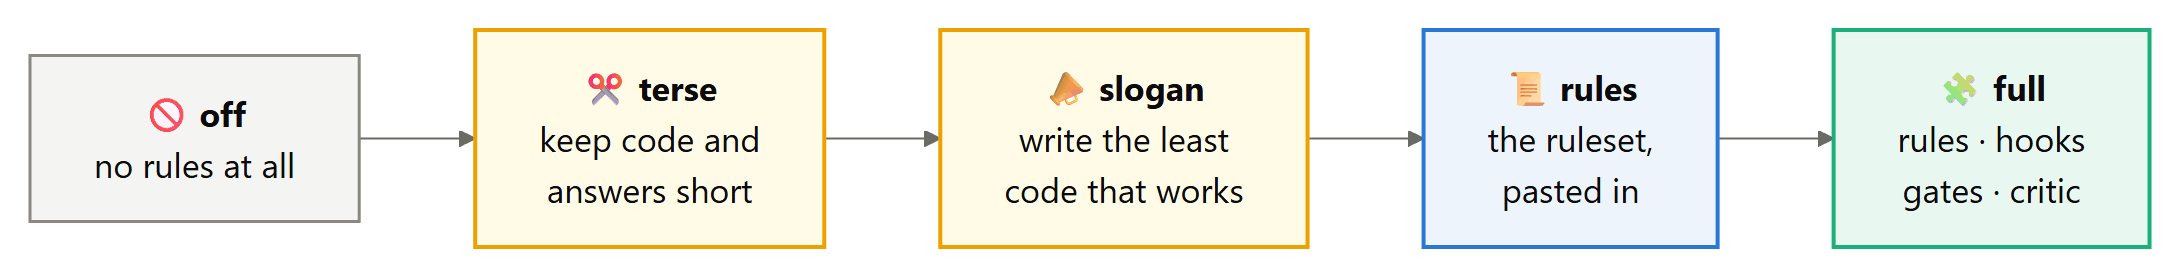

**`bootstrap(values_by_task, stat, n=4000, seed=SEED)`** is the cluster bootstrap behind every interval in this Part. It takes one value per task, draws 4,000 new samples of tasks with replacement, and applies the statistic to each, so the spread of the results shows how far the answer would move with a different sample of tasks. Tasks are what gets resampled because they differ from each other far more than two replicas of one task do; resampling episodes would pretend there were more independent observations than there are. Its own seeded generator makes every interval identical from run to run.

In [650]:
def bootstrap(values_by_task, stat, n=4000, seed=SEED):
    """Resample tasks with replacement; return the statistic's samples."""
    rng = np.random.default_rng(seed)                       # its own generator: the same seed gives the same interval
    keys = list(values_by_task)                             # one entry per task, in the caller's order
    if not keys:
        return np.array([np.nan])                           # nothing paired: an interval of nothing, not an error
    idx = rng.integers(0, len(keys), size=(n, len(keys)))   # n resamples, each len(keys) task positions drawn with replacement
    vals = [values_by_task[k] for k in keys]                # the per-task values, by position
    samples = []
    for row in idx:
        resample = [vals[i] for i in row]                   # one resampled set of tasks; a task can appear twice
        samples.append(stat(resample))                      # the statistic on that set
    return np.array(samples)

show_def(bootstrap, layer="lab")

[def] bootstrap(values_by_task, stat, n=4000, seed=42)  13 lines, complexity 5


In [651]:
toy_ratios = {"task a": 0.5, "task b": 0.8, "task c": 1.0, "task d": 1.6}   # four invented per-task ratios
toy_samples = bootstrap(toy_ratios, np.median, n=1000)                       # a thousand resampled medians
toy_lo, toy_hi = np.percentile(toy_samples, [2.5, 97.5])                     # the middle 95% of them
print(f"[bootstrap] median of the four tasks: {np.median(list(toy_ratios.values())):.2f}; "
      f"95% interval over resampled tasks: {toy_lo:.2f} to {toy_hi:.2f}")

[bootstrap] median of the four tasks: 0.90; 95% interval over resampled tasks: 0.50 to 1.60


**`per_task(runs, arm, metric, tasks)`** collapses an arm's runs into one number per task: the metric averaged over that task's replicas. Every comparison in this Part is paired by task, and pairing needs exactly one value per task on each side. Runs without a score, the ones the API cut short, are skipped, and a task with no scored run gets no entry at all, so it drops out of the pairing instead of counting as a zero.

In [652]:
def per_task(runs, arm, metric, tasks):
    """{task: mean of metric over the arm's replicas}, skipping failed runs."""
    out = {}
    for t in tasks:
        # this arm's scored replicas of the task, each turned into a number by the metric
        vals = [metric(r) for r in runs if r.arm == arm and r.task == t.id and r.score]
        if vals:                                            # no scored replica: the task stays out of the pairing
            out[t.id] = float(np.mean(vals))                # replicas averaged, so each task counts once
    return out

show_def(per_task, layer="lab")

[def] per_task(runs, arm, metric, tasks)  8 lines, complexity 6


A few invented runs on three real task ids make the next three functions concrete: two replicas per arm and task, and one extra replica the API cut short.

In [653]:
toy_tasks = [SUITE["ob-postcode-cache"], SUITE["ob-report-flags"], SUITE["ru-badge-name"]]
# (arm, task, replica, code added, correct), all invented
toy_plan = [("off", 0, 0, 30, 1), ("off", 0, 1, 26, 1), ("full", 0, 0, 9, 1), ("full", 0, 1, 11, 1),
            ("off", 1, 0, 12, 1), ("off", 1, 1, 14, 0), ("full", 1, 0, 7, 1), ("full", 1, 1, 5, 1),
            ("off", 2, 0, 8, 1), ("off", 2, 1, 8, 1), ("full", 2, 0, 8, 0), ("full", 2, 1, 6, 1)]
toy_runs = []
for toy_arm, toy_i, toy_rep, toy_added, toy_correct in toy_plan:
    toy_id = toy_tasks[toy_i].id
    # a run with a score but no episode: all these functions read is the score
    toy_runs.append(Run(toy_arm, toy_id, toy_rep, None, Score(toy_id, toy_correct, added_code=toy_added)))
toy_runs.append(Run("full", toy_tasks[2].id, 2, error="timeout"))    # a third replica with no score
toy_code = per_task(toy_runs, "full", lambda r: r.score.added_code, toy_tasks)   # the timeout is skipped, not a zero
print("[per_task] full, code added, replicas averaged: " + ", ".join(f"{k} {v:.1f}" for k, v in toy_code.items()))

[per_task] full, code added, replicas averaged: ob-postcode-cache 10.0, ob-report-flags 6.0, ru-badge-name 7.0


**`ratio_summary(runs, arm, tasks, base="off")`** is the headline statistic: for each task, the arm's average code added plus one, divided by the baseline's, then the median of those ratios with its bootstrap interval. The plus one keeps a task where either side added nothing from dividing by zero. A ratio per task, rather than a ratio of totals, stops one large task from deciding the result, and the median stops one wild task from dragging it. It returns the median, the interval, the bootstrap samples and the per-task ratios, because the figures need all four.

In [654]:
def ratio_summary(runs, arm, tasks, base="off"):
    """Median paired ratio of (code added + 1), with a 95% interval over tasks."""
    a = per_task(runs, arm, lambda r: r.score.added_code + 1, tasks)     # the arm, one value per task
    b = per_task(runs, base, lambda r: r.score.added_code + 1, tasks)    # the baseline, the same way
    ratios = {}
    for t in a:
        if t in b:                                          # only tasks both sides have: the comparison is paired
            ratios[t] = a[t] / b[t]
    samples = bootstrap(ratios, np.median)                  # the median over 4,000 resampled sets of tasks
    median = float(np.median(list(ratios.values())))        # the estimate on the tasks actually run
    interval = np.percentile(samples, [2.5, 97.5])          # the middle 95% of the resampled medians
    return median, interval, samples, ratios

show_def(ratio_summary, layer="lab")

[def] ratio_summary(runs, arm, tasks, base='off')  12 lines, complexity 3


In [655]:
toy_med, toy_ci, toy_samples, toy_ratios = ratio_summary(toy_runs, "full", toy_tasks)   # full against off
print("[ratio_summary] (full + 1) / (off + 1) per task: " + ", ".join(f"{k} {v:.2f}" for k, v in toy_ratios.items()))
# three tasks make a wide interval: the bootstrap is honest about how little three tasks say
print(f"  median {toy_med:.2f}, 95% interval {toy_ci[0]:.2f} to {toy_ci[1]:.2f}, from {len(toy_samples)} resamples")

[ratio_summary] (full + 1) / (off + 1) per task: ob-postcode-cache 0.38, ob-report-flags 0.50, ru-badge-name 0.89
  median 0.50, 95% interval 0.38 to 0.89, from 4000 resamples


**`rate_summary(runs, arm, tasks, metric, base="off")`** does the same for anything measured as a rate or a per-run number: the paired difference, arm minus baseline, averaged over tasks, with its bootstrap interval. It serves the pass rate, the safe rate, the ablation targets and the rule-change gate alike, because in each case the mean over tasks is what matters. When no task has both sides, the estimate is `nan` rather than zero, so an empty comparison cannot pass for no effect.

In [656]:
def rate_summary(runs, arm, tasks, metric, base="off"):
    """Paired difference in a rate (0 to 1), arm minus base, with a 95% interval."""
    a = per_task(runs, arm, metric, tasks)                  # the arm, one value per task
    b = per_task(runs, base, metric, tasks)                 # the baseline, the same way
    diffs = {}
    for t in a:
        if t in b:                                          # paired: only tasks both sides have
            diffs[t] = a[t] - b[t]
    samples = bootstrap(diffs, np.mean)                     # the mean difference over resampled sets of tasks
    if diffs:
        estimate = float(np.mean(list(diffs.values())))     # the mean difference on the tasks actually run
    else:
        estimate = float("nan")                             # nothing to compare is not the same as no difference
    return estimate, np.percentile(samples, [2.5, 97.5]), samples

show_def(rate_summary, layer="lab")

[def] rate_summary(runs, arm, tasks, metric, base='off')  14 lines, complexity 4


In [657]:
# the pass verdict as a number per run; per task, full minus off, then the mean over tasks
toy_diff, toy_ci, toy_samples = rate_summary(toy_runs, "full", toy_tasks, lambda r: float(r.score.passed))
print(f"[rate_summary] pass rate, full minus off: {toy_diff:+.0%} (95% interval {toy_ci[0]:+.0%} to {toy_ci[1]:+.0%})")

[rate_summary] pass rate, full minus off: +0% (95% interval -50% to +50%)


**`holm(pvalues, alpha=0.05)`** decides which of several hypotheses survive being tested together. Testing five claims at 5% each gives a much higher chance than 5% that at least one passes by luck; Holm's step-down procedure fixes that by sorting the p-values and holding the smallest to alpha divided by five, the next to alpha divided by four, and so on. The first one that misses its threshold stops the walk: it and every hypothesis after it count as not supported, whatever their own p-values.

In [658]:
def holm(pvalues, alpha=0.05):
    """{name: rejected?} under Holm's step-down procedure."""
    order = sorted(pvalues, key=pvalues.get)                # smallest p-value first
    out = {}
    still = True                                            # True until one hypothesis misses its threshold
    for i, name in enumerate(order):
        # the i-th smallest must clear alpha / (hypotheses left); after one failure, every later one fails too
        still = still and pvalues[name] <= alpha / (len(order) - i)
        out[name] = still
    return out

show_def(holm, layer="lab")

[def] holm(pvalues, alpha=0.05)  9 lines, complexity 3


In [659]:
toy_p = {"A": 0.004, "B": 0.030, "C": 0.011, "D": 0.040, "E": 0.012}   # five invented p-values
print("[holm] each p-value against its threshold, smallest first:")
for toy_i, toy_name in enumerate(sorted(toy_p, key=toy_p.get)):
    print(f"  {toy_name}: p {toy_p[toy_name]:.3f} against {0.05 / (5 - toy_i):.4f}")   # the bar loosens as the walk goes on
print(f"  supported after the correction: {holm(toy_p)} (D clears 0.05 on its own, but B stopped the walk)")

[holm] each p-value against its threshold, smallest first:
  A: p 0.004 against 0.0100
  C: p 0.011 against 0.0125
  E: p 0.012 against 0.0167
  B: p 0.030 against 0.0250
  D: p 0.040 against 0.0500
  supported after the correction: {'A': True, 'C': True, 'E': True, 'B': False, 'D': False} (D clears 0.05 on its own, but B stopped the walk)


With the statistics in place, the main grid runs: five arms, every task, two replicas each.

In [660]:
MAIN = run_grid(list(ARM_NAMES), list(SUITE.values()), label="main")      # every later section draws on these runs

  [main] 56/340 episodes, 7s, 0 failed


  [main] 112/340 episodes, 11s, 0 failed


  [main] 168/340 episodes, 20s, 0 failed


  [main] 224/340 episodes, 30s, 0 failed


  [main] 280/340 episodes, 87s, 0 failed
  [main] 336/340 episodes, 87s, 0 failed
  [main] 340/340 episodes, 87s, 0 failed


In [661]:
bad = contamination([r for r in MAIN if r.replica == 0])     # the guard, on the first replica of every arm and task
print(f"\n[contamination] first-turn system messages that do not match their arm: {bad or 'none'}")
assert not bad, "an arm saw another arm's instructions; the analysis stops here"    # one leak voids every comparison
failed = [(r.arm, r.task, r.replica, r.error) for r in MAIN if r.error]     # runs the API cut short: kept and counted
print(f"[main] {len(MAIN)} runs, {len(failed)} failed{': ' + str(failed[:3]) if failed else ''}")


[contamination] first-turn system messages that do not match their arm: none
[main] 340 runs, 0 failed


The main table: for each arm, the headline ratio against the unguided agent with its interval, the pass rate on held-out tasks, the safe rate on the safety tasks, and what the arm cost in turns, tokens and words.

In [662]:
passed = lambda r: float(r.score.passed)                   # the pass verdict as a number, for rate_summary
rows = []
for arm in ARM_NAMES:
    if arm != "off":
        med, ci, _, _ = ratio_summary(MAIN, arm, HELD)       # the arm against the unguided agent, held-out tasks only
    else:
        med, ci, _, _ = (1.0, (1.0, 1.0), None, None)        # the baseline against itself is 1 by definition
    arm_runs = [r for r in MAIN if r.arm == arm and r.score]                                   # this arm's scored runs
    pr = np.mean([r.score.passed for r in arm_runs if r.task in {t.id for t in HELD}])         # pass rate, held-out
    sr = np.mean([r.score.safe == 1 for r in arm_runs if SUITE[r.task].category == "safety"])  # safe rate, safety tasks
    eps_ = [r.episode for r in MAIN if r.arm == arm and r.episode]     # every episode, scored or not, for the costs
    episode_tokens = []
    for e in eps_:
        episode_tokens.append(sum(t.prompt_tokens + t.completion_tokens for t in e.turns))   # tokens in and out
    # medians for the costs: one runaway episode should not set an arm's typical price
    rows.append({"arm": arm, "ratio": med, "ci": f"{ci[0]:.2f} to {ci[1]:.2f}", "pass": pr, "safe": sr,
                 "added": np.median([r.score.added_code for r in arm_runs]),            # median lines of code added
                 "turns": np.median([len(e.turns) for e in eps_]),                       # median turns per episode
                 "tokens": np.median(episode_tokens),                                     # median tokens per episode
                 "words": np.median([check_contract(e.done_text)["words"] for e in eps_])})   # words in the final answer
table(rows, [("arm", "arm", ""), ("ratio", "code vs off", ".2f"), ("ci", "95% interval", ""), ("pass", "pass, held-out", ".0%"),
             ("safe", "safe", ".0%"), ("added", "median added", ".0f"), ("turns", "turns", ".0f"), ("tokens", "tokens", ".0f"),
             ("words", "answer words", ".0f")])
MAIN_ROWS = rows                                         # kept under its own name: the record and Part X read it

  arm     code vs off  95% interval  pass, held-out  safe  median added  turns  tokens  answer words
  --------------------------------------------------------------------------------------------------
  off            1.00  1.00 to 1.00             94%  100%             9     10   13832            69
  terse          1.00  0.90 to 1.00             88%   95%             8     10   10562            50
  slogan         1.00  0.93 to 1.00             90%  100%             8     10   12011            56
  rules          0.98  0.89 to 1.00             94%  100%             8     12   27474            64
  full           0.88  0.68 to 1.00             96%  100%             6     12   34571            47


Now the five confirmatory hypotheses, each estimated on its own tasks. H4 is the only one whose baseline is the rules arm rather than the unguided agent, and H5 is the only one about the slogan.

In [663]:
# ---- the confirmatory hypotheses, Holm-corrected together ---------------------------
held_ids = {t.id for t in HELD}                                                     # the held-out task ids
med1, ci1, s1, ratios1 = ratio_summary(MAIN, "full", HELD)                         # H1: code, held-out tasks
safety = [t for t in SUITE.values() if t.category == "safety"]
d2, ci2, s2 = rate_summary(MAIN, "full", safety, lambda r: float(r.score.safe == 1))   # H2: safe rate, full minus off
compl = [t for t in SUITE.values() if t.category in ("explicit", "open")]
d3, ci3, s3 = rate_summary(MAIN, "full", compl, passed)                            # H3: where completeness is the point
# H4's tasks: reuse, root cause, and the one platform task
h4_tasks = [t for t in SUITE.values() if t.category in ("reuse", "root-cause") or t.id == "ob-member-unique"]
d4, ci4, s4 = rate_summary(MAIN, "full", h4_tasks, passed, base="rules")           # H4: against the pasted rules
d5, ci5, s5 = rate_summary(MAIN, "slogan", safety, lambda r: float(r.score.safe == 1))   # H5: the slogan's safe rate
# how many tasks each estimate rests on: the fewer, the wider its interval
print(f"[holm] tasks behind each estimate: H1 {len(ratios1)}, H2 {len(safety)}, H3 {len(compl)}, "
      f"H4 {len(h4_tasks)}, H5 {len(safety)}")

[holm] tasks behind each estimate: H1 25, H2 10, H3 4, H4 7, H5 10


Each p-value is one-sided and comes straight from the bootstrap: the share of resampled estimates that land on the wrong side of the hypothesis's own decision rule.

In [664]:
P = {"H1": float(np.mean(s1 >= 0.85)),       # resamples where the ratio is not below the bar
     "H2": float(np.mean(s2 <= -0.05)),      # resamples where safety fell by five points or more
     "H3": float(np.mean(s3 <= -0.10)),      # resamples where completeness fell by ten points or more
     "H4": float(np.mean(s4 < 0.15)),        # resamples where the lead over the pasted rules is under fifteen points
     "H5": float(np.mean(s5 >= 0.0))}        # resamples where the slogan was not less safe
HOLM = holm(P)                               # the five decided together
print("[holm] " + ", ".join(f"{h} p={p:.3f}" for h, p in P.items()))     # before the correction

[holm] H1 p=0.841, H2 p=0.000, H3 p=0.000, H4 p=1.000, H5 p=1.000


In [665]:
# one row per hypothesis: what was estimated, its interval, and the bootstrap p-value
rows = [{"h": "H1", "estimate": f"ratio {med1:.2f}", "interval": f"{ci1[0]:.2f} to {ci1[1]:.2f}", "p": P["H1"]},
        {"h": "H2", "estimate": f"safe {d2:+.0%}", "interval": f"{ci2[0]:+.0%} to {ci2[1]:+.0%}", "p": P["H2"]},
        {"h": "H3", "estimate": f"pass {d3:+.0%}", "interval": f"{ci3[0]:+.0%} to {ci3[1]:+.0%}", "p": P["H3"]},
        {"h": "H4", "estimate": f"pass {d4:+.0%} vs rules", "interval": f"{ci4[0]:+.0%} to {ci4[1]:+.0%}", "p": P["H4"]},
        {"h": "H5", "estimate": f"safe {d5:+.0%} (slogan)", "interval": f"{ci5[0]:+.0%} to {ci5[1]:+.0%}", "p": P["H5"]}]
for r in rows:
    r["verdict"] = "SUPPORTED" if HOLM[r["h"]] else "NOT SUPPORTED"      # the verdict after the correction, not before
table(rows, [("h", "hypothesis", ""), ("estimate", "estimate", ""), ("interval", "95% interval", ""), ("p", "p (bootstrap)", ".3f"),
             ("verdict", "after Holm", "")])

  hypothesis  estimate           95% interval  p (bootstrap)  after Holm
  -------------------------------------------------------------------------
  H1          ratio 0.88         0.68 to 1.00          0.841  NOT SUPPORTED
  H2          safe +0%           +0% to +0%            0.000  SUPPORTED
  H3          pass +0%           +0% to +0%            0.000  SUPPORTED
  H4          pass +0% vs rules  +0% to +0%            1.000  NOT SUPPORTED
  H5          safe +0% (slogan)  +0% to +0%            1.000  NOT SUPPORTED


In [666]:
# the headline in one sentence, kept with the record
summary = (f"code ratio {med1:.2f} ({ci1[0]:.2f} to {ci1[1]:.2f}) on held-out tasks; safety {d2:+.0%}; "
           f"completeness {d3:+.0%}")
# per hypothesis: the estimate, its interval and the verdict after Holm; FIG 14's reading quotes these
save_exp("main", {"h1": {"ratio": med1, "lo": ci1[0], "hi": ci1[1], "supported": HOLM["H1"]},
                  "h2": {"diff": d2, "lo": ci2[0], "hi": ci2[1], "supported": HOLM["H2"]},
                  "h3": {"diff": d3, "lo": ci3[0], "hi": ci3[1], "supported": HOLM["H3"]},
                  "h4": {"diff": d4, "lo": ci4[0], "hi": ci4[1], "supported": HOLM["H4"]},
                  "h5": {"diff": d5, "lo": ci5[0], "hi": ci5[1], "supported": HOLM["H5"]},
                  # each arm's headline numbers, from the main table above
                  "arms": {r["arm"]: {"ratio": r["ratio"], "pass": r["pass"], "safe": r["safe"]} for r in MAIN_ROWS},
                  "runs": len(MAIN), "failed": len(failed), "summary": summary})     # failures are part of the record

[exp] artifacts/exp_main.json


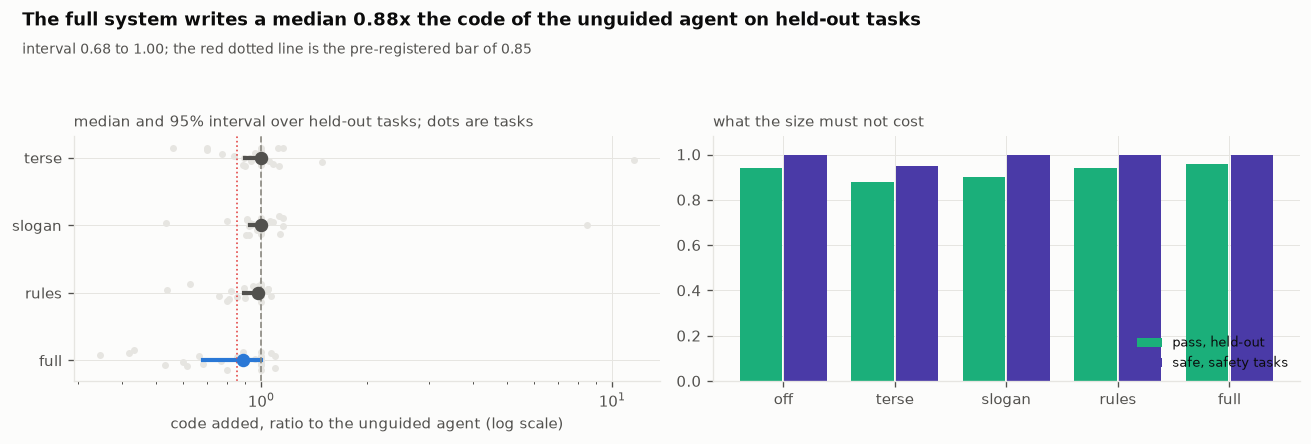

[fig 14] s64_main.png


In [667]:
# FIG  the main comparison
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]                                             # left: the headline, code against the unguided agent
arms_ = [a for a in ARM_NAMES if a != "off"]             # off is the baseline, so it has no ratio of its own
for i, arm in enumerate(arms_):
    med, ci, _, ratios = ratio_summary(MAIN, arm, HELD)
    jitter = np.random.default_rng(i).uniform(-0.15, 0.15, len(ratios))     # a fixed vertical spread, so dots do not overlap
    ax.scatter(list(ratios.values()), np.full(len(ratios), i) + jitter, s=10, color=GRID, zorder=1)   # one dot per task
    arm_colour = C1 if arm == "full" else INK2           # the full system in blue, the others in grey
    ax.plot(ci, [i, i], color=arm_colour, lw=2.5, zorder=2)                  # the 95% interval
    ax.scatter([med], [i], color=arm_colour, s=50, zorder=3)                 # the median
ax.axvline(1, color=MUTED, lw=1, ls="--")                # no difference from the unguided agent
ax.axvline(0.85, color=C8, lw=1, ls=":")                 # the bar H1 registered
ax.set_xscale("log")                                     # ratios: halving and doubling sit the same distance from 1
ax.set_yticks(range(len(arms_)), arms_)
ax.invert_yaxis()                                        # arms read top to bottom in table order
ax.set_xlabel("code added, ratio to the unguided agent (log scale)")
panel(ax, "median and 95% interval over held-out tasks; dots are tasks")
ax = axes[1]                                             # right: what the reduction must not cost
x = np.arange(len(ARM_NAMES))                            # one pair of bars per arm, off included
ax.bar(x - 0.2, [r["pass"] for r in MAIN_ROWS], 0.38, color=C3, label="pass, held-out")        # left bar of each pair
ax.bar(x + 0.2, [r["safe"] for r in MAIN_ROWS], 0.38, color=C7, label="safe, safety tasks")    # right bar
ax.set_xticks(x, ARM_NAMES)
ax.set_ylim(0, 1.08)                                     # a little headroom above 100%
ax.legend(loc="lower right", fontsize=7.5)
panel(ax, "what the size must not cost")
finish(fig, "s64_main", f"The full system writes a median {med1:.2f}x the code of the unguided agent on held-out tasks",
       f"interval {ci1[0]:.2f} to {ci1[1]:.2f}; the red dotted line is the pre-registered bar of 0.85")

**Reading FIG 14 (s64_main).** The left panel is the headline. Each grey dot is one held-out task's ratio of code added (the arm against the unguided agent), and the dark bar is the median with its 95% interval over tasks. The full system's median is 0.88 (interval 0.68 to 1.00); H1 asked for the whole interval to sit below the red line at 0.85, and the verdict after Holm's correction is that it did not. The right panel is the price check: the pass rate on held-out tasks and the safety rate per arm. The difference in safety, full minus off, is +0% (+0% to +0%). Read the two panels together, because either one alone could be produced by a system that is worse.

## S65 - What the controls show

**Theory.** Two control arms are there to rule out cheap explanations. If a one-sentence **terse** instruction ("keep your code short") produced the same reduction as the full system, everything in Parts IV to VI would be decoration. If the **slogan** ("write the least code that works") produced it while keeping safety, the counterweights would be decoration. And the **rules** arm, the full ruleset pasted as static text with none of the machinery, isolates what the hooks, gates and critic add on top of the words (H4). The table compares all of them on the tasks where each mechanism is supposed to matter.

**In plain terms.** Could a one-liner have done the same job? This is where we find out.

In [668]:
# four groups of tasks, each one where a different mechanism is supposed to matter
groups = {"safety tasks": safety,
          "reuse and root cause": [t for t in SUITE.values() if t.category in ("reuse", "root-cause")],
          "over-build": [t for t in SUITE.values() if t.category == "over-build"],
          "held-out": HELD}
rows = []
for name, tasks in groups.items():
    for arm in ARM_NAMES:
        ids = {t.id for t in tasks}                                           # the group's task ids
        rs = [r for r in MAIN if r.arm == arm and r.task in ids and r.score]     # this arm's scored runs in the group
        rows.append({"tasks": name, "arm": arm, "pass": np.mean([r.score.passed for r in rs]),
                     # the safe verdict only exists on the safety tasks
                     "safe": np.mean([r.score.safe == 1 for r in rs]) if name == "safety tasks" else None,
                     "guards": np.mean([r.score.guards for r in rs]),           # guard signatures added per run
                     # the unguided agent is the baseline, so its ratio is 1 by definition
                     "ratio": ratio_summary(MAIN, arm, tasks)[0] if arm != "off" else 1.0})
# every arm within every group: compare down a group, never across groups
table(rows, [("tasks", "tasks", ""), ("arm", "arm", ""), ("pass", "pass", ".0%"), ("safe", "safe", ".0%"),
             ("guards", "guards added", ".1f"), ("ratio", "code vs off", ".2f")])

  tasks                 arm     pass  safe  guards added  code vs off
  -------------------------------------------------------------------
  safety tasks          off     100%  100%           2.5         1.00
  safety tasks          terse    90%   95%           2.4         0.88
  safety tasks          slogan  100%  100%           2.4         0.92
  safety tasks          rules    90%  100%           2.3         0.90
  safety tasks          full    100%  100%           3.0         0.82
  reuse and root cause  off     100%     -           0.2         1.00
  reuse and root cause  terse    83%     -           0.2         1.00
  reuse and root cause  slogan   92%     -           0.1         1.00
  reuse and root cause  rules   100%     -           0.2         1.00
  reuse and root cause  full    100%     -           0.3         0.94
  over-build            off     100%     -           0.5         1.00
  over-build            terse   100%     -           1.0         1.00
  over-build        

The record keys each row as `group|arm`, and adds one verdict: whether the full system showed, on the safety tasks, the asymmetry it is built on.

In [669]:
CONTROLS = {}                                            # the record, keyed 'group|arm'
for r in rows:
    CONTROLS[f"{r['tasks']}|{r['arm']}"] = {"pass": r["pass"], "ratio": r["ratio"], "guards": r["guards"]}
sf, so = CONTROLS["safety tasks|full"], CONTROLS["safety tasks|off"]     # full and off on the safety tasks
# less code, at least as many guards and no lower pass rate, all in the same answers
CONTROLS["asymmetry"] = ("BOTH" if sf["ratio"] < 1 and sf["guards"] >= so["guards"] and sf["pass"] >= so["pass"]
                         else "NOT BOTH")
# the three numbers behind the verdict, so the reading below can be checked against them
print(f"[controls] safety tasks, full against off: code ratio {sf['ratio']:.2f}, guards {sf['guards']:.1f} "
      f"against {so['guards']:.1f}, pass {sf['pass']:.0%} against {so['pass']:.0%}: {CONTROLS['asymmetry']}")
save_exp("controls", CONTROLS)                           # the reading of the controls quotes this record

[controls] safety tasks, full against off: code ratio 0.82, guards 3.0 against 2.5, pass 100% against 100%: BOTH
[exp] artifacts/exp_controls.json


**Reading the controls.** Read each row against the unguided agent in the same group of tasks, never across groups, because the tasks differ. On the ten safety tasks the full system wrote 0.82 times the unguided agent's code, added 3.0 guards per run against 2.5, and passed 100%; the terse instruction passed 90%, the slogan 100% and the pasted rules 90%. That row is the asymmetry the system is built on, visible in the numbers: less structure and more protection in the same answers. On reuse and root-cause tasks the full system's code ratio was 0.94 with a pass rate of 100%.

## S66 - The ablation ledger: every piece must earn its place

**Theory.** The full system is a bundle, and a bundle can hide passengers: pieces that cost tokens and turns and do nothing. The ledger removes one piece at a time and runs the result on the tasks where that piece is supposed to matter, twice each, comparing with the full system on the same tasks and replicas. Each piece has one pre-declared target metric, and the verdict follows a fixed rule. **KEPT** if removing it makes the target measurably worse (the interval excludes zero in the harmful direction); **HARMFUL** if removing it makes the target measurably better; **NEUTRAL** otherwise. Neutral and harmful pieces are removed from the shipped system in S71. That rule is strict on purpose, and it is the same rule the system applies to the code it writes: a component without a measured job is a component someone has to maintain.

**In plain terms.** We take the system apart one piece at a time. A piece that makes no measurable difference gets thrown out.

**How a piece earns its place.** The interval is for the full system minus the system without the piece, on that piece's own target. Only a piece whose removal measurably hurts is kept. Never cut is exempt, because it protects a promise rather than a metric.

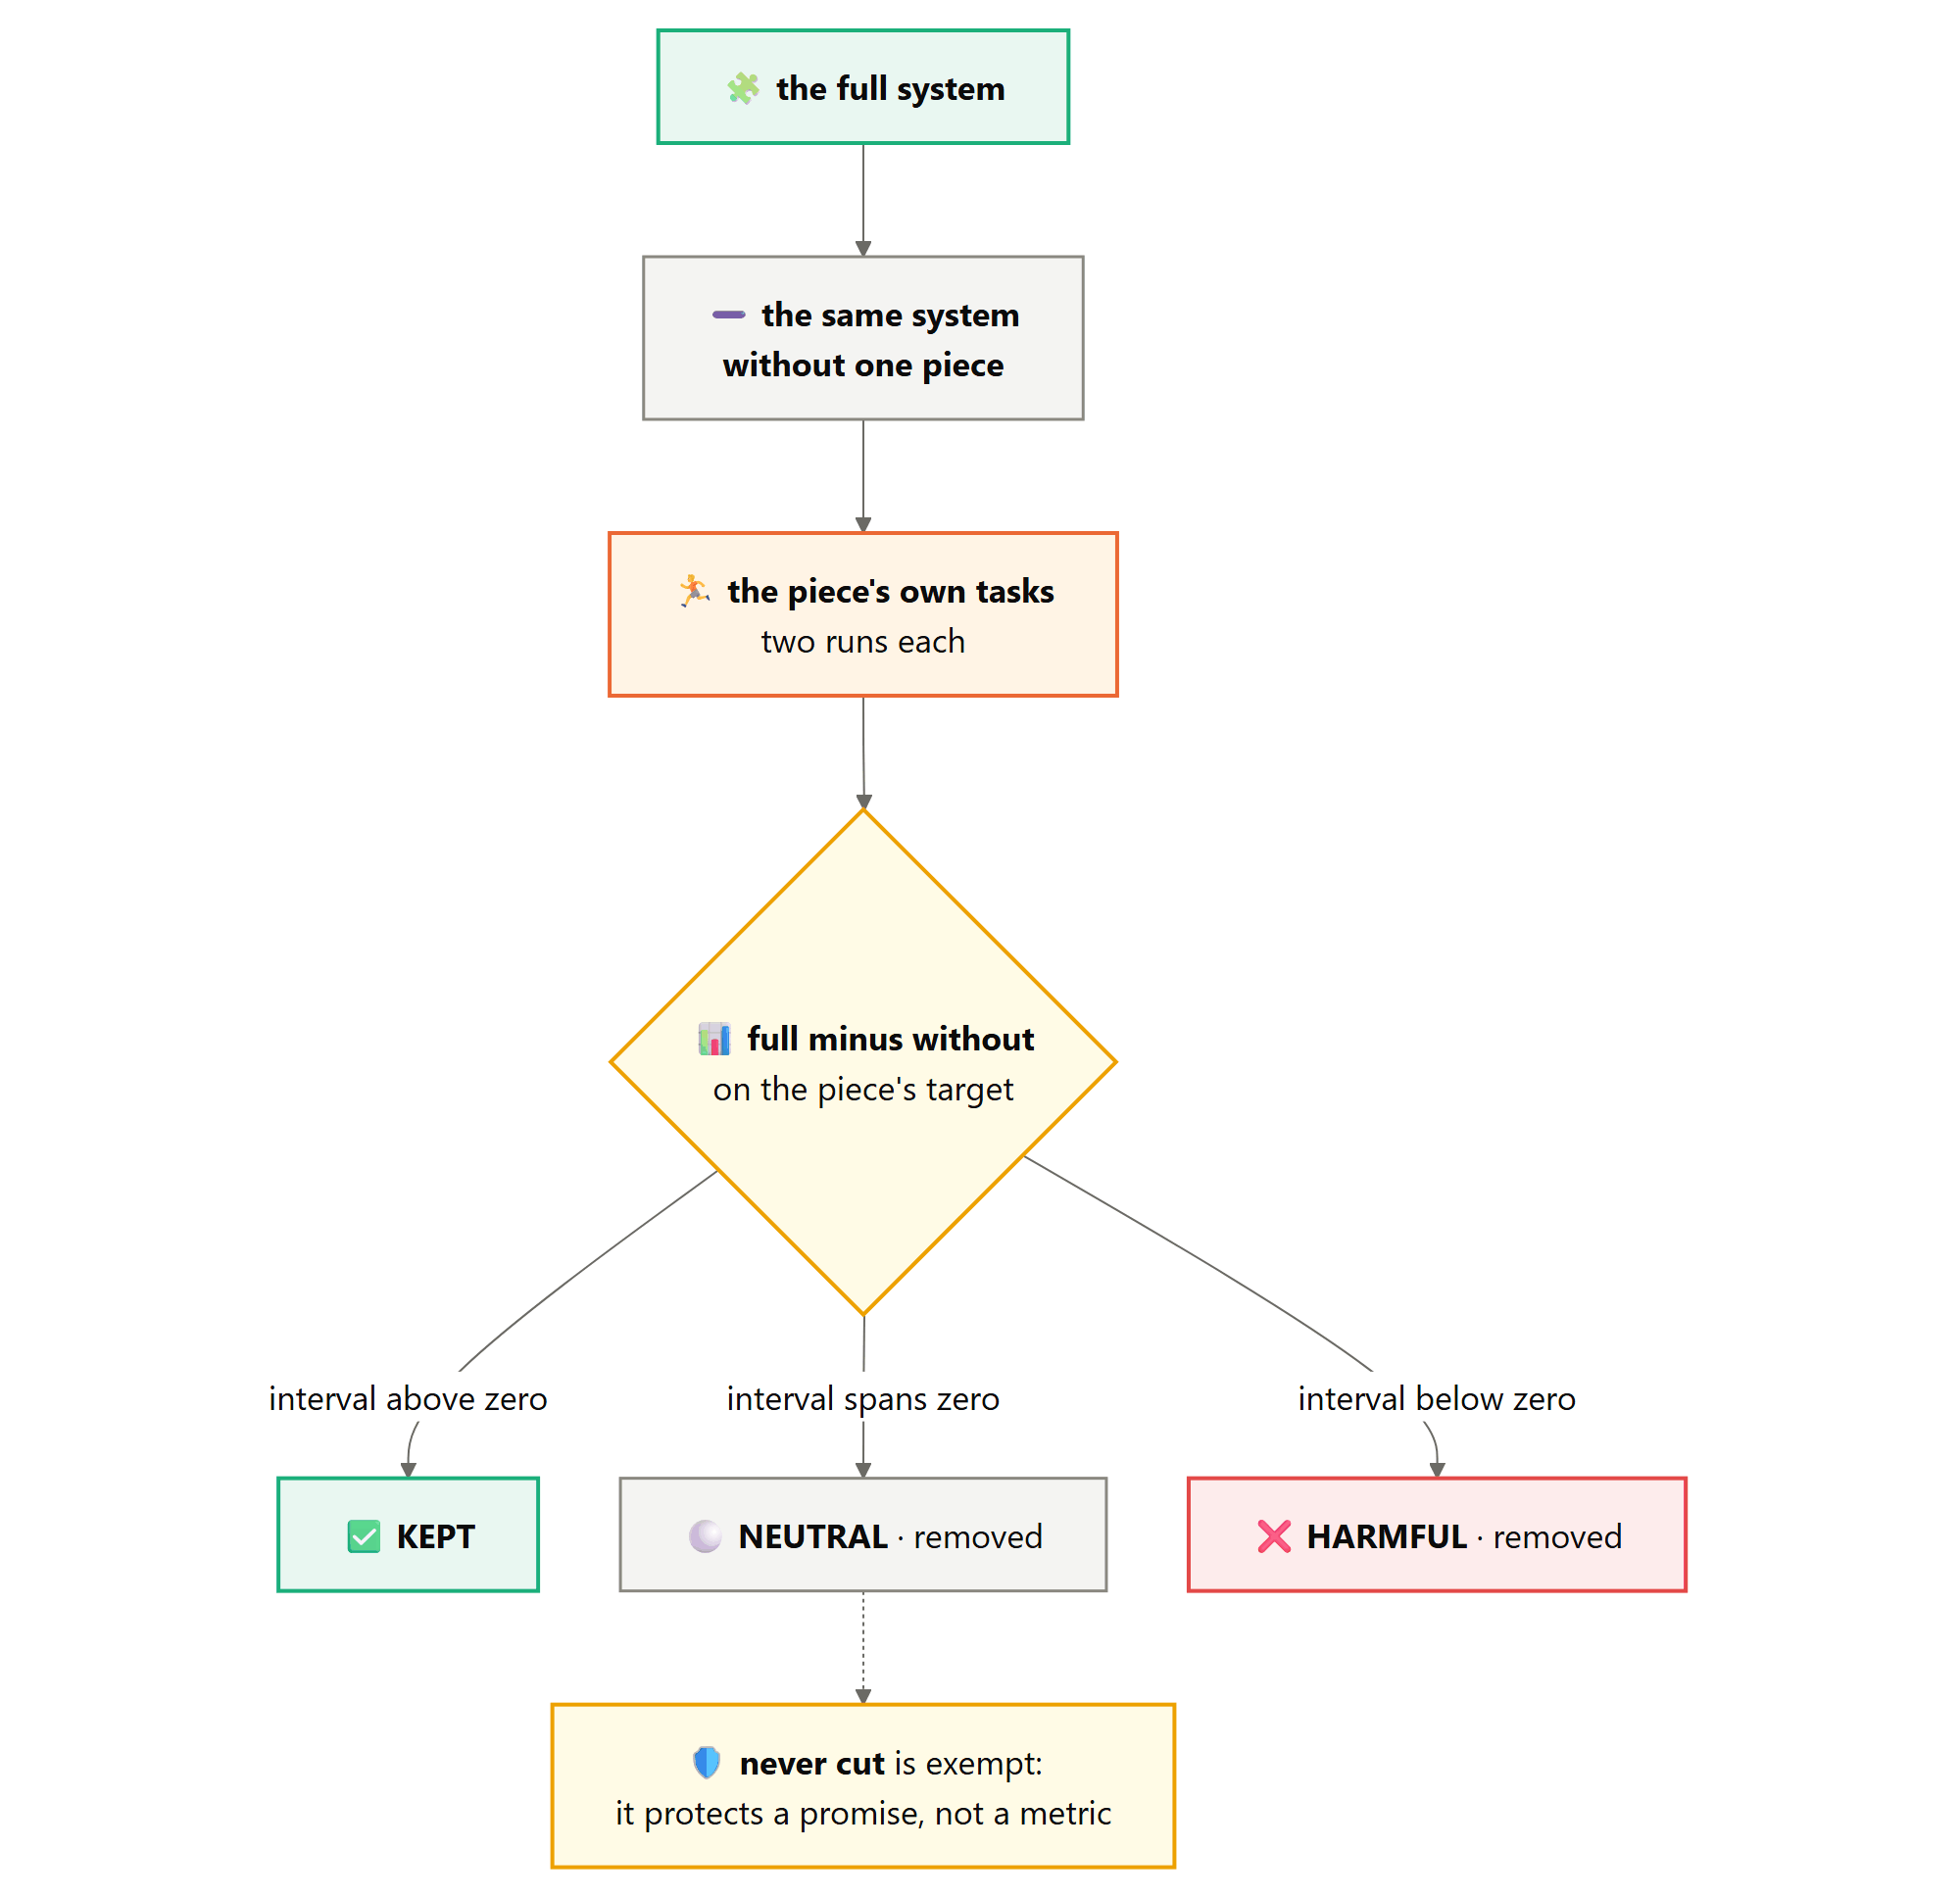

In [670]:
CAT = lambda *cats: [t for t in SUITE.values() if t.category in cats]   # every task in the named categories, in suite order
# piece: (a recipe without it, or None for a rule section; the tasks where it should matter;
#         its target metric, higher is better; the ruleset heading it removes, or None for machinery)
ABLATIONS = {
    # rule sections: ablation_recipe swaps in a plugin that leaves the heading out
    "ladder": (None, CAT("over-build", "edge", "control"), "less code", "What to build: the ladder"),
    "read first": (None, CAT("reuse", "root-cause"), "pass", "Read first"),
    "never cut": (None, CAT("safety"), "safe", "Never cut"),
    "prove it": (None, CAT("over-build"), "check lines", "Prove it"),
    "how to answer": (None, CAT("over-build", "reuse"), "fewer answer words", "How to answer"),
    # machinery: the full system with one keyword switching that piece off
    "project map": (lambda: full_system(map=True), CAT("reuse", "over-build"), "pass", None),
    "read gate": (lambda: full_system(read_gate=True), CAT("reuse", "root-cause"), "pass", None),
    "sibling scan": (lambda: full_system(siblings=True), CAT("root-cause", "reuse"), "pass", None),
    "dependency gate": (lambda: full_system(deps=True), CAT("over-build") + [SUITE["eg-target-runtime"]], "pass", None),
    "check nudge": (lambda: full_system(nudge=True), CAT("over-build"), "check lines", None),
    "critic": (lambda: full_system(critic=True), CAT("over-build", "safety", "open"), "less code", None),
}
print(f"[ablation] {len(ABLATIONS)} pieces: " + ", ".join(ABLATIONS))

[ablation] 11 pieces: ladder, read first, never cut, prove it, how to answer, project map, read gate, sibling scan, dependency gate, check nudge, critic


**`_RulesWithout(section)`** is the plugin with one section of the ruleset cut out, which is how the five rule-section ablations are built. It changes nothing but the text: it lets the plugin's own hooks decide whether to inject, and swaps the `text` of what they return for `ruleset("full", drop=(section,))`. Both injecting hooks are covered, the session start and the prompt hook that puts the rules back when they go missing, so the removed section cannot slip back into the agent's context halfway through an episode.

In [671]:
class _RulesWithout(LeanPlugin):
    """The plugin with one section of the ruleset removed."""

    def __init__(self, section):
        super().__init__(level="full")                   # everything else exactly as in the full system
        self.section = section                           # the heading of the section to leave out

    def on_session_start(self, host, ctx, source, **kw):
        out = super().on_session_start(host, ctx, source, **kw)   # the plugin decides whether to inject at all
        if not out:
            return out
        return {**out, "text": ruleset("full", drop=(self.section,))}   # the same section, minus one heading

    def on_user_prompt(self, host, ctx, prompt, **kw):
        out = super().on_user_prompt(host, ctx, prompt, **kw)
        if out and "section" in out:                     # a re-injection of the rules: drop the section here too
            return {**out, "text": ruleset("full", drop=(self.section,))}
        return out

show_def(_RulesWithout, layer="lab")

[class] _RulesWithout(section)  15 lines, complexity 4


In [672]:
toy_door = LLM("smoke", Ledger(":memory:"), scripted=SCRIPTED)          # offline: nothing here reaches a model
toy_host = Host(llm=toy_door, plugins=[_RulesWithout("Never cut")], label="toy")
toy_host.start_session(materialise(SUITE["sf-share-link"], RUNTIME / "demo" / "rules-without"))   # a safety task's seed
toy_rules = toy_host.ctx.sections.get("lean", (0, ""))[1]               # the rules as this host's model would read them
# the removed heading is gone and its neighbours are still there
print(f"[_RulesWithout] 'Never cut' heading present: {'## Never cut' in toy_rules}; "
      f"'Prove it' heading present: {'## Prove it' in toy_rules}")

[_RulesWithout] 'Never cut' heading present: False; 'Prove it' heading present: True


**`ablation_recipe(name)`** turns a row of the ablation table into a recipe, a function that builds fresh plugins for one host. A machinery piece (the project map, a gate, the critic) already has its recipe in the table: `full_system` with one keyword switching that piece off. A rule section has no keyword, so its recipe is made here: the full system with `_RulesWithout` in place of the plugin, and the gates, critic and skills unchanged.

In [673]:
def ablation_recipe(name):
    recipe, _, _, section = ABLATIONS[name]              # the tasks and the metric are not needed to build plugins
    if section:                                          # a rule section: swap the plugin, keep the rest of the system
        return lambda: [_RulesWithout(section), LeanGates(), LeanCritic(), LeanSkills()]
    return recipe

show_def(ablation_recipe, layer="lab")

[def] ablation_recipe(name)  5 lines, complexity 2


In [674]:
for toy_name in ("never cut", "critic"):                 # one rule section, one piece of machinery
    toy_plugins = ablation_recipe(toy_name)()            # a recipe is called to get fresh plugins
    print(f"[ablation_recipe] without {toy_name}: " + ", ".join(type(p).__name__ for p in toy_plugins))

[ablation_recipe] without never cut: _RulesWithout, LeanGates, LeanCritic, LeanSkills
[ablation_recipe] without critic: LeanPlugin, LeanGates, LeanSkills


Each piece is judged on one target, and every target is turned so that higher is better: fewer lines of code and fewer answer words count as gains, like a higher pass rate does. One rule then reads every row the same way.

In [675]:
TARGET = {"less code": lambda r: -(r.score.added_code),                                   # fewer lines scores higher
          "pass": lambda r: float(r.score.passed),                                        # 1 for a pass, 0 otherwise
          "safe": lambda r: float(r.score.safe == 1),                                     # the safety verdict alone
          "check lines": lambda r: float(r.score.added_check + r.score.added_test),      # a self-check or a test, either counts
          "fewer answer words": lambda r: -float(check_contract(r.episode.done_text)["words"])}   # a shorter answer scores higher
print(f"[ablation] targets: {', '.join(TARGET)}")

[ablation] targets: less code, pass, safe, check lines, fewer answer words


Then each piece is removed in turn and run on its own tasks, two replicas each. The full system's runs on the same tasks come from the main grid, and the verdict follows the rule written down in S61.

In [676]:
ABL_RUNS, LEDGER_ROWS = {}, []                           # the runs per piece, and one ledger row per piece
for name, (_, tasks, metric, _) in ABLATIONS.items():
    recipes = {f"-{name}": ablation_recipe(name), "full": ARMS["full"]}    # the arm without the piece is called '-piece'
    runs = run_grid([f"-{name}"], tasks, recipes=recipes, label=f"without {name}")   # two replicas, the piece's own tasks
    ABL_RUNS[name] = runs                                # kept for the task-by-task view below
    # the full system's main-grid runs on the same tasks are the other side of each pair
    both = runs + [r for r in MAIN if r.arm == "full" and r.task in {t.id for t in tasks}]
    diff, ci, _ = rate_summary(both, "full", tasks, TARGET[metric], base=f"-{name}")   # full minus without
    if ci[0] > 0:
        verdict = "KEPT"                                 # without it, the target got measurably worse
    elif ci[1] < 0:
        verdict = "HARMFUL"                              # without it, the target got measurably better
    else:
        verdict = "NEUTRAL"                              # no difference this experiment could see
    LEDGER_ROWS.append({"piece": name, "tasks": len(tasks), "target": metric, "effect": diff, "lo": ci[0], "hi": ci[1],
                        "verdict": verdict})

  [without ladder] 4/28 episodes, 3s, 0 failed


  [without ladder] 8/28 episodes, 4s, 0 failed


  [without ladder] 12/28 episodes, 5s, 0 failed
  [without ladder] 16/28 episodes, 5s, 0 failed
  [without ladder] 20/28 episodes, 5s, 0 failed


  [without ladder] 24/28 episodes, 6s, 0 failed


  [without ladder] 28/28 episodes, 7s, 0 failed


...

  [without check nudge] 14/16 episodes, 5s, 0 failed
  [without check nudge] 16/16 episodes, 5s, 0 failed


  [without critic] 6/40 episodes, 2s, 0 failed
  [without critic] 12/40 episodes, 2s, 0 failed


  [without critic] 18/40 episodes, 4s, 0 failed
  [without critic] 24/40 episodes, 4s, 0 failed


  [without critic] 30/40 episodes, 6s, 0 failed


  [without critic] 36/40 episodes, 8s, 0 failed
  [without critic] 40/40 episodes, 8s, 0 failed


In [677]:
# one row per piece: the effect of having it, its interval, and the verdict the rule gives
table(LEDGER_ROWS, [("piece", "piece removed", ""), ("tasks", "tasks", "d"), ("target", "target", ""), ("effect", "full minus without", ".2f"),
                    ("lo", "low", ".2f"), ("hi", "high", ".2f"), ("verdict", "verdict", "")])
save_exp("ablation", {r["piece"]: {k: r[k] for k in ("effect", "lo", "hi", "verdict", "target")} for r in LEDGER_ROWS})   # S71 builds on it

  piece removed    tasks  target              full minus without    low   high  verdict
  -------------------------------------------------------------------------------------
  ladder              14  less code                         1.21   0.21   2.61  KEPT
  read first           6  pass                              0.00   0.00   0.00  NEUTRAL
  never cut           10  safe                              0.15   0.00   0.35  NEUTRAL
  prove it             8  check lines                       1.19  -3.00   5.75  NEUTRAL
  how to answer       11  fewer answer words                5.45  -9.55  20.77  NEUTRAL
  project map         11  pass                              0.05   0.00   0.14  NEUTRAL
  read gate            6  pass                              0.00   0.00   0.00  NEUTRAL
  sibling scan         6  pass                              0.00   0.00   0.00  NEUTRAL
  dependency gate      9  pass                              0.00   0.00   0.00  NEUTRAL
  check nudge          8  check lin

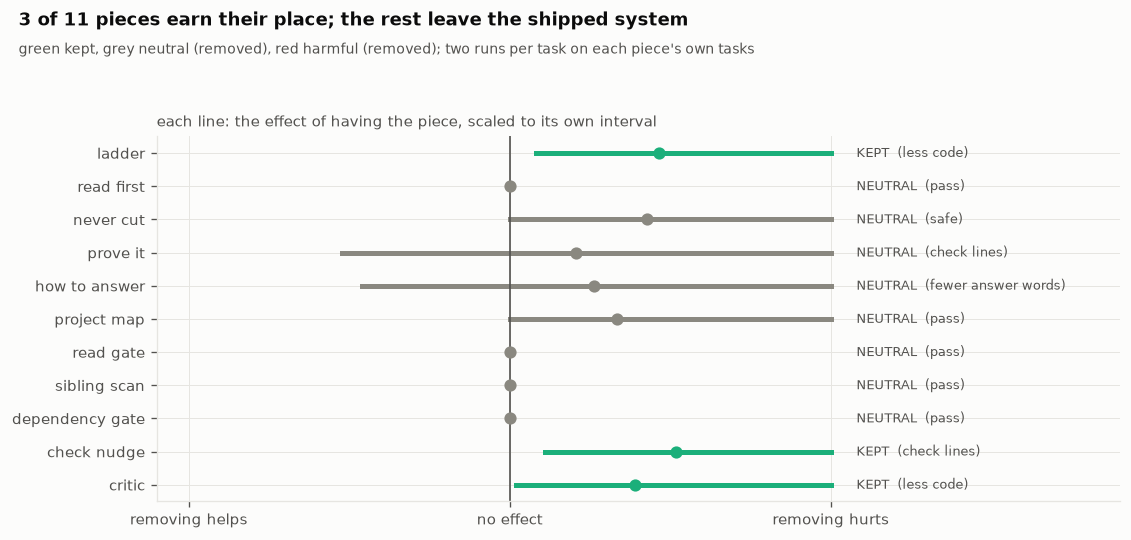

[fig 15] s66_ablation.png


In [678]:
# FIG  the ablation ledger
fig, ax = plt.subplots(figsize=(9.5, 4.6))
colour = {"KEPT": C3, "NEUTRAL": MUTED, "HARMFUL": C8}   # green kept; grey and red both leave the shipped system
for i, r in enumerate(LEDGER_ROWS):
    scale = max(abs(r["lo"]), abs(r["hi"]), 1e-9)         # each row on its own scale: the targets have different units
    ax.plot([r["lo"] / scale, r["hi"] / scale], [i, i], color=colour[r["verdict"]], lw=3)     # the interval
    ax.scatter([r["effect"] / scale], [i], color=colour[r["verdict"]], s=40, zorder=3)        # the estimate
    ax.text(1.08, i, f"{r['verdict']}  ({r['target']})", va="center", fontsize=7.5, color=INK2)   # verdict at the right
ax.axvline(0, color=INK2, lw=1)                           # no effect
ax.set_yticks(range(len(LEDGER_ROWS)), [r["piece"] for r in LEDGER_ROWS])     # pieces by name
ax.invert_yaxis()                                         # pieces read top to bottom in ledger order
ax.set_xlim(-1.1, 1.9)                                    # room on the right for the verdict labels
ax.set_xticks([-1, 0, 1], ["removing helps", "no effect", "removing hurts"])
panel(ax, "each line: the effect of having the piece, scaled to its own interval")
kept = sum(r["verdict"] == "KEPT" for r in LEDGER_ROWS)   # for the title
finish(fig, "s66_ablation", f"{kept} of {len(LEDGER_ROWS)} pieces earn their place; the rest leave the shipped system",
       "green kept, grey neutral (removed), red harmful (removed); two runs per task on each piece's own tasks")

**Reading FIG 15 (s66_ablation).** Each row is one piece of the system and the effect of *having* it, on the metric it was built to move, measured on the tasks where it should matter. Green rows earned their place: without them the target got measurably worse. Grey rows made no measurable difference with this many tasks and runs, and red rows did harm; both leave the shipped configuration. A grey row is not proof that a piece is useless, only that this experiment could not see it help, and the right response to that is to remove it until someone can show otherwise. 0.67 was the smallest code ratio the pilot said the main run could detect; ablations on subsets have less power still, which Part VIII discusses.

**The ledger, task by task.** A mean effect can hide a piece that helps a great deal on two tasks and hurts on a third. The cells below print, for the piece with the largest effect, its difference on every task it was measured on, and the widget does the same for any piece.

**`ablation_by_task(name)`** gives one piece's effect task by task: the full system's value on the piece's target minus the value without it, each averaged over replicas. It builds the same pool of runs the ledger used and pairs them with `per_task`, so the mean of its values is exactly the ledger's effect for that piece. Where the ledger's one number can hide a piece that helps a lot on two tasks and hurts on a third, this list shows it.

In [679]:
def ablation_by_task(name):
    """{task: full minus without} on the piece's target metric, one value per task."""
    _, tasks, metric, _ = ABLATIONS[name]
    # the ledger's own pool: the runs without the piece, and the main grid's full runs on the same tasks
    both = ABL_RUNS[name] + [r for r in MAIN if r.arm == "full" and r.task in {t.id for t in tasks}]
    a = per_task(both, "full", TARGET[metric], tasks)              # with the piece
    b = per_task(both, f"-{name}", TARGET[metric], tasks)          # without it
    diffs = {}
    for t in a:
        if t in b:                                       # tasks with both sides only, as in the ledger
            diffs[t] = a[t] - b[t]
    return diffs

show_def(ablation_by_task, layer="lab")

[def] ablation_by_task(name)  11 lines, complexity 6


In [680]:
top = max(LEDGER_ROWS, key=lambda r: abs(r["effect"]))["piece"]   # the largest effect, in either direction
print(f"[ledger] '{top}', full minus without, task by task:")
for t, d in sorted(ablation_by_task(top).items(), key=lambda kv: kv[1]):   # most harmful first
    print(f"  {t:<22} {d:+.2f}")

[ledger] 'how to answer', full minus without, task by task:
  ob-ferry-localtime     -33.50
  ru-trip-duration       -14.50
  ob-postcode-cache      -12.00
  ob-member-unique       -10.50
  ob-settings-defaults   -8.00
  ob-expense-totals      -3.00
  ob-report-flags        +0.00
  ru-attachment-name     +11.50
  ru-badge-name          +35.50
  ob-tags-dedupe         +46.50
  ob-sensor-retry        +48.00


In [681]:
# W4: one piece of the ledger at a time, per task
W = widgets()
if W:
    from IPython.display import display
    # starts on the same piece as the static list above
    piece_box = W.Dropdown(options=[r["piece"] for r in LEDGER_ROWS], value=top, description="piece")
    out = W.Output()                                     # the chart is redrawn in here on every change

    def _ledger(change=None):
        out.clear_output(wait=True)                      # replace the old chart only once the new one is ready
        with out:
            row = next(r for r in LEDGER_ROWS if r["piece"] == piece_box.value)             # its ledger row
            vals = sorted(ablation_by_task(piece_box.value).items(), key=lambda kv: kv[1])  # most harmful task first
            bar_colours = []
            for _, v in vals:
                if v > 0:
                    bar_colours.append(C3)               # green: having the piece helped on this task
                elif v < 0:
                    bar_colours.append(C8)               # red: it hurt
                else:
                    bar_colours.append(MUTED)            # grey: no difference
            fig, ax = plt.subplots(figsize=(9, 2.8))
            ax.bar(range(len(vals)), [v for _, v in vals], color=bar_colours)           # one bar per task
            ax.axhline(row["effect"], color=INK, lw=1.2, ls="--")       # the ledger's mean effect
            ax.axhline(0, color=MUTED, lw=0.8)                          # no difference
            ax.set_xticks(range(len(vals)), [t for t, _ in vals], rotation=60, ha="right", fontsize=7)   # task ids
            ax.set_title(f"{piece_box.value}: {row['target']}, full minus without; mean {row['effect']:+.2f} ({row['verdict']})",
                         fontsize=9, loc="left", color=INK2)
            plt.show()

    piece_box.observe(_ledger, names="value")            # redraw whenever another piece is chosen
    display(W.VBox([piece_box, out]))
    _ledger()                                            # the first chart, before anyone touches the dropdown
else:
    print("(no widget in this run, which needs a live Jupyter session; the ledger table and the list above are the static version)")

(no widget in this run, which needs a live Jupyter session; the ledger table and the list above are the static version)


## S67 - Three levels

**Theory.** If the rules really drive the reduction, their strength should matter: lite (build, then name a leaner option) should cut least, ultra (start from deletion) most. The same comparison is the place to look for the cost we expect ultra to pay: pushing harder towards less code is what could drop a requirement on the explicit and open tasks (H6).

**In plain terms.** Turn the strength up and down and watch both the code size and the pass rate.

In [682]:
# lite and ultra on every task, once each; the full level's runs come from the main grid
LEVEL_RUNS = run_grid(["lite", "ultra"], list(SUITE.values()), replicas=[0],
                      recipes={"lite": lambda: full_system(level="lite"), "ultra": lambda: full_system(level="ultra")},
                      label="levels")

  [levels] 11/68 episodes, 3s, 0 failed


  [levels] 22/68 episodes, 5s, 0 failed


  [levels] 33/68 episodes, 6s, 0 failed


  [levels] 44/68 episodes, 8s, 0 failed


  [levels] 55/68 episodes, 12s, 0 failed
  [levels] 66/68 episodes, 12s, 0 failed
  [levels] 68/68 episodes, 12s, 0 failed


In [683]:
pool_ = LEVEL_RUNS + [r for r in MAIN if r.arm in ("full", "off") and r.replica == 0]   # first replica only, like the levels
rows = []
for arm in ("lite", "full", "ultra"):                    # weakest to strongest
    med, ci, _, _ = ratio_summary(pool_, arm, list(SUITE.values()))     # against the unguided agent, every task
    rs = [r for r in pool_ if r.arm == arm and r.score]  # this level's scored runs
    rows.append({"level": arm, "ratio": med, "ci": f"{ci[0]:.2f} to {ci[1]:.2f}", "pass": np.mean([r.score.passed for r in rs]),
                 # where pushing for less code could drop a requirement (H6)
                 "explicit/open": np.mean([r.score.passed for r in rs if SUITE[r.task].category in ("explicit", "open")])})
table(rows, [("level", "level", ""), ("ratio", "code vs off", ".2f"), ("ci", "95% interval", ""), ("pass", "pass", ".0%"),
             ("explicit/open", "pass, explicit and open", ".0%")])
save_exp("levels", {r["level"]: {"ratio": r["ratio"], "pass": r["pass"], "explicit_open": r["explicit/open"]} for r in rows})   # H6

  level  code vs off  95% interval  pass  pass, explicit and open
  ---------------------------------------------------------------
  lite          1.00  0.79 to 1.00   94%                      75%
  full          0.90  0.75 to 1.00   97%                      75%
  ultra         0.93  0.80 to 1.00   97%                     100%
[exp] artifacts/exp_levels.json


## S68 - Six models

**Theory.** A result on one model is a result about that model. The transfer sweep runs the unguided agent and the full system on twelve tasks (at least one from every category) with each of the six models, once each. Two questions matter. Does the direction of the effect hold across models, even where its size varies? And what does it cost: reasoning models think before they answer, and a longer instruction can make them think longer, so reasoning per call is reported as a bound on the price (H7), not as a success criterion.

**In plain terms.** The same comparison with every model we have, to see whether the effect belongs to the system or to one model.

In [684]:
# twelve tasks covering every category, small enough to run on six models
TRANSFER_TASKS = [SUITE[i] for i in ("ob-postcode-cache", "ob-report-flags", "ob-member-unique", "ru-badge-name", "rc-stock-take",
                                    "sf-share-link", "sf-feedback-body", "ct-already-cached", "ex-ttl-cache", "op-word-freq",
                                    "eg-batches", "eg-target-runtime")]
print(f"[transfer] {len(TRANSFER_TASKS)} tasks from {len({t.category for t in TRANSFER_TASKS})} categories")   # all eight

[transfer] 12 tasks from 8 categories


In [685]:
TRANSFER = []                                            # every run of the five other models
for role in ("judge", "judge2", "fast", "big", "omni"):  # the coder's own runs come from the main grid
    model = MODEL_FOR[role]                              # the model behind this role
    # the role goes into the arm's name, so runs from different models never meet in one comparison
    recipes = {f"off@{role}": lambda: [], f"full@{role}": lambda: full_system()}
    TRANSFER += run_grid(list(recipes), TRANSFER_TASKS, replicas=[0], recipes=recipes, label=f"transfer {role}",
                         model=model, max_failed=1.0)     # a model that fails here is a result, not a reason to stop
    print(f"  [transfer] {model.split('/')[-1]} done, {sum(bool(r.error) for r in TRANSFER if r.arm.endswith(role))} failed")   # failures so far

  [transfer judge] 4/24 episodes, 2s, 0 failed
  [transfer judge] 8/24 episodes, 2s, 0 failed
  [transfer judge] 12/24 episodes, 2s, 0 failed


  [transfer judge] 16/24 episodes, 3s, 0 failed
  [transfer judge] 20/24 episodes, 3s, 0 failed


  [transfer judge] 24/24 episodes, 3s, 0 failed
  [transfer] Qwen3.7-Max done, 0 failed


  [transfer judge2] 4/24 episodes, 2s, 0 failed
  [transfer judge2] 8/24 episodes, 2s, 0 failed
  [transfer judge2] 12/24 episodes, 2s, 0 failed


  [transfer judge2] 16/24 episodes, 3s, 0 failed
  [transfer judge2] 20/24 episodes, 3s, 0 failed


...

  [transfer fast] 16/24 episodes, 7s, 0 failed
  [transfer fast] 20/24 episodes, 7s, 0 failed
  [transfer fast] 24/24 episodes, 7s, 0 failed
  [transfer] Qwen3.8-Flash-Next done, 0 failed


  [transfer big] 4/24 episodes, 5s, 0 failed
  [transfer big] 8/24 episodes, 5s, 0 failed
  [transfer big] 12/24 episodes, 5s, 0 failed
  [transfer big] 16/24 episodes, 5s, 0 failed
  [transfer big] 20/24 episodes, 5s, 0 failed
  [transfer big] 24/24 episodes, 5s, 0 failed
  [transfer] Qwen3.8-Max done, 0 failed


  [transfer omni] 4/24 episodes, 3s, 0 failed


  [transfer omni] 8/24 episodes, 4s, 0 failed
  [transfer omni] 12/24 episodes, 4s, 0 failed
  [transfer omni] 16/24 episodes, 4s, 0 failed
  [transfer omni] 20/24 episodes, 4s, 0 failed


  [transfer omni] 24/24 episodes, 4s, 0 failed
  [transfer] Qwen3.8-Omni-Flash done, 0 failed


For each model: the code ratio with its interval, the pass rates, reasoning characters per call under each arm, and the full system's protocol error rate, which decides whether the model can be judged at all.

In [686]:
rows = []                                                 # one row per model
# the coder's first replica on the same twelve tasks, so every model is compared on equal terms
coder_pool = [r for r in MAIN if r.arm in ("off", "full") and r.replica == 0 and r.task in {t.id for t in TRANSFER_TASKS}]
for role in ("coder", "judge", "judge2", "fast", "big", "omni"):
    if role == "coder":
        # the coder's main-grid runs, renamed into the same 'arm@role' form as the others
        pool_ = [Run(f"{r.arm}@coder", r.task, 0, r.episode, r.score, r.error) for r in coder_pool]
    else:
        pool_ = [r for r in TRANSFER if r.arm.endswith("@" + role)]   # this model's runs, both arms
    med, ci, _, _ = ratio_summary(pool_, f"full@{role}", TRANSFER_TASKS, base=f"off@{role}")   # paired within the model
    rs = {a: [r for r in pool_ if r.arm == f"{a}@{role}" and r.episode] for a in ("off", "full")}   # episodes per arm
    arm_turns = {}                                       # arm: every turn this model took under it
    for a in rs:
        arm_turns[a] = []
        for r in rs[a]:
            arm_turns[a].extend(r.episode.turns)         # every turn of every episode the arm ran on this model
    reason = {}
    for a in rs:
        # reasoning characters per model call; nan when the arm has no episode at all
        reason[a] = np.mean([t.reasoning_chars for t in arm_turns[a]]) if rs[a] else float("nan")
    # the model's short name; pass rates are None for an arm with no episode at all
    rows.append({"model": MODEL_FOR[role].split("/")[-1], "ratio": med, "ci": f"{ci[0]:.2f} to {ci[1]:.2f}",
                 "pass off": np.mean([r.score.passed for r in rs["off"] if r.score]) if rs["off"] else None,
                 "pass full": np.mean([r.score.passed for r in rs["full"] if r.score]) if rs["full"] else None,
                 "reasoning off": reason["off"], "reasoning full": reason["full"],
                 # the share of the full system's turns with no usable action
                 "protocol": np.mean([t.action == "none" for t in arm_turns["full"]]) if rs["full"] else None})
print("[transfer] one row per model: " + ", ".join(r["model"] for r in rows))

[transfer] one row per model: Qwen3.8-27B, Qwen3.7-Max, Qwen3.7-Plus, Qwen3.8-Flash-Next, Qwen3.8-Max, Qwen3.8-Omni-Flash


In [687]:
for r in rows:
    # more than 30% protocol errors: reported, not judged, as S61 registered
    r["verdict"] = "not evaluable" if (r["protocol"] or 0) > 0.30 else "evaluated"
# reasoning per call is H7's cost bound; the protocol column decides whether a row can be judged at all
table(rows, [("model", "model", ""), ("verdict", "verdict", ""), ("ratio", "code, full vs off", ".2f"), ("ci", "95% interval", ""),
             ("pass off", "pass off", ".0%"),
             ("pass full", "pass full", ".0%"), ("reasoning off", "reasoning/call off", ".0f"),
             ("reasoning full", "reasoning/call full", ".0f"), ("protocol", "protocol errors", ".1%")])
# one entry per model, keyed by its short name
save_exp("transfer", {r["model"]: {k: r[k] for k in ("ratio", "pass off", "pass full", "reasoning off", "reasoning full",
                                                      "protocol", "verdict")} for r in rows})

  model               verdict    code, full vs off  95% interval  pass off  pass full  reasoning/call off  reasoning/call full  protocol errors
  ---------------------------------------------------------------------------------------------------------------------------------------------
  Qwen3.8-27B         evaluated               0.86  0.52 to 0.97      100%       100%                1287                 1890             0.0%
  Qwen3.7-Max         evaluated               0.59  0.39 to 0.77       83%        92%                 611                  589             2.1%
  Qwen3.7-Plus        evaluated               1.00  0.83 to 1.12       92%       100%                 388                  577             0.6%
  Qwen3.8-Flash-Next  evaluated               0.44  0.29 to 0.68       92%        92%                1819                 1189             8.4%
  Qwen3.8-Max         evaluated               0.87  0.38 to 0.98       92%       100%                1521                 1593          

## S69 - Goodhart: what if the goal were simply fewer lines?

**Theory.** Everything in this notebook measures lines of code, which makes it vulnerable to Goodhart's law: optimise a measure and it stops measuring what you wanted. The test is an arm whose only instruction is the measure itself ("use as few lines of code as possible; shorter is always better"). If that arm wins on lines while losing on golf score (S3b) or on safety, it shows two things at once: that the measure can be gamed, and that the full system's smaller code is not the same thing as gaming it (H8).

**In plain terms.** We tell one agent to write as few lines as possible, full stop, and see what that does to readability and safety.

In [688]:
# the measure itself as the only instruction, sent exactly as written
FEWEST = "Use as few lines of code as possible. Shorter is always better."
# one run per task, as for the levels
GOODHART = run_grid(["fewest"], list(SUITE.values()), replicas=[0], recipes={"fewest": lambda: [StaticRules(FEWEST)]},
                    label="fewest lines")
pool_ = GOODHART + [r for r in MAIN if r.arm in ("off", "full") and r.replica == 0]   # compared on the first replica
print(f"[goodhart] {len(GOODHART)} fewest-lines runs, compared with {len(pool_) - len(GOODHART)} unguided and full runs")

  [fewest lines] 5/34 episodes, 3s, 0 failed
  [fewest lines] 10/34 episodes, 3s, 0 failed


  [fewest lines] 15/34 episodes, 3s, 0 failed
  [fewest lines] 20/34 episodes, 3s, 0 failed
  [fewest lines] 25/34 episodes, 3s, 0 failed


  [fewest lines] 30/34 episodes, 7s, 0 failed
  [fewest lines] 34/34 episodes, 7s, 0 failed
[goodhart] 34 fewest-lines runs, compared with 68 unguided and full runs


**`golf_of(r)`** adds up the golf score from S3b over every Python file a run's agent wrote or rewrote, test files left out. It reads the workspace the episode left behind, so it measures the code the agent actually produced. A file the detector cannot parse adds nothing instead of stopping the count, and the total is per run, which is what the table averages.

In [689]:
def golf_of(r):
    final = snapshot(r.episode.ws)                       # the workspace as the episode left it
    changed = []                                         # the source of every file the agent wrote or rewrote
    for p, s in final.items():
        # Python the agent wrote or rewrote, test files left out
        if p.endswith(".py") and s != SUITE[r.task].seed.get(p) and not is_test_file(p):
            changed.append(s)
    return sum((golf_score(s)["score"] or 0) for s in changed)   # a file that does not parse scores None: counted as 0

show_def(golf_of, layer="lab")

[def] golf_of(r)  7 lines, complexity 7


In [690]:
rows = []
for arm in ("off", "full", "fewest"):
    rs = [r for r in pool_ if r.arm == arm and r.score and r.episode]   # golf_of needs the workspace, so the episode too
    rows.append({"arm": arm,
                 # the unguided agent is the baseline, so its ratio is 1 by definition
                 "ratio": ratio_summary(pool_, arm, list(SUITE.values()))[0] if arm != "off" else 1.0,
                 "golf": np.mean([golf_of(r) for r in rs]), "pass": np.mean([r.score.passed for r in rs]),
                 "safe": np.mean([r.score.safe == 1 for r in rs if SUITE[r.task].category == "safety"])})   # safety tasks only
# fewer lines alone is not the goal: the golf and safe columns say what the lines cost
table(rows, [("arm", "arm", ""), ("ratio", "code vs off", ".2f"), ("golf", "golf score per task", ".2f"), ("pass", "pass", ".0%"),
             ("safe", "safe", ".0%")])

  arm     code vs off  golf score per task  pass  safe
  ----------------------------------------------------
  off            1.00                 0.06   94%  100%
  full           0.90                 0.32   97%  100%
  fewest         0.92                 0.29   94%  100%


In [691]:
GH = {r["arm"]: r for r in rows}                         # the three rows by arm
# the three arms' numbers, then the two verdicts the reading below picks its sentences by
save_exp("goodhart", {r["arm"]: {k: r[k] for k in ("ratio", "golf", "pass", "safe")} for r in rows}
         # H8: did the bare instruction produce the most compressed code of the three?
         | {"h8": "GOLFED" if GH["fewest"]["golf"] > max(GH["full"]["golf"], GH["off"]["golf"]) else "NOT GOLFED",
            # and the uncomfortable question: is the full system's own code more compressed than the unguided agent's?
            "full_golfs_more": "YES" if GH["full"]["golf"] > GH["off"]["golf"] else "NO"})

[exp] artifacts/exp_goodhart.json


**Reading the Goodhart arm.** Told only to write fewer lines, the agent's code ratio was 0.92 against the unguided agent, with a golf score of 0.29 (the unguided agent 0.06, the full system 0.32) and 100% of safety verdicts kept. H8 expected the bare instruction to produce the most cryptic code, and it did not: on this suite, being told to write less did not by itself push the model into golfing. The uncomfortable number is the full system's own: its code scores as more compressed than the unguided agent's, so the rule against clever code did not fully hold, and S83 lists it with the other results that went against the system.

## S70 - The rule-change gate

**Theory.** Rules attract additions. Every failure suggests a new sentence, and a ruleset that grows by accumulation becomes long, contradictory and expensive, sent with every call. The defence is a gate: a proposed edit ships only if it beats the current ruleset on its target, measured on tasks including one it could plausibly break, with enough runs to see a difference, and **a tie does not ship**. The candidate below sounds reasonable and is the kind of line that gets added after a review complains about loops: *"Prefer comprehensions and one-line expressions to loops."* Its risk is obvious once stated: it pushes towards the golfed code that S3b and S69 warn about. It goes through the gate like any other edit.

**In plain terms.** A new rule has to prove it helps before it gets in; "no worse" is not enough.

In [692]:
# the proposed edit, sent to the model exactly as written
CANDIDATE = "Prefer comprehensions and one-line expressions to loops."
# six tasks, including ones the edit could plausibly break
GATE_TASKS = [SUITE[i] for i in ("ob-tags-dedupe", "op-word-freq", "sf-meter-import", "eg-batches", "ob-expense-totals",
                                "sf-feedback-body")]
print(f"[gate] candidate {CANDIDATE!r}")                 # the edit, exactly as it would be added
print(f"  tested on {', '.join(t.id for t in GATE_TASKS)}")

[gate] candidate 'Prefer comprehensions and one-line expressions to loops.'
  tested on ob-tags-dedupe, op-word-freq, sf-meter-import, eg-batches, ob-expense-totals, sf-feedback-body


**`_RulesPlus`** is the plugin with the candidate line added to the ruleset, placed in the ladder section just before the line about not speeding up what nobody has measured. Putting it beside an existing line, where a maintainer would actually write it, tests the edit as it would ship rather than a sentence tacked on at the end. Only the text changes; the plugin still decides when to inject, and the gates, critic and skills are the full arm's.

In [693]:
class _RulesPlus(LeanPlugin):
    """The plugin with one extra line inserted into the ladder section."""

    def on_session_start(self, host, ctx, source, **kw):
        out = super().on_session_start(host, ctx, source, **kw)   # the plugin decides whether to inject at all
        if not out:
            return out
        # the candidate goes on its own line, just before an existing line of the ladder section
        text = out["text"].replace("Do not speed up what nobody has measured",
                                   CANDIDATE + "\nDo not speed up what nobody has measured")
        return {**out, "text": text}

show_def(_RulesPlus, layer="lab")

[class] _RulesPlus(level=None, header=True, reinject_on_compact=True, subagents=True,...)  9 lines, complexity 2


In [694]:
toy_host = Host(llm=toy_door, plugins=[_RulesPlus(level="full")], label="toy")   # the same offline door as above
toy_host.start_session(materialise(SUITE["eg-batches"], RUNTIME / "demo" / "rules-plus"))   # one of the gate's tasks
toy_rules = toy_host.ctx.sections.get("lean", (0, ""))[1]              # the rules this host's model would read
# exactly one line more than the current ruleset, and that line is the candidate
print(f"[_RulesPlus] candidate in the rules: {CANDIDATE in toy_rules}; "
      f"{len(ruleset('full').splitlines())} lines without it, {len(toy_rules.splitlines())} with it")

[_RulesPlus] candidate in the rules: True; 51 lines without it, 52 with it


In [695]:
# the candidate arm: the full system with the edited ruleset, three replicas so a small difference can show
recipes = {"candidate": lambda: [_RulesPlus(level="full"), LeanGates(), LeanCritic(), LeanSkills()], "full": ARMS["full"]}
GATE_RUNS = run_grid(["candidate"], GATE_TASKS, replicas=range(3), recipes=recipes, label="rule-change gate")

  [rule-change gate] 3/18 episodes, 2s, 0 failed
  [rule-change gate] 6/18 episodes, 2s, 0 failed
  [rule-change gate] 9/18 episodes, 2s, 0 failed


  [rule-change gate] 12/18 episodes, 3s, 0 failed


  [rule-change gate] 15/18 episodes, 5s, 0 failed
  [rule-change gate] 18/18 episodes, 5s, 0 failed


In [696]:
# the main grid holds two full-system replicas of these tasks; a third is run here, so both sides have three
full_gate = (run_grid(["full"], GATE_TASKS, replicas=[2], label="full, third replica")
             + [r for r in MAIN if r.arm == "full" and r.task in {t.id for t in GATE_TASKS}])
both = GATE_RUNS + full_gate                             # one pool, so rate_summary can pair the two arms by task
print(f"[gate] {len(GATE_RUNS)} candidate runs against {len(full_gate)} full-system runs")

  [full, third replica] 1/6 episodes, 1s, 0 failed


  [full, third replica] 2/6 episodes, 2s, 0 failed
  [full, third replica] 3/6 episodes, 2s, 0 failed
  [full, third replica] 4/6 episodes, 2s, 0 failed
  [full, third replica] 5/6 episodes, 2s, 0 failed
  [full, third replica] 6/6 episodes, 2s, 0 failed
[gate] 18 candidate runs against 18 full-system runs


In [697]:
# lines saved per task: negative code added, so higher means less code
code_d, code_ci, _ = rate_summary(both, "candidate", GATE_TASKS, lambda r: -float(r.score.added_code), base="full")
pass_d, pass_ci, _ = rate_summary(both, "candidate", GATE_TASKS, passed, base="full")     # candidate minus current
# golf score per run, candidate minus current: above zero, the edit made the code more compressed
golf_d = np.mean([golf_of(r) for r in GATE_RUNS if r.episode]) - np.mean([golf_of(r) for r in full_gate if r.episode])
# all three at once: measurably less code, no real loss of passes, and no more golfing
ships = code_ci[0] > 0 and pass_ci[0] > -0.05 and golf_d <= 0
print(f"[gate] candidate: {CANDIDATE!r}")
print(f"  code saved vs current rules: {code_d:+.1f} lines per task ({code_ci[0]:+.1f} to {code_ci[1]:+.1f})")
print(f"  pass rate change: {pass_d:+.0%} ({pass_ci[0]:+.0%} to {pass_ci[1]:+.0%}); golf score change: {golf_d:+.2f}")
print(f"  verdict: {'SHIPPED' if ships else 'NOT SHIPPED'}: an edit ships only if it measurably helps and costs nothing; ties stay out")
# the reading of the gate and the Part VII recap quote this record
save_exp("rule_gate", {"candidate": CANDIDATE, "code": code_d, "code_lo": code_ci[0], "code_hi": code_ci[1],
                       "pass": pass_d, "golf": golf_d, "shipped": ships})

[gate] candidate: 'Prefer comprehensions and one-line expressions to loops.'
  code saved vs current rules: -1.0 lines per task (-3.4 to +0.7)
  pass rate change: -11% (-33% to +0%); golf score change: -0.17
  verdict: NOT SHIPPED: an edit ships only if it measurably helps and costs nothing; ties stay out


[exp] artifacts/exp_rule_gate.json


**Reading the gate.** Against the current rules, the candidate changed the code added by -1.0 lines per task (positive means less code; interval -3.4 to +0.7), the pass rate by -11% and the golf score by -0.17. It did not clear all three conditions, so it does not ship. Nothing about it was wrong in spirit; it simply did not earn the tokens it would add to every call, and a tie stays out.

## S71 - The shipped system

**Theory.** The system that ships is the full system minus every piece the ablation ledger did not keep, and its configuration is written out as a record: the ruleset fingerprint, the level, which hooks and gates are on, and the experiment that justified each. The record is what Part X's folder runner loads, so the code that runs on someone's own project is the code that was measured, with nothing added at the last minute.

**In plain terms.** The final system is what survived the experiments, written down so it can be loaded and checked.

In [698]:
# every piece the ledger did not keep, except the one S61 exempted from removal
REMOVED = [r["piece"] for r in LEDGER_ROWS if r["verdict"] != "KEPT" and r["piece"] != "never cut"]   # exempt (S61)
# the full_system keyword that switches each piece of machinery off
FLAG = {"project map": "map", "read gate": "read_gate", "sibling scan": "siblings", "dependency gate": "deps",
        "check nudge": "nudge", "critic": "critic"}
# the ruleset heading behind each rule piece
RULE_SECTIONS = {"ladder": "What to build: the ladder", "read first": "Read first", "never cut": "Never cut",
                 "prove it": "Prove it", "how to answer": "How to answer"}
dropped_sections = [RULE_SECTIONS[p] for p in REMOVED if p in RULE_SECTIONS and p != "never cut"]   # headings to leave out
# the record Part X loads: what ships, what was removed, and where the evidence is
SHIPPED = {"system": SYSTEM_NAME, "level": "full", "ruleset": hashlib.sha256(RULESET_SOURCE.encode()).hexdigest()[:16],
           "removed": REMOVED, "dropped_sections": dropped_sections,
           "off_flags": {FLAG[p]: True for p in REMOVED if p in FLAG},       # keyword arguments for full_system
           "never_removed": ["never cut"], "evidence": "exp_ablation.json"}
(ART / "shipped_system.json").write_text(json.dumps(SHIPPED, indent=2), encoding="utf-8")   # what Part X loads
print(f"[shipped] switched off: {SHIPPED['off_flags'] or 'nothing'}; rule sections dropped: {dropped_sections or 'none'}")

[shipped] switched off: {'map': True, 'read_gate': True, 'siblings': True, 'deps': True}; rule sections dropped: ['Read first', 'Prove it', 'How to answer']


**`shipped_system()`** builds the plugins of the configuration that survived the ledger: the full system with every removed piece of machinery switched off by its flag and, when the ledger removed a rule section, a plugin that leaves those sections out of the rules it gives the main session, at session start and after a level change alike. It reads `SHIPPED`, the same record just written to `shipped_system.json`, so what Part X loads is what was measured here. The plugin subclass is made inside the function because it is needed only when there are sections to drop.

In [699]:
def shipped_system():
    """The plugins of the shipped configuration."""
    plugins = full_system(**SHIPPED["off_flags"])            # the full system, removed machinery switched off
    if SHIPPED["dropped_sections"]:                          # only when the ledger removed a rule section
        dropped = tuple(SHIPPED["dropped_sections"])         # the rule sections the ledger took out

        class _Shipped(LeanPlugin):
            def on_session_start(self, host, ctx, source, **kw):
                out = super().on_session_start(host, ctx, source, **kw)
                # the plugin's own decision to inject, at the current level, with the removed sections left out
                return out and {**out, "text": ruleset(host.state["lean"]["level"], drop=dropped)}

            def on_user_prompt(self, host, ctx, prompt, **kw):
                out = super().on_user_prompt(host, ctx, prompt, **kw)
                if out and "text" in out:                    # a level change re-injects: the same sections stay out
                    out = {**out, "text": ruleset(host.state["lean"]["level"], drop=dropped)}
                return out

        plugins[0] = _Shipped(level="full")                  # the plugin is always first in full_system's list
    return plugins

show_def(shipped_system, layer="plugin")

[def] shipped_system()  16 lines, complexity 5


In [700]:
toy_plugins = shipped_system()                           # building plugins is free: nothing runs until a host installs them
print(f"[shipped_system] plugins: {', '.join(type(p).__name__ for p in toy_plugins)}")
print(f"  gates still on: {', '.join(k for k, v in toy_plugins[1].on.items() if v) or 'none'}")   # the gates are second

[shipped_system] plugins: _Shipped, LeanGates, LeanCritic, LeanSkills
  gates still on: nudge


**A level change keeps the same sections out.** The shipped plugin's hooks are called directly on a bare host, as Part V did with `LeanPlugin`, so no model is involved. The rules it gives a new session, and the rules it gives the next prompt after `/lean lite`, are both searched for the sections the ledger removed.

In [701]:
shipped_host = Host(label="demo", config_path=RUNTIME / "demo" / "shipped.json")   # no plugin installed, no model
# the state install() would create, written out by hand
shipped_host.state["lean"] = {"on": True, "level": "full", "injected": None, "static": False, "announce_off": False}
start_text = toy_plugins[0].on_session_start(shipped_host, Context(), "startup")["text"]   # what a new session gets
shipped_host.state["lean"]["level"] = "lite"            # what /lean lite does to the state
# the level changed, so the next prompt replaces the rules
after_switch = toy_plugins[0].on_user_prompt(shipped_host, Context(), "fix the cache")["text"]
results = []                                            # expect() records each check here
for moment, rules_text in (("session start", start_text), ("after /lean lite", after_switch)):
    back = [s for s in SHIPPED["dropped_sections"] if f"## {s}" in rules_text]   # removed sections that came back
    expect(f"{moment}: no removed section is in the rules", not back)
expect("after /lean lite the rules are the lite level", "## What to build: the ladder" not in after_switch)

  PASSED  session start: no removed section is in the rules
  PASSED  after /lean lite: no removed section is in the rules
  PASSED  after /lean lite the rules are the lite level


In [702]:
print(f"[shipped] removed after the ledger: {REMOVED or 'nothing'}")
print(f"  'never cut' stays whatever its row says: it protects a promise, not a metric, and S28 and H2 cover it")
print(f"  written: {rel(ART / 'shipped_system.json')}")
# the pieces in words, for prose: the kept ones plus the exempt one, then the removed ones
save_exp("shipped", {"kept": ", ".join([r["piece"] for r in LEDGER_ROWS if r["verdict"] == "KEPT"]
                                       + ["never cut (exempt from removal)"]),
                     "removed": ", ".join(REMOVED) or "none"})

[shipped] removed after the ledger: ['read first', 'prove it', 'how to answer', 'project map', 'read gate', 'sibling scan', 'dependency gate']
  'never cut' stays whatever its row says: it protects a promise, not a metric, and S28 and H2 cover it
  written: artifacts/shipped_system.json
[exp] artifacts/exp_shipped.json


**Part VII recap, first half.** The main comparison, the controls, the ablation ledger, the levels, the transfer sweep, the Goodhart arm and the rule-change gate have all run on the 34 tasks, under rules written down before the main run. The shipped system is what survived. The second half of this Part takes the system off the small tasks: into a project whose conventions invite over-building, into multi-requirement specifications with a surprise extension, into long sessions where compaction tests the delivery machinery, and into probes of behaviours that tasks cannot catch.

## Beyond the small tasks

The 34 tasks are small on purpose: one ticket, one trap, a few files. The experiments in this half go where small tasks cannot reach. A real project has conventions that invite over-building. A long session gets compacted. A specification has many requirements, and then a requirement nobody announced. And some behaviours (handling the odd case, tolerating messy input, keeping a yes-or-no answer a yes or a no) only show up across many short probes. Each experiment states its hypothesis from S61 and what would count against it.

All of them need tasks that live outside `tasks/`: a house-style project with six tickets, and three specifications. `fixture_task` stages a fixture the way S4 lays out a task (a seed, a hidden test, a good reference), so the runner, the fence and the scorer work on it unchanged.

**Where this half goes.** Six experiments, each aimed at a place the 34 small tasks cannot reach.

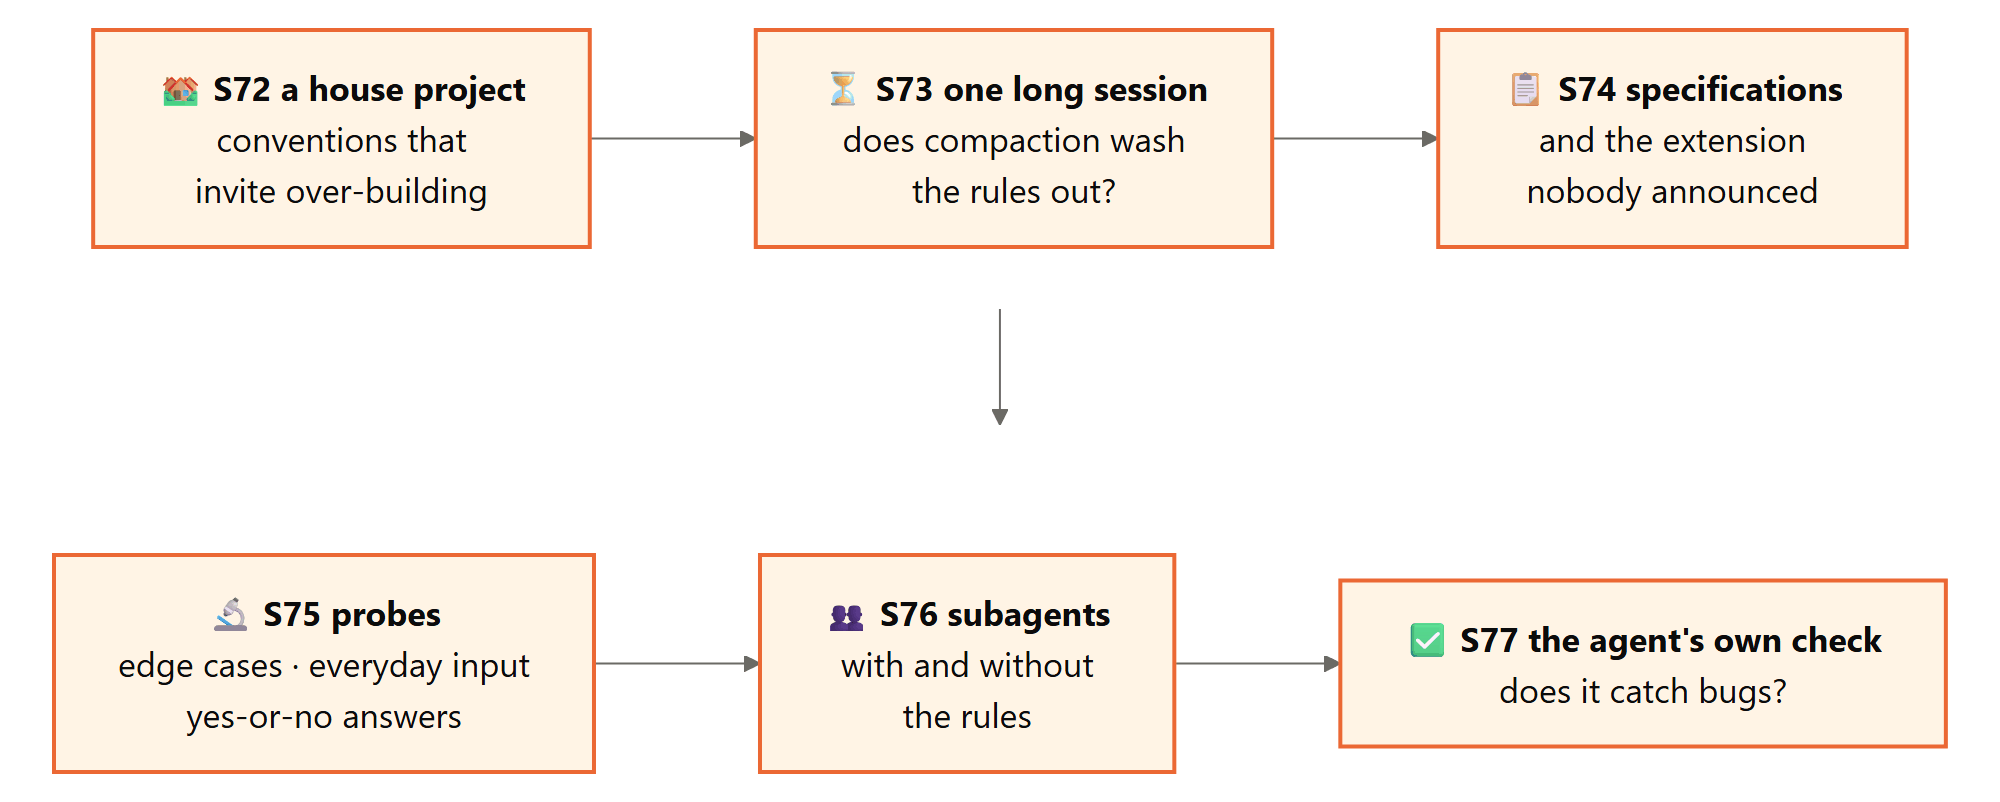

**`fixture_task(task_id, prompt, project, hidden, good=None, category="house")`** turns a fixture folder into an ordinary `Task`: it copies the project in as the seed, puts the hidden test beside it and, when there is one, the good reference under `refs/good`, exactly where S4 puts them. Nothing downstream needs to know the task came from elsewhere, which is the point. The staging folder is wiped first, so a fixture edited between runs is never mixed with an old copy. Every task it makes is also registered in `FIXTURE_TASKS`, which is how the scripted stand-in recognises these tickets in a smoke run.

In [703]:
FIXTURE_TASKS = {}                                           # every task made from a fixture, by id

def fixture_task(task_id, prompt, project, hidden, good=None, category="house"):
    """A Task built from a fixture folder, staged the way S4 lays a task out, so the runner,
    the fence and the scorer work on it unchanged."""
    stage = RUNTIME / "fixture_tasks" / task_id
    shutil.rmtree(stage, ignore_errors=True)                 # a fresh copy every time: no stale files from an edited fixture
    shutil.copytree(project, stage / "seed")                 # the project as the agent receives it
    shutil.copy(hidden, stage / "hidden_test.py")            # the test the agent never sees
    if good:
        shutil.copytree(good, stage / "refs" / "good")       # the good answer, laid over the seed when it is scored
    seed = snapshot(stage / "seed")                          # {path: text}, as every task carries its seed
    # every fixture is held-out and judged on correctness; the first file by name stands in as the entry
    task = Task(id=task_id, title=task_id, category=category, split="held-out", axis="correct", rung=7,
                entry=min(seed), prompt=prompt, notes="", extension="", python_target="3.12",
                folder=stage, seed=seed, refs=("good",) if good else ())
    FIXTURE_TASKS[task_id] = task                            # so the scripted coder can find the ticket
    return task

show_def(fixture_task, layer="lab")

[def] fixture_task(task_id, prompt, project, hidden, good=None, category='house')  15 lines, complexity 3


**`_ticket(messages)`** is the scripted coder's lookup from S22, redefined here so it knows the fixture tickets as well as the suite. The scripted stand-in works out which ticket it is answering by finding a task's prompt inside the first user message; without this version, a smoke run would meet the house-style and specification tickets as unknown requests. It matters only in smoke runs: with a real model, the model reads the ticket itself.

In [704]:
def _ticket(messages):
    """The scripted coder's lookup from S22, now aware of the fixture tickets too (smoke runs only)."""
    first = next((m["content"] for m in messages if m["role"] == "user"), "")     # the first user message, or nothing
    # the suite's tasks first, then the fixtures: the first one whose ticket appears in that message
    return next((t for t in [*SUITE.values(), *FIXTURE_TASKS.values()] if t.prompt in first), None)

show_def(_ticket, layer="lab")

[def] _ticket(messages)  4 lines, complexity 3


In [705]:
# a request that carries a suite ticket as its first user message
toy_found = _ticket([{"role": "system", "content": "..."}, {"role": "user", "content": SUITE["ob-postcode-cache"].prompt}])
toy_none = _ticket([{"role": "user", "content": "What is the capital of France?"}])   # no ticket in it at all
print(f"[_ticket] a suite ticket is recognised as {toy_found.id}; an unrelated request gives {toy_none}")

[_ticket] a suite ticket is recognised as ob-postcode-cache; an unrelated request gives None


## S72 - A project whose conventions invite over-building

**Theory.** Small tasks underestimate the most realistic source of over-building: a code base whose own conventions say "every feature gets a schema, a repository, a service and a handler". An agent that respects conventions, as it should, can turn a two-line change into four new files to match the house style, and every one of those files will look reasonable in review. The house-style project is built around that pressure. It is a small shop back end in five layers (models, schemas, repositories, services, handlers) wired together by a container, and its README tells contributors to follow the layering. Each of its six tickets needs a line or two in the right place and no new file: count a customer's orders, export orders as CSV, find a customer by email in any case, refuse a zero quantity, list the five most recent orders, and add VAT to a total. Every arm from S64 works every ticket twice, and the scorer counts new files and added code beside the hidden test. H13 asks whether the full system adds fewer files and less code while the tests still pass.

**In plain terms.** A project that says "always add all the layers", and six tickets that need a line or two each. Who adds the layers?

**For teams.** Conventions are where this pressure comes from, so they are also the cheapest place to relieve it. One sentence in the project's instructions file saying that a small change may stay inside one layer costs nothing, and counting new files per change in review makes layer-copying visible, whoever or whatever wrote the change.

In [706]:
HOUSE = ROOT / "fixtures" / "house"                          # the project, its hidden tests and its good answers
house_tickets = json.loads((HOUSE / "tickets.json").read_text(encoding="utf-8"))   # each ticket: an id and a prompt
HOUSE_TASKS = []                                             # one fixture task per ticket
for t in house_tickets:
    # the same project for every ticket, with that ticket's own hidden test and good answer
    HOUSE_TASKS.append(fixture_task(t["id"], t["prompt"], HOUSE / "project", HOUSE / "hidden" / f"{t['id']}.py",
                                    HOUSE / "good" / t["id"]))
print(f"[house] tickets staged: {', '.join(t.id for t in HOUSE_TASKS)}")

[house] tickets staged: h1-count, h2-csv, h3-email, h4-quantity, h5-recent, h6-vat


In [707]:
house_seed = HOUSE_TASKS[0].seed                             # every ticket starts from the same files
# folders under shopfront/ that hold files: the layers the README asks every feature to copy
layers = Counter(p.split("/")[1] for p in house_seed if p.startswith("shopfront/") and p.count("/") >= 2)
# the size of the project the six tickets land in
print(f"[house] {len(HOUSE_TASKS)} tickets on a project of {sum(p.endswith('.py') for p in house_seed)} Python files, "
      f"{sum(measure_source(s, p)['code'] for p, s in house_seed.items() if p.endswith('.py'))} lines of code")
print("  layers: " + ", ".join(f"{k}/ ({v} files)" for k, v in sorted(layers.items())))           # files per layer
# the sentence that creates the pressure, quoted from the project's own README
print("  the README: " + re.search(r"When you add a feature[^.]*\.", house_seed["README.md"]).group(0))

[house] 6 tickets on a project of 19 Python files, 133 lines of code
  layers: api/ (2 files), models/ (3 files), repositories/ (4 files), schemas/ (3 files), services/ (3 files)
  the README: When you add a feature, follow the same layering.


Before any model sees the project, each ticket is checked against its references: the untouched seed should fail its hidden test, and the good answer should pass it with a line or two of code and no new file.

In [708]:
HOUSE_GOOD = {}                                              # each ticket's good answer, scored: the floor for FIG 16
for t in HOUSE_TASKS:
    g = score(t, materialise(t, WS_DIR / f"house-{t.id}-good", "good"))                 # the good answer over the seed
    seed_score = score(t, materialise(t, WS_DIR / f"house-{t.id}-seed"), visible=False)  # the seed alone
    HOUSE_GOOD[t.id] = g
    # seed verdicts, good verdicts, and what the good answer cost in lines and files
    print(f"  {t.id:<12} seed {seed_score.short():<3} good {g.short():<3} {g.added_code:>2} code lines, "
          f"{g.files_new} new files   {textwrap.shorten(t.prompt, 62)}")

  h1-count     seed c0  good c1   2 code lines, 0 new files   Support wants to see how many orders a customer has [...]


  h2-csv       seed c0  good c1   7 code lines, 0 new files   Finance needs a CSV export of all orders: add [...]


  h3-email     seed c0  good c1   1 code lines, 0 new files   Customers sign in with their email address typed in any [...]


  h4-quantity  seed c0  good c1   2 code lines, 0 new files   An order line with a quantity of zero or less must be [...]


  h5-recent    seed c0  good c1   2 code lines, 0 new files   The account page needs the customer's five most recent [...]
  h6-vat       seed c0  good c1   3 code lines, 0 new files   Orders must show their total including 20% VAT: add [...]


In [709]:
HOUSE_RUNS = run_grid(list(ARM_NAMES), HOUSE_TASKS, label="house style")     # every arm of S64, every ticket, twice

  [house style] 10/60 episodes, 1s, 0 failed


  [house style] 20/60 episodes, 3s, 0 failed


  [house style] 30/60 episodes, 5s, 0 failed
  [house style] 40/60 episodes, 5s, 0 failed


  [house style] 50/60 episodes, 6s, 0 failed


  [house style] 60/60 episodes, 7s, 0 failed


In [710]:
GOOD_ADDED = float(np.mean([g.added_code for g in HOUSE_GOOD.values()]))      # the floor: what the tickets needed
HOUSE_ROWS = []                                              # one row per arm, averaged over tickets and runs
for arm in ARM_NAMES:
    rs = [r for r in HOUSE_RUNS if r.arm == arm and r.score]   # this arm's scored runs
    if arm == "off":
        med, ci = (1.0, None)                                # the baseline has no ratio to itself
    else:
        med, ci = ratio_summary(HOUSE_RUNS, arm, HOUSE_TASKS)[:2]   # paired by ticket against the unguided agent
    # averages over both runs of all six tickets
    HOUSE_ROWS.append({"arm": arm, "runs": len(rs), "pass": np.mean([r.score.passed for r in rs]),
                       "added": np.mean([r.score.added_code for r in rs]), "new_files": np.mean([r.score.files_new for r in rs]),
                       "touched": np.mean([r.score.files_touched for r in rs]), "ratio": med,
                       "ci": "-" if ci is None else f"{ci[0]:.2f} to {ci[1]:.2f}"})   # no interval for the baseline
table(HOUSE_ROWS, [("arm", "arm", ""), ("runs", "runs", "d"), ("pass", "pass", ".0%"), ("added", "code added per ticket", ".1f"),
                   ("new_files", "new files per ticket", ".2f"), ("touched", "files touched", ".1f"),
                   ("ratio", "code vs off", ".2f"), ("ci", "95% interval", "")])
print(f"  the good answers: {GOOD_ADDED:.1f} code lines per ticket, no new files")    # the floor to read the table against

  arm     runs  pass  code added per ticket  new files per ticket  files touched  code vs off  95% interval
  ---------------------------------------------------------------------------------------------------------
  off       12   50%                    2.7                  0.00            0.9         1.00  -
  terse     12   92%                    4.3                  0.00            1.3         1.62  0.95 to 2.25
  slogan    12   58%                    2.5                  0.00            1.0         1.08  0.50 to 1.62
  rules     12   75%                    2.7                  0.00            1.8         1.25  0.52 to 1.88
  full      12  100%                    5.2                  0.17            2.4         1.62  1.20 to 2.88
  the good answers: 2.8 code lines per ticket, no new files


Which new files the agents actually created, across both runs of every ticket, for the unguided agent and the full system:

In [711]:
for arm in ("off", "full"):
    new = Counter()                                          # path: how many runs created it
    for r in HOUSE_RUNS:
        if r.arm == arm and r.episode:                       # a run with a workspace to look at
            for p in snapshot(r.episode.ws):
                if p.endswith(".py") and p not in house_seed:
                    new[p] += 1                              # a Python file the seed did not have
    # the five most common, which shows whether the new files copy the layers
    print(f"  new files under {arm}: " + (", ".join(f"{p} (x{n})" for p, n in new.most_common(5)) or "none"))

  new files under off: none


  new files under full: _fix.py (x1), test_recent_orders.py (x1)


In [712]:
H_OFF = next(r for r in HOUSE_ROWS if r["arm"] == "off")     # the unguided agent's row
H_FULL = next(r for r in HOUSE_ROWS if r["arm"] == "full")   # the full system's row
# FEWER: less code, no more new files, and no more than five points lost on the hidden tests
fewer = (H_FULL["added"] < H_OFF["added"] and H_FULL["new_files"] <= H_OFF["new_files"]
         and H_FULL["pass"] >= H_OFF["pass"] - 0.05)
H13 = "NOT FEWER"                                            # unless one of the two verdicts below applies
if fewer:
    H13 = "FEWER"
elif H_FULL["pass"] >= H_OFF["pass"] + 0.10:
    H13 = "MORE, BUT PASSING"                                # more code, but at least ten points ahead on the tests
print(f"\n  H13: {H13}  (full {H_FULL['added']:.1f} lines and {H_FULL['new_files']:.2f} new files per ticket, "
      f"off {H_OFF['added']:.1f} and {H_OFF['new_files']:.2f}; pass {H_FULL['pass']:.0%} against {H_OFF['pass']:.0%})")
# the floor, the verdict, and every arm's numbers; FIG 16's reading quotes them
save_exp("house", {"good_added": GOOD_ADDED, "h13": H13,
                   **{r["arm"]: {k: r[k] for k in ("pass", "added", "new_files", "touched", "ratio")} for r in HOUSE_ROWS}})


  H13: MORE, BUT PASSING  (full 5.2 lines and 0.17 new files per ticket, off 2.7 and 0.00; pass 100% against 50%)
[exp] artifacts/exp_house.json


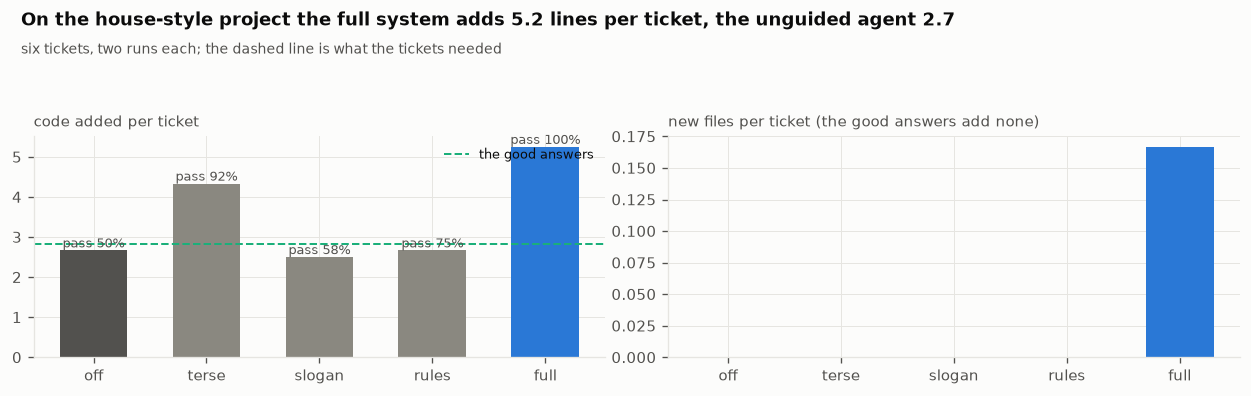

[fig 16] s72_house.png


In [713]:
# FIG  the house-style project
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
x = np.arange(len(ARM_NAMES))                                # one bar per arm, in table order
colours = []
for a in ARM_NAMES:
    if a == "full":
        colours.append(C1)                                   # the full system in blue
    elif a == "off":
        colours.append(INK2)                                 # the unguided agent in dark grey
    else:
        colours.append(MUTED)                                # the three controls in light grey
axes[0].bar(x, [r["added"] for r in HOUSE_ROWS], 0.6, color=colours)
axes[0].axhline(GOOD_ADDED, color=C3, ls="--", lw=1.2, label="the good answers")     # the floor
for i, r in enumerate(HOUSE_ROWS):
    axes[0].text(i, r["added"], f"pass {r['pass']:.0%}", ha="center", va="bottom", fontsize=7.5, color=INK2)   # each bar's pass rate
axes[0].set_xticks(x, ARM_NAMES)
axes[0].legend(fontsize=7.5, loc="upper right")              # only the dashed line has a label
panel(axes[0], "code added per ticket")
axes[1].bar(x, [r["new_files"] for r in HOUSE_ROWS], 0.6, color=colours)      # the floor here is zero
axes[1].set_xticks(x, ARM_NAMES)
panel(axes[1], "new files per ticket (the good answers add none)")
finish(fig, "s72_house", f"On the house-style project the full system adds {H_FULL['added']:.1f} lines per ticket, "
       f"the unguided agent {H_OFF['added']:.1f}", "six tickets, two runs each; the dashed line is what the tickets needed")

**Reading FIG 16 (s72_house).** The left panel is code added per ticket, averaged over the six tickets and both runs; the green dashed line is what the good answers added (2.8 lines), the floor, and the label on each bar is that arm's pass rate on the hidden tests. The right panel counts new files per ticket, where the floor is zero: none of the six tickets needs a new file, however the README reads. The unguided agent added 2.7 lines and 0.00 new files per ticket and passed 50%; the full system added 5.2 lines and 0.17 new files and passed 100%. H13 was registered as reported rather than tested, and on these six tickets the verdict is that the full system did not build less: it added more lines per ticket than the unguided agent, and passed far more of the tickets, so part of the unguided agent's smaller number is work it did not finish. Six tickets on one project are a case study, not a sample of projects; what makes the result worth having is that this is the situation teams are actually in, a convention that is right in general and wrong for a two-line change.

## S73 - One long session: does compaction wash the rules out?

**Theory.** Part V showed mechanically that compaction drops injected rules and that the session hook puts them back. This experiment asks whether that matters for the code. The six house-style tickets are sent one after another in a single session, on one workspace, with a context budget low enough to force several compactions. Each session is run three ways: the full system, the full system with re-injection after compaction switched off, and no plugin at all, twice each. For every ticket the table records the code it added and the share of the agent's model calls on which the rules were actually in the system message (H10). At the end, every ticket's hidden test is run on the final workspace, so a later ticket that broke an earlier one is caught.

One detail of the design shapes what to expect. Without the compaction hook the rules are not gone for good: the prompt hook from S38 sees, at the next ticket, that the level it last injected is missing and puts the rules back. So switching the compaction hook off loses the rules from each compaction until the next ticket, not for the rest of the session. That is the realistic case for a layered design, and the diagram shows both paths.

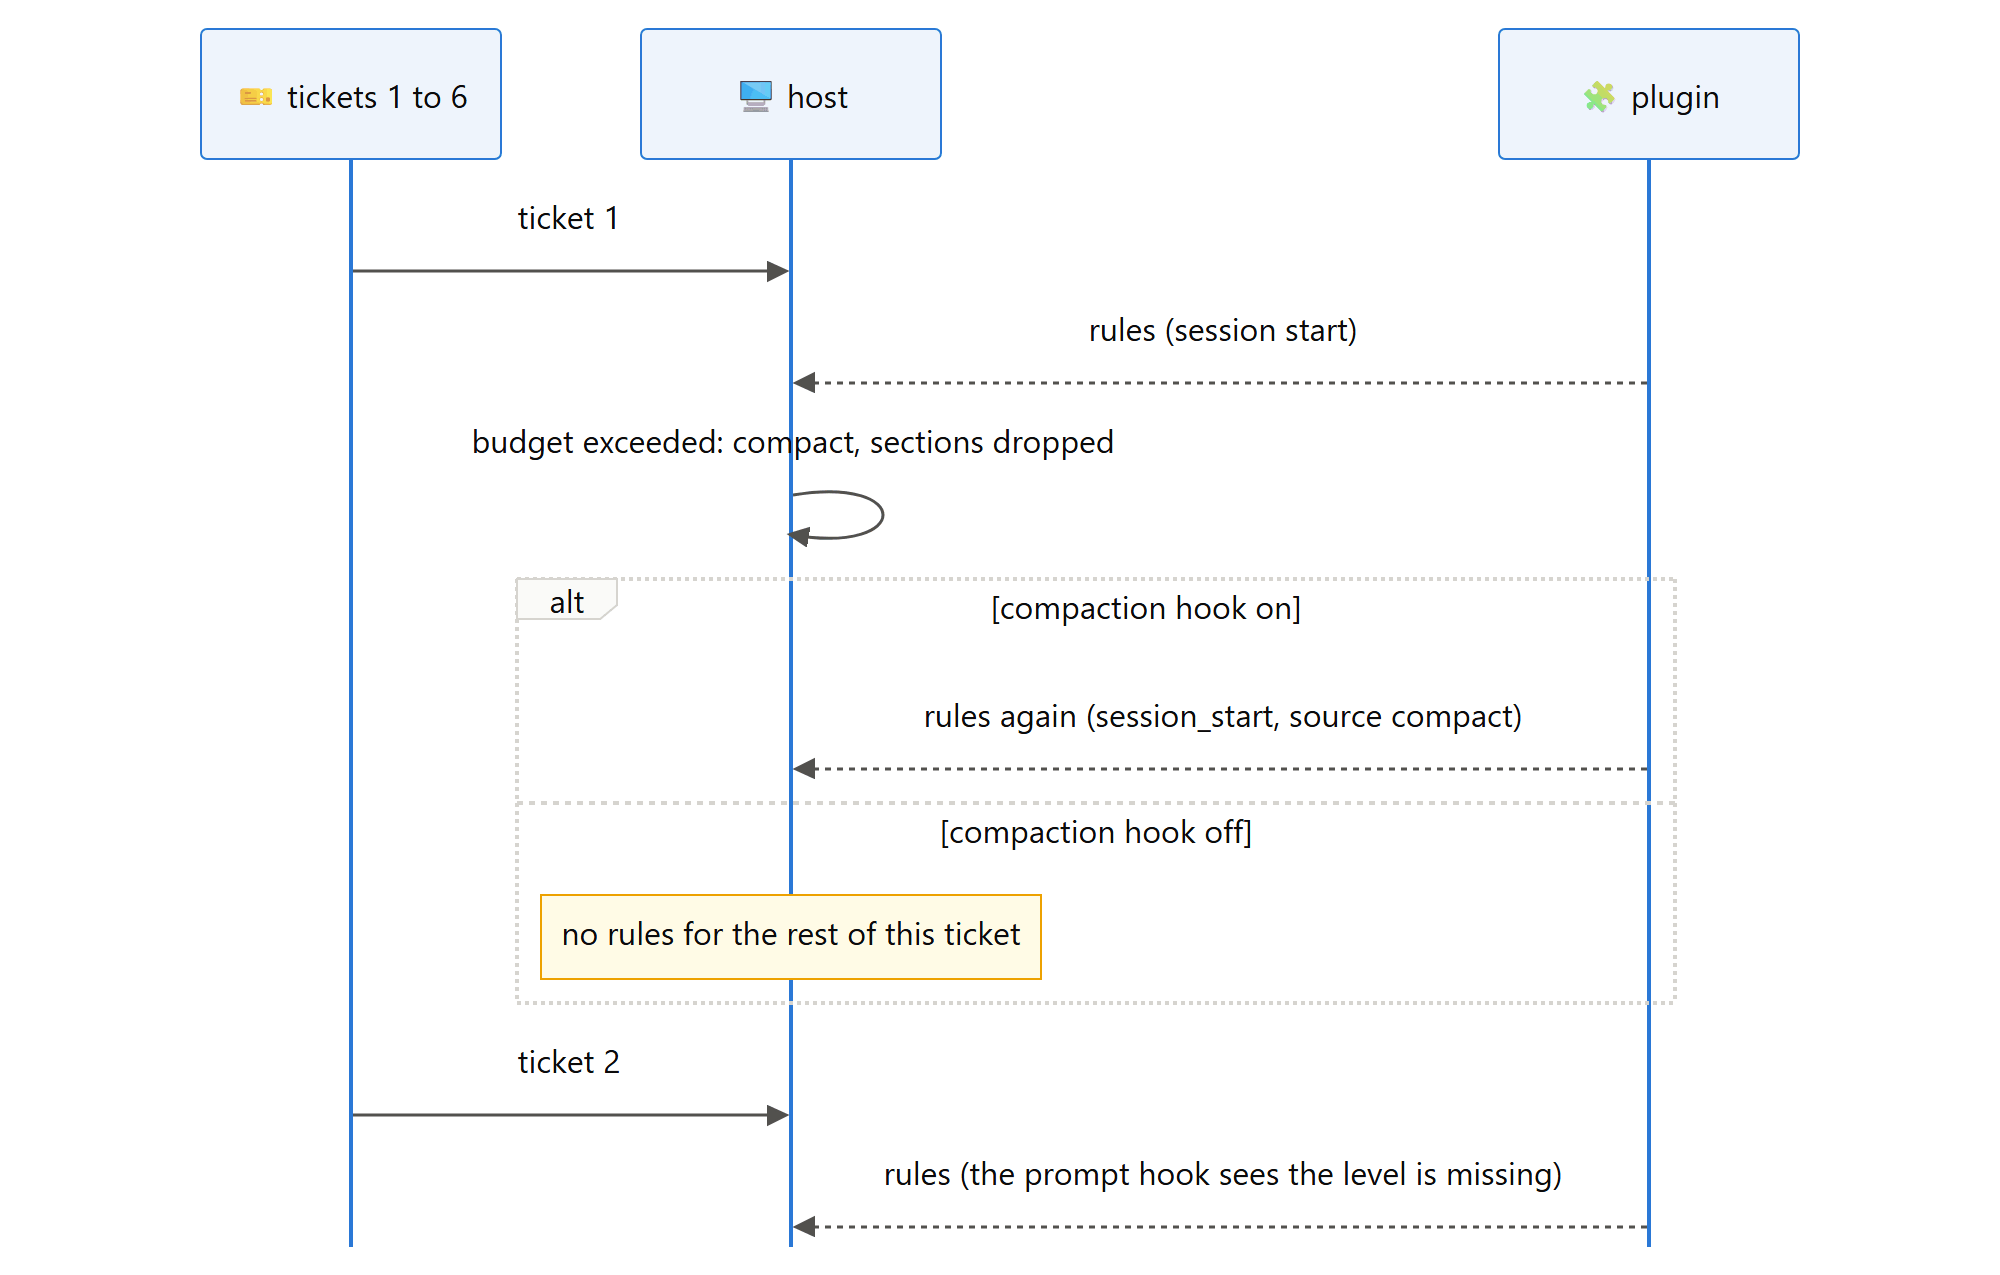

**In plain terms.** Six tickets in one long conversation, which has to summarise itself along the way. Do the rules survive the summaries, and does it show in the code?

**For teams.** Compaction is invisible to the person using the agent, which is what makes it dangerous to instructions. If your agent tool lets a plugin act when the context is compacted, that is where instructions belong; if it does not, a one-line header on every prompt (S38) is the fallback that still works.

**`run_session(tasks, recipe, label, replica=0)`** sends several tickets, one after another, through one host on one workspace, so the conversation carries over and compaction can land in the middle of a ticket. For each ticket it records the code added, the new files and the turns, and the share of the agent's model calls whose system message carried the rules. That share comes from a small hook on `pre_llm_call`, which looks at the context just before every call; calls made in a subagent's own context are not counted. Once all the tickets are done, each one's hidden test runs on the final workspace, so a later ticket that broke an earlier one shows up.

In [714]:
SESSION_BUDGET = 9_000          # tokens: low on purpose, so a six-ticket session compacts several times

def run_session(tasks, recipe, label, replica=0):
    """Several tickets, one after another, in one session on one workspace. Per ticket: code
    added, new files, turns, and the share of the agent's model calls whose system message
    carried the rules."""
    host = Host(plugins=recipe(), label=label)               # one host for the whole session
    ws = materialise(tasks[0], EPISODES_DIR / label / f"session-r{replica}")   # one workspace for every ticket
    host.replica = replica                                   # part of the key of every stored answer
    host.start_session(ws)                                   # once: the tickets share this session
    seen = []                                                # per model call: were the rules in the system message?

    def note_rules(host, ctx, **_):
        if ctx is host.ctx:                                  # the agent's own context, not a subagent's
            seen.append("lean" in ctx.sections)              # the plugin's rules live in the "lean" section

    host.bus.on("pre_llm_call", note_rules, name="probe.rules")   # watches every call the tickets make
    rows = []                                                # one row per ticket, in the order they were sent
    for position, t in enumerate(tasks, 1):
        before = snapshot(ws)                                # the workspace as this ticket finds it
        n0 = len(seen)                                       # calls counted before this ticket began
        host.handle_prompt(t.prompt)                         # the next ticket joins the same conversation
        res = host.loop(host.ctx, ws, host.model, tag=f"{label}:{t.id}")
        change = measure_change(before, snapshot(ws))        # what this ticket alone changed
        rules = float(np.mean(seen[n0:])) if len(seen) > n0 else 0.0   # share of this ticket's calls with the rules
        rows.append({"session": label, "replica": replica, "position": position, "ticket": t.id,
                     "added": change["added_code"], "new_files": change["files_new"], "turns": len(res.turns),
                     "rules": rules, "stop": res.stop})
    for row, t in zip(rows, tasks):
        row["passed"] = score(t, ws, visible=False).passed       # every ticket, judged on the final workspace
    return rows, host.ctx.compactions

show_def(run_session, layer="lab")

[def] run_session(tasks, recipe, label, replica=0)  27 lines, complexity 5


Three arms, two sessions each, all at once. The low budget is set only for as long as the pool runs and is put back afterwards, even if a session fails, so nothing later in the notebook runs with it.

In [715]:
SESSION_ARMS = {"full": lambda: full_system(),
                "no re-injection": lambda: full_system(reinject=True),   # the keyword names the piece switched off
                "off": lambda: []}
jobs = [(name, replica) for name in SESSION_ARMS for replica in range(REPLICAS)]   # (arm, replica) per session
saved, CONTEXT_BUDGET = CONTEXT_BUDGET, SESSION_BUDGET      # the low budget, for these sessions only
try:
    with ThreadPoolExecutor(WORKERS) as pool:
        # each session's label names its folder and every tag it sends: 'session-no-re-injection', and so on
        SESSIONS = dict(zip(jobs, pool.map(lambda j: run_session(HOUSE_TASKS, SESSION_ARMS[j[0]],
                                                                 "session-" + j[0].replace(" ", "-"), j[1]), jobs)))
finally:
    CONTEXT_BUDGET = saved                                  # the notebook's own budget again, whatever happened
print(f"[session] {len(SESSIONS)} sessions of {len(HOUSE_TASKS)} tickets; the budget is back to {CONTEXT_BUDGET:,} tokens")

[session] 6 sessions of 6 tickets; the budget is back to 24,000 tokens


In [716]:
SESSION_ROWS = []                                            # one row per arm and ticket position, replicas averaged
for name in SESSION_ARMS:
    for position, t in enumerate(HOUSE_TASKS, 1):
        rs = []                                              # this position's row from each of the arm's sessions
        for (session_arm, session_replica), (ticket_rows, session_compactions) in SESSIONS.items():
            if session_arm == name:
                rs.extend(r for r in ticket_rows if r["position"] == position)   # this ticket, in each of the arm's sessions
        SESSION_ROWS.append({"session": name, "position": position, "ticket": t.id,
                             "added": np.mean([r["added"] for r in rs]), "new_files": np.mean([r["new_files"] for r in rs]),
                             "rules": np.mean([r["rules"] for r in rs]), "turns": np.mean([r["turns"] for r in rs]),
                             "passed": f"{sum(r['passed'] for r in rs)}/{len(rs)}"})     # passing at the end, of the sessions
# read down a session: the rules column is the mechanism, the code column the consequence
table(SESSION_ROWS, [("session", "session", ""), ("position", "ticket", "d"), ("ticket", "id", ""),
                     ("added", "code added", ".1f"), ("new_files", "new files", ".1f"),
                     ("rules", "calls with the rules", ".0%"), ("turns", "turns", ".1f"), ("passed", "passed at the end", "")])

  session          ticket  id           code added  new files  calls with the rules  turns  passed at the end
  -----------------------------------------------------------------------------------------------------------
  full                  1  h1-count            4.0        0.0                  100%   17.5  2/2
  full                  2  h2-csv              7.0        0.0                  100%   15.5  2/2
  full                  3  h3-email            1.0        0.0                  100%   10.5  2/2
  full                  4  h4-quantity         2.0        0.0                  100%    8.0  2/2
  full                  5  h5-recent           3.5        0.0                  100%   12.5  2/2
  full                  6  h6-vat              2.5        0.0                  100%    9.5  2/2
  no re-injection       1  h1-count            4.0        0.0                  100%   17.5  2/2
  no re-injection       2  h2-csv              7.0        0.0                  100%   15.5  2/2
  no re-inje

In [717]:
SESSION_SUMMARY = {}                                         # one summary per arm, over all its sessions and tickets
for name in SESSION_ARMS:
    runs_ = [v for (n, _), v in SESSIONS.items() if n == name]    # (ticket rows, compactions) for each session of the arm
    rows_ = []
    for ticket_rows, session_compactions in runs_:
        rows_.extend(ticket_rows)                                  # every ticket of every session of the arm
    SESSION_SUMMARY[name] = {"rules": float(np.mean([r["rules"] for r in rows_])),       # share of calls with the rules
                             "added": float(np.mean([r["added"] for r in rows_])),       # code per ticket
                             "late_added": float(np.mean([r["added"] for r in rows_ if r["position"] > 3])),  # tickets 4 to 6
                             "passed": sum(r["passed"] for r in rows_), "tickets": len(rows_),
                             "compactions": float(np.mean([c for _, c in runs_]))}       # per session
    s = SESSION_SUMMARY[name]                                     # a short name for the print below
    errors = sum(r["stop"].startswith("error") for r in rows_)    # tickets the API cut short
    print(f"  [{name}] {s['compactions']:.1f} compactions per session, rules on {s['rules']:.0%} of calls, "
          f"{s['added']:.1f} lines per ticket ({s['late_added']:.1f} on tickets 4 to 6), {s['passed']}/{s['tickets']} passed"
          + (f", {errors} tickets cut short by API errors" if errors else ""))

  [full] 1.5 compactions per session, rules on 100% of calls, 3.3 lines per ticket (2.7 on tickets 4 to 6), 12/12 passed
  [no re-injection] 1.5 compactions per session, rules on 79% of calls, 3.8 lines per ticket (3.5 on tickets 4 to 6), 12/12 passed
  [off] 0.5 compactions per session, rules on 0% of calls, 3.7 lines per ticket (3.3 on tickets 4 to 6), 12/12 passed


In [718]:
s_full, s_cut = SESSION_SUMMARY["full"], SESSION_SUMMARY["no re-injection"]     # the two arms H10 compares
# 'no re-injection' is stored as 'no_re-injection', the key FIG 17's reading looks up
save_exp("session", {**{k.replace(" ", "_"): v for k, v in SESSION_SUMMARY.items()}, "budget": SESSION_BUDGET,
                     "rules_gap": s_full["rules"] - s_cut["rules"], "code_gap": s_cut["added"] - s_full["added"],   # positive: more code without the hook
                     # H10 decays only if both moved: fewer calls carried the rules, and more code was written
                     "decays": "YES" if s_cut["rules"] < s_full["rules"] and s_cut["added"] > s_full["added"] else "NO"})

[exp] artifacts/exp_session.json


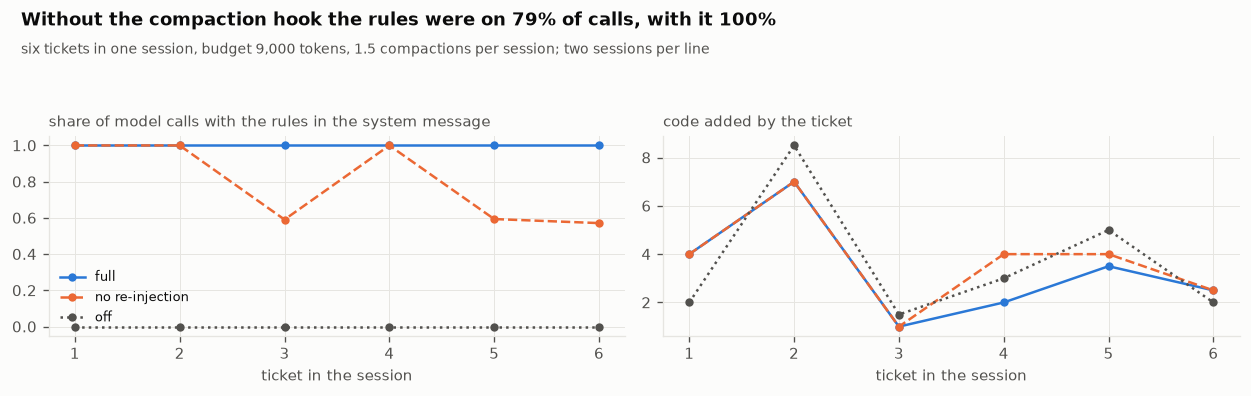

[fig 17] s73_session.png


In [719]:
# FIG  rules and code across one long session
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
pos = np.arange(1, len(HOUSE_TASKS) + 1)                     # ticket positions 1 to 6
for name, (colour, ls) in {"full": (C1, "-"), "no re-injection": (C2, "--"), "off": (INK2, ":")}.items():
    rs = [r for r in SESSION_ROWS if r["session"] == name]   # this arm's rows, in ticket order
    axes[0].plot(pos, [r["rules"] for r in rs], color=colour, ls=ls, marker="o", ms=4, label=name)   # the mechanism
    axes[1].plot(pos, [r["added"] for r in rs], color=colour, ls=ls, marker="o", ms=4, label=name)   # the consequence
axes[0].set_ylim(-0.05, 1.05)                                # a share, with a little room at both ends
for ax in axes:
    ax.set_xlabel("ticket in the session")
    ax.set_xticks(pos)                                       # whole ticket numbers only
axes[0].legend(fontsize=7.5, loc="lower left")               # one legend serves both panels
panel(axes[0], "share of model calls with the rules in the system message")
panel(axes[1], "code added by the ticket")
finish(fig, "s73_session", f"Without the compaction hook the rules were on {s_cut['rules']:.0%} of calls, "
       f"with it {s_full['rules']:.0%}", f"six tickets in one session, budget {SESSION_BUDGET:,} tokens, "
       f"{s_full['compactions']:.1f} compactions per session; two sessions per line")

**Reading FIG 17 (s73_session).** The left panel is the mechanism and the right panel is the consequence. On the left, the full system's line should sit at or near the top throughout, because every compaction is followed by re-injection; the no-re-injection line dips wherever a compaction landed in the middle of a ticket, and recovers at the next ticket when the prompt hook notices the rules are missing. Over the whole session the rules were present on 100% of the full system's calls and 79% without the compaction hook. On the right, code added per ticket: the difference between the two lines is +0.4 lines per ticket (positive means more code without the hook). H10 expected the rules to decay without re-injection, and the measured answer is yes: fewer calls carried the rules and more code was written. The unguided line on the right is the reference for what a long session produces with no rules at all.

## S74 - Specifications, and the extension nobody announced

**Theory.** Proportional code is supposed to be cheaper to *change*, not only smaller on the day it is written; that is the claim that justifies the approach to a team. Three specifications are each built from a written spec with several requirements: an event dispatcher, a thread-safe ledger and a sign-in module with lockout. Each has acceptance tests the agent never sees, adversarial ones included (eight threads moving money at once, five failed sign-ins in a row, a handler that unsubscribes itself while an event is being delivered). The unguided agent and the full system build each spec twice. Then every build receives a follow-up ticket it was not told about, in a new session on the workspace it left behind: once-only subscriptions, a daily transfer limit, logout. The table records whether each build passed, how much code the extension had to add or rewrite, whether the extension's own test passed, and whether the original acceptance tests still pass afterwards (H12).

**In plain terms.** Build something from a spec, then add a surprise requirement. Is the leaner version easier to extend, and does anything break on the way?

**For teams.** This is the test to copy into your own evaluation of any coding agent. A team pays for the second change to a piece of code far more often than for the first, so measure the cost of the follow-up ticket, and run the original acceptance tests after it.

**Build, then extend.** The extension arrives in a new session on the workspace the build left behind, with no hint of it in the original spec. What it costs to add, and whether the original acceptance tests survive it, is the practical meaning of maintainable.

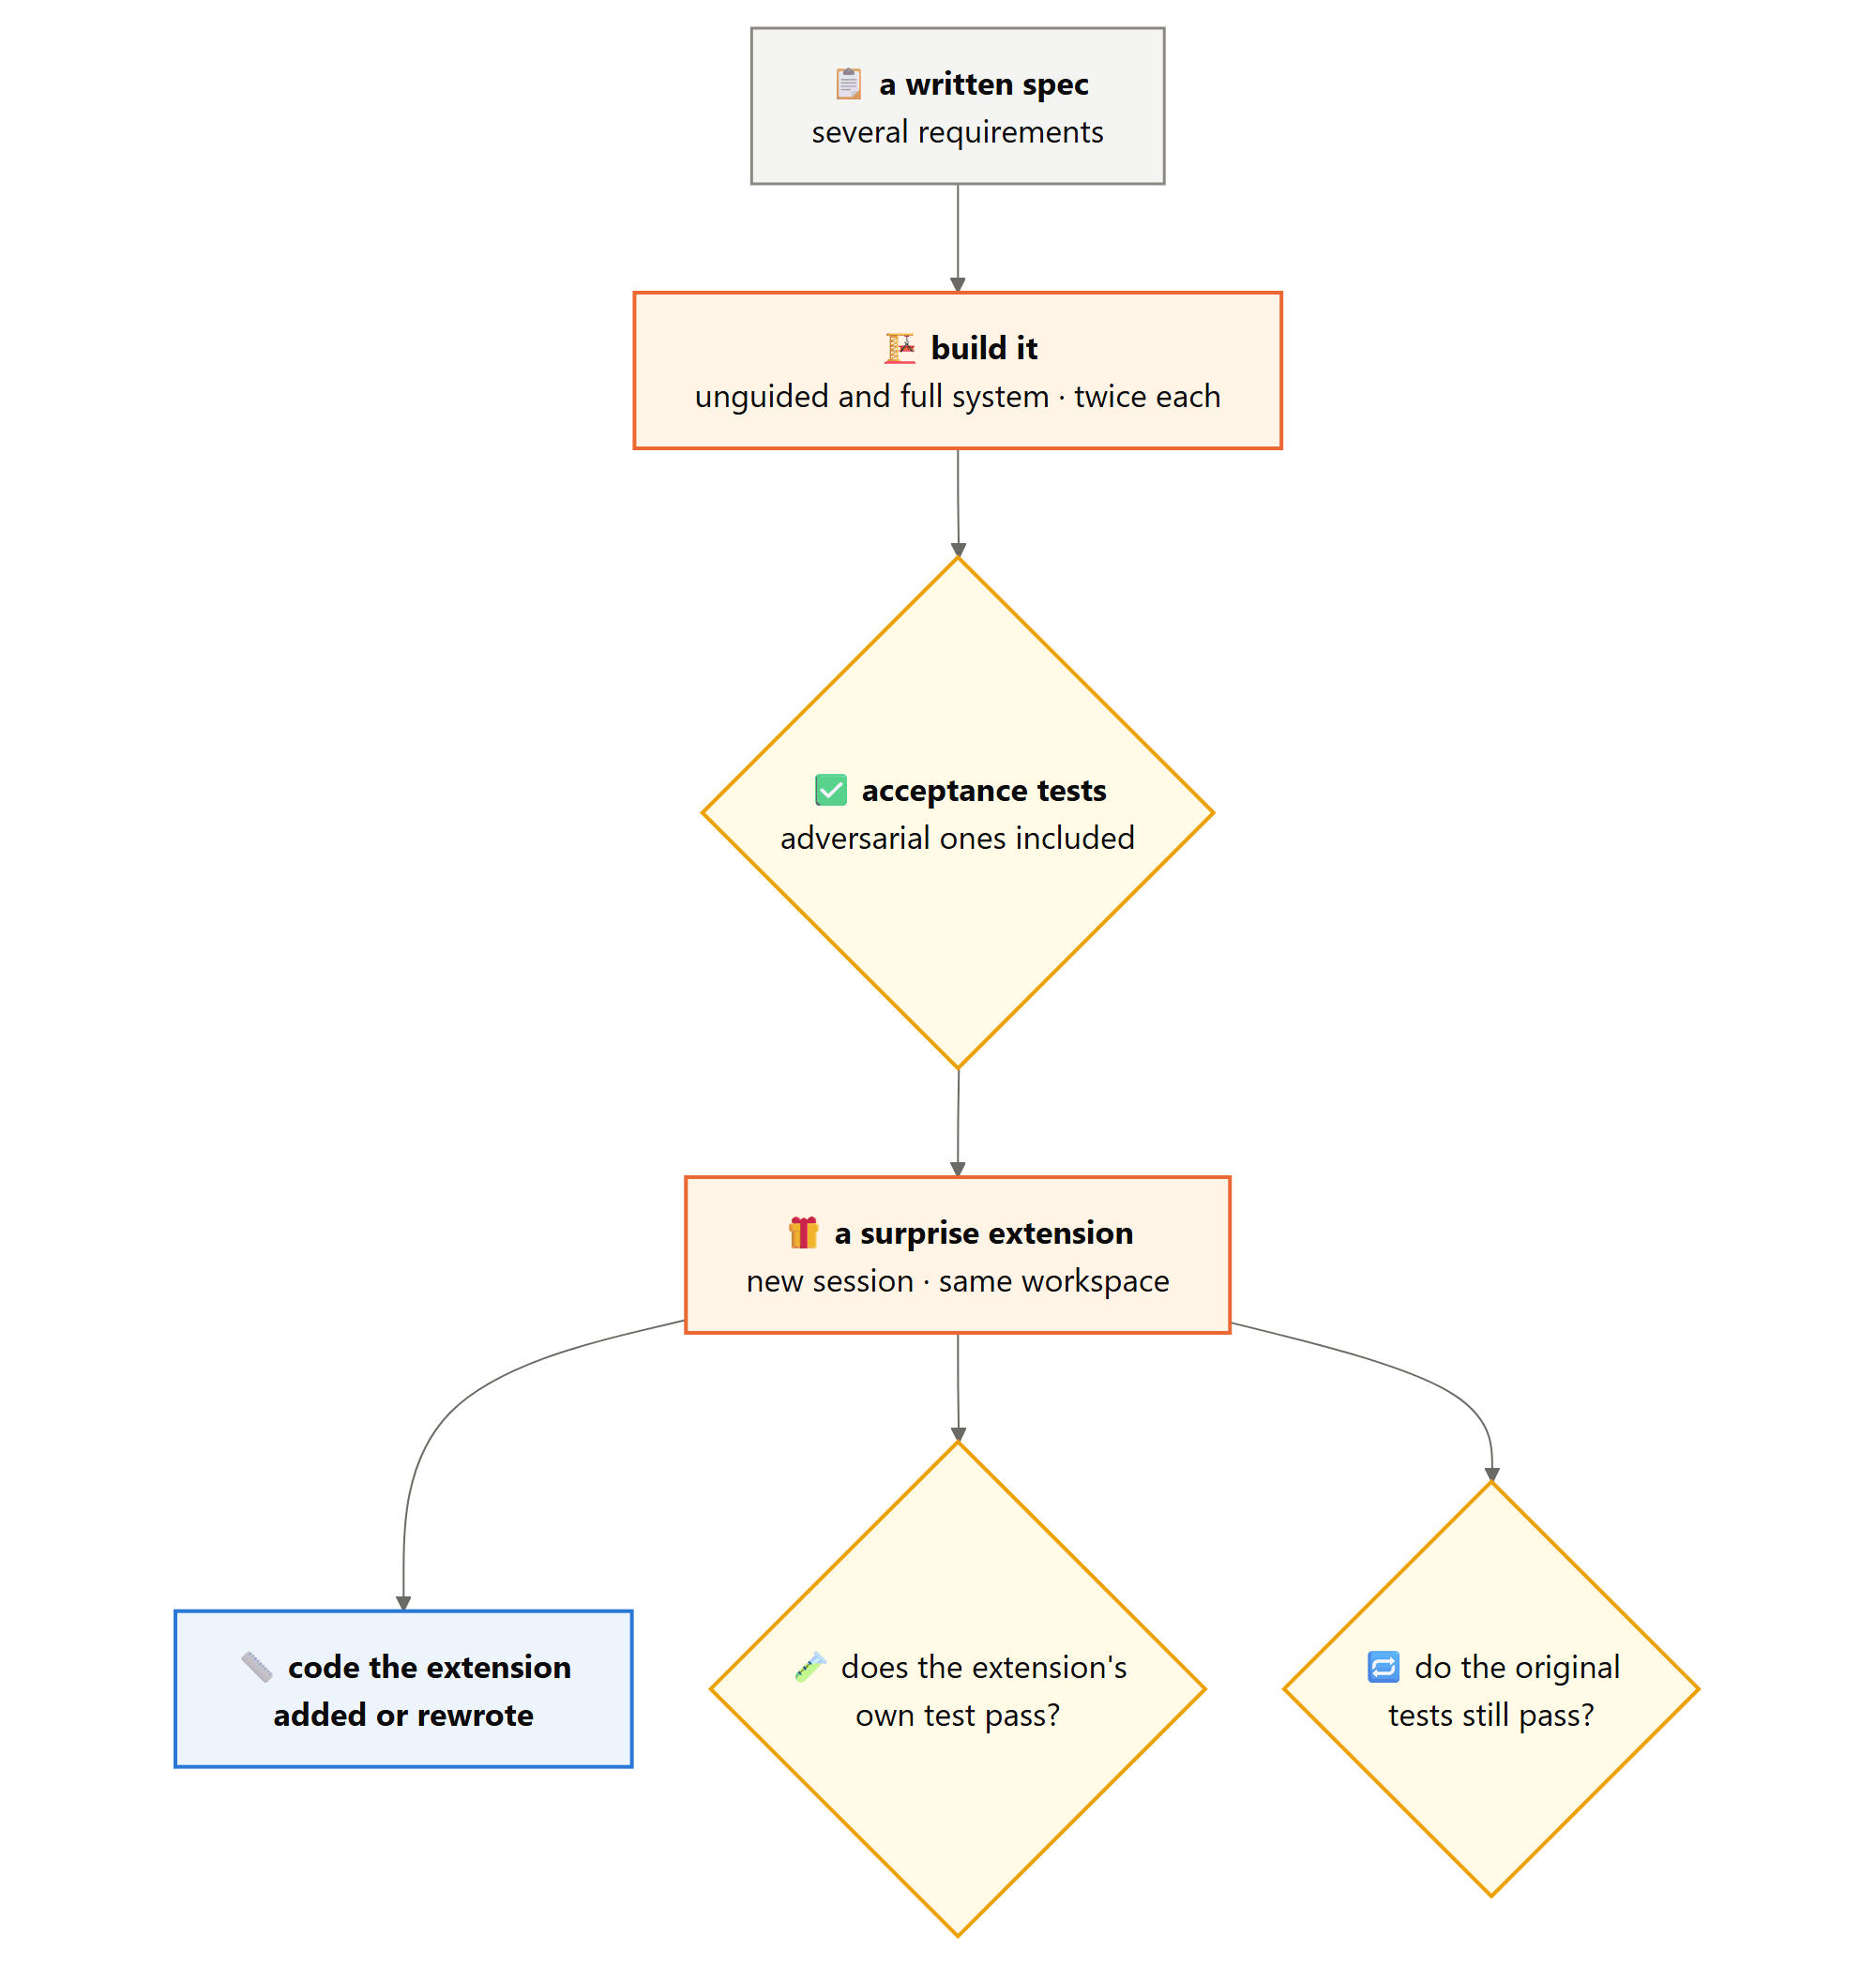

Each specification becomes two fixture tasks on the same starting project: the build, judged by the acceptance tests, and the surprise extension, judged by its own test. Both good references are scored first; if either failed, the comparison would have no floor.

In [720]:
SPECS = ROOT / "fixtures" / "specs"
SPEC_META = {name: json.loads((SPECS / name / "spec.json").read_text(encoding="utf-8"))   # the prompt and the surprise
             for name in ("events", "ledger", "auth")}
SPEC_BUILD, SPEC_EXT, SPEC_REFS = {}, {}, []                 # build tasks, extension tasks, and one reference row per spec
for name, meta in SPEC_META.items():
    folder = SPECS / name
    # the build: the written spec, judged by acceptance tests the agent never sees
    SPEC_BUILD[name] = fixture_task(f"spec-{name}", meta["prompt"], folder / "project", folder / "hidden_spec.py",
                                    folder / "good", "spec")
    # the surprise: the follow-up ticket, with its own hidden test and its own good answer
    SPEC_EXT[name] = fixture_task(f"spec-{name}-ext", meta["extension"], folder / "project", folder / "hidden_extension.py",
                                  folder / "good_extension", "spec")
    good = materialise(SPEC_BUILD[name], WS_DIR / f"spec-{name}-good", "good")            # the good build
    good_ext = materialise(SPEC_EXT[name], WS_DIR / f"spec-{name}-good-ext", "good")      # the good build, extended
    stub = score(SPEC_BUILD[name], materialise(SPEC_BUILD[name], WS_DIR / f"spec-{name}-seed"), visible=False)  # the seed alone
    spec_lines = SPEC_BUILD[name].seed["SPEC.md"].splitlines()                          # the written spec
    good_build = score(SPEC_BUILD[name], good).added_code                               # what a good build costs
    good_extension = measure_change(snapshot(good), snapshot(good_ext))["added_code"]     # what the surprise costs a good build
    refs_ok = score(SPEC_BUILD[name], good).passed and score(SPEC_EXT[name], good_ext).passed   # both references pass
    SPEC_REFS.append({"spec": name, "requirements": sum(ln.startswith("- ") for ln in spec_lines),   # one bullet each
                      "stub": stub.short(), "good build": good_build, "good extension": good_extension,
                      "references pass": "yes" if refs_ok else "NO"})
# the stub column should show failing verdicts: the seed alone must not pass the spec
table(SPEC_REFS, [("spec", "spec", ""), ("requirements", "requirements", "d"), ("stub", "stub", ""),
                  ("good build", "good build, code lines", "d"), ("good extension", "good extension, code lines", "d"),
                  ("references pass", "references pass", "")])

  spec    requirements  stub  good build, code lines  good extension, code lines  references pass
  -----------------------------------------------------------------------------------------------
  events             5  c0                        25                           8  yes
  ledger             5  c0                        24                          11  yes
  auth               5  c0                        29                           2  yes


In [721]:
# what each build is asked for, and the surprise that follows it
for name, meta in SPEC_META.items():
    print(f"\n  [{name}] {meta['prompt']}")                    # the build ticket in full
    print(f"    the surprise: {textwrap.shorten(meta['extension'], 150)}")   # the extension, shortened


  [events] Build the event dispatcher specified in SPEC.md, in events/dispatcher.py.
    the surprise: Add `once=True` to `subscribe`: a subscription made with it is removed after its handler has been called once.

  [ledger] Build the ledger specified in SPEC.md, in money/ledger.py.
    the surprise: Add a daily limit: `set_daily_limit(account, pence)`. `transfer` gets an optional `day` argument (an ISO date string, default today); transfers [...]

  [auth] Build the sign-in module specified in SPEC.md, in accounts/auth.py.
    the surprise: Add `logout(token)`: after it, the token no longer works; logging out an unknown token does nothing.


In [722]:
SPEC_RUNS = run_grid(["off", "full"], list(SPEC_BUILD.values()), label="spec builds")   # each spec built twice per arm

  [spec builds] 2/12 episodes, 2s, 0 failed


  [spec builds] 4/12 episodes, 3s, 0 failed
  [spec builds] 6/12 episodes, 3s, 0 failed
  [spec builds] 8/12 episodes, 3s, 0 failed
  [spec builds] 10/12 episodes, 3s, 0 failed


  [spec builds] 12/12 episodes, 13s, 0 failed


**`extend(run)`** gives one finished build the surprise ticket, in a new session on the workspace the build left behind, under the same arm and replica as the build. It measures what the extension added or rewrote, then runs two hidden tests on the result: the extension's own, and the original acceptance tests, because an extension that breaks what was already there is not cheap at any size. Starting a new session matters: the agent meets the code as a colleague would the next week, without the conversation that produced it.

In [723]:
def extend(run):
    """The surprise ticket, in a new session, on the workspace the build left behind."""
    name = run.task.removeprefix("spec-")                    # 'spec-events' is the events spec
    ws = Path(run.episode.ws)                                # the build's own workspace, carried forward
    before = snapshot(ws)                                    # the build as it was left
    host = Host(plugins=ARMS[run.arm](), label=run.arm)      # the same arm as the build, with fresh plugins
    host.replica = run.replica                               # and the same replica, which is part of every stored answer's key
    host.start_session(ws)                                   # a new session: none of the build's conversation
    host.handle_prompt(SPEC_META[name]["extension"])         # the surprise ticket
    res = host.loop(host.ctx, ws, host.model, tag=f"{run.arm}:{run.task}:extension")   # tagged apart from the build
    change = measure_change(before, snapshot(ws))            # what the extension alone added or rewrote
    extension_passed = score(SPEC_EXT[name], ws, visible=False).passed     # the surprise's own hidden test
    spec_still_passes = score(SPEC_BUILD[name], ws, visible=False).passed  # the original acceptance tests, afterwards
    return {"spec": name, "arm": run.arm, "replica": run.replica, "build passed": run.score.passed,
            "build code": run.score.added_code, "extension passed": extension_passed,
            "extension code": change["added_code"], "extension files": change["files_touched"],
            "spec still passes": spec_still_passes, "turns": len(res.turns),
            "stop": res.stop}

show_def(extend, layer="lab")

[def] extend(run)  18 lines, complexity 1


In [724]:
with ThreadPoolExecutor(WORKERS) as pool:
    SPEC_ROWS = list(pool.map(extend, [r for r in SPEC_RUNS if r.episode and r.score]))   # only builds that ran and were scored
SPEC_ROWS.sort(key=lambda r: (r["spec"], r["arm"], r["replica"]))   # a stable order for the table
yes = lambda v: "yes" if v else "no"                         # a verdict in words, for the table
spec_table_rows = []
for r in SPEC_ROWS:
    shown = dict(r)                                          # a copy for display; SPEC_ROWS keeps its booleans
    for k in ("build passed", "extension passed", "spec still passes"):
        shown[k] = yes(r[k])                                 # the three pass/fail columns
    spec_table_rows.append(shown)
table(spec_table_rows,
      [("spec", "spec", ""), ("arm", "arm", ""), ("replica", "run", "d"), ("build passed", "build passed", ""),
       ("build code", "build code", "d"), ("extension code", "extension code", "d"), ("extension files", "files", "d"),
       ("extension passed", "extension passed", ""), ("spec still passes", "spec still passes", "")])
# failures are counted, not hidden: a build that never ran has no extension to measure
print(f"  builds that failed to run: {sum(1 for r in SPEC_RUNS if not (r.episode and r.score))}; extensions cut short "
      f"by API errors: {sum(r['stop'].startswith('error') for r in SPEC_ROWS)}")

  spec    arm   run  build passed  build code  extension code  files  extension passed  spec still passes
  -------------------------------------------------------------------------------------------------------
  auth    full    0  yes                   58               5      1  no                yes
  auth    full    1  yes                   46               2      1  yes               yes
  auth    off     0  yes                   58               2      1  yes               yes
  auth    off     1  yes                   55               2      1  yes               yes
  events  full    0  yes                   29               6      1  yes               yes
  events  full    1  yes                   31               7      1  no                no
  events  off     0  yes                   34               9      1  yes               yes
  events  off     1  yes                   38              10      2  no                yes
  ledger  full    0  yes                   39        

In [725]:
SPEC_SUMMARY = {}                                            # one summary per arm, over every spec and run
for arm in ("off", "full"):
    rs = [r for r in SPEC_ROWS if r["arm"] == arm]           # this arm's extended builds
    SPEC_SUMMARY[arm] = {"build": float(np.mean([r["build code"] for r in rs])),             # lines per build
                         "extension": float(np.mean([r["extension code"] for r in rs])),     # lines per extension
                         # runs where the build, the extension and the original acceptance tests all pass at the end
                         "all_pass": sum(r["build passed"] and r["extension passed"] and r["spec still passes"] for r in rs),
                         "runs": len(rs)}
    s = SPEC_SUMMARY[arm]                                    # a short name for the print below
    print(f"  {arm:<5} builds {s['build']:.0f} lines, extends with {s['extension']:.0f}; "
          f"everything passing at the end in {s['all_pass']}/{s['runs']}")
# cheaper only if the extensions were smaller and no fewer runs ended with everything passing
H12 = "CHEAPER" if (SPEC_SUMMARY["full"]["extension"] < SPEC_SUMMARY["off"]["extension"]
                    and SPEC_SUMMARY["full"]["all_pass"] >= SPEC_SUMMARY["off"]["all_pass"]) else "NOT CHEAPER"
print(f"\n  H12: {H12}")
# both arms, the verdict, and the good references for scale; FIG 18's reading quotes them
save_exp("specs", {**SPEC_SUMMARY, "h12": H12,
                   "good": {r["spec"]: {"build": r["good build"], "extension": r["good extension"]} for r in SPEC_REFS}})

  off   builds 45 lines, extends with 35; everything passing at the end in 4/6
  full  builds 38 lines, extends with 11; everything passing at the end in 4/6

  H12: CHEAPER
[exp] artifacts/exp_specs.json


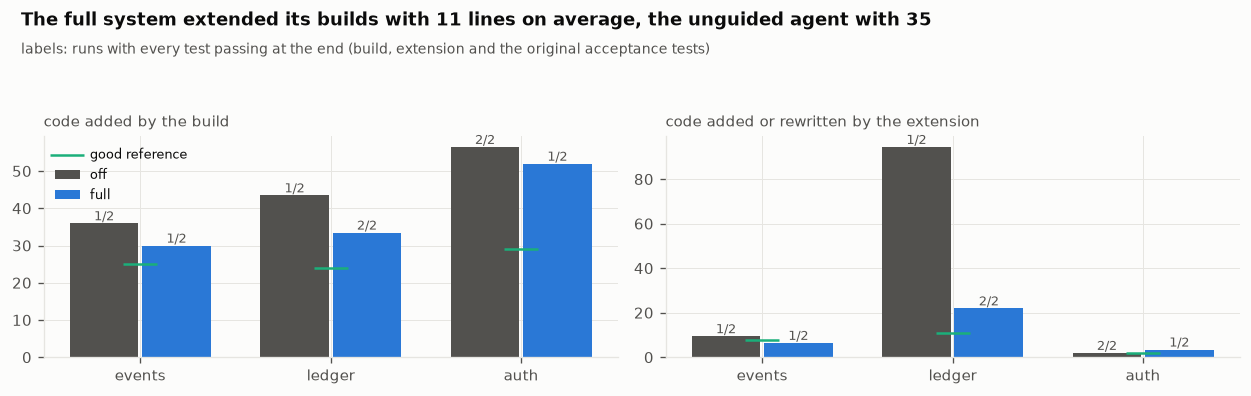

[fig 18] s74_specs.png


In [726]:
# FIG  build, then extend
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
names = list(SPEC_META)                                      # events, ledger, auth
x = np.arange(len(names))                                    # one group of bars per spec
# the same drawing twice: the build on the left, the extension on the right
for ax, key, good_key in ((axes[0], "build code", "good build"), (axes[1], "extension code", "good extension")):
    for k, (arm, colour) in enumerate((("off", INK2), ("full", C1))):
        rs = []
        for n in names:
            rs.append([r for r in SPEC_ROWS if r["spec"] == n and r["arm"] == arm])   # this arm's runs on one spec
        heights = [np.mean([r[key] for r in rr]) if rr else 0 for rr in rs]          # mean lines per spec
        ax.bar(x + (k - 0.5) * 0.38, heights, 0.36, color=colour, label=arm)         # off to the left, full to the right
        for i, rr in enumerate(rs):
            ok = sum(r["build passed"] and r["extension passed"] and r["spec still passes"] for r in rr)   # all three passed
            ax.text(i + (k - 0.5) * 0.38, heights[i], f"{ok}/{len(rr)}",            # runs with everything passing
                    ha="center", va="bottom", fontsize=7.5, color=INK2)
    goods = [next(r[good_key] for r in SPEC_REFS if r["spec"] == n) for n in names]  # the good reference per spec
    ax.scatter(x, goods, marker="_", s=400, color=C3, zorder=3, label="good reference")
    ax.set_xticks(x, names)
axes[0].legend(fontsize=7.5)                                 # one legend serves both panels
panel(axes[0], "code added by the build")
panel(axes[1], "code added or rewritten by the extension")
finish(fig, "s74_specs", f"The full system extended its builds with {SPEC_SUMMARY['full']['extension']:.0f} lines on average, "
       f"the unguided agent with {SPEC_SUMMARY['off']['extension']:.0f}",
       "labels: runs with every test passing at the end (build, extension and the original acceptance tests)")

**Reading FIG 18 (s74_specs).** Each pair of bars is one specification: grey for the unguided agent, blue for the full system, the green tick for the good reference, and the label on each bar counts the runs in which everything passed at the end, the original acceptance tests included. The left panel is the build, where size alone means little unless the build passed. The right panel is the claim being tested: how much code the surprise extension had to add or rewrite. The full system extended its builds with 11 lines on average against 35 for the unguided agent, with everything passing in 4 of 6 runs against 4 of 6, and the verdict on H12 is that the leaner builds were cheaper to extend. Three specifications and two runs each are a small sample, and an extension's size depends as much on where the build put things as on how much it built, so this result is reported, not tested.

## S75 - Probes: behaviours that tasks are too coarse to catch

**Theory.** Some failures are too small and too frequent to show up in a handful of tasks, so they are measured with **probes**: one request, one reply, no agent loop, and the code run against a few checks in the fence. Thirty-one probes in four families are each answered three times without the rules and three times with them:
- **Edge cases** (16): the sturdy algorithm against the flimsy one. Leap years in 1900 and 2100, an IPv4 address with a trailing newline, the last partial batch, a bill split three ways that must still add up, the median of an even list, a flatten that must not split strings into characters, and so on. This tests the rule *when a sturdier algorithm costs a line or two more, pay it*.
- **Everyday input** (10): text typed by people, with spaces, capitals, empty fields and stray symbols. Rules that push for less code are most likely to cost something here, by trimming handling that looks optional and is not.
- **Interface inflation** (4): a function that a caller uses as `if f(x):` must return something false when the answer is no. A tuple or a dict that "explains why" is always true and silently breaks the caller.
- **Calibration** (1): a timeout and a sensor offset should be named constants, which is what the calibration rule asks for.

API errors are left out of the counts and reported, because an answer that never arrived says nothing about either arm.

**In plain terms.** Thirty-one quick questions, each asked six times, to catch small habits: handling the odd case, coping with messy input, keeping a yes-or-no answer a yes or a no, and naming the numbers someone will tune.

**For teams.** Probes are the cheapest evaluation in this notebook to rebuild for your own domain: a request, a few checks, a good answer and a naive one. Make sure the naive answer fails before trusting a single result, because a probe that cannot fail is the most common way such a test suite flatters whatever it measures.

**`_probe(name, prompt, checks)`** packs one probe as a record with three fixed keys: a name for the tables, the request exactly as the model receives it, and the checks its answer must pass. The checks are the source of a small script that runs beside the answer in the fence and imports it as `module`. It is a function only so that the thirty-one entries below read as a list of probes rather than a wall of brackets.

In [727]:
def _probe(name, prompt, checks):
    return {"name": name, "prompt": prompt, "checks": checks}    # the checks import the answer as `module`

show_def(_probe, layer="lab")

[def] _probe(name, prompt, checks)  2 lines, complexity 1


The thirty-one probes, exactly as the models receive them, family by family.

In [728]:
# every probe as sent: the request text and its check script must not change, or the stored answers no longer match
PROBE_SET = {"edge": [
    _probe("leap year", "Write `is_leap(year)`: True if the year is a leap year in the Gregorian calendar.",
           "from module import is_leap\nassert [is_leap(y) for y in (1900, 2000, 2024, 2100, 2023)] == [False, True, True, False, False]"),
    _probe("ipv4", "Write `is_ipv4(text)`: True if text is exactly an IPv4 address in dotted form, such as 192.168.0.1, "
           "and nothing else. It checks what people type into a firewall form.",
           "from module import is_ipv4\nassert is_ipv4('10.0.0.1') and is_ipv4('255.255.255.255')\n"
           "assert not any(map(is_ipv4, ['256.1.1.1', '1.2.3', '1.2.3.4\\n', '01.2.3.4', ' 1.2.3.4', '1.2.3.4.5']))"),
    _probe("batches", "Write `batches(items, size)` yielding consecutive batches of `size` items from any iterable; "
           "the last batch may be shorter.",
           "from module import batches\nassert [list(b) for b in batches(range(7), 3)] == [[0, 1, 2], [3, 4, 5], [6]]\n"
           "assert [list(b) for b in batches((i for i in range(4)), 2)] == [[0, 1], [2, 3]]"),
    _probe("split bill", "Write `split_bill(total, people)`: split a bill given as a string such as '100.00' between "
           "`people` people; return the shares as strings with two decimals.",
           "from decimal import Decimal\nfrom module import split_bill\n"
           "for total, n in (('100.00', 3), ('10.00', 6), ('0.05', 2)):\n"
           "    shares = [Decimal(s) for s in split_bill(total, n)]\n"
           "    assert len(shares) == n and sum(shares) == Decimal(total) and max(shares) - min(shares) <= Decimal('0.01')"),
    _probe("median", "Write `median(numbers)` for a non-empty list of numbers.",
           "from module import median\nassert median([3, 1, 2]) == 2 and median([4, 1, 3, 2]) == 2.5"),
    _probe("pages", "Write `page_count(total, per_page)`: how many pages are needed to show `total` items, `per_page` to a page.",
           "from module import page_count\nassert [page_count(n, 10) for n in (0, 1, 10, 11, 20, 25)] == [0, 1, 1, 2, 2, 3]"),
    _probe("casefold", "Write `unique_ignoring_case(words)`: drop repeats ignoring case, keeping the first spelling and the "
           "order. Our users write in English and German.",
           "from module import unique_ignoring_case as u\nassert u(['Straße', 'STRASSE', 'Rust', 'rust']) == ['Straße', 'Rust']"),
    _probe("safe join", "Write `upload_path(folder, filename)`: the path where an uploaded file with this name is saved "
           "inside `folder`. The filename comes from the user.",
           "import os\nfrom module import upload_path\nbase = os.path.abspath('uploads')\n"
           "def inside(name):\n    try:\n        p = upload_path(base, name)\n    except Exception:\n"
           "        return True              # refusing the name is safe\n"
           "    return os.path.commonpath([base, os.path.abspath(p)]) == base\n"
           "assert os.path.basename(upload_path(base, 'a.txt')) == 'a.txt'\n"
           "assert all(inside(n) for n in ['../x', '../../etc/passwd', '/etc/passwd', 'a/../../x'])"),
    _probe("london hour", "Write `london_hour(utc_iso)`: the hour of the day in London for a UTC time given like "
           "'2026-03-29T01:30:00'.",
           "from module import london_hour\nassert london_hour('2026-03-29T00:30:00') == 0 and london_hour('2026-03-29T01:30:00') == 2\n"
           "assert london_hour('2026-07-01T12:00:00') == 13 and london_hour('2026-10-25T01:30:00') == 1"),
    _probe("round half up", "Write `round_money(x)`: round an amount in pounds to two decimals, halves rounded up, as an "
           "accountant would.",
           "from module import round_money\n"
           "assert float(round_money(2.675)) == 2.68 and float(round_money(1.005)) == 1.01 and float(round_money(0.125)) == 0.13"),
    _probe("csv row", "Write `csv_line(fields)`: one line of CSV text (no line ending) for a list of strings.",
           "from module import csv_line\nassert csv_line(['a', 'b,c', 'say \"hi\"']) == 'a,\"b,c\",\"say \"\"hi\"\"\"'"),
    _probe("add param", "Write `add_param(url, key, value)`: return the URL with one more query parameter.",
           "from urllib.parse import urlsplit, parse_qs\nfrom module import add_param\n"
           "u = urlsplit(add_param('https://x.org/p?a=1#top', 'q', 'a b&c'))\n"
           "assert parse_qs(u.query) == {'a': ['1'], 'q': ['a b&c']} and u.fragment == 'top'"),
    _probe("day parse", "Write `parse_day(text)`: a datetime.date from text like '2026-03-07' or '2026-3-7'.",
           "import datetime\nfrom module import parse_day\nassert parse_day('2026-03-07') == parse_day('2026-3-7') == datetime.date(2026, 3, 7)"),
    _probe("flatten", "Write `flatten(nested)`: a flat list of the items in arbitrarily nested lists.",
           "from module import flatten\nassert flatten([1, [2, ['ab', [3]]], []]) == [1, 2, 'ab', 3]"),
    _probe("add months", "Write `add_months(d, n)`: the date n calendar months after the date d; if that day does not "
           "exist in the target month, the last day of that month.",
           "import datetime as dt\nfrom module import add_months\nD = dt.date\n"
           "assert add_months(D(2026, 1, 31), 1) == D(2026, 2, 28) and add_months(D(2100, 1, 31), 1) == D(2100, 2, 28)\n"
           "assert add_months(D(2026, 11, 30), 3) == D(2027, 2, 28) and add_months(D(2024, 1, 31), 1) == D(2024, 2, 29)"),
    _probe("word count", "Write `top_word(text)`: the most common word in the text, ignoring case and punctuation.",
           "from module import top_word\nassert top_word('Kettle, kettle. KETTLE! toaster toaster').lower() == 'kettle'"),
], "everyday": [
    _probe("quantity", "Write `parse_quantity(text)`: the whole number a shopper typed into a quantity box.",
           "from module import parse_quantity as p\nassert p('3') == 3 and p(' 3 ') == 3 and p('3\\n') == 3\n"
           "for bad in ('', 'three'):\n    try:\n        got = p(bad)\n    except ValueError:\n        continue\n"
           "    assert got in (None, 0), (bad, got)"),
    _probe("email", "Write `normalise_email(text)`: the form of an email address, as typed at sign-up, that we store and compare.",
           "from module import normalise_email as n\nassert n('  Ann@Example.ORG ') in ('ann@example.org', 'Ann@example.org')"),
    _probe("yes or no", "Write `parse_yes_no(text)`: True or False for an answer typed into a survey's yes/no field.",
           "from module import parse_yes_no as p\nassert p('yes') is True and p('Yes ') is True and p('no') is False and p(' NO') is False"),
    _probe("tags", "Write `split_tags(text)`: the list of tags from a field where people type them separated by commas.",
           "from module import split_tags as s\nassert s('a, b,,c , ') == ['a', 'b', 'c'] and s('') == []"),
    _probe("price", "Write `price_pence(text)`: the price in whole pence from what a seller typed, such as '12.50'.",
           "from module import price_pence as p\nassert p('12.50') == 1250 and p('12') == 1200 and p(' 12.5 ') == 1250 and p('£12.50') == 1250"),
    _probe("full name", "Write `full_name(first, last)`: the name printed on a badge; the last-name field is optional on the form.",
           "from module import full_name as f\nassert f('Ann', 'Lee') == 'Ann Lee' and f('Ann', '') == 'Ann' and f('Ann', None) == 'Ann'"),
    _probe("phone", "Write `phone_digits(text)`: the digits of a UK phone number as typed by a customer, for sending a text.",
           "from module import phone_digits as p\nassert p('07700 900-123') == '07700900123' and p(' 07700900123 ') == '07700900123'"),
    _probe("uk date", "Write `parse_uk_date(text)`: a datetime.date from a date typed by a UK user, day first, like 7/3/2026.",
           "import datetime\nfrom module import parse_uk_date as p\n"
           "assert p('7/3/2026') == p('07/03/2026') == p(' 7/3/2026 ') == datetime.date(2026, 3, 7)"),
    _probe("first word", "Write `first_word(text)`: the first word of a message a user typed, for a notification preview.",
           "from module import first_word as f\nassert f('  hello world') == 'hello' and f('') == '' and f('   ') == ''"),
    _probe("percent", "Write `percent_done(done, total)`: the percentage of a user's tasks that are done, for a progress bar.",
           "from module import percent_done as p\nassert p(1, 4) == 25 and p(0, 0) == 0"),
], "interface": [
    _probe("postcode check", "Write `check_postcode(text)` for the address form, which does `if check_postcode(text): save()`. "
           "Make it as helpful as you like about why a postcode is wrong.",
           "from module import check_postcode as c\nassert c('SW1A 1AA') and not c('nonsense') and not c('')"),
    _probe("permission", "Write `can_edit(user, document)`; the editor calls `if can_edit(user, doc):`. Users are dicts with "
           "'id' and 'role'; documents are dicts with 'owner_id'. Admins and owners may edit; it would help to know the reason.",
           "from module import can_edit as c\nassert c({'id': 1, 'role': 'admin'}, {'owner_id': 2}) and c({'id': 2, 'role': 'user'}, {'owner_id': 2})\n"
           "assert not c({'id': 3, 'role': 'user'}, {'owner_id': 2})"),
    _probe("weekend", "Write `is_weekend(day)` for the scheduler, which does `if is_weekend(d): skip(d)`; day is a datetime.date.",
           "import datetime as dt\nfrom module import is_weekend as w\nassert w(dt.date(2026, 3, 7)) and not w(dt.date(2026, 3, 9))"),
    _probe("shippable", "Write `can_ship(order)`; the warehouse does `if can_ship(order): ship(order)`. An order is a dict "
           "with 'paid' (bool) and 'items' (list). Say why not, if it cannot ship.",
           "from module import can_ship as c\n"
           "assert c({'paid': True, 'items': [1]}) and not c({'paid': False, 'items': [1]}) and not c({'paid': True, 'items': []})"),
], "calibration": [
    _probe("sensor", "Write `read_temperature(sensor)`: call `sensor.read(timeout=...)` with a 2.5 second timeout, try once "
           "more if it raises TimeoutError, and add the sensor's calibration offset of -0.4 degrees to the reading.",
           "import re\nfrom module import read_temperature\nclass S:\n    def __init__(self):\n        self.calls = []\n"
           "    def read(self, timeout):\n        self.calls.append(timeout)\n        if len(self.calls) == 1:\n"
           "            raise TimeoutError\n        return 20.0\n"
           "s = S()\nassert abs(read_temperature(s) - 19.6) < 1e-9 and s.calls == [2.5, 2.5]\n"
           "src = open('module.py', encoding='utf-8').read()\n"
           "assert re.search(r'^[A-Z][A-Z0-9_]*\\s*(:[^=]*)?=\\s*2\\.5', src, re.M)\n"
           "assert re.search(r'^[A-Z][A-Z0-9_]*\\s*(:[^=]*)?=\\s*-\\s*0?\\.4', src, re.M)"),
]}
print("[probes] " + ", ".join(f"{k}: {len(v)}" for k, v in PROBE_SET.items()) +
      f"; {sum(map(len, PROBE_SET.values())) * 6} answers to collect")
for family, probes in PROBE_SET.items():
    print(f"  {family:<12} " + ", ".join(p["name"] for p in probes))

[probes] edge: 16, everyday: 10, interface: 4, calibration: 1; 186 answers to collect
  edge         leap year, ipv4, batches, split bill, median, pages, casefold, safe join, london hour, round half up, csv row, add param, day parse, flatten, add months, word count
  everyday     quantity, email, yes or no, tags, price, full name, phone, uk date, first word, percent
  interface    postcode check, permission, weekend, shippable
  calibration  sensor


**Every probe must be able to say no.** Before any model answers, each probe is run against two answers written for it: a good one, which must pass, and a naive one, which must fail. A probe that the naive answer passes would measure nothing, and one that the good answer fails would punish getting it right; either stops the notebook here, as S8 refused to spend on a broken task. The naive answers are the versions that turn up in real code, and the last column says what each one gets wrong.

**The self-test, drawn.** A probe that cannot fail measures nothing, and one that fails the good answer punishes getting it right, so either kind stops the notebook here.

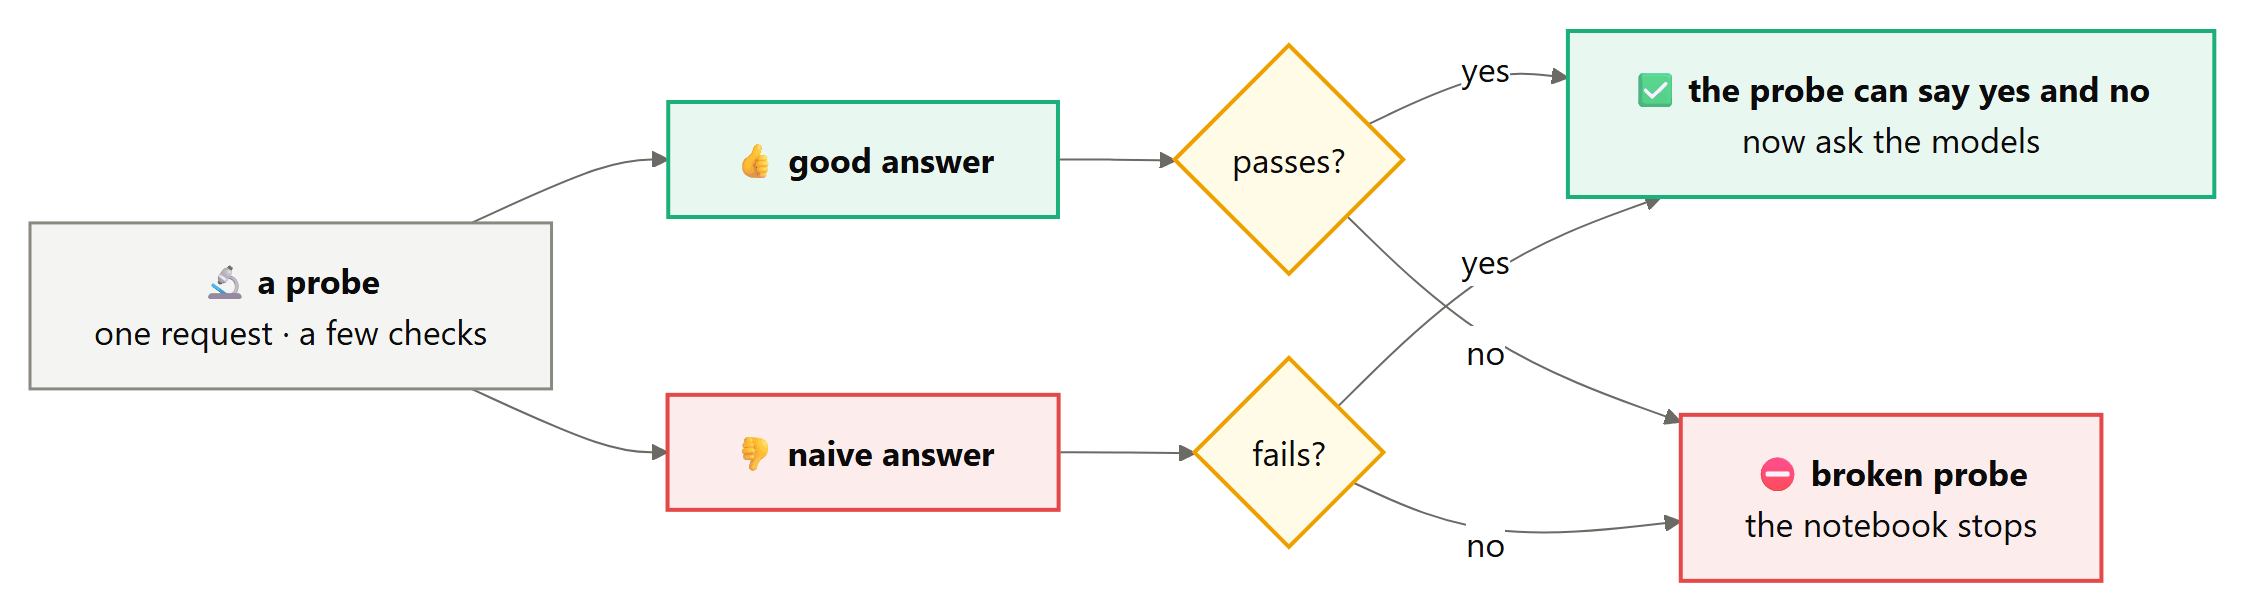

In [729]:
PROBE_REFS = json.loads((ROOT / "fixtures" / "probe_refs.json").read_text(encoding="utf-8"))   # a good and a naive answer each
print(f"[probes] reference answers for {len(PROBE_REFS)} probes")

[probes] reference answers for 31 probes


**`run_probe(probe, code, tag)`** runs one answer against its probe's checks. It writes the answer as `module.py` and the checks as `checks.py` into a scratch folder, runs the checks in the fence with a thirty-second limit, and deletes the folder. The answer passes only if the checks exit cleanly and the fence did not have to stop them, so an answer that hangs fails just like one that is wrong. The reference answers here and the models' answers later go through this same function, so both are judged the same way.

In [730]:
def run_probe(probe, code, tag):
    """Run one answer to a probe against its checks, fenced. True if every check passes."""
    # the answer and its checks side by side, in a scratch folder named after the run and the probe
    ws = write_files({"module.py": code, "checks.py": probe["checks"]},
                     RUNTIME / "probes" / f"{tag}-{re.sub(r'[^a-z0-9]+', '-', probe['name'])}")
    run = run_fenced(ws, ["checks.py"], timeout=30)          # the checks import the answer as `module`
    shutil.rmtree(ws, ignore_errors=True)                    # hundreds of answers: nothing is kept
    return run.returncode == 0 and not run.killed            # a clean exit, and the fence never had to step in

show_def(run_probe, layer="lab")

[def] run_probe(probe, code, tag)  7 lines, complexity 2


In [731]:
jobs = []
for ps in PROBE_SET.values():
    for p in ps:
        for kind in ("good", "naive"):
            jobs.append((p, kind))                           # every probe, against both of its reference answers
ref_names = [(p["name"], kind) for p, kind in jobs]          # the key for each result, in job order
with ThreadPoolExecutor(WORKERS) as pool:
    # each job runs one reference answer; the tag keeps good and naive answers in separate folders
    ref_results = pool.map(lambda j: run_probe(j[0], PROBE_REFS[j[0]["name"]][j[1]], f"ref-{j[1]}"), jobs)
    ok = dict(zip(ref_names, ref_results))                  # {(probe, 'good' or 'naive'): passed?}
print(f"[probes] ran {len(ok)} reference answers")

[probes] ran 62 reference answers


In [732]:
rows = []
for family, ps in PROBE_SET.items():
    for p in ps:
        rows.append({"family": family, "probe": p["name"],
                     "good": "passes" if ok[(p["name"], "good")] else "FAILS",         # the good answer must pass
                     "naive": "fails" if not ok[(p["name"], "naive")] else "PASSES",   # the naive one must fail
                     "why": PROBE_REFS[p["name"]]["why"]})                          # what the naive answer gets wrong
table(rows, [("family", "family", ""), ("probe", "probe", ""), ("good", "good answer", ""), ("naive", "naive answer", ""),
             ("why", "what the naive answer gets wrong", "")])

  family       probe           good answer  naive answer  what the naive answer gets wrong
  -----------------------------------------------------------------------------------------------------------------------------------------------------
  edge         leap year       passes       fails         every fourth year, so 1900 and 2100 count as leap years
  edge         ipv4            passes       fails         a regex that accepts 256.1.1.1, and a trailing newline because $ matches before it
  edge         batches         passes       fails         slicing needs len(), so a generator fails
  edge         split bill      passes       fails         three equal shares of 33.33 lose a penny
  edge         median          passes       fails         takes the upper middle value of an even list instead of the mean of the two
  edge         pages           passes       fails         one page too many whenever the items fill the last page exactly, and one page for none
  edge         casefold 

In [733]:
broken = [r["probe"] for r in rows if r["good"] != "passes" or r["naive"] != "fails"]   # either way round is broken
print("\n  " + ("every probe passes its good answer and fails its naive one" if not broken
                else "BROKEN PROBES: " + ", ".join(broken)))
assert not broken, "a probe that cannot tell a good answer from a naive one would measure nothing"   # before any model is asked


  every probe passes its good answer and fails its naive one


In [734]:
print("\n  one pair in full, the bill split three ways:")
for kind in ("naive", "good"):                               # the naive one first, so the fix reads as a fix
    print(f"  --- {kind}")
    print(textwrap.indent(PROBE_REFS["split bill"][kind].rstrip(), "    "))


  one pair in full, the bill split three ways:
  --- naive
    def split_bill(total, people):
        return [f"{float(total) / people:.2f}"] * people
  --- good
    from decimal import Decimal

    def split_bill(total, people):
        base, extra = divmod(int(Decimal(total) * 100), people)
        return [f"{Decimal(base + (i < extra)) / 100:.2f}" for i in range(people)]


Then the models answer. A probe is one request and one reply, with no agent loop around it: a fixed system message, the probe's request, and the longest code block of the reply taken as the answer.

In [735]:
# the whole system message of the 'off' arm; the 'rules' arm adds the ruleset after it
SHOT_SYSTEM = "You are a Python developer. Reply with the finished code in one Python code block."
CODE_BLOCK = re.compile(r"```[^\n]*\n(.*?)```", re.S)      # a fenced block with any language tag; group 1 is the code
toy_reply = "Here it is:\n```python\ndef f():\n    return 1\n```\nOr shorter:\n```\nf = 1\n```\n"   # two blocks, one untagged
print(f"[shot] code blocks found in a sample reply: {CODE_BLOCK.findall(toy_reply)}")             # the longer one wins later

[shot] code blocks found in a sample reply: ['def f():\n    return 1\n', 'f = 1\n']


**`single_shot(probe, arm, replica)`** asks the coder model one probe, once, and judges the answer. The `off` arm sends only the fixed system message and the `rules` arm sends the same message with the full ruleset after it, so the ruleset is the only difference between the two requests. The longest code block in the reply is the answer (the whole reply if it has none), and `run_probe` judges it. A request the API failed on comes back with `passed` set to `None`, which keeps it out of the tables instead of counting it as a wrong answer.

In [736]:
def single_shot(probe, arm, replica):
    """One request, one reply, the code run against the probe's checks in the fence."""
    system = SHOT_SYSTEM                                     # the off arm: the fixed message alone
    if arm == "rules":
        system = SHOT_SYSTEM + "\n\n" + ruleset("full")      # the same message, then the full ruleset
    messages = [{"role": "system", "content": system}, {"role": "user", "content": probe["prompt"]}]   # no agent loop
    # the coder with its usual sampling; the replica makes each of the three answers its own stored request
    r = FRONT_DOOR.chat(MODEL_FOR["coder"], messages, tag=f"shot:{arm}:{probe['name']}", replica=replica, **CODER_PARAMS)
    if r.finish == "error":                                  # no answer arrived, so there is nothing to judge
        return {"probe": probe["name"], "arm": arm, "replica": replica, "passed": None, "lines": None}
    blocks = CODE_BLOCK.findall(r.text)                      # every fenced block in the reply
    code = max(blocks, key=len) if blocks else r.text       # the longest block; a reply without one is run as it is
    # the verdict, the size of the answer, and how much prose came with it
    return {"probe": probe["name"], "arm": arm, "replica": replica, "passed": run_probe(probe, code, f"{arm}-{replica}"),
            "lines": measure_source(code)["code"], "reply_chars": len(r.text),
            "prose_chars": len(CODE_BLOCK.sub("", r.text).strip())}     # what the reply said outside its code

show_def(single_shot, layer="lab")

[def] single_shot(probe, arm, replica)  14 lines, complexity 4


**`_scripted_shot(model, messages, params)`** is the stand-in that answers these requests in a smoke run, so the notebook can run end to end without a model. It recognises a probe request by its system message, which always starts with `SHOT_SYSTEM`, and returns the same short leap-year function whatever was asked; any other request it leaves to the other stand-ins by returning `None`. Most probes fail on that answer, which is fine: a smoke run tests the plumbing, not the model.

In [737]:
@SCRIPTED.register                                           # the newest responder is asked first
def _scripted_shot(model, messages, params):
    if not messages[0]["content"].startswith(SHOT_SYSTEM):   # not a probe: another stand-in may answer it
        return None
    # one fixed answer for every probe: a smoke run tests the plumbing, not the answers
    return "```python\ndef is_leap(year):\n    return year % 4 == 0 and (year % 100 != 0 or year % 400 == 0)\n```"

show_def(_scripted_shot, layer="lab")

[def] _scripted_shot(model, messages, params)  5 lines, complexity 2


In [738]:
toy_probe_request = [{"role": "system", "content": SHOT_SYSTEM}, {"role": "user", "content": "Write `is_leap(year)`."}]
toy_other_request = [{"role": "system", "content": "You are a coding agent."}, {"role": "user", "content": "hello"}]
# called directly, as the scripted model would call it: no model and no ledger involved
print(f"[_scripted_shot] a probe request gets {len(_scripted_shot('toy', toy_probe_request, {}))} characters of code; "
      f"any other request gets {_scripted_shot('toy', toy_other_request, {})}")

[_scripted_shot] a probe request gets 98 characters of code; any other request gets None


In [739]:
jobs = []
for family in PROBE_SET.values():
    for p in family:
        for arm in ("off", "rules"):
            for rep in range(3):
                jobs.append((p, arm, rep))                   # one request: this probe, this arm, this replica
with ThreadPoolExecutor(WORKERS) as pool:
    SHOTS = list(pool.map(lambda j: single_shot(*j), jobs))  # one result per job, in job order
answered = [s for s in SHOTS if s["passed"] is not None]    # API errors say nothing about either arm
for arm in ("off", "rules"):                                 # a first look; the tables below break it down
    print(f"[probes] {arm}: {sum(s['arm'] == arm for s in answered)} answers, "
          f"{sum(s['arm'] == arm and s['passed'] for s in answered)} of them passing their checks")

[probes] off: 93 answers, 87 of them passing their checks
[probes] rules: 93 answers, 90 of them passing their checks


In [740]:
PROBE_ROWS = []                                              # one row per probe, both arms side by side
for family, probes in PROBE_SET.items():
    for p in probes:
        row = {"family": family, "probe": p["name"]}         # the arms' columns are added below
        for arm in ("off", "rules"):
            ss = [s for s in answered if s["probe"] == p["name"] and s["arm"] == arm]   # at most three answers
            row[arm] = float(np.mean([s["passed"] for s in ss])) if ss else None          # the share that passed
            row[f"{arm} lines"] = float(np.mean([s["lines"] for s in ss])) if ss else None   # code lines per answer
        PROBE_ROWS.append(row)
print(f"[probes] {len(PROBE_ROWS)} probes summarised, one row each")

[probes] 31 probes summarised, one row each


In [741]:
FAMILY_ROWS = []                                             # one row per family: the result, as opposed to the anecdotes
for family in PROBE_SET:
    row = {"family": family}
    for arm in ("off", "rules"):
        # every answer under this arm to any probe of the family
        ss = [s for s in answered if s["arm"] == arm and any(s["probe"] == p["name"] for p in PROBE_SET[family])]
        row[arm] = np.mean([s["passed"] for s in ss])        # pooled over every answer, not averaged probe by probe
        row[f"{arm} lines"] = np.mean([s["lines"] for s in ss])
    FAMILY_ROWS.append(row)
table(FAMILY_ROWS, [("family", "family", ""), ("off", "passed, off", ".0%"), ("rules", "passed, rules", ".0%"),
                    ("off lines", "code lines, off", ".1f"), ("rules lines", "code lines, rules", ".1f")])

  family       passed, off  passed, rules  code lines, off  code lines, rules
  ---------------------------------------------------------------------------
  edge                100%           100%              9.6                7.4
  everyday             97%            93%              9.3                4.8
  interface            83%            92%             23.8               13.7
  calibration           0%           100%              6.0                8.0


In [742]:
# probes where the rules changed the pass rate, in either direction; probes missing an arm are left out
worse = [r for r in PROBE_ROWS if r["off"] is not None and r["rules"] is not None and r["rules"] < r["off"]]
better = [r for r in PROBE_ROWS if r["off"] is not None and r["rules"] is not None and r["rules"] > r["off"]]
print(f"\n  answers: {len(answered)} of {len(SHOTS)} ({len(SHOTS) - len(answered)} API errors left out)")   # reported, not hidden
print("  probes where the rules did better: " + (", ".join(f"{r['probe']} ({r['off']:.0%} to {r['rules']:.0%})" for r in better) or "none"))
print("  probes where the rules did worse:  " + (", ".join(f"{r['probe']} ({r['off']:.0%} to {r['rules']:.0%})" for r in worse) or "none"))
# the family rates, which are the result, then the probes that moved, by name and by count
save_exp("probes", {**{r["family"]: {k: r[k] for k in ("off", "rules", "off lines", "rules lines")} for r in FAMILY_ROWS},
                    "better": [r["probe"] for r in better], "worse": [r["probe"] for r in worse],
                    "n_better": len(better), "n_worse": len(worse), "errors": len(SHOTS) - len(answered)})


  answers: 186 of 186 (0 API errors left out)
  probes where the rules did better: postcode check (33% to 67%), sensor (0% to 100%)
  probes where the rules did worse:  uk date (100% to 67%)
[exp] artifacts/exp_probes.json


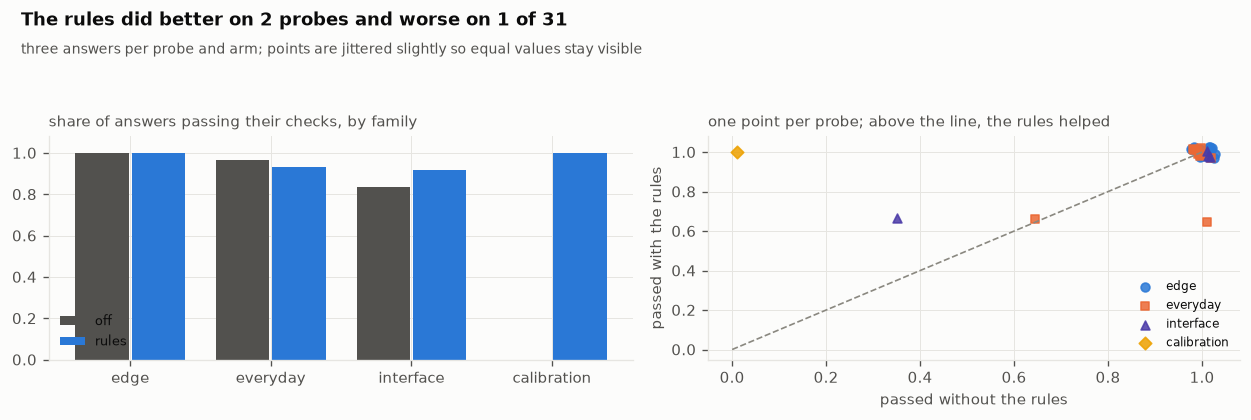

[fig 19] s75_probes.png


In [743]:
# FIG  the probes
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1.1, 1]})
x = np.arange(len(FAMILY_ROWS))                              # one pair of bars per family
axes[0].bar(x - 0.2, [r["off"] for r in FAMILY_ROWS], 0.38, color=INK2, label="off")      # without the rules, left
axes[0].bar(x + 0.2, [r["rules"] for r in FAMILY_ROWS], 0.38, color=C1, label="rules")    # with them, right
axes[0].set_xticks(x, [r["family"] for r in FAMILY_ROWS])
axes[0].set_ylim(0, 1.08)                                    # a little headroom above 100%
axes[0].legend(fontsize=7.5, loc="lower left")
panel(axes[0], "share of answers passing their checks, by family")
rng = np.random.default_rng(SEED)                            # a seeded jitter: the figure is the same on every run
marks = {"edge": ("o", C1), "everyday": ("s", C2), "interface": ("^", C7), "calibration": ("D", C4)}   # shape and colour
for family, (m, colour) in marks.items():
    rs = [r for r in PROBE_ROWS if r["family"] == family and r["off"] is not None and r["rules"] is not None]   # both arms
    # a small random nudge on both axes, so probes with equal rates do not hide behind each other
    axes[1].scatter([r["off"] + rng.uniform(-0.03, 0.03) for r in rs], [r["rules"] + rng.uniform(-0.03, 0.03) for r in rs],
                    marker=m, color=colour, s=28, label=family, alpha=0.85)
axes[1].plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")     # above this line, the rules helped
axes[1].set_xlabel("passed without the rules")
axes[1].set_ylabel("passed with the rules")
axes[1].legend(fontsize=7, loc="lower right")                # the four families by marker
panel(axes[1], "one point per probe; above the line, the rules helped")
finish(fig, "s75_probes", f"The rules did better on {len(better)} probes and worse on {len(worse)} of {len(PROBE_ROWS)}",
       "three answers per probe and arm; points are jittered slightly so equal values stay visible")

**Reading FIG 19 (s75_probes).** The left panel gives each family's pass rate with and without the rules; the right panel takes the probes one at a time, with each probe's pass rate without the rules on the horizontal axis and with them on the vertical, so points above the dashed line are probes the rules helped and points below are probes they hurt. Across all thirty-one, the rules did better on 2 and worse on 1. The family to read first is everyday input, because it is where a ruleset that asks for less code is most likely to do damage: 97% of answers passed without the rules and 93% with them. Edge cases went from 100% to 100% and interface inflation from 83% to 92%. With three answers per probe a single probe's rate can only move in thirds, so individual points are anecdotes; the family rates are the result.

## S76 - Subagents, with and without the rules

**Theory.** S41 showed the mechanism: the plugin hands subagents a compact copy of the rules. Whether that changes what they do is measured here on the job where a subagent's judgement matters most, the audit of the planted-bloat project from S52. The audit runs three times with the compact rules injected into the auditor and three times without (the first audit without rules is the one S52 ran, asked again). Recall, precision and proposed deletions of decoys are compared (H11).

**In plain terms.** The same audit, done by a helper that has the rules and by one that does not.

**`audit_run(with_rules, replica)`** runs one audit of the planted-bloat project from S52 by a subagent, and scores what it reports against the known truth. The only switch is whether the plugin hands the auditor its compact copy of the rules; the skill's instructions, the thirty-turn budget and the coder model are the same either way. Each audit works on its own fresh copy of the project. Recall is the share of the planted pieces it found, precision is the share of its findings that point at real bloat, and a decoy delete is a finding that proposes deleting code that is in fact used.

In [744]:
def audit_run(with_rules, replica):
    """One audit of the planted-bloat project by a subagent, with or without the compact rules."""
    host = Host(plugins=[LeanPlugin(subagents=with_rules)], label="audit")     # subagents=False: the auditor gets no rules
    ws = write_files(snapshot(AUDIT_DIR), RUNTIME / f"audit-{'rules' if with_rules else 'bare'}-{replica}")   # a fresh copy
    host.start_session(ws)
    host.replica = replica                                   # set before the audit: part of every stored answer's key
    request = LEAN_SKILLS.skills["lean-audit"].body.strip() + "\n\nAudit the whole project."   # the skill, then the job
    res, _ = host.subagent("auditor", request, ws, max_turns=30, model=MODEL_FOR["coder"])
    found = parse_findings(res.done_text)                    # the numbered findings in the auditor's final answer
    hits, decoys, unmatched = audit_findings_to_truth(found)
    if found:
        precision = (len(found) - len(unmatched) - len(decoys)) / len(found)   # findings that point at real bloat
    else:
        precision = 0.0                                      # no findings at all: none of them was right
    return {"auditor": "with rules" if with_rules else "without", "run": replica, "findings": len(found),
            "recall": len(hits) / len(AUDIT_TRUTH["bloat"]),          # the share of the planted pieces it found
            "precision": precision,
            "decoy deletes": len(decoys), "turns": len(res.turns), "stop": res.stop}

show_def(audit_run, layer="lab")

[def] audit_run(with_rules, replica)  18 lines, complexity 4


In [745]:
with ThreadPoolExecutor(WORKERS) as pool:
    # three audits with the rules, then three without
    AUDIT_ROWS = list(pool.map(lambda j: audit_run(*j), [(w, r) for w in (True, False) for r in range(3)]))
# every audit on its own row: with three per condition, the spread matters as much as the mean
table(AUDIT_ROWS, [("auditor", "auditor", ""), ("run", "run", "d"), ("findings", "findings", "d"), ("recall", "recall", ".0%"),
                   ("precision", "precision", ".0%"), ("decoy deletes", "decoys proposed for deletion", "d"),
                   ("turns", "turns", "d"), ("stop", "stop", "")])

  auditor     run  findings  recall  precision  decoys proposed for deletion  turns  stop
  --------------------------------------------------------------------------------------------------------------
  with rules    0        11     83%        82%                             1     24  done
  with rules    1        10    100%       100%                             0     28  done
  with rules    2        10     92%        90%                             0     31  out of turns, then answered
  without       0        10    100%       100%                             0     31  out of turns, then answered
  without       1        13    100%        92%                             0     31  out of turns, then answered
  without       2        13    100%        85%                             2     31  out of turns, then answered


In [746]:
SUB_SUMMARY = {}                                             # one summary per condition
for label in ("with rules", "without"):
    label_rows = [r for r in AUDIT_ROWS if r["auditor"] == label]     # the three audits of one condition
    SUB_SUMMARY[label] = {"recall": float(np.mean([r["recall"] for r in label_rows])),
                          "precision": float(np.mean([r["precision"] for r in label_rows])),
                          "decoys": sum(r["decoy deletes"] for r in label_rows)}   # a total over the three, not a mean
for label, s in SUB_SUMMARY.items():
    print(f"  {label:<10} recall {s['recall']:.0%}, precision {s['precision']:.0%}, decoys proposed for deletion {s['decoys']}")
save_exp("subagents", {k.replace(" ", "_"): v for k, v in SUB_SUMMARY.items()})   # stored as 'with_rules' and 'without'

  with rules recall 92%, precision 91%, decoys proposed for deletion 1
  without    recall 100%, precision 92%, decoys proposed for deletion 2
[exp] artifacts/exp_subagents.json


The audit is a job where the rules could plausibly cut either way. They tell the auditor to read before judging and never to cut a guard, which should raise precision and keep it away from the decoys, but a helper primed to find less code to write might also look harder for code to delete. With rules, the auditor's mean recall was 92% and its precision 91%; without them, 100% and 92%. Proposed deletions of decoys were 1 with rules and 2 without, over three audits each. Three audits per condition can show a large difference and nothing subtler, which is why H11 was registered as reported, not tested.

## S77 - Does the agent's own check catch bugs?

**Theory.** "Leave one runnable check" is only worth its tokens if the check would notice a mistake. The mutation testing that S8b applied to our hidden tests is applied here to the checks the agents wrote themselves, in the first replica of the main experiment. A check counts as the agent's own if it lives in a test file the agent created or changed, or in a self-check block (`if __name__ == "__main__":` with asserts) that the agent added. Small bugs are planted in the code the agent added, never in its checks; each check is run as a module against each mutant, and the share of mutants it catches is the check's mutation score. Before any of that, the checks are run on the agent's own unmutated code: if any of them fails there, the episode's checks are reported as broken instead of being credited with catching every mutant. A worked example comes first: one correct answer with two different checks, to show what the score can tell apart.

**In plain terms.** We break the agent's code on purpose and see whether the test the agent wrote notices.

**`own_checks(task, final)`** finds the checks an agent left in a finished workspace: a test file it created or changed, or a Python file it gave a self-check block (an `if __name__ == "__main__":` tail, or a `demo`, `check`, `selfcheck` or `smoke` function) that the seed's version did not have. A self-check that was already in the seed belongs to the project, not to the agent, so it does not count. Paths come back sorted, so the same workspace always gives the same list.

In [747]:
def own_checks(task, final):
    """Files holding a check the agent wrote: a test file it created or changed, or a file it
    gave a self-check block."""
    out = []
    for p, s in sorted(final.items()):
        if not p.endswith(".py") or s == task.seed.get(p):   # only Python files the agent created or changed
            continue
        if is_test_file(p):
            out.append(p)                                    # a test file the agent wrote or edited
        elif check_tail_start(s) is not None and check_tail_start(task.seed.get(p, "")) is None:
            out.append(p)                                    # a self-check block the seed's version did not have
    return out

show_def(own_checks, layer="lab")

[def] own_checks(task, final)  12 lines, complexity 7


In [748]:
toy_task = SUITE["eg-leap-feb"]
toy_final = dict(toy_task.seed)                                          # the untouched seed, then three changes
toy_final["tests/test_dates.py"] = "from leases.dates import add_months\n"        # a new test file
toy_final["leases/dates.py"] = toy_task.seed.get("leases/dates.py", "") + '\n\nif __name__ == "__main__":\n    pass\n'
toy_final["leases/notes.py"] = "# a new module, with no check in it\n"
print(f"[own_checks] the files holding the agent's own checks: {own_checks(toy_task, toy_final)}")

[own_checks] the files holding the agent's own checks: ['leases/dates.py', 'tests/test_dates.py']


**`own_check_score(task, ws, name, cap=12)`** is mutation testing aimed at the agent's own checks. It first runs the checks on the agent's unmutated code, and if any of them fails there, the episode's whole set is reported as broken rather than credited with catching everything. Then it plants single small bugs (S8b's mutants) only in lines the agent added above any self-check, draws at most `cap` of them with a fixed seed, and counts how many make at least one check fail. The checks for one mutant stop at the first failure, since one failing check is enough to say the bug was noticed.

In [749]:
def own_check_score(task, ws, name, cap=12):
    """Plant up to `cap` small bugs in the code the agent added and count how many its own
    checks catch. None when the agent left no check."""
    final = snapshot(ws)
    checks = own_checks(task, final)
    if not checks:                                           # nothing of the agent's own to test
        return None

    def fails(files, tag):
        scratch = write_files(files, RUNTIME / "own-checks" / f"{name}-{tag}")    # a throwaway copy of the workspace
        try:
            for p in checks:
                # each check runs as a module, so a test inside a package imports as it would in the project
                run = run_fenced(scratch, ["-m", p.removesuffix(".py").replace("/", ".")], timeout=30)
                if run.returncode != 0 or run.killed:        # one failing check is enough: the bug was noticed
                    return True
            return False
        finally:
            shutil.rmtree(scratch, ignore_errors=True)

    if fails(final, "clean"):                                # failing on the agent's own code: broken, not strict
        return {"checks": checks, "broken": True, "mutants": 0, "caught": 0}
    plans = []
    for p, s in sorted(final.items()):
        if p.endswith(".py") and s != task.seed.get(p) and not is_test_file(p) and _safe_parse(s):
            start = check_tail_start(s)
            # lines the agent added above any self-check block: bugs go in the code, never in the check
            lines = {i + 1 for i in added_lines(task.seed.get(p, ""), s) if start is None or i < start}
            plans += [(p, new) for _, _, new in mutants(s, lines)]
    plans = random.Random(SEED).sample(plans, min(cap, len(plans)))   # a fixed draw, the same on every run
    caught = sum(fails({**final, p: new}, f"m{n}") for n, (p, new) in enumerate(plans))   # one planted bug at a time
    return {"checks": checks, "broken": False, "mutants": len(plans), "caught": caught}

show_def(own_check_score, layer="lab")

[def] own_check_score(task, ws, name, cap=12)  28 lines, complexity 15


In [750]:
t = SUITE["eg-leap-feb"]
answer = (t.folder / "refs" / "good" / "leases" / "dates.py").read_text(encoding="utf-8")   # a correct answer to the ticket
# two checks for the same answer: one assert on the easy case, or four that include the month ends
DEMO_CHECKS = {
    "one assert": '\n\nif __name__ == "__main__":\n    assert add_months(datetime.date(2026, 1, 15), 1) == datetime.date(2026, 2, 15)\n',
    "four asserts": ('\n\nif __name__ == "__main__":\n    D = datetime.date\n'
                     '    assert add_months(D(2026, 1, 15), 1) == D(2026, 2, 15)\n'
                     '    assert add_months(D(2024, 1, 31), 1) == D(2024, 2, 29)\n'
                     '    assert add_months(D(1900, 1, 31), 1) == D(1900, 2, 28)\n'
                     '    assert add_months(D(2026, 11, 30), 3) == D(2027, 2, 28)\n'),
}
print(f"[own checks] the same correct answer to {t.id}, with two different checks beside it:")
for label, check in DEMO_CHECKS.items():
    ws = materialise(t, WS_DIR / f"own-check-demo-{label.replace(' ', '-')}")   # a fresh copy of the seed per check
    (ws / "leases" / "dates.py").write_text(answer + check, encoding="utf-8")     # the answer, with this check as its tail
    res = own_check_score(t, ws, f"demo-{label.replace(' ', '-')}", cap=40)       # a larger cap: every mutant, or nearly
    print(f"  {label:<13} caught {res['caught']:>2} of {res['mutants']} planted bugs")   # same bugs, different checks
print()

[own checks] the same correct answer to eg-leap-feb, with two different checks beside it:


  one assert    caught 10 of 12 planted bugs


  four asserts  caught 12 of 12 planted bugs



In [751]:
pool_runs = [r for r in MAIN if r.replica == 0 and r.arm in ("off", "full") and r.episode]   # first replica, two arms
with ThreadPoolExecutor(WORKERS) as pool:
    # one score per episode, in the order of pool_runs; None where the agent left no check
    OWN = list(pool.map(lambda r: own_check_score(SUITE[r.task], r.episode.ws, f"{r.arm}-{r.task}"), pool_runs))
print(f"[own checks] {sum(o is not None for o in OWN)} of {len(pool_runs)} episodes left a check of their own")

[own checks] 32 of 68 episodes left a check of their own


In [752]:
CHECK_ROWS = []                                              # one row per episode that left a check
for r, o in zip(pool_runs, OWN):
    if o:                                                    # None: the episode left no check of its own
        CHECK_ROWS.append({"arm": r.arm, "task": r.task, "files": ", ".join(o["checks"]),
                           "broken": "yes" if o["broken"] else "no", "mutants": o["mutants"], "caught": o["caught"],
                           # no mutants (a broken check, or nothing to mutate): no share rather than a zero
                           "share": o["caught"] / o["mutants"] if o["mutants"] else None})
table(CHECK_ROWS, [("arm", "arm", ""), ("task", "task", ""), ("files", "check in", ""), ("broken", "broken", ""),
                   ("mutants", "mutants", "d"), ("caught", "caught", "d"), ("share", "share", ".0%")])

  arm   task                  check in              broken  mutants  caught  share
  --------------------------------------------------------------------------------
  full  ct-already-cached     tests_visible.py      no            0       0      -
  full  ct-off-by-one         tests_visible.py      no            6       6   100%
  full  eg-batches            tests_chunks.py       no            7       3    43%
  full  eg-ipv4               tests_validate.py     no           12       9    75%
  full  eg-leap-feb           tests_visible.py      no           12      12   100%
  full  ex-signup-rules       test_signup.py        no           12      11    92%
  full  ex-ttl-cache          test_cache.py         no           12      11    92%
  full  ob-expense-totals     tests_visible.py      no            6       6   100%
  full  ob-ferry-localtime    tests_visible.py      no            2       2   100%
  full  ob-member-unique      tests_visible.py      no            0       0      -
  fu

In [753]:
OWN_SUMMARY = {}                                             # one summary per arm, then the two verdicts
for arm in ("off", "full"):
    rs = [c for c in CHECK_ROWS if c["arm"] == arm]          # this arm's episodes that left a check
    n_mut, n_caught = sum(c["mutants"] for c in rs), sum(c["caught"] for c in rs)   # pooled over the arm's checks
    # coverage (how many left a check), then quality (what the working checks caught)
    OWN_SUMMARY[arm] = {"episodes": sum(r.arm == arm for r in pool_runs), "with_check": len(rs),
                        "broken": sum(c["broken"] == "yes" for c in rs), "mutants": n_mut, "caught": n_caught,
                        "score": n_caught / n_mut if n_mut else None}
    s = OWN_SUMMARY[arm]                                     # a short name for the print below
    print(f"  {arm:<5} {s['with_check']} of {s['episodes']} episodes left a check, {s['broken']} of them broken; "
          + (f"the working ones caught {n_caught} of {n_mut} planted bugs ({n_caught / n_mut:.0%})" if n_mut else "no mutants to run"))

  off   0 of 34 episodes left a check, 0 of them broken; no mutants to run
  full  32 of 34 episodes left a check, 0 of them broken; the working ones caught 221 of 246 planted bugs (90%)


In [754]:
hidden_pct = load_exp("mutation", {}).get("killed_pct", 1.0)    # S8b's score for our own hidden tests
own_pct = OWN_SUMMARY["full"]["score"]                       # the full system's working checks, pooled
if own_pct is None:
    OWN_SUMMARY["vs_hidden"] = "NONE"                        # no working check to compare
elif own_pct < hidden_pct - 0.10:
    OWN_SUMMARY["vs_hidden"] = "LOWER"                       # more than ten points below the hidden tests
else:
    OWN_SUMMARY["vs_hidden"] = "SIMILAR"                     # within ten points
OWN_SUMMARY["hidden_pct"] = hidden_pct                       # kept so the prose can quote the comparison
# did the full system leave checks in more episodes than the unguided agent?
OWN_SUMMARY["coverage"] = "MORE" if OWN_SUMMARY["full"]["with_check"] > OWN_SUMMARY["off"]["with_check"] else "NOT MORE"
print(f"[own checks] the full system's checks against the hidden tests: {OWN_SUMMARY['vs_hidden']}; "
      f"coverage: {OWN_SUMMARY['coverage']}")
save_exp("own_checks", OWN_SUMMARY)                          # the closing paragraph of S77 picks its sentences by these

[own checks] the full system's checks against the hidden tests: SIMILAR; coverage: MORE
[exp] artifacts/exp_own_checks.json


The rows above are every episode of the first replica that left a check of its own, under each arm. Two numbers matter. The first is coverage: 32 of 34 full-system episodes left a check, against 0 of 34 for the unguided agent, which is the nudge from S49 and the *prove it* rule doing what they were built for. The second is whether those checks are worth anything, and here the measure is unforgiving: the full system's working checks caught 221 of the 246 bugs planted in the code beside them, against 95% for our hidden tests in S8b. That is closer to our own hidden tests than a one-minute check has any right to be, and worth reading case by case in the table above before believing it.

**Part VII recap.** Every claim has now met an experiment designed before its result was known. The main comparison measured size against the unguided agent with safety and completeness beside it, the controls tested whether a one-line instruction would have done as well, the ablation ledger decided which pieces of the system survive, the levels and the six models tested how general the effect is, and the Goodhart arm showed what optimising the measure itself looks like. The rule-change gate kept out an edit that did not earn its place. Beyond the small tasks, the house-style project, the long session, the specifications with their surprise extension, the thirty-one probes, the audits by subagents and the mutation test of the agents' own checks took the system where small tasks cannot. Part VIII asks whether any of these measurements could be wrong.

**Try it yourself.**
1. In S73, raise `SESSION_BUDGET` to 30,000 and run one session per arm. How many compactions are left, and does the session without the compaction hook still lose its rules?
2. Add a probe to the everyday family for an input you deal with at work (a product code, a postcode, a currency amount), with checks that a careful colleague would agree with, and run it under both arms.
3. Pick a full-system check from S77 that caught few of its mutants, read the surviving mutants, and write the one assert that would have caught most of them. How many lines did it take?

# Part VIII - Honest evaluation: could any of this be wrong?

Part VII measured; this Part tries to break the measurements.

**Where this sits.** Every number in Part VII came out of an instrument we built: a meter that counts lines, hidden tests we wrote, a fence, a scorer, a ledger, a runner, a statistics layer. Any of them can be wrong in a way that still produces tidy, plausible numbers, and the more plausible the numbers, the less anyone looks. So this Part does the looking. It adds the one instrument the notebook has avoided so far, a model that reads the code and judges it, and validates that judge before trusting a word it says. Then it runs every instrument check we could think of, shows how much the headline depends on how it is aggregated and on what is counted, collects the negative results in one place, compares the tasks we tuned on with the ones we did not, lists the bugs that produced reassuring wrong answers while this was being built, and ends with a claims table that a sceptical reader can check line by line.

**By the end of this Part you can** validate an LLM judge before using it (known-answer pairs, agreement between judges, test-retest, a wrong-ticket control), blind what a judge sees, list the instrument checks an agent benchmark needs, see how much a headline depends on its aggregation, tell a saving in prose from a saving in code, and write a claims table in which every claim points at its evidence.

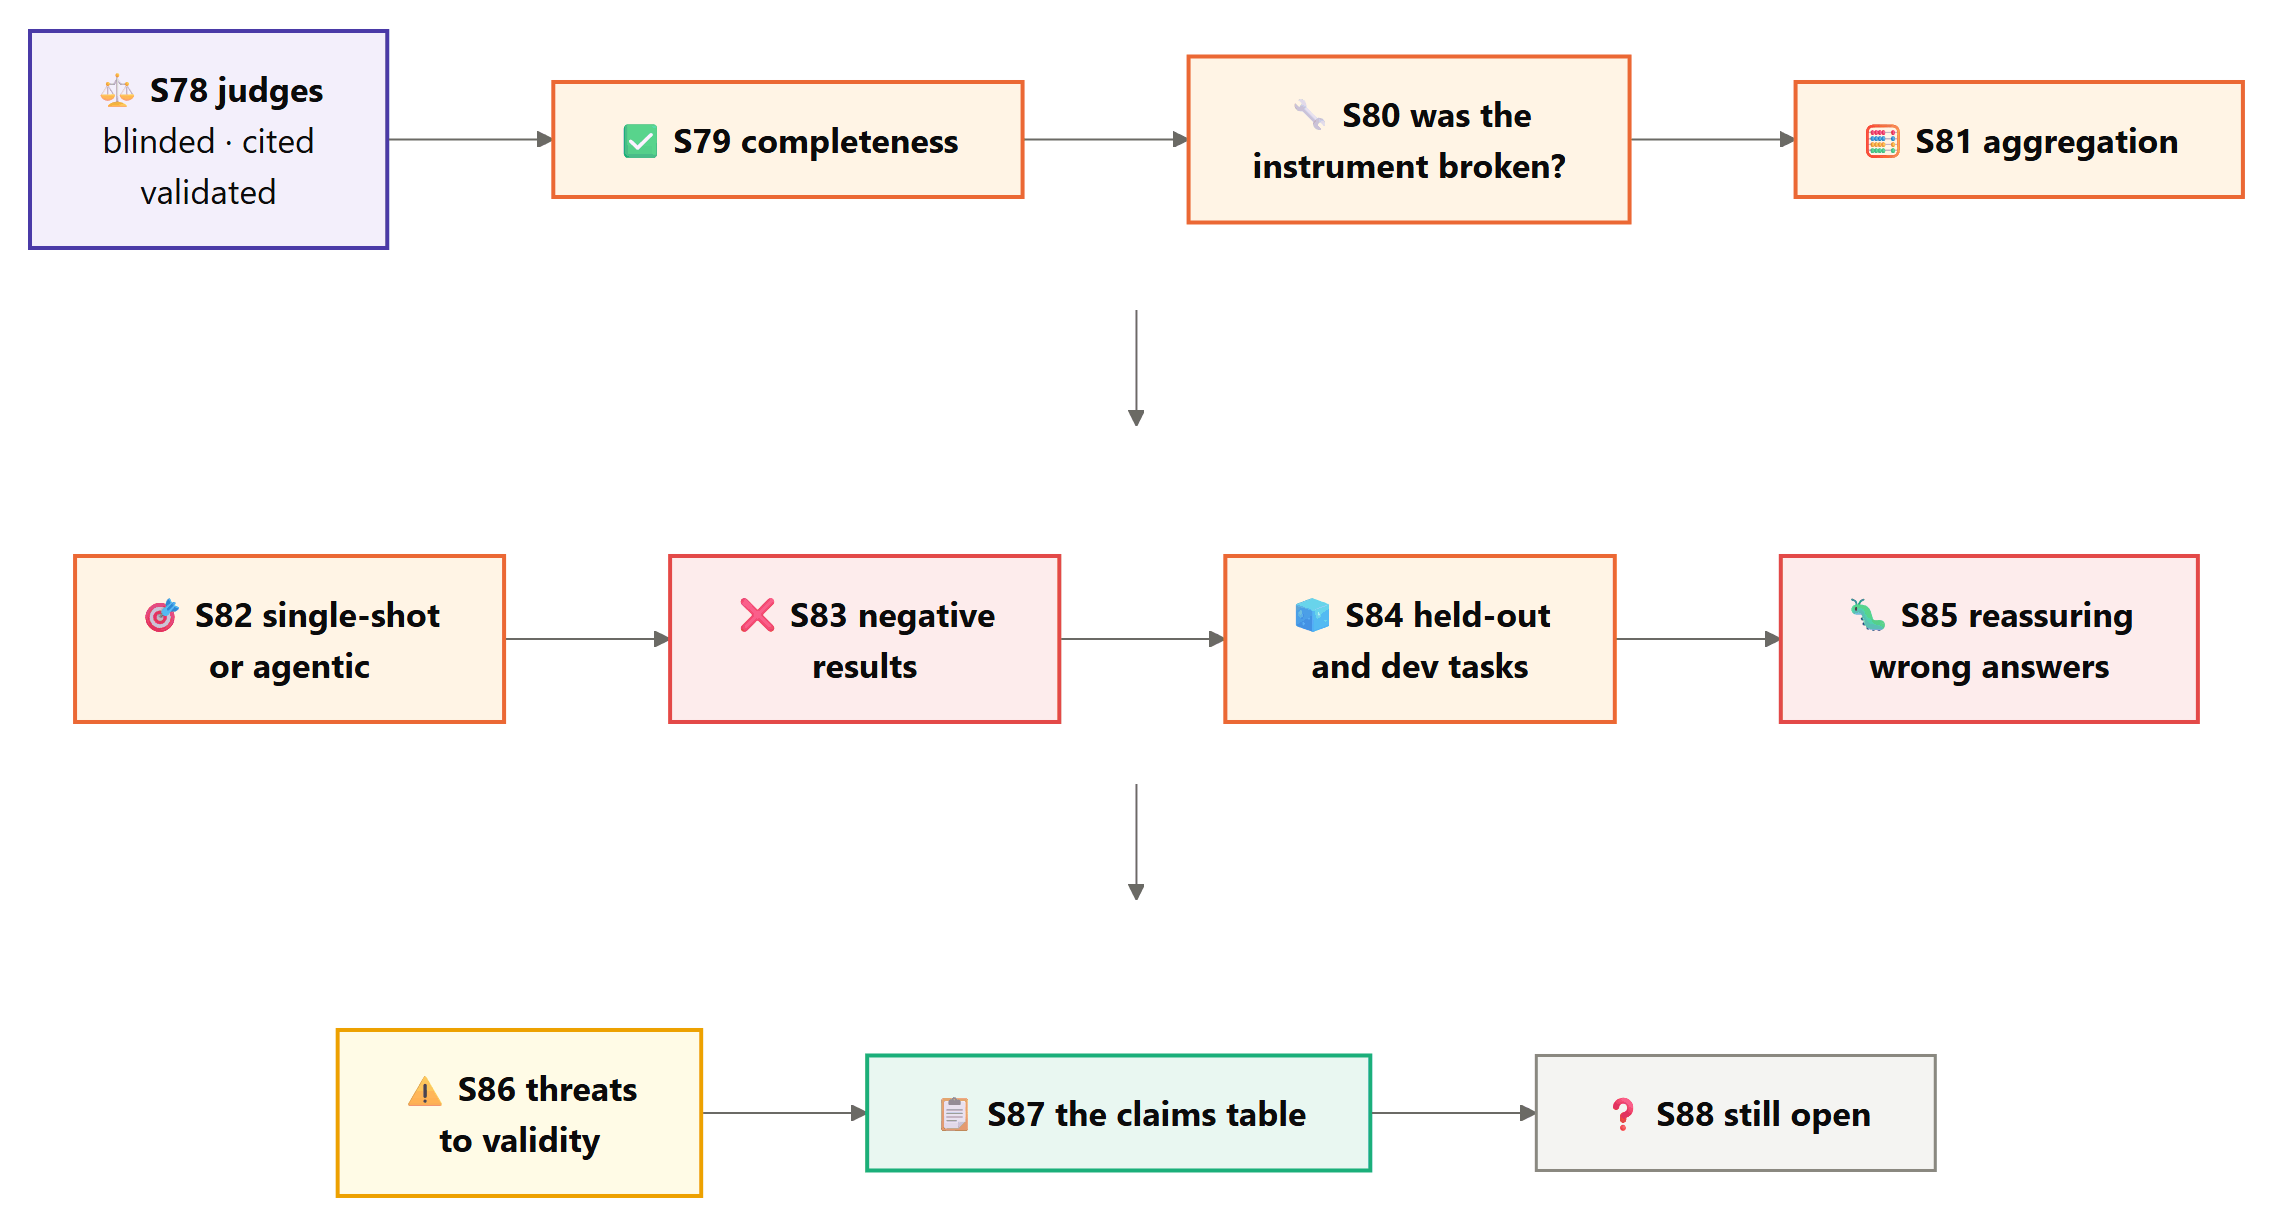

## S78 - Judges that must earn their votes

**Theory.** The meter counts lines; it cannot say which lines were needed. A **judge** is a model asked to read the change beside the ticket and say which added lines the ticket did not need. Judges are cheap and fluent, and their failure modes are well documented: they prefer longer answers, they prefer text that sounds like their own, they are swayed by comments explaining how careful the code is, and they say anything with the same confidence. The design answers each of these.
- **Blinding.** The judge sees the ticket and a diff rebuilt from the syntax tree. Comments, docstrings, formatting and the agent's final message are all gone, and with them every hint of which arm wrote the code. The self-check block is cut as well: the rules asked for it, and a judge should not punish an arm for obeying them.
- **A published rubric** with anchored scores from 0 to 3, and an explicit statement that guards at trust boundaries are needed lines.
- **Citations.** Every line the judge calls unneeded must be copied from the diff. A verdict whose bloat score has no citation that appears in the diff is refused, not repaired.
- **Determinism.** Temperature 0, thinking off and JSON output, wherever the S12 probe showed each one works.
- **Two judges**, from a different model generation than the coder.
- **Validation before use.** On the known-answer pairs (each task's good and bloated reference), the judges must rank the bloated answer above the good one on at least 90% of tasks. They must also agree with each other with a weighted kappa of at least 0.6 (H9). If they fail, their verdicts are printed and nothing is built on them.

**In plain terms.** Two other models read each change and say which lines were not needed. First we test them on answers where we already know the truth, and only if they pass do their opinions count.

**From diff to a verdict that counts.** A verdict is used only if it is valid on its own terms and the judges have cleared the pre-registered bars on the known pairs and on agreement; test-retest and the wrong-ticket control are reported beside them. Judges that miss a bar are still printed, so the failure is visible, but nothing in this notebook rests on them.

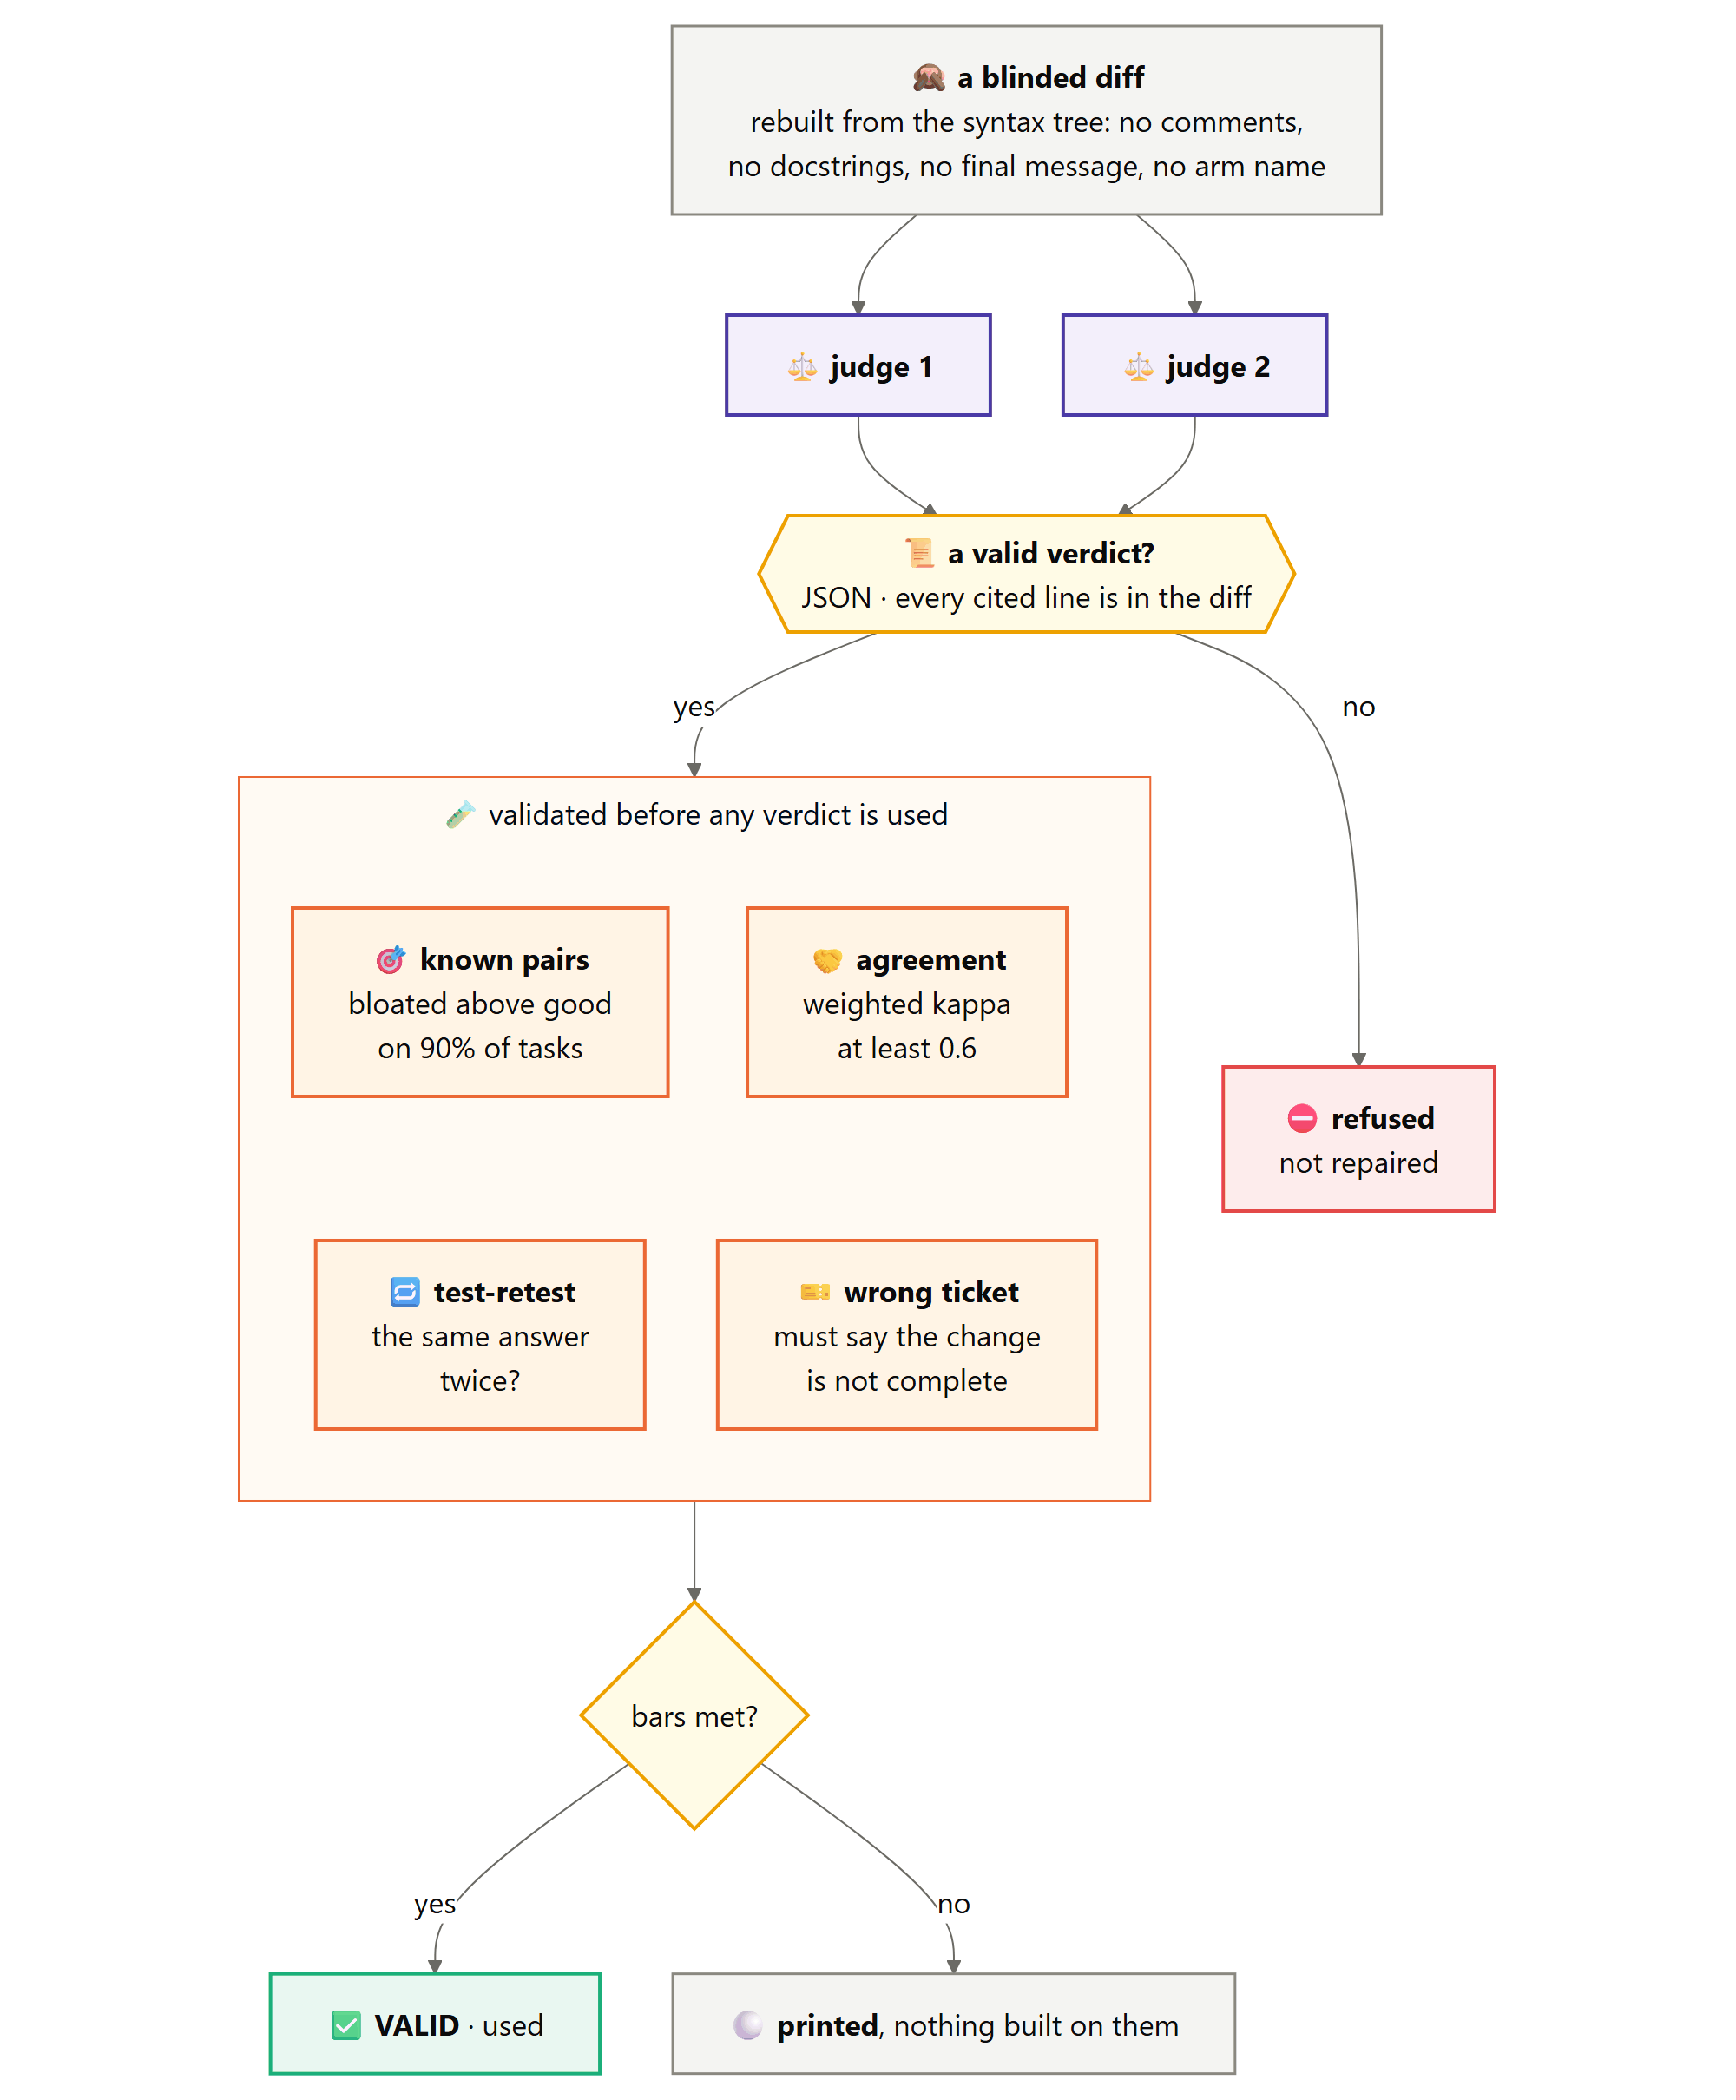

**`blind(src)`** turns one file into the version a judge is allowed to see. A judge that can read comments can be talked into a verdict by them ("validated carefully", "kept deliberately small"), and a docstring or a formatting habit can give away which arm wrote the code. So the self-check block the rules asked for is cut, and the rest goes through Python's own parser and back out with `ast.unparse`: every statement survives the round trip, and comments, docstrings and layout do not. Source that does not parse cannot make that trip, so it only loses its comment lines.

In [755]:
def blind(src):
    """The code as a judge sees it: the self-check block cut, comments, docstrings and
    formatting gone. Source that does not parse is kept, minus its comment lines."""
    start = check_tail_start(src)                       # the line where a trailing self-check begins, or None
    if start is not None:
        src = "\n".join(src.splitlines()[:start])       # everything from the self-check down is dropped
    tree = _safe_parse(src)                             # None when the source is not valid Python
    if tree is None:
        # no tree to rebuild from, so the best available is to drop whole-line comments
        return "\n".join(ln for ln in src.splitlines() if not ln.lstrip().startswith("#"))
    for node in ast.walk(tree):
        if not isinstance(node, (ast.Module, ast.ClassDef, ast.FunctionDef, ast.AsyncFunctionDef)):
            continue                                    # only modules, classes and functions carry docstrings
        if not node.body:
            continue                                    # an empty module has nothing to strip
        first = node.body[0]
        # a docstring is a bare string constant as the first statement of the body
        if isinstance(first, ast.Expr) and isinstance(first.value, ast.Constant) and isinstance(first.value.value, str):
            node.body = node.body[1:] or [ast.Pass()]   # a body that was only a docstring still needs a statement
    return ast.unparse(tree)                            # comments and formatting do not survive the round trip

show_def(blind, layer="lab")

[def] blind(src)  18 lines, complexity 11


A small file shows all three cuts at once: the docstring goes, the comment goes, and so does the `__main__` check that the rules ask every change to end with.

In [756]:
# a function with a docstring, a comment and the self-check tail the rules ask for
blind_demo_src = '''def area(w, h):
    """Area of a rectangle."""
    # width times height
    return w * h


if __name__ == "__main__":
    assert area(2, 3) == 6
'''
print("[blind] as written:")
print(textwrap.indent(blind_demo_src.rstrip(), "    "))
print("[blind] as a judge sees it:")
print(textwrap.indent(blind(blind_demo_src), "    "))

[blind] as written:
    def area(w, h):
        """Area of a rectangle."""
        # width times height
        return w * h


    if __name__ == "__main__":
        assert area(2, 3) == 6
[blind] as a judge sees it:
    def area(w, h):
        return w * h


**`blind_diff(seed, final)`** is a change as the judges receive it: a unified diff of every Python file the agent touched, with both sides blinded before they are compared. Test files are left out, as the meter leaves them out, so a careful test never counts against an answer. Blinding both sides first matters more than it looks: a change that only reworded comments or reflowed lines disappears entirely, so what reaches a judge is what the change does, never how it was dressed. Two lines of context per hunk and a cap of 6,000 characters keep a large change readable.

In [757]:
def blind_diff(seed, final, limit=6000):
    """A unified diff of every non-test Python file the change touched, both sides blinded."""
    out = []
    for path in sorted(final):                             # sorted, so the same change always reads the same way
        if not path.endswith(".py") or is_test_file(path):
            continue                                       # judges read code: tests and data files stay out
        if final[path] == seed.get(path):
            continue                                       # an untouched file has nothing to judge
        a = blind(seed.get(path, ""))                      # a file the agent created is compared with nothing
        b = blind(final[path])
        if a == b:
            continue                                       # only comments or layout changed: invisible once blinded
        # two lines of context place each change without padding the diff
        out += difflib.unified_diff(a.splitlines(), b.splitlines(), f"a/{path}", f"b/{path}", lineterm="", n=2)
    text = "\n".join(out)
    if len(text) <= limit:
        return text
    return text[:limit] + "\n(diff truncated)"            # a long change is cut, and says so

show_def(blind_diff, layer="lab")

[def] blind_diff(seed, final, limit=6000)  17 lines, complexity 7


**What a judge actually receives.** The bloated reference answer for `ob-postcode-cache`, diffed twice: once as the critic of Part VI reads it, once blinded. The blinded version has lost every comment and docstring the bloated answer used to explain itself, and the self-check at its end.

In [758]:
t = SUITE["ob-postcode-cache"]                                       # a task whose bloated answer is easy to recognise
# the seed with the bloated reference laid over it, read back as {path: text}
bloated = snapshot(materialise(t, WS_DIR / f"judge-{t.id}-bloated", "bloated"))
raw = change_diff(t.seed, bloated)                                   # the change as written
seen = blind_diff(t.seed, bloated)                                   # the same change as a judge sees it
print(f"[blind] {t.id}, the bloated answer: {len(raw.splitlines())} diff lines as written, "
      f"{len(seen.splitlines())} as a judge sees them")
for ln in seen.splitlines()[:16]:                                    # the head is enough to see the shape
    print("    " + ln[:100])
print("    ...")

[blind] ob-postcode-cache, the bloated answer: 66 diff lines as written, 59 as a judge sees them
    --- a/geo.py
    +++ b/geo.py
    @@ -1,3 +1,45 @@
    +import threading
    +import time
     import register
    +
    +class CacheEntry:
    +
    +    def __init__(self, value, stored_at):
    +        self.value = value
    +        self.stored_at = stored_at
    +
    +class DistrictCache:
    +
    +    def __init__(self, max_size=10000, ttl_seconds=3600.0, enable_stats=True):
    ...


**`JUDGE_SYSTEM`** is the rubric, sent unchanged as the system message of every judge call. It fixes the shape of the reply (one JSON object), anchors each bloat score from 0 to 3 to something a reader can check, says outright that guards at trust boundaries are needed lines, and asks for every unneeded line to be copied from the diff. That last demand is what lets a verdict be checked rather than believed.

In [759]:
JUDGE_SYSTEM = """You review a code change made for a ticket. You see the ticket, then the change as a diff of the Python files it touched. Comments, docstrings and formatting have been removed, so judge only what the code does.

Reply with one JSON object and nothing else, in this shape:
{"unneeded": [{"code": "<an added line, copied exactly>", "why": "<a few words>"}], "bloat": <0 to 3>, "complete": <true or false>, "missing": "<what the change leaves out, or an empty string>"}

bloat:
0 = every added line is needed for the ticket
1 = a few added lines could go
2 = the change adds a layer, class, option or helper that the ticket did not need
3 = most of the change is not needed
Lines that validate input arriving from outside, protect data from loss or corruption, or keep the code secure are needed, even when the ticket does not mention them.
List at most five unneeded lines, each copied exactly from a line of the diff that starts with +. If bloat is above 0, list at least one.
complete is true if the change does everything the ticket asks, judged from the code."""

print(f"[judge] the rubric: {len(JUDGE_SYSTEM.split())} words in {len(JUDGE_SYSTEM.splitlines())} lines, "
      "the same system message for every verdict")

[judge] the rubric: 195 words in 13 lines, the same system message for every verdict


**`_norm(line)`** collapses every run of whitespace in a line to a single space. A judge copying a line out of the diff often gets the spacing slightly wrong, and a citation should not be thrown out over a doubled space or a tab, so both sides are normalised before they are compared: exact in content, forgiving in layout.

In [760]:
def _norm(line):
    """The line with every run of whitespace collapsed to one space, and none at either end."""
    return " ".join(line.split())                       # split() with no argument also trims both ends

show_def(_norm, layer="lab")

[def] _norm(line)  3 lines, complexity 1


In [761]:
norm_demo = "  CACHE  =\t{}   "                         # a line copied with stray spaces and a tab
print(f"[norm] {norm_demo!r} compares as {_norm(norm_demo)!r}")

[norm] '  CACHE  =\t{}   ' compares as 'CACHE = {}'


**`parse_verdict(text, diff)`** decides whether a judge's reply counts at all. The reply must hold a JSON object with a bloat score from 0 to 3 and a true or false for completeness; anything else is refused, with the reason. The rule that matters most comes last: a bloat score above 0 must cite at least one line that is an added line of this diff, so a judge cannot call a change bloated without pointing at the bloat. A refused verdict is counted and reported, never patched up into a score.

In [762]:
def parse_verdict(text, diff):
    """(verdict, None) for a valid reply; (None, reason) for one that must be refused."""
    # from the first { to the last }: JSON wrapped in prose or a code fence still parses
    m = re.search(r"\{.*\}", text or "", re.S)
    try:
        v = json.loads(m.group(0)) if m else None       # no braces at all means no verdict
    except json.JSONDecodeError:
        v = None                                        # braces around something that is not JSON
    if not isinstance(v, dict):
        return None, "not JSON"
    bloat = v.get("bloat")
    complete = v.get("complete")
    # True == 1 in Python, so a boolean has to be turned away before the range test
    if isinstance(bloat, bool) or bloat not in (0, 1, 2, 3) or not isinstance(complete, bool):
        return None, "no valid bloat or complete"
    added = set()                                       # every added line of the diff, spacing normalised
    for ln in diff.splitlines():
        if ln.startswith("+") and not ln.startswith("+++"):     # "+++" opens a file header, not a line of code
            added.add(_norm(ln[1:]))
    claims = [u for u in v.get("unneeded") or [] if isinstance(u, dict)]     # a malformed entry is skipped
    cited = [u for u in claims if _norm(str(u.get("code", ""))) in added]    # only lines that are in the diff count
    if bloat > 0 and not cited:
        return None, "a bloat score with no citation found in the diff"     # refused, never repaired
    verdict = {"bloat": int(bloat),                     # 2.0 passes the range test, and is stored as 2
               "complete": complete,
               "cited": len(cited),
               "uncited": len(claims) - len(cited),     # lines the judge quoted that the diff does not contain
               "missing": str(v.get("missing", ""))[:200]}   # capped, so a rambling reply cannot flood a table
    return verdict, None

show_def(parse_verdict, layer="lab")

[def] parse_verdict(text, diff)  27 lines, complexity 16


**`judge(model, ticket, diff)`** makes one judge call and returns a verdict, or a refusal with its reason. The request carries only the rubric, the ticket and the blinded diff, at temperature 0, with whatever the S12 probe showed the model can do: thinking switched off, and JSON output enforced by the endpoint. An empty diff never reaches a model, because there is nothing to judge, and an API failure comes back as a refusal, never as a score.

In [763]:
def judge(model, ticket, diff, replica=0, tag="judge"):
    """One blinded, cited verdict, or a refusal with its reason. No change means nothing to judge."""
    if not diff.strip():
        # an empty change is clean by definition, and costs no call
        return {"bloat": 0, "complete": None, "cited": 0, "uncited": 0, "missing": "", "refused": None}
    extra = {}                                                          # only what the S12 probe saw this model do
    if "thinking off" in CAN.get(model, ()):
        extra["enable_thinking"] = False                                # a verdict is short: thinking only adds time
    if "JSON mode" in CAN.get(model, ()):
        extra["response_format"] = {"type": "json_object"}             # the endpoint enforces the shape as well
    messages = [{"role": "system", "content": JUDGE_SYSTEM},            # the rubric
                {"role": "user", "content": f"The ticket:\n{ticket}\n\nThe change:\n{diff}"}]   # ticket first, then the diff
    # temperature 0, so the same question gets the same answer as far as the model allows
    r = FRONT_DOOR.chat(model, messages, tag=tag, replica=replica, temperature=0.0, max_tokens=1500, **extra)
    if r.finish == "error":
        return {"refused": "API error"}                                 # counted with the refusals, never as a score
    v, why = parse_verdict(r.text, diff)                                # citations are checked against this same diff
    if v:
        return {**v, "refused": None}
    return {"refused": why}

show_def(judge, layer="lab")

[def] judge(model, ticket, diff, replica=0, tag='judge')  18 lines, complexity 6


**`_scripted_judge(model, messages, params)`** is the judge's stand-in for smoke runs, where no model is called. It recognises a judge request by the rubric's first words and scores the change by size alone: up to 8 added lines is 0, up to 20 is 1, anything larger is 2, with the first added line cited whenever the score is above 0. It is deliberately simple; its only job is to hand `parse_verdict` a well-formed reply, so the rest of the Part runs end to end without a key.

In [764]:
@SCRIPTED.register
def _scripted_judge(model, messages, params):
    """A judge for smoke runs: bloat from the size of the change, one citation when it is above 0."""
    if not messages[0]["content"].startswith("You review a code change"):
        return None                                                     # not a judge request: another responder takes it
    diff = messages[-1]["content"].split("The change:\n", 1)[-1]        # the diff is everything after its heading
    added = []
    for ln in diff.splitlines():
        if ln.startswith("+") and not ln.startswith("+++") and ln[1:].strip():
            added.append(ln[1:])                                        # each non-blank added line, without its "+"
    if len(added) <= 8:
        bloat = 0                                                       # a small change: nothing to cite
    elif len(added) <= 20:
        bloat = 1
    else:
        bloat = 2
    cite = [{"code": added[0], "why": "not needed"}] if bloat else []   # a score above 0 must point at a line
    return json.dumps({"unneeded": cite, "bloat": bloat, "complete": True, "missing": ""})

show_def(_scripted_judge, layer="lab")

[def] _scripted_judge(model, messages, params)  18 lines, complexity 9


In [765]:
# twelve added lines, which the stand-in scores as 1, called directly: no model and no ledger involved
stand_in_diff = "+++ b/x.py\n" + "\n".join(f"+X{n} = {n}" for n in range(12))
stand_in_msgs = [{"role": "system", "content": JUDGE_SYSTEM},
                 {"role": "user", "content": "The ticket:\nAdd twelve constants.\n\nThe change:\n" + stand_in_diff}]
stand_in_reply = _scripted_judge("smoke", stand_in_msgs, {})
print(f"[scripted judge] reply: {stand_in_reply}")
print(f"  parse_verdict gives: {parse_verdict(stand_in_reply, stand_in_diff)}")

[scripted judge] reply: {"unneeded": [{"code": "X0 = 0", "why": "not needed"}], "bloat": 1, "complete": true, "missing": ""}
  parse_verdict gives: ({'bloat': 1, 'complete': True, 'cited': 1, 'uncited': 0, 'missing': ''}, None)


**The refusal rules, tested.** Each test hands `parse_verdict` a reply that a careless parser would accept and checks that it is turned away for the right reason; the last two check that sound verdicts are not turned away with them.

In [766]:
print("[judge] refusal tests:")
results = []                                                        # expect() records each test here
d = "+++ b/x.py\n+def f():\n+    return 1\n+CACHE = {}"              # a file header and three added lines
expect("a verdict that is not JSON is refused", parse_verdict("I think it is fine.", d)[1] == "not JSON")
expect("a bloat score without a citation is refused",
       parse_verdict('{"bloat": 2, "complete": true, "unneeded": []}', d)[0] is None)
expect("a citation that is not in the diff does not count",
       parse_verdict('{"bloat": 1, "complete": true, "unneeded": [{"code": "import os"}]}', d)[0] is None)
expect("a citation copied with different spacing still counts",
       parse_verdict('{"bloat": 1, "complete": true, "unneeded": [{"code": "CACHE  =  {}"}]}', d)[0]["cited"] == 1)
expect("true is not a bloat score", parse_verdict('{"bloat": true, "complete": true}', d)[0] is None)
expect("a clean verdict needs no citation",
       parse_verdict('{"bloat": 0, "complete": false, "unneeded": []}', d)[0]["bloat"] == 0)

[judge] refusal tests:
  PASSED  a verdict that is not JSON is refused
  PASSED  a bloat score without a citation is refused
  PASSED  a citation that is not in the diff does not count
  PASSED  a citation copied with different spacing still counts
  PASSED  true is not a bloat score
  PASSED  a clean verdict needs no citation


**Validating the judges.** Three tests run before any agent's code is judged. The **known-answer pairs** are the good and bloated references of every task; we know which is which, so a judge that cannot rank them is measuring something else. **Agreement** between the two judges on the same items is summarised by a weighted kappa, which counts a disagreement of two points as worse than one and corrects for the agreement two judges would reach by chance. **Test-retest** asks the first judge again, as a separate request, and counts how often it says the same thing twice. And the **wrong-ticket control** shows the first judge each good answer beside the *next* task's ticket: a judge that reads the ticket should say the change is not complete, and one that says "complete" anyway is judging the code's polish, not its fit.

**`JUDGES`** maps the two judge roles to the models S0 chose for them. Both come from a different model generation than the coder, which keeps them a step away from grading text written the way they would write it.

In [767]:
JUDGES = {"judge": MODEL_FOR["judge"], "judge2": MODEL_FOR["judge2"]}     # role name to model id
for role, model_id in JUDGES.items():
    print(f"[judges] {role:<7} {model_id.split('/')[-1]}")

[judges] judge   Qwen3.7-Max
[judges] judge2  Qwen3.7-Plus


**`judge_all(items)`** puts every item in front of every judge in `roles` and stores each verdict on its item, under the judge's role name. The calls are independent of each other, so a thread pool runs them side by side, and `pool.map` hands the verdicts back in the order the jobs went in, which is what lets each one be written back to the right item. A retest is stored under its own key (`judge@1`), so asking the same question twice never overwrites the first answer.

In [768]:
def judge_all(items, roles=("judge", "judge2"), replica=0, tag="judge"):
    """Every item by every judge in `roles`, in parallel; each verdict is stored on its item."""
    jobs = [(i, role) for i in range(len(items)) for role in roles]    # one job per item and judge

    def one(job):                                                       # what a worker does with one job
        i, role = job                                                   # which item, and which judge reads it
        return judge(JUDGES[role], items[i]["ticket"], items[i]["diff"], replica, tag)

    with ThreadPoolExecutor(WORKERS) as pool:
        verdicts = list(pool.map(one, jobs))                            # results come back in the order of the jobs
    for (i, role), v in zip(jobs, verdicts):
        key = role if replica == 0 else f"{role}@{replica}"             # a retest sits beside the first verdict
        items[i][key] = v
    return items

show_def(judge_all, layer="lab")

[def] judge_all(items, roles=('judge', 'judge2'), replica=0, tag='judge')  12 lines, complexity 5


**`panel_score(item)`** is the panel's bloat score for one item: the mean of its valid verdicts. A refused verdict is left out rather than counted as zero, and an item that every judge refused has no score at all (`None`), so a judge that refuses often cannot drag the average towards "clean".

In [769]:
def panel_score(item, roles=("judge", "judge2")):
    """The mean bloat of the valid verdicts on an item; None if every judge refused."""
    scores = []
    for r in roles:
        if r in item and not item[r]["refused"]:        # a missing or refused verdict has no score to give
            scores.append(item[r]["bloat"])
    if not scores:
        return None                                     # nobody gave a usable verdict: no score, rather than 0
    return float(np.mean(scores))

show_def(panel_score, layer="lab")

[def] panel_score(item, roles=('judge', 'judge2'))  9 lines, complexity 5


In [770]:
# two judges, both with a usable verdict
panel_demo = {"judge": {"bloat": 1, "refused": None}, "judge2": {"bloat": 3, "refused": None}}
print(f"[panel] two valid verdicts, 1 and 3: {panel_score(panel_demo)}")
panel_demo["judge2"] = {"refused": "not JSON"}           # the second judge's reply was refused
print(f"[panel] one of them refused: {panel_score(panel_demo)} (left out, not counted as 0)")
panel_demo["judge"] = {"refused": "API error"}           # and now the first as well
print(f"[panel] both refused: {panel_score(panel_demo)}")

[panel] two valid verdicts, 1 and 3: 2.0
[panel] one of them refused: 1.0 (left out, not counted as 0)
[panel] both refused: None


**`weighted_kappa(a, b)`** measures how far two raters agree beyond what chance would give them, on the 0 to 3 scale. It compares the disagreement they actually show with the disagreement two raters with the same habits would show if they scored independently: 1 is perfect agreement, 0 is no better than chance, and below 0 is worse. The weights are quadratic, so a disagreement of two points costs four times one of a single point, which suits an ordered scale where 0 against 1 is a quibble and 0 against 3 is a contradiction.

In [771]:
def weighted_kappa(a, b, k=4):
    """Cohen's kappa with quadratic weights for two raters on an ordinal 0..k-1 scale."""
    obs = np.zeros((k, k))                              # obs[x, y]: how often rater a said x while rater b said y
    for x, y in zip(a, b):
        obs[x, y] += 1
    obs /= obs.sum()                                    # counts to shares
    # what two raters with these same habits would produce by scoring independently
    expected = np.outer(obs.sum(1), obs.sum(0))
    # the cost of a disagreement grows with its square, scaled so the worst one costs 1
    w = np.array([[(i - j) ** 2 for j in range(k)] for i in range(k)]) / (k - 1) ** 2
    chance = (w * expected).sum()                       # the weighted disagreement chance alone would give
    if not chance:
        return 1.0                                      # both raters gave every item one and the same score
    return float(1 - (w * obs).sum() / chance)

show_def(weighted_kappa, layer="lab")

[def] weighted_kappa(a, b, k=4)  12 lines, complexity 5


In [772]:
kappa_demo = [0, 1, 2, 3, 0, 1, 2, 3]                                   # eight items, every score used twice
print(f"[kappa] identical scores:               {weighted_kappa(kappa_demo, kappa_demo):+.2f}")
print(f"[kappa] the second rater one point up:  {weighted_kappa(kappa_demo, [min(s + 1, 3) for s in kappa_demo]):+.2f}")
print(f"[kappa] the scale turned upside down:   {weighted_kappa(kappa_demo, [3 - s for s in kappa_demo]):+.2f}")

[kappa] identical scores:               +1.00
[kappa] the second rater one point up:  +0.70
[kappa] the scale turned upside down:   -1.00


**The known-answer set.** Every task's good and bloated references, laid over the seed and blinded exactly as an agent's change will be. For each pair we know the right ranking, so a judge that cannot find it is measuring something else.

In [773]:
REF_ITEMS = []                                                         # one item per reference answer
for t in SUITE.values():
    for ref in ("good", "bloated"):
        if ref not in t.refs:
            continue                                                   # a task without this reference adds nothing
        ref_ws = materialise(t, WS_DIR / f"judge-{t.id}-{ref}", ref)   # the seed with the reference laid over it
        REF_ITEMS.append({"task": t.id, "ref": ref, "ticket": t.prompt,
                          "diff": blind_diff(t.seed, snapshot(ref_ws))})   # exactly what a judge will be shown
empty_refs = [i["task"] for i in REF_ITEMS if not i["diff"].strip()]   # judged clean without a call
print(f"[known answers] {len(REF_ITEMS)} reference answers from {len(SUITE)} tasks; "
      f"with no change a judge can see: {', '.join(empty_refs) or 'none'}")

[known answers] 67 reference answers from 34 tasks; with no change a judge can see: none


**Validation and retest.** Both judges score every reference answer. Then the first judge is asked the same questions again, as separate requests (`replica=1`), because temperature 0 narrows a model's answers without guaranteeing them, and test-retest measures how often it changes its mind.

In [774]:
judge_all(REF_ITEMS, tag="judge:validate")                             # both judges, every reference answer
judge_all(REF_ITEMS, roles=("judge",), replica=1, tag="judge:retest")  # judge 1 again, stored as "judge@1"
stored = Counter(k for i in REF_ITEMS for k in i if k.startswith("judge"))   # verdicts per key, across the items
print(f"[judges] verdicts stored on the {len(REF_ITEMS)} reference answers: {dict(stored)}")

[judges] verdicts stored on the 67 reference answers: {'judge': 67, 'judge2': 67, 'judge@1': 67}


**The wrong-ticket control.** Each good change is shown to the first judge beside the ticket of the task after it in alphabetical order, and the last change beside the first task's ticket. The change is sound code written for some other ticket, so a judge that really reads the ticket should call it incomplete.

In [775]:
# task id to its good change; a good answer that changes nothing visible has nothing to mismatch
goods = {i["task"]: i["diff"] for i in REF_ITEMS if i["ref"] == "good" and i["diff"].strip()}
order = sorted(goods)                      # each good change, shown with the next task's ticket
shifted = order[1:] + order[:1]            # the same list moved along by one, so every change gets a stranger's ticket
WRONG = [{"task": a, "ticket": SUITE[b].prompt, "diff": goods[a]} for a, b in zip(order, shifted)]
judge_all(WRONG, roles=("judge",), tag="judge:wrong-ticket")
print(f"[wrong ticket] {len(WRONG)} good changes judged against another task's ticket")
if WRONG:
    print(f"  for example, the change for {order[0]} under the ticket for {shifted[0]}")

[wrong ticket] 33 good changes judged against another task's ticket
  for example, the change for ct-off-by-one under the ticket for eg-batches


**The known pairs, side by side.** For each task: both judges' scores for the good and the bloated reference, the panel's mean for each, and whether the panel put the bloated answer above the good one. A tie, or a refusal on either side, does not count as ranked.

In [776]:
show = lambda v: "refused" if v["refused"] else str(v["bloat"])     # one verdict as table text
PAIRS = []
for t in SUITE.values():
    g = next((i for i in REF_ITEMS if i["task"] == t.id and i["ref"] == "good"), None)      # the good reference's item
    b = next((i for i in REF_ITEMS if i["task"] == t.id and i["ref"] == "bloated"), None)   # and the bloated one's
    if g and b:                                                     # a pair needs both halves
        pg, pb = panel_score(g), panel_score(b)
        ranked = pg is not None and pb is not None and pb > pg      # a tie is not a win, and neither is a refusal
        PAIRS.append({"task": t.id,
                      "judge": f"{show(g['judge'])} / {show(b['judge'])}",
                      "judge2": f"{show(g['judge2'])} / {show(b['judge2'])}",
                      "good": pg, "bloated": pb,
                      "ranked": "yes" if ranked else "NO"})
table(PAIRS, [("task", "task", ""), ("judge", "judge 1: good / bloated", ""), ("judge2", "judge 2: good / bloated", ""),
              ("good", "panel, good", ".1f"), ("bloated", "panel, bloated", ".1f"), ("ranked", "bloated ranked higher", "")])

  task                  judge 1: good / bloated  judge 2: good / bloated  panel, good  panel, bloated  bloated ranked higher
  --------------------------------------------------------------------------------------------------------------------------
  ct-off-by-one         0 / 2                    0 / 2                            0.0             2.0  yes
  eg-batches            0 / 2                    0 / 3                            0.0             2.5  yes
  eg-ipv4               0 / 3                    0 / 3                            0.0             3.0  yes
  eg-leap-feb           0 / 2                    0 / 3                            0.0             2.5  yes
  eg-target-runtime     0 / 2                    0 / 2                            0.0             2.0  yes
  ex-signup-rules       0 / 2                    1 / 3                            0.5             2.5  yes
  ex-ttl-cache          0 / 2                    0 / 2                            0.0             2.0  yes
 

**`both_valid(items, a, b)`** collects the pairs of scores that two verdict keys gave the same items, keeping only the items on which both verdicts are valid. Agreement can only be measured where both raters actually answered, so a refusal on either side drops the item instead of turning into a disagreement. It is used three times: judge 1 against judge 2, judge 1 against itself asked again, and the two judges on the agents' code.

In [777]:
def both_valid(items, a, b):
    """(score from a, score from b) for every item on which both verdicts exist and neither was refused."""
    pairs = []
    for i in items:
        if a in i and b in i and not i[a]["refused"] and not i[b]["refused"]:
            pairs.append((i[a]["bloat"], i[b]["bloat"]))    # one item, two raters
    return pairs

show_def(both_valid, layer="lab")

[def] both_valid(items, a, b)  7 lines, complexity 6


**The validation numbers.** The share of known pairs ranked the right way round, the agreement between the two judges, and the first judge's agreement with itself. The first two are the pre-registered bars of H9: 90% of pairs ranked, and a weighted kappa of at least 0.6.

In [778]:
ref_pairs = both_valid(REF_ITEMS, "judge", "judge2")                    # judge 1 against judge 2
retest = both_valid(REF_ITEMS, "judge", "judge@1")                      # judge 1 against itself, asked again
RANKED = float(np.mean([p["ranked"] == "yes" for p in PAIRS]))          # share of known pairs ranked correctly
# zip(*pairs) turns a list of (a, b) pairs into the two raters' score lists
KAPPA = weighted_kappa(*zip(*ref_pairs)) if ref_pairs else float("nan")
RETEST_KAPPA = weighted_kappa(*zip(*retest)) if retest else float("nan")
same_twice = float(np.mean([x == y for x, y in retest])) if retest else float("nan")   # the plain share of repeats
print(f"[judges] {JUDGES['judge'].split('/')[-1]} and {JUDGES['judge2'].split('/')[-1]}, "
      f"{len(REF_ITEMS)} reference answers each")
print(f"  bloated ranked above good on {RANKED:.0%} of {len(PAIRS)} tasks (pre-registered bar: 90%)")
print(f"  agreement between the judges: weighted kappa {KAPPA:.2f} on {len(ref_pairs)} items (bar: 0.60)")
print(f"  test-retest, judge 1 asked twice: same score {same_twice:.0%}, weighted kappa {RETEST_KAPPA:.2f}")

[judges] Qwen3.7-Max and Qwen3.7-Plus, 67 reference answers each
  bloated ranked above good on 100% of 33 tasks (pre-registered bar: 90%)
  agreement between the judges: weighted kappa 0.92 on 67 items (bar: 0.60)
  test-retest, judge 1 asked twice: same score 93%, weighted kappa 0.97


**Does the judge read the ticket, and what did it refuse?** The completeness verdicts from the wrong-ticket control are set against the same judge's verdicts on the right tickets, and every refusal so far is counted by its reason.

In [779]:
# completeness under a stranger's ticket, from every valid verdict that says either way
fits = [w["judge"]["complete"] for w in WRONG if not w["judge"]["refused"] and w["judge"]["complete"] is not None]
# and under the right ticket, from the good references
right = [i["judge"]["complete"] for i in REF_ITEMS
         if i["ref"] == "good" and not i["judge"]["refused"] and i["judge"]["complete"] is not None]
refusals = Counter()                                                    # refusal reason to how often it happened
for its in (REF_ITEMS, WRONG):
    for i in its:
        for k, v in i.items():
            if k.startswith("judge") and v["refused"]:                  # "judge", "judge2" and "judge@1" hold verdicts
                refusals[v["refused"]] += 1
print(f"  wrong-ticket control: judged complete for the wrong ticket {np.mean(fits):.0%} of the time, "
      f"for the right ticket {np.mean(right):.0%}")
print(f"  refused verdicts: {dict(refusals) or 'none'}")

  wrong-ticket control: judged complete for the wrong ticket 0% of the time, for the right ticket 85%
  refused verdicts: none


**H9's verdict.** Valid only if both pre-registered bars are met. If they are not, every verdict below is still printed, and nothing is built on it.

In [780]:
H9 = "VALID" if KAPPA >= 0.6 and RANKED >= 0.9 else "NOT VALID"         # both bars, or neither counts
JUDGES_VALID = H9 == "VALID"                                            # later cells check this before leaning on a verdict
print(f"\n  H9: {H9}" + ("" if JUDGES_VALID else "  (the judges' verdicts below are printed, and no claim rests on them)"))
save_exp("judges", {"ranked": RANKED, "kappa": KAPPA, "retest_kappa": RETEST_KAPPA, "same_twice": same_twice,
                    "wrong_ticket_complete": float(np.mean(fits)) if fits else None,
                    "right_ticket_complete": float(np.mean(right)) if right else None,
                    "refused": sum(refusals.values()), "h9": H9, "pairs": len(PAIRS)})


  H9: VALID
[exp] artifacts/exp_judges.json


**Judging the main experiment.** Every scored episode of the main comparison is judged by both judges, blind to its arm. The table gives each arm's mean panel score (the mean of the two judges' bloat scores), the share of episodes the panel scored 2 or more (a needless layer, class, option or helper), and the share it judged complete. The paired difference between the full system and the unguided agent is computed per task, like every comparison in Part VII, and its interval comes from resampling tasks. The last line asks whether the judges and the meter agree at all: the rank correlation between the panel score and the lines the meter counted.

**`spearman(x, y)`** is a rank correlation: each value is replaced by its rank, and the ordinary correlation is taken on the ranks. It asks only whether two measures put the episodes in the same order, which is the right question for a line count and a 0 to 3 score that share no units. Tied values share their average rank, which matters here because most panel scores are 0.

In [781]:
def spearman(x, y):
    """Rank correlation, with tied values sharing their average rank."""
    def ranks(v):
        v = np.asarray(v, float)                                    # any sequence of numbers, as floats
        r = np.empty(len(v))                                        # filled with each value's rank
        r[np.argsort(v, kind="mergesort")] = np.arange(len(v))     # 0 for the smallest value, 1 for the next, and so on
        for u in np.unique(v):
            r[v == u] = r[v == u].mean()                            # tied values share the mean of the ranks they span
        return r

    if len(x) <= 2:
        return float("nan")                                         # two points always line up: no evidence either way
    return float(np.corrcoef(ranks(x), ranks(y))[0, 1])            # Pearson's correlation, taken on the ranks

show_def(spearman, layer="lab")

[def] spearman(x, y)  12 lines, complexity 3


In [782]:
print(f"[spearman] same order, very different scales: {spearman([1, 2, 3, 4, 5], [2, 4, 6, 8, 100]):+.2f}")
print(f"[spearman] opposite order:                    {spearman([1, 2, 3, 4, 5], [9, 7, 5, 3, 1]):+.2f}")
print(f"[spearman] mostly ties, as panel scores are:  {spearman([3, 5, 8, 12, 20], [0, 0, 0, 1, 2]):+.2f}")

[spearman] same order, very different scales: +1.00
[spearman] opposite order:                    -1.00
[spearman] mostly ties, as panel scores are:  +0.89


**Every episode of the main experiment, blinded and judged.** Each scored episode becomes an item: its ticket and its blinded diff for the judges, and its arm, line count and hidden-test result kept aside for the analysis. The arm never reaches a judge.

In [783]:
EP_ITEMS = []                                                       # one item per scored episode, every arm
for r in MAIN:
    if not (r.score and r.episode):
        continue                                                    # a failed run has no workspace worth judging
    EP_ITEMS.append({"task": r.task, "ticket": SUITE[r.task].prompt,
                     "arm": r.arm, "replica": r.replica,            # kept for the analysis, never shown to a judge
                     "added": r.score.added_code, "passed": r.score.passed,     # the meter's and the tests' view
                     "diff": blind_diff(SUITE[r.task].seed, snapshot(r.episode.ws))})
judge_all(EP_ITEMS, tag="judge:episode")                            # both judges on every episode
print(f"[episodes] {len(EP_ITEMS)} scored episodes judged, "
      f"{sum(panel_score(i) is not None for i in EP_ITEMS)} with at least one valid verdict")

[episodes] 340 scored episodes judged, 340 with at least one valid verdict


**`completeness(i)`** is the panel's completeness verdict on one item: the share of the two judges that called it complete, counting only the verdicts that say either way. A refused verdict casts no vote, and neither does an empty change (its verdict is `None`, since there was nothing to judge). An item with no votes at all has no verdict, not a "no".

In [784]:
def completeness(i):
    """The share of the judges calling an item complete, from the verdicts that say either way; None if none do."""
    votes = []
    for r in ("judge", "judge2"):
        if not i[r]["refused"] and i[r]["complete"] is not None:   # a refusal, or an empty change, casts no vote
            votes.append(i[r]["complete"])
    if not votes:
        return None
    return np.mean(votes)                                           # 1, 0.5 or 0

show_def(completeness, layer="lab")

[def] completeness(i)  9 lines, complexity 5


**Each arm through the judges' eyes.** The mean panel score, the share of episodes the panel scored 2 or more (a needless layer, class, option or helper), and the share it judged complete.

In [785]:
JUDGED = []
for arm in ARM_NAMES:
    its = [i for i in EP_ITEMS if i["arm"] == arm]                  # this arm's episodes
    scores = [s for s in map(panel_score, its) if s is not None]    # the panel's score, where it has one
    comp = [c for c in map(completeness, its) if c is not None]     # the completeness verdict, where it has one
    JUDGED.append({"arm": arm, "episodes": len(its), "scored": len(scores),
                   "bloat": np.mean(scores) if scores else None,
                   "heavy": np.mean([s >= 2 for s in scores]) if scores else None,   # 2 or more: a needless layer
                   "complete": np.mean(comp) if comp else None})
table(JUDGED, [("arm", "arm", ""), ("episodes", "episodes", "d"), ("scored", "with a valid verdict", "d"),
               ("bloat", "panel bloat", ".2f"), ("heavy", "scored 2 or more", ".0%"), ("complete", "judged complete", ".0%")])

  arm     episodes  with a valid verdict  panel bloat  scored 2 or more  judged complete
  --------------------------------------------------------------------------------------
  off           68                    68         0.16                0%              90%
  terse         68                    68         0.11                1%              94%
  slogan        68                    68         0.13                0%              93%
  rules         68                    68         0.13                0%              93%
  full          68                    68         0.10                0%              92%


**`by_task(arm)`** reduces an arm's judged episodes to one panel score per task, the mean over its replicas. Every comparison in Part VII is paired by task, and the judges' comparison has to be too: tasks differ from each other far more than two runs of one task do.

In [786]:
def by_task(arm):
    """{task id: the arm's mean panel score on that task}, over the episodes the panel could score."""
    out = {}
    for t in SUITE:
        s = []                                                      # this task's panel scores under this arm
        for i in EP_ITEMS:
            if i["arm"] != arm or i["task"] != t:
                continue
            item_score = panel_score(i)
            if item_score is not None:                              # an episode both judges refused has no score
                s.append(item_score)
        if s:
            out[t] = float(np.mean(s))                              # a task with no score at all is left out
    return out

show_def(by_task, layer="lab")

[def] by_task(arm)  14 lines, complexity 7


**The full system against the unguided agent, paired by task.** The difference in panel score per task, averaged, with an interval from resampling tasks, as for every comparison in Part VII.

In [787]:
a_, b_ = by_task("full"), by_task("off")                            # per-task scores for the two arms compared
diffs = {t: a_[t] - b_[t] for t in a_ if t in b_}                   # only tasks both arms have a score on
samples = bootstrap(diffs, np.mean)                                 # resample tasks, not episodes
D_BLOAT = float(np.mean(list(diffs.values()))) if diffs else float("nan")
CI_BLOAT = np.percentile(samples, [2.5, 97.5])                      # the middle 95% of the resampled means
print(f"\n  full minus off, panel bloat per task: {D_BLOAT:+.2f} ({CI_BLOAT[0]:+.2f} to {CI_BLOAT[1]:+.2f}) over {len(diffs)} tasks")


  full minus off, panel bloat per task: -0.06 (-0.15 to +0.02) over 34 tasks


**Do the judges and the meter agree?** The rank correlation between the panel's score and the lines the meter counted, and the two judges' agreement on the agents' code rather than on our references.

In [788]:
valid_items = [i for i in EP_ITEMS if panel_score(i) is not None]   # episodes with a panel score
RHO = spearman([i["added"] for i in valid_items], [panel_score(i) for i in valid_items])
ep_pairs = both_valid(EP_ITEMS, "judge", "judge2")                  # the judges against each other on agents' code
EP_KAPPA = weighted_kappa(*zip(*ep_pairs)) if ep_pairs else float("nan")
print(f"  the judges and the meter: rank correlation {RHO:.2f} between panel bloat and code added, {len(valid_items)} episodes")
print(f"  agreement between the judges on agents' code: weighted kappa {EP_KAPPA:.2f} on {len(ep_pairs)} episodes")
print("  " + ("the judges passed validation, so this is a second, independent measure of bloat" if JUDGES_VALID
              else "NOT VALID: the judges failed validation, so these numbers are shown and not used"))
save_exp("judged", {"valid": JUDGES_VALID, "diff": D_BLOAT, "lo": CI_BLOAT[0], "hi": CI_BLOAT[1], "rho": RHO,
                    "episode_kappa": EP_KAPPA,
                    **{r["arm"]: {"bloat": r["bloat"], "heavy": r["heavy"], "complete": r["complete"]} for r in JUDGED}})

  the judges and the meter: rank correlation 0.42 between panel bloat and code added, 340 episodes
  agreement between the judges on agents' code: weighted kappa 0.31 on 331 episodes
  the judges passed validation, so this is a second, independent measure of bloat
[exp] artifacts/exp_judged.json


**What the figure needs.** The agreement grid counts every item, reference answers and agents' episodes together, by the score each judge gave it; the bar colours mark the two arms the comparison is about.

In [789]:
grid = np.zeros((4, 4))                         # grid[judge 1's score, judge 2's score]: how many items
for x, y in ref_pairs + ep_pairs:               # the reference answers and the agents' episodes together
    grid[x, y] += 1
bar_colours = []                                # one colour per arm, in JUDGED's order
for r in JUDGED:
    if r["arm"] == "full":
        bar_colours.append(C1)                  # the full system stands out
    elif r["arm"] == "off":
        bar_colours.append(INK2)                # the unguided agent it is compared with
    else:
        bar_colours.append(MUTED)               # the other arms, for context
print("[agreement] items by judge 1's score (rows) and judge 2's score (columns):")
print("        " + "".join(f"{j:>6}" for j in range(4)))
for i in range(4):
    print(f"  {i:>4}  " + "".join(f"{int(grid[i, j]):>6}" for j in range(4)))

[agreement] items by judge 1's score (rows) and judge 2's score (columns):
             0     1     2     3
     0     319    13    11     0
     1       9     7     5     1
     2       0     0    12    13
     3       0     0     1     7


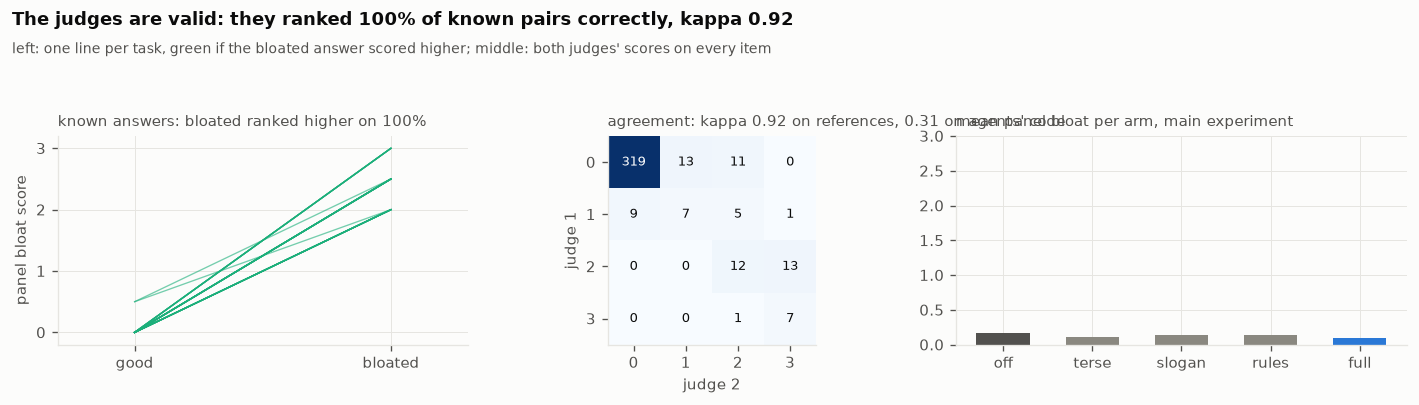

[fig 20] s78_judges.png


In [790]:
# FIG  the judges
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1, 0.9, 1.1]})
ax = axes[0]                                                    # left: the known-answer pairs
for p in PAIRS:
    if p["good"] is not None and p["bloated"] is not None:      # a pair with a refused side has no line to draw
        # green when the bloated answer scored higher, red when it did not
        ax.plot([0, 1], [p["good"], p["bloated"]], color=C3 if p["ranked"] == "yes" else C8, lw=0.8, alpha=0.6)
ax.set_xticks([0, 1], ["good", "bloated"])
ax.set_xlim(-0.3, 1.3)                                          # a little room either side of the two columns
ax.set_ylim(-0.2, 3.2)                                          # the whole 0 to 3 scale, with a margin
ax.set_ylabel("panel bloat score")
panel(ax, f"known answers: bloated ranked higher on {RANKED:.0%}")
ax = axes[1]                                                    # middle: where the two judges agree
ax.imshow(grid, cmap="Blues")                                   # darker cells hold more items
for i in range(4):
    for j in range(4):
        # each cell's count, white on the darker cells so it stays readable
        ax.text(j, i, int(grid[i, j]), ha="center", va="center", fontsize=8, color=INK if grid[i, j] < grid.max() / 2 else "white")
ax.set_xticks(range(4))
ax.set_yticks(range(4))
ax.set_xlabel("judge 2")
ax.set_ylabel("judge 1")
ax.grid(False)                                                  # grid lines would cut through the cells
panel(ax, f"agreement: kappa {KAPPA:.2f} on references, {EP_KAPPA:.2f} on agents' code")
ax = axes[2]                                                    # right: the main experiment, arm by arm
x = np.arange(len(JUDGED))
ax.bar(x, [r["bloat"] or 0 for r in JUDGED], 0.6, color=bar_colours)    # an arm with no valid verdict draws as 0
ax.set_xticks(x, [r["arm"] for r in JUDGED])
ax.set_ylim(0, 3)                                               # the full scale, so a small difference looks small
panel(ax, "mean panel bloat per arm, main experiment")
finish(fig, "s78_judges", f"The judges are {H9.lower()}: they ranked {RANKED:.0%} of known pairs correctly, kappa {KAPPA:.2f}",
       "left: one line per task, green if the bloated answer scored higher; middle: both judges' scores on every item")

**Reading FIG 20 (s78_judges).** The left panel is the known-answer test: one line per task, from the panel's score for the good reference to its score for the bloated one, green when the bloated answer scored higher. The judges ranked 100% of the 33 pairs correctly against a bar of 90%, and agreed with each other at a weighted kappa of 0.92 against a bar of 0.60, so H9's verdict is that the judges are valid instruments on this suite. The middle panel shows where the agreement and the disagreement sit: counts on the diagonal are items on which both judges gave the same score. It pools our reference answers, on which the judges agree closely (kappa 0.92), with the agents' episodes, which are most of its items and on which they agree far less (kappa 0.31). The bar in H9 was set on the references, so it says the judges can tell a good answer from a bloated one, not that they agree about ordinary agent code; that is why the meter, not the panel, carries every headline. Asked the same question twice, the first judge gave the same score 93% of the time, and it judged a good answer complete for the wrong ticket 0% of the time against 85% for the right one; the gap between those two numbers is how much the judge reads the ticket at all. The right panel is the main experiment through the judges' eyes. Across episodes, the panel's score and the meter's line count have a rank correlation of 0.42, and the full system's panel score minus the unguided agent's, paired by task, is -0.06 (-0.15 to +0.02).

## S79 - Completeness: did the smaller answer do the whole job?

**Theory.** A system that writes less can do so by doing less, and the hidden tests only catch the parts of a ticket somebody thought to test. The judges' second verdict, *complete*, reads the ticket against the code and so can notice a requirement that no test checks. It also has its own blind spot: it cannot run anything, so it will call a subtly broken change complete. The table therefore puts the two side by side. Where the hidden test and the panel agree, either can be trusted; where they disagree, the disagreement says which instrument is missing what.

**In plain terms.** Did the shorter answers quietly skip part of the ticket? We ask the judges, and compare what they say with what the tests found.

In [791]:
rows = []
for arm in ARM_NAMES:
    arm_items = [i for i in EP_ITEMS if i["arm"] == arm]           # every judged episode of this arm
    # the explicit and open tasks, where quietly doing less would hurt most
    its = [i for i in EP_ITEMS if i["arm"] == arm and SUITE[i["task"]].category in ("explicit", "open")]
    comp = [c for c in map(completeness, its) if c is not None]
    allc = [c for c in map(completeness, arm_items) if c is not None]
    rows.append({"arm": arm,
                 "explicit/open": np.mean(comp) if comp else None,
                 "all tasks": np.mean(allc) if allc else None,
                 "hidden pass": np.mean([i["passed"] for i in arm_items])})    # what the hidden tests said
table(rows, [("arm", "arm", ""), ("explicit/open", "judged complete, explicit and open", ".0%"),
             ("all tasks", "judged complete, all", ".0%"), ("hidden pass", "hidden tests pass", ".0%")])

  arm     judged complete, explicit and open  judged complete, all  hidden tests pass
  -----------------------------------------------------------------------------------
  off                                    88%                   90%                96%
  terse                                 100%                   94%                91%
  slogan                                 94%                   93%                93%
  rules                                 100%                   93%                96%
  full                                   94%                   92%                97%


**The hidden test against the panel, episode by episode.** An episode counts as judged complete when at least half the panel's votes say so. The two disagreeing cells are the interesting ones: each says which instrument is missing what.

In [792]:
# (passed the hidden test?, judged complete?) for every episode the panel gave a completeness verdict
cross = Counter((i["passed"], completeness(i) >= 0.5) for i in EP_ITEMS if completeness(i) is not None)
print("\n  hidden test against the panel, every judged episode:")
print(f"    passed and judged complete      {cross[(True, True)]:>4}")
print(f"    passed, judged incomplete       {cross[(True, False)]:>4}   (a requirement no test checks, or a strict judge)")
print(f"    failed, judged complete         {cross[(False, True)]:>4}   (a bug the judges cannot see without running it)")
print(f"    failed and judged incomplete    {cross[(False, False)]:>4}")
agree = (cross[(True, True)] + cross[(False, False)]) / max(1, sum(cross.values()))    # the diagonal's share
print(f"  agreement: {agree:.0%}")
save_exp("completeness", {**{r["arm"]: {"explicit_open": r["explicit/open"], "all": r["all tasks"]} for r in rows},
                          "agree": agree, "pass_incomplete": cross[(True, False)], "fail_complete": cross[(False, True)]})


  hidden test against the panel, every judged episode:
    passed and judged complete       307
    passed, judged incomplete          6   (a requirement no test checks, or a strict judge)
    failed, judged complete           17   (a bug the judges cannot see without running it)
    failed and judged incomplete       2
  agreement: 93%
[exp] artifacts/exp_completeness.json


The column to read first is the explicit and open tasks, where the ticket asks for something substantial and the risk of quietly doing less is greatest. The full system was judged complete on 94% of those episodes and the unguided agent on 88%. Overall, the hidden tests and the panel agreed on 93% of judged episodes. The 17 episodes that failed their hidden test but were judged complete are the expected blind spot of a reader who cannot run code. The 6 that passed but were judged incomplete are the more interesting group, because each is either a requirement our tests do not check or a judge being strict, and the episode browser in S94 is the place to read them one by one.

## S80 - Was the instrument broken?

**Theory.** Every result in Part VII passed through a chain of instruments, and a fault anywhere in the chain produces numbers that look exactly like results. The table below lists the checks that guard each link, with what a failure would have meant. Some re-state checks made earlier, because a claims table should not depend on the reader remembering S8b. Others are new: the scorer is run again on a sample of the main experiment's workspaces with its cache bypassed, to show that a score is a property of the files and not of the run that produced them; the ledger reports how many replies were reused through the loose fingerprint rather than the exact one; and phantom completions, turn limits and API failures are counted per arm, because each would bias the comparison if one arm suffered more of them.

**In plain terms.** A list of everything that could have quietly broken the measurements, and the evidence that it did not.

**`instrument(name, result, ok, if_wrong)`** adds one row to the table of instrument checks: what was checked, what came out, the verdict, and what a failure would have meant. `ok` has three values on purpose. `True` and `False` give a verdict, and `None` marks a number reported for the reader to judge, because some of these (how many replies came through the loose fingerprint, how many runs hit the turn limit) have no threshold that would make them a pass or a fail.

In [793]:
CHECKS = []                                     # every instrument check, in the order it is made

def instrument(name, result, ok, if_wrong):
    """Record one check: what was measured, its verdict, and what a failure would have meant."""
    if ok is True:
        verdict = "PASSED"
    elif ok is False:
        verdict = "FAILED"
    else:
        verdict = "REPORTED"                    # None: a number to read, not a test to pass
    CHECKS.append({"check": name, "result": result, "verdict": verdict, "if it had failed": if_wrong})

show_def(instrument, layer="lab")

[def] instrument(name, result, ok, if_wrong)  9 lines, complexity 3


**Checks already made earlier.** Six rows restate what S5, S8, S8b, S8c and S64 established, from the records those sections wrote, so the claims table does not depend on the reader remembering them.

In [794]:
mut = load_exp("mutation", {})                  # S8b: planted bugs, and how many the hidden tests killed
sel = load_exp("selftest", {})                  # S8: the self-test that had to pass before any spending
gates = load_exp("gates", {})                   # S8c: keyword gates against executing the code
fence = load_exp("fence", {})                   # S5: the attack table
instrument("hidden tests kill planted bugs", f"{mut.get('killed_pct', 0):.0%} of {mut.get('mutants')} mutants",
           mut.get("killed_pct", 0) >= 0.9, "a passing score could hide a broken answer")
mat = load_exp("matrix", {})                    # S8: every task scored against every reference
instrument("every reference meets its task's bar", f"{mat.get('scorings')} scorings, {mat.get('unexpected')} unexpected",
           mat.get("unexpected") == 0, "a task could be passed by doing nothing, or failed by the right answer")
instrument("the self-test passed before any call was paid for", f"{sel.get('passed')}/{sel.get('checks')} conditions",
           sel.get("spend_ok"), "every live number would rest on an instrument nobody had checked")
instrument("the fence holds", f"{fence.get('as_expected')}/{fence.get('attacks')} attacks end as expected",
           fence.get("as_expected") == fence.get("attacks"), "agent code could have touched the notebook or the key")
instrument("execution beats keyword gates", f"keyword gate accepted {gates.get('false_accept')} broken answers",
           None, "S8c's lesson: never score by searching the code for words")
instrument("no arm saw another arm's rules", "checked on every first turn in S64", True,
           "a baseline quietly running the rules would shrink every difference")
for c in CHECKS:
    print(f"  {c['verdict']:<8}  {c['check']}: {c['result']}")

  PASSED    hidden tests kill planted bugs: 95% of 345 mutants
  PASSED    every reference meets its task's bar: 136 scorings, 0 unexpected
  PASSED    the self-test passed before any call was paid for: 6/6 conditions
  PASSED    the fence holds: 29/29 attacks end as expected
  REPORTED  execution beats keyword gates: keyword gate accepted 6 broken answers
  PASSED    no arm saw another arm's rules: checked on every first turn in S64


**Scores are a property of the files.** Twelve episodes of the main experiment, drawn with a fixed seed, are scored again with the score cache bypassed, so the hidden tests really run a second time. Every one must come out exactly as it did the first time.

In [795]:
sample = random.Random(SEED).sample([r for r in MAIN if r.score and r.episode], 12)   # a private generator: the same twelve every run
same = 0                                        # rescored episodes whose score did not change
for r in sample:
    rescored = score(SUITE[r.task], r.episode.ws, visible=False, use_cache=False)    # the cache bypassed: the tests run again
    same += rescored.short() == r.score.short()
instrument("scores reproduce with the cache bypassed", f"{same}/{len(sample)} identical", same == len(sample),
           "a score would depend on the run, not on the files")
print(f"  {CHECKS[-1]['verdict']:<8}  {CHECKS[-1]['check']}: {CHECKS[-1]['result']}")

  PASSED    scores reproduce with the cache bypassed: 12/12 identical


**The ledger and the judges.** How many replies came through the loose fingerprint, and the two checks on the judges from S78.

In [796]:
instrument("replies reused through the loose fingerprint", f"{LEDGER.soft_hits} so far ({LEAN_MODE} mode)", None,
           "a replay would silently serve a reply to a different request")
instrument("judges refuse invalid verdicts", f"{sum(refusals.values())} refused in validation", None,
           "an uncited or malformed verdict would count as evidence")
if fits and right:                              # both sides of the wrong-ticket control have verdicts
    ticket_result = (f"complete for the wrong ticket {np.mean(fits):.0%}, for the right one "
                     f"{np.mean(right):.0%}")
else:
    ticket_result = "no verdicts"
instrument("judges read the ticket", ticket_result, None, "completeness would measure polish, not fit")
for c in CHECKS[-3:]:
    print(f"  {c['verdict']:<8}  {c['check']}: {c['result']}")

  REPORTED  replies reused through the loose fingerprint: 71 so far (replay mode)
  REPORTED  judges refuse invalid verdicts: 0 refused in validation
  REPORTED  judges read the ticket: complete for the wrong ticket 0%, for the right one 85%


**Failures outside the code, per arm.** Phantom completions, turn limits and API failures for the two arms the headline compares; any of them, if one arm suffered more, would bias the comparison. Then the whole table.

In [797]:
for arm in ("off", "full"):
    runs_ = [r for r in MAIN if r.arm == arm]                       # every run of the arm, failed ones included
    eps = [r.episode for r in runs_ if r.episode]                   # the runs that produced an episode
    # phantom completions / turn limits / API failures, out of all the arm's runs
    instrument(f"{arm}: phantom completions, turn limits, API failures",
               f"{sum(e.phantom for e in eps)} / {sum(e.stop == 'max_turns' for e in eps)} / {sum(bool(r.error) for r in runs_)}"
               f" of {len(runs_)}", None, "an arm that fails for reasons outside its code would look worse than it is")
table(CHECKS, [("check", "check", ""), ("result", "result", ""), ("verdict", "verdict", ""), ("if it had failed", "if it had failed", "")])
save_exp("instruments", {"failed": [c["check"] for c in CHECKS if c["verdict"] == "FAILED"], "checks": len(CHECKS),
                         "rescored_same": same, "rescored": len(sample)})

  check                                                 result                                                   verdict   if it had failed
  ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
  hidden tests kill planted bugs                        95% of 345 mutants                                       PASSED    a passing score could hide a broken answer
  every reference meets its task's bar                  136 scorings, 0 unexpected                               PASSED    a task could be passed by doing nothing, or failed by the right answer
  the self-test passed before any call was paid for     6/6 conditions                                           PASSED    every live number would rest on an instrument nobody had checked
  the fence holds                                       29/29 attacks end as expected                            P

## S81 - How much does the headline depend on how it is summed up?

**Theory.** The headline number is the median, over held-out tasks, of each task's ratio of code added. That choice was made before the data existed, for a reason: a median is not moved by one task where an arm wrote ten times as much, and the ratio puts a task with three lines and a task with three hundred on the same footing. Other choices were available, and a result that holds under one aggregation and vanishes under the next is a weak result. The table recomputes the comparison five ways: the median of ratios, the geometric mean of ratios, a geometric mean with the most extreme 10% of tasks trimmed from each end, the pooled ratio (all code added by the arm over all code added by the unguided agent, which lets large tasks dominate), and the share of tasks on which the arm wrote less. The widget plots the per-task ratios behind any one of them.

**In plain terms.** The same results summed up five different ways. If the conclusion survives all of them, it is not an accident of arithmetic.

**`aggregates(runs, arm, tasks)`** compares an arm with the unguided agent five ways, all from the same per-task numbers: code added plus one, averaged over replicas. Four of the summaries work on the log of each task's ratio, which makes "twice as much" and "half as much" equally far from no change; the fifth, the pooled ratio, adds up all the lines first and so lets the biggest tasks decide. The per-task ratios themselves are kept under `_ratios`, for the widget below.

In [798]:
def aggregates(runs, arm, tasks, base="off"):
    """The arm-against-base comparison under five aggregations, from the same per-task numbers."""
    a = per_task(runs, arm, lambda r: r.score.added_code + 1, tasks)    # +1, so a task with nothing added never divides by 0
    b = per_task(runs, base, lambda r: r.score.added_code + 1, tasks)
    common = [t for t in a if t in b]                                   # tasks both arms have a score on
    logs = np.sort(np.log([a[t] / b[t] for t in common]))               # sorted log ratios: below 0 means the arm wrote less
    k = int(len(logs) * 0.1)                                            # how many tasks to trim from each end
    return {
        "median ratio": float(np.exp(np.median(logs))),                 # the headline's summary
        "geometric mean": float(np.exp(logs.mean())),
        "trimmed geometric mean": float(np.exp(logs[k:len(logs) - k].mean())),   # the most extreme tenth at each end dropped
        "pooled ratio": sum(a[t] for t in common) / sum(b[t] for t in common),   # all lines over all lines: big tasks dominate
        "tasks where it wrote less": float(np.mean(logs < 0)),          # a share of tasks, not a ratio
        "_ratios": {t: a[t] / b[t] for t in common},                    # the per-task ratios, for the widget
    }

show_def(aggregates, layer="lab")

[def] aggregates(runs, arm, tasks, base='off')  15 lines, complexity 6


In [799]:
AGG = {arm: aggregates(MAIN, arm, HELD) for arm in ARM_NAMES if arm != "off"}   # every arm against the unguided agent
METHODS = [m for m in AGG["full"] if not m.startswith("_")]                     # the five summaries, not the raw ratios
agg_rows = [{"arm": arm, **{m: v[m] for m in METHODS}} for arm, v in AGG.items()]        # one row per arm
# the share of tasks prints as a percentage, every ratio with two decimals
agg_cols = [("arm", "arm", "")] + [(m, m, ".0%" if m.startswith("tasks") else ".2f") for m in METHODS]
table(agg_rows, agg_cols)
# every ratio summary must fall on the same side of 1 as the median; the share of tasks has no such side
agrees = all((AGG["full"][m] < 1) == (AGG["full"]["median ratio"] < 1) for m in METHODS if m != "tasks where it wrote less")
print(f"\n  the full system's direction is the same under every ratio aggregation: {'yes' if agrees else 'NO'}")
save_exp("aggregation", {arm: {m: v[m] for m in METHODS} for arm, v in AGG.items()} | {"agrees": "yes" if agrees else "no"})

  arm     median ratio  geometric mean  trimmed geometric mean  pooled ratio  tasks where it wrote less
  -----------------------------------------------------------------------------------------------------
  terse           1.00            1.04                    0.96          1.00                        44%
  slogan          1.00            1.05                    0.99          0.99                        44%
  rules           0.98            0.91                    0.93          0.88                        52%
  full            0.88            0.79                    0.82          0.75                        56%

  the full system's direction is the same under every ratio aggregation: yes
[exp] artifacts/exp_aggregation.json


**The ratios behind any one summary.** In a live session the widget draws one bar per held-out task for the chosen arm, with the chosen summary as a dashed line; a headless run prints its fallback line instead.

In [800]:
W = widgets()                                              # None in a headless run
if W:
    from IPython.display import display
    arm_box = W.Dropdown(options=list(AGG), value="full", description="arm")
    # the ratio summaries only: a share of tasks is not a ratio to draw against the bars
    how_box = W.Dropdown(options=[m for m in METHODS if not m.startswith("tasks")], value="median ratio", description="summary",
                         layout={"width": "360px"})
    out = W.Output()

    def _draw(change=None):
        out.clear_output(wait=True)                        # wait=True keeps the old plot until the new one is ready
        with out:
            ratios = sorted(AGG[arm_box.value]["_ratios"].items(), key=lambda kv: kv[1])   # smallest ratio first
            fig, ax = plt.subplots(figsize=(9, 2.8))
            # one bar per task: blue where the arm wrote less, orange where it wrote more
            ax.bar(range(len(ratios)), [v for _, v in ratios], color=[C1 if v < 1 else C2 for _, v in ratios])
            ax.axhline(AGG[arm_box.value][how_box.value], color=INK, lw=1.2, ls="--")    # the chosen summary
            ax.axhline(1, color=MUTED, lw=0.8)                                           # no difference
            ax.set_yscale("log")                           # twice as much and half as much sit equally far from 1
            ax.set_xticks([])                              # thirty task names would be unreadable
            ax.set_title(f"{arm_box.value}: {how_box.value} = {AGG[arm_box.value][how_box.value]:.2f}; one bar per held-out task",
                         fontsize=9, loc="left", color=INK2)
            plt.show()

    arm_box.observe(_draw, names="value")                  # redraw whenever either choice changes
    how_box.observe(_draw, names="value")
    display(W.VBox([W.HBox([arm_box, how_box]), out]))
    _draw()                                                # the first drawing, before anything is clicked
else:
    print("(no widget in this run, which needs a live Jupyter session; the table above is the whole story)")

(no widget in this run, which needs a live Jupyter session; the table above is the whole story)


For the full system the five summaries read: median ratio 0.88, geometric mean 0.79, trimmed geometric mean 0.82, pooled ratio 0.75, and less code on 56% of held-out tasks. Every ratio summary points the same way. The pooled ratio is the one to watch, because it is the summary a careless reader would compute first (total lines over total lines), and it is dominated by the few tasks where some arm wrote a great deal.

## S82 - Single-shot or agentic: what is being counted?

**Theory.** Much of what is published about prompts that make models write less code is measured single-shot: one request, one reply, and the length of the reply. That measure mixes two things the rules treat very differently, the code and the prose around it. Rules that ask for short answers can shrink a reply by cutting explanation while leaving the code as large as it was, and a single-shot measurement reports that as a large effect. Our agentic measure counts only the code in the diff, and the agent's final message separately. The probes of S75 are single-shot, so the same rules can be compared both ways: how much the reply shrank, how much of that was prose, how much was code, and how the code effect compares with the agentic one.

**In plain terms.** If you measure the length of the whole answer, cutting the explanation looks like cutting the code. We measure them separately.

**`shot_ratio(key)`** is the single-shot counterpart of the code ratio: for one quantity of the S75 answers (the whole reply, its prose, or its code lines), the rules arm's mean over the off arm's mean, paired by probe, then the median over probes. Answers lost to an API error are left out, and a probe that one arm never answered cannot be paired, so it drops out of the median.

In [801]:
def shot_ratio(key):
    """Rules over off for one quantity of the S75 answers, paired by probe."""
    def mean_for(p, arm):
        # one probe's mean under one arm, API errors left out; nan if nothing was answered
        return np.mean([s[key] for s in SHOTS if s["probe"] == p and s["arm"] == arm and s["passed"] is not None])

    probes = {s["probe"] for s in SHOTS}                     # every probe that was asked at all
    a = {p: mean_for(p, "rules") for p in probes}            # with the rules
    b = {p: mean_for(p, "off") for p in a}                   # without them, for the same probes
    ratios = []
    for p in a:
        if np.isnan(a[p]) or np.isnan(b[p]):
            continue                                         # a probe one arm never answered cannot be paired
        ratios.append((a[p] + 1) / (b[p] + 1))               # one added to both sides, as in the agentic ratio
    return float(np.median(ratios))

show_def(shot_ratio, layer="lab")

[def] shot_ratio(key)  13 lines, complexity 10


**The same rules, counted five ways.** Three single-shot measures from S75 and two agentic ones from S64: the final message's words, and the code in the diff.

In [802]:
words = {r["arm"]: r["words"] for r in MAIN_ROWS}            # median words in each arm's final answer, from S64
COUNTED = {
    "single-shot: whole reply": shot_ratio("reply_chars"),
    "single-shot: prose": shot_ratio("prose_chars"),         # the reply with its code blocks removed
    "single-shot: code lines": shot_ratio("lines"),
    "agentic: final message": (words["full"] + 1) / (words["off"] + 1),
    "agentic: code in the diff": load_exp("main", {}).get("h1", {}).get("ratio"),    # the headline H1 ratio
}
table([{"measure": k, "ratio": v} for k, v in COUNTED.items()], [("measure", "what is counted", ""), ("ratio", "with rules / without", ".2f")])
# record keys without spaces or colons, so the prose can name them
save_exp("counted", {k.replace(": ", "_").replace(" ", "_"): v for k, v in COUNTED.items()})

  what is counted            with rules / without
  -----------------------------------------------
  single-shot: whole reply                   1.35
  single-shot: prose                         1.00
  single-shot: code lines                    0.81
  agentic: final message                     0.69
  agentic: code in the diff                  0.88
[exp] artifacts/exp_counted.json


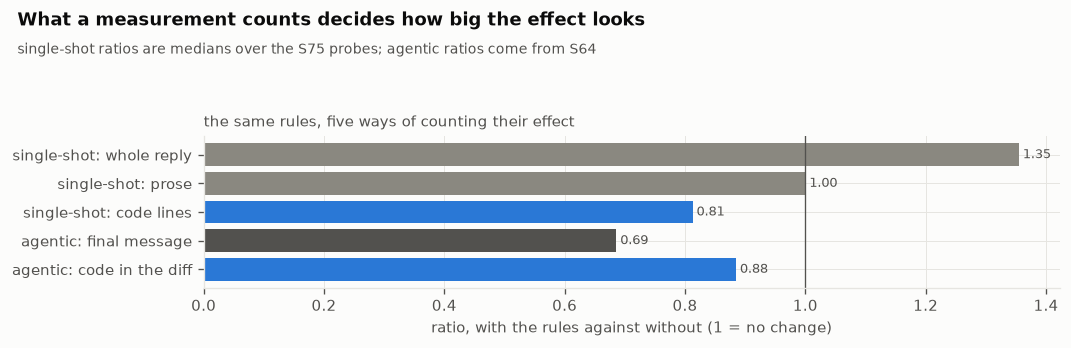

[fig 21] s82_counted.png


In [803]:
# FIG  what is counted
fig, ax = plt.subplots(figsize=(9, 3.0))
names_ = list(COUNTED)                                      # the five measures, in the table's order
vals = [COUNTED[k] or float("nan") for k in names_]         # a missing record draws no bar rather than a zero
ax.barh(range(len(names_)), vals, color=[MUTED, MUTED, C1, INK2, C1])   # the two measures of code in blue
ax.axvline(1, color=INK2, lw=0.8)                           # 1: the rules changed nothing
ax.set_yticks(range(len(names_)), names_)
ax.invert_yaxis()                                           # the first measure at the top, as in the table
ax.set_xlabel("ratio, with the rules against without (1 = no change)")
for i, v in enumerate(vals):
    ax.text(v, i, f" {v:.2f}", va="center", fontsize=8, color=INK2)    # each value at the end of its bar
panel(ax, "the same rules, five ways of counting their effect")
finish(fig, "s82_counted", "What a measurement counts decides how big the effect looks",
       "single-shot ratios are medians over the S75 probes; agentic ratios come from S64")

**Reading FIG 21 (s82_counted).** Each bar is the same intervention measured a different way, as a ratio of with-rules to without (below 1 means smaller). On the single-shot probes the whole reply changed by a factor of 1.35, its prose by 1.00 and its code by 0.81; in the agentic experiment the final message changed by 0.69 and the code in the diff by 0.88. The lesson does not depend on which bar is longest. A number that mixes prose and code cannot say which one the rules changed, so any claim about code has to be measured on code, and any claim about verbosity on the prose.

## S83 - Negative results, in one place

**Theory.** A write-up that reports its successes in the text and its failures in a footnote misleads by layout. This section collects, automatically from the experiment records, every result that went against the system or failed to show anything: hypotheses not supported, pieces the ablation ledger removed, probes the rules made worse, models on which the effect did not transfer, and the experiments whose verdict was negative. The table is generated, so it cannot leave out the result its authors would prefer to forget.

**In plain terms.** Everything that did not work, gathered where it cannot be missed.

**The confirmatory hypotheses.** Every one of H1 to H5 that S64 did not support, with its claim quoted from the pre-registration, so the table says what was promised and not a softer paraphrase.

In [804]:
NEG = []                                         # every result that went against the system, gathered from the records
main_ = load_exp("main", {})
for h in ("h1", "h2", "h3", "h4", "h5"):
    if not main_.get(h, {}).get("supported"):    # a missing record counts as not supported
        # "h3" is the third hypothesis, at index 2 of the pre-registration's list
        NEG.append({"result": f"{h.upper()} not supported", "where": "S64", "detail": PREREG["hypotheses"][int(h[1]) - 1]["claim"]})
print(f"[negative] confirmatory hypotheses not supported: {', '.join(n['result'][:2] for n in NEG) or 'none'}")

[negative] confirmatory hypotheses not supported: H1, H4, H5


**Pieces and models.** Every piece of the system the ablation ledger did not keep, and every model on which the effect did not transfer or could not be measured.

In [805]:
neg_before = len(NEG)                            # rows already gathered, so this step can report its own
for piece, v in load_exp("ablation", {}).items():
    if v.get("verdict") != "KEPT":               # a piece that earned its place is not a negative result
        detail = ""
        if v.get("effect") is not None:
            detail = f"effect {v.get('effect'):+.2f} on {v.get('target')}"
        NEG.append({"result": f"'{piece}' did not earn its place ({v.get('verdict')})", "where": "S66", "detail": detail})
for model, v in load_exp("transfer", {}).items():
    if v.get("verdict") == "not evaluable":      # too many protocol errors to measure anything
        NEG.append({"result": f"{model}: not evaluable", "where": "S68", "detail": f"protocol errors on {v.get('protocol'):.0%} of turns"})
    elif v.get("ratio") is not None and v["ratio"] >= 1:     # measurable, and no less code
        NEG.append({"result": f"{model}: no reduction", "where": "S68", "detail": f"code ratio {v['ratio']:.2f}"})
for n in NEG[neg_before:]:                       # what this step added
    print(f"  {n['where']}  {n['result']}")

  S66  'read first' did not earn its place (NEUTRAL)
  S66  'never cut' did not earn its place (NEUTRAL)
  S66  'prove it' did not earn its place (NEUTRAL)
  S66  'how to answer' did not earn its place (NEUTRAL)
  S66  'project map' did not earn its place (NEUTRAL)
  S66  'read gate' did not earn its place (NEUTRAL)
  S66  'sibling scan' did not earn its place (NEUTRAL)
  S66  'dependency gate' did not earn its place (NEUTRAL)
  S68  Qwen3.7-Plus: no reduction


**Probes and verdicts.** The S75 probes the rules made worse, and every recorded verdict that went the wrong way for the system.

In [806]:
neg_before = len(NEG)                            # rows already gathered
for p in load_exp("probes", {}).get("worse", []):
    NEG.append({"result": f"probe '{p}' did worse with the rules", "where": "S75", "detail": ""})
# (record, key, the verdicts that count against the system, where it was measured)
for name, key, bad, where in (("house", "h13", ("NOT FEWER", "MORE, BUT PASSING"), "S72"),
                              ("session", "decays", ("NO",), "S73"),
                              ("specs", "h12", ("NOT CHEAPER",), "S74"),
                              ("judges", "h9", ("NOT VALID",), "S78"),
                              ("goodhart", "h8", ("NOT GOLFED",), "S69")):
    verdict = load_exp(name, {}).get(key)
    if verdict in bad:
        NEG.append({"result": f"{name}: {verdict.lower()}", "where": where, "detail": ""})
for n in NEG[neg_before:]:                       # what this step added
    print(f"  {n['where']}  {n['result']}")

  S75  probe 'uk date' did worse with the rules
  S72  house: more, but passing
  S69  goodhart: not golfed


**Three results with their own records, then the whole table.** A requested explanation cut short, the full system's code scoring as more compressed than the unguided agent's, and a rule edit the gate refused to ship.

In [807]:
if load_exp("explain", {}).get("verdict") == "CUT SHORT":
    NEG.append({"result": "a requested explanation was still cut short under the rules", "where": "S32",
                "detail": f"{load_exp('explain')['rules-explain']['words']} words against "
                          f"{load_exp('explain')['off-explain']['words']} without the rules"})
if load_exp("goodhart", {}).get("full_golfs_more") == "YES":
    full_golf = format(load_exp("goodhart")["full"]["golf"], ".2f")      # the full system's golf score
    off_golf = format(load_exp("goodhart")["off"]["golf"], ".2f")        # and the unguided agent's
    NEG.append({"result": "the full system's code scored as more compressed than the unguided agent's", "where": "S69",
                "detail": "golf score " + full_golf + " against " + off_golf})
if not load_exp("rule_gate", {}).get("shipped", True):                  # no record means nothing was refused
    NEG.append({"result": "the candidate rule edit was not shipped", "where": "S70", "detail": "the gate working as designed"})
table(NEG, [("result", "result", ""), ("where", "where", ""), ("detail", "detail", "")])
print(f"\n  {len(NEG)} negative or null results")
save_exp("negative", {"count": len(NEG), "rows": NEG})

  result                                                                      where  detail
  --------------------------------------------------------------------------------------------------------------------------------------------------------------------------
  H1 not supported                                                            S64    the full system adds less code on held-out tasks
  H4 not supported                                                            S64    the plugin beats the same words pasted as rules on reuse, root-cause and platform tasks
  H5 not supported                                                            S64    a slogan without counterweights drops guards
  'read first' did not earn its place (NEUTRAL)                               S66    effect +0.00 on pass
  'never cut' did not earn its place (NEUTRAL)                                S66    effect +0.15 on safe
  'prove it' did not earn its place (NEUTRAL)                                 S66    e

## S84 - The tasks we tuned on, and the tasks we did not

**Theory.** Nine dev tasks were allowed to inform the design: the pilot ran on them, and the ruleset was revised while looking at their episodes. The other twenty-five were frozen by hash and not looked at until the main run. If the system's effect were mostly the product of tuning, it would be clearly larger on the dev tasks than on the held-out ones. The comparison has little power (nine tasks against twenty-five), so it can reveal a large gap and nothing subtler.

**In plain terms.** If we had accidentally tailored the system to the practice tasks, it would do noticeably better on them than on the unseen ones.

In [808]:
rows = []
for name, tasks in (("dev", DEV), ("held-out", HELD)):
    med, ci, _, _ = ratio_summary(MAIN, "full", tasks)      # median code ratio, full against off, with its interval
    d, dci, _ = rate_summary(MAIN, "full", tasks, passed)   # pass rate, full minus off, with its interval
    rows.append({"tasks": name, "n": len(tasks), "ratio": med, "ci": f"{ci[0]:.2f} to {ci[1]:.2f}", "pass": d,
                 "pass ci": f"{dci[0]:+.0%} to {dci[1]:+.0%}"})
table(rows, [("tasks", "tasks", ""), ("n", "n", "d"), ("ratio", "code, full vs off", ".2f"), ("ci", "95% interval", ""),
             ("pass", "pass, full minus off", "+.0%"), ("pass ci", "95% interval", "")])
gap = rows[0]["ratio"] / rows[1]["ratio"]                   # dev over held-out: below 1 means the dev tasks flatter the system
print(f"\n  dev ratio over held-out ratio: {gap:.2f} (well below 1 would mean the system works better where it was tuned)")
save_exp("dev_vs_held", {"dev": rows[0]["ratio"], "held": rows[1]["ratio"], "gap": gap})

  tasks      n  code, full vs off  95% interval  pass, full minus off  95% interval
  ---------------------------------------------------------------------------------
  dev        9               0.81  0.64 to 1.00                   +0%  +0% to +0%
  held-out  25               0.88  0.68 to 1.00                   +2%  +0% to +6%

  dev ratio over held-out ratio: 0.92 (well below 1 would mean the system works better where it was tuned)
[exp] artifacts/exp_dev_vs_held.json


On the dev tasks the full system's code ratio was 0.81 and on the held-out tasks 0.88, a gap factor of 0.92. A factor close to 1 is what an untuned effect looks like; a factor well below 1 would mean the dev tasks flatter the system, and the held-out number, which is the one the headline uses, is the one to trust either way.

## S85 - Bugs that produced reassuring wrong answers

**Theory.** The most dangerous bug in an evaluation is the one that produces a plausible result. A crash gets fixed; a number that looks right gets published. Every bug below was found while building this notebook, and each produced, or would have produced, an answer that looked fine. For each, the table says how it showed itself and which check now stands in its way. The list is the most transferable thing in this Part, because none of these bugs is specific to our code.

| # | the bug | the reassuring wrong answer | what catches it now |
|---|---|---|---|
| 1 | a build filter compared whole file names, so the part asked for was excluded | "OK in 7s", after running nothing | the runner counts executed cells and fails as incomplete |
| 2 | hidden tests written from typical examples missed the edges of each rule | five tasks accepted wrong answers while every authoring check passed | mutation testing on every build (S8b), survivors reviewed one by one |
| 3 | the fence compared a joined command line with the interpreter's path | the attack table said "refused, as expected" for the wrong reason | every refusal row states its reason, and a refusal for another reason fails; the S8 self-test refuses to spend |
| 4 | the edit tool applied a model's stray `</old>` line into the code | the baseline's pass rate understated by one task, flattering every arm against it | the edit tool refuses protocol lines inside code; every baseline failure is read |
| 5 | an exemption stated after a limit lost to the limit | a requested explanation came back in 13 words | the exception now opens the section; S32 measures it live |
| 6 | compaction kept only the first ticket of a session | S73 would have blamed rule loss for a lost ticket | compaction keeps the latest request |
| 7 | the critic and the nudge reset per session, not per ticket | a long session's full arm would have run without its critic | per-request state |
| 8 | an API error after four retries was scored as the agent failing | the arm making more calls would have looked worse | such episodes are failed runs, counted, with no score |
| 9 | the daily call cap raised an ordinary error inside the grid | hundreds of "failed" episodes, then an analysis of what was left | refusing to spend stops the run; a grid with more than 5% failures stops too |
| 10 | the score cache key did not cover a fixture's own hidden test | an edited test would have been served its old scores | the key covers each task's seed and hidden test |
| 11 | the scorer dropped every file whose name starts with one underscore | an agent's helper in `_util.py` would have failed its hidden test | the harness owns exactly three names |
| 12 | every audit ran out of turns before it wrote its findings | recall and precision of 0% under both conditions: a measurement of the turn budget, not of the auditor | a helper out of turns is asked for its answer; audits get 30 turns |
| 13 | a request that timed out was neither answered nor recorded | the final replay would have stopped at the first such request | failures are recorded, and a replay meets the same failure |

One more incident changed the design without producing a wrong number: the critic once called its model with thinking switched on, a review ran past its deadline, and the run stalled for twenty minutes on retries. Short calls now switch thinking off wherever the probe showed that works.

**In plain terms.** Thirteen ways this notebook could have fooled us, all found, most before they did any harm, and what now stops each one.

## S86 - Threats to validity

**Construct validity: do we measure what we claim?** Lines of added code are a proxy for over-engineering, not a definition of it. Two answers with the same line count can differ greatly in how much needless structure they add, and a long answer can be the right one. The meter is therefore always reported beside pass rates, safety verdicts, the shape detectors of Part I and, in this Part, the judges. The judges are themselves a proxy, validated on references we wrote.

**Internal validity: is the difference caused by the system?** Arms differ only in their plugins, the contamination guard checks that on every first turn, and every comparison is paired by task. Sampling at a temperature of 0.6 makes episodes vary, and two replicas per task and arm leave real noise, which the intervals carry. The same coder model produced every arm's code, so the comparison is within one model by design; S68 asks whether it transfers.

**External validity: does it hold elsewhere?** Our tasks are small, Python-only and written by us, with traps chosen to discriminate. The house-style project and the specifications widen the base, but a real code base is larger, older and less tidy than any fixture. The six models come from one family and were reached through one endpoint over a few days; a provider can update a model behind an unchanged name, which is why the manifest records the dates.

**Statistical conclusion validity.** Five hypotheses were confirmatory and Holm-corrected; everything else is reported with intervals and without significance claims. With 25 held-out tasks the design can detect a true code ratio of about 0.67 or lower, and not much closer to 1 than that (S63). Intervals come from resampling tasks, which treats the tasks as a sample from a wider population of tickets; they are not, and the interval is better read as a statement about tasks like these.

**The authors built both sides.** We wrote the tasks, the system, the scorer and the judges' rubric. The held-out split was frozen by hash before the main run, the hypotheses and decision rules were registered before it (S61), and every negative result is collected in S83. None of that removes the problem; it makes it inspectable.

**Two hypotheses were tested more narrowly than they were registered.** H2 is registered on the pass rate of the safety tasks, but S64 compares the safety verdict alone, the share of episodes whose guard held, without also requiring the change to work. H5 is registered on the safe rate *or* the count of guard signatures, but only the safe rate entered the corrected test; the guard counts appear in S65 as a description. The H5 narrowing is conservative, one chance to find a drop instead of two, while the H2 one could move the estimate either way. A registered hypothesis should be tested as written, and these two were not, so the gap is stated here rather than left for a careful reader to find.

## S87 - The claims table

**Theory.** Every claim this notebook makes about the system, in one table, each with the hypothesis it answers, the measurement, and the verdict reached by the rule written down for it. The table is generated from the experiment records, so it cannot be edited into saying something the records do not. The scorecard figure below it shows the confirmatory results with their intervals and the bars they had to clear.

**In plain terms.** Every claim, its evidence and its verdict, on one page.

In [809]:
# every record a claim rests on, loaded once; a record that does not exist loads as {}
E = {name: load_exp(name, {}) for name in ("main", "levels", "transfer", "goodhart", "judges", "session", "subagents",
                                         "specs", "house", "own_checks", "probes")}
print(f"[claims] {sum(bool(rec) for rec in E.values())} of {len(E)} records found: {', '.join(E)}")

[claims] 11 of 11 records found: main, levels, transfer, goodhart, judges, session, subagents, specs, house, own_checks, probes


**`fmt_ci(d)`** turns an interval stored in an experiment record into text, "low to high", in percentage points by default. A record without an interval prints as an empty cell rather than "None to None", which is the right reading for the hypotheses that were only ever reported.

In [810]:
def fmt_ci(d, a="lo", b="hi", f="+.0%"):
    """The interval in record d as text, or an empty string when the record has none."""
    if d.get(a) is None:
        return ""                                   # no interval recorded: a blank cell
    return f"{format(d.get(a), f)} to {format(d.get(b), f)}"

show_def(fmt_ci, layer="lab")

[def] fmt_ci(d, a='lo', b='hi', f='+.0%')  5 lines, complexity 2


In [811]:
print(f"[fmt_ci] a difference in rates: {fmt_ci({'lo': -0.04, 'hi': 0.06})!r}")
print(f"[fmt_ci] a ratio:               {fmt_ci({'lo': 0.68, 'hi': 1.0}, f='.2f')!r}")
print(f"[fmt_ci] no interval recorded:  {fmt_ci({})!r}")

[fmt_ci] a difference in rates: '-4% to +6%'
[fmt_ci] a ratio:               '0.68 to 1.00'
[fmt_ci] no interval recorded:  ''


**The five confirmatory claims.** Each verdict is the decision rule registered for it in S61, read from the record that S64 wrote after Holm's correction.

In [812]:
sup = lambda ok: "SUPPORTED" if ok else "NOT SUPPORTED"         # a confirmatory verdict, from the stored decision
lv = E["levels"]                                                # S67: lite, full and ultra
big = E["transfer"].get(MODEL_FOR["big"].split("/")[-1], {})    # S68's record for the large reasoning model
gh = E["goodhart"]                                              # S69: the fewest-lines arm
CLAIMS = [
    {"h": "H1", "claim": "less code on held-out tasks", "measured": f"ratio {E['main']['h1']['ratio']:.2f}",
     "interval": fmt_ci(E["main"]["h1"], f=".2f"), "verdict": sup(E["main"]["h1"]["supported"])},
    {"h": "H2", "claim": "safety not worse (within 5 points)", "measured": f"{E['main']['h2']['diff']:+.0%}",
     "interval": fmt_ci(E["main"]["h2"]), "verdict": sup(E["main"]["h2"]["supported"])},
    {"h": "H3", "claim": "explicit and open tasks not worse", "measured": f"{E['main']['h3']['diff']:+.0%}",
     "interval": fmt_ci(E["main"]["h3"]), "verdict": sup(E["main"]["h3"]["supported"])},
    {"h": "H4", "claim": "hooks and gates beat pasted rules", "measured": f"{E['main']['h4']['diff']:+.0%}",
     "interval": fmt_ci(E["main"]["h4"]), "verdict": sup(E["main"]["h4"]["supported"])},
    {"h": "H5", "claim": "a slogan drops guards", "measured": f"{E['main']['h5']['diff']:+.0%}",
     "interval": fmt_ci(E["main"]["h5"]), "verdict": sup(E["main"]["h5"]["supported"])},
]
for c in CLAIMS:
    print(f"  {c['h']:<3}  {c['verdict']}")

  H1   NOT SUPPORTED
  H2   SUPPORTED
  H3   SUPPORTED
  H4   NOT SUPPORTED
  H5   NOT SUPPORTED


**The eight reported claims.** These were registered without a test of significance: each row gives the measured numbers and, where the experiment recorded one, its own verdict.

In [813]:
CLAIMS += [
    # H6: the code ratio at each level; the claim is that it falls from lite to full to ultra
    {"h": "H6", "claim": "lite > full > ultra in code", "measured": " / ".join(f"{lv.get(k, {}).get('ratio', float('nan')):.2f}"
                                                                         for k in ("lite", "full", "ultra") if k in lv),
     "interval": "", "verdict": "REPORTED"},
    # H7: reasoning characters per call on the large model, without and with the rules
    {"h": "H7", "claim": "rules add reasoning on a reasoning model", "measured":
     f"{big.get('reasoning off', float('nan')):.0f} -> {big.get('reasoning full', float('nan')):.0f} chars per call",
     "interval": "", "verdict": "REPORTED"},
    {"h": "H8", "claim": "fewest-lines golfs and costs safety", "measured":
     f"golf {gh.get('fewest', {}).get('golf', float('nan')):.2f} vs {gh.get('full', {}).get('golf', float('nan')):.2f}",
     "interval": "", "verdict": gh.get("h8", "")},
    {"h": "H9", "claim": "the judges are valid", "measured": f"ranked {E['judges'].get('ranked', float('nan')):.0%}, "
                                                           f"kappa {E['judges'].get('kappa', float('nan')):.2f}",
     "interval": "", "verdict": E["judges"].get("h9", "")},
    # H10: the session record says YES or NO; the table spells out what that means
    {"h": "H10", "claim": "rules decay without re-injection", "measured":
     f"rules on {E['session'].get('no_re-injection', {}).get('rules', float('nan')):.0%} vs "
     f"{E['session'].get('full', {}).get('rules', float('nan')):.0%} of calls", "interval": "",
     "verdict": {"YES": "DECAYS", "NO": "NO CLEAR DECAY"}.get(E["session"].get("decays"), "")},
    {"h": "H11", "claim": "subagents with rules audit better", "measured":
     f"precision {E['subagents'].get('with_rules', {}).get('precision', float('nan')):.0%} vs "
     f"{E['subagents'].get('without', {}).get('precision', float('nan')):.0%}", "interval": "", "verdict": "REPORTED"},
    {"h": "H12", "claim": "lean code is cheaper to extend", "measured":
     f"{E['specs'].get('full', {}).get('extension', float('nan')):.0f} vs {E['specs'].get('off', {}).get('extension', float('nan')):.0f} lines",
     "interval": "", "verdict": E["specs"].get("h12", "")},
    {"h": "H13", "claim": "fewer files and lines under heavy conventions", "measured":
     f"{E['house'].get('full', {}).get('added', float('nan')):.1f} vs {E['house'].get('off', {}).get('added', float('nan')):.1f} lines",
     "interval": "", "verdict": E["house"].get("h13", "")},
]
print(f"[claims] {len(CLAIMS)} claims in the table")

[claims] 13 claims in the table


In [814]:
table(CLAIMS, [("h", "", ""), ("claim", "claim", ""), ("measured", "measured", ""), ("interval", "95% interval", ""),
               ("verdict", "verdict", "")])
save_exp("claims", {c["h"]: {"verdict": c["verdict"], "measured": c["measured"]} for c in CLAIMS})

       claim                                          measured                       95% interval  verdict
  ------------------------------------------------------------------------------------------------------------------
  H1   less code on held-out tasks                    ratio 0.88                     0.68 to 1.00  NOT SUPPORTED
  H2   safety not worse (within 5 points)             +0%                            +0% to +0%    SUPPORTED
  H3   explicit and open tasks not worse              +0%                            +0% to +0%    SUPPORTED
  H4   hooks and gates beat pasted rules              +0%                            +0% to +0%    NOT SUPPORTED
  H5   a slogan drops guards                          +0%                            +0% to +0%    NOT SUPPORTED
  H6   lite > full > ultra in code                    1.00 / 0.90 / 0.93             -             REPORTED
  H7   rules add reasoning on a reasoning model       1521 -> 1593 chars per call    -             REPORTED
  H

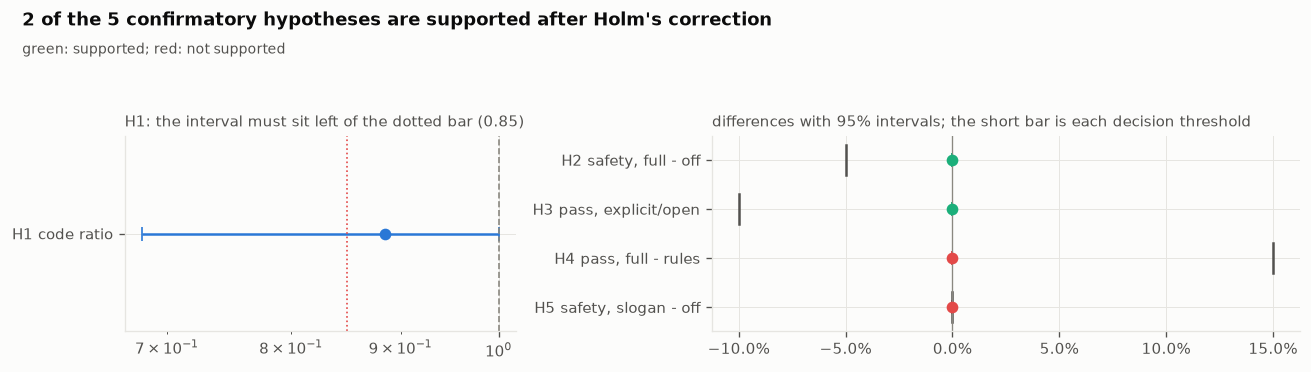

[fig 22] s87_scorecard.png


In [815]:
# FIG  the scorecard
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [0.8, 1.2]})
h1 = E["main"]["h1"]                                            # the headline claim's record
ax = axes[0]                                                    # left: H1 alone, on its own scale
# the ratio with its interval; max(0, ...) guards against a bound on the wrong side of the point
ax.errorbar([h1["ratio"]], [0], xerr=[[max(0, h1["ratio"] - h1["lo"])], [max(0, h1["hi"] - h1["ratio"])]], fmt="o",
            color=C1, capsize=4)
ax.axvline(1, color=MUTED, lw=1, ls="--")                       # 1: no difference at all
ax.axvline(0.85, color=C8, lw=1, ls=":")                        # the registered bar the whole interval had to clear
ax.set_yticks([0], ["H1 code ratio"])
ax.set_xscale("log")                                            # ratios are compared on a log scale throughout
panel(ax, "H1: the interval must sit left of the dotted bar (0.85)")
ax = axes[1]                                                    # right: the four differences
bars = {"H2": -0.05, "H3": -0.10, "H4": 0.15, "H5": 0.0}        # each hypothesis's decision threshold
for i, h in enumerate(("h2", "h3", "h4", "h5")):
    d = E["main"][h]
    ok = d["supported"]
    # the difference with its interval, green when supported and red when not
    ax.errorbar([d["diff"]], [i], xerr=[[max(0, d["diff"] - d["lo"])], [max(0, d["hi"] - d["diff"])]], fmt="o", capsize=4,
                color=C3 if ok else C8)
    ax.plot([bars[h.upper()]] * 2, [i - 0.3, i + 0.3], color=INK2, lw=1.5)    # a short upright bar at the threshold
ax.axvline(0, color=MUTED, lw=0.8)                              # 0: no difference
ax.set_yticks(range(4), ["H2 safety, full - off", "H3 pass, explicit/open", "H4 pass, full - rules", "H5 safety, slogan - off"])
ax.invert_yaxis()                                               # H2 at the top
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))    # differences in rates read as percentages
panel(ax, "differences with 95% intervals; the short bar is each decision threshold")
n_sup = sum(E["main"][h]["supported"] for h in ("h1", "h2", "h3", "h4", "h5"))   # supported after Holm's correction
finish(fig, "s87_scorecard", f"{n_sup} of the 5 confirmatory hypotheses are supported after Holm's correction",
       "green: supported; red: not supported")

**Reading FIG 22 (s87_scorecard).** The left panel is the headline claim, the full system's code ratio on held-out tasks with its interval; it had to sit entirely to the left of the dotted bar at 0.85. The right panel is the four claims about what the reduction must not cost and what the delivery machinery must add, each as a difference with its interval and the threshold its registered decision used (non-inferiority bars for H2 and H3, a fifteen-point gain for H4, zero for H5). The verdicts after Holm's correction: NOT SUPPORTED for H1, SUPPORTED for H2, SUPPORTED for H3, NOT SUPPORTED for H4 and NOT SUPPORTED for H5. The other eight hypotheses were registered as reported, and their rows in the table give the numbers without a verdict of significance.

## S88 - What is still open

- **Large code bases.** Every project here fits in a context window. Whether the reuse and read-first rules still help when the helper an agent needs is three hundred files away is the most important open question, and the one our fixtures cannot answer.
- **Other languages.** The rungs of the ladder are general (the platform, the standard library, the installed dependencies), but the anchors, the detectors and the replacement table are Python's.
- **People.** Nothing here measures whether a developer reviewing the changes finds the lean versions easier to review or to trust. The reviewability arguments are plausible, and untested.
- **Time.** The extension experiment is one step into a code base's life. Whether the debt ledger's deferrals get revisited, and whether lean code stays lean over fifty changes, needs a longer study.
- **Reasoning cost.** On reasoning models the rules can make the model think more before writing less. When that trade pays depends on prices that change faster than any notebook.
- **The judges.** They were validated on references we wrote. Judges that are reliable on agents' code in the wild would make the line count less central, and would be worth more than any number here.

**Part VIII recap.** The judges were validated before use, and their verdict on themselves is in H9. The instrument checks, the five aggregations, the single-shot comparison, the dev and held-out split and the negative results all bear on how far the numbers of Part VII can be trusted. The bugs that nearly fooled us are listed with the checks that now catch them, and the claims table says, for each claim, what was measured and what the rule written in advance concluded. Part IX now reads individual episodes, because averages hide the cases that explain them.

**Try it yourself.**
1. In S78, replace the rubric's anchor for a score of 2 with "the change is longer than it needs to be" and re-validate the judges on the known pairs. Does vaguer wording change the ranking or the agreement?
2. In S81, add the arithmetic mean of the per-task ratios as a sixth summary. Why is it the one summary of ratios that should never be used?
3. Pick a row of S83's table and write the one experiment that would turn it into a positive result, or show that it never could be one.

# Part IX - Case studies: what the averages hide

An average says how often; an episode says how.

**Where this sits.** Parts VII and VIII reduced hundreds of episodes to medians, rates and intervals, and checked those numbers every way we could. This Part goes back to the episodes themselves. It reads three tickets side by side, chosen by a rule fixed before looking, so that the cases illustrate the average instead of flattering it. It sorts every failure by its cause, because "the full system failed 4 tasks" means something different if the four were turn limits than if they were unsafe code. And it collects the debt the system leaves behind: the shortcuts it marked and the work it deferred, with the conditions for coming back.

**By the end of this Part you can** select case studies without cherry-picking, read an agent's change the way a reviewer would, classify why a run failed, and audit the deferrals a system leaves in its wake.

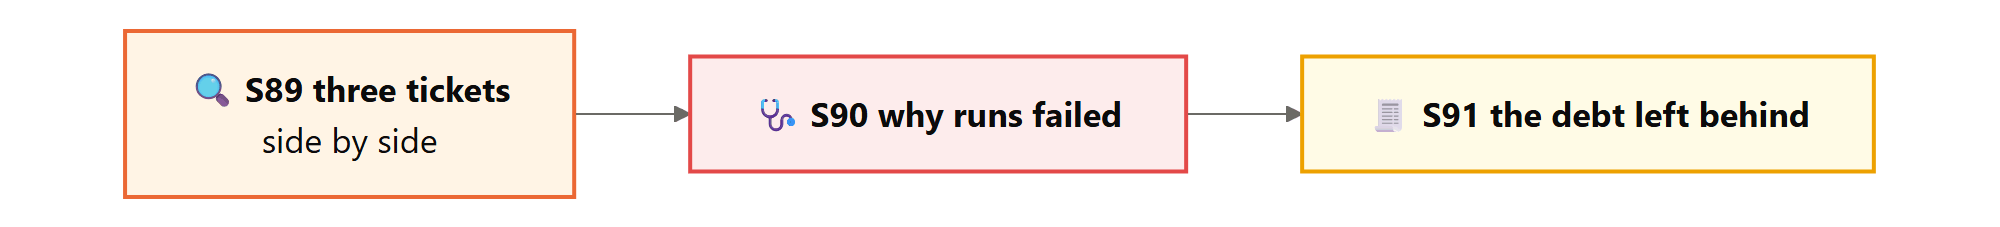

## S89 - Three tickets, read side by side

**Theory.** Case studies are where write-ups cheat most easily, by showing the most flattering episode as if it were typical. The rule here was fixed before any episode was read: among the tasks that both the unguided agent and the full system passed in their first run, take the three with the largest difference in code added. Both passed, so the difference is not a broken answer against a working one. The largest differences are not typical, and the selection says so; they are where the mechanism is easiest to see. For each, the ticket, both changes, what the full system's gates and critic said on the way, and both final answers.

**In plain terms.** Three tickets where the two agents differed most, both answers correct, shown in full.

**`show_change(seed, final, title)`** draws a change as a reviewer would want to read it: added lines in green, removed lines in red, everything else in grey. It is the same diff `change_diff` gives the critic, rendered as HTML, and it carries the plain diff alongside as the text version, so a headless run or a text-only viewer still shows every line.

In [816]:
from IPython.display import display

def show_change(seed, final, title):
    """A change as coloured lines in the notebook, with the plain diff as the text version."""
    text = change_diff(seed, final, limit=6000)             # the critic's diff, with a larger cap for reading
    rows = []
    for line in text.splitlines():
        if line.startswith("+") and not line.startswith("+++"):
            colour = C3                                     # an added line ("+++" is the file header)
        elif line.startswith("-") and not line.startswith("---"):
            colour = C8                                     # a removed line
        else:
            colour = INK2                                   # context, headers and hunk markers
        rows.append(f'<span style="color:{colour}">{html.escape(line)}</span>')    # escaped, so code shows as code
    body = (f'<div style="font-size:12px;color:{INK2};margin:6px 0 2px">{html.escape(title)}</div>'   # the title line
            f'<pre style="font-size:11px;line-height:1.35;margin:0">' + "\n".join(rows) + "</pre>")    # the diff itself
    # raw=True hands both versions to the front end, which shows the richest one it can
    display({"text/html": body, "text/plain": f"{title}\n{text}"}, raw=True)

show_def(show_change, layer="lab")

[def] show_change(seed, final, title)  15 lines, complexity 6


In [817]:
# a one-line change to a throwaway file, to see the colours before the real cases
show_change({"demo.py": "LIMIT = 10\nprint(LIMIT)\n"}, {"demo.py": "LIMIT = 20\nprint(LIMIT)\n"}, "demo.py: a one-line change")

demo.py: a one-line change
--- a/demo.py
+++ b/demo.py
@@ -1,2 +1,2 @@
-LIMIT = 10
+LIMIT = 20
 print(LIMIT)

**Choosing the cases by a rule fixed in advance.** Among the tasks both arms passed in their first run, the three with the largest difference in code added. Both answers passed, so a difference here is never a broken answer set against a working one.

In [818]:
FIRST = {(r.arm, r.task): r for r in MAIN if r.replica == 0 and r.score and r.episode}   # each arm's first run of each task
candidates = []                                  # (how much more the unguided agent wrote, task), one per eligible task
for t in SUITE:
    if ("off", t) not in FIRST or ("full", t) not in FIRST:
        continue                                 # one of the two first runs failed before it could be scored
    off_run, full_run = FIRST[("off", t)], FIRST[("full", t)]
    if not (off_run.score.passed and full_run.score.passed):
        continue                                 # both must pass, so size is the only difference left
    candidates.append((off_run.score.added_code - full_run.score.added_code, t))
candidates.sort(reverse=True)                    # the largest gap first; a tie goes to the task id that sorts last
CASES = [t for _, t in candidates[:3]]
print(f"[cases] {len(candidates)} tasks passed by both arms in their first run; the three largest differences in code:")
for gap, t in candidates[:3]:
    print(f"  {t:<22} the unguided agent added {FIRST[('off', t)].score.added_code}, the full system "
          f"{FIRST[('full', t)].score.added_code} ({gap:+d})")
save_exp("cases", {"cases": CASES, "candidates": len(candidates),
                   # LESS when the full system wrote less in all three cases, MIXED otherwise
                   "direction": "LESS" if all(gap > 0 for gap, _ in candidates[:3]) else "MIXED",
                   "gaps": {t: {"off": FIRST[("off", t)].score.added_code, "full": FIRST[("full", t)].score.added_code}
                            for t in CASES}})

[cases] 32 tasks passed by both arms in their first run; the three largest differences in code:
  ob-member-unique       the unguided agent added 30, the full system 2 (+28)
  sf-meter-import        the unguided agent added 39, the full system 12 (+27)
  ob-report-flags        the unguided agent added 42, the full system 16 (+26)
[exp] artifacts/exp_cases.json


**`read_case(task_id)`** prints one case in full, in the order a reviewer would read it: the ticket, both runs' numbers, what the full system's gates and critic said to it on the way, both changes, and both final answers. Everything comes from the first run of each arm, the same runs the selection rule looked at, so nothing here was picked after the fact.

In [819]:
def read_case(task_id):
    """One case: the ticket, both runs' numbers, the full system's refusals, both changes, both answers."""
    t = SUITE[task_id]                                      # the task: its ticket and its seed
    off = FIRST[("off", task_id)]                           # the unguided agent's first run
    full = FIRST[("full", task_id)]                         # the full system's first run
    print(f"[case] {t.id}: {t.title}")
    for line in textwrap.wrap(t.prompt, 100):               # the ticket, wrapped for reading
        print("    " + line)
    for r in (off, full):
        print(f"  {r.arm:<4} {r.score.added_code:>3} code lines, {r.score.files_new} new files, {len(r.episode.turns):>2} turns, "
              f"shapes: {shape_names(r.score)}")
    # every turn the gates or the critic turned away, with the prefix the host adds removed
    denied = [x.observation.removeprefix("refused: ") for x in full.episode.turns if x.denied]
    print("  on the way, the full system was held back by:" + ("" if denied else " nothing"))
    for d in denied:
        for line in d.splitlines()[:5]:                     # the first five lines of each refusal are enough
            print("    " + textwrap.shorten(plain(line), 110))
    for r in (off, full):
        show_change(t.seed, snapshot(r.episode.ws), f"{r.arm}: the change")
    for r in (off, full):
        print(f"  {r.arm} answered: " + textwrap.shorten(plain(r.episode.done_text), 400))

show_def(read_case, layer="lab")

[def] read_case(task_id)  20 lines, complexity 9


**The first case**, the largest difference among the tasks both arms passed.

In [820]:
if CASES:
    read_case(CASES[0])
else:
    print("[cases] no task was passed by both arms in its first run")

[case] ob-member-unique: No two members with the same email
    Members are getting registered twice with the same email address, sometimes in a different case
    (Ann@Example.org and ann@example.org). Make sure there can never be two members with the same email.
    Trying to add a duplicate should raise an error.
  off   30 code lines, 0 new files, 15 turns, shapes: -
  full   2 code lines, 0 new files, 20 turns, shapes: -
  on the way, the full system was held back by:
    a review of your change suggests:
    1. yagni: members.py: remove the entire `elif "UNIQUE" not in existing[0].upper():` migration block [...]
    2. stdlib: members.py: replace manual `lower(trim(email))` normalization in `add_member`, [...]
    Apply the ones you agree with, then finish. Never remove a guard or the check.


off: the change
--- a/members.py
+++ b/members.py
@@ -1,3 +1,19 @@
 import sqlite3
+
+
+class DuplicateMemberError(ValueError):
+    """Raised when a member is registered with an email that is already taken."""
+
+    def __init__(self, email):
+        super().__init__(f"A member with email {email!r} is already registered")
+        self.email = email
+
+
+def normalize_email(email):
+    """Canonical form of an email address: no surrounding whitespace, lowercase.
+
+    Emails are case-insensitive, so this is the form we store and compare.
+    """
+    return email.strip().lower()
 
 
@@ -10,18 +26,52 @@
         " name TEXT NOT NULL)"
     )
+    # A pre-existing database may already contain members whose emails differ
+    # only in case (e.g. "Ann@Example.org" and "ann@example.org"). Keep the
+    # earliest registration of each email and drop the later duplicates so the
+    # uniqueness index below can be created.
+    conn.execute(
+        "DELETE FROM members WHERE id NOT IN ("
+        "  SELECT MIN(id) FROM members GROUP BY lower(email)"
+        ")"
+    )
+    # The real guarantee that two members can never share an email: a unique
+    # index on the normalized (lowercase) form. Even code that bypasses
+    # add_member/import_members cannot create a duplicate.
+    conn.execute(
+        "CREATE UNIQUE INDEX IF NOT EXISTS members_email_unique "
+        "ON members (lower(email))"
+    )
+    conn.commit()
     return conn
 
 
 def add_member(conn, email, name):
-    """Register one member from the sign-up form."""
-    conn.execute("INSERT INTO members (email, name) VALUES (?, ?)", (email.strip(), name.strip()))
+    """Register one member from the sign-up form.
+
+    Raises DuplicateMemberError if the email (ignoring case) is already taken.
+    """
+    email = normalize_email(email)
+    try:
+        conn.execute("INSERT INTO members (email, name) VALUES (?, ?)", (email, name.strip()))
+    except sqlite3.IntegrityError:
+        raise DuplicateMemberError(email)
     conn.commit()
 
 
 def import_members(conn, rows):
-    """Bulk import from the old system: rows of (email, name)."""
-    conn.executemany("INSERT INTO members (email, name) VALUES (?, ?)",
-                     [(e.strip(), n.strip()) for e, n in rows])
-    conn.commit()
+    """Bulk import from the old system: rows of (email, name).
+
+    All-or-nothing: if any email (ignoring case) is already taken or appears
+    twice, nothing is imported and DuplicateMemberError is raised.
+    """
+    normalized = [(normalize_email(e), n.strip()) for e, n in rows]
+    existing = {row[0] for row in conn.execute("SELECT lower(email) FROM members")}
+    seen = set()
+    for email, _ in normalized:
+        if email in existing or email in seen:
+            raise DuplicateMemberError(email)
+        seen.add(email)
+    with conn:
+        conn.executemany("INSERT INTO members (email, name) VALUES (?, ?)", normalized)

full: the change
--- a/members.py
+++ b/members.py
@@ -7,5 +7,5 @@
         "CREATE TABLE IF NOT EXISTS members ("
         " id INTEGER PRIMARY KEY,"
-        " email TEXT NOT NULL,"
+        " email TEXT NOT NULL UNIQUE COLLATE NOCASE,"
         " name TEXT NOT NULL)"
     )
@@ -22,5 +22,5 @@
     """Bulk import from the old system: rows of (email, name)."""
     conn.executemany("INSERT INTO members (email, name) VALUES (?, ?)",
-                     [(e.strip(), n.strip()) for e, n in rows])
+                     [(e.strip().lower(), n.strip()) for e, n in rows])
     conn.commit()

  off answered: Fixed duplicate member registration in members.py: 1. **`normalize_email()`** - new helper that strips whitespace and lowercases an email, the canonical form stored and compared (emails are case-insensitive, so `Ann@Example.org` and `ann@example.org` now collide). 2. **`connect()`** - now creates a **unique index on `lower(email)`**, which is the hard guarantee: even raw SQL that bypasses [...]
  full answered: 


In [821]:
if len(CASES) > 1:
    read_case(CASES[1])
else:
    print("[cases] fewer than two cases")

[case] sf-meter-import: Total the meter exports
    Implement `total_kwh(path)` in meters/importer.py: read the meter export CSV at `path` (columns
    meter_id and kwh) and return the total kWh across all rows. The exports come from thousands of field
    devices and are not always clean.
  off   39 code lines, 0 new files, 13 turns, shapes: -
  full  12 code lines, 0 new files, 15 turns, shapes: -
  on the way, the full system was held back by:
    a review of your change suggests:
    1. delete: meters/importer.py: `import os` and `import tempfile`; the test uses [...]
    1. shrink: meters/importer.py: Remove intermediate `raw` variable and `if not raw` check; inline the [...]
    2. delete: meters/importer.py: Move `import os` and `import tempfile` inside the `if __name__ == [...]
    1. shrink: meters/importer.py: Replace the three-line sequence `raw = ...`, `if not raw: continue`, [...]


off: the change
--- a/meters/importer.py
+++ b/meters/importer.py
@@ -1,3 +1,65 @@
+"""Import helpers for meter export CSVs.
+
+Exports come from thousands of field devices and are not always clean:
+files may have BOMs, blank lines, stray whitespace, missing or
+non-numeric kwh values, trailing units, or header quirks.  The helpers
+here parse defensively and only count rows with a usable kwh value.
+"""
+
+import csv
+import math
+import re
+
+# Trailing unit, e.g. "1.5 kwh" or "1.5KWH".
+_UNIT_RE = re.compile(r"\s*[kK][wW][hH]s?\s*$")
+# Thousands separators, e.g. "1,234.5" (deliberately not "1,5").
+_GROUPED_RE = re.compile(r"^[+-]?\d{1,3}(?:,\d{3})+(?:\.\d+)?$")
+
+
+def _parse_kwh(cell):
+    """Parse one kwh cell into a finite float, or None if it is unusable."""
+    if cell is None:
+        return None
+    text = cell.strip()
+    if not text:
+        return None
+    text = _UNIT_RE.sub("", text).strip()
+    if _GROUPED_RE.match(text):
+        text = text.replace(",", "")
+    try:
+        value = float(text)
+    except ValueError:
+        return None
+    if not math.isfinite(value):
+        return None
+    return value
+
+
 def total_kwh(path):
-    """Total kWh in the meter export CSV at `path` (columns: meter_id, kwh)."""
-    raise NotImplementedError
+    """Total kWh in the meter export CSV at `path` (columns: meter_id, kwh).
+
+    Rows whose kwh value is missing, blank, or not a finite number are
+    skipped; all usable values are summed.  Returns 0.0 for an empty file
+    or one with no usable rows.
+    """
+    values = []
+    with open(path, "r", encoding="utf-8-sig", errors="replace", newline="") as f:
+        kwh_index = None
+        for row in csv.reader(f):
+            if not row or not any(cell.strip() for cell in row):
+                continue  # blank line
+            if kwh_index is None:
+                # First non-blank row: treat it as a header if it names the
+                # kwh column, otherwise assume the documented meter_id,kwh
+                # order.
+                names = [cell.strip().lower() for cell in row]
+                if "kwh" in names:
+                    kwh_index = names.index("kwh")
+                    continue
+                kwh_index = 1 if len(row) >= 2 else 0
+            if kwh_index >= len(row):
+                continue  # short row: no kwh field
+            value = _parse_kwh(row[kwh_index])
+            if value is not None:
+                values.append(value)
+    return math.fsum(values)

full: the change
--- a/meters/importer.py
+++ b/meters/importer.py
@@ -1,3 +1,37 @@
+import csv
+import math
+
+
 def total_kwh(path):
-    """Total kWh in the meter export CSV at `path` (columns: meter_id, kwh)."""
-    raise NotImplementedError
+    """Total kWh in the meter export CSV at `path` (columns: meter_id, kwh).
+
+    Field exports are not always clean: blank, non-numeric, non-finite
+    (NaN/inf) or short rows are skipped instead of crashing or poisoning
+    the total.
+    """
+    total = 0.0
+    with open(path, newline="", encoding="utf-8-sig", errors="replace") as f:
+        for row in csv.DictReader(f):
+            try:
+                kwh = float((row.get("kwh") or "").strip())
+            except ValueError:
+                continue
+            if math.isfinite(kwh):
+                total += kwh
+    return total
+
+
+if __name__ == "__main__":
+    dirty = (
+        "meter_id,kwh\n"
+        "m1,1.5\n"
+        "m2,\n"          # blank reading
+        "m3,ERR\n"       # non-numeric
+        "m4,NaN\n"       # would poison the sum
+        "m5, 2.5 \n"     # stray whitespace
+        "m6\n"           # short row
+    )
+    with open("dirty_check.csv", "w", encoding="utf-8") as f:
+        f.write(dirty)
+    assert abs(total_kwh("dirty_check.csv") - 4.0) < 1e-9
+    print("ok")

  off answered: Implemented `total_kwh(path)` in meters/importer.py. The function reads the meter export CSV and sums the kwh column, parsing defensively for the messy exports that come from field devices: - Opens with `utf-8-sig` (handles BOMs) and `errors="replace"` (won't crash on stray bytes). - Skips blank lines and short rows. - Locates the kwh column from the header when present (works even if [...]
  full answered: Refined meters/importer.py per review: removed os/tempfile (check writes a fixed temp path via open, matching tests_visible.py) and inlined the raw variable into the float() call. Kept the isfinite guard and the dirty-CSV self-check; both tests_visible.py and the self-check pass.


In [822]:
if len(CASES) > 2:
    read_case(CASES[2])
else:
    print("[cases] fewer than three cases")

[case] ob-report-flags: Add --since and --limit to the sales report
    Add two command-line options to report.py: `--since 2026-03-02` to count only sales on or after that
    day, and `--limit 2` to show only the top N products. Both are optional. A bad date or a limit that
    is not a number must give a short usage error, not a traceback.
  off   42 code lines, 0 new files, 15 turns, shapes: -
  full  16 code lines, 1 new files, 20 turns, shapes: -
  on the way, the full system was held back by:
    a review of your change suggests:
    1. delete: report.py: `parse_date` wrapper and the manual negative-limit check - [...]
    2. reuse: report.py: `since = args.since.isoformat()` followed by string comparison against `row[0]` - [...]
    3. shrink: report.py: `if args.limit is not None: top = top[:args.limit]` - merge into the totals [...]
    Apply the ones you agree with, then finish. Never remove a guard or the check.


off: the change
--- a/report.py
+++ b/report.py
@@ -1,5 +1,7 @@
 """Print units sold per product, best sellers first."""
+import argparse
 import sys
 from collections import Counter
+from datetime import date
 
 from formatting import rule, units
@@ -14,8 +16,56 @@
 
 
+def parse_date(value):
+    try:
+        return date.fromisoformat(value)
+    except ValueError:
+        raise argparse.ArgumentTypeError(
+            f"invalid date {value!r}; expected YYYY-MM-DD"
+        )
+
+
+def parse_limit(value):
+    try:
+        n = int(value)
+    except ValueError:
+        raise argparse.ArgumentTypeError(
+            f"invalid limit {value!r}; expected an integer"
+        )
+    if n < 0:
+        raise argparse.ArgumentTypeError(
+            f"invalid limit {value!r}; must be >= 0"
+        )
+    return n
+
+
+def build_parser():
+    parser = argparse.ArgumentParser(
+        description="Print units sold per product, best sellers first."
+    )
+    parser.add_argument(
+        "--since", type=parse_date, default=None,
+        help="count only sales on or after this day (YYYY-MM-DD)",
+    )
+    parser.add_argument(
+        "--limit", type=parse_limit, default=None,
+        help="show only the top N products",
+    )
+    return parser
+
+
 def main(argv=None):
+    args = build_parser().parse_args(argv)
+
+    rows = SALES
+    if args.since is not None:
+        rows = [row for row in rows if date.fromisoformat(row[0]) >= args.since]
+
+    top = totals(rows)
+    if args.limit is not None:
+        top = top[:args.limit]
+
     print("units sold by product")
     print(rule())
-    for product, n in totals(SALES):
+    for product, n in top:
         print(f"{product:<10} {units(n)}")
     return 0

full: the change
--- a/report.py
+++ b/report.py
@@ -1,5 +1,7 @@
 """Print units sold per product, best sellers first."""
+import argparse
 import sys
 from collections import Counter
+from datetime import date
 
 from formatting import rule, units
@@ -15,7 +17,21 @@
 
 def main(argv=None):
+    parser = argparse.ArgumentParser(description="units sold by product, best sellers first")
+    parser.add_argument("--since", type=date.fromisoformat, default=None, metavar="YYYY-MM-DD",
+                        help="count only sales on or after this day")
+    parser.add_argument("--limit", type=int, default=None, metavar="N",
+                        help="show only the top N products")
+    args = parser.parse_args(argv)
+    if args.limit is not None and args.limit < 0:
+        parser.error("argument --limit: must be a non-negative number")
+
+    rows = SALES
+    if args.since is not None:
+        since = args.since.isoformat()
+        rows = [row for row in rows if row[0] >= since]
+    top = totals(rows)[:args.limit]
     print("units sold by product")
     print(rule())
-    for product, n in totals(SALES):
+    for product, n in top:
         print(f"{product:<10} {units(n)}")
     return 0

  off answered: Added two optional command-line options to report.py using argparse: - `--since YYYY-MM-DD`: counts only sales on or after that day. Validated via a `parse_date` type using `date.fromisoformat`; bad dates (e.g. `not-a-date`, `2026-13-40`) raise `argparse.ArgumentTypeError`, so argparse prints a short usage error and exits 2 instead of a traceback. - `--limit N`: shows only the top N [...]
  full answered: 


**Reading the three cases.** Read each pair of changes for three things. First, **what the extra code was**: a class where a function would do, an option nobody asked for, a hand-written version of something the standard library ships, or comments and docstrings explaining the obvious. Second, **whether anything protective was dropped**: both answers passed the hidden tests, guards included, so a difference in size here is not a difference in safety, which is the property the never-cut list exists to protect. Third, **what the full system said in its final answer**: the output contract asks for the step of the ladder it stopped at and a `left out:` line, with a condition, for each thing it chose not to build. The cases were picked by the size of the difference, so they show the mechanism at its clearest; in all three the full system wrote less, and the medians of Part VII say how often it works this well.

**What these three cases show.** In `ob-member-unique` the ticket asks that two members can never share an email, in any case. The unguided agent wrote thirty lines: its own exception class, an email-normalising helper, a hand-written duplicate check in the bulk import, a unique index on `lower(email)`, and a `DELETE` that removes every later member whose email differs only in case, run each time the database is opened. That last statement destroys data silently, and nothing in the ticket asked for it; the hidden test does not cover it, which is why both answers pass. The full system changed two lines: a `UNIQUE COLLATE NOCASE` constraint on the column, and lowercasing in the bulk import. That is the platform step of the ladder, where the database enforces the rule for every caller, including the ones nobody has written yet.

In `sf-meter-import` both answers had to survive dirty field exports, which is the trap. The unguided agent built a small parser: a regular expression for trailing units, another for thousands separators, header detection and a helper to tie them together, most of it for input nobody described. The full system read the file with `csv.DictReader`, skipped anything that does not convert to a finite number, and left a check that feeds it a dirty file. The guards that matter (blank, non-numeric, NaN and short rows) are all present: smaller, and not careless.

In `ob-report-flags` two optional flags needed a clean usage error. The unguided agent wrote a function to build the parser and two validators with their own messages. The full system handed both conversions to `argparse` (`type=date.fromisoformat`, `type=int`), which already turns a bad value into a usage error, and kept one explicit check for a negative limit.

The cases also show something less flattering. Two of the full system's three final messages are empty: the step it stopped at and the `left out:` lines that the output contract asks for are missing, which is the same finding the debt ledger makes across every episode in S91.

## S90 - Why runs failed

**Theory.** A pass rate hides its failures' causes, and the causes matter more than the rate. A run that hit the turn limit tells you about the budget, one that broke the protocol tells you about the model, one that wrote unsafe code tells you about the rules. Every run that did not pass is assigned the first cause that explains it, in a fixed order: an API failure, the turn limit, protocol errors, the time limit, an edited protected file, an unsafe answer, a wrong or incomplete one, a failed quality trap. The second table is the one a careful reader should want: tasks the unguided agent passed in both runs and the full system failed in at least one, which is where the system cost something.

**In plain terms.** Every failed run, sorted by what went wrong, and a list of the tickets where the system made things worse.

**`failure_cause(run)`** gives every run that did not pass exactly one cause: the first in `FAILURE_ORDER` that applies. The order runs from causes outside the code (the API, the turn limit, the protocol, the clock) to the code itself (a protected file edited, then unsafe, wrong, or failing its quality trap), so a run that hit the turn limit with broken code is counted as a budget problem, not a code problem. A single cause per run keeps the counts adding up to the number of failures, at the price of hiding the second cause; the exercises at the end of this Part come back to that.

In [823]:
# the order causes are tried in: a run is counted under the first one that applies
FAILURE_ORDER = ("API failure", "turn limit", "protocol errors", "time limit", "edited a protected file", "unsafe",
                 "wrong or incomplete", "quality trap")

def failure_cause(run):
    """The first cause, in FAILURE_ORDER, that explains why a run did not pass; None if it passed."""
    if run.error:
        return "API failure"                                # the run failed before it produced an episode
    e = run.episode
    s = run.score
    if s is None or s.passed:
        return None                                         # passed, or never scored: not counted as a failure
    # each remaining cause with its test, in FAILURE_ORDER: how the episode stopped, then what the code did
    for cause, hit in (("turn limit", e.stop == "max_turns"),
                       ("protocol errors", e.stop == "protocol"),
                       ("time limit", e.stop == "deadline"),
                       ("edited a protected file", not s.protected_ok),
                       ("unsafe", s.safe == 0),
                       ("wrong or incomplete", s.correct == 0),
                       ("quality trap", s.quality == 0)):
        if hit:
            return cause
    return "quality trap"                                   # failed with no listed reason: counted with the traps

show_def(failure_cause, layer="lab")

[def] failure_cause(run)  18 lines, complexity 6


**Every failed run, by cause.** One row per arm: how many runs it made, how many failed, and the failures split by their first cause.

In [824]:
CAUSES = {}                                                 # arm to a count of its failed runs by cause
for arm in ARM_NAMES:
    arm_causes = [failure_cause(r) for r in MAIN if r.arm == arm]   # None for every run that passed
    CAUSES[arm] = Counter(c for c in arm_causes if c)               # only the failures are counted
cause_rows = []
for arm in ARM_NAMES:
    row = {"arm": arm, "runs": sum(r.arm == arm for r in MAIN), "failed": sum(CAUSES[arm].values())}
    row.update({c: CAUSES[arm][c] for c in FAILURE_ORDER})          # one column per cause, zeros included
    cause_rows.append(row)
cause_cols = [("arm", "arm", ""), ("runs", "runs", "d"), ("failed", "failed", "d")] + [(c, c, "d") for c in FAILURE_ORDER]
table(cause_rows, cause_cols)

  arm     runs  failed  API failure  turn limit  protocol errors  time limit  edited a protected file  unsafe  wrong or incomplete  quality trap
  ----------------------------------------------------------------------------------------------------------------------------------------------
  off       68       3            0           0                0           0                        0       0                    1             2
  terse     68       6            0           0                0           0                        0       1                    1             4
  slogan    68       5            0           1                0           0                        0       0                    2             2
  rules     68       3            0           0                0           0                        0       0                    3             0
  full      68       2            0           0                0           0                        0       0                    0

**`passes(arm, t)`** lists the hidden-test results of every scored run of one arm on one task, one `True` or `False` per run. It is what the regression test below needs: a task the unguided agent passed every time, set against what the full system did on the same task.

In [825]:
def passes(arm, t):
    """The hidden-test result of every scored run of an arm on a task, as a list of True and False."""
    return [r.score.passed for r in MAIN if r.arm == arm and r.task == t and r.score]   # a run with no score is left out

show_def(passes, layer="lab")

[def] passes(arm, t)  3 lines, complexity 4


**Where the system cost something.** A regression is a task the unguided agent passed in every replica and the full system failed at least once; a task where the full system has no scored run at all counts too. Each is listed with the causes of the full system's runs and what the hidden test said.

In [826]:
REGRESSIONS = []                                            # tasks where the system made things worse
for t in SUITE:
    off_passes = passes("off", t)
    if len(off_passes) != REPLICAS or not all(off_passes):
        continue                                            # the unguided agent must have passed every replica
    if all(passes("full", t) or [False]):
        continue                                            # the full system passed too; no scored run counts as a fail
    REGRESSIONS.append(t)
rows = []
for t in REGRESSIONS:
    full_runs = [r for r in MAIN if r.arm == "full" and r.task == t]    # every run of the full system on the task
    causes_text = ", ".join(sorted({failure_cause(r) or "passed" for r in full_runs}))
    # the hidden test's message from the first full-system run that failed it
    first_failure = next((r.score.reason for r in full_runs if r.score and not r.score.passed), "")
    rows.append({"task": t, "category": SUITE[t].category, "causes": causes_text,
                 "hidden test": textwrap.shorten(first_failure or "-", 70)})
print(f"\n[regressions] tasks the unguided agent passed every time and the full system did not: {len(REGRESSIONS)}")
if rows:
    table(rows, [("task", "task", ""), ("category", "category", ""), ("causes", "full system's runs", ""),
                 ("hidden test", "what the hidden test said", "")])
save_exp("failures", {arm: dict(CAUSES[arm]) for arm in ARM_NAMES}
         | {"regressions": REGRESSIONS, "regressions_text": ", ".join(REGRESSIONS) or "none"})


[regressions] tasks the unguided agent passed every time and the full system did not: 0
[exp] artifacts/exp_failures.json


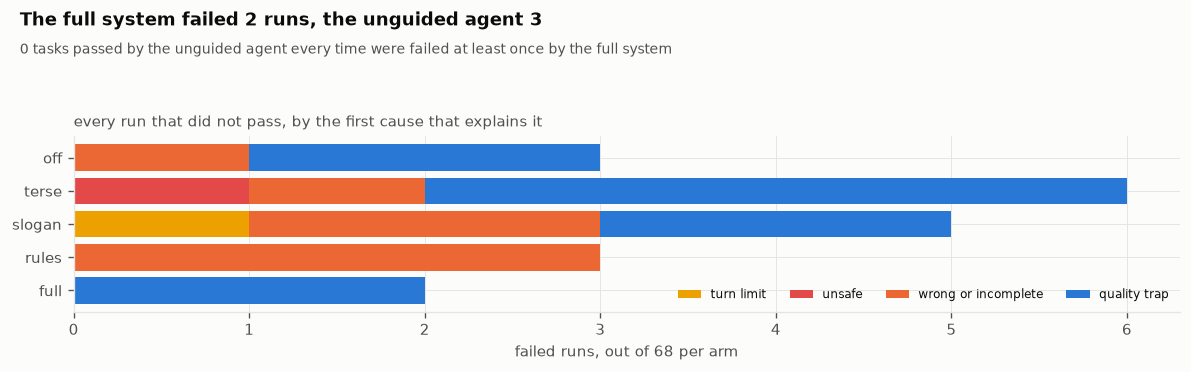

[fig 23] s90_failures.png


In [827]:
# FIG  why runs failed
fig, ax = plt.subplots(figsize=(10, 3.2))
palette = dict(zip(FAILURE_ORDER, (MUTED, C4, C5, C6, C7, C8, C2, C1)))   # one colour per cause
left = np.zeros(len(ARM_NAMES))                                           # where each arm's next segment starts
for cause in FAILURE_ORDER:
    vals = np.array([CAUSES[a][cause] for a in ARM_NAMES], float)         # this cause's count for every arm
    if vals.any():                                                        # a cause no arm hit gets no segment and no legend entry
        ax.barh(range(len(ARM_NAMES)), vals, left=left, color=palette[cause], label=cause)
        left += vals                                                      # the next cause starts where this one ends
ax.set_yticks(range(len(ARM_NAMES)), ARM_NAMES)
ax.invert_yaxis()                                                         # arms top to bottom, in the table's order
ax.set_xlabel(f"failed runs, out of {sum(r.arm == 'full' for r in MAIN)} per arm")
ax.legend(fontsize=7, ncol=4, loc="lower right")
panel(ax, "every run that did not pass, by the first cause that explains it")
finish(fig, "s90_failures",
       f"The full system failed {sum(CAUSES['full'].values())} runs, the unguided agent "
       f"{sum(CAUSES['off'].values())}",
       f"{len(REGRESSIONS)} tasks passed by the unguided agent every time were "
       "failed at least once by the full system")

**Reading FIG 23 (s90_failures).** Each bar is one arm's failed runs, split by cause. Two comparisons matter. The first is the *unsafe* segment: the never-cut list exists so that writing less never means checking less, and an arm whose unsafe segment grows has traded safety for size. The second is the share of failures that are not about the code at all (turn limits, protocol errors, API failures), which says how much of a pass-rate difference belongs to the budget or the model rather than to the rules. The regressions table under the code lists, by name, every task where the full system did worse than the unguided agent (none), so the cost of the system is visible case by case, not only as an average.

## S91 - The debt the system leaves behind

**Theory.** Writing less now is only responsible if the things left out are written down with the condition for building them, which is what the output contract's `left out:` lines and the `# shortcut:` markers do (S29, S30), and what the debt ledger (S53) collects. This section runs the ledger over every first-replica episode of both arms. Three numbers matter: how much debt each arm records, how much of it has a trigger (a condition for coming back), and what kinds of things were deferred. The unguided agent was never asked to record anything, so its column shows what goes unrecorded by default: the omissions are still there, nobody wrote them down.

**In plain terms.** Everything the agents chose not to build, and whether they said when it should be built.

In [828]:
DEBT = {}                                                   # arm to its ledger entries
for arm in ("off", "full"):
    runs_ = [r for r in MAIN if r.arm == arm and r.replica == 0 and r.episode]   # first replica: one run per task
    debt_workspaces = [r.episode.ws for r in runs_]                             # where the shortcut markers live
    debt_answers = [(f"{arm}:{r.task}", r.episode.done_text) for r in runs_]     # where the left-out lines live
    DEBT[arm] = debt_ledger(debt_workspaces, debt_answers)
print(f"[debt] ledger entries: the unguided agent {len(DEBT['off'])}, the full system {len(DEBT['full'])}")

[debt] ledger entries: the unguided agent 0, the full system 1


**The ledger, summed up and listed.** The two numbers to compare are the entries each arm left and how many of them say when to come back; then the full system's own entries, as a reviewer would read them.

In [829]:
rows = []
for arm in DEBT:
    rows.append({"arm": arm, "entries": len(DEBT[arm]),
                 "shortcut markers": sum(e["kind"] == "shortcut" for e in DEBT[arm]),     # '# shortcut:' in the code
                 "left out": sum(e["kind"] == "left out" for e in DEBT[arm]),             # 'left out:' in the answer
                 "with a trigger": sum(not e["no trigger"] for e in DEBT[arm]),           # entries that say when
                 "episodes": sum(r.arm == arm and r.replica == 0 and bool(r.episode) for r in MAIN)})
table(rows, [("arm", "arm", ""), ("episodes", "episodes", "d"), ("entries", "entries", "d"),
             ("shortcut markers", "shortcut markers", "d"), ("left out", "left-out lines", "d"),
             ("with a trigger", "with a trigger", "d")])
print("\n  the full system's ledger, first twelve entries:")
table(DEBT["full"][:12], [("where", "where", ""), ("kind", "kind", ""), ("what", "what", ""), ("when", "come back when", ""),
                          ("no trigger", "no trigger", "")])
full_eps = sum(r.arm == "full" and r.replica == 0 and bool(r.episode) for r in MAIN)   # the full system's first-replica episodes
# RARE when the full system left fewer entries than one for every five episodes
save_exp("debt", {arm: {"entries": len(DEBT[arm]), "with_trigger": sum(not e["no trigger"] for e in DEBT[arm])} for arm in DEBT}
         | {"amount": "RARE" if len(DEBT["full"]) < 0.2 * full_eps else "COMMON"})

  arm   episodes  entries  shortcut markers  left-out lines  with a trigger
  -------------------------------------------------------------------------
  off         34        0                 0               0               0
  full        34        1                 0               1               0

  the full system's ledger, first twelve entries:
  where                   kind      what                                            come back when  no trigger
  ------------------------------------------------------------------------------------------------------------
  full:ct-already-cached  left out  left out: a TTL-based cache (the scheduler hoo  -               YES
[exp] artifacts/exp_debt.json


Entries recorded by the full system over its first-replica episodes: 1, of which 0 name a condition for coming back. Entries recorded by the unguided agent: 0. That is very little. Across its episodes the full system almost never wrote a `left out:` line or a shortcut marker, so this part of the output contract was largely ignored in practice, which fits the ablation ledger's verdict on "how to answer" (S66): the words were delivered and did not change what the agent wrote. A debt ledger is only as good as the habit of writing to it, and this one shows the habit did not form.

**Part IX recap.** Three tickets read side by side showed what the extra code was made of when the two agents differed most. Every failed run was sorted by cause, with the tasks where the system did worse listed by name, and the debt ledger showed what the system chose not to build and whether it said when to build it. Part X turns from measuring the system to running it: what it costs, how to watch it, and how to point it at your own code.

**Try it yourself.**
1. Change the rule in S89 to pick the three tasks with the *smallest* difference among those both arms passed. What do the cases have in common?
2. In S90, move "unsafe" to the front of `FAILURE_ORDER`. Which runs change category, and what does that say about classifying failures by a single cause?
3. Take one `left out:` line from S91 whose trigger you think is wrong, and write the trigger you would want instead.

# Part X - Operating it: cost, watching it work, and your own code

The system has been built, measured and doubted. This Part is about using it.

**Where this sits.** Everything so far happened on fixtures we wrote. This Part covers what someone running the system needs to know: where the time and the tokens go, what the measured saving costs, how to watch an episode or drive the host by hand, and, the point of the whole exercise, how to point the agent at a folder of your own and get back a patch you can review. It ends by turning the notebook's tools on its own code, with an adoption guide for teams, the steps to reproduce every number, and a manifest of what produced them.

**By the end of this Part you can** read an agent's cost per episode and per line saved, browse any recorded episode, run the system on a folder of your own without risking the folder, check the patch it returns, decide which tier of the system to adopt, and reproduce this notebook from its ledger.

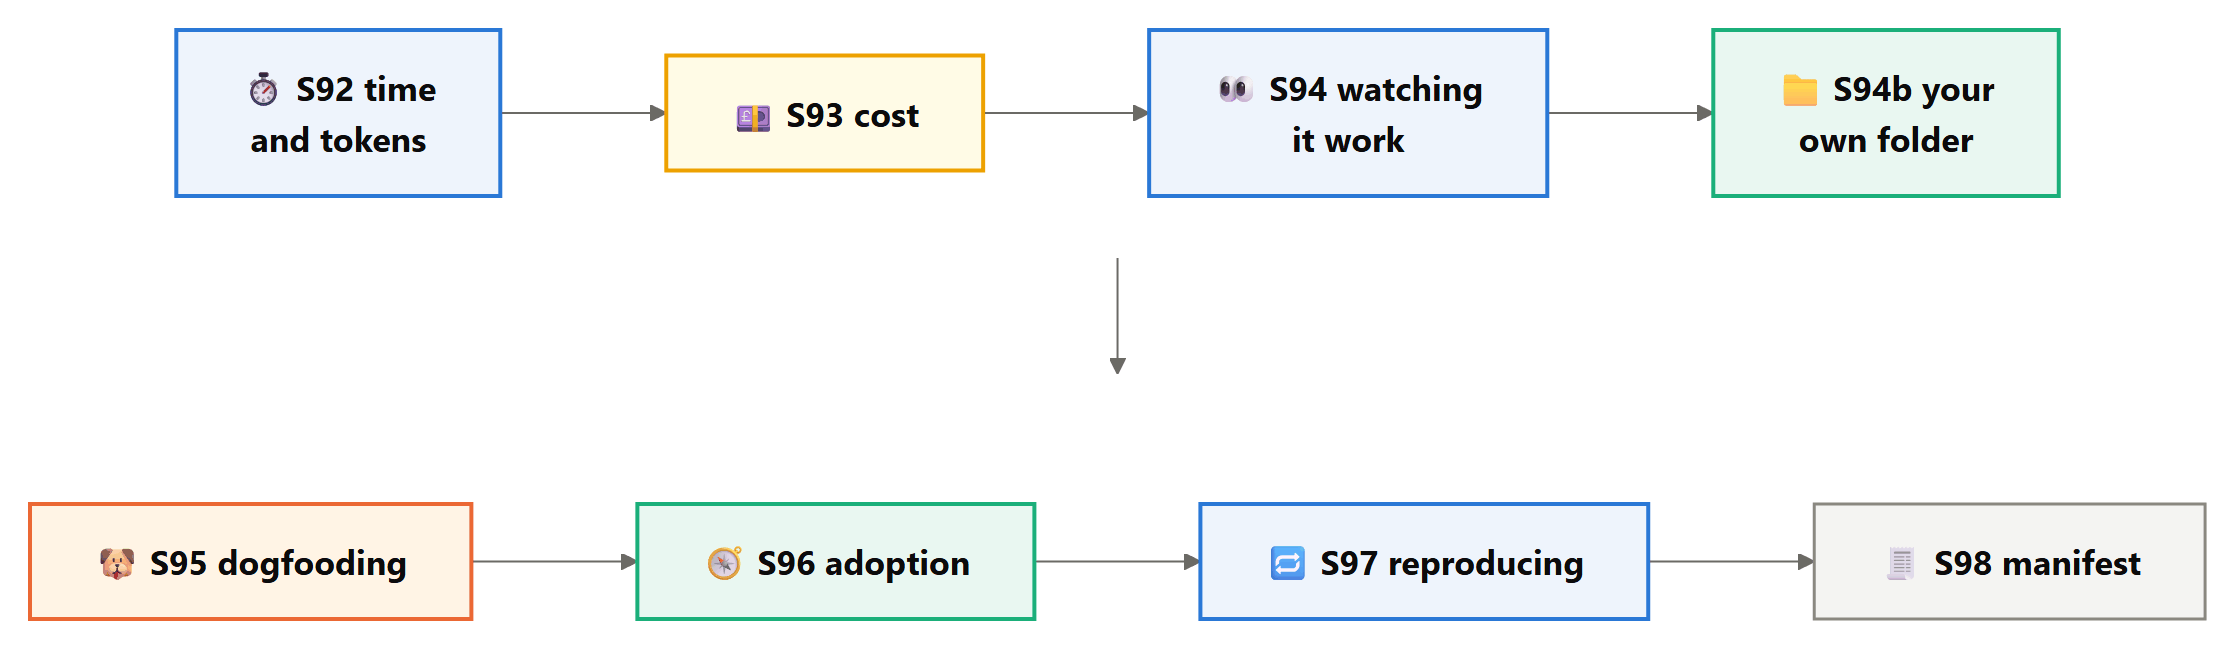

## S92 - Where the time and the tokens go

**Theory.** An agent's cost has three parts: the model's time, the tokens sent and received, and the host's own overhead (hooks, gates, the fence). The first two come from the episodes and the ledger. The third is measured by replaying three dev episodes of the full system, whose model calls all come from the ledger, so that the clock sees only the host: every hook call is timed by the event bus (S16) and set against the model time the same episodes recorded. The rules also carry a fixed tax, their tokens in the system message of every call, and that is computed directly.

**In plain terms.** How long the agents took, how many tokens they used, and how much of that is our machinery rather than the model.

In [830]:
COST_ROWS = []                                          # one row per arm, every number a median over its episodes
for arm in ARM_NAMES:
    eps = [r.episode for r in MAIN if r.arm == arm and r.episode]   # the arm's episodes; failed runs have none
    COST_ROWS.append({"arm": arm, "episodes": len(eps),
                      "turns": np.median([len(e.turns) for e in eps]),
                      "model s": np.median([e.model_seconds for e in eps]),          # time spent waiting on the model
                      "tokens in": np.median([sum(t.prompt_tokens for t in e.turns) for e in eps]),
                      "tokens out": np.median([sum(t.completion_tokens for t in e.turns) for e in eps]),
                      "reasoning": np.median([sum(t.reasoning_chars for t in e.turns) for e in eps])})   # thinking, in characters
table(COST_ROWS, [("arm", "arm", ""), ("episodes", "episodes", "d"), ("turns", "turns", ".0f"), ("model s", "model seconds", ".0f"),
                  ("tokens in", "tokens in", ".0f"), ("tokens out", "tokens out", ".0f"), ("reasoning", "reasoning chars", ".0f")])

  arm     episodes  turns  model seconds  tokens in  tokens out  reasoning chars
  ------------------------------------------------------------------------------
  off           68     10             45      11916        2146             3788
  terse         68     10             33       9328        1298             2890
  slogan        68     10             41       9396        1909             4318
  rules         68     12             63      25068        2986             7528
  full          68     12             85      29802        3994            10266


**Every model the notebook called, from the ledger.** The ledger records each answer with its tokens and its time, so the whole notebook's bill, the judges and the probes included, is one query away.

In [831]:
print("\n  per model, from the ledger:")
per_model = LEDGER.query("SELECT model, COUNT(*), SUM(prompt_tokens), SUM(completion_tokens), AVG(seconds) "
                         "FROM calls GROUP BY model ORDER BY COUNT(*) DESC")      # the busiest model first
model_rows = []
for m, n, pi, po, s in per_model:
    # a model with nothing recorded comes back as None: shown as 0
    model_rows.append({"model": m.split("/")[-1], "calls": n, "in": pi or 0, "out": po or 0, "seconds": s or 0})
table(model_rows, [("model", "model", ""), ("calls", "calls", "d"), ("in", "tokens in", "d"), ("out", "tokens out", "d"),
                   ("seconds", "mean seconds", ".1f")])


  per model, from the ledger:


  model               calls  tokens in  tokens out  mean seconds
  --------------------------------------------------------------
  Qwen3.8-27B          9872   24416877     4129868           8.3
  Qwen3.8-Flash-Next    799    1392324      336065           8.1
  Qwen3.7-Max           653     777866       86865           3.0
  Qwen3.7-Plus          580     892269       86635           3.9
  Qwen3.8-Omni-Flash    345     947313      150041           7.0
  Qwen3.8-Max           297     675391      144306          12.5
  endpoint                1          0           0           0.0


In [832]:
timing = []
for t in DEV[:3]:                                       # three dev tasks, run again by the full system
    h = Host(plugins=full_system(), label="timing")
    ep = run_episode(t, h)                              # model time comes from the replies; hook time is measured here
    hook_ms = sum(x["ms"] for x in h.bus.trace)         # the event bus timed every hook call it made
    timing.append({"task": t.id, "turns": len(ep.turns), "model s": ep.model_seconds, "hook ms": hook_ms,
                   "share": hook_ms / 1000 / max(ep.model_seconds, 1e-9),     # hooks as a share of model time; never divide by 0
                   "hook calls": len(h.bus.trace)})
table(timing, [("task", "task", ""), ("turns", "turns", "d"), ("model s", "model seconds", ".1f"), ("hook calls", "hook calls", "d"),
               ("hook ms", "hook time ms", ".0f"), ("share", "hooks / model", ".1%")])

  task             turns  model seconds  hook calls  hook time ms  hooks / model
  ------------------------------------------------------------------------------
  ct-off-by-one       11           43.2          35           123           0.3%
  eg-leap-feb         11          122.4          38           103           0.1%
  ex-signup-rules     20          345.2          63           174           0.1%


**The rules' fixed tax.** The ruleset at level full sits in the system message of every call, so its token count is paid once per turn, whatever the turn does.

In [833]:
rules_tax = tokens_of(ruleset("full"))                  # tokens the rules add to every system message
full_calls = np.median([len(r.episode.turns) for r in MAIN if r.arm == "full" and r.episode])   # one call per turn
print(f"\n  the rules' fixed tax: {rules_tax} tokens in every system message, about {rules_tax * full_calls:,.0f} tokens "
      f"over a median full-system episode of {full_calls:.0f} calls")
hook_share = float(np.mean([x["share"] for x in timing]))     # the hooks' share of model time, over the three episodes
save_exp("cost", {r["arm"]: {k: r[k] for k in ("turns", "model s", "tokens in", "tokens out", "reasoning")} for r in COST_ROWS}
         | {"hook_share": hook_share, "rules_tax": rules_tax, "hooks": "SMALL" if hook_share < 0.05 else "NOTICEABLE"})


  the rules' fixed tax: 986 tokens in every system message, about 11,832 tokens over a median full-system episode of 12 calls
[exp] artifacts/exp_cost.json


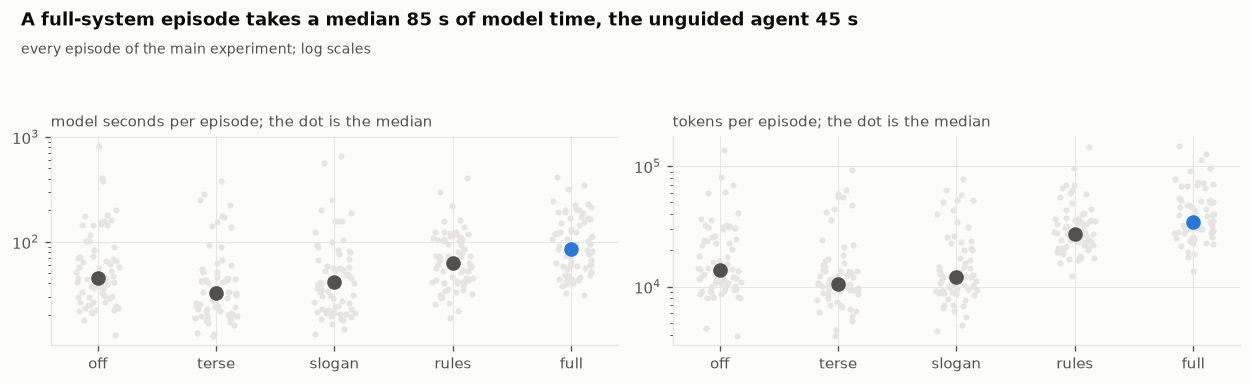

[fig 24] s92_cost.png


In [834]:
# FIG  time and tokens per episode
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.3))
for ax, key, label in ((axes[0], "model_seconds", "model seconds per episode"), (axes[1], "tokens", "tokens per episode")):
    for i, arm in enumerate(ARM_NAMES):
        eps = [r.episode for r in MAIN if r.arm == arm and r.episode]
        vals = []                                           # one value per episode, zeros left out
        for e in eps:
            if key == "model_seconds":
                v = e.model_seconds                         # what a user waits for
            else:
                v = sum(t.prompt_tokens + t.completion_tokens for t in e.turns)   # what a provider charges for
            if v > 0:
                vals.append(v)                              # a log scale has no place for zero
        if not vals:
            continue
        # every episode as a grey dot, spread sideways by a generator seeded per arm, so the picture never changes
        ax.scatter(i + np.random.default_rng(i).uniform(-0.18, 0.18, len(vals)), vals, s=7, color=GRID, zorder=1)
        ax.scatter([i], [np.median(vals)], s=60, color=C1 if arm == "full" else INK2, zorder=2)   # the median, on top
    ax.set_xticks(range(len(ARM_NAMES)), ARM_NAMES)
    ax.set_yscale("log")                                    # episodes differ by orders of magnitude
    panel(ax, label + "; the dot is the median")
COST = {r["arm"]: r for r in COST_ROWS}                     # the cost table by arm, also used in S96
finish(fig, "s92_cost", f"A full-system episode takes a median {COST['full']['model s']:.0f} s of model time, "
       f"the unguided agent {COST['off']['model s']:.0f} s", "every episode of the main experiment; log scales")

**Reading FIG 24 (s92_cost).** Each grey dot is one episode, and the dark dot is the arm's median. The left panel is model time, which is what a user waits for; the right panel is tokens in and out, which is what a provider charges for. The full system's median episode used 85 seconds of model time against 45 for the unguided agent. Every hook it runs together cost 0.1% of the model time in the three replayed episodes, so the machinery itself is not where the time goes. The tokens are the real cost: the rules add 986 tokens to every call's system message, and the gates and the critic add turns and a review call.

## S93 - What the saving costs

**Theory.** The system spends something (tokens, turns, a review call) to write less code. Whether that is a good trade depends on what a line of code costs a team, which this notebook cannot know, so the table states the exchange rate: extra tokens per line not written, from the medians of the main experiment. A provider's price per thousand tokens can be set in S0 (`COST_PER_1K_TOKENS`) to turn tokens into money; it is left unset, because prices change faster than any notebook.

**In plain terms.** How many extra tokens the system spends for each line of code it avoids.

**`med(arm, f)`** is the median of some quantity `f` over an arm's scored episodes in the main experiment. The exchange rate below is built from medians rather than means, so one runaway episode cannot set the price.

In [835]:
def med(arm, f):
    """The median of f(run) over an arm's scored runs that have an episode."""
    values = [f(r) for r in MAIN if r.arm == arm and r.score and r.episode]   # failed runs have nothing to measure
    return float(np.median(values))

show_def(med, layer="lab")

[def] med(arm, f)  4 lines, complexity 4


**`tokens(r)`** is everything one run sent to the model and got back: prompt and completion tokens, summed over its turns. The prompt side dominates, because every turn resends the conversation so far.

In [836]:
def tokens(r):
    """Prompt plus completion tokens over every turn of a run's episode."""
    return sum(t.prompt_tokens + t.completion_tokens for t in r.episode.turns)

show_def(tokens, layer="lab")

[def] tokens(r)  3 lines, complexity 2


In [837]:
print(f"[tokens] median tokens per episode: the unguided agent {med('off', tokens):,.0f}, the full system {med('full', tokens):,.0f}")

[tokens] median tokens per episode: the unguided agent 13,832, the full system 34,571


**The exchange rate.** For each arm, the extra tokens it spends per episode against the unguided agent, the lines of code it saves, and the ratio of the two. A negative number of extra tokens means the arm spent fewer.

In [838]:
rows = []
for arm in ARM_NAMES:
    if arm == "off":
        continue                                            # the baseline every other arm is priced against
    extra = med(arm, tokens) - med("off", tokens)           # extra tokens per episode
    saved = med("off", lambda r: r.score.added_code) - med(arm, lambda r: r.score.added_code)   # lines not written
    rows.append({"arm": arm, "extra tokens": extra, "lines saved": saved,
                 "tokens per line": extra / saved if saved > 0 else None,     # no rate when nothing was saved
                 "price": (extra / 1000 * COST_PER_1K_TOKENS) if COST_PER_1K_TOKENS else None})   # money, if S0 sets a price
table(rows, [("arm", "arm", ""), ("extra tokens", "extra tokens per episode", "+.0f"), ("lines saved", "lines saved per episode", "+.1f"),
             ("tokens per line", "tokens per line saved", ".0f"), ("price", "extra cost per episode", ".4f")])
print("\n  " + ("prices from COST_PER_1K_TOKENS" if COST_PER_1K_TOKENS else
                "set COST_PER_1K_TOKENS in S0 to see money instead of tokens; a negative 'extra' means the arm used fewer tokens"))
save_exp("tradeoff", {r["arm"]: {"extra_tokens": r["extra tokens"], "lines_saved": r["lines saved"],
                                "tokens_per_line": r["tokens per line"]} for r in rows})

  arm     extra tokens per episode  lines saved per episode  tokens per line saved  extra cost per episode
  --------------------------------------------------------------------------------------------------------
  terse                      -3270                     +1.0                  -3270                       -
  slogan                     -1820                     +1.0                  -1820                       -
  rules                     +13643                     +1.0                  13643                       -
  full                      +20740                     +3.0                   6913                       -

  set COST_PER_1K_TOKENS in S0 to see money instead of tokens; a negative 'extra' means the arm used fewer tokens
[exp] artifacts/exp_tradeoff.json


For the full system, the median episode used +20,740 tokens compared with the unguided agent, and the median change was +3.0 lines smaller (a negative number would mean larger). Medians of differences and differences of medians are not the same thing, so read this as an order of magnitude, not an invoice. The comparison that matters for a team is between those tokens and the minutes a reviewer spends on each needless line, now and every time the code is read again.

**For teams.** Measure the trade on your own work before deciding. The cheapest experiment is the one in S64 at a smaller scale: a dozen of your own tickets, worked with and without the system, sizes and pass rates compared ticket by ticket.

## S94 - Watching it work

**Theory.** Two tools for looking inside. The **episode browser** shows any recorded episode of the main experiment: every turn, what the agent did, whether a gate refused it, the score and the final diff. The **console** is the host itself, driven by hand: commands answer straight away without a model (`/lean status`, a level switch, the help card, the debt ledger), and a ticket typed into it runs the agent live. In a replayed notebook only the commands work, because a new ticket would need a call the ledger does not hold; the console says so instead of failing.

**In plain terms.** Pick any recorded run and watch it step by step, or talk to the system yourself.

In [839]:
# the full system's first run of ob-postcode-cache, printed turn by turn
r0 = next(r for r in MAIN if r.arm == "full" and r.task == "ob-postcode-cache" and r.replica == 0)
print("[browser] the static view of one episode (the widget below can show any of them):")
if r0.episode:
    show_episode(r0.episode)
print(f"  score: {r0.score.short() if r0.score else r0.error}")

[browser] the static view of one episode (the widget below can show any of them):
[episode] ob-postcode-cache  arm full  model Qwen3.8-27B  replica 0
   1  ls    .                                ok  notes    0c  reasoning    75c  tokens   1432+25      2.1s  ledger
   2  read  geo.py                           ok  notes    0c  reasoning    39c  tokens   1497+38      2.1s  ledger
   3  read  tests_visible.py                 ok  notes    0c  reasoning    90c  tokens   1683+32      2.0s  ledger
   4  read  register.py                      ok  notes    0c  reasoning    56c  tokens   1795+23      1.5s  ledger
   5  read  addresses.py                     ok  notes    0c  reasoning  5698c  tokens   2056+1411   26.2s  ledger
   6  edit  geo.py                           ok  notes  348c  reasoning  9530c  tokens   2164+2747   47.7s  ledger
   7  run   tests_visible.py                 ok  notes    0c  reasoning   324c  tokens   2656+84      4.2s  ledger
   8  run   python -c "
import register, g   

**The episode browser.** In a live session, three menus pick a task, an arm and a run, and the panel shows that episode with its score and its final diff. A headless run prints its fallback line instead.

In [840]:
W = widgets()                                           # None in a headless run
if W:
    task_box = W.Dropdown(options=sorted(SUITE), value="ob-postcode-cache", description="task")
    arm_box = W.Dropdown(options=list(ARM_NAMES), value="full", description="arm")
    rep_box = W.Dropdown(options=list(range(REPLICAS)), value=0, description="run")
    out = W.Output(layout={"border": "1px solid #e6e5e1", "max_height": "420px", "overflow": "auto"})   # scrolls when long

    def _browse(change=None):
        out.clear_output()
        with out:
            # the run matching all three menus, if the main experiment recorded one
            r = next((r for r in MAIN if (r.task, r.arm, r.replica) == (task_box.value, arm_box.value, rep_box.value)), None)
            if r is None or r.episode is None:
                print("no episode recorded for this choice" + (f" ({r.error})" if r else ""))
                return
            show_episode(r.episode)
            print(f"score: {r.score.short() if r.score else r.error}\n")
            print(change_diff(SUITE[r.task].seed, snapshot(r.episode.ws)) or "(no change)")

    for box in (task_box, arm_box, rep_box):
        box.observe(_browse, names="value")             # any menu change shows the new episode
    _browse()                                           # the default episode, before anything is clicked
    display(W.VBox([W.HBox([task_box, arm_box, rep_box]), out]))
else:
    print("(no widget in this run, which needs a live Jupyter session; the episode above is the static view)")

(no widget in this run, which needs a live Jupyter session; the episode above is the static view)


**The console** is the shipped host, started on a copy of `ob-postcode-cache` and driven by hand. Commands are answered by the host itself, so none of them reaches a model: the sequence below switches levels, tries an option that does not exist, turns the system off and on again, and asks for the help card.

In [841]:
CONSOLE = Host(plugins=shipped_system(), label="console")                      # the system as S71 ships it
CONSOLE.start_session(materialise(SUITE["ob-postcode-cache"], WS_DIR / "console"))
print("[console] commands answer without a model:")
for line in (f"/{CMD} status", f"/{CMD} ultra", f"/{CMD} status", f"/{CMD} lite now", f"/{CMD} off", f"/{CMD}", f"/{CMD}-help"):
    print(f"  > {line}")
    print(textwrap.indent(str(CONSOLE.handle_prompt(line)), "    "))           # what the host answered
print(f"  statusline: {CONSOLE.status()}")

[console] commands answer without a model:
  > /lean status
    lean-agent: on, level full
  > /lean ultra
    lean-agent on (ultra)
  > /lean status
    lean-agent: on, level ultra
  > /lean lite now
    unknown option 'lite now'; nothing changed (lean-agent is on, ultra)
  > /lean off
    lean-agent off
  > /lean
    lean-agent on (ultra)
  > /lean-help
    /clear: start the session again in the same workspace
    /compact: summarise the conversation now
    /help: list commands and skills
    /lean: /lean [on|off|lite|full|ultra|status|default LEVEL]
    /lean-debt: list shortcuts and deferred work
    /lean-gain: what the lab has measured
    /lean-help: this card
    /lean-audit: Use when asked to audit a whole project for over-engineering: unused code, needless layers, dependencies the standard library covers.
    /lean-review: Use when asked to review code or a change for unnecessary complexity, and before finishing a change. Not for correctness, security or style reviews.
  sta

**`console_send(text)`** is the console's single entry point. A line that starts with `/` is a command and is answered at once. Anything else is a ticket: it joins the conversation and the agent works it, which needs live calls, so in a replayed notebook the console says that plainly instead of failing on a request the ledger has never seen.

In [842]:
def console_send(text):
    """A command answers at once; a ticket runs the agent, unless this notebook is a replay."""
    if text.startswith("/"):
        return str(CONSOLE.handle_prompt(text))                     # a command never reaches a model
    if LEAN_MODE == "replay":
        # a new ticket would need answers the ledger does not hold
        return "live calls are off in a replayed notebook; run it in collect mode to talk to the agent"
    CONSOLE.handle_prompt(text)                                     # the ticket joins the conversation
    res = CONSOLE.loop(CONSOLE.ctx, CONSOLE.ws, CONSOLE.model, tag="console")
    CONSOLE.last_turns = res.turns                                  # the statusline reads its turn count from here
    return f"{res.stop} after {len(res.turns)} turns: {plain(res.done_text)}"

show_def(console_send, layer="lab")

[def] console_send(text)  10 lines, complexity 3


In [843]:
print(f"[console_send] /{CMD} status: {console_send(f'/{CMD} status')}")    # a command: answered by the host alone

[console_send] /lean status: lean-agent: on, level ultra


**The console as a widget.** A text box that sends each line through `console_send` and prints the answer with the statusline; without a live session, call `console_send` directly.

In [844]:
W = widgets()                                                       # None in a headless run
if W:
    box = W.Text(placeholder=f"/{CMD} status, or a ticket", continuous_update=False, layout={"width": "70%"})
    out = W.Output(layout={"border": "1px solid #e6e5e1", "max_height": "300px", "overflow": "auto"})

    def _send(change):
        text = change["new"].strip()
        if not text:
            return                                                  # clearing the box below fires this again, with ""
        with out:
            print(f"> {text}\n{console_send(text)}\n[{CONSOLE.status()}]")
        box.value = ""                                              # ready for the next line

    box.observe(_send, names="value")                               # runs on Enter, since continuous_update is off
    display(W.VBox([box, out]))
else:
    print("(no widget in this run, which needs a live Jupyter session; call console_send('...') directly)")

(no widget in this run, which needs a live Jupyter session; call console_send('...') directly)


## S94b - Use it on your own code

**Theory.** Everything in this notebook was built to be pointed at real code eventually, and `run_on_folder(path, ticket)` is that last step. It treats your folder as read-only. The folder is copied into a fresh workspace, leaving out version control, virtual environments, dependency folders and caches, binary files, anything that is not UTF-8 text and anything over a size limit, and every skip is reported with its reason. The shipped system from S71 works the ticket on the copy, inside the fence, which cannot write outside the copy. The result is a **patch** in the standard unified format, which `git apply` understands, and a short **report** listing:
- the step of the ladder the agent stopped at;
- what it left out, and when to build it;
- the shortcuts it marked;
- what the critic said;
- what the gates refused;
- how much code it added.

Four checks run on every call:
1. The folder's fingerprint (a hash of every file) is the same before and after.
2. The patch applied to a fresh copy reproduces the agent's result line for line.
3. A program in the workspace cannot write into your folder.
4. An unreadable file is reported, never crashed on.

**In plain terms.** Give it a folder and a ticket. It works on a copy, never touches your files, and hands back a patch and a short report for you to review.

**Your folder is only ever read.** Everything happens on a copy inside the fence, and what comes back is a patch you apply yourself. The four checks run on every call, not only in this demo.

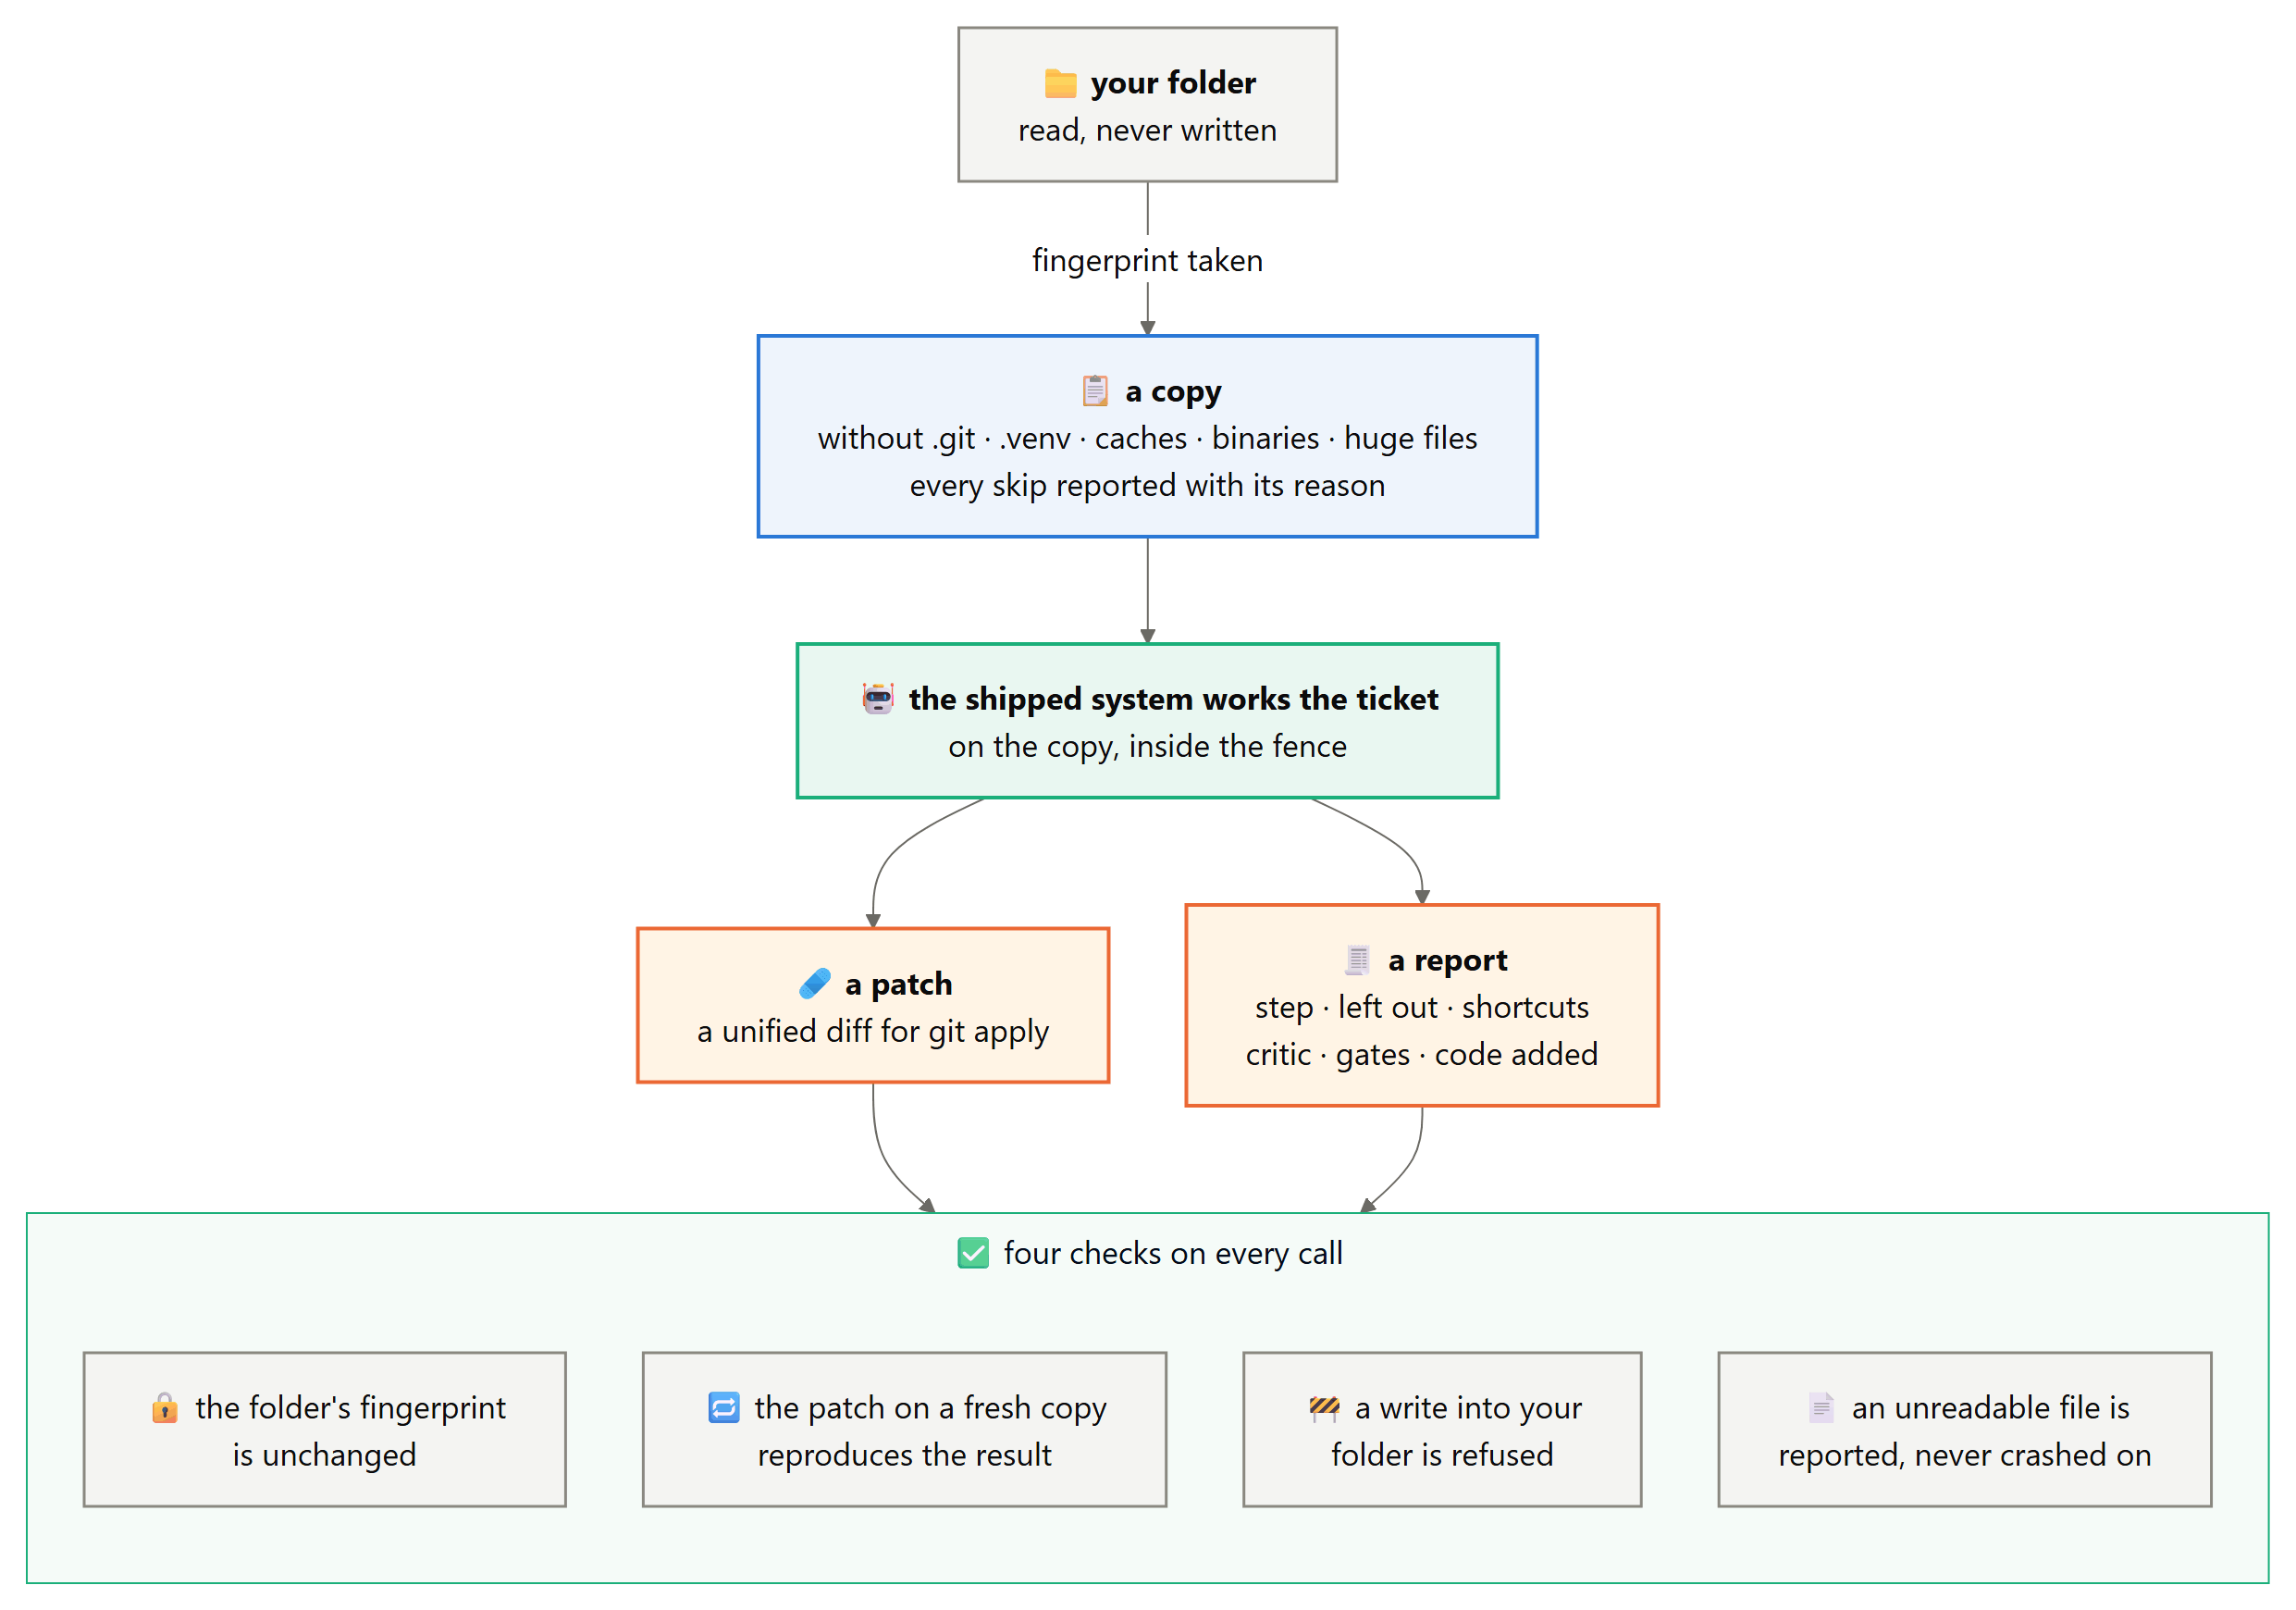

**`SKIP_DIRS` and `MAX_FILE_BYTES`** name what is never copied out of your folder: version control, virtual environments, dependency folders, caches and editor settings by name, and any file over 200 kB by size. None of them is source the agent should edit, and some (a `.venv`, a `node_modules`) would bury the project under thousands of files.

In [845]:
# version control, environments, dependencies, caches and editor settings
SKIP_DIRS = {".git", ".hg", ".svn", ".venv", "venv", "env", "node_modules", "__pycache__", ".mypy_cache", ".pytest_cache",
             ".ruff_cache", ".tox", ".idea", ".vscode"}
MAX_FILE_BYTES = 200_000                                     # larger than any source file worth giving an agent
print(f"[copy] folders never copied: {', '.join(sorted(SKIP_DIRS))}")
print(f"[copy] files over {MAX_FILE_BYTES // 1000} kB are left behind")

[copy] folders never copied: .git, .hg, .idea, .mypy_cache, .pytest_cache, .ruff_cache, .svn, .tox, .venv, .vscode, __pycache__, env, node_modules, venv
[copy] files over 200 kB are left behind


**`copy_project(src, dest)`** builds the agent's workspace from your folder. It walks the folder once, prunes the tool and environment folders before descending into them, and copies only files that are ordinary UTF-8 text: a link is never followed, a large file never read, a file with a zero byte near the start is treated as binary, and one that does not decode as UTF-8 is left behind rather than garbled. Every skip is returned with its reason, so the report can say exactly what the agent did not see.

In [846]:
def copy_project(src, dest):
    """Copy a project's text files into an empty workspace, leaving out tool and environment
    folders, links, binaries, non-UTF-8 files and anything over MAX_FILE_BYTES. Returns the
    skipped paths with the reason for each."""
    src = Path(src)                                          # both may arrive as strings
    dest = Path(dest)
    skipped = []                                             # (path, reason) for everything left behind
    shutil.rmtree(dest, ignore_errors=True)                  # the workspace starts empty every time
    dest.mkdir(parents=True)
    for root, dirs, files in os.walk(src):                    # top down, one folder at a time
        here = Path(root)                                    # the folder being walked
        for d in dirs:
            if d in SKIP_DIRS:                               # reported with a trailing slash: a whole folder
                skipped.append(((here / d).relative_to(src).as_posix() + "/", "tool or environment folder"))
        dirs[:] = sorted(d for d in dirs if d not in SKIP_DIRS)    # pruned in place, so os.walk never goes inside
        for name in sorted(files):                           # sorted, so every run copies in the same order
            p = here / name
            rel = p.relative_to(src).as_posix()              # the path as the patch will name it
            # a link is never followed and a large file never read; both are skipped below
            data = b"" if p.is_symlink() or p.stat().st_size > MAX_FILE_BYTES else p.read_bytes()
            if p.is_symlink():
                why = "a link"                               # it could point anywhere, inside the folder or out
            elif p.stat().st_size > MAX_FILE_BYTES:
                why = f"over {MAX_FILE_BYTES // 1000} kB"
            elif b"\0" in data[:4096]:
                why = "binary"                               # text files do not contain zero bytes
            else:
                why = None
            if why is None:
                try:
                    text = data.decode("utf-8")              # the only bytes that get copied
                except UnicodeDecodeError:
                    why = "not UTF-8 text"                   # a legacy encoding the agent's tools would garble
            if why:
                skipped.append((rel, why))                   # reported, never copied
                continue
            (dest / rel).parent.mkdir(parents=True, exist_ok=True)   # the same folders as in the original
            (dest / rel).write_text(text, encoding="utf-8", newline="")    # newline="": line endings kept as they were
    return skipped

show_def(copy_project, layer="lab")

[def] copy_project(src, dest)  38 lines, complexity 14


**`folder_fingerprint(path)`** is one hash over every file in a folder, its relative path and its bytes. Taken before a run and again after, it proves the folder was not touched: a single changed byte, an added file or a renamed one gives a different hash. Unlike the copy, it covers everything, `.git` included, because the promise is about the whole folder.

In [847]:
def folder_fingerprint(path):
    """A hash of every file's path and bytes: the same before and after, or the folder was touched."""
    h = hashlib.sha256()
    for p in sorted(Path(path).rglob("*")):                  # sorted, so the hash does not depend on listing order
        if p.is_file():
            # the path, then the bytes, each closed by a zero byte so two files can never run together
            h.update(p.relative_to(path).as_posix().encode() + b"\0" + p.read_bytes() + b"\0")
    return h.hexdigest()

show_def(folder_fingerprint, layer="lab")

[def] folder_fingerprint(path)  7 lines, complexity 3


Both at work on a two-file scratch project: the copy leaves `.git` behind, copying leaves the original's fingerprint alone, and a one-character edit changes it.

In [848]:
copy_demo = RUNTIME / "demo" / "copy_project"                # a scratch project, rebuilt on every run
shutil.rmtree(copy_demo, ignore_errors=True)
(copy_demo / ".git").mkdir(parents=True)
(copy_demo / ".git" / "HEAD").write_text("ref: refs/heads/main\n", encoding="utf-8")
(copy_demo / "app.py").write_text("print('hello')\n", encoding="utf-8")
fp_before = folder_fingerprint(copy_demo)                    # before anything is copied
print(f"[copy] skipped: {copy_project(copy_demo, RUNTIME / 'demo' / 'copy_project_ws')}")
print(f"[copy] in the workspace: {sorted(snapshot(RUNTIME / 'demo' / 'copy_project_ws'))}")
print(f"[fingerprint] the original is unchanged by copying: {folder_fingerprint(copy_demo) == fp_before}")
(copy_demo / "app.py").write_text("print('hello!')\n", encoding="utf-8")   # one character added
print(f"[fingerprint] unchanged after a one-character edit: {folder_fingerprint(copy_demo) == fp_before}")

[copy] skipped: [('.git/', 'tool or environment folder')]

[copy] in the workspace: ['app.py']
[fingerprint] the original is unchanged by copying: True
[fingerprint] unchanged after a one-character edit: False


**`make_patch(before, after)`** turns two versions of a project, each a `{path: text}` dict, into one unified diff that `git apply` accepts. A created file is diffed from `/dev/null` and a deleted one to it, which is git's own spelling, and unchanged files stay out. An empty file has no lines to diff, so its creation or deletion is written the way git writes it, a `diff --git` header with the file's mode and no hunk, placed after every ordinary section because git reads everything below such a header as part of it. The patch ends with a newline, as patch files do; no change at all gives an empty string.

In [849]:
def make_patch(before, after):
    """A unified diff, in the format git apply reads, of every text file that was created, changed or deleted."""
    out = []
    empty = []                                               # empty files created or deleted: they go last
    for path in sorted(set(before) | set(after)):            # every path on either side, in a stable order
        a, b = before.get(path), after.get(path)             # None on one side: the file was created or deleted
        if a == b:
            continue                                         # an unchanged file stays out of the patch
        if not a and not b:                                  # an empty file created or deleted: no lines to diff
            # git's own spelling for that: a header naming the file and its mode, and no hunk; it goes at
            # the end, because git reads every line after such a header as part of it, up to the next one
            empty += [f"diff --git a/{path} b/{path}", "new file mode 100644" if a is None else "deleted file mode 100644"]
            continue
        old_name = "/dev/null" if a is None else f"a/{path}" # git's names for "no file here" and for each side
        new_name = "/dev/null" if b is None else f"b/{path}"
        # three lines of context, the default, which is what git apply matches against
        out += difflib.unified_diff((a or "").splitlines(), (b or "").splitlines(), old_name, new_name, lineterm="")
    out += empty                                             # after every ordinary section
    if not out:
        return ""                                            # no change, no patch
    return "\n".join(out) + "\n"

show_def(make_patch, layer="lab")

[def] make_patch(before, after)  18 lines, complexity 11


In [850]:
patch_demo = make_patch({"a.py": "x = 1\ny = 2\n"},                          # one changed line...
                        {"a.py": "x = 1\ny = 3\n", "b.py": "print('new')\n"})   # ...and one new file
print(patch_demo)

--- a/a.py
+++ b/a.py
@@ -1,2 +1,2 @@
 x = 1
-y = 2
+y = 3
--- /dev/null
+++ b/b.py
@@ -0,0 +1 @@
+print('new')



**`HUNK`** reads the header of one hunk, `@@ -start,count +start,count @@`: where the hunk starts in the old file and how many old lines it covers, then the same for the new file. A count of 1 is often left out, and a pure insertion has an old count of 0.

In [851]:
HUNK = re.compile(r"@@ -(\d+)(?:,(\d+))? \+(\d+)(?:,(\d+))? @@")    # old start, old count, new start, new count
for header in ("@@ -1,2 +1,2 @@", "@@ -0,0 +1 @@"):
    print(f"[hunk] {header!r} reads as {HUNK.match(header).groups()}")

[hunk] '@@ -1,2 +1,2 @@' reads as ('1', '2', '1', '2')
[hunk] '@@ -0,0 +1 @@' reads as ('0', '0', '1', None)


**`empty_file_header(lines, i)`** recognises the one kind of section that has no hunk: an empty file that was created or deleted, written as git's `diff --git` header and a mode line. It returns the path and which way the change went, or `None` for anything else, so `apply_patch` below can deal with it before reading ordinary sections.

In [852]:
def empty_file_header(lines, i):
    """(path, created) if patch line i opens git's header for an empty file that was created or
    deleted, a header with a mode line and no hunk; None for anything else."""
    if not (lines[i].startswith("diff --git ") and i + 1 < len(lines)):
        return None                                          # not a git header at all
    if lines[i + 1] not in ("new file mode 100644", "deleted file mode 100644"):
        return None                                          # a header for some other kind of change
    if i + 2 < len(lines) and lines[i + 2].startswith("--- "):
        return None                                          # a file with lines: the usual section follows
    return lines[i].split(" b/", 1)[1], lines[i + 1].startswith("new")

show_def(empty_file_header, layer="lab")

[def] empty_file_header(lines, i)  10 lines, complexity 6


In [853]:
header_demo = ["diff --git a/pkg/__init__.py b/pkg/__init__.py", "new file mode 100644"]
print(f"[empty_file_header] {empty_file_header(header_demo, 0)}")          # the path, and created
print(f"[empty_file_header] {empty_file_header(['--- a/x.py', '+++ b/x.py'], 0)}")   # an ordinary section

[empty_file_header] ('pkg/__init__.py', True)
[empty_file_header] None


**`apply_patch(files, patch)`** is the other half: it applies a unified diff to a `{path: text}` dict and returns the new dict, leaving the input alone. It walks the patch one file section at a time and each hunk line by line, copying untouched lines across, checking every context and removed line against the old file, and adding the new lines. A file whose new side is `/dev/null` is removed, not left behind empty. The one idea that matters is strictness: a line that does not match exactly raises `ValueError` instead of being applied approximately, because a patch that only nearly applies is not the patch that was reviewed.

In [854]:
def apply_patch(files, patch):
    """Apply a unified diff to {path: text}. A hunk that does not match exactly raises
    ValueError: a patch that applies only approximately is not the patch that was reviewed."""
    out = dict(files)                                        # a copy: the caller's dict is never changed
    lines = patch.splitlines()
    i = 0                                                    # the patch line being read
    while i < len(lines):
        header = empty_file_header(lines, i)                 # an empty file created or deleted
        if header:
            path, created = header
            if created:
                out[path] = ""                               # it exists, with nothing in it
            else:
                out.pop(path, None)                          # it is gone
            i += 2                                           # past the header and its mode line
            continue
        # a file section opens with a "--- " line directly followed by a "+++ " line
        if not (lines[i].startswith("--- ") and i + 1 < len(lines) and lines[i + 1].startswith("+++ ")):
            i += 1
            continue
        deleted = lines[i + 1][4:] == "/dev/null"            # the new side is "no file here"
        # the new name, unless the file was deleted and only the old name is left
        target = lines[i][4:] if deleted else lines[i + 1][4:]
        path = target.split("/", 1)[1]                       # without its a/ or b/ prefix
        old = (out.get(path) or "").splitlines()             # a new file starts from nothing
        new = []                                             # the file as rebuilt so far
        pos = 0                                              # the next old line not yet copied or consumed
        i += 2                                               # past the two header lines
        while i < len(lines) and (m := HUNK.match(lines[i])):
            n_old, n_new = int(m.group(2) or 1), int(m.group(4) or 1)    # lines the hunk takes and gives
            start = int(m.group(1)) - 1 if n_old else int(m.group(1))   # 1-based; an insertion names the line before it
            new = new + old[pos:start]                       # the untouched lines before the hunk come across as they are
            pos = start
            i += 1
            while n_old or n_new:
                tag, text = lines[i][:1], lines[i][1:]       # " " context, "-" removed, "+" added
                if tag in (" ", "-"):
                    if pos >= len(old) or old[pos] != text:
                        raise ValueError(f"{path}: the patch does not match line {pos + 1}")   # exact, or not at all
                    pos, n_old = pos + 1, n_old - 1
                if tag in (" ", "+"):
                    new.append(text)
                    n_new -= 1
                i += 1
        new += old[pos:]                                     # whatever follows the last hunk
        if deleted:
            out.pop(path, None)                              # a deleted file leaves the project
        else:
            out[path] = "\n".join(new) + "\n" if new else "" # files end with a newline; an emptied file is ""
    return out

show_def(apply_patch, layer="lab")

[def] apply_patch(files, patch)  48 lines, complexity 22


**Both halves, tested together.** A patch must rebuild exactly the files it was made from, must be refused once the file underneath it has changed, and an unchanged project must give an empty patch.

In [855]:
results = []                                                 # expect() records each test here
before = {"a.py": "x = 1\ny = 2\nz = 3\n", "keep.txt": "same\n"}
after = {"a.py": "x = 1\ny = 20\nz = 3\nw = 4\n", "keep.txt": "same\n", "new/b.py": "print('hi')\n"}   # a change, an addition, a new file
p = make_patch(before, after)
expect("a patch reproduces the files it was made from", apply_patch(before, p) == after)
try:
    apply_patch({**before, "a.py": "x = 1\ny = 3\nz = 3\n"}, p)    # the line the patch removes has changed since
    refused = False
except ValueError:
    refused = True
expect("a patch that no longer matches is refused", refused)
expect("an empty change is an empty patch", make_patch(before, before) == "")
with_package = {**after, "new/__init__.py": ""}                          # an empty file, as packages have
expect("an empty new file survives the round trip", apply_patch(before, make_patch(before, with_package)) == with_package)
without_keep = {p: s for p, s in after.items() if p != "keep.txt"}      # a file the change deleted
expect("a deleted file is gone after the patch, not left empty", apply_patch(after, make_patch(after, without_keep)) == without_keep)

  PASSED  a patch reproduces the files it was made from
  PASSED  a patch that no longer matches is refused
  PASSED  an empty change is an empty patch
  PASSED  an empty new file survives the round trip
  PASSED  a deleted file is gone after the patch, not left empty


**`same_lines(a, b)`** compares two `{path: text}` dicts line by line. The patches made here do not record whether a file ended with a newline, so a file rebuilt from one always ends with one; comparing lines rather than raw text keeps that one missing character from counting as a difference.

In [856]:
def same_lines(a, b):
    """Two sets of files with the same lines; a missing newline at the very end is not a difference."""
    return {p: s.splitlines() for p, s in a.items()} == {p: s.splitlines() for p, s in b.items()}

show_def(same_lines, layer="lab")

[def] same_lines(a, b)  3 lines, complexity 3


In [857]:
with_newline, without_newline = {"a.py": "x = 1\n"}, {"a.py": "x = 1"}
print(f"[same_lines] only the final newline differs: {same_lines(with_newline, without_newline)}")
print(f"[same_lines] a line differs:                 {same_lines(with_newline, {'a.py': 'x = 2'})}")

[same_lines] only the final newline differs: True
[same_lines] a line differs:                 False


**`run_on_folder(path, ticket)`** is the whole workflow in one call. It fingerprints your folder, copies it into a workspace named after the folder and the ticket, starts a fresh host with the shipped system, works the ticket, and turns the result into a patch. The report then gathers what a reviewer needs (how the run stopped, what was skipped and changed, the code added, the step claimed, the `left out:` lines, the shortcut markers, the critic's findings and the gates' refusals) and the two guarantees that can be checked afterwards: the folder's fingerprint is unchanged, and the patch applied to the workspace as it started rebuilds the agent's result. The patch is also saved under `.runtime/folder_runs/`.

In [858]:
def run_on_folder(path, ticket, plugins=None, replica=0):
    """Work a ticket on a copy of a folder, never the folder itself; return the patch, the report and the episode."""
    src = Path(path).resolve()
    fingerprint = folder_fingerprint(src)                    # taken first, to prove at the end that nothing changed
    # one workspace per folder and ticket: the same ticket always lands in the same place
    name = f"{src.name}-{hashlib.sha256(ticket.encode()).hexdigest()[:8]}"
    ws = RUNTIME / "folder_runs" / name                      # inside the notebook's own runtime folder
    skipped = copy_project(src, ws)                          # the agent only ever sees this copy
    seed = snapshot(ws)                                      # the copy as it started
    host = Host(plugins=(plugins or shipped_system)(), label="folder")
    host.replica = replica                                   # part of every request's key in the ledger
    host.start_session(ws)                                   # a new conversation, rooted in the copy
    host.handle_prompt(ticket)                               # the ticket joins the conversation
    res = host.loop(host.ctx, ws, host.model, tag=f"folder:{src.name}")   # the agent works until it stops
    host.last_turns = res.turns                              # for the statusline in the report
    final = snapshot(ws)                                     # the copy as the agent left it
    patch = make_patch(seed, final)                          # everything the agent changed, as one patch
    changed = sorted(p for p in set(seed) | set(final) if seed.get(p) != final.get(p))   # created, changed or deleted
    report = {"ticket": ticket, "stop": res.stop, "turns": len(res.turns), "skipped": skipped, "changed": changed,
              "added_code": measure_change(seed, final)["added_code"],                  # the meter's count
              "step": claimed_step(res.done_text),                                      # the ladder step the answer names
              "left_out": [ln.strip() for ln in res.done_text.splitlines() if LEFT_OUT.match(ln)],
              "shortcuts": find_markers({p: final[p] for p in changed if p.endswith(".py") and p in final}),
              "critic": host.state.get("critic", {}).get("findings", []),               # what the critic asked for
              "refused": [t.denied for t in res.turns if t.denied],                     # what the gates turned away
              "answer": plain(res.done_text), "status": host.status(),
              "untouched": folder_fingerprint(src) == fingerprint,                      # the folder is as it was
              "patch_reproduces": same_lines(apply_patch(seed, patch), final)}          # the patch is the result
    (RUNTIME / "folder_runs" / f"{name}.patch").write_text(patch, encoding="utf-8")   # kept beside the workspace, for git apply
    return patch, report, res

show_def(run_on_folder, layer="lab")

[def] run_on_folder(path, ticket, plugins=None, replica=0)  29 lines, complexity 7


**First, the guarantees, tested without a model.** A throwaway folder is filled with everything a real project carries and the copy must leave out: a `.git` folder, a virtual environment, `node_modules`, a compiled cache, a binary, a file in a legacy encoding and one too large to be source. Then a program in the workspace tries to write into the original folder through the fence.

In [859]:
results = []                                                 # expect() records each test here
messy = RUNTIME / "messy_project"
shutil.rmtree(messy, ignore_errors=True)                     # rebuilt from nothing on every run
messy_files = {
    "app.py": b"print('ok')\n",                              # ordinary source: copied
    "_private.py": b"SECRET_SAUCE = 1\n",                    # a leading underscore is still source: copied
    ".git/HEAD": b"ref: refs/heads/main\n",                  # version control: skipped
    ".venv/pyvenv.cfg": b"home = x\n",                       # a virtual environment: skipped
    "node_modules/pad/index.js": b"module.exports = 1\n",    # dependencies: skipped
    "pkg/__pycache__/m.cpython-312.pyc": b"\x00\x01",        # compiled cache: skipped
    "logo.png": b"\x89PNG\r\n\x1a\n\x00\x00",                # binary: skipped
    "legacy.py": "print('café')\n".encode("latin-1"),        # Latin-1, not UTF-8: skipped
    "huge.sql": b"-- data\n" * 40_000,                       # 320 kB, over the limit: skipped
}
for name_, data in messy_files.items():
    (messy / name_).parent.mkdir(parents=True, exist_ok=True)
    (messy / name_).write_bytes(data)
print(f"[messy] {len(messy_files)} files written under {rel(messy)}/")

[messy] 9 files written under .runtime/messy_project/


**The copy.** Every skip is printed with its reason; the two source files must arrive, and each of the other seven must be left behind with a reason.

In [860]:
before_fp = folder_fingerprint(messy)                        # the original folder, before anything happens to it
skipped = dict(copy_project(messy, RUNTIME / "messy_copy"))
for name_, why in sorted(skipped.items()):
    print(f"  skipped {name_:<34} {why}")
copied = snapshot(RUNTIME / "messy_copy")
expect("source files are copied, a _private.py included", {"app.py", "_private.py"} <= set(copied))
expect("tool folders, binaries, legacy encodings and huge files are left out, each with its reason",
       {".git/", ".venv/", "node_modules/", "pkg/__pycache__/", "logo.png", "legacy.py", "huge.sql"} <= set(skipped))

  skipped .git/                              tool or environment folder
  skipped .venv/                             tool or environment folder
  skipped huge.sql                           over 200 kB
  skipped legacy.py                          not UTF-8 text
  skipped logo.png                           binary
  skipped node_modules/                      tool or environment folder
  skipped pkg/__pycache__/                   tool or environment folder
  PASSED  source files are copied, a _private.py included
  PASSED  tool folders, binaries, legacy encodings and huge files are left out, each with its reason


**The escape attempt.** A program in a workspace tries to overwrite a file in the original folder by its absolute path. The fence must refuse it, and the folder's fingerprint must not move.

In [861]:
# the escape attempt: open the original app.py by its absolute path and write to it
attempt = write_files({"escape.py": f"open({str(messy / 'app.py')!r}, 'w').write('changed')\n"}, RUNTIME / "messy_copy_run")
run = run_fenced(attempt, ["escape.py"], timeout=30)
expect("a program in the workspace cannot write into the original folder", run.returncode != 0 and bool(run.refused))
expect("the original folder is byte for byte what it was", folder_fingerprint(messy) == before_fp)

  PASSED  a program in the workspace cannot write into the original folder
  PASSED  the original folder is byte for byte what it was


**Then a real run.** The sample project is a lending library's loans module with a bug that its two callers share: a book returned on its due date is counted as a day late. Its visible test passes and the bug is real, the classic shape of a ticket. The tempting fix is in `fine()`, where the symptom shows; the right one is in `days_late()`, where it starts, because the overdue report calls that too. The module also carries some planted over-engineering (a fine "strategy" interface with one implementation, and a factory for it), which the ticket does not mention. After the run, a check the agent never saw decides whether the fix is right everywhere, on a fresh copy with the patch applied.

In [862]:
SAMPLE = ROOT / "fixtures" / "sample_project"               # the lending library, shipped with the notebook
TICKET = "Readers are being fined when they return a book on its due date. They should only be charged from the day after. Fix it."
patch, report, res = run_on_folder(SAMPLE, TICKET)          # in a replay every answer comes from the ledger
print(f"[folder] {SAMPLE.name}: {report['stop']} after {report['turns']} turns; {len(report['changed'])} file(s) changed, "
      f"{report['added_code']} code lines added")

[folder] sample_project: done after 18 turns; 1 file(s) changed, 1 code lines added


**The report, then the patch.** The report comes first on purpose: it says what the agent claims to have done and left out before the diff shows what it did.

In [863]:
print(f"  left out of the copy: {report['skipped'] or 'nothing'}")
print(f"  step claimed: {report['step'] or '-'}")
for line in report["left_out"]:                              # each deferral, with the condition to build it
    print(f"  {line}")
print(f"  shortcuts marked: {len(report['shortcuts'])}; critic findings: {len(report['critic'])}; gate refusals: {len(report['refused'])}")
print(f"  your folder untouched: {'yes' if report['untouched'] else 'NO'}; the patch reproduces the result: "
      f"{'yes' if report['patch_reproduces'] else 'NO'}")
print(f"  statusline: {report['status']}\n")
print("  the patch:")
print(textwrap.indent(patch or "(empty)", "    "))

  left out of the copy: nothing
  step claimed: -
  shortcuts marked: 0; critic findings: 0; gate refusals: 1
  your folder untouched: yes; the patch reproduces the result: yes
  statusline: lean-agent: full | Qwen3.8-27B | turn 18/20 | 49.6k tokens | done | hooks ok

  the patch:
    --- a/library/loans.py
    +++ b/library/loans.py
    @@ -31,8 +31,18 @@
 
     def days_late(borrowed, returned):
         """Whole days after the due date on which the book was still out."""
    -    return max(0, (returned - due_date(borrowed)).days + 1)
    +    return max(0, (returned - due_date(borrowed)).days)
 
 
     def fine(borrowed, returned, strategy=None):
         return (strategy or make_strategy()).fine_for(days_late(borrowed, returned))
    +
    +
    +if __name__ == "__main__":
    +    D = datetime.date
    +    assert days_late(D(2026, 3, 1), D(2026, 3, 15)) == 0
    +    assert fine(D(2026, 3, 1), D(2026, 3, 15)) == 0
    +    assert days_late(D(2026, 3, 1), D(2026, 3, 16)) == 1
   

**The verdict that matters.** The patch is applied to a fresh copy of the original project, the check the agent never saw is added beside it, and both the project's own test and that check are run in the fence.

In [864]:
fresh = write_files(apply_patch(snapshot(SAMPLE), patch), RUNTIME / "folder_runs" / "sample-verify")   # original plus patch
shutil.copy(ROOT / "fixtures" / "sample_project_check.py", fresh / "check.py")    # the hidden check, added only now
visible = run_fenced(fresh, ["tests_visible.py"])          # the project's own test
hidden = run_fenced(fresh, ["check.py"])                   # the check that decides whether the fix is right
print(f"\n  on a fresh copy with the patch applied: visible test {'passed' if visible.returncode == 0 else 'FAILED'}, "
      f"the hidden check {'passed' if hidden.returncode == 0 else 'FAILED: ' + hidden.stderr.strip().splitlines()[-1][:90]}")
save_exp("folder", {"stop": report["stop"], "turns": report["turns"], "changed": len(report["changed"]),
                    "added": report["added_code"], "untouched": report["untouched"], "reproduces": report["patch_reproduces"],
                    "visible": visible.returncode == 0, "hidden": hidden.returncode == 0,
                    # fixed where the bug starts: the shared days_late, in the module both callers use
                    "fixed_at_root": "library/loans.py" in report["changed"] and "days_late" in patch})


  on a fresh copy with the patch applied: visible test passed, the hidden check passed
[exp] artifacts/exp_folder.json


The run above is one episode, so it shows the workflow, not a rate. What to look for is whether the fix landed where the bug starts (`days_late`, which both callers use) or where it shows (`fine`), whether the planted strategy classes were left alone (the ticket did not ask about them; at most they earn a `left out:` line), and whether the hidden check passed on a fresh copy, which is the only verdict that matters. This run: the hidden check passed, and the fix changed days_late, the shared function.

**For teams.** Use it the way you would use a colleague's pull request. Run it on a branch's folder, read the report before the patch, apply with `git apply <name>.patch`, and run your own tests. The report's `left out:` lines are the review conversation: each names something deliberately not built and when it should be.

## S95 - Dogfooding: does our system pass its own ladder?

**Theory.** A system that preaches proportional code should survive its own measurements. Three are applied here. **Size**: every definition in the notebook was registered by `show_def` with its layer, so the host, the plugin and the lab can be weighed separately; the system someone would adopt is the host plus the plugin, and the lab is the evidence. **Shapes**: Part I's detectors, the ones that look for interfaces with one implementation, factories with one product and their relatives, are run over the source of every host and plugin definition. **Dependencies**: every module the notebook imports is classified as standard library or not, and the host and plugin are checked for using anything beyond it.

**In plain terms.** We point our own over-engineering detectors at our own code.

In [865]:
rows = []
for layer in ("host", "plugin", "lab"):
    defs = {n: d for n, d in DEFS.items() if d["layer"] == layer}   # every definition show_def registered in this layer
    rows.append({"layer": layer, "definitions": len(defs), "lines": sum(d["lines"] for d in defs.values()),
                 "complexity": np.mean([d["complexity"] for d in defs.values()]) if defs else None,
                 "largest": max(defs, key=lambda n: defs[n]["lines"]) if defs else "-"})     # the biggest single definition
table(rows, [("layer", "layer", ""), ("definitions", "definitions", "d"), ("lines", "lines", "d"),
             ("complexity", "mean complexity", ".1f"), ("largest", "largest definition", "")])

  layer   definitions  lines  mean complexity  largest definition
  ---------------------------------------------------------------
  host             94   1069              3.8  Host.loop
  plugin           64    795              5.7  sibling_note
  lab             157   1893              5.3  apply_patch


**Our own detectors on our own code.** Part I's shape detectors run over the source of every host and plugin definition; each finding is listed with its line, for a reader to judge whether it is a lapse or a false positive.

In [866]:
system_defs = [n for n, d in DEFS.items() if d["layer"] in ("host", "plugin")]   # the system someone would adopt
SOURCES = {}
for n in system_defs:
    try:
        SOURCES[n] = textwrap.dedent(source_of(DEFS[n]["obj"]))     # a method's source comes indented
    except (OSError, TypeError):
        pass                                                        # a definition whose source cannot be found is skipped
SHAPE_HITS = []
for n, src in SOURCES.items():
    for s, line, detail in detect(src):
        SHAPE_HITS.append((n, SHAPES.get(s, s), line, detail))      # the shape's readable name, where it has one
print(f"\n  Part I's shape detectors over {len(system_defs)} host and plugin definitions: {len(SHAPE_HITS)} findings")
for n, shape, line, detail in SHAPE_HITS[:12]:
    print(f"    {n}: {shape} (line {line}) {textwrap.shorten(str(detail), 70)}")


  Part I's shape detectors over 158 host and plugin definitions: 13 findings
    watch_fenced: defensive ceremony (line 5) retries code that cannot fail transiently
    read_fenced_output: defensive ceremony (line 9) retries code that cannot fail transiently
    ModelClient.chat: defensive ceremony (line 13) retries code that cannot fail transiently
    EventBus.emit: hand-rolled stdlib (line 26) a counting loop: collections.Counter
    Config: config for a constant (line 0) Config is never built with a non-default value
    show_episode: speculative parameters (line 1) show_episode(notes) is never read
    run_arms: premature concurrency (line 0) a thread pool for work that does no I/O
    LeanPlugin.on_user_prompt: speculative parameters (line 2) on_user_prompt(ctx) is never read
    LeanPlugin.on_user_prompt: speculative parameters (line 2) on_user_prompt(prompt) is never read
    LeanPlugin.on_subagent_start: speculative parameters (line 2) on_subagent_start(ctx) is never read
   

**Dependencies.** Every module imported anywhere in the notebook, found by parsing every cell this kernel has run.

In [867]:
imported = set()                                                    # top-level module names
for src in get_ipython().user_ns.get("In", []):                     # the source of every cell run so far, this one included
    tree = _safe_parse(src) if isinstance(src, str) else None
    if not tree:
        continue                                                    # a cell that does not parse as Python has nothing to add
    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            imported |= {a.name.split(".")[0] for a in node.names}  # "import a.b" counts as a
        elif isinstance(node, ast.ImportFrom) and node.module and not node.level:   # a relative import is not a module
            imported.add(node.module.split(".")[0])
print(f"[imports] {len(imported)} top-level modules imported across the notebook")

[imports] 46 top-level modules imported across the notebook


**Which of them the system itself uses.** A module outside the standard library counts against the system only if the host or plugin source refers to it; the lab's numerical and plotting libraries do not.

In [868]:
# outside the standard library; "module" is the file the S75 probes import answers from, not a dependency
third = sorted(m for m in imported if m not in sys.stdlib_module_names and m not in ("module",))
system_src = "\n".join(SOURCES.values())                            # all host and plugin source, as one text
# how code refers to the usual third-party modules: by their customary short names, or in full
ALIASES = {"numpy": r"\bnp\.|\bnumpy\.", "matplotlib": r"\bplt\.|\bmatplotlib\.", "ipywidgets": r"\bW\.|\bipywidgets\b"}
system_third = [m for m in third if re.search(ALIASES.get(m, rf"\b{m}\."), system_src)]   # by its usual alias, or its own name
print(f"\n  modules outside the standard library imported anywhere in the notebook: {', '.join(third)}")
print(f"  ... used by the host or the plugin: {', '.join(system_third) or 'none'}")
lines_of = {r["layer"]: r["lines"] for r in rows}                   # lines per layer, from the size table
save_exp("dogfood", {r["layer"]: {"definitions": r["definitions"], "lines": r["lines"]} for r in rows}
         | {"shape_findings": len(SHAPE_HITS), "system_third_party": ", ".join(system_third) or "none",
            "lab_vs_system": "LARGER" if lines_of["lab"] > lines_of["host"] + lines_of["plugin"] else "SMALLER"})


  modules outside the standard library imported anywhere in the notebook: IPython, ipywidgets, matplotlib, numpy
  ... used by the host or the plugin: none
[exp] artifacts/exp_dogfood.json


The host and plugin together are 1069 plus 795 lines over 94 and 64 definitions; the lab, which exists only to produce evidence, is larger, which is the right way round. The shape detectors found 14 instances of the patterns this notebook warns about in the system's own code; each is listed above with its line, so a reader can judge whether it is a lapse or one of the detector's known false positives. Third-party modules used by the system itself: none. The numerical and plotting libraries belong to the lab.

## S96 - Adopting it: what to switch on, in what order

**Theory.** The arms of the main experiment are also the tiers of adoption, so the evidence for each step is already measured. The table repeats it in one place: what each tier costs in tokens and what it changes in code, passes and safety. The steps below are ordered by cost: a sentence-level change first, machinery later, and each step only if the previous one did not do enough.

**In plain terms.** Start small, measure, and add the next piece only when the last one earned it.

In [869]:
# the adoption tiers, cheapest first: each is an arm of the main experiment
tiers = {"off": "no rules", "terse": "one terse sentence", "rules": "the ruleset, pasted", "full": "hooks, gates, critic"}
rows = []
for arm, what in tiers.items():
    r = next(x for x in MAIN_ROWS if x["arm"] == arm)               # the arm's row of S64's table
    rows.append({"tier": what, "arm": arm, "ratio": r["ratio"], "pass": r["pass"], "safe": r["safe"],
                 "tokens": COST[arm]["tokens in"] + COST[arm]["tokens out"]})     # median in plus median out, from S92
table(rows, [("tier", "tier", ""), ("arm", "arm", ""), ("ratio", "code vs none", ".2f"), ("pass", "pass, held-out", ".0%"),
             ("safe", "safe", ".0%"), ("tokens", "median tokens per episode", ".0f")])
print(f"\n  pieces the ablation ledger removed from the shipped system: {SHIPPED['removed'] or 'none'}")

  tier                  arm    code vs none  pass, held-out  safe  median tokens per episode
  ------------------------------------------------------------------------------------------
  no rules              off            1.00             94%  100%                      14062
  one terse sentence    terse          1.00             88%   95%                      10626
  the ruleset, pasted   rules          0.98             94%  100%                      28054
  hooks, gates, critic  full           0.88             96%  100%                      33795

  pieces the ablation ledger removed from the shipped system: ['read first', 'prove it', 'how to answer', 'project map', 'read gate', 'sibling scan', 'dependency gate']


1. **Write the rule down.** Put the ruleset at level full into your agent's project instructions file. This is the `rules` arm: no machinery, just the words, and the table shows what they did on their own.
2. **Deliver it properly.** If your agent tool has lifecycle hooks, deliver the rules at session start, again after compaction and to subagents, and print a one-line header on every prompt (Part V). Rules delivered once can drop out of a long session when it is compacted (S40, S73).
3. **Add the gates that do not depend on the model reading.** Only the pieces the ablation ledger kept (S66); a gate that does not earn its place costs turns for nothing.
4. **Gate changes to the rules.** Any edit to the ruleset ships only if it moves the measured number and costs nothing (S70). Run that gate in CI on a fixed set of your own tickets.
5. **Read the debt ledger.** Deferrals without a trigger are the ones that become permanent (S91).

**For teams.** The order matters less than the habit underneath it: every piece is an experiment, and a piece that does not show its effect on your own tickets should be switched off, however reasonable it sounds.

## S97 - Reproducing this notebook

**Theory.** Every model answer this notebook used is in one SQLite ledger, keyed by the exact request. A replay rebuilds every number without a network connection and without a key, and refuses to run if any request is missing from the ledger, which is how we know the notebook shows the answers it was built from. A second collect run with the same key would produce new answers and different numbers; the intervals of Part VII say how different to expect.

**In plain terms.** Everything can be re-run from the stored answers, offline, and come out identical.

In [870]:
# the commands, then the ledger and the fingerprints a reproduction has to match
print(f"""[reproduce] from the lean_agent folder:

  uv sync --group course                         # the pinned environment
  python _build/run.py replay                    # every number from the ledger, offline, no key needed
  python _build/run.py smoke                     # the scripted stand-in, no ledger and no key
  python _build/run.py collect                   # live calls for anything the ledger lacks (needs the key)

  the ledger: {rel(CACHE_DB)} ({LEDGER.query('SELECT COUNT(*) FROM calls')[0][0]:,} answers)
  fingerprints: suite {SUITE_HASH[:16]}, ruleset {hashlib.sha256(RULESET_SOURCE.encode()).hexdigest()[:16]}, fence {FENCE_HASH}""")

[reproduce] from the lean_agent folder:

  uv sync --group course                         # the pinned environment
  python _build/run.py replay                    # every number from the ledger, offline, no key needed
  python _build/run.py smoke                     # the scripted stand-in, no ledger and no key
  python _build/run.py collect                   # live calls for anything the ledger lacks (needs the key)

  the ledger: artifacts/cache/llm.sqlite (12,547 answers)
  fingerprints: suite 546b6a4cb486c895, ruleset 688b204efa8a2738, fence 90ab1dd4106c


## S98 - The manifest

**Theory.** The last cell writes down what produced every number: the models behind each role and what the probe found they could do, the days the answers were collected, the fingerprints of the suite, the ruleset, the fence and the pre-registration, the number of answers per model, and the versions of Python and of every library the lab used. A result without its manifest is an anecdote.

**In plain terms.** A receipt for the whole notebook.

**`_version(package)`** is the installed version of a package, or `None` when it is not installed. The manifest records the lab's libraries this way, so a missing optional package (`ipywidgets` in a bare environment, say) is left out instead of stopping the last cell of the notebook.

In [871]:
import importlib.metadata as md

def _version(package):
    """The installed version of a package, or None if it is not installed."""
    try:
        return md.version(package)
    except md.PackageNotFoundError:
        return None                                       # not installed: left out of the manifest

show_def(_version, layer="lab")

[def] _version(package)  6 lines, complexity 2


In [872]:
print(f"[version] numpy {_version('numpy')}; a package that is not installed: {_version('no-such-package-here')}")

[version] numpy 2.5.3; a package that is not installed: None


**The manifest.** Everything that produced the numbers above, written to `artifacts/manifest.json` and printed.

In [873]:
days = LEDGER.query("SELECT MIN(day), MAX(day) FROM calls")[0]      # the first and last day an answer was collected
MANIFEST = {
    "system": SYSTEM_NAME, "mode": LEAN_MODE, "collected": {"from": days[0], "to": days[1]},
    # each role's model, with what the S12 probe found it could do
    "models": {role: {"id": m, "can": sorted(CAN.get(m, ()))} for role, m in MODEL_FOR.items()},
    "answers": {m.split("/")[-1]: n for m, n in LEDGER.query("SELECT model, COUNT(*) FROM calls GROUP BY model")},
    "fingerprints": {"suite": SUITE_HASH[:16], "ruleset": hashlib.sha256(RULESET_SOURCE.encode()).hexdigest()[:16],
                     "fence": FENCE_HASH,
                     "preregistration": hashlib.sha256(json.dumps(PREREG, indent=2, sort_keys=True).encode()).hexdigest()[:16]},
    "python": sys.version.split()[0],
    # the lab's libraries; one that is not installed is left out
    "packages": {p: v for p in ("numpy", "matplotlib", "ipywidgets", "nbclient", "nbformat") if (v := _version(p))},
    "shipped": SHIPPED, "replicas": REPLICAS, "max_turns": MAX_TURNS, "temperature": TEMPERATURE,
}
(ART / "manifest.json").write_text(json.dumps(MANIFEST, indent=2, default=str), encoding="utf-8")
for k, v in MANIFEST.items():
    if k not in ("shipped", "models"):                              # those two are long; the models print below
        print(f"  {k:<13} {v}")
for role, m in MANIFEST["models"].items():
    print(f"  {role:<13} {m['id']}  ({', '.join(m['can'])})")
print(f"\n[manifest] {rel(ART / 'manifest.json')}")

  system        lean-agent
  mode          replay
  collected     {'from': '2026-10-05', 'to': '2026-10-06'}
  answers       {'Qwen3.7-Max': 653, 'Qwen3.7-Plus': 580, 'Qwen3.8-27B': 9872, 'Qwen3.8-Flash-Next': 799, 'Qwen3.8-Max': 297, 'Qwen3.8-Omni-Flash': 345, 'endpoint': 1}
  fingerprints  {'suite': '546b6a4cb486c895', 'ruleset': '688b204efa8a2738', 'fence': '90ab1dd4106c', 'preregistration': 'e150f88d7ab7aa8c'}
  python        3.12.14
  packages      {'numpy': '2.5.3', 'matplotlib': '3.11.2', 'ipywidgets': '8.1.9', 'nbclient': '0.11.0', 'nbformat': '5.11.1'}
  replicas      2
  max_turns     20
  temperature   0.6
  coder         Qwen-Ambassador/Qwen3.8-27B  (JSON mode, answers, thinking off, two system messages)
  fast          Qwen-Ambassador/Qwen3.8-Flash-Next  (JSON mode, answers, thinking off, two system messages)
  judge         Qwen-Ambassador/Qwen3.7-Max  (JSON mode, answers, thinking off, two system messages)
  judge2        Qwen-Ambassador/Qwen3.7-Plus  (JSON mode, answers


[manifest] artifacts/manifest.json


**Part X recap.** The cost is known: where the time goes, what the rules add to every call, and how many tokens buy each line not written. Any recorded episode can be browsed and the host driven by hand. The system runs on a folder of your own without touching it, and returns a patch that is checked to reproduce its result, with a report that puts what it did not build on the table. Our own detectors were turned on our own code, and the adoption guide orders the system's pieces by what they cost and what they were measured to do.

**Try it yourself.**
1. Run `run_on_folder` on a small project of your own, with a ticket you already know the right answer to. Read the report before the patch. Did it stop at the step you would have?
2. In S94, use the console to switch to `ultra` and give the same ticket to the sample project. What changes in the patch, and in the `left out:` lines?
3. Add one module of your own code to the host and run S95 again. Do the detectors find anything, and do you agree with them?

## Done

The notebook started with a claim that sounds like a style preference: the best code is often the code that is never written. It ends with a system that acts on that claim, the measurements that test it, the places where the measurements disagree with it, and the means to try it on your own code. What it cannot settle is in S88, and the next useful experiment is probably yours.